# **B1 experiments - Step 0 - 7 (common setups) + Activation-Based D experiments**

**Common B1 infrastructure: Steps 0–7 are intentionally shared across the B1 experimental notebooks to maintain consistent datasets, models, frozen dev100 subset, and SAN cache definitions.**

# Step 0 - Mount Google Drive and select compute device

In [1]:
# ============================================================
# Step 0 — Mount Google Drive and select compute device
# ============================================================

from google.colab import drive
drive.mount("/content/drive")

import torch

device = "cuda" if torch.cuda.is_available() else "cpu"

print("Device:", device)

Mounted at /content/drive
Device: cuda


# Step 1 - Project paths + dataset loader


In [2]:
# ============================================================
# Step 1A — Define project and dataset paths
# ============================================================

from pathlib import Path

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/MSc_Project_ZeroShot_Counting"
)

DATA_ROOT = PROJECT_ROOT / "datasets"

# ------------------------------------------------------------
# FSC-147
# ------------------------------------------------------------

FSC147_ROOT = DATA_ROOT / "FSC147"
FSC147_RAW = FSC147_ROOT / "raw"

FSC147_IMAGE_DIR = FSC147_RAW / "images_384_VarV2"
FSC147_DENSITY_DIR = (
    FSC147_RAW / "gt_density_map_adaptive_384_VarV2"
)

FSC147_ANNOTATION_FILE = (
    FSC147_RAW / "annotation_FSC147_384.json"
)

FSC147_SPLIT_FILE = (
    FSC147_RAW / "Train_Test_Val_FSC_147.json"
)

FSC147_CLASSES_FILE = (
    FSC147_RAW / "ImageClasses_FSC147.txt"
)

# ------------------------------------------------------------
# OmniCount-191
# ------------------------------------------------------------

OMNICOUNT_ROOT = DATA_ROOT / "OmniCount-191"

print("PROJECT_ROOT :", PROJECT_ROOT)
print("DATA_ROOT    :", DATA_ROOT)

print("\nFSC-147 root :", FSC147_ROOT)
print("OmniCount root:", OMNICOUNT_ROOT)

PROJECT_ROOT : /content/drive/MyDrive/MSc_Project_ZeroShot_Counting
DATA_ROOT    : /content/drive/MyDrive/MSc_Project_ZeroShot_Counting/datasets

FSC-147 root : /content/drive/MyDrive/MSc_Project_ZeroShot_Counting/datasets/FSC147
OmniCount root: /content/drive/MyDrive/MSc_Project_ZeroShot_Counting/datasets/OmniCount-191


In [3]:
# ============================================================
# Step 1B — Clone project repository and import shared modules
# ============================================================

%cd /content

!rm -rf Surrey-MScProject-Zero-Shot-Object-Counting

!git clone \
    https://github.com/paulmcchan/Surrey-MScProject-Zero-Shot-Object-Counting.git

/content
Cloning into 'Surrey-MScProject-Zero-Shot-Object-Counting'...
remote: Enumerating objects: 47, done.
remote: Counting objects: 100% (47/47), done.
remote: Compressing objects: 100% (41/41), done.
remote: Total 47 (delta 1), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (47/47), 65.52 KiB | 3.45 MiB/s, done.
Resolving deltas: 100% (1/1), done.


In [4]:
# ============================================================
# Step 1C — Import project dataset / evaluation utilities
# ============================================================

import sys

REPO_ROOT = (
    "/content/Surrey-MScProject-Zero-Shot-Object-Counting"
)

if REPO_ROOT not in sys.path:
    sys.path.append(REPO_ROOT)

from src.datasets import (
    FSC147Dataset,
    OmniCount191Dataset,
    collate_keep_dicts,
)

from src.evaluation import (
    evaluate_single_label_counts,
)

print("Project modules imported successfully.")

Project modules imported successfully.


# Step 2 - Install / Load SAN

In [5]:
# ============================================================
# Step 2A — Clone official SAN repository
# ============================================================

%cd /content

!rm -rf SAN
!git clone https://github.com/MendelXu/SAN.git

%cd /content/SAN

/content
Cloning into 'SAN'...
remote: Enumerating objects: 183, done.
remote: Counting objects: 100% (48/48), done.
remote: Compressing objects: 100% (22/22), done.
remote: Total 183 (delta 36), reused 26 (delta 26), pack-reused 135 (from 1)
Receiving objects: 100% (183/183), 3.17 MiB | 14.23 MiB/s, done.
Resolving deltas: 100% (58/58), done.
/content/SAN


In [6]:
# ============================================================
# Step 2B — Install SAN dependencies
# ============================================================

!pip install -q \
    cython \
    scipy \
    shapely \
    timm \
    h5py \
    submitit \
    scikit-image \
    wandb \
    setuptools \
    fvcore \
    tabulate \
    regex \
    opencv-python \
    "open_clip_torch==2.16.0"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 2.4 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.8/42.8 kB 3.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.2/42.2 kB 2.1 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 19.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 76.0/76.0 kB 7.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.3/25.3 MB 22.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 222.8/222.8 kB 5.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 162.1/162.1 kB 7.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.8/62.8 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.6/129.6 kB 10.3 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not curre

In [7]:
# ============================================================
# Step 2C — Install Detectron2
# ============================================================

%cd /content

!pip uninstall -y detectron2
!rm -rf /content/detectron2

!python -m pip install \
    'git+https://github.com/facebookresearch/detectron2.git'

/content
  Cloning https://github.com/facebookresearch/detectron2.git to /tmp/pip-req-build-kgf3nzao
  Running command git clone --filter=blob:none --quiet https://github.com/facebookresearch/detectron2.git /tmp/pip-req-build-kgf3nzao
  Resolved https://github.com/facebookresearch/detectron2.git to commit a2f4a8771ab77e8411c26b27f24f9489a28a2453
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 95.1/95.1 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 168.8/168.8 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 33.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.3/57.3 kB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.4/268.4 kB 15.0 MB/s eta 0:00:00
  Created wheel for detectron2: filename=detectron2-0.6-cp313-cp313-linux_x86_64.whl size=7049814 sha256=4be9ec5ee97245e2b2f56f8a74a8d79f76d51b057dfe2a5ef66017c55d482ae4
  Stored in directory: /tmp/pip-ephem-wheel-c

In [8]:
# ============================================================
# Step 2D — Configure and load SAN-ViT-B/16
# ============================================================

import sys
from pathlib import Path

SAN_ROOT = Path("/content/SAN")

if str(SAN_ROOT) not in sys.path:
    sys.path.insert(0, str(SAN_ROOT))

CHECKPOINT_DIR = SAN_ROOT / "output"
CHECKPOINT_DIR.mkdir(exist_ok=True)

SAN_CHECKPOINT = (
    CHECKPOINT_DIR / "san_vit_b_16.pth"
)

if not SAN_CHECKPOINT.exists():
    !wget -O {SAN_CHECKPOINT} \
        https://huggingface.co/Mendel192/san/resolve/main/san_vit_b_16.pth

print("SAN checkpoint:", SAN_CHECKPOINT)
print("Exists:", SAN_CHECKPOINT.exists())

--2026-09-21 16:15:56--  https://huggingface.co/Mendel192/san/resolve/main/san_vit_b_16.pth
Resolving huggingface.co (huggingface.co)... 99.86.101.36, 99.86.101.56, 99.86.101.64, ...
Connecting to huggingface.co (huggingface.co)|99.86.101.36|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://us.gcp.cdn.hf.co/xet-bridge-us/63f599a9cc1dd316869b503b/039ab682651d8629737a75626ef620be728538b7b3b97afcf02d80602183f000?X-Xet-Cas-Uid=public&user_id=public&response-content-disposition=inline%3B+filename*%3DUTF-8%27%27san_vit_b_16.pth%3B+filename%3D%22san_vit_b_16.pth%22%3B&Expires=1790010957&Policy=eyJTdGF0ZW1lbnQiOlt7IlJlc291cmNlIjoiaHR0cHM6Ly91cy5nY3AuY2RuLmhmLmNvL3hldC1icmlkZ2UtdXMvNjNmNTk5YTljYzFkZDMxNjg2OWI1MDNiLzAzOWFiNjgyNjUxZDg2Mjk3MzdhNzU2MjZlZjYyMGJlNzI4NTM4YjdiM2I5N2FmY2YwMmQ4MDYwMjE4M2YwMDBcXD9YLVhldC1DYXMtVWlkPXB1YmxpYyZ1c2VyX2lkPXB1YmxpYyZyZXNwb25zZS1jb250ZW50LWRpc3Bvc2l0aW9uPSoiLCJDb25kaXRpb24iOnsiRGF0ZUxlc3NUaGFuIjp7IkVwb2NoVGltZSI6MTc5MDAxMDk1N

In [9]:
# ============================================================
# Step 2E — Build SAN model
# ============================================================

%cd /content/SAN

from detectron2.config import get_cfg
from detectron2.projects.deeplab import add_deeplab_config

from san.config import add_san_config
from train_net import Trainer

SAN_CONFIG = (
    "/content/SAN/configs/"
    "san_clip_vit_res4_coco.yaml"
)

cfg = get_cfg()

add_deeplab_config(cfg)
add_san_config(cfg)

cfg.merge_from_file(SAN_CONFIG)

cfg.MODEL.DEVICE = device
cfg.MODEL.WEIGHTS = str(SAN_CHECKPOINT)

cfg.freeze()

san_model = Trainer.build_model(cfg)

print("SAN model constructed.")
print("Model class:", san_model.__class__.__name__)

/content/SAN


/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
100%|███████████████████████████████████████| 351M/351M [00:03<00:00, 88.3MiB/s]
/content/SAN/san/model/side_adapter/timm_wrapper.py:24: UserWarning: Unused kwargs are provided:{'dynamic_img_pad': False, 'device': None, 'dtype': None}.
  warnings.warn(f"Unused kwargs are provided:{kwargs}.")


SAN model constructed.
Model class: SAN


In [10]:
# ============================================================
# Step 2F — Load SAN pretrained weights
# ============================================================

from detectron2.checkpoint import (
    DetectionCheckpointer,
)

checkpointer = DetectionCheckpointer(
    san_model
)

checkpoint_info = checkpointer.resume_or_load(
    cfg.MODEL.WEIGHTS,
    resume=False,
)

san_model.eval()

print("SAN weights loaded successfully.")
print("Training mode:", san_model.training)
print("Device:", cfg.MODEL.DEVICE)

SAN weights loaded successfully.
Training mode: False
Device: cuda


# Step 3 — Install and load SAM2

In [11]:
# ============================================================
# Step 3A — Install official SAM2 repository
# ============================================================

%cd /content

if not Path("/content/sam2").exists():
    !git clone \
        https://github.com/facebookresearch/sam2.git

%cd /content/sam2

!pip install -q -e .

print("SAM2 repository ready.")

/content
Cloning into 'sam2'...
remote: Enumerating objects: 1107, done.
remote: Counting objects: 100% (18/18), done.
remote: Compressing objects: 100% (11/11), done.
remote: Total 1107 (delta 13), reused 7 (delta 7), pack-reused 1089 (from 2)
Receiving objects: 100% (1107/1107), 134.85 MiB | 20.80 MiB/s, done.
Resolving deltas: 100% (385/385), done.
/content/sam2
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for SAM-2 (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
detectron2 0.6 requires iopath<0.1.10,>=0.1.7, but you have iopath 0.1.10 which is incompatible.
SAM2 repository ready.


In [12]:
# ============================================================
# Step 3B — Prepare SAM2.1 Hiera-small checkpoint
# ============================================================

SAM2_ROOT = Path("/content/sam2")

SAM2_CHECKPOINT_DIR = (
    SAM2_ROOT / "checkpoints"
)

SAM2_CHECKPOINT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

SAM2_CHECKPOINT = (
    SAM2_CHECKPOINT_DIR /
    "sam2.1_hiera_small.pt"
)

if not SAM2_CHECKPOINT.exists():

    !wget -q \
        -O {SAM2_CHECKPOINT} \
        https://dl.fbaipublicfiles.com/segment_anything_2/092824/sam2.1_hiera_small.pt

print("SAM2 checkpoint:", SAM2_CHECKPOINT)
print("Exists:", SAM2_CHECKPOINT.exists())

SAM2 checkpoint: /content/sam2/checkpoints/sam2.1_hiera_small.pt
Exists: True


In [13]:
# ============================================================
# Step 3C — Build SAM2.1 Hiera-small predictor
# ============================================================

import sys

if str(SAM2_ROOT) not in sys.path:
    sys.path.insert(
        0,
        str(SAM2_ROOT),
    )

from sam2.build_sam import build_sam2
from sam2.sam2_image_predictor import (
    SAM2ImagePredictor,
)

SAM2_MODEL_CFG = (
    "configs/sam2.1/"
    "sam2.1_hiera_s.yaml"
)

sam2_model = build_sam2(
    SAM2_MODEL_CFG,
    str(SAM2_CHECKPOINT),
    device=device,
)

sam2_model.eval()

sam2_predictor = (
    SAM2ImagePredictor(
        sam2_model
    )
)

print("SAM2 loaded successfully.")
print(
    "Predictor:",
    sam2_predictor.__class__.__name__,
)

SAM2 loaded successfully.
Predictor: SAM2ImagePredictor


# Step 4 — Define experiment paths and fixed B1 assumptions

In [14]:
# ============================================================
# Step 4A — Define B1 experiment paths and fixed assumptions
# ============================================================

B1_RESULTS_ROOT = (
    PROJECT_ROOT /
    "results" /
    "B1_experiments"
)

B1_RESULTS_ROOT.mkdir(
    parents=True,
    exist_ok=True,
)

B1_CACHE_ROOT = (
    PROJECT_ROOT /
    "cache" /
    "B1_SAN"
)

B1_CACHE_ROOT.mkdir(
    parents=True,
    exist_ok=True,
)

print(
    "B1 results:",
    B1_RESULTS_ROOT
)

print(
    "SAN cache:",
    B1_CACHE_ROOT
)

B1 results: /content/drive/MyDrive/MSc_Project_ZeroShot_Counting/results/B1_experiments
SAN cache: /content/drive/MyDrive/MSc_Project_ZeroShot_Counting/cache/B1_SAN


In [15]:
# ============================================================
# Step 4B — Fixed B1 experimental assumptions
# ============================================================

B1_PRIMARY_DATASET = "fsc147"
B1_SPLIT = "val"

SAN_SHORT_SIDE = 640
SAN_VOCABULARY_MODE = "target+background"

SAM2_PROMPT_MODE = "single_positive"
SAM2_MULTIMASK_OUTPUT = False
SAM2_INSTANCE_SELECTION = "retain_all"

print("B1 fixed assumptions:")
print("Primary dataset      :", B1_PRIMARY_DATASET)
print("Split                :", B1_SPLIT)
print("SAN short side       :", SAN_SHORT_SIDE)
print("SAN vocabulary       :", SAN_VOCABULARY_MODE)
print("SAM2 prompt mode     :", SAM2_PROMPT_MODE)
print("SAM2 multimask       :", SAM2_MULTIMASK_OUTPUT)
print("Instance selection   :", SAM2_INSTANCE_SELECTION)

B1 fixed assumptions:
Primary dataset      : fsc147
Split                : val
SAN short side       : 640
SAN vocabulary       : target+background
SAM2 prompt mode     : single_positive
SAM2 multimask       : False
Instance selection   : retain_all


# Step 5 — Build FSC-147 and OmniCount-191 validation datasets

In [16]:
# ============================================================
# Step 5A — Build validation datasets
# ============================================================

fsc147_val_dataset = FSC147Dataset(
    root=FSC147_RAW,
    split=B1_SPLIT,
    load_images=True,
)

omnicount_val_dataset = OmniCount191Dataset(
    root=OMNICOUNT_ROOT,
    split=B1_SPLIT,
    load_images=True,
)

print(
    "FSC-147 validation images:",
    len(fsc147_val_dataset),
)

print(
    "OmniCount-191 validation images:",
    len(omnicount_val_dataset),
)

FSC-147 validation images: 1286
OmniCount-191 validation images: 3578


In [17]:
# ============================================================
# Step 5B — FSC-147 sanity check
# ============================================================

sample = fsc147_val_dataset[0]

print("Image ID   :", sample["image_id"])
print("Image size :", sample["image"].size)
print(
    "Categories :",
    list(sample["categories"].keys()),
)

for category_name, info in sample["categories"].items():
    print(
        category_name,
        "GT count =",
        info["count"],
    )

Image ID   : 190.jpg
Image size : (576, 384)
Categories : ['seagulls']
seagulls GT count = 13


In [18]:
# ============================================================
# Step 5C — OmniCount-191 sanity check
# ============================================================

sample = omnicount_val_dataset[0]

print("Image ID   :", sample["image_id"])
print("Image size :", sample["image"].size)
print(
    "Categories :",
    list(sample["categories"].keys()),
)

for category_name, info in sample["categories"].items():
    print(
        category_name,
        "GT count =",
        info["count"],
    )

Image ID   : Birds/val/0
Image size : (1920, 1080)
Categories : ['pigeon', 'raven', 'crow']
pigeon GT count = 10
raven GT count = 4
crow GT count = 2


# Step 6 — Define and freeze the FSC development subset

In [19]:
# ============================================================
# Step 6A — Build metadata-only FSC-147 validation dataset
# ============================================================

import pandas as pd
import numpy as np

fsc147_val_metadata = FSC147Dataset(
    root=FSC147_RAW,
    split=B1_SPLIT,
    load_images=False,
)

print(
    "Metadata-only FSC-147 validation images:",
    len(fsc147_val_metadata),
)

Metadata-only FSC-147 validation images: 1286


In [20]:
# ============================================================
# Step 6B — Build FSC-147 validation metadata table
# ============================================================

metadata_rows = []

for idx in range(len(fsc147_val_metadata)):

    sample_meta = fsc147_val_metadata[idx]

    # FSC-147 contains one target category per image
    category_name = next(
        iter(sample_meta["categories"])
    )

    gt_count = sample_meta["categories"][
        category_name
    ]["count"]

    metadata_rows.append(
        {
            "dataset_index": idx,
            "image_id": sample_meta["image_id"],
            "category": category_name,
            "gt_count": int(gt_count),
        }
    )

fsc147_val_metadata_df = pd.DataFrame(
    metadata_rows
)

print(
    "Number of metadata rows:",
    len(fsc147_val_metadata_df),
)

display(
    fsc147_val_metadata_df.head(10)
)

Number of metadata rows: 1286


,dataset_index,image_id,category,gt_count
0,0,190.jpg,seagulls,13
1,1,191.jpg,seagulls,15
2,2,192.jpg,seagulls,19
3,3,194.jpg,peaches,82
4,4,195.jpg,peaches,10
5,5,196.jpg,peaches,85
6,6,197.jpg,peaches,77
7,7,198.jpg,peaches,69
8,8,214.jpg,grapes,64
9,9,215.jpg,grapes,259


In [21]:
# ============================================================
# Step 6C — Inspect FSC-147 GT-count distribution
# ============================================================

print(
    fsc147_val_metadata_df["gt_count"].describe(
        percentiles=[
            0.10,
            0.20,
            0.25,
            0.40,
            0.50,
            0.60,
            0.75,
            0.80,
            0.90,
            0.95,
        ]
    )
)

print(
    "\nNumber of unique categories:",
    fsc147_val_metadata_df["category"].nunique(),
)

count    1286.000000
mean       63.796267
std       123.812072
min         7.000000
10%        10.000000
20%        12.000000
25%        14.000000
40%        20.000000
50%        27.000000
60%        37.000000
75%        63.000000
80%        76.000000
90%       139.500000
95%       215.750000
max      2092.000000
Name: gt_count, dtype: float64

Number of unique categories: 29


In [22]:
# ============================================================
# Step 6D — Inspect FSC-147 validation category distribution
# ============================================================

category_counts = (
    fsc147_val_metadata_df["category"]
    .value_counts()
    .sort_values(ascending=False)
)

print(
    "Number of unique categories:",
    len(category_counts),
)

print("\nImages per category:")
print(category_counts)

print("\nCategory frequency summary:")
print(category_counts.describe())

Number of unique categories: 29

Images per category:
category
chicken wings         157
grapes                155
bottle caps           122
flamingos             102
birds                  87
seagulls               78
books                  76
donuts tray            73
chairs                 72
pills                  55
polka dots             53
peaches                36
kiwis                  25
horses                 23
toilet paper rolls     23
ants                   22
shirts                 20
skateboard             19
camels                 14
milk cartons           14
flower pots            12
fresh cut              11
bullets                11
oyster shells           9
sausages                5
oysters                 4
shallots                4
prawn crackers          2
flowers                 2
Name: count, dtype: int64

Category frequency summary:
count     29.000000
mean      44.344828
std       45.457418
min        2.000000
25%       11.000000
50%       23.000000
75%     

In [23]:
# ============================================================
# Step 6E — Inspect GT-count range by category
# ============================================================

category_gt_summary = (
    fsc147_val_metadata_df
    .groupby("category")["gt_count"]
    .agg(
        num_images="count",
        min_count="min",
        median_count="median",
        mean_count="mean",
        max_count="max",
    )
    .sort_values(
        "num_images",
        ascending=False,
    )
)

display(category_gt_summary)

,num_images,min_count,median_count,mean_count,max_count
category,,,,,
chicken wings,157,8,17.0,18.649682,52
grapes,155,11,53.0,73.851613,757
bottle caps,122,8,50.0,109.991803,1229
flamingos,102,8,17.0,32.480392,402
birds,87,7,47.0,121.781609,2092
seagulls,78,7,14.0,22.038462,119
books,76,8,42.5,92.802632,1022
donuts tray,73,8,12.0,13.698630,54
chairs,72,8,57.5,82.263889,301


In [24]:
# ============================================================
# Step 6F — Construct density-enriched FSC-147 development subset
# ============================================================

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# Fixed sampling configuration
# ------------------------------------------------------------

RANDOM_SEED = 42

STRATUM_CONFIG = [
    {
        "stratum": "S1_0_20",
        "lower_q": 0.00,
        "upper_q": 0.20,
        "n_samples": 10,
    },
    {
        "stratum": "S2_20_40",
        "lower_q": 0.20,
        "upper_q": 0.40,
        "n_samples": 10,
    },
    {
        "stratum": "S3_40_60",
        "lower_q": 0.40,
        "upper_q": 0.60,
        "n_samples": 20,
    },
    {
        "stratum": "S4_60_80",
        "lower_q": 0.60,
        "upper_q": 0.80,
        "n_samples": 20,
    },
    {
        "stratum": "S5_80_95",
        "lower_q": 0.80,
        "upper_q": 0.95,
        "n_samples": 20,
    },
    {
        "stratum": "S6_95_100",
        "lower_q": 0.95,
        "upper_q": 1.00,
        "n_samples": 20,
    },
]

# ------------------------------------------------------------
# Compute quantile boundaries from the full FSC-147 val set
# ------------------------------------------------------------

gt_counts = fsc147_val_metadata_df["gt_count"]

quantile_boundaries = {
    q: float(gt_counts.quantile(q))
    for q in [
        0.00,
        0.20,
        0.40,
        0.60,
        0.80,
        0.95,
        1.00,
    ]
}

print("Quantile boundaries:")
for q, value in quantile_boundaries.items():
    print(f"{q:>4.2f} : {value:.2f}")

# ------------------------------------------------------------
# Assign every validation image to one density stratum
#
# Important:
# We use rank-based qcut rather than raw threshold intervals.
# This avoids ambiguity when many images share the same GT count
# at a quantile boundary.
# ------------------------------------------------------------

ranked_counts = gt_counts.rank(
    method="first"
)

fsc147_val_metadata_df = (
    fsc147_val_metadata_df.copy()
)

fsc147_val_metadata_df["density_stratum"] = pd.qcut(
    ranked_counts,
    q=[
        0.00,
        0.20,
        0.40,
        0.60,
        0.80,
        0.95,
        1.00,
    ],
    labels=[
        "S1_0_20",
        "S2_20_40",
        "S3_40_60",
        "S4_60_80",
        "S5_80_95",
        "S6_95_100",
    ],
)

# ------------------------------------------------------------
# Sample fixed number of images from each stratum
# ------------------------------------------------------------

selected_parts = []

for config in STRATUM_CONFIG:

    stratum_name = config["stratum"]
    n_samples = config["n_samples"]

    stratum_df = (
        fsc147_val_metadata_df[
            fsc147_val_metadata_df["density_stratum"]
            == stratum_name
        ]
    )

    if len(stratum_df) < n_samples:
        raise ValueError(
            f"{stratum_name} has only "
            f"{len(stratum_df)} images, "
            f"but {n_samples} were requested."
        )

    sampled_df = stratum_df.sample(
        n=n_samples,
        random_state=RANDOM_SEED,
        replace=False,
    )

    selected_parts.append(
        sampled_df
    )

fsc147_dev_100_df = pd.concat(
    selected_parts,
    ignore_index=True,
)

# ------------------------------------------------------------
# Sort for stable / readable output
# ------------------------------------------------------------

stratum_order = [
    "S1_0_20",
    "S2_20_40",
    "S3_40_60",
    "S4_60_80",
    "S5_80_95",
    "S6_95_100",
]

fsc147_dev_100_df["density_stratum"] = pd.Categorical(
    fsc147_dev_100_df["density_stratum"],
    categories=stratum_order,
    ordered=True,
)

fsc147_dev_100_df = (
    fsc147_dev_100_df
    .sort_values(
        ["density_stratum", "gt_count", "image_id"]
    )
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# Basic validation
# ------------------------------------------------------------

assert len(fsc147_dev_100_df) == 100

assert (
    fsc147_dev_100_df["image_id"].nunique()
    == 100
)

print(
    "\nDevelopment subset size:",
    len(fsc147_dev_100_df),
)

print(
    "Unique images:",
    fsc147_dev_100_df["image_id"].nunique(),
)

display(
    fsc147_dev_100_df.head(20)
)

Quantile boundaries:
0.00 : 7.00
0.20 : 12.00
0.40 : 20.00
0.60 : 37.00
0.80 : 76.00
0.95 : 215.75
1.00 : 2092.00

Development subset size: 100
Unique images: 100


,dataset_index,image_id,category,gt_count,density_stratum
0,576,3873.jpg,shallots,7,S1_0_20
1,322,1964.jpg,bottle caps,8,S1_0_20
2,153,774.jpg,books,8,S1_0_20
3,360,2304.jpg,camels,9,S1_0_20
4,880,5211.jpg,donuts tray,9,S1_0_20
5,888,5220.jpg,donuts tray,9,S1_0_20
6,559,3771.jpg,donuts tray,10,S1_0_20
7,1081,6306.jpg,pills,11,S1_0_20
8,524,3585.jpg,chicken wings,12,S1_0_20
9,67,575.jpg,flamingos,12,S1_0_20


In [25]:
# ============================================================
# Step 6F-2 — Validate development subset composition
# ============================================================

print("Images per density stratum:")
print(
    fsc147_dev_100_df[
        "density_stratum"
    ].value_counts().sort_index()
)

print(
    "\nGT-count summary by stratum:"
)

stratum_summary = (
    fsc147_dev_100_df
    .groupby(
        "density_stratum",
        observed=True,
    )["gt_count"]
    .agg(
        num_images="count",
        min_count="min",
        median_count="median",
        mean_count="mean",
        max_count="max",
    )
)

display(stratum_summary)

print(
    "\nUnique categories represented:",
    fsc147_dev_100_df[
        "category"
    ].nunique(),
    "/",
    fsc147_val_metadata_df[
        "category"
    ].nunique(),
)

print(
    "\nImages per category in development subset:"
)

dev_category_counts = (
    fsc147_dev_100_df[
        "category"
    ]
    .value_counts()
    .sort_values(
        ascending=False
    )
)

print(dev_category_counts)

Images per density stratum:
density_stratum
S1_0_20      10
S2_20_40     10
S3_40_60     20
S4_60_80     20
S5_80_95     20
S6_95_100    20
Name: count, dtype: int64

GT-count summary by stratum:


,num_images,min_count,median_count,mean_count,max_count
density_stratum,,,,,
S1_0_20,10,7,9.0,9.50,12
S2_20_40,10,14,16.5,16.90,20
S3_40_60,20,21,25.5,26.85,35
S4_60_80,20,38,56.0,54.80,76
S5_80_95,20,85,111.5,118.05,175
S6_95_100,20,219,399.5,595.95,2092



Unique categories represented: 21 / 29

Images per category in development subset:
category
polka dots            11
birds                 11
chairs                10
bottle caps           10
chicken wings          9
grapes                 7
books                  7
flamingos              6
seagulls               5
pills                  5
donuts tray            4
toilet paper rolls     3
camels                 2
kiwis                  2
ants                   2
shallots               1
bullets                1
horses                 1
skateboard             1
shirts                 1
milk cartons           1
Name: count, dtype: int64


In [26]:
# ============================================================
# Step 6F-3 — Density × category cross-check
# ============================================================

density_category_table = pd.crosstab(
    fsc147_dev_100_df["category"],
    fsc147_dev_100_df["density_stratum"],
)

display(
    density_category_table
)

density_stratum,S1_0_20,S2_20_40,S3_40_60,S4_60_80,S5_80_95,S6_95_100
category,,,,,,
ants,0,0,0,2,0,0
birds,0,0,2,2,2,5
books,1,0,1,0,2,3
bottle caps,1,0,1,3,3,2
bullets,0,1,0,0,0,0
camels,1,0,0,1,0,0
chairs,0,0,1,1,7,1
chicken wings,1,3,5,0,0,0
donuts tray,3,1,0,0,0,0


In [27]:
# ============================================================
# Step 6G — Build final FSC-147 development subset
# ============================================================

FINAL_STRATUM_CONFIG = [
    {
        "stratum": "S1_0_20",
        "n_samples": 20,
    },
    {
        "stratum": "S2_20_40",
        "n_samples": 20,
    },
    {
        "stratum": "S3_40_60",
        "n_samples": 20,
    },
    {
        "stratum": "S4_60_80",
        "n_samples": 20,
    },
    {
        "stratum": "S5_80_95",
        "n_samples": 10,
    },
    {
        "stratum": "S6_95_100",
        "n_samples": 10,
    },
]

RANDOM_SEED = 42

selected_parts = []

for config in FINAL_STRATUM_CONFIG:

    stratum_name = config["stratum"]
    n_samples = config["n_samples"]

    stratum_df = (
        fsc147_val_metadata_df[
            fsc147_val_metadata_df["density_stratum"]
            == stratum_name
        ]
    )

    sampled_df = stratum_df.sample(
        n=n_samples,
        random_state=RANDOM_SEED,
        replace=False,
    )

    selected_parts.append(sampled_df)

fsc147_dev_100_df = pd.concat(
    selected_parts,
    ignore_index=True,
)

fsc147_dev_100_df["density_stratum"] = pd.Categorical(
    fsc147_dev_100_df["density_stratum"],
    categories=[
        "S1_0_20",
        "S2_20_40",
        "S3_40_60",
        "S4_60_80",
        "S5_80_95",
        "S6_95_100",
    ],
    ordered=True,
)

fsc147_dev_100_df = (
    fsc147_dev_100_df
    .sort_values(
        ["density_stratum", "gt_count", "image_id"]
    )
    .reset_index(drop=True)
)

assert len(fsc147_dev_100_df) == 100
assert fsc147_dev_100_df["image_id"].nunique() == 100

print("Final development subset size:", len(fsc147_dev_100_df))

print("\nImages per density stratum:")
print(
    fsc147_dev_100_df[
        "density_stratum"
    ].value_counts().sort_index()
)

Final development subset size: 100

Images per density stratum:
density_stratum
S1_0_20      20
S2_20_40     20
S3_40_60     20
S4_60_80     20
S5_80_95     10
S6_95_100    10
Name: count, dtype: int64


In [28]:
# ============================================================
# Step 6H — Validate final development subset
# ============================================================

print("GT-count summary by stratum:")

final_stratum_summary = (
    fsc147_dev_100_df
    .groupby(
        "density_stratum",
        observed=True,
    )["gt_count"]
    .agg(
        num_images="count",
        min_count="min",
        median_count="median",
        mean_count="mean",
        max_count="max",
    )
)

display(final_stratum_summary)

print(
    "\nUnique categories represented:",
    fsc147_dev_100_df["category"].nunique(),
    "/",
    fsc147_val_metadata_df["category"].nunique(),
)

print("\nImages per category:")

print(
    fsc147_dev_100_df[
        "category"
    ]
    .value_counts()
    .sort_values(ascending=False)
)

print("\nDensity × category table:")

display(
    pd.crosstab(
        fsc147_dev_100_df["category"],
        fsc147_dev_100_df["density_stratum"],
    )
)

GT-count summary by stratum:


,num_images,min_count,median_count,mean_count,max_count
density_stratum,,,,,
S1_0_20,20,7,9.0,9.75,12
S2_20_40,20,13,15.0,16.00,20
S3_40_60,20,21,25.5,26.85,35
S4_60_80,20,38,56.0,54.80,76
S5_80_95,10,85,114.5,121.10,175
S6_95_100,10,219,496.0,668.60,2092



Unique categories represented: 21 / 29

Images per category:
category
chicken wings         12
bottle caps           11
birds                 10
seagulls               7
grapes                 7
flamingos              7
pills                  6
books                  6
donuts tray            5
chairs                 5
ants                   4
polka dots             4
toilet paper rolls     4
kiwis                  2
camels                 2
horses                 2
skateboard             2
shallots               1
bullets                1
shirts                 1
milk cartons           1
Name: count, dtype: int64

Density × category table:


density_stratum,S1_0_20,S2_20_40,S3_40_60,S4_60_80,S5_80_95,S6_95_100
category,,,,,,
ants,1,1,0,2,0,0
birds,0,1,2,2,1,4
books,1,2,1,0,1,1
bottle caps,3,1,1,3,3,0
bullets,0,1,0,0,0,0
camels,1,0,0,1,0,0
chairs,1,0,1,1,2,0
chicken wings,2,5,5,0,0,0
donuts tray,3,2,0,0,0,0


In [29]:
# ============================================================
# Step 6H.1 — FSC-147 GT point helper
# ============================================================

def get_gt_points(sample, category):
    """
    Return FSC-147 GT points as Nx2 array [x, y].
    """
    points = sample[
        "categories"
    ][category]["points"]

    return np.asarray(
        points,
        dtype=float,
    ).reshape(-1, 2)

In [30]:
# ============================================================
# Step 6I — Save/freeze FSC-147 development subset
# ============================================================

SUBSET_DIR = (
    B1_RESULTS_ROOT /
    "subsets"
)

SUBSET_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

FSC147_DEV_100_FILE = (
    SUBSET_DIR /
    "FSC147_val_dev_100.csv"
)

fsc147_dev_100_df.to_csv(
    FSC147_DEV_100_FILE,
    index=False,
)

print(
    "Saved final development subset to:",
    FSC147_DEV_100_FILE
)

Saved final development subset to: /content/drive/MyDrive/MSc_Project_ZeroShot_Counting/results/B1_experiments/subsets/FSC147_val_dev_100.csv


# Step 7 - SAN output caching

In [31]:
# ============================================================
# Step 7A — Load frozen FSC-147 development subset
# ============================================================

import pandas as pd

FSC147_DEV_100_FILE = (
    B1_RESULTS_ROOT /
    "subsets" /
    "FSC147_val_dev_100.csv"
)

fsc147_dev_100_df = pd.read_csv(
    FSC147_DEV_100_FILE
)

print(
    "Loaded development subset:",
    len(fsc147_dev_100_df),
    "images"
)

print(
    "Unique images:",
    fsc147_dev_100_df["image_id"].nunique()
)

print("\nDensity strata:")
print(
    fsc147_dev_100_df[
        "density_stratum"
    ].value_counts().sort_index()
)

display(
    fsc147_dev_100_df.head()
)

Loaded development subset: 100 images
Unique images: 100

Density strata:
density_stratum
S1_0_20      20
S2_20_40     20
S3_40_60     20
S4_60_80     20
S5_80_95     10
S6_95_100    10
Name: count, dtype: int64


,dataset_index,image_id,category,gt_count,density_stratum
0,576,3873.jpg,shallots,7,S1_0_20
1,322,1964.jpg,bottle caps,8,S1_0_20
2,153,774.jpg,books,8,S1_0_20
3,360,2304.jpg,camels,9,S1_0_20
4,514,3573.jpg,chicken wings,9,S1_0_20


In [32]:
# ============================================================
# Step 7B — SAN preprocessing helper
# ============================================================

import numpy as np
import torch
from PIL import Image

def prepare_san_input(
    image,
    short_side=SAN_SHORT_SIDE,
):
    """
    Prepare one PIL RGB image for SAN inference.

    Returns
    -------
    image_tensor : torch.Tensor
        CHW float tensor after shortest-side resize.
    original_height : int
    original_width : int
    """

    image = image.convert("RGB")

    original_width, original_height = image.size

    scale = (
        short_side /
        min(original_height, original_width)
    )

    resized_width = int(
        round(original_width * scale)
    )

    resized_height = int(
        round(original_height * scale)
    )

    resized_image = image.resize(
        (resized_width, resized_height),
        Image.BILINEAR,
    )

    image_np = np.asarray(
        resized_image
    ).copy()

    image_tensor = (
        torch.from_numpy(image_np)
        .permute(2, 0, 1)
        .float()
    )

    return (
        image_tensor,
        original_height,
        original_width,
    )

In [33]:
# ============================================================
# Step 7C — Single-image SAN inference helper
# ============================================================

def run_san_for_sample(
    sample,
    san_model,
    device,
):
    """
    Run SAN once for one FSC-147 sample.

    Uses vocabulary:
        [target_category, "background"]

    Returns a compact dictionary containing:
        target score map
        background score map
        metadata
    """

    target_categories = list(
        sample["categories"].keys()
    )

    if len(target_categories) != 1:
        raise ValueError(
            "Current FSC development cache expects "
            "exactly one target category per image."
        )

    target_category = target_categories[0]

    san_vocabulary = [
        target_category,
        "background",
    ]

    (
        image_tensor,
        original_height,
        original_width,
    ) = prepare_san_input(
        sample["image"],
        short_side=SAN_SHORT_SIDE,
    )

    inputs = [
        {
            "image": image_tensor.to(device),
            "height": original_height,
            "width": original_width,
            "vocabulary": san_vocabulary,
        }
    ]

    with torch.no_grad():

        outputs = san_model(inputs)

    sem_seg = (
        outputs[0]["sem_seg"]
        .detach()
        .cpu()
        .float()
    )

    if sem_seg.shape[0] != 2:
        raise ValueError(
            f"Expected 2 SAN channels, "
            f"got shape {tuple(sem_seg.shape)}"
        )

    return {
        "image_id": sample["image_id"],
        "target_category": target_category,
        "vocabulary": san_vocabulary,
        "height": original_height,
        "width": original_width,

        "target_score": sem_seg[0],
        "background_score": sem_seg[1],
    }

In [34]:
# ============================================================
# Step 7D — Single-image SAN cache sanity check
# ============================================================

test_row = fsc147_dev_100_df.iloc[0]

test_index = int(
    test_row["dataset_index"]
)

test_sample = fsc147_val_dataset[
    test_index
]

test_san_cache = run_san_for_sample(
    test_sample,
    san_model,
    device,
)

print(
    "Image ID:",
    test_san_cache["image_id"]
)

print(
    "Target category:",
    test_san_cache["target_category"]
)

print(
    "Vocabulary:",
    test_san_cache["vocabulary"]
)

print(
    "Target score shape:",
    tuple(
        test_san_cache[
            "target_score"
        ].shape
    )
)

print(
    "Background score shape:",
    tuple(
        test_san_cache[
            "background_score"
        ].shape
    )
)

print(
    "Target score range:",
    float(
        test_san_cache[
            "target_score"
        ].min()
    ),
    "to",
    float(
        test_san_cache[
            "target_score"
        ].max()
    ),
)

print(
    "Background score range:",
    float(
        test_san_cache[
            "background_score"
        ].min()
    ),
    "to",
    float(
        test_san_cache[
            "background_score"
        ].max()
    ),
)

Image ID: 3873.jpg
Target category: shallots
Vocabulary: ['shallots', 'background']
Target score shape: (384, 384)
Background score shape: (384, 384)
Target score range: 0.010385769419372082 to 6.709410667419434
Background score range: 0.0021597566083073616 to 0.570577085018158


In [35]:
# ============================================================
# Step 7E — Define SAN cache directory
# ============================================================

FSC147_DEV_SAN_CACHE_DIR = (
    B1_CACHE_ROOT /
    "FSC147_val_dev_100"
)

FSC147_DEV_SAN_CACHE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

print(
    "SAN cache directory:",
    FSC147_DEV_SAN_CACHE_DIR
)

SAN cache directory: /content/drive/MyDrive/MSc_Project_ZeroShot_Counting/cache/B1_SAN/FSC147_val_dev_100


In [36]:
# ============================================================
# Step 7E.1 — SAN cache loader helper
# ============================================================

from pathlib import Path
import torch


def load_san_cache(image_id):
    """
    Load cached SAN output for one FSC-147 development image.
    """

    cache_file = (
        FSC147_DEV_SAN_CACHE_DIR /
        f"{Path(image_id).stem}.pt"
    )

    if not cache_file.exists():
        raise FileNotFoundError(
            f"SAN cache not found: {cache_file}"
        )

    cached = torch.load(
        cache_file,
        map_location="cpu",
        weights_only=False,
    )

    return cached

In [37]:
# ============================================================
# Step 7F — Cache SAN outputs for frozen development subset
# ============================================================

from tqdm.auto import tqdm
import time

cache_records = []

start_time = time.perf_counter()

for _, row in tqdm(
    fsc147_dev_100_df.iterrows(),
    total=len(fsc147_dev_100_df),
    desc="Caching SAN outputs",
):

    dataset_index = int(
        row["dataset_index"]
    )

    image_id = row["image_id"]

    cache_file = (
        FSC147_DEV_SAN_CACHE_DIR /
        f"{Path(image_id).stem}.pt"
    )

    # --------------------------------------------------------
    # Skip if already cached
    # --------------------------------------------------------

    if cache_file.exists():

        cache_records.append(
            {
                "image_id": image_id,
                "dataset_index": dataset_index,
                "cache_file": str(cache_file),
                "status": "existing",
            }
        )

        continue

    # --------------------------------------------------------
    # Load dataset sample
    # --------------------------------------------------------

    sample = fsc147_val_dataset[
        dataset_index
    ]

    # --------------------------------------------------------
    # SAN inference
    # --------------------------------------------------------

    san_cache = run_san_for_sample(
        sample,
        san_model,
        device,
    )

    # --------------------------------------------------------
    # Save compact cache
    # --------------------------------------------------------

    torch.save(
        san_cache,
        cache_file,
    )

    cache_records.append(
        {
            "image_id": image_id,
            "dataset_index": dataset_index,
            "cache_file": str(cache_file),
            "status": "created",
        }
    )

elapsed_time = (
    time.perf_counter()
    - start_time
)

san_cache_index_df = pd.DataFrame(
    cache_records
)

print(
    "\nCache completed."
)

print(
    "Total images:",
    len(san_cache_index_df)
)

print(
    "Created:",
    (
        san_cache_index_df["status"]
        == "created"
    ).sum()
)

print(
    "Existing:",
    (
        san_cache_index_df["status"]
        == "existing"
    ).sum()
)

print(
    f"Elapsed time: "
    f"{elapsed_time:.1f} seconds"
)

Caching SAN outputs:   0%|          | 0/100 [00:00<?, ?it/s]


Cache completed.
Total images: 100
Created: 0
Existing: 100
Elapsed time: 0.7 seconds


In [38]:
# ============================================================
# Step 7G — Save SAN cache index
# ============================================================

SAN_CACHE_INDEX_FILE = (
    FSC147_DEV_SAN_CACHE_DIR /
    "cache_index.csv"
)

san_cache_index_df.to_csv(
    SAN_CACHE_INDEX_FILE,
    index=False,
)

print(
    "Saved cache index:",
    SAN_CACHE_INDEX_FILE
)

Saved cache index: /content/drive/MyDrive/MSc_Project_ZeroShot_Counting/cache/B1_SAN/FSC147_val_dev_100/cache_index.csv


In [39]:
# ============================================================
# Step 7H — Validate SAN development cache
# ============================================================

validation_rows = []

for _, row in tqdm(
    fsc147_dev_100_df.iterrows(),
    total=len(fsc147_dev_100_df),
    desc="Validating SAN cache",
):

    image_id = row["image_id"]

    cache_file = (
        FSC147_DEV_SAN_CACHE_DIR /
        f"{Path(image_id).stem}.pt"
    )

    if not cache_file.exists():

        validation_rows.append(
            {
                "image_id": image_id,
                "valid": False,
                "reason": "missing_file",
            }
        )

        continue

    cached = torch.load(
        cache_file,
        map_location="cpu",
        weights_only=False,
    )

    target_score = cached[
        "target_score"
    ]

    background_score = cached[
        "background_score"
    ]

    expected_shape = (
        int(cached["height"]),
        int(cached["width"]),
    )

    valid = (
        tuple(target_score.shape)
        == expected_shape
        and
        tuple(background_score.shape)
        == expected_shape
        and
        torch.isfinite(
            target_score
        ).all().item()
        and
        torch.isfinite(
            background_score
        ).all().item()
    )

    validation_rows.append(
        {
            "image_id": image_id,
            "valid": valid,
            "reason": (
                "ok"
                if valid
                else "shape_or_finite_error"
            ),
        }
    )

san_cache_validation_df = (
    pd.DataFrame(
        validation_rows
    )
)

print(
    "Valid caches:",
    san_cache_validation_df[
        "valid"
    ].sum(),
    "/",
    len(
        san_cache_validation_df
    ),
)

print(
    "\nValidation status:"
)

print(
    san_cache_validation_df[
        "reason"
    ].value_counts()
)

Validating SAN cache:   0%|          | 0/100 [00:00<?, ?it/s]

Valid caches: 100 / 100

Validation status:
reason
ok    100
Name: count, dtype: int64


# Step 11 — Group D: Reference-Point Generation from Continuous Semantic Cues

Group D evaluates whether reference points generated directly from
**continuous semantic activation maps** provide better object hypotheses
than reference points derived from thresholded binary semantic masks.

The motivation comes from Groups A–C:

- Group A improved the semantic foreground mask through thresholding.
- Group B showed that generic binary-mask clean-up did not improve overall counting.
- Group C showed that watershed splitting can recover some merged instances,
  but it can only split foreground regions that already exist in the binary mask.
- Dense-scene under-counting therefore remains a major limitation.

Group D investigates whether richer continuous semantic cues can generate
reference points without first reducing the semantic information to connected
binary regions.

## Group-D variants

- **D1 — SAN target-score local maxima**  
  Generate reference points directly from local maxima of the continuous
  SAN target-class score map.

- **D2 — SAN target peaks + target/background condition**  
  Start from D1 target-score peaks, but retain only peaks where the
  target response exceeds the SAN background response:

  \[
  S_t(x,y) > S_b(x,y)
  \]

- **D3 — SAN target-background margin map**  
  Construct a semantic contrast map:

  \[
  M(x,y) = S_t(x,y) - S_b(x,y)
  \]

  and generate reference points from local maxima of this map.

- **D4 — SAN target peaks + A.3c foreground gate**  
  Generate D1-style target-score peaks, but retain only peaks that fall
  inside the previously selected A.3c 90th-percentile foreground mask.

- **D5 — CLIP-Surgery target similarity map**  
  Use the CLIP-Surgery target similarity map as the semantic activation
  source and generate reference points from its local maxima.

## Experimental control

The same frozen FSC-147 dev100 subset is retained.

For D1–D4:
- use the existing cached SAN target/background score maps;
- do not apply Group-B morphology or Group-C watershed processing unless
  explicitly required by a variant.

For D5:
- use the CLIP-Surgery target-similarity map established during the
  CLIP-Surgery familiarisation.

Where applicable, the same local-maxima extraction procedure and parameter
definitions should be used across Group-D variants so that the principal
experimental variable is the **semantic cue**, rather than the peak detector.

During Group-D reference-point evaluation:

\[
\text{proxy count} = \text{number of generated reference points}
\]

This isolates reference-point quality before introducing downstream SAM2
segmentation.

The primary quantitative evaluation remains:

- MAE
- RMSE

with diagnostic evaluation including:

- mean signed error;
- under / exact / over-count behaviour;
- total predicted count;
- S1–S6 density-stratified MAE and RMSE;
- number and spatial distribution of generated reference points.

## **D1 — SAN target-score local maxima**

In [40]:
# ============================================================
# Step 11A — D1: Inspect continuous SAN target-score map
# ============================================================

import numpy as np
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# Select the same known dense / merged-object example
# used in Group C
# ------------------------------------------------------------

D1_TEST_IMAGE_ID = "1935.jpg"


test_row = (
    fsc147_dev_100_df[
        fsc147_dev_100_df["image_id"]
        == D1_TEST_IMAGE_ID
    ]
    .iloc[0]
)


dataset_index = int(
    test_row["dataset_index"]
)


sample = fsc147_val_dataset[
    dataset_index
]


category = test_row[
    "category"
]


gt_count = int(
    test_row["gt_count"]
)


# ------------------------------------------------------------
# Load cached SAN scores
# ------------------------------------------------------------

cached = load_san_cache(
    D1_TEST_IMAGE_ID
)


target_score = (
    cached["target_score"]
    .detach()
    .cpu()
    .numpy()
    .astype(np.float32)
)


background_score = (
    cached["background_score"]
    .detach()
    .cpu()
    .numpy()
    .astype(np.float32)
)


print(
    "Image:",
    D1_TEST_IMAGE_ID
)

print(
    "Category:",
    category
)

print(
    "GT count:",
    gt_count
)

print(
    "Target-score shape:",
    target_score.shape
)

print(
    "Target-score range:",
    float(target_score.min()),
    "to",
    float(target_score.max()),
)

print(
    "Background-score range:",
    float(background_score.min()),
    "to",
    float(background_score.max()),
)

Image: 1935.jpg
Category: bottle caps
GT count: 175
Target-score shape: (384, 384)
Target-score range: 0.0019608577713370323 to 3.9382052421569824
Background-score range: 0.0031506274826824665 to 0.05635276064276695


In [41]:
# ============================================================
# Step 11A.1 — Min-max normalisation helper for Group D
# ============================================================

def minmax_normalise_score_map(
    score_map,
    eps=1e-12,
):
    """
    Min-max normalise a continuous score map to [0, 1].

    This is a monotonic transformation:
    spatial ranking and local-maxima locations are preserved.

    The normalised values are relative within each image and
    should not be interpreted as probabilities.
    """

    score_map = np.asarray(
        score_map,
        dtype=np.float32,
    )

    score_min = float(
        score_map.min()
    )

    score_max = float(
        score_map.max()
    )

    score_range = (
        score_max
        - score_min
    )

    if score_range < eps:

        return np.zeros_like(
            score_map,
            dtype=np.float32,
        )

    normalised = (
        score_map
        - score_min
    ) / score_range

    return normalised.astype(
        np.float32
    )


d1_target_map = (
    minmax_normalise_score_map(
        target_score
    )
)


print(
    "Normalised target range:",
    float(d1_target_map.min()),
    "to",
    float(d1_target_map.max()),
)

Normalised target range: 0.0 to 1.0


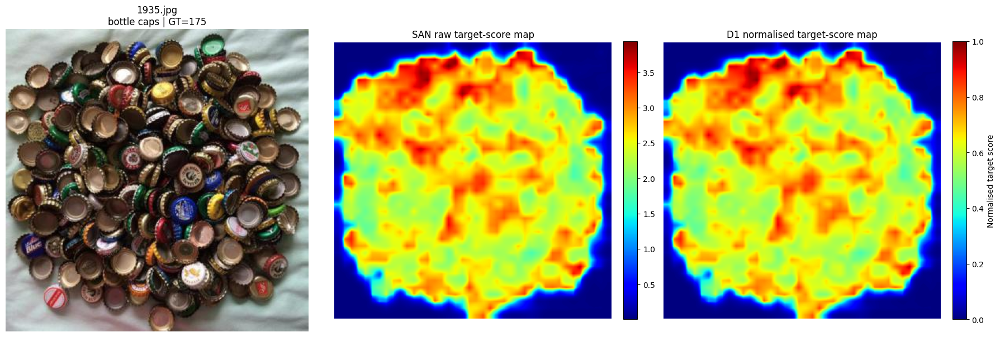

In [42]:
# ============================================================
# Step 11A.2 — Visualise D1 semantic cue
# ============================================================

image = np.asarray(
    sample["image"].convert("RGB")
)


fig, axes = plt.subplots(
    1,
    3,
    figsize=(18, 6),
)


# ------------------------------------------------------------
# Original image
# ------------------------------------------------------------

axes[0].imshow(
    image
)

axes[0].set_title(
    f"{D1_TEST_IMAGE_ID}\n"
    f"{category} | GT={gt_count}"
)

axes[0].axis("off")


# ------------------------------------------------------------
# Raw SAN target score
# ------------------------------------------------------------

im_raw = axes[1].imshow(
    target_score,
    cmap="jet",
)

axes[1].set_title(
    "SAN raw target-score map"
)

axes[1].axis("off")

fig.colorbar(
    im_raw,
    ax=axes[1],
    fraction=0.046,
    pad=0.04,
)


# ------------------------------------------------------------
# Min-max-normalised target map
# ------------------------------------------------------------

im_norm = axes[2].imshow(
    d1_target_map,
    cmap="jet",
    vmin=0,
    vmax=1,
)

axes[2].set_title(
    "D1 normalised target-score map"
)

axes[2].axis("off")

fig.colorbar(
    im_norm,
    ax=axes[2],
    fraction=0.046,
    pad=0.04,
    label="Normalised target score",
)


plt.tight_layout()
plt.show()

Step 11A findings:

The continuous SAN target-score map preserves substantial intra-region spatial variation that is lost after binary thresholding.

For the dense bottle-cap example, multiple local high-response structures are visible within the broad target region, supporting the investigation of local maxima as reference-point hypotheses in D1.

Min-max normalisation preserves the spatial ordering and peak locations while providing a convenient per-image \([0,1]\) scale.

In [43]:
# ============================================================
# Step 11B — Common local-maxima / reference-point extractor
# ============================================================

import numpy as np
from skimage.feature import peak_local_max


def extract_reference_points(
    score_map,
    min_distance_frac=0.01,
    score_threshold=0.50,
    valid_mask=None,
):
    """
    Extract local maxima from a normalised 2D semantic score map.

    Parameters
    ----------
    score_map : np.ndarray
        2D score map, expected to be normalised to [0, 1].

    min_distance_frac : float
        Minimum separation between peaks as a fraction of the
        image short side.

        Example:
        0.01 × 384 ≈ 4 pixels.

    score_threshold : float
        Minimum normalised score required for a peak.

    valid_mask : np.ndarray or None
        Optional boolean mask used to restrict allowed peak locations.
        This will be useful later for D4.

    Returns
    -------
    points_xy : np.ndarray
        Reference points in (x, y) format.

    points_yx : np.ndarray
        Same points in (row, column) = (y, x) format.

    min_distance_px : int
        Actual pixel separation used.
    """

    score_map = np.asarray(
        score_map,
        dtype=np.float32
    )

    if score_map.ndim != 2:
        raise ValueError(
            f"Expected 2D score map, got shape {score_map.shape}"
        )

    H, W = score_map.shape

    # --------------------------------------------------------
    # Convert relative separation to pixels
    # --------------------------------------------------------

    min_distance_px = max(
        1,
        int(round(
            min_distance_frac * min(H, W)
        ))
    )

    # --------------------------------------------------------
    # Optional spatial gate
    # --------------------------------------------------------

    if valid_mask is not None:

        valid_mask = np.asarray(
            valid_mask,
            dtype=bool
        )

        if valid_mask.shape != score_map.shape:
            raise ValueError(
                "valid_mask and score_map must have the same shape"
            )

        # Suppress locations outside the valid region
        working_map = score_map.copy()
        working_map[~valid_mask] = -np.inf

    else:

        working_map = score_map


    # --------------------------------------------------------
    # Local-maxima detection
    #
    # peak_local_max returns coordinates in (row, column)
    # = (y, x) order.
    # --------------------------------------------------------

    points_yx = peak_local_max(
        working_map,
        min_distance=min_distance_px,
        threshold_abs=score_threshold,
        exclude_border=False,
    )


    # --------------------------------------------------------
    # Convert to (x, y) for SAM2 / plotting convenience
    # --------------------------------------------------------

    if len(points_yx) > 0:

        points_xy = points_yx[:, [1, 0]]

    else:

        points_xy = np.empty(
            (0, 2),
            dtype=np.int64
        )


    return (
        points_xy,
        points_yx,
        min_distance_px,
    )

In [44]:
# ============================================================
# Step 11B.1 — D1 local-maxima sanity check
# ============================================================

D1_SANITY_MIN_DISTANCE_FRAC = 0.01
D1_SANITY_SCORE_THRESHOLD = 0.50


d1_points_xy, d1_points_yx, d1_min_distance_px = (
    extract_reference_points(
        d1_target_map,
        min_distance_frac=D1_SANITY_MIN_DISTANCE_FRAC,
        score_threshold=D1_SANITY_SCORE_THRESHOLD,
    )
)


d1_proxy_count = len(
    d1_points_xy
)


print(
    "Image:",
    D1_TEST_IMAGE_ID
)

print(
    "GT count:",
    gt_count
)

print(
    "Minimum distance fraction:",
    D1_SANITY_MIN_DISTANCE_FRAC
)

print(
    "Minimum distance (pixels):",
    d1_min_distance_px
)

print(
    "Score threshold:",
    D1_SANITY_SCORE_THRESHOLD
)

print(
    "D1 reference points:",
    d1_proxy_count
)

print(
    "Signed error:",
    d1_proxy_count - gt_count
)

Image: 1935.jpg
GT count: 175
Minimum distance fraction: 0.01
Minimum distance (pixels): 4
Score threshold: 0.5
D1 reference points: 157
Signed error: -18


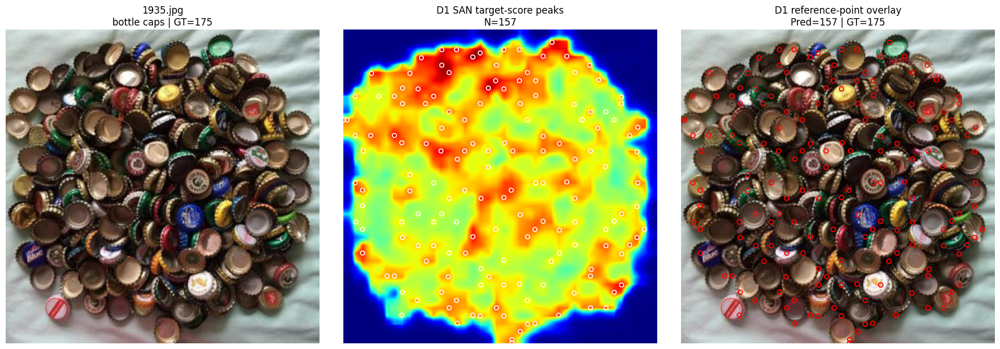

In [45]:
# ============================================================
# Step 11B.2 — Visualise D1 reference-point hypotheses
# ============================================================

fig, axes = plt.subplots(
    1,
    3,
    figsize=(18, 6),
)


# ------------------------------------------------------------
# Original image
# ------------------------------------------------------------

axes[0].imshow(
    image
)

axes[0].set_title(
    f"{D1_TEST_IMAGE_ID}\n"
    f"{category} | GT={gt_count}"
)

axes[0].axis("off")


# ------------------------------------------------------------
# Score map + detected peaks
# ------------------------------------------------------------

axes[1].imshow(
    d1_target_map,
    cmap="jet",
    vmin=0,
    vmax=1,
)

if len(d1_points_xy) > 0:

    axes[1].scatter(
        d1_points_xy[:, 0],
        d1_points_xy[:, 1],
        s=28,
        facecolors="none",
        edgecolors="white",
        linewidths=1.2,
    )

axes[1].set_title(
    f"D1 SAN target-score peaks\n"
    f"N={d1_proxy_count}"
)

axes[1].axis("off")


# ------------------------------------------------------------
# Original image + reference points
# ------------------------------------------------------------

axes[2].imshow(
    image
)

if len(d1_points_xy) > 0:

    axes[2].scatter(
        d1_points_xy[:, 0],
        d1_points_xy[:, 1],
        s=32,
        facecolors="none",
        edgecolors="red",
        linewidths=1.3,
    )

axes[2].set_title(
    f"D1 reference-point overlay\n"
    f"Pred={d1_proxy_count} | GT={gt_count}"
)

axes[2].axis("off")


plt.tight_layout()
plt.show()

GT points: 175
D1 predicted points: 157


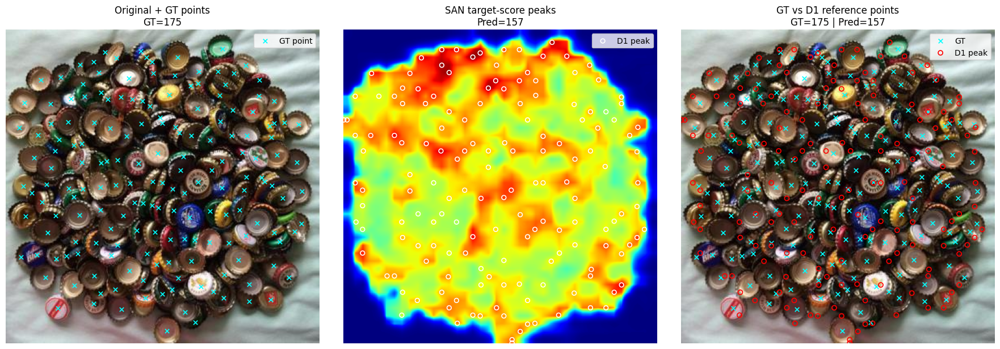

In [46]:
# ============================================================
# Step 11B.3 — Compare D1 predicted peaks with FSC-147 GT points
# ============================================================

# Reuse existing helper from the Group-A diagnostic
gt_points = get_gt_points(
    sample,
    category,
)

print("GT points:", len(gt_points))
print("D1 predicted points:", len(d1_points_xy))


fig, axes = plt.subplots(
    1,
    3,
    figsize=(18, 6),
)


# ------------------------------------------------------------
# 1. Original image + GT points
# ------------------------------------------------------------

axes[0].imshow(
    image
)

if len(gt_points) > 0:
    axes[0].scatter(
        gt_points[:, 0],
        gt_points[:, 1],
        s=28,
        marker="x",
        c="cyan",
        linewidths=1.2,
        label="GT point",
    )

axes[0].set_title(
    f"Original + GT points\n"
    f"GT={gt_count}"
)

axes[0].legend(
    loc="upper right"
)

axes[0].axis("off")


# ------------------------------------------------------------
# 2. SAN target-score map + predicted D1 peaks
# ------------------------------------------------------------

axes[1].imshow(
    d1_target_map,
    cmap="jet",
    vmin=0,
    vmax=1,
)

if len(d1_points_xy) > 0:
    axes[1].scatter(
        d1_points_xy[:, 0],
        d1_points_xy[:, 1],
        s=30,
        facecolors="none",
        edgecolors="white",
        linewidths=1.2,
        label="D1 peak",
    )

axes[1].set_title(
    f"SAN target-score peaks\n"
    f"Pred={d1_proxy_count}"
)

axes[1].legend(
    loc="upper right"
)

axes[1].axis("off")


# ------------------------------------------------------------
# 3. Original image + GT + predicted D1 peaks
# ------------------------------------------------------------

axes[2].imshow(
    image
)

# GT annotations
if len(gt_points) > 0:
    axes[2].scatter(
        gt_points[:, 0],
        gt_points[:, 1],
        s=30,
        marker="x",
        c="cyan",
        linewidths=1.2,
        label="GT",
    )

# D1 local maxima
if len(d1_points_xy) > 0:
    axes[2].scatter(
        d1_points_xy[:, 0],
        d1_points_xy[:, 1],
        s=34,
        facecolors="none",
        edgecolors="red",
        linewidths=1.2,
        label="D1 peak",
    )

axes[2].set_title(
    f"GT vs D1 reference points\n"
    f"GT={gt_count} | Pred={d1_proxy_count}"
)

axes[2].legend(
    loc="upper right"
)

axes[2].axis("off")


plt.tight_layout()
plt.show()

In [47]:
# ============================================================
# Step 11C.1 — Quantify spatial agreement: nearest distances
# ============================================================

import numpy as np
from scipy.spatial import cKDTree

# ------------------------------------------------------------
# Expected inputs from previous D1 cells
# ------------------------------------------------------------
# gt_points     : GT points in (x, y)
# d1_points_xy  : D1 predicted points in (x, y)
# pil_img       : current PIL image

# Convert to NumPy arrays
gt_xy = np.asarray(gt_points, dtype=np.float32)
pred_xy = np.asarray(d1_points_xy, dtype=np.float32)

print("GT array shape   :", gt_xy.shape)
print("Pred array shape :", pred_xy.shape)

# Basic sanity checks
assert gt_xy.ndim == 2 and gt_xy.shape[1] == 2, "gt_points must be shape (N, 2) in (x, y)"
assert pred_xy.ndim == 2 and pred_xy.shape[1] == 2, "d1_points_xy must be shape (M, 2) in (x, y)"

# ------------------------------------------------------------
# Build KD-trees
# ------------------------------------------------------------
gt_tree = cKDTree(gt_xy)
pred_tree = cKDTree(pred_xy)

# ------------------------------------------------------------
# Pred -> GT : for each predicted point, nearest GT point
# ------------------------------------------------------------
pred_to_gt_dist, pred_to_gt_idx = gt_tree.query(pred_xy, k=1)

# ------------------------------------------------------------
# GT -> Pred : for each GT point, nearest predicted point
# ------------------------------------------------------------
gt_to_pred_dist, gt_to_pred_idx = pred_tree.query(gt_xy, k=1)

print("\nNearest-neighbour distances computed successfully.")
print("Pred -> GT distances shape :", pred_to_gt_dist.shape)
print("GT -> Pred distances shape :", gt_to_pred_dist.shape)

GT array shape   : (175, 2)
Pred array shape : (157, 2)

Nearest-neighbour distances computed successfully.
Pred -> GT distances shape : (157,)
GT -> Pred distances shape : (175,)


In [48]:
# ============================================================
# Step 11C.2 — Print distance summary statistics
# ============================================================

def summarise_distances(name, d):
    d = np.asarray(d, dtype=np.float32)
    print(f"\n{name}")
    print("-" * len(name))
    print("Count         :", len(d))
    print("Mean distance :", float(np.mean(d)))
    print("Median        :", float(np.median(d)))
    print("Std           :", float(np.std(d)))
    print("Min           :", float(np.min(d)))
    print("Max           :", float(np.max(d)))
    print("P25           :", float(np.percentile(d, 25)))
    print("P75           :", float(np.percentile(d, 75)))
    print("P90           :", float(np.percentile(d, 90)))
    print("P95           :", float(np.percentile(d, 95)))

summarise_distances("Pred → GT nearest distances", pred_to_gt_dist)
summarise_distances("GT → Pred nearest distances", gt_to_pred_dist)


Pred → GT nearest distances
---------------------------
Count         : 157
Mean distance : 11.42037582397461
Median        : 11.31721019744873
Std           : 4.877446174621582
Min           : 0.5909926891326904
Max           : 22.582836151123047
P25           : 7.987703800201416
P75           : 15.137680053710938
P90           : 17.6239013671875
P95           : 18.882753372192383

GT → Pred nearest distances
---------------------------
Count         : 175
Mean distance : 12.586382865905762
Median        : 12.041858673095703
Std           : 6.002544403076172
Min           : 0.5909926891326904
Max           : 27.320484161376953
P25           : 8.47275447845459
P75           : 16.571136474609375
P90           : 20.97915267944336
P95           : 23.372684478759766


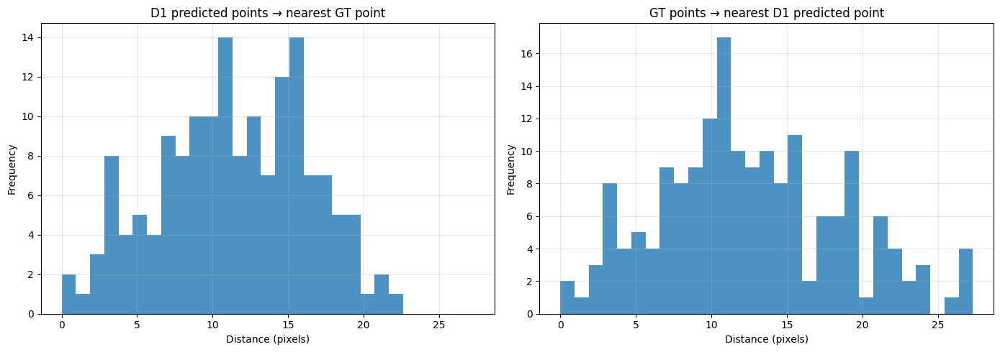

In [49]:
# ============================================================
# Step 11C.3 — Visualise distance distributions
# ============================================================

import matplotlib.pyplot as plt

max_dist = max(pred_to_gt_dist.max(), gt_to_pred_dist.max())
bins = np.linspace(0, max_dist, 30)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Pred -> GT
axes[0].hist(pred_to_gt_dist, bins=bins, alpha=0.8)
axes[0].set_title("D1 predicted points → nearest GT point")
axes[0].set_xlabel("Distance (pixels)")
axes[0].set_ylabel("Frequency")
axes[0].grid(alpha=0.3)

# GT -> Pred
axes[1].hist(gt_to_pred_dist, bins=bins, alpha=0.8)
axes[1].set_title("GT points → nearest D1 predicted point")
axes[1].set_xlabel("Distance (pixels)")
axes[1].set_ylabel("Frequency")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

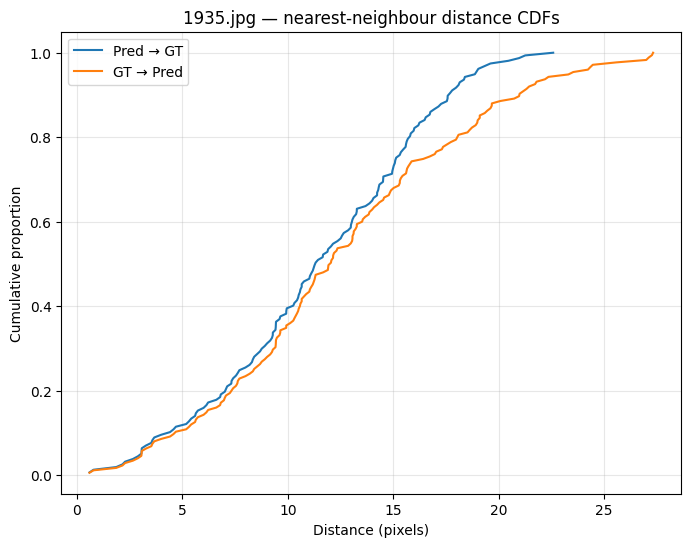

In [50]:
# ============================================================
# Step 11C.4 — Cumulative distance curves
# ============================================================

def empirical_cdf(distances):
    x = np.sort(distances)
    y = np.arange(1, len(x) + 1) / len(x)
    return x, y

x1, y1 = empirical_cdf(pred_to_gt_dist)
x2, y2 = empirical_cdf(gt_to_pred_dist)

plt.figure(figsize=(8, 6))

plt.plot(
    x1,
    y1,
    label="Pred → GT"
)

plt.plot(
    x2,
    y2,
    label="GT → Pred"
)

plt.xlabel("Distance (pixels)")
plt.ylabel("Cumulative proportion")

plt.title(
    f"{D1_TEST_IMAGE_ID} — nearest-neighbour distance CDFs"
)

plt.grid(alpha=0.3)
plt.legend()

plt.show()

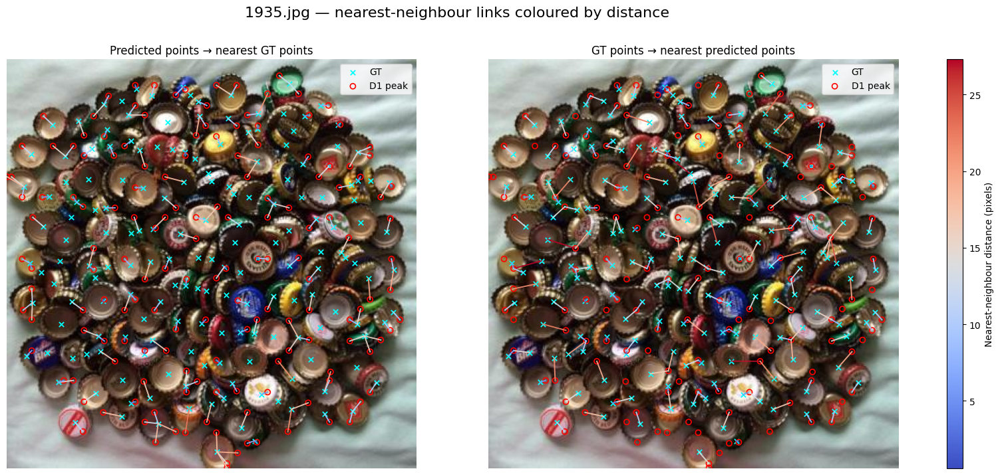

In [51]:
# ============================================================
# Step 11C.5 — Nearest-neighbour links coloured by distance
#              with separate colour-bar axis
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from PIL import Image


# ------------------------------------------------------------
# 0. Load image
# ------------------------------------------------------------

image_path = FSC147_IMAGE_DIR / D1_TEST_IMAGE_ID

image_np = np.array(
    Image.open(image_path).convert("RGB")
)


# ------------------------------------------------------------
# 1. Common distance colour scale
# ------------------------------------------------------------

all_dists = np.concatenate([
    pred_to_gt_dist,
    gt_to_pred_dist
])

vmin = float(all_dists.min())
vmax = float(all_dists.max())

norm = mpl.colors.Normalize(
    vmin=vmin,
    vmax=vmax
)

# Blue = shorter distance
# Red  = longer distance
cmap = plt.cm.coolwarm


# ------------------------------------------------------------
# 2. Figure layout
#
# Dedicated third column for colour bar
# ------------------------------------------------------------

fig = plt.figure(
    figsize=(19, 8)
)

gs = fig.add_gridspec(
    1,
    3,
    width_ratios=[1, 1, 0.035],
    wspace=0.08
)

ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1])

# Dedicated colour-bar axis
cax = fig.add_subplot(gs[0, 2])


# ============================================================
# Left — Predicted point -> nearest GT point
# ============================================================

ax1.imshow(image_np)

ax1.scatter(
    gt_xy[:, 0],
    gt_xy[:, 1],
    marker="x",
    s=28,
    c="cyan",
    linewidths=1.3,
    label="GT"
)

ax1.scatter(
    pred_xy[:, 0],
    pred_xy[:, 1],
    facecolors="none",
    edgecolors="red",
    s=34,
    linewidths=1.2,
    label="D1 peak"
)


for i in range(len(pred_xy)):

    px, py = pred_xy[i]

    gx, gy = gt_xy[
        pred_to_gt_idx[i]
    ]

    d = pred_to_gt_dist[i]

    ax1.plot(
        [px, gx],
        [py, gy],
        color=cmap(norm(d)),
        linewidth=1.4,
        alpha=0.9
    )


ax1.set_title(
    "Predicted points → nearest GT points"
)

ax1.axis("off")

ax1.legend(
    loc="upper right"
)


# ============================================================
# Right — GT point -> nearest predicted point
# ============================================================

ax2.imshow(image_np)

ax2.scatter(
    gt_xy[:, 0],
    gt_xy[:, 1],
    marker="x",
    s=28,
    c="cyan",
    linewidths=1.3,
    label="GT"
)

ax2.scatter(
    pred_xy[:, 0],
    pred_xy[:, 1],
    facecolors="none",
    edgecolors="red",
    s=34,
    linewidths=1.2,
    label="D1 peak"
)


for i in range(len(gt_xy)):

    gx, gy = gt_xy[i]

    px, py = pred_xy[
        gt_to_pred_idx[i]
    ]

    d = gt_to_pred_dist[i]

    ax2.plot(
        [gx, px],
        [gy, py],
        color=cmap(norm(d)),
        linewidth=1.4,
        alpha=0.9
    )


ax2.set_title(
    "GT points → nearest predicted points"
)

ax2.axis("off")

ax2.legend(
    loc="upper right"
)


# ------------------------------------------------------------
# 3. Separate shared colour bar
# ------------------------------------------------------------

sm = mpl.cm.ScalarMappable(
    norm=norm,
    cmap=cmap
)

sm.set_array([])

cbar = fig.colorbar(
    sm,
    cax=cax
)

cbar.set_label(
    "Nearest-neighbour distance (pixels)"
)


# ------------------------------------------------------------
# Figure title
# ------------------------------------------------------------

fig.suptitle(
    f"{D1_TEST_IMAGE_ID} — nearest-neighbour links coloured by distance",
    fontsize=16
)

plt.show()

In [52]:
# ============================================================
# Step 11C.6 — Simple radius-based coverage summary
# ============================================================

radii = [3, 5, 7, 10, 15, 20]

print(
    f"\n{D1_TEST_IMAGE_ID} — "
    "radius-based nearest-neighbour coverage"
)

print("-" * 64)

print(
    f"{'Radius':>8} | "
    f"{'Pred→GT within r':>18} | "
    f"{'GT→Pred within r':>18}"
)

print("-" * 64)

for r in radii:

    pred_cov = (
        pred_to_gt_dist <= r
    ).mean()

    gt_cov = (
        gt_to_pred_dist <= r
    ).mean()

    print(
        f"{r:>8} | "
        f"{pred_cov:>18.4f} | "
        f"{gt_cov:>18.4f}"
    )


1935.jpg — radius-based nearest-neighbour coverage
----------------------------------------------------------------
  Radius |   Pred→GT within r |   GT→Pred within r
----------------------------------------------------------------
       3 |             0.0446 |             0.0400
       5 |             0.1146 |             0.1029
       7 |             0.1911 |             0.1771
      10 |             0.3949 |             0.3543
      15 |             0.7261 |             0.6743
      20 |             0.9745 |             0.8800


### Step 11C conclusion — single-image spatial sanity check

The D1 local-maxima method was examined on `1935.jpg`
(`bottle caps`, GT = 175).

With the exploratory settings:

- `min_distance_frac = 0.01`
- `score_threshold = 0.50`

D1 generated 157 reference points.

The bidirectional nearest-neighbour analysis showed that the
predicted points are concentrated in the correct target-object region,
but they do not form a reliable one-to-one correspondence with the
FSC-147 annotation points.

At increasing spatial tolerances, nearest-neighbour coverage improved
substantially, indicating that many predicted peaks occur near target
instances, although duplicate peaks and missed objects are both present.

The similarity between the predicted-point count (157) and the GT count
(175) must therefore not be interpreted as evidence of accurate instance
localisation, because false and missed peaks may cancel numerically.

This step is a qualitative and diagnostic sanity check only.
The parameters used here are exploratory and are not selected D1
parameters.

The next stage evaluates D1 systematically over the frozen dev100 subset
using one-to-one point matching and proxy-count diagnostics.

In [53]:
# ============================================================
# Step 11D.1 — Freeze D1 Stage-1 experiment protocol
# ============================================================

D1_MIN_DISTANCE_FRACS = [
    0.005,
    0.010,
    0.020,
    0.030,
]

D1_SCORE_THRESHOLDS = [
    0.30,
    0.40,
    0.50,
    0.60,
    0.70,
]

D1_MATCH_RADII_FRACS = [
    0.01,
    0.02,
    0.03,
    0.05,
]

print("D1 min-distance fractions:")
print(D1_MIN_DISTANCE_FRACS)

print("\nD1 score thresholds:")
print(D1_SCORE_THRESHOLDS)

print("\nPoint-matching radii:")
print(D1_MATCH_RADII_FRACS)

print(
    "\nNumber of D1 parameter configurations:",
    len(D1_MIN_DISTANCE_FRACS)
    * len(D1_SCORE_THRESHOLDS)
)

D1 min-distance fractions:
[0.005, 0.01, 0.02, 0.03]

D1 score thresholds:
[0.3, 0.4, 0.5, 0.6, 0.7]

Point-matching radii:
[0.01, 0.02, 0.03, 0.05]

Number of D1 parameter configurations: 20


In [54]:
# ============================================================
# Step 11D.2 — One-to-one point matching
# ============================================================

import numpy as np

from scipy.optimize import linear_sum_assignment
from scipy.spatial.distance import cdist


def match_points_one_to_one(
    pred_xy,
    gt_xy,
    radius_px,
):
    """
    One-to-one matching between predicted reference points
    and FSC-147 GT points.

    Matching objective:
        1. maximise the number of matches within radius_px
        2. among maximum-cardinality matchings, minimise
           total Euclidean distance

    Each predicted point and each GT point can be used
    at most once.

    Returns
    -------
    dict containing:
        matches:
            array of shape (TP, 2)
            columns = [pred_index, gt_index]

        distances:
            Euclidean distance for each accepted match

        tp:
            number of matched pairs

        fp:
            unmatched predicted points

        fn:
            unmatched GT points
    """

    pred_xy = np.asarray(
        pred_xy,
        dtype=np.float32,
    ).reshape(-1, 2)

    gt_xy = np.asarray(
        gt_xy,
        dtype=np.float32,
    ).reshape(-1, 2)

    n_pred = len(pred_xy)
    n_gt = len(gt_xy)

    # --------------------------------------------------------
    # Handle empty point sets
    # --------------------------------------------------------

    if n_pred == 0 or n_gt == 0:

        return {
            "matches": np.empty(
                (0, 2),
                dtype=np.int64,
            ),
            "distances": np.empty(
                (0,),
                dtype=np.float32,
            ),
            "tp": 0,
            "fp": n_pred,
            "fn": n_gt,
        }

    # --------------------------------------------------------
    # Pairwise Euclidean distances
    # --------------------------------------------------------

    dist_matrix = cdist(
        pred_xy,
        gt_xy,
        metric="euclidean",
    )

    # --------------------------------------------------------
    # Assignment cost matrix
    #
    # Dummy rows/columns allow points to remain unmatched.
    #
    # Valid pred-GT match:
    #     cost = Euclidean distance
    #
    # Unmatched point:
    #     cost = radius + 1
    #
    # Invalid pred-GT match:
    #     prohibitively large cost
    # --------------------------------------------------------

    unmatched_cost = (
        float(radius_px) + 1.0
    )

    forbidden_cost = (
        1e6
        + 10.0 * unmatched_cost
    )

    N = n_pred + n_gt

    cost_matrix = np.full(
        (N, N),
        forbidden_cost,
        dtype=np.float64,
    )

    # Valid predicted -> GT edges
    valid = (
        dist_matrix <= radius_px
    )

    cost_matrix[
        :n_pred,
        :n_gt,
    ][valid] = dist_matrix[valid]

    # Each prediction may remain unmatched
    for i in range(n_pred):

        cost_matrix[
            i,
            n_gt + i,
        ] = unmatched_cost

    # Each GT point may remain unmatched
    for j in range(n_gt):

        cost_matrix[
            n_pred + j,
            j,
        ] = unmatched_cost

    # Dummy-to-dummy assignments
    cost_matrix[
        n_pred:,
        n_gt:,
    ] = 0.0

    # --------------------------------------------------------
    # Hungarian assignment
    # --------------------------------------------------------

    row_ind, col_ind = (
        linear_sum_assignment(
            cost_matrix
        )
    )

    # Keep only real prediction -> real GT assignments
    real_match_mask = (
        (row_ind < n_pred)
        &
        (col_ind < n_gt)
    )

    pred_idx = row_ind[
        real_match_mask
    ]

    gt_idx = col_ind[
        real_match_mask
    ]

    matched_distances = (
        dist_matrix[
            pred_idx,
            gt_idx,
        ]
    )

    # Safety check: retain only matches within radius
    accepted = (
        matched_distances
        <= radius_px
    )

    pred_idx = pred_idx[accepted]
    gt_idx = gt_idx[accepted]

    matched_distances = (
        matched_distances[accepted]
    )

    # --------------------------------------------------------
    # Final counts
    # --------------------------------------------------------

    tp = len(pred_idx)
    fp = n_pred - tp
    fn = n_gt - tp

    if tp > 0:

        matches = np.column_stack(
            [
                pred_idx,
                gt_idx,
            ]
        )

    else:

        matches = np.empty(
            (0, 2),
            dtype=np.int64,
        )

    return {
        "matches": matches,
        "distances":
            matched_distances.astype(
                np.float32
            ),
        "tp": tp,
        "fp": fp,
        "fn": fn,
    }

In [55]:
# ============================================================
# Step 11D.3 — One-to-one matching sanity check on 1935.jpg
# ============================================================

from PIL import Image
import numpy as np
import pandas as pd


# ------------------------------------------------------------
# Load image dimensions
# ------------------------------------------------------------

image_path = (
    FSC147_IMAGE_DIR
    / D1_TEST_IMAGE_ID
)

with Image.open(image_path) as img:
    W, H = img.size

short_side = min(H, W)

print("Image:", D1_TEST_IMAGE_ID)
print("Image size (W x H):", W, "x", H)
print("Short side:", short_side)

print(
    "Predicted D1 points:",
    len(d1_points_xy),
)

print(
    "GT points:",
    len(gt_points),
)


# ------------------------------------------------------------
# Evaluate frozen matching radii
# ------------------------------------------------------------

rows = []

for radius_frac in D1_MATCH_RADII_FRACS:

    radius_px = max(
        1,
        int(
            round(
                radius_frac
                * short_side
            )
        ),
    )

    result = match_points_one_to_one(
        pred_xy=d1_points_xy,
        gt_xy=gt_points,
        radius_px=radius_px,
    )

    tp = result["tp"]
    fp = result["fp"]
    fn = result["fn"]

    # --------------------------------------------------------
    # Precision / Recall / F1
    # --------------------------------------------------------

    precision = (
        tp / (tp + fp)
        if (tp + fp) > 0
        else 0.0
    )

    recall = (
        tp / (tp + fn)
        if (tp + fn) > 0
        else 0.0
    )

    f1 = (
        2 * precision * recall
        / (precision + recall)
        if (precision + recall) > 0
        else 0.0
    )

    # --------------------------------------------------------
    # Localisation distance of accepted matches
    # --------------------------------------------------------

    distances = result["distances"]

    if len(distances) > 0:

        mean_dist = float(
            np.mean(distances)
        )

        median_dist = float(
            np.median(distances)
        )

    else:

        mean_dist = np.nan
        median_dist = np.nan

    rows.append(
        {
            "radius_frac":
                radius_frac,

            "radius_px":
                radius_px,

            "TP": tp,
            "FP": fp,
            "FN": fn,

            "precision":
                precision,

            "recall":
                recall,

            "f1":
                f1,

            "mean_match_dist_px":
                mean_dist,

            "median_match_dist_px":
                median_dist,
        }
    )


d1_1935_match_df = pd.DataFrame(
    rows
)

display(
    d1_1935_match_df.round(4)
)

Image: 1935.jpg
Image size (W x H): 384 x 384
Short side: 384
Predicted D1 points: 157
GT points: 175


,radius_frac,radius_px,TP,FP,FN,precision,recall,f1,mean_match_dist_px,median_match_dist_px
0,0.01,4,15,142,160,0.0955,0.0857,0.0904,2.6951,3.0536
1,0.02,8,38,119,137,0.2420,0.2171,0.2289,4.8740,5.2443
2,0.03,12,80,77,95,0.5096,0.4571,0.4819,7.6927,8.3713
3,0.05,19,124,33,51,0.7898,0.7086,0.7470,10.8226,10.5828


In [56]:
# ============================================================
# Step 11D.4 — Generate D1 reference points on dev100
# ============================================================

import time
import numpy as np
import pandas as pd

from tqdm.auto import tqdm


d1_prediction_rows = []

start_time = time.perf_counter()


for _, row in tqdm(
    fsc147_dev_100_df.iterrows(),
    total=len(fsc147_dev_100_df),
    desc="Generating D1 dev100 predictions",
):

    # --------------------------------------------------------
    # Image metadata
    # --------------------------------------------------------

    image_id = row["image_id"]
    category = row["category"]

    dataset_index = int(
        row["dataset_index"]
    )

    gt_count = int(
        row["gt_count"]
    )

    density_stratum = row[
        "density_stratum"
    ]

    sample = fsc147_val_dataset[
        dataset_index
    ]

    width = int(
        sample["width"]
    )

    height = int(
        sample["height"]
    )

    short_side = min(
        width,
        height,
    )

    # --------------------------------------------------------
    # GT points
    # --------------------------------------------------------

    gt_points_xy = get_gt_points(
        sample,
        category,
    )

    assert (
        len(gt_points_xy)
        == gt_count
    )

    # --------------------------------------------------------
    # Load cached SAN target score
    # --------------------------------------------------------

    cached = load_san_cache(
        image_id
    )

    target_score = np.asarray(
        cached["target_score"],
        dtype=np.float32,
    )

    # --------------------------------------------------------
    # Per-image min-max normalisation
    # --------------------------------------------------------

    target_score_norm = (
        minmax_normalise_score_map(
            target_score
        )
    )

    # --------------------------------------------------------
    # Run all frozen D1 parameter combinations
    # --------------------------------------------------------

    for min_distance_frac in (
        D1_MIN_DISTANCE_FRACS
    ):

        for score_threshold in (
            D1_SCORE_THRESHOLDS
        ):

            points_xy, _, min_distance_px = (
                extract_reference_points(
                    target_score_norm,
                    min_distance_frac=
                        min_distance_frac,
                    score_threshold=
                        score_threshold,
                    valid_mask=None,
                )
            )

            pred_count = len(
                points_xy
            )

            d1_prediction_rows.append(
                {
                    "image_id":
                        image_id,

                    "dataset_index":
                        dataset_index,

                    "category":
                        category,

                    "density_stratum":
                        density_stratum,

                    "width":
                        width,

                    "height":
                        height,

                    "short_side":
                        short_side,

                    "gt_count":
                        gt_count,

                    "min_distance_frac":
                        min_distance_frac,

                    "min_distance_px":
                        min_distance_px,

                    "score_threshold":
                        score_threshold,

                    "pred_count":
                        pred_count,

                    "count_error":
                        pred_count
                        - gt_count,

                    # Keep arrays for later matching
                    "pred_points_xy":
                        points_xy,

                    "gt_points_xy":
                        gt_points_xy,
                }
            )


d1_predictions_df = pd.DataFrame(
    d1_prediction_rows
)

runtime = (
    time.perf_counter()
    - start_time
)


# ------------------------------------------------------------
# Validation
# ------------------------------------------------------------

expected_rows = (
    len(fsc147_dev_100_df)
    * len(D1_MIN_DISTANCE_FRACS)
    * len(D1_SCORE_THRESHOLDS)
)

assert (
    len(d1_predictions_df)
    == expected_rows
)

assert (
    d1_predictions_df[
        "image_id"
    ].nunique()
    == 100
)


print(
    "D1 prediction rows:",
    len(d1_predictions_df),
)

print(
    "Expected rows:",
    expected_rows,
)

print(
    f"Runtime: {runtime:.3f} s"
)

display(
    d1_predictions_df[
        [
            "image_id",
            "density_stratum",
            "gt_count",
            "min_distance_frac",
            "min_distance_px",
            "score_threshold",
            "pred_count",
            "count_error",
        ]
    ].head(20)
)

Generating D1 dev100 predictions:   0%|          | 0/100 [00:00<?, ?it/s]

D1 prediction rows: 2000
Expected rows: 2000
Runtime: 61.335 s


,image_id,density_stratum,gt_count,min_distance_frac,min_distance_px,score_threshold,pred_count,count_error
0,3873.jpg,S1_0_20,7,0.005,2,0.3,81,74
1,3873.jpg,S1_0_20,7,0.005,2,0.4,81,74
2,3873.jpg,S1_0_20,7,0.005,2,0.5,81,74
3,3873.jpg,S1_0_20,7,0.005,2,0.6,79,72
4,3873.jpg,S1_0_20,7,0.005,2,0.7,65,58
5,3873.jpg,S1_0_20,7,0.010,4,0.3,73,66
6,3873.jpg,S1_0_20,7,0.010,4,0.4,73,66
7,3873.jpg,S1_0_20,7,0.010,4,0.5,73,66
8,3873.jpg,S1_0_20,7,0.010,4,0.6,72,65
9,3873.jpg,S1_0_20,7,0.010,4,0.7,60,53


In [57]:
# ============================================================
# Step 11D.5 — Diagnostic summary of D1 prediction counts
# ============================================================

import numpy as np
import pandas as pd


# ------------------------------------------------------------
# Aggregate the 20 D1 configurations across dev100
# ------------------------------------------------------------

d1_config_summary = (
    d1_predictions_df
    .groupby(
        [
            "min_distance_frac",
            "score_threshold",
        ],
        as_index=False,
    )
    .agg(
        n_images=("image_id", "count"),

        # Reference-point generation
        total_pred=("pred_count", "sum"),
        mean_pred=("pred_count", "mean"),
        median_pred=("pred_count", "median"),
        std_pred=("pred_count", "std"),
        max_pred=("pred_count", "max"),

        # GT distribution
        total_gt=("gt_count", "sum"),
        mean_gt=("gt_count", "mean"),

        # Signed count behaviour
        mean_signed_error=("count_error", "mean"),
    )
)


# ------------------------------------------------------------
# Add percentile and proxy count metrics
# ------------------------------------------------------------

extra_rows = []

for (
    min_distance_frac,
    score_threshold,
), group in d1_predictions_df.groupby(
    [
        "min_distance_frac",
        "score_threshold",
    ]
):

    errors = (
        group["pred_count"].to_numpy()
        - group["gt_count"].to_numpy()
    )

    abs_errors = np.abs(errors)

    mae = float(
        np.mean(abs_errors)
    )

    rmse = float(
        np.sqrt(
            np.mean(
                errors ** 2
            )
        )
    )

    p95_pred = float(
        np.percentile(
            group["pred_count"],
            95,
        )
    )

    under_count = int(
        np.sum(errors < 0)
    )

    exact_count = int(
        np.sum(errors == 0)
    )

    over_count = int(
        np.sum(errors > 0)
    )

    extra_rows.append(
        {
            "min_distance_frac":
                min_distance_frac,

            "score_threshold":
                score_threshold,

            "p95_pred":
                p95_pred,

            "proxy_mae":
                mae,

            "proxy_rmse":
                rmse,

            "under_images":
                under_count,

            "exact_images":
                exact_count,

            "over_images":
                over_count,
        }
    )


d1_extra_summary = pd.DataFrame(
    extra_rows
)


# ------------------------------------------------------------
# Merge summaries
# ------------------------------------------------------------

d1_config_summary = (
    d1_config_summary
    .merge(
        d1_extra_summary,
        on=[
            "min_distance_frac",
            "score_threshold",
        ],
        how="left",
    )
)


# ------------------------------------------------------------
# Arrange columns
# ------------------------------------------------------------

d1_config_summary = (
    d1_config_summary[
        [
            "min_distance_frac",
            "score_threshold",

            "n_images",

            "total_gt",
            "total_pred",

            "mean_gt",
            "mean_pred",
            "median_pred",
            "std_pred",
            "p95_pred",
            "max_pred",

            "mean_signed_error",
            "proxy_mae",
            "proxy_rmse",

            "under_images",
            "exact_images",
            "over_images",
        ]
    ]
    .sort_values(
        [
            "min_distance_frac",
            "score_threshold",
        ]
    )
    .reset_index(drop=True)
)


print(
    "Number of D1 configurations:",
    len(d1_config_summary),
)

display(
    d1_config_summary.round(3)
)

Number of D1 configurations: 20


,min_distance_frac,score_threshold,n_images,total_gt,total_pred,mean_gt,mean_pred,median_pred,std_pred,p95_pred,max_pred,mean_signed_error,proxy_mae,proxy_rmse,under_images,exact_images,over_images
0,0.005,0.3,100,10045,12671,100.45,126.71,103.5,96.750,334.35,437,26.26,129.82,264.490,16,1,83
1,0.005,0.4,100,10045,11845,100.45,118.45,94.5,90.844,305.05,437,18.00,129.74,272.854,17,2,81
2,0.005,0.5,100,10045,10834,100.45,108.34,89.0,84.895,264.20,435,7.89,127.07,278.327,21,1,78
3,0.005,0.6,100,10045,9654,100.45,96.54,86.0,76.516,231.50,429,-3.91,120.49,276.920,26,1,73
4,0.005,0.7,100,10045,8021,100.45,80.21,63.5,70.472,210.85,420,-20.24,112.54,275.086,34,1,65
5,0.010,0.3,100,10045,10838,100.45,108.38,90.0,77.081,267.35,353,7.93,114.61,258.012,19,2,79
6,0.010,0.4,100,10045,10186,100.45,101.86,82.0,73.164,249.85,353,1.41,115.51,266.608,20,2,78
7,0.010,0.5,100,10045,9368,100.45,93.68,81.0,69.459,220.30,352,-6.77,115.61,272.999,24,2,74
8,0.010,0.6,100,10045,8427,100.45,84.27,76.5,63.547,201.20,349,-16.18,111.02,273.247,27,1,72
9,0.010,0.7,100,10045,7041,100.45,70.41,54.0,59.115,176.50,345,-30.04,105.10,272.612,35,0,65


In [58]:
# ============================================================
# Step 11D.6A — Memory-efficient one-to-one matcher
# ============================================================

import numpy as np

from scipy.optimize import linear_sum_assignment
from scipy.spatial.distance import cdist


def match_points_one_to_one_efficient(
    pred_xy,
    gt_xy,
    radius_px,
):
    """
    Memory-efficient one-to-one matching.

    Objective:
        1. maximise number of matches within radius_px
        2. among maximum-cardinality matchings,
           minimise total Euclidean distance

    Each predicted point and each GT point can be matched
    at most once.
    """

    pred_xy = np.asarray(
        pred_xy,
        dtype=np.float32,
    ).reshape(-1, 2)

    gt_xy = np.asarray(
        gt_xy,
        dtype=np.float32,
    ).reshape(-1, 2)

    n_pred = len(pred_xy)
    n_gt = len(gt_xy)

    # --------------------------------------------------------
    # Empty cases
    # --------------------------------------------------------

    if n_pred == 0 or n_gt == 0:

        return {
            "matches": np.empty(
                (0, 2),
                dtype=np.int64,
            ),

            "distances": np.empty(
                (0,),
                dtype=np.float32,
            ),

            "tp": 0,
            "fp": n_pred,
            "fn": n_gt,
        }

    # --------------------------------------------------------
    # Pairwise distances
    # --------------------------------------------------------

    dist_matrix = cdist(
        pred_xy,
        gt_xy,
        metric="euclidean",
    )

    valid = (
        dist_matrix <= radius_px
    )

    # --------------------------------------------------------
    # Lexicographic objective:
    #
    # unmatched_cost is deliberately made larger than the
    # maximum possible accumulated localisation-distance
    # change.
    #
    # Therefore:
    #   maximum-cardinality matching has priority,
    # then minimum distance.
    # --------------------------------------------------------

    max_possible_matches = min(
        n_pred,
        n_gt,
    )

    unmatched_cost = (
        (max_possible_matches + 1)
        * (float(radius_px) + 1.0)
    )

    forbidden_cost = (
        unmatched_cost
        * (max_possible_matches + 2)
    )

    # --------------------------------------------------------
    # Rectangular assignment matrix
    #
    # Columns:
    #   0 ... n_gt-1       = real GT points
    #   n_gt ...           = dummy unmatched columns
    #
    # This is smaller than the square matrix used in 11D.2.
    # --------------------------------------------------------

    cost_matrix = np.full(
        (
            n_pred,
            n_gt + n_pred,
        ),
        forbidden_cost,
        dtype=np.float64,
    )

    # Real valid prediction -> GT costs
    real_costs = cost_matrix[
        :,
        :n_gt,
    ]

    real_costs[valid] = (
        dist_matrix[valid]
    )

    # Any prediction may remain unmatched
    cost_matrix[
        :,
        n_gt:
    ] = unmatched_cost

    # --------------------------------------------------------
    # Hungarian assignment
    # --------------------------------------------------------

    row_ind, col_ind = (
        linear_sum_assignment(
            cost_matrix
        )
    )

    # Real prediction -> GT assignments only
    real_match_mask = (
        col_ind < n_gt
    )

    pred_idx = row_ind[
        real_match_mask
    ]

    gt_idx = col_ind[
        real_match_mask
    ]

    matched_distances = (
        dist_matrix[
            pred_idx,
            gt_idx,
        ]
    )

    # Safety check
    accepted = (
        matched_distances
        <= radius_px
    )

    pred_idx = pred_idx[
        accepted
    ]

    gt_idx = gt_idx[
        accepted
    ]

    matched_distances = (
        matched_distances[
            accepted
        ]
    )

    tp = len(pred_idx)
    fp = n_pred - tp
    fn = n_gt - tp

    if tp > 0:

        matches = np.column_stack(
            [
                pred_idx,
                gt_idx,
            ]
        ).astype(
            np.int64
        )

    else:

        matches = np.empty(
            (0, 2),
            dtype=np.int64,
        )

    return {
        "matches": matches,

        "distances":
            matched_distances.astype(
                np.float32
            ),

        "tp": tp,
        "fp": fp,
        "fn": fn,
    }

In [59]:
# ============================================================
# Step 11D.6A.1 — Verify efficient matcher against 11D.2
# ============================================================

for radius_frac in D1_MATCH_RADII_FRACS:

    radius_px = max(
        1,
        int(
            round(
                radius_frac
                * 384
            )
        ),
    )

    old_result = (
        match_points_one_to_one(
            d1_points_xy,
            gt_points,
            radius_px,
        )
    )

    new_result = (
        match_points_one_to_one_efficient(
            d1_points_xy,
            gt_points,
            radius_px,
        )
    )

    assert (
        old_result["tp"]
        == new_result["tp"]
    )

    assert np.isclose(
        old_result[
            "distances"
        ].sum(),
        new_result[
            "distances"
        ].sum(),
        atol=1e-5,
    )

    print(
        f"radius={radius_px:>2}px | "
        f"TP={new_result['tp']:>3} | "
        "MATCH"
    )

print(
    "\nEfficient matcher agrees "
    "with original 11D.2 matcher."
)

radius= 4px | TP= 15 | MATCH
radius= 8px | TP= 38 | MATCH
radius=12px | TP= 80 | MATCH
radius=19px | TP=124 | MATCH

Efficient matcher agrees with original 11D.2 matcher.


In [60]:
# ============================================================
# Step 11D.6B — Full D1 one-to-one matching on dev100
# ============================================================

import time
import numpy as np
import pandas as pd

from tqdm.auto import tqdm


d1_match_rows = []

start_time = time.perf_counter()


for _, row in tqdm(
    d1_predictions_df.iterrows(),
    total=len(d1_predictions_df),
    desc="D1 one-to-one matching",
):

    image_id = row[
        "image_id"
    ]

    short_side = int(
        row["short_side"]
    )

    gt_count = int(
        row["gt_count"]
    )

    pred_count = int(
        row["pred_count"]
    )

    gt_xy = row[
        "gt_points_xy"
    ]

    pred_xy = row[
        "pred_points_xy"
    ]

    # --------------------------------------------------------
    # Evaluate all four frozen matching radii
    # --------------------------------------------------------

    for radius_frac in (
        D1_MATCH_RADII_FRACS
    ):

        radius_px = max(
            1,
            int(
                round(
                    radius_frac
                    * short_side
                )
            ),
        )

        result = (
            match_points_one_to_one_efficient(
                pred_xy=pred_xy,
                gt_xy=gt_xy,
                radius_px=radius_px,
            )
        )

        tp = int(
            result["tp"]
        )

        fp = int(
            result["fp"]
        )

        fn = int(
            result["fn"]
        )

        # ----------------------------------------------------
        # Precision / Recall / F1
        # ----------------------------------------------------

        precision = (
            tp / (tp + fp)
            if (tp + fp) > 0
            else 0.0
        )

        recall = (
            tp / (tp + fn)
            if (tp + fn) > 0
            else 0.0
        )

        f1 = (
            2.0
            * precision
            * recall
            / (
                precision
                + recall
            )
            if (
                precision
                + recall
            ) > 0
            else 0.0
        )

        # ----------------------------------------------------
        # Localisation distances
        # ----------------------------------------------------

        distances = np.asarray(
            result["distances"],
            dtype=np.float32,
        )

        if len(distances) > 0:

            mean_dist_px = float(
                np.mean(
                    distances
                )
            )

            median_dist_px = float(
                np.median(
                    distances
                )
            )

            mean_dist_frac = (
                mean_dist_px
                / short_side
            )

            median_dist_frac = (
                median_dist_px
                / short_side
            )

        else:

            mean_dist_px = np.nan
            median_dist_px = np.nan

            mean_dist_frac = np.nan
            median_dist_frac = np.nan

        # ----------------------------------------------------
        # Store one row per
        # image × configuration × radius
        # ----------------------------------------------------

        d1_match_rows.append(
            {
                "image_id":
                    image_id,

                "dataset_index":
                    row["dataset_index"],

                "category":
                    row["category"],

                "density_stratum":
                    row[
                        "density_stratum"
                    ],

                "short_side":
                    short_side,

                "gt_count":
                    gt_count,

                "pred_count":
                    pred_count,

                "count_error":
                    row[
                        "count_error"
                    ],

                "min_distance_frac":
                    row[
                        "min_distance_frac"
                    ],

                "min_distance_px":
                    row[
                        "min_distance_px"
                    ],

                "score_threshold":
                    row[
                        "score_threshold"
                    ],

                "radius_frac":
                    radius_frac,

                "radius_px":
                    radius_px,

                "tp":
                    tp,

                "fp":
                    fp,

                "fn":
                    fn,

                "precision":
                    precision,

                "recall":
                    recall,

                "f1":
                    f1,

                "mean_match_dist_px":
                    mean_dist_px,

                "median_match_dist_px":
                    median_dist_px,

                "mean_match_dist_frac":
                    mean_dist_frac,

                "median_match_dist_frac":
                    median_dist_frac,
            }
        )


d1_match_results_df = pd.DataFrame(
    d1_match_rows
)


runtime = (
    time.perf_counter()
    - start_time
)


# ------------------------------------------------------------
# Validation
# ------------------------------------------------------------

expected_rows = (
    len(d1_predictions_df)
    * len(D1_MATCH_RADII_FRACS)
)

assert (
    len(d1_match_results_df)
    == expected_rows
)

assert (
    d1_match_results_df[
        "image_id"
    ].nunique()
    == 100
)


print(
    "D1 matching rows:",
    len(d1_match_results_df),
)

print(
    "Expected rows:",
    expected_rows,
)

print(
    f"Runtime: {runtime:.2f} s"
)

display(
    d1_match_results_df[
        [
            "image_id",
            "density_stratum",

            "gt_count",
            "pred_count",

            "min_distance_frac",
            "score_threshold",

            "radius_frac",
            "radius_px",

            "tp",
            "fp",
            "fn",

            "precision",
            "recall",
            "f1",

            "median_match_dist_px",
        ]
    ]
    .head(20)
    .round(4)
)

D1 one-to-one matching:   0%|          | 0/2000 [00:00<?, ?it/s]

D1 matching rows: 8000
Expected rows: 8000
Runtime: 2.96 s


,image_id,density_stratum,gt_count,pred_count,min_distance_frac,score_threshold,radius_frac,radius_px,tp,fp,fn,precision,recall,f1,median_match_dist_px
0,3873.jpg,S1_0_20,7,81,0.005,0.3,0.01,4,0,81,7,0.0000,0.0000,0.0000,NaN
1,3873.jpg,S1_0_20,7,81,0.005,0.3,0.02,8,1,80,6,0.0123,0.1429,0.0227,7.7841
2,3873.jpg,S1_0_20,7,81,0.005,0.3,0.03,12,4,77,3,0.0494,0.5714,0.0909,10.5070
3,3873.jpg,S1_0_20,7,81,0.005,0.3,0.05,19,4,77,3,0.0494,0.5714,0.0909,10.5070
4,3873.jpg,S1_0_20,7,81,0.005,0.4,0.01,4,0,81,7,0.0000,0.0000,0.0000,NaN
5,3873.jpg,S1_0_20,7,81,0.005,0.4,0.02,8,1,80,6,0.0123,0.1429,0.0227,7.7841
6,3873.jpg,S1_0_20,7,81,0.005,0.4,0.03,12,4,77,3,0.0494,0.5714,0.0909,10.5070
7,3873.jpg,S1_0_20,7,81,0.005,0.4,0.05,19,4,77,3,0.0494,0.5714,0.0909,10.5070
8,3873.jpg,S1_0_20,7,81,0.005,0.5,0.01,4,0,81,7,0.0000,0.0000,0.0000,NaN
9,3873.jpg,S1_0_20,7,81,0.005,0.5,0.02,8,1,80,6,0.0123,0.1429,0.0227,7.7841


In [61]:
# ============================================================
# Step 11D.7 — Aggregate D1 point-quality results
# ============================================================

import numpy as np
import pandas as pd


# ------------------------------------------------------------
# 11D.7A — Aggregate each configuration × matching radius
# ------------------------------------------------------------

summary_rows = []


for (
    min_distance_frac,
    score_threshold,
    radius_frac,
), group in d1_match_results_df.groupby(
    [
        "min_distance_frac",
        "score_threshold",
        "radius_frac",
    ]
):

    # --------------------------------------------------------
    # Micro metrics:
    # pool TP / FP / FN over all images
    # --------------------------------------------------------

    total_tp = int(
        group["tp"].sum()
    )

    total_fp = int(
        group["fp"].sum()
    )

    total_fn = int(
        group["fn"].sum()
    )

    micro_precision = (
        total_tp
        / (total_tp + total_fp)
        if (total_tp + total_fp) > 0
        else 0.0
    )

    micro_recall = (
        total_tp
        / (total_tp + total_fn)
        if (total_tp + total_fn) > 0
        else 0.0
    )

    micro_f1 = (
        2.0
        * micro_precision
        * micro_recall
        / (
            micro_precision
            + micro_recall
        )
        if (
            micro_precision
            + micro_recall
        ) > 0
        else 0.0
    )


    # --------------------------------------------------------
    # Macro metrics:
    # each image contributes equally
    # --------------------------------------------------------

    macro_precision = float(
        group["precision"].mean()
    )

    macro_recall = float(
        group["recall"].mean()
    )

    macro_f1 = float(
        group["f1"].mean()
    )

    median_image_f1 = float(
        group["f1"].median()
    )


    # --------------------------------------------------------
    # Localisation error
    #
    # Weighted mean distance:
    # images with more matched points contribute proportionally
    # --------------------------------------------------------

    valid_dist = (
        (group["tp"] > 0)
        &
        group[
            "mean_match_dist_px"
        ].notna()
    )

    if valid_dist.any():

        weighted_mean_dist_px = float(
            np.average(
                group.loc[
                    valid_dist,
                    "mean_match_dist_px",
                ],
                weights=group.loc[
                    valid_dist,
                    "tp",
                ],
            )
        )

        weighted_mean_dist_frac = float(
            np.average(
                group.loc[
                    valid_dist,
                    "mean_match_dist_frac",
                ],
                weights=group.loc[
                    valid_dist,
                    "tp",
                ],
            )
        )

        # Median of the per-image median distances
        macro_median_dist_px = float(
            group.loc[
                valid_dist,
                "median_match_dist_px",
            ].median()
        )

    else:

        weighted_mean_dist_px = np.nan
        weighted_mean_dist_frac = np.nan
        macro_median_dist_px = np.nan


    summary_rows.append(
        {
            "min_distance_frac":
                min_distance_frac,

            "score_threshold":
                score_threshold,

            "radius_frac":
                radius_frac,

            "n_images":
                len(group),

            "total_tp":
                total_tp,

            "total_fp":
                total_fp,

            "total_fn":
                total_fn,

            "macro_precision":
                macro_precision,

            "macro_recall":
                macro_recall,

            "macro_f1":
                macro_f1,

            "median_image_f1":
                median_image_f1,

            "micro_precision":
                micro_precision,

            "micro_recall":
                micro_recall,

            "micro_f1":
                micro_f1,

            "weighted_mean_dist_px":
                weighted_mean_dist_px,

            "weighted_mean_dist_frac":
                weighted_mean_dist_frac,

            "macro_median_dist_px":
                macro_median_dist_px,
        }
    )


d1_point_quality_long = pd.DataFrame(
    summary_rows
).sort_values(
    [
        "min_distance_frac",
        "score_threshold",
        "radius_frac",
    ]
).reset_index(drop=True)


print(
    "Configuration × radius rows:",
    len(d1_point_quality_long),
)

assert (
    len(d1_point_quality_long)
    ==
    len(D1_MIN_DISTANCE_FRACS)
    * len(D1_SCORE_THRESHOLDS)
    * len(D1_MATCH_RADII_FRACS)
)

display(
    d1_point_quality_long.round(4)
)

Configuration × radius rows: 80


,min_distance_frac,score_threshold,radius_frac,n_images,total_tp,total_fp,total_fn,macro_precision,macro_recall,macro_f1,median_image_f1,micro_precision,micro_recall,micro_f1,weighted_mean_dist_px,weighted_mean_dist_frac,macro_median_dist_px
0,0.005,0.3,0.01,100,971,11700,9074,0.1273,0.1429,0.1070,0.0425,0.0766,0.0967,0.0855,2.4775,0.0065,2.6716
1,0.005,0.3,0.02,100,2169,10502,7876,0.2555,0.3778,0.2452,0.1561,0.1712,0.2159,0.1910,4.3698,0.0114,5.0927
2,0.005,0.3,0.03,100,3045,9626,7000,0.3206,0.5615,0.3297,0.2561,0.2403,0.3031,0.2681,5.9677,0.0155,6.8467
3,0.005,0.3,0.05,100,3956,8715,6089,0.3898,0.7882,0.4220,0.3808,0.3122,0.3938,0.3483,8.1810,0.0213,9.1685
4,0.005,0.4,0.01,100,806,11039,9239,0.1289,0.1377,0.1038,0.0415,0.0680,0.0802,0.0736,2.5022,0.0065,2.6716
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
75,0.030,0.6,0.05,100,2141,2624,7904,0.5227,0.5574,0.4420,0.4205,0.4493,0.2131,0.2891,8.9485,0.0233,9.7370
76,0.030,0.7,0.01,100,347,3762,9698,0.1483,0.0802,0.0863,0.0268,0.0844,0.0345,0.0490,2.5361,0.0066,2.6516
77,0.030,0.7,0.02,100,871,3238,9174,0.3007,0.2096,0.2044,0.1148,0.2120,0.0867,0.1231,4.5429,0.0118,4.9844
78,0.030,0.7,0.03,100,1323,2786,8722,0.4003,0.3188,0.2904,0.2094,0.3220,0.1317,0.1869,6.3657,0.0166,7.0403


In [62]:
# ============================================================
# Step 11D.7B — D1 configuration comparison table
# ============================================================

# Start with the proxy-count diagnostics from 11D.5
d1_comparison = (
    d1_config_summary[
        [
            "min_distance_frac",
            "score_threshold",
            "mean_signed_error",
            "proxy_mae",
            "proxy_rmse",
        ]
    ]
    .copy()
)


# ------------------------------------------------------------
# Add point-quality metrics for each radius
# ------------------------------------------------------------

for radius_frac in D1_MATCH_RADII_FRACS:

    radius_pct = int(
        round(
            radius_frac * 100
        )
    )

    radius_df = (
        d1_point_quality_long[
            np.isclose(
                d1_point_quality_long[
                    "radius_frac"
                ],
                radius_frac,
            )
        ][
            [
                "min_distance_frac",
                "score_threshold",
                "macro_precision",
                "macro_recall",
                "macro_f1",
                "micro_f1",
                "weighted_mean_dist_px",
            ]
        ]
        .copy()
    )

    radius_df = radius_df.rename(
        columns={
            "macro_precision":
                f"macro_P@{radius_pct}%",

            "macro_recall":
                f"macro_R@{radius_pct}%",

            "macro_f1":
                f"macro_F1@{radius_pct}%",

            "micro_f1":
                f"micro_F1@{radius_pct}%",

            "weighted_mean_dist_px":
                f"match_dist@{radius_pct}%_px",
        }
    )

    d1_comparison = (
        d1_comparison
        .merge(
            radius_df,
            on=[
                "min_distance_frac",
                "score_threshold",
            ],
            how="left",
        )
    )


# ------------------------------------------------------------
# Rank by the pre-defined primary metric:
# macro F1 at 3% matching radius
# ------------------------------------------------------------

d1_comparison = (
    d1_comparison
    .sort_values(
        [
            "macro_F1@3%",
            "macro_F1@2%",
            "macro_F1@5%",
        ],
        ascending=[
            False,
            False,
            False,
        ],
    )
    .reset_index(drop=True)
)


d1_comparison.insert(
    0,
    "rank",
    np.arange(
        1,
        len(d1_comparison) + 1,
    ),
)


print(
    "Number of D1 configurations:",
    len(d1_comparison),
)

print(
    "\nPrimary ranking metric:"
    " macro F1 @ 3%"
)

display(
    d1_comparison.round(4)
)

Number of D1 configurations: 20

Primary ranking metric: macro F1 @ 3%


,rank,min_distance_frac,score_threshold,mean_signed_error,proxy_mae,proxy_rmse,macro_P@1%,macro_R@1%,macro_F1@1%,micro_F1@1%,...,macro_P@3%,macro_R@3%,macro_F1@3%,micro_F1@3%,match_dist@3%_px,macro_P@5%,macro_R@5%,macro_F1@5%,micro_F1@5%,match_dist@5%_px
0,1,0.020,0.3,-23.93,94.25,254.9215,0.1418,0.1197,0.1079,0.0856,...,0.3770,0.4603,0.3452,0.2729,6.0397,0.4813,0.6928,0.4697,0.3658,8.3520
1,2,0.010,0.3,7.93,114.61,258.0123,0.1313,0.1367,0.1076,0.0872,...,0.3385,0.5385,0.3391,0.2775,5.9967,0.4188,0.7714,0.4429,0.3627,8.2193
2,3,0.020,0.4,-27.78,96.38,261.7461,0.1433,0.1158,0.1049,0.0754,...,0.3772,0.4495,0.3379,0.2532,6.1649,0.4841,0.6808,0.4629,0.3447,8.5410
3,4,0.030,0.3,-42.66,85.30,257.5154,0.1434,0.1036,0.1027,0.0787,...,0.3927,0.3962,0.3339,0.2520,6.0547,0.5145,0.6028,0.4660,0.3437,8.4734
4,5,0.010,0.4,1.41,115.51,266.6083,0.1327,0.1320,0.1044,0.0752,...,0.3396,0.5244,0.3315,0.2551,6.1530,0.4224,0.7552,0.4357,0.3377,8.4006
5,6,0.005,0.3,26.26,129.82,264.4902,0.1273,0.1429,0.1070,0.0855,...,0.3206,0.5615,0.3297,0.2681,5.9677,0.3898,0.7882,0.4220,0.3483,8.1810
6,7,0.020,0.5,-32.98,97.66,268.0463,0.1440,0.1109,0.1019,0.0655,...,0.3783,0.4334,0.3288,0.2324,6.2726,0.4825,0.6579,0.4490,0.3202,8.6940
7,8,0.030,0.4,-45.30,87.12,262.4910,0.1448,0.1001,0.0998,0.0701,...,0.3930,0.3868,0.3265,0.2355,6.1684,0.5173,0.5924,0.4589,0.3258,8.6470
8,9,0.005,0.4,18.00,129.74,272.8540,0.1289,0.1377,0.1038,0.0736,...,0.3218,0.5465,0.3225,0.2460,6.1125,0.3931,0.7705,0.4151,0.3233,8.3492
9,10,0.010,0.5,-6.77,115.61,272.9992,0.1342,0.1260,0.1013,0.0656,...,0.3394,0.5036,0.3212,0.2338,6.2561,0.4227,0.7261,0.4214,0.3130,8.5484


In [63]:
# ============================================================
# Step 11D.8 — Density-stratified evaluation of selected D1
# ============================================================

import numpy as np
import pandas as pd


# ------------------------------------------------------------
# Selected D1 configuration from 11D.7
# ------------------------------------------------------------

D1_SELECTED_MIN_DISTANCE_FRAC = 0.020
D1_SELECTED_SCORE_THRESHOLD = 0.30

# Primary matching tolerance
D1_PRIMARY_RADIUS_FRAC = 0.03


# ------------------------------------------------------------
# Extract the selected configuration at r = 3%
# ------------------------------------------------------------

d1_selected = (
    d1_match_results_df[
        np.isclose(
            d1_match_results_df[
                "min_distance_frac"
            ],
            D1_SELECTED_MIN_DISTANCE_FRAC,
        )
        &
        np.isclose(
            d1_match_results_df[
                "score_threshold"
            ],
            D1_SELECTED_SCORE_THRESHOLD,
        )
        &
        np.isclose(
            d1_match_results_df[
                "radius_frac"
            ],
            D1_PRIMARY_RADIUS_FRAC,
        )
    ]
    .copy()
)


# ------------------------------------------------------------
# Sanity checks
# ------------------------------------------------------------

assert len(d1_selected) == 100

assert (
    d1_selected["image_id"].nunique()
    == 100
)

print(
    "Selected D1 configuration:"
)

print(
    "  min_distance_frac =",
    D1_SELECTED_MIN_DISTANCE_FRAC,
)

print(
    "  score_threshold   =",
    D1_SELECTED_SCORE_THRESHOLD,
)

print(
    "  matching radius   =",
    D1_PRIMARY_RADIUS_FRAC,
)

print(
    "  images            =",
    len(d1_selected),
)


# ------------------------------------------------------------
# Density-stratified aggregation
# ------------------------------------------------------------

density_rows = []


for density_stratum, group in (
    d1_selected.groupby(
        "density_stratum"
    )
):

    # --------------------------------------------------------
    # Basic counts
    # --------------------------------------------------------

    n_images = len(group)

    total_gt = int(
        group["gt_count"].sum()
    )

    total_pred = int(
        group["pred_count"].sum()
    )

    mean_gt = float(
        group["gt_count"].mean()
    )

    mean_pred = float(
        group["pred_count"].mean()
    )


    # --------------------------------------------------------
    # Proxy-count behaviour
    # --------------------------------------------------------

    count_errors = (
        group["pred_count"].to_numpy()
        -
        group["gt_count"].to_numpy()
    )

    mean_signed_error = float(
        np.mean(
            count_errors
        )
    )

    proxy_mae = float(
        np.mean(
            np.abs(
                count_errors
            )
        )
    )

    proxy_rmse = float(
        np.sqrt(
            np.mean(
                count_errors ** 2
            )
        )
    )

    under_images = int(
        np.sum(
            count_errors < 0
        )
    )

    exact_images = int(
        np.sum(
            count_errors == 0
        )
    )

    over_images = int(
        np.sum(
            count_errors > 0
        )
    )


    # --------------------------------------------------------
    # Macro point-quality metrics
    #
    # Each image contributes equally
    # --------------------------------------------------------

    macro_precision = float(
        group["precision"].mean()
    )

    macro_recall = float(
        group["recall"].mean()
    )

    macro_f1 = float(
        group["f1"].mean()
    )


    # --------------------------------------------------------
    # Micro point-quality metrics
    #
    # Pool TP / FP / FN within each density stratum
    # --------------------------------------------------------

    total_tp = int(
        group["tp"].sum()
    )

    total_fp = int(
        group["fp"].sum()
    )

    total_fn = int(
        group["fn"].sum()
    )

    micro_precision = (
        total_tp
        / (total_tp + total_fp)
        if (total_tp + total_fp) > 0
        else 0.0
    )

    micro_recall = (
        total_tp
        / (total_tp + total_fn)
        if (total_tp + total_fn) > 0
        else 0.0
    )

    micro_f1 = (
        2.0
        * micro_precision
        * micro_recall
        / (
            micro_precision
            + micro_recall
        )
        if (
            micro_precision
            + micro_recall
        ) > 0
        else 0.0
    )


    # --------------------------------------------------------
    # Localisation distance
    # --------------------------------------------------------

    valid_dist = (
        (group["tp"] > 0)
        &
        group[
            "mean_match_dist_px"
        ].notna()
    )

    if valid_dist.any():

        weighted_mean_dist_px = float(
            np.average(
                group.loc[
                    valid_dist,
                    "mean_match_dist_px",
                ],
                weights=group.loc[
                    valid_dist,
                    "tp",
                ],
            )
        )

        median_match_dist_px = float(
            group.loc[
                valid_dist,
                "median_match_dist_px",
            ].median()
        )

    else:

        weighted_mean_dist_px = np.nan
        median_match_dist_px = np.nan


    # --------------------------------------------------------
    # Store stratum result
    # --------------------------------------------------------

    density_rows.append(
        {
            "density_stratum":
                density_stratum,

            "n_images":
                n_images,

            "gt_min":
                int(
                    group[
                        "gt_count"
                    ].min()
                ),

            "gt_max":
                int(
                    group[
                        "gt_count"
                    ].max()
                ),

            "total_gt":
                total_gt,

            "total_pred":
                total_pred,

            "mean_gt":
                mean_gt,

            "mean_pred":
                mean_pred,

            "mean_signed_error":
                mean_signed_error,

            "proxy_mae":
                proxy_mae,

            "proxy_rmse":
                proxy_rmse,

            "under_images":
                under_images,

            "exact_images":
                exact_images,

            "over_images":
                over_images,

            "total_tp":
                total_tp,

            "total_fp":
                total_fp,

            "total_fn":
                total_fn,

            "macro_precision":
                macro_precision,

            "macro_recall":
                macro_recall,

            "macro_f1":
                macro_f1,

            "micro_precision":
                micro_precision,

            "micro_recall":
                micro_recall,

            "micro_f1":
                micro_f1,

            "weighted_mean_dist_px":
                weighted_mean_dist_px,

            "median_match_dist_px":
                median_match_dist_px,
        }
    )


d1_density_summary = pd.DataFrame(
    density_rows
)


# ------------------------------------------------------------
# Sort S1 → S6
# ------------------------------------------------------------

def density_order(label):

    label = str(label)

    try:
        return int(
            label.split("_")[0][1:]
        )

    except Exception:
        return 999


d1_density_summary[
    "_order"
] = (
    d1_density_summary[
        "density_stratum"
    ].map(
        density_order
    )
)

d1_density_summary = (
    d1_density_summary
    .sort_values(
        "_order"
    )
    .drop(
        columns="_order"
    )
    .reset_index(
        drop=True
    )
)


print(
    "\nD1 density-stratified results "
    "(primary radius = 3%)"
)

display(
    d1_density_summary.round(4)
)

Selected D1 configuration:
  min_distance_frac = 0.02
  score_threshold   = 0.3
  matching radius   = 0.03
  images            = 100

D1 density-stratified results (primary radius = 3%)


,density_stratum,n_images,gt_min,gt_max,total_gt,total_pred,mean_gt,mean_pred,mean_signed_error,proxy_mae,...,total_fp,total_fn,macro_precision,macro_recall,macro_f1,micro_precision,micro_recall,micro_f1,weighted_mean_dist_px,median_match_dist_px
0,S1_0_20,20,7,12,195,1082,9.75,54.10,44.35,44.55,...,993,106,0.1611,0.4509,0.2043,0.0823,0.4564,0.1394,6.8899,7.4836
1,S2_20_40,20,13,20,320,1233,16.00,61.65,45.65,45.85,...,1062,149,0.3147,0.5425,0.3647,0.1387,0.5344,0.2202,6.4867,6.7911
2,S3_40_60,20,21,35,537,1390,26.85,69.50,42.65,46.35,...,1137,284,0.3425,0.4821,0.3592,0.1820,0.4711,0.2626,6.2542,7.4292
3,S4_60_80,20,38,76,1096,1663,54.80,83.15,28.35,38.25,...,1119,552,0.4172,0.4909,0.4241,0.3271,0.4964,0.3943,6.4483,7.4357
4,S5_80_95,10,85,175,1211,1143,121.10,114.30,-6.80,38.00,...,566,634,0.5551,0.4820,0.4976,0.5048,0.4765,0.4902,6.4816,7.0970
5,S6_95_100,10,219,2092,6686,1141,668.60,114.10,-554.50,554.50,...,360,5905,0.7438,0.1884,0.2497,0.6845,0.1168,0.1996,5.1644,4.9990


In [64]:
# ============================================================
# Step 11D.8B — Compact density comparison
# ============================================================

d1_density_compact = (
    d1_density_summary[
        [
            "density_stratum",
            "n_images",

            "mean_gt",
            "mean_pred",

            "macro_precision",
            "macro_recall",
            "macro_f1",

            "micro_f1",

            "proxy_mae",

            "mean_signed_error",

            "weighted_mean_dist_px",
        ]
    ]
    .copy()
)

display(
    d1_density_compact.round(4)
)

,density_stratum,n_images,mean_gt,mean_pred,macro_precision,macro_recall,macro_f1,micro_f1,proxy_mae,mean_signed_error,weighted_mean_dist_px
0,S1_0_20,20,9.75,54.10,0.1611,0.4509,0.2043,0.1394,44.55,44.35,6.8899
1,S2_20_40,20,16.00,61.65,0.3147,0.5425,0.3647,0.2202,45.85,45.65,6.4867
2,S3_40_60,20,26.85,69.50,0.3425,0.4821,0.3592,0.2626,46.35,42.65,6.2542
3,S4_60_80,20,54.80,83.15,0.4172,0.4909,0.4241,0.3943,38.25,28.35,6.4483
4,S5_80_95,10,121.10,114.30,0.5551,0.4820,0.4976,0.4902,38.00,-6.80,6.4816
5,S6_95_100,10,668.60,114.10,0.7438,0.1884,0.2497,0.1996,554.50,-554.50,5.1644


### **D1 Summary — SAN target-score local maxima**

D1 generated reference points directly from local maxima of the continuous SAN target-score map.

Key findings:

- The selected D1 configuration was:
  - `min_distance_frac = 0.020`
  - `score_threshold = 0.30`
  - selected using the pre-defined primary metric of **macro F1@3%**.

- The selected configuration achieved:
  - **Macro Precision@3% = 0.3770**
  - **Macro Recall@3% = 0.4603**
  - **Macro F1@3% = 0.3452**

- D1 showed a clear density-dependent behaviour:
  - sparse scenes tended to produce too many reference points;
  - medium-density scenes gave the best precision-recall balance;
  - very dense scenes strongly under-generated reference points.

- In the densest S6 stratum, the mean GT count was about 668.6 while D1 produced only about 114.1 points on average, indicating a saturation-like limitation in the number of distinguishable local maxima.

- The number of predicted points alone was not a reliable measure of reference-point quality. One-to-one spatial matching was necessary to distinguish correct instance hypotheses from duplicate or misplaced peaks.

Overall, D1 provides a useful semantic reference-point baseline, but its performance is strongly affected by object density and semantic-activation structure.

## **D2 — SAN target-score peaks with target > background filtering**

In [65]:
# ============================================================
# Step 11E.1 — D2 single-image sanity check
#
# Self-contained version:
# reload image metadata, SAN scores, GT points and D1 peaks
# explicitly so that previous notebook variables cannot
# contaminate this experiment.
# ============================================================

import numpy as np
from PIL import Image


# ------------------------------------------------------------
# Fixed sanity image
# ------------------------------------------------------------

D2_TEST_IMAGE_ID = "1935.jpg"


# ------------------------------------------------------------
# 1. Recover the correct dev100 metadata explicitly
# ------------------------------------------------------------

d2_rows = fsc147_dev_100_df[
    fsc147_dev_100_df["image_id"]
    == D2_TEST_IMAGE_ID
]

assert len(d2_rows) == 1, (
    f"Expected exactly one dev100 row for "
    f"{D2_TEST_IMAGE_ID}, found {len(d2_rows)}"
)

d2_row = d2_rows.iloc[0]

d2_dataset_index = int(
    d2_row["dataset_index"]
)

d2_category = d2_row[
    "category"
]

d2_gt_count = int(
    d2_row["gt_count"]
)

d2_density_stratum = d2_row[
    "density_stratum"
]


# ------------------------------------------------------------
# 2. Reload the FSC-147 sample explicitly
# ------------------------------------------------------------

d2_sample = fsc147_val_dataset[
    d2_dataset_index
]

d2_gt_points_xy = get_gt_points(
    d2_sample,
    d2_category,
)

d2_gt_points_xy = np.asarray(
    d2_gt_points_xy,
    dtype=np.float32,
).reshape(-1, 2)


# GT consistency check
assert (
    len(d2_gt_points_xy)
    == d2_gt_count
), (
    f"GT mismatch for {D2_TEST_IMAGE_ID}: "
    f"metadata={d2_gt_count}, "
    f"points={len(d2_gt_points_xy)}"
)


# ------------------------------------------------------------
# 3. Reload image explicitly
# ------------------------------------------------------------

d2_image_path = (
    FSC147_IMAGE_DIR
    / D2_TEST_IMAGE_ID
)

d2_image = Image.open(
    d2_image_path
).convert("RGB")

d2_W, d2_H = d2_image.size


# ------------------------------------------------------------
# 4. Reload cached SAN scores explicitly
# ------------------------------------------------------------

d2_cached = load_san_cache(
    D2_TEST_IMAGE_ID
)

d2_target_score = np.asarray(
    d2_cached["target_score"],
    dtype=np.float32,
)

d2_background_score = np.asarray(
    d2_cached["background_score"],
    dtype=np.float32,
)

assert (
    d2_target_score.shape
    == d2_background_score.shape
), (
    "Target/background SAN score shapes differ: "
    f"{d2_target_score.shape} vs "
    f"{d2_background_score.shape}"
)


# ------------------------------------------------------------
# 5. Recreate D1 points using the SELECTED D1 configuration
#
# D1 winner from 11D:
#   min_distance_frac = 0.020
#   score_threshold   = 0.30
# ------------------------------------------------------------

D2_BASE_MIN_DISTANCE_FRAC = 0.020
D2_BASE_SCORE_THRESHOLD = 0.30


d2_target_score_norm = (
    minmax_normalise_score_map(
        d2_target_score
    )
)

(
    d2_d1_points_xy,
    d2_d1_points_yx,
    d2_min_distance_px,
) = extract_reference_points(
    d2_target_score_norm,
    min_distance_frac=
        D2_BASE_MIN_DISTANCE_FRAC,
    score_threshold=
        D2_BASE_SCORE_THRESHOLD,
    valid_mask=None,
)


# ------------------------------------------------------------
# 6. Read RAW SAN target/background scores at D1 peaks
# ------------------------------------------------------------

d2_peak_y = (
    d2_d1_points_yx[:, 0]
)

d2_peak_x = (
    d2_d1_points_yx[:, 1]
)


# Coordinate safety checks
assert np.all(
    (d2_peak_y >= 0)
    &
    (d2_peak_y < d2_target_score.shape[0])
)

assert np.all(
    (d2_peak_x >= 0)
    &
    (d2_peak_x < d2_target_score.shape[1])
)


d2_peak_target_scores = (
    d2_target_score[
        d2_peak_y,
        d2_peak_x,
    ]
)

d2_peak_background_scores = (
    d2_background_score[
        d2_peak_y,
        d2_peak_x,
    ]
)


# ------------------------------------------------------------
# 7. D2 gate
#
# IMPORTANT:
# Compare RAW target/background SAN scores.
# Do NOT independently min-max normalise them before this.
# ------------------------------------------------------------

d2_keep_mask = (
    d2_peak_target_scores
    >
    d2_peak_background_scores
)


d2_points_xy = (
    d2_d1_points_xy[
        d2_keep_mask
    ]
)

d2_points_yx = (
    d2_d1_points_yx[
        d2_keep_mask
    ]
)

d2_rejected_points_xy = (
    d2_d1_points_xy[
        ~d2_keep_mask
    ]
)


# ------------------------------------------------------------
# 8. Summary
# ------------------------------------------------------------

d2_n_d1 = len(
    d2_d1_points_xy
)

d2_n_retained = len(
    d2_points_xy
)

d2_n_rejected = (
    d2_n_d1
    - d2_n_retained
)

d2_retention_rate = (
    d2_n_retained / d2_n_d1
    if d2_n_d1 > 0
    else 0.0
)


print(
    "Image:",
    D2_TEST_IMAGE_ID,
)

print(
    "Category:",
    d2_category,
)

print(
    "Density stratum:",
    d2_density_stratum,
)

print(
    "GT count:",
    d2_gt_count,
)

print(
    "Image size:",
    f"{d2_W} x {d2_H}",
)

print(
    "SAN score-map shape:",
    d2_target_score.shape,
)

print(
    "\nD1 configuration:"
)

print(
    "  min_distance_frac =",
    D2_BASE_MIN_DISTANCE_FRAC,
)

print(
    "  min_distance_px   =",
    d2_min_distance_px,
)

print(
    "  score_threshold   =",
    D2_BASE_SCORE_THRESHOLD,
)

print(
    "\nD1 candidate peaks:",
    d2_n_d1,
)

print(
    "D2 retained peaks:",
    d2_n_retained,
)

print(
    "D2 rejected peaks:",
    d2_n_rejected,
)

print(
    "Retention rate:",
    round(
        d2_retention_rate,
        4,
    ),
)

print(
    "\nD1 signed proxy-count error:",
    d2_n_d1
    - d2_gt_count,
)

print(
    "D2 signed proxy-count error:",
    d2_n_retained
    - d2_gt_count,
)


# ------------------------------------------------------------
# 9. Margin diagnostics
# ------------------------------------------------------------

d2_peak_margin = (
    d2_peak_target_scores
    -
    d2_peak_background_scores
)

print(
    "\nTarget-background margin at D1 peaks:"
)

print(
    "  min   =",
    float(
        d2_peak_margin.min()
    )
    if len(d2_peak_margin) > 0
    else np.nan,
)

print(
    "  median=",
    float(
        np.median(
            d2_peak_margin
        )
    )
    if len(d2_peak_margin) > 0
    else np.nan,
)

print(
    "  max   =",
    float(
        d2_peak_margin.max()
    )
    if len(d2_peak_margin) > 0
    else np.nan,
)

Image: 1935.jpg
Category: bottle caps
Density stratum: S5_80_95
GT count: 175
Image size: 384 x 384
SAN score-map shape: (384, 384)

D1 configuration:
  min_distance_frac = 0.02
  min_distance_px   = 8
  score_threshold   = 0.3

D1 candidate peaks: 105
D2 retained peaks: 105
D2 rejected peaks: 0
Retention rate: 1.0

D1 signed proxy-count error: -70
D2 signed proxy-count error: -70

Target-background margin at D1 peaks:
  min   = 2.239856719970703
  median= 3.0844244956970215
  max   = 3.933539628982544


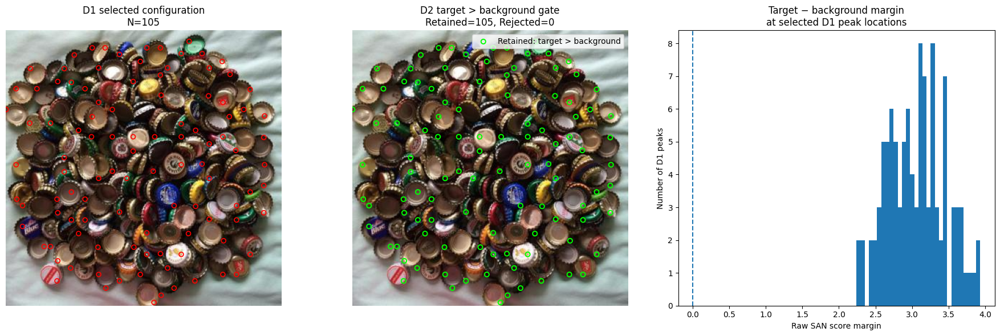

In [66]:
# ============================================================
# Step 11E.2 — Visualise D2 retained/rejected peaks
# ============================================================

import matplotlib.pyplot as plt


fig, axes = plt.subplots(
    1,
    3,
    figsize=(18, 6),
)


# ------------------------------------------------------------
# 1. Selected D1 reference points
# ------------------------------------------------------------

axes[0].imshow(
    d2_image
)

if len(d2_d1_points_xy) > 0:

    axes[0].scatter(
        d2_d1_points_xy[:, 0],
        d2_d1_points_xy[:, 1],
        s=32,
        facecolors="none",
        edgecolors="red",
        linewidths=1.2,
    )

axes[0].set_title(
    f"D1 selected configuration\n"
    f"N={d2_n_d1}"
)

axes[0].axis("off")


# ------------------------------------------------------------
# 2. D2 retained/rejected points
# ------------------------------------------------------------

axes[1].imshow(
    d2_image
)

if len(d2_points_xy) > 0:

    axes[1].scatter(
        d2_points_xy[:, 0],
        d2_points_xy[:, 1],
        s=34,
        facecolors="none",
        edgecolors="lime",
        linewidths=1.4,
        label="Retained: target > background",
    )

if len(d2_rejected_points_xy) > 0:

    axes[1].scatter(
        d2_rejected_points_xy[:, 0],
        d2_rejected_points_xy[:, 1],
        s=34,
        marker="x",
        c="magenta",
        linewidths=1.3,
        label="Rejected: target <= background",
    )

axes[1].set_title(
    f"D2 target > background gate\n"
    f"Retained={d2_n_retained}, "
    f"Rejected={d2_n_rejected}"
)

axes[1].axis("off")

axes[1].legend(
    loc="upper right"
)


# ------------------------------------------------------------
# 3. Raw SAN target-background margin
# ------------------------------------------------------------

axes[2].hist(
    d2_peak_margin,
    bins=30,
)

axes[2].axvline(
    0.0,
    linestyle="--",
    linewidth=1.5,
)

axes[2].set_title(
    "Target − background margin\n"
    "at selected D1 peak locations"
)

axes[2].set_xlabel(
    "Raw SAN score margin"
)

axes[2].set_ylabel(
    "Number of D1 peaks"
)


plt.tight_layout()
plt.show()

In [67]:
# ============================================================
# Step 11E.3 — D2 gate-effect check on dev100
#
# Use the selected D1 configuration only:
#   min_distance_frac = 0.020
#   score_threshold   = 0.30
#
# Question:
# How often does the condition target_score > background_score
# actually remove D1 reference points across dev100?
# ============================================================

import time
import numpy as np
import pandas as pd

from tqdm.auto import tqdm


D2_MIN_DISTANCE_FRAC = 0.020
D2_SCORE_THRESHOLD = 0.30


d2_gate_rows = []

start_time = time.perf_counter()


for _, row in tqdm(
    fsc147_dev_100_df.iterrows(),
    total=len(fsc147_dev_100_df),
    desc="Checking D2 gate on dev100",
):

    # --------------------------------------------------------
    # Metadata
    # --------------------------------------------------------

    image_id = row["image_id"]
    category = row["category"]
    gt_count = int(row["gt_count"])
    density_stratum = row["density_stratum"]

    # --------------------------------------------------------
    # Load cached SAN scores
    # --------------------------------------------------------

    cached = load_san_cache(
        image_id
    )

    target_score = np.asarray(
        cached["target_score"],
        dtype=np.float32,
    )

    background_score = np.asarray(
        cached["background_score"],
        dtype=np.float32,
    )

    assert (
        target_score.shape
        == background_score.shape
    )

    # --------------------------------------------------------
    # Recreate selected D1 peaks
    # --------------------------------------------------------

    target_score_norm = (
        minmax_normalise_score_map(
            target_score
        )
    )

    (
        d1_points_xy,
        d1_points_yx,
        min_distance_px,
    ) = extract_reference_points(
        target_score_norm,
        min_distance_frac=
            D2_MIN_DISTANCE_FRAC,
        score_threshold=
            D2_SCORE_THRESHOLD,
        valid_mask=None,
    )

    n_d1 = len(
        d1_points_xy
    )

    # --------------------------------------------------------
    # Apply D2 gate at D1 peak locations
    # --------------------------------------------------------

    if n_d1 > 0:

        peak_y = d1_points_yx[:, 0]
        peak_x = d1_points_yx[:, 1]

        peak_target = target_score[
            peak_y,
            peak_x
        ]

        peak_background = background_score[
            peak_y,
            peak_x
        ]

        margins = (
            peak_target
            - peak_background
        )

        keep_mask = (
            margins > 0
        )

        n_retained = int(
            keep_mask.sum()
        )

        n_rejected = int(
            (~keep_mask).sum()
        )

        min_margin = float(
            margins.min()
        )

        median_margin = float(
            np.median(
                margins
            )
        )

        mean_margin = float(
            margins.mean()
        )

    else:

        n_retained = 0
        n_rejected = 0

        min_margin = np.nan
        median_margin = np.nan
        mean_margin = np.nan

    retention_rate = (
        n_retained / n_d1
        if n_d1 > 0
        else np.nan
    )

    d2_gate_rows.append(
        {
            "image_id":
                image_id,

            "category":
                category,

            "density_stratum":
                density_stratum,

            "gt_count":
                gt_count,

            "min_distance_frac":
                D2_MIN_DISTANCE_FRAC,

            "min_distance_px":
                min_distance_px,

            "score_threshold":
                D2_SCORE_THRESHOLD,

            "d1_points":
                n_d1,

            "d2_retained":
                n_retained,

            "d2_rejected":
                n_rejected,

            "retention_rate":
                retention_rate,

            "min_margin":
                min_margin,

            "median_margin":
                median_margin,

            "mean_margin":
                mean_margin,
        }
    )


d2_gate_df = pd.DataFrame(
    d2_gate_rows
)


runtime = (
    time.perf_counter()
    - start_time
)


# ------------------------------------------------------------
# Validation
# ------------------------------------------------------------

assert (
    len(d2_gate_df)
    == len(fsc147_dev_100_df)
)

assert (
    d2_gate_df[
        "image_id"
    ].nunique()
    == 100
)


# ------------------------------------------------------------
# Overall summary
# ------------------------------------------------------------

total_d1_points = int(
    d2_gate_df[
        "d1_points"
    ].sum()
)

total_retained = int(
    d2_gate_df[
        "d2_retained"
    ].sum()
)

total_rejected = int(
    d2_gate_df[
        "d2_rejected"
    ].sum()
)

overall_retention = (
    total_retained
    / total_d1_points
    if total_d1_points > 0
    else np.nan
)

images_with_rejection = int(
    (
        d2_gate_df[
            "d2_rejected"
        ] > 0
    ).sum()
)


print(
    "D2 gate-effect check complete."
)

print(
    "Images:",
    len(d2_gate_df)
)

print(
    "Total selected D1 points:",
    total_d1_points
)

print(
    "Total D2 retained:",
    total_retained
)

print(
    "Total D2 rejected:",
    total_rejected
)

print(
    "Overall retention rate:",
    round(
        overall_retention,
        4,
    )
)

print(
    "Images with >=1 rejected point:",
    images_with_rejection,
)

print(
    f"Runtime: {runtime:.2f} s"
)


display(
    d2_gate_df[
        [
            "image_id",
            "density_stratum",
            "gt_count",
            "d1_points",
            "d2_retained",
            "d2_rejected",
            "retention_rate",
            "min_margin",
            "median_margin",
        ]
    ].head(20)
)

Checking D2 gate on dev100:   0%|          | 0/100 [00:00<?, ?it/s]

D2 gate-effect check complete.
Images: 100
Total selected D1 points: 7652
Total D2 retained: 7518
Total D2 rejected: 134
Overall retention rate: 0.9825
Images with >=1 rejected point: 3
Runtime: 1.21 s


,image_id,density_stratum,gt_count,d1_points,d2_retained,d2_rejected,retention_rate,min_margin,median_margin
0,3873.jpg,S1_0_20,7,56,56,0,1.0,4.034429,5.767495
1,1964.jpg,S1_0_20,8,35,35,0,1.0,2.256126,5.347786
2,774.jpg,S1_0_20,8,57,57,0,1.0,1.858387,2.074570
3,2304.jpg,S1_0_20,9,30,30,0,1.0,0.326425,0.974813
4,3573.jpg,S1_0_20,9,52,52,0,1.0,1.417309,3.993142
5,3661.jpg,S1_0_20,9,31,31,0,1.0,3.443371,3.687824
6,5211.jpg,S1_0_20,9,96,96,0,1.0,1.259428,1.321636
7,5220.jpg,S1_0_20,9,39,39,0,1.0,0.759593,1.058593
8,623.jpg,S1_0_20,9,7,7,0,1.0,2.150854,2.298339
9,737.jpg,S1_0_20,9,90,90,0,1.0,0.165668,0.463611


In [68]:
# ============================================================
# Step 11E.4 — D2 gate effect by density stratum
# ============================================================

d2_density_gate_summary = (
    d2_gate_df
    .groupby(
        "density_stratum",
        as_index=False,
    )
    .agg(
        n_images=("image_id", "count"),

        total_d1_points=
            ("d1_points", "sum"),

        total_retained=
            ("d2_retained", "sum"),

        total_rejected=
            ("d2_rejected", "sum"),

        mean_retention_rate=
            ("retention_rate", "mean"),

        images_with_rejection=
            (
                "d2_rejected",
                lambda x: int(
                    (x > 0).sum()
                ),
            ),

        min_margin_overall=
            ("min_margin", "min"),

        median_margin=
            ("median_margin", "median"),
    )
)

display(
    d2_density_gate_summary.round(4)
)

,density_stratum,n_images,total_d1_points,total_retained,total_rejected,mean_retention_rate,images_with_rejection,min_margin_overall,median_margin
0,S1_0_20,20,1082,1082,0,1.0000,0,0.1657,2.1035
1,S2_20_40,20,1233,1233,0,1.0000,0,0.6511,3.6322
2,S3_40_60,20,1390,1390,0,1.0000,0,0.3094,2.8102
3,S4_60_80,20,1663,1623,40,0.9535,1,-0.1158,2.3803
4,S5_80_95,10,1143,1110,33,0.9000,1,-0.3726,2.8180
5,S6_95_100,10,1141,1080,61,0.9000,1,-0.1450,1.4146


In [69]:
# ============================================================
# Step 11E.5 — Controlled D2 evaluation on dev100
#
# D1 selected configuration is fixed:
#   min_distance_frac = 0.020
#   score_threshold   = 0.30
#
# Only change:
#   retain peak if raw SAN target_score > background_score
# ============================================================

import time
import numpy as np
import pandas as pd

from tqdm.auto import tqdm


D2_MIN_DISTANCE_FRAC = 0.020
D2_SCORE_THRESHOLD = 0.30


d2_match_rows = []

start_time = time.perf_counter()


for _, row in tqdm(
    fsc147_dev_100_df.iterrows(),
    total=len(fsc147_dev_100_df),
    desc="Evaluating D2 on dev100",
):

    # --------------------------------------------------------
    # Metadata
    # --------------------------------------------------------

    image_id = row["image_id"]
    category = row["category"]
    dataset_index = int(row["dataset_index"])
    gt_count = int(row["gt_count"])
    density_stratum = row["density_stratum"]

    # --------------------------------------------------------
    # Load sample and GT points
    # --------------------------------------------------------

    sample = fsc147_val_dataset[
        dataset_index
    ]

    gt_xy = np.asarray(
        get_gt_points(
            sample,
            category,
        ),
        dtype=np.float32,
    ).reshape(-1, 2)

    assert len(gt_xy) == gt_count

    width = int(sample["width"])
    height = int(sample["height"])
    short_side = min(width, height)

    # --------------------------------------------------------
    # Load cached SAN scores
    # --------------------------------------------------------

    cached = load_san_cache(
        image_id
    )

    target_score = np.asarray(
        cached["target_score"],
        dtype=np.float32,
    )

    background_score = np.asarray(
        cached["background_score"],
        dtype=np.float32,
    )

    assert (
        target_score.shape
        == background_score.shape
    )

    # --------------------------------------------------------
    # Generate D1 peaks using frozen selected configuration
    # --------------------------------------------------------

    target_score_norm = (
        minmax_normalise_score_map(
            target_score
        )
    )

    (
        d1_points_xy,
        d1_points_yx,
        min_distance_px,
    ) = extract_reference_points(
        target_score_norm,
        min_distance_frac=
            D2_MIN_DISTANCE_FRAC,
        score_threshold=
            D2_SCORE_THRESHOLD,
        valid_mask=None,
    )

    n_d1 = len(
        d1_points_xy
    )

    # --------------------------------------------------------
    # D2 gate: raw target > raw background
    # --------------------------------------------------------

    if n_d1 > 0:

        peak_y = d1_points_yx[:, 0]
        peak_x = d1_points_yx[:, 1]

        keep_mask = (
            target_score[
                peak_y,
                peak_x,
            ]
            >
            background_score[
                peak_y,
                peak_x,
            ]
        )

        d2_points_xy = (
            d1_points_xy[
                keep_mask
            ]
        )

    else:

        d2_points_xy = np.empty(
            (0, 2),
            dtype=np.int64,
        )

    n_d2 = len(
        d2_points_xy
    )

    # --------------------------------------------------------
    # Evaluate at same frozen radii as D1
    # --------------------------------------------------------

    for radius_frac in D1_MATCH_RADII_FRACS:

        radius_px = max(
            1,
            int(
                round(
                    radius_frac
                    * short_side
                )
            ),
        )

        result = (
            match_points_one_to_one_efficient(
                pred_xy=d2_points_xy,
                gt_xy=gt_xy,
                radius_px=radius_px,
            )
        )

        tp = int(result["tp"])
        fp = int(result["fp"])
        fn = int(result["fn"])

        precision = (
            tp / (tp + fp)
            if (tp + fp) > 0
            else 0.0
        )

        recall = (
            tp / (tp + fn)
            if (tp + fn) > 0
            else 0.0
        )

        f1 = (
            2.0
            * precision
            * recall
            / (precision + recall)
            if (precision + recall) > 0
            else 0.0
        )

        distances = np.asarray(
            result["distances"],
            dtype=np.float32,
        )

        if len(distances) > 0:

            mean_dist_px = float(
                np.mean(distances)
            )

            median_dist_px = float(
                np.median(distances)
            )

        else:

            mean_dist_px = np.nan
            median_dist_px = np.nan

        d2_match_rows.append(
            {
                "image_id":
                    image_id,

                "category":
                    category,

                "density_stratum":
                    density_stratum,

                "gt_count":
                    gt_count,

                "d1_points":
                    n_d1,

                "d2_points":
                    n_d2,

                "points_rejected":
                    n_d1 - n_d2,

                "radius_frac":
                    radius_frac,

                "radius_px":
                    radius_px,

                "tp":
                    tp,

                "fp":
                    fp,

                "fn":
                    fn,

                "precision":
                    precision,

                "recall":
                    recall,

                "f1":
                    f1,

                "mean_match_dist_px":
                    mean_dist_px,

                "median_match_dist_px":
                    median_dist_px,
            }
        )


d2_match_results_df = pd.DataFrame(
    d2_match_rows
)


runtime = (
    time.perf_counter()
    - start_time
)


# ------------------------------------------------------------
# Validation
# ------------------------------------------------------------

expected_rows = (
    100
    * len(D1_MATCH_RADII_FRACS)
)

assert (
    len(d2_match_results_df)
    == expected_rows
)


print(
    "D2 evaluation rows:",
    len(d2_match_results_df)
)

print(
    "Expected rows:",
    expected_rows
)

print(
    f"Runtime: {runtime:.2f} s"
)

display(
    d2_match_results_df.head(20).round(4)
)

Evaluating D2 on dev100:   0%|          | 0/100 [00:00<?, ?it/s]

D2 evaluation rows: 400
Expected rows: 400
Runtime: 1.58 s


,image_id,category,density_stratum,gt_count,d1_points,d2_points,points_rejected,radius_frac,radius_px,tp,fp,fn,precision,recall,f1,mean_match_dist_px,median_match_dist_px
0,3873.jpg,shallots,S1_0_20,7,56,56,0,0.01,4,0,56,7,0.0000,0.0000,0.0000,NaN,NaN
1,3873.jpg,shallots,S1_0_20,7,56,56,0,0.02,8,1,55,6,0.0179,0.1429,0.0317,7.7841,7.7841
2,3873.jpg,shallots,S1_0_20,7,56,56,0,0.03,12,4,52,3,0.0714,0.5714,0.1270,10.1656,10.5070
3,3873.jpg,shallots,S1_0_20,7,56,56,0,0.05,19,4,52,3,0.0714,0.5714,0.1270,10.1656,10.5070
4,1964.jpg,bottle caps,S1_0_20,8,35,35,0,0.01,4,0,35,8,0.0000,0.0000,0.0000,NaN,NaN
5,1964.jpg,bottle caps,S1_0_20,8,35,35,0,0.02,8,1,34,7,0.0286,0.1250,0.0465,7.8357,7.8357
6,1964.jpg,bottle caps,S1_0_20,8,35,35,0,0.03,12,1,34,7,0.0286,0.1250,0.0465,7.8357,7.8357
7,1964.jpg,bottle caps,S1_0_20,8,35,35,0,0.05,19,6,29,2,0.1714,0.7500,0.2791,13.5801,14.2398
8,774.jpg,books,S1_0_20,8,57,57,0,0.01,4,1,56,7,0.0175,0.1250,0.0308,3.7846,3.7846
9,774.jpg,books,S1_0_20,8,57,57,0,0.02,8,2,55,6,0.0351,0.2500,0.0615,5.6341,5.6341


In [70]:
# ============================================================
# Step 11E.6 — Controlled D1 vs D2 comparison
# ============================================================

comparison_rows = []


for radius_frac in D1_MATCH_RADII_FRACS:

    # --------------------------------------------------------
    # D1 selected configuration
    # --------------------------------------------------------

    d1_group = d1_match_results_df[
        np.isclose(
            d1_match_results_df[
                "min_distance_frac"
            ],
            D2_MIN_DISTANCE_FRAC,
        )
        &
        np.isclose(
            d1_match_results_df[
                "score_threshold"
            ],
            D2_SCORE_THRESHOLD,
        )
        &
        np.isclose(
            d1_match_results_df[
                "radius_frac"
            ],
            radius_frac,
        )
    ]

    # --------------------------------------------------------
    # D2
    # --------------------------------------------------------

    d2_group = d2_match_results_df[
        np.isclose(
            d2_match_results_df[
                "radius_frac"
            ],
            radius_frac,
        )
    ]


    def summarise_point_quality(group):

        total_tp = int(
            group["tp"].sum()
        )

        total_fp = int(
            group["fp"].sum()
        )

        total_fn = int(
            group["fn"].sum()
        )

        macro_p = float(
            group["precision"].mean()
        )

        macro_r = float(
            group["recall"].mean()
        )

        macro_f1 = float(
            group["f1"].mean()
        )

        micro_p = (
            total_tp
            / (total_tp + total_fp)
            if (total_tp + total_fp) > 0
            else 0.0
        )

        micro_r = (
            total_tp
            / (total_tp + total_fn)
            if (total_tp + total_fn) > 0
            else 0.0
        )

        micro_f1 = (
            2.0
            * micro_p
            * micro_r
            / (micro_p + micro_r)
            if (micro_p + micro_r) > 0
            else 0.0
        )

        return {
            "macro_p": macro_p,
            "macro_r": macro_r,
            "macro_f1": macro_f1,
            "micro_p": micro_p,
            "micro_r": micro_r,
            "micro_f1": micro_f1,
            "tp": total_tp,
            "fp": total_fp,
            "fn": total_fn,
        }


    d1_summary = (
        summarise_point_quality(
            d1_group
        )
    )

    d2_summary = (
        summarise_point_quality(
            d2_group
        )
    )


    comparison_rows.append(
        {
            "radius_frac":
                radius_frac,

            "D1_macro_P":
                d1_summary[
                    "macro_p"
                ],

            "D2_macro_P":
                d2_summary[
                    "macro_p"
                ],

            "delta_macro_P":
                d2_summary[
                    "macro_p"
                ]
                -
                d1_summary[
                    "macro_p"
                ],

            "D1_macro_R":
                d1_summary[
                    "macro_r"
                ],

            "D2_macro_R":
                d2_summary[
                    "macro_r"
                ],

            "delta_macro_R":
                d2_summary[
                    "macro_r"
                ]
                -
                d1_summary[
                    "macro_r"
                ],

            "D1_macro_F1":
                d1_summary[
                    "macro_f1"
                ],

            "D2_macro_F1":
                d2_summary[
                    "macro_f1"
                ],

            "delta_macro_F1":
                d2_summary[
                    "macro_f1"
                ]
                -
                d1_summary[
                    "macro_f1"
                ],

            "D1_micro_F1":
                d1_summary[
                    "micro_f1"
                ],

            "D2_micro_F1":
                d2_summary[
                    "micro_f1"
                ],

            "delta_micro_F1":
                d2_summary[
                    "micro_f1"
                ]
                -
                d1_summary[
                    "micro_f1"
                ],
        }
    )


d1_d2_comparison = pd.DataFrame(
    comparison_rows
)


display(
    d1_d2_comparison.round(4)
)

,radius_frac,D1_macro_P,D2_macro_P,delta_macro_P,D1_macro_R,D2_macro_R,delta_macro_R,D1_macro_F1,D2_macro_F1,delta_macro_F1,D1_micro_F1,D2_micro_F1,delta_micro_F1
0,0.01,0.1418,0.1402,-0.0016,0.1197,0.1190,-0.0007,0.1079,0.1069,-0.0009,0.0856,0.0855,-0.0000
1,0.02,0.2909,0.2822,-0.0087,0.3067,0.3035,-0.0032,0.2491,0.2445,-0.0046,0.1896,0.1864,-0.0032
2,0.03,0.3770,0.3678,-0.0092,0.4603,0.4548,-0.0055,0.3452,0.3380,-0.0072,0.2729,0.2686,-0.0043
3,0.05,0.4813,0.4654,-0.0159,0.6928,0.6826,-0.0102,0.4697,0.4572,-0.0125,0.3658,0.3588,-0.0070


In [71]:
# ============================================================
# Step 11E.7 — Per-image effect on the three affected images
# ============================================================

affected_images = (
    d2_gate_df.loc[
        d2_gate_df[
            "d2_rejected"
        ] > 0,
        "image_id",
    ]
    .tolist()
)


print(
    "Affected images:",
    affected_images
)


# ------------------------------------------------------------
# Primary radius only: 3%
# ------------------------------------------------------------

d1_affected = (
    d1_match_results_df[
        d1_match_results_df[
            "image_id"
        ].isin(
            affected_images
        )
        &
        np.isclose(
            d1_match_results_df[
                "min_distance_frac"
            ],
            D2_MIN_DISTANCE_FRAC,
        )
        &
        np.isclose(
            d1_match_results_df[
                "score_threshold"
            ],
            D2_SCORE_THRESHOLD,
        )
        &
        np.isclose(
            d1_match_results_df[
                "radius_frac"
            ],
            0.03,
        )
    ][
        [
            "image_id",
            "density_stratum",
            "gt_count",
            "pred_count",
            "tp",
            "fp",
            "fn",
            "precision",
            "recall",
            "f1",
        ]
    ]
    .copy()
)


d1_affected = d1_affected.rename(
    columns={
        "pred_count":
            "D1_points",

        "tp":
            "D1_TP",

        "fp":
            "D1_FP",

        "fn":
            "D1_FN",

        "precision":
            "D1_P",

        "recall":
            "D1_R",

        "f1":
            "D1_F1",
    }
)


d2_affected = (
    d2_match_results_df[
        d2_match_results_df[
            "image_id"
        ].isin(
            affected_images
        )
        &
        np.isclose(
            d2_match_results_df[
                "radius_frac"
            ],
            0.03,
        )
    ][
        [
            "image_id",
            "d2_points",
            "points_rejected",
            "tp",
            "fp",
            "fn",
            "precision",
            "recall",
            "f1",
        ]
    ]
    .copy()
)


d2_affected = d2_affected.rename(
    columns={
        "d2_points":
            "D2_points",

        "tp":
            "D2_TP",

        "fp":
            "D2_FP",

        "fn":
            "D2_FN",

        "precision":
            "D2_P",

        "recall":
            "D2_R",

        "f1":
            "D2_F1",
    }
)


affected_comparison = (
    d1_affected
    .merge(
        d2_affected,
        on="image_id",
        how="inner",
    )
)


affected_comparison[
    "delta_F1"
] = (
    affected_comparison[
        "D2_F1"
    ]
    -
    affected_comparison[
        "D1_F1"
    ]
)


affected_comparison[
    "delta_TP"
] = (
    affected_comparison[
        "D2_TP"
    ]
    -
    affected_comparison[
        "D1_TP"
    ]
)


affected_comparison[
    "delta_FP"
] = (
    affected_comparison[
        "D2_FP"
    ]
    -
    affected_comparison[
        "D1_FP"
    ]
)


display(
    affected_comparison.round(4)
)

Affected images: ['5739.jpg', '5740.jpg', '3426.jpg']


,image_id,density_stratum,gt_count,D1_points,D1_TP,D1_FP,D1_FN,D1_P,D1_R,D1_F1,...,points_rejected,D2_TP,D2_FP,D2_FN,D2_P,D2_R,D2_F1,delta_F1,delta_TP,delta_FP
0,5739.jpg,S4_60_80,53,43,14,29,39,0.3256,0.2642,0.2917,...,40,1,2,52,0.3333,0.0189,0.0357,-0.2560,-13,-27
1,5740.jpg,S5_80_95,87,33,16,17,71,0.4848,0.1839,0.2667,...,33,0,0,87,0.0000,0.0000,0.0000,-0.2667,-16,-17
2,3426.jpg,S6_95_100,219,61,27,34,192,0.4426,0.1233,0.1929,...,61,0,0,219,0.0000,0.0000,0.0000,-0.1929,-27,-34


### **D2 Summary — Target > background filtering**

D2 applied an additional semantic gate to the selected D1 reference
points, retaining only peaks satisfying the raw SAN condition
`target_score > background_score`.

Key findings:

- Across dev100, D1 generated 7,652 selected reference points.
- D2 retained 7,518 points (98.25%) and rejected only 134 points.
- Only 3 of 100 images contained any rejected points, indicating that
  the explicit target-vs-background condition is largely redundant for
  D1 local maxima.

At the primary 3% matching radius:

- D1 macro Precision = 0.3770
- D2 macro Precision = 0.3678
- D1 macro Recall = 0.4603
- D2 macro Recall = 0.4548
- D1 macro F1 = 0.3452
- D2 macro F1 = 0.3380

The D2 gate therefore reduced macro F1 by 0.0072.

Inspection of the three affected images showed that the gate removed
many useful reference points as well as false positives. In two cases,
all D1 points were removed, reducing point-level F1 to zero.

Overall, explicit `target_score > background_score` filtering provides
no improvement over D1 and slightly degrades reference-point quality.
**D1 is therefore retained over D2.**

# **D3: local maxima of the continuous target–background margin**

In [72]:
# ============================================================
# Step 11F.1 — D3 single-image sanity check
#
# D3:
#   margin = raw target_score - raw background_score
#
# Local maxima are extracted directly from the margin map.
# ============================================================

import numpy as np
from PIL import Image


# ------------------------------------------------------------
# Fixed sanity image
# ------------------------------------------------------------

D3_TEST_IMAGE_ID = "1935.jpg"


# ------------------------------------------------------------
# 1. Recover correct metadata explicitly
# ------------------------------------------------------------

d3_rows = fsc147_dev_100_df[
    fsc147_dev_100_df["image_id"]
    == D3_TEST_IMAGE_ID
]

assert len(d3_rows) == 1

d3_row = d3_rows.iloc[0]

d3_dataset_index = int(
    d3_row["dataset_index"]
)

d3_category = d3_row["category"]

d3_gt_count = int(
    d3_row["gt_count"]
)

d3_density_stratum = (
    d3_row["density_stratum"]
)


# ------------------------------------------------------------
# 2. Reload sample and GT points
# ------------------------------------------------------------

d3_sample = fsc147_val_dataset[
    d3_dataset_index
]

d3_gt_points_xy = np.asarray(
    get_gt_points(
        d3_sample,
        d3_category,
    ),
    dtype=np.float32,
).reshape(-1, 2)

assert (
    len(d3_gt_points_xy)
    == d3_gt_count
)


# ------------------------------------------------------------
# 3. Reload image
# ------------------------------------------------------------

d3_image_path = (
    FSC147_IMAGE_DIR
    / D3_TEST_IMAGE_ID
)

d3_image = Image.open(
    d3_image_path
).convert("RGB")

d3_W, d3_H = d3_image.size


# ------------------------------------------------------------
# 4. Reload cached SAN target/background scores
# ------------------------------------------------------------

d3_cached = load_san_cache(
    D3_TEST_IMAGE_ID
)

d3_target_score = np.asarray(
    d3_cached["target_score"],
    dtype=np.float32,
)

d3_background_score = np.asarray(
    d3_cached["background_score"],
    dtype=np.float32,
)

assert (
    d3_target_score.shape
    == d3_background_score.shape
)


# ------------------------------------------------------------
# 5. Build RAW target-background margin
# ------------------------------------------------------------

d3_margin_raw = (
    d3_target_score
    - d3_background_score
)


# ------------------------------------------------------------
# 6. Min-max normalise the MARGIN MAP itself
#
# Important:
# target and background are NOT independently normalised.
# The subtraction is performed first.
# ------------------------------------------------------------

d3_margin_norm = (
    minmax_normalise_score_map(
        d3_margin_raw
    )
)


# ------------------------------------------------------------
# 7. Initial D3 sanity settings
#
# Use the selected D1 parameters only for this sanity check.
# These are NOT yet selected D3 parameters.
# ------------------------------------------------------------

D3_SANITY_MIN_DISTANCE_FRAC = 0.020
D3_SANITY_SCORE_THRESHOLD = 0.30


(
    d3_points_xy,
    d3_points_yx,
    d3_min_distance_px,
) = extract_reference_points(
    d3_margin_norm,
    min_distance_frac=
        D3_SANITY_MIN_DISTANCE_FRAC,
    score_threshold=
        D3_SANITY_SCORE_THRESHOLD,
    valid_mask=None,
)


# ------------------------------------------------------------
# 8. Summary
# ------------------------------------------------------------

print(
    "Image:",
    D3_TEST_IMAGE_ID,
)

print(
    "Category:",
    d3_category,
)

print(
    "Density stratum:",
    d3_density_stratum,
)

print(
    "GT count:",
    d3_gt_count,
)

print(
    "Image size:",
    f"{d3_W} x {d3_H}",
)

print(
    "SAN map shape:",
    d3_margin_raw.shape,
)


print(
    "\nRaw SAN score ranges:"
)

print(
    "  target     :",
    float(d3_target_score.min()),
    "to",
    float(d3_target_score.max()),
)

print(
    "  background :",
    float(d3_background_score.min()),
    "to",
    float(d3_background_score.max()),
)

print(
    "  margin     :",
    float(d3_margin_raw.min()),
    "to",
    float(d3_margin_raw.max()),
)


print(
    "\nD3 sanity configuration:"
)

print(
    "  min_distance_frac =",
    D3_SANITY_MIN_DISTANCE_FRAC,
)

print(
    "  min_distance_px   =",
    d3_min_distance_px,
)

print(
    "  score_threshold   =",
    D3_SANITY_SCORE_THRESHOLD,
)


print(
    "\nD3 predicted reference points:",
    len(d3_points_xy),
)

print(
    "D3 signed proxy-count error:",
    len(d3_points_xy)
    - d3_gt_count,
)

Image: 1935.jpg
Category: bottle caps
Density stratum: S5_80_95
GT count: 175
Image size: 384 x 384
SAN map shape: (384, 384)

Raw SAN score ranges:
  target     : 0.0019608577713370323 to 3.9382052421569824
  background : 0.0031506274826824665 to 0.05635276064276695
  margin     : -0.05283951386809349 to 3.933539628982544

D3 sanity configuration:
  min_distance_frac = 0.02
  min_distance_px   = 8
  score_threshold   = 0.3

D3 predicted reference points: 105
D3 signed proxy-count error: -70


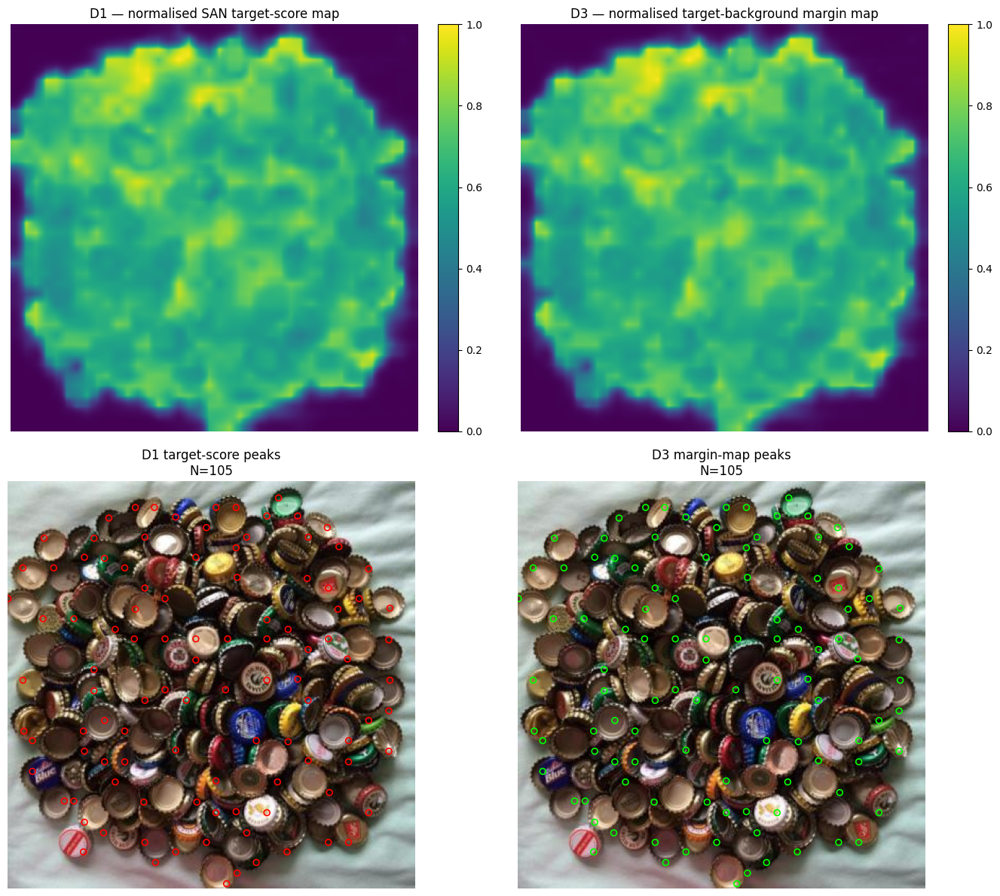

In [73]:
# ============================================================
# Step 11F.2 — Visual comparison:
# D1 target-score map vs D3 margin map
# ============================================================

import matplotlib.pyplot as plt


# ------------------------------------------------------------
# Recreate selected D1 points on same image for comparison
# ------------------------------------------------------------

d3_target_norm = (
    minmax_normalise_score_map(
        d3_target_score
    )
)

(
    d3_d1_points_xy,
    _,
    _,
) = extract_reference_points(
    d3_target_norm,
    min_distance_frac=0.020,
    score_threshold=0.30,
    valid_mask=None,
)


# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2,
    2,
    figsize=(14, 12),
)


# D1 continuous target map
im0 = axes[0, 0].imshow(
    d3_target_norm,
    cmap="viridis",
)

axes[0, 0].set_title(
    "D1 — normalised SAN target-score map"
)

axes[0, 0].axis("off")

fig.colorbar(
    im0,
    ax=axes[0, 0],
    fraction=0.046,
    pad=0.04,
)


# D3 margin map
im1 = axes[0, 1].imshow(
    d3_margin_norm,
    cmap="viridis",
)

axes[0, 1].set_title(
    "D3 — normalised target-background margin map"
)

axes[0, 1].axis("off")

fig.colorbar(
    im1,
    ax=axes[0, 1],
    fraction=0.046,
    pad=0.04,
)


# D1 reference points
axes[1, 0].imshow(
    d3_image
)

if len(d3_d1_points_xy) > 0:

    axes[1, 0].scatter(
        d3_d1_points_xy[:, 0],
        d3_d1_points_xy[:, 1],
        s=32,
        facecolors="none",
        edgecolors="red",
        linewidths=1.2,
    )

axes[1, 0].set_title(
    f"D1 target-score peaks\n"
    f"N={len(d3_d1_points_xy)}"
)

axes[1, 0].axis("off")


# D3 reference points
axes[1, 1].imshow(
    d3_image
)

if len(d3_points_xy) > 0:

    axes[1, 1].scatter(
        d3_points_xy[:, 0],
        d3_points_xy[:, 1],
        s=32,
        facecolors="none",
        edgecolors="lime",
        linewidths=1.2,
    )

axes[1, 1].set_title(
    f"D3 margin-map peaks\n"
    f"N={len(d3_points_xy)}"
)

axes[1, 1].axis("off")


plt.tight_layout()
plt.show()

In [74]:
# ============================================================
# Step 11F.3 — Generate D3 reference points on dev100
#
# D3 semantic surface:
#     margin_raw = target_score - background_score
#     margin_norm = minmax(margin_raw)
#
# Same parameter grid as D1.
# ============================================================

import time
import numpy as np
import pandas as pd

from tqdm.auto import tqdm


d3_prediction_rows = []

start_time = time.perf_counter()


for _, row in tqdm(
    fsc147_dev_100_df.iterrows(),
    total=len(fsc147_dev_100_df),
    desc="Generating D3 dev100 predictions",
):

    # --------------------------------------------------------
    # Metadata
    # --------------------------------------------------------

    image_id = row["image_id"]
    category = row["category"]

    dataset_index = int(
        row["dataset_index"]
    )

    gt_count = int(
        row["gt_count"]
    )

    density_stratum = row[
        "density_stratum"
    ]

    sample = fsc147_val_dataset[
        dataset_index
    ]

    width = int(
        sample["width"]
    )

    height = int(
        sample["height"]
    )

    short_side = min(
        width,
        height,
    )


    # --------------------------------------------------------
    # GT points
    # --------------------------------------------------------

    gt_points_xy = np.asarray(
        get_gt_points(
            sample,
            category,
        ),
        dtype=np.float32,
    ).reshape(-1, 2)

    assert (
        len(gt_points_xy)
        == gt_count
    )


    # --------------------------------------------------------
    # Load cached SAN scores
    # --------------------------------------------------------

    cached = load_san_cache(
        image_id
    )

    target_score = np.asarray(
        cached["target_score"],
        dtype=np.float32,
    )

    background_score = np.asarray(
        cached["background_score"],
        dtype=np.float32,
    )

    assert (
        target_score.shape
        == background_score.shape
    )


    # --------------------------------------------------------
    # D3 semantic surface
    # --------------------------------------------------------

    margin_raw = (
        target_score
        - background_score
    )

    margin_norm = (
        minmax_normalise_score_map(
            margin_raw
        )
    )


    # --------------------------------------------------------
    # Run same 20 configurations as D1
    # --------------------------------------------------------

    for min_distance_frac in (
        D1_MIN_DISTANCE_FRACS
    ):

        for score_threshold in (
            D1_SCORE_THRESHOLDS
        ):

            (
                points_xy,
                _,
                min_distance_px,
            ) = extract_reference_points(
                margin_norm,
                min_distance_frac=
                    min_distance_frac,
                score_threshold=
                    score_threshold,
                valid_mask=None,
            )

            pred_count = len(
                points_xy
            )

            d3_prediction_rows.append(
                {
                    "image_id":
                        image_id,

                    "dataset_index":
                        dataset_index,

                    "category":
                        category,

                    "density_stratum":
                        density_stratum,

                    "width":
                        width,

                    "height":
                        height,

                    "short_side":
                        short_side,

                    "gt_count":
                        gt_count,

                    "min_distance_frac":
                        min_distance_frac,

                    "min_distance_px":
                        min_distance_px,

                    "score_threshold":
                        score_threshold,

                    "pred_count":
                        pred_count,

                    "count_error":
                        pred_count
                        - gt_count,

                    "pred_points_xy":
                        points_xy,

                    "gt_points_xy":
                        gt_points_xy,
                }
            )


d3_predictions_df = pd.DataFrame(
    d3_prediction_rows
)


runtime = (
    time.perf_counter()
    - start_time
)


# ------------------------------------------------------------
# Validation
# ------------------------------------------------------------

expected_rows = (
    len(fsc147_dev_100_df)
    * len(D1_MIN_DISTANCE_FRACS)
    * len(D1_SCORE_THRESHOLDS)
)

assert (
    len(d3_predictions_df)
    == expected_rows
)

assert (
    d3_predictions_df[
        "image_id"
    ].nunique()
    == 100
)


print(
    "D3 prediction rows:",
    len(d3_predictions_df),
)

print(
    "Expected rows:",
    expected_rows,
)

print(
    f"Runtime: {runtime:.2f} s"
)

display(
    d3_predictions_df[
        [
            "image_id",
            "density_stratum",
            "gt_count",
            "min_distance_frac",
            "min_distance_px",
            "score_threshold",
            "pred_count",
            "count_error",
        ]
    ].head(20)
)

Generating D3 dev100 predictions:   0%|          | 0/100 [00:00<?, ?it/s]

D3 prediction rows: 2000
Expected rows: 2000
Runtime: 14.19 s


,image_id,density_stratum,gt_count,min_distance_frac,min_distance_px,score_threshold,pred_count,count_error
0,3873.jpg,S1_0_20,7,0.005,2,0.3,80,73
1,3873.jpg,S1_0_20,7,0.005,2,0.4,80,73
2,3873.jpg,S1_0_20,7,0.005,2,0.5,80,73
3,3873.jpg,S1_0_20,7,0.005,2,0.6,78,71
4,3873.jpg,S1_0_20,7,0.005,2,0.7,66,59
5,3873.jpg,S1_0_20,7,0.010,4,0.3,71,64
6,3873.jpg,S1_0_20,7,0.010,4,0.4,71,64
7,3873.jpg,S1_0_20,7,0.010,4,0.5,71,64
8,3873.jpg,S1_0_20,7,0.010,4,0.6,70,63
9,3873.jpg,S1_0_20,7,0.010,4,0.7,60,53


In [75]:
# ============================================================
# Step 11F.4 — Full D3 one-to-one matching on dev100
# ============================================================

d3_match_rows = []

start_time = time.perf_counter()


for _, row in tqdm(
    d3_predictions_df.iterrows(),
    total=len(d3_predictions_df),
    desc="D3 one-to-one matching",
):

    short_side = int(
        row["short_side"]
    )

    pred_xy = row[
        "pred_points_xy"
    ]

    gt_xy = row[
        "gt_points_xy"
    ]


    for radius_frac in (
        D1_MATCH_RADII_FRACS
    ):

        radius_px = max(
            1,
            int(
                round(
                    radius_frac
                    * short_side
                )
            ),
        )

        result = (
            match_points_one_to_one_efficient(
                pred_xy=pred_xy,
                gt_xy=gt_xy,
                radius_px=radius_px,
            )
        )


        tp = int(
            result["tp"]
        )

        fp = int(
            result["fp"]
        )

        fn = int(
            result["fn"]
        )


        # ----------------------------------------------------
        # Precision / Recall / F1
        # ----------------------------------------------------

        precision = (
            tp / (tp + fp)
            if (tp + fp) > 0
            else 0.0
        )

        recall = (
            tp / (tp + fn)
            if (tp + fn) > 0
            else 0.0
        )

        f1 = (
            2.0
            * precision
            * recall
            / (
                precision
                + recall
            )
            if (
                precision
                + recall
            ) > 0
            else 0.0
        )


        # ----------------------------------------------------
        # Matched localisation distance
        # ----------------------------------------------------

        distances = np.asarray(
            result["distances"],
            dtype=np.float32,
        )

        if len(distances) > 0:

            mean_dist_px = float(
                np.mean(
                    distances
                )
            )

            median_dist_px = float(
                np.median(
                    distances
                )
            )

        else:

            mean_dist_px = np.nan
            median_dist_px = np.nan


        d3_match_rows.append(
            {
                "image_id":
                    row["image_id"],

                "category":
                    row["category"],

                "density_stratum":
                    row[
                        "density_stratum"
                    ],

                "gt_count":
                    int(
                        row["gt_count"]
                    ),

                "pred_count":
                    int(
                        row["pred_count"]
                    ),

                "count_error":
                    int(
                        row["count_error"]
                    ),

                "min_distance_frac":
                    row[
                        "min_distance_frac"
                    ],

                "min_distance_px":
                    row[
                        "min_distance_px"
                    ],

                "score_threshold":
                    row[
                        "score_threshold"
                    ],

                "radius_frac":
                    radius_frac,

                "radius_px":
                    radius_px,

                "tp":
                    tp,

                "fp":
                    fp,

                "fn":
                    fn,

                "precision":
                    precision,

                "recall":
                    recall,

                "f1":
                    f1,

                "mean_match_dist_px":
                    mean_dist_px,

                "median_match_dist_px":
                    median_dist_px,
            }
        )


d3_match_results_df = pd.DataFrame(
    d3_match_rows
)


runtime = (
    time.perf_counter()
    - start_time
)


expected_rows = (
    len(d3_predictions_df)
    * len(D1_MATCH_RADII_FRACS)
)

assert (
    len(d3_match_results_df)
    == expected_rows
)


print(
    "D3 matching rows:",
    len(d3_match_results_df),
)

print(
    "Expected rows:",
    expected_rows,
)

print(
    f"Runtime: {runtime:.2f} s"
)

display(
    d3_match_results_df.head(20).round(4)
)

D3 one-to-one matching:   0%|          | 0/2000 [00:00<?, ?it/s]

D3 matching rows: 8000
Expected rows: 8000
Runtime: 5.72 s


,image_id,category,density_stratum,gt_count,pred_count,count_error,min_distance_frac,min_distance_px,score_threshold,radius_frac,radius_px,tp,fp,fn,precision,recall,f1,mean_match_dist_px,median_match_dist_px
0,3873.jpg,shallots,S1_0_20,7,80,73,0.005,2,0.3,0.01,4,0,80,7,0.0000,0.0000,0.0000,NaN,NaN
1,3873.jpg,shallots,S1_0_20,7,80,73,0.005,2,0.3,0.02,8,1,79,6,0.0125,0.1429,0.0230,7.7841,7.7841
2,3873.jpg,shallots,S1_0_20,7,80,73,0.005,2,0.3,0.03,12,4,76,3,0.0500,0.5714,0.0920,10.1656,10.5070
3,3873.jpg,shallots,S1_0_20,7,80,73,0.005,2,0.3,0.05,19,4,76,3,0.0500,0.5714,0.0920,10.1656,10.5070
4,3873.jpg,shallots,S1_0_20,7,80,73,0.005,2,0.4,0.01,4,0,80,7,0.0000,0.0000,0.0000,NaN,NaN
5,3873.jpg,shallots,S1_0_20,7,80,73,0.005,2,0.4,0.02,8,1,79,6,0.0125,0.1429,0.0230,7.7841,7.7841
6,3873.jpg,shallots,S1_0_20,7,80,73,0.005,2,0.4,0.03,12,4,76,3,0.0500,0.5714,0.0920,10.1656,10.5070
7,3873.jpg,shallots,S1_0_20,7,80,73,0.005,2,0.4,0.05,19,4,76,3,0.0500,0.5714,0.0920,10.1656,10.5070
8,3873.jpg,shallots,S1_0_20,7,80,73,0.005,2,0.5,0.01,4,0,80,7,0.0000,0.0000,0.0000,NaN,NaN
9,3873.jpg,shallots,S1_0_20,7,80,73,0.005,2,0.5,0.02,8,1,79,6,0.0125,0.1429,0.0230,7.7841,7.7841


In [76]:
# ============================================================
# Step 11F.5 — Aggregate and rank D3 configurations
# ============================================================

d3_summary_rows = []


for (
    min_distance_frac,
    score_threshold,
    radius_frac,
), group in d3_match_results_df.groupby(
    [
        "min_distance_frac",
        "score_threshold",
        "radius_frac",
    ]
):

    # --------------------------------------------------------
    # Macro metrics
    # --------------------------------------------------------

    macro_precision = float(
        group["precision"].mean()
    )

    macro_recall = float(
        group["recall"].mean()
    )

    macro_f1 = float(
        group["f1"].mean()
    )


    # --------------------------------------------------------
    # Micro metrics
    # --------------------------------------------------------

    total_tp = int(
        group["tp"].sum()
    )

    total_fp = int(
        group["fp"].sum()
    )

    total_fn = int(
        group["fn"].sum()
    )

    micro_precision = (
        total_tp
        / (total_tp + total_fp)
        if (total_tp + total_fp) > 0
        else 0.0
    )

    micro_recall = (
        total_tp
        / (total_tp + total_fn)
        if (total_tp + total_fn) > 0
        else 0.0
    )

    micro_f1 = (
        2.0
        * micro_precision
        * micro_recall
        / (
            micro_precision
            + micro_recall
        )
        if (
            micro_precision
            + micro_recall
        ) > 0
        else 0.0
    )


    d3_summary_rows.append(
        {
            "min_distance_frac":
                min_distance_frac,

            "score_threshold":
                score_threshold,

            "radius_frac":
                radius_frac,

            "macro_precision":
                macro_precision,

            "macro_recall":
                macro_recall,

            "macro_f1":
                macro_f1,

            "micro_precision":
                micro_precision,

            "micro_recall":
                micro_recall,

            "micro_f1":
                micro_f1,

            "total_tp":
                total_tp,

            "total_fp":
                total_fp,

            "total_fn":
                total_fn,
        }
    )


d3_point_quality_long = pd.DataFrame(
    d3_summary_rows
)


# ------------------------------------------------------------
# Proxy-count metrics for each D3 configuration
# ------------------------------------------------------------

proxy_rows = []


for (
    min_distance_frac,
    score_threshold,
), group in d3_predictions_df.groupby(
    [
        "min_distance_frac",
        "score_threshold",
    ]
):

    errors = (
        group["pred_count"].to_numpy()
        -
        group["gt_count"].to_numpy()
    )

    proxy_rows.append(
        {
            "min_distance_frac":
                min_distance_frac,

            "score_threshold":
                score_threshold,

            "mean_signed_error":
                float(
                    np.mean(errors)
                ),

            "proxy_mae":
                float(
                    np.mean(
                        np.abs(errors)
                    )
                ),

            "proxy_rmse":
                float(
                    np.sqrt(
                        np.mean(
                            errors ** 2
                        )
                    )
                ),
        }
    )


d3_proxy_summary = pd.DataFrame(
    proxy_rows
)


# ------------------------------------------------------------
# Build 20-row comparison table
# ------------------------------------------------------------

d3_comparison = (
    d3_proxy_summary.copy()
)


for radius_frac in D1_MATCH_RADII_FRACS:

    radius_pct = int(
        round(
            radius_frac
            * 100
        )
    )

    radius_df = (
        d3_point_quality_long[
            np.isclose(
                d3_point_quality_long[
                    "radius_frac"
                ],
                radius_frac,
            )
        ][
            [
                "min_distance_frac",
                "score_threshold",
                "macro_precision",
                "macro_recall",
                "macro_f1",
                "micro_f1",
            ]
        ]
        .copy()
    )


    radius_df = radius_df.rename(
        columns={
            "macro_precision":
                f"macro_P@{radius_pct}%",

            "macro_recall":
                f"macro_R@{radius_pct}%",

            "macro_f1":
                f"macro_F1@{radius_pct}%",

            "micro_f1":
                f"micro_F1@{radius_pct}%",
        }
    )


    d3_comparison = (
        d3_comparison
        .merge(
            radius_df,
            on=[
                "min_distance_frac",
                "score_threshold",
            ],
            how="left",
        )
    )


# ------------------------------------------------------------
# Rank using same pre-defined criterion as D1
# ------------------------------------------------------------

d3_comparison = (
    d3_comparison
    .sort_values(
        [
            "macro_F1@3%",
            "macro_F1@2%",
            "macro_F1@5%",
        ],
        ascending=[
            False,
            False,
            False,
        ],
    )
    .reset_index(
        drop=True
    )
)


d3_comparison.insert(
    0,
    "rank",
    np.arange(
        1,
        len(d3_comparison) + 1,
    ),
)


print(
    "Number of D3 configurations:",
    len(d3_comparison),
)

print(
    "Primary ranking metric: macro F1 @ 3%"
)

display(
    d3_comparison.round(4)
)

Number of D3 configurations: 20
Primary ranking metric: macro F1 @ 3%


,rank,min_distance_frac,score_threshold,mean_signed_error,proxy_mae,proxy_rmse,macro_P@1%,macro_R@1%,macro_F1@1%,micro_F1@1%,...,macro_F1@2%,micro_F1@2%,macro_P@3%,macro_R@3%,macro_F1@3%,micro_F1@3%,macro_P@5%,macro_R@5%,macro_F1@5%,micro_F1@5%
0,1,0.020,0.3,-22.75,92.53,251.7520,0.1407,0.1202,0.1095,0.0873,...,0.2465,0.1862,0.3639,0.4546,0.3397,0.2688,0.4623,0.6792,0.4589,0.3589
1,2,0.020,0.4,-27.00,94.98,258.8913,0.1418,0.1161,0.1062,0.0773,...,0.2398,0.1691,0.3636,0.4437,0.3324,0.2489,0.4651,0.6670,0.4524,0.3376
2,3,0.010,0.3,10.35,111.79,252.7235,0.1286,0.1360,0.1081,0.0884,...,0.2463,0.1924,0.3242,0.5288,0.3313,0.2705,0.3986,0.7575,0.4298,0.3543
3,4,0.030,0.3,-41.72,84.10,255.3104,0.1407,0.1049,0.1040,0.0805,...,0.2372,0.1719,0.3812,0.3941,0.3309,0.2495,0.4999,0.5977,0.4597,0.3390
4,5,0.020,0.5,-31.63,96.55,265.7799,0.1423,0.1113,0.1029,0.0668,...,0.2333,0.1519,0.3641,0.4305,0.3248,0.2287,0.4677,0.6513,0.4443,0.3154
5,6,0.030,0.4,-44.44,85.92,260.2267,0.1418,0.1015,0.1011,0.0726,...,0.2311,0.1586,0.3808,0.3851,0.3240,0.2337,0.5019,0.5876,0.4529,0.3217
6,7,0.010,0.4,2.96,113.44,261.8403,0.1297,0.1306,0.1044,0.0759,...,0.2391,0.1713,0.3254,0.5143,0.3238,0.2469,0.4025,0.7406,0.4229,0.3282
7,8,0.005,0.3,30.74,127.40,257.5154,0.1235,0.1427,0.1070,0.0862,...,0.2402,0.1859,0.3044,0.5532,0.3210,0.2610,0.3686,0.7771,0.4089,0.3403
8,9,0.010,0.5,-4.50,114.04,269.6070,0.1312,0.1249,0.1012,0.0652,...,0.2325,0.1534,0.3265,0.4979,0.3162,0.2260,0.4067,0.7216,0.4157,0.3055
9,10,0.030,0.5,-47.78,87.72,265.5366,0.1426,0.0984,0.0990,0.0633,...,0.2250,0.1433,0.3792,0.3742,0.3160,0.2150,0.5033,0.5756,0.4450,0.3016


In [77]:
# ============================================================
# Step 11F.6 — Best D1 vs best D3 comparison
# ============================================================

d3_best = (
    d3_comparison.iloc[0]
)

D3_SELECTED_MIN_DISTANCE_FRAC = float(
    d3_best[
        "min_distance_frac"
    ]
)

D3_SELECTED_SCORE_THRESHOLD = float(
    d3_best[
        "score_threshold"
    ]
)


print(
    "Selected D3 configuration:"
)

print(
    "  min_distance_frac =",
    D3_SELECTED_MIN_DISTANCE_FRAC,
)

print(
    "  score_threshold   =",
    D3_SELECTED_SCORE_THRESHOLD,
)

print(
    "  macro F1 @ 3%     =",
    round(
        float(
            d3_best[
                "macro_F1@3%"
            ]
        ),
        4,
    ),
)


d1_vs_d3 = pd.DataFrame(
    [
        {
            "method":
                "D1_target_score",

            "min_distance_frac":
                0.020,

            "score_threshold":
                0.30,

            "macro_P@3%":
                0.3770,

            "macro_R@3%":
                0.4603,

            "macro_F1@3%":
                0.3452,
        },

        {
            "method":
                "D3_target_minus_background",

            "min_distance_frac":
                D3_SELECTED_MIN_DISTANCE_FRAC,

            "score_threshold":
                D3_SELECTED_SCORE_THRESHOLD,

            "macro_P@3%":
                float(
                    d3_best[
                        "macro_P@3%"
                    ]
                ),

            "macro_R@3%":
                float(
                    d3_best[
                        "macro_R@3%"
                    ]
                ),

            "macro_F1@3%":
                float(
                    d3_best[
                        "macro_F1@3%"
                    ]
                ),
        },
    ]
)


d1_vs_d3[
    "delta_F1_vs_D1"
] = (
    d1_vs_d3[
        "macro_F1@3%"
    ]
    -
    0.3452
)


display(
    d1_vs_d3.round(4)
)

Selected D3 configuration:
  min_distance_frac = 0.02
  score_threshold   = 0.3
  macro F1 @ 3%     = 0.3397


,method,min_distance_frac,score_threshold,macro_P@3%,macro_R@3%,macro_F1@3%,delta_F1_vs_D1
0,D1_target_score,0.02,0.3,0.3770,0.4603,0.3452,0.0000
1,D3_target_minus_background,0.02,0.3,0.3639,0.4546,0.3397,-0.0055


In [78]:
# ============================================================
# Step 11F.7 — Density-stratified evaluation of selected D3
# ============================================================

import numpy as np
import pandas as pd


# ------------------------------------------------------------
# Selected D3 configuration
# ------------------------------------------------------------

D3_SELECTED_MIN_DISTANCE_FRAC = 0.020
D3_SELECTED_SCORE_THRESHOLD = 0.30
D3_PRIMARY_RADIUS_FRAC = 0.03


# ------------------------------------------------------------
# Extract selected D3 rows at primary radius
# ------------------------------------------------------------

d3_selected = (
    d3_match_results_df[
        np.isclose(
            d3_match_results_df["min_distance_frac"],
            D3_SELECTED_MIN_DISTANCE_FRAC,
        )
        &
        np.isclose(
            d3_match_results_df["score_threshold"],
            D3_SELECTED_SCORE_THRESHOLD,
        )
        &
        np.isclose(
            d3_match_results_df["radius_frac"],
            D3_PRIMARY_RADIUS_FRAC,
        )
    ]
    .copy()
)


# ------------------------------------------------------------
# Sanity checks
# ------------------------------------------------------------

assert len(d3_selected) == 100

assert (
    d3_selected["image_id"].nunique()
    == 100
)

print("Selected D3 configuration:")
print(
    "  min_distance_frac =",
    D3_SELECTED_MIN_DISTANCE_FRAC,
)
print(
    "  score_threshold   =",
    D3_SELECTED_SCORE_THRESHOLD,
)
print(
    "  matching radius   =",
    D3_PRIMARY_RADIUS_FRAC,
)
print(
    "  images            =",
    len(d3_selected),
)


# ------------------------------------------------------------
# Density-stratified aggregation
# ------------------------------------------------------------

density_rows = []


for density_stratum, group in (
    d3_selected.groupby(
        "density_stratum"
    )
):

    # Basic counts
    n_images = len(group)

    total_gt = int(
        group["gt_count"].sum()
    )

    total_pred = int(
        group["pred_count"].sum()
    )

    mean_gt = float(
        group["gt_count"].mean()
    )

    mean_pred = float(
        group["pred_count"].mean()
    )


    # --------------------------------------------------------
    # Proxy-count behaviour
    # --------------------------------------------------------

    count_errors = (
        group["pred_count"].to_numpy()
        -
        group["gt_count"].to_numpy()
    )

    mean_signed_error = float(
        np.mean(
            count_errors
        )
    )

    proxy_mae = float(
        np.mean(
            np.abs(
                count_errors
            )
        )
    )

    proxy_rmse = float(
        np.sqrt(
            np.mean(
                count_errors ** 2
            )
        )
    )

    under_images = int(
        np.sum(
            count_errors < 0
        )
    )

    exact_images = int(
        np.sum(
            count_errors == 0
        )
    )

    over_images = int(
        np.sum(
            count_errors > 0
        )
    )


    # --------------------------------------------------------
    # Macro point-quality metrics
    # --------------------------------------------------------

    macro_precision = float(
        group["precision"].mean()
    )

    macro_recall = float(
        group["recall"].mean()
    )

    macro_f1 = float(
        group["f1"].mean()
    )


    # --------------------------------------------------------
    # Micro point-quality metrics
    # --------------------------------------------------------

    total_tp = int(
        group["tp"].sum()
    )

    total_fp = int(
        group["fp"].sum()
    )

    total_fn = int(
        group["fn"].sum()
    )

    micro_precision = (
        total_tp
        / (total_tp + total_fp)
        if (total_tp + total_fp) > 0
        else 0.0
    )

    micro_recall = (
        total_tp
        / (total_tp + total_fn)
        if (total_tp + total_fn) > 0
        else 0.0
    )

    micro_f1 = (
        2.0
        * micro_precision
        * micro_recall
        / (
            micro_precision
            + micro_recall
        )
        if (
            micro_precision
            + micro_recall
        ) > 0
        else 0.0
    )


    # --------------------------------------------------------
    # Localisation distance
    # --------------------------------------------------------

    valid_dist = (
        (group["tp"] > 0)
        &
        group[
            "mean_match_dist_px"
        ].notna()
    )

    if valid_dist.any():

        weighted_mean_dist_px = float(
            np.average(
                group.loc[
                    valid_dist,
                    "mean_match_dist_px",
                ],
                weights=group.loc[
                    valid_dist,
                    "tp",
                ],
            )
        )

        median_match_dist_px = float(
            group.loc[
                valid_dist,
                "median_match_dist_px",
            ].median()
        )

    else:

        weighted_mean_dist_px = np.nan
        median_match_dist_px = np.nan


    density_rows.append(
        {
            "density_stratum":
                density_stratum,

            "n_images":
                n_images,

            "gt_min":
                int(
                    group["gt_count"].min()
                ),

            "gt_max":
                int(
                    group["gt_count"].max()
                ),

            "total_gt":
                total_gt,

            "total_pred":
                total_pred,

            "mean_gt":
                mean_gt,

            "mean_pred":
                mean_pred,

            "mean_signed_error":
                mean_signed_error,

            "proxy_mae":
                proxy_mae,

            "proxy_rmse":
                proxy_rmse,

            "under_images":
                under_images,

            "exact_images":
                exact_images,

            "over_images":
                over_images,

            "total_tp":
                total_tp,

            "total_fp":
                total_fp,

            "total_fn":
                total_fn,

            "macro_precision":
                macro_precision,

            "macro_recall":
                macro_recall,

            "macro_f1":
                macro_f1,

            "micro_precision":
                micro_precision,

            "micro_recall":
                micro_recall,

            "micro_f1":
                micro_f1,

            "weighted_mean_dist_px":
                weighted_mean_dist_px,

            "median_match_dist_px":
                median_match_dist_px,
        }
    )


d3_density_summary = pd.DataFrame(
    density_rows
)


# ------------------------------------------------------------
# Sort S1 → S6
# ------------------------------------------------------------

def d3_density_order(label):

    label = str(label)

    try:
        return int(
            label.split("_")[0][1:]
        )

    except Exception:
        return 999


d3_density_summary["_order"] = (
    d3_density_summary[
        "density_stratum"
    ].map(
        d3_density_order
    )
)

d3_density_summary = (
    d3_density_summary
    .sort_values("_order")
    .drop(columns="_order")
    .reset_index(drop=True)
)


print(
    "\nD3 density-stratified results "
    "(primary radius = 3%)"
)

display(
    d3_density_summary.round(4)
)

Selected D3 configuration:
  min_distance_frac = 0.02
  score_threshold   = 0.3
  matching radius   = 0.03
  images            = 100

D3 density-stratified results (primary radius = 3%)


,density_stratum,n_images,gt_min,gt_max,total_gt,total_pred,mean_gt,mean_pred,mean_signed_error,proxy_mae,...,total_fp,total_fn,macro_precision,macro_recall,macro_f1,micro_precision,micro_recall,micro_f1,weighted_mean_dist_px,median_match_dist_px
0,S1_0_20,20,7,12,195,1070,9.75,53.50,43.75,43.95,...,982,107,0.1610,0.4454,0.2037,0.0822,0.4513,0.1391,7.0490,7.5034
1,S2_20_40,20,13,20,320,1231,16.00,61.55,45.55,45.75,...,1063,152,0.3103,0.5337,0.3603,0.1365,0.5250,0.2166,6.3346,6.7911
2,S3_40_60,20,21,35,537,1389,26.85,69.45,42.60,46.10,...,1133,281,0.3416,0.4860,0.3597,0.1843,0.4767,0.2658,6.3141,7.1626
3,S4_60_80,20,38,76,1096,1614,54.80,80.70,25.90,39.90,...,1083,565,0.4233,0.4790,0.4139,0.3290,0.4845,0.3919,6.3267,7.4680
4,S5_80_95,10,85,175,1211,1181,121.10,118.10,-3.00,33.80,...,613,643,0.5125,0.4695,0.4770,0.4809,0.4690,0.4749,6.5037,6.9990
5,S6_95_100,10,219,2092,6686,1285,668.60,128.50,-540.10,540.10,...,502,5903,0.6540,0.1883,0.2449,0.6093,0.1171,0.1965,5.1433,3.9288


In [79]:
# ============================================================
# Step 11F.7B — Compact D3 density comparison
# ============================================================

d3_density_compact = (
    d3_density_summary[
        [
            "density_stratum",
            "n_images",

            "mean_gt",
            "mean_pred",

            "macro_precision",
            "macro_recall",
            "macro_f1",

            "micro_f1",

            "proxy_mae",
            "mean_signed_error",

            "weighted_mean_dist_px",
        ]
    ]
    .copy()
)

display(
    d3_density_compact.round(4)
)

,density_stratum,n_images,mean_gt,mean_pred,macro_precision,macro_recall,macro_f1,micro_f1,proxy_mae,mean_signed_error,weighted_mean_dist_px
0,S1_0_20,20,9.75,53.50,0.1610,0.4454,0.2037,0.1391,43.95,43.75,7.0490
1,S2_20_40,20,16.00,61.55,0.3103,0.5337,0.3603,0.2166,45.75,45.55,6.3346
2,S3_40_60,20,26.85,69.45,0.3416,0.4860,0.3597,0.2658,46.10,42.60,6.3141
3,S4_60_80,20,54.80,80.70,0.4233,0.4790,0.4139,0.3919,39.90,25.90,6.3267
4,S5_80_95,10,121.10,118.10,0.5125,0.4695,0.4770,0.4749,33.80,-3.00,6.5037
5,S6_95_100,10,668.60,128.50,0.6540,0.1883,0.2449,0.1965,540.10,-540.10,5.1433


In [80]:
# ============================================================
# Step 11F.7C — Density-wise D1 vs D3 comparison
# ============================================================

d1_density_for_compare = (
    d1_density_summary[
        [
            "density_stratum",
            "macro_precision",
            "macro_recall",
            "macro_f1",
            "mean_pred",
        ]
    ]
    .rename(
        columns={
            "macro_precision":
                "D1_P",

            "macro_recall":
                "D1_R",

            "macro_f1":
                "D1_F1",

            "mean_pred":
                "D1_mean_pred",
        }
    )
)


d3_density_for_compare = (
    d3_density_summary[
        [
            "density_stratum",
            "macro_precision",
            "macro_recall",
            "macro_f1",
            "mean_pred",
        ]
    ]
    .rename(
        columns={
            "macro_precision":
                "D3_P",

            "macro_recall":
                "D3_R",

            "macro_f1":
                "D3_F1",

            "mean_pred":
                "D3_mean_pred",
        }
    )
)


d1_d3_density_comparison = (
    d1_density_for_compare
    .merge(
        d3_density_for_compare,
        on="density_stratum",
        how="inner",
    )
)


d1_d3_density_comparison[
    "delta_F1"
] = (
    d1_d3_density_comparison[
        "D3_F1"
    ]
    -
    d1_d3_density_comparison[
        "D1_F1"
    ]
)


display(
    d1_d3_density_comparison.round(4)
)

,density_stratum,D1_P,D1_R,D1_F1,D1_mean_pred,D3_P,D3_R,D3_F1,D3_mean_pred,delta_F1
0,S1_0_20,0.1611,0.4509,0.2043,54.10,0.1610,0.4454,0.2037,53.50,-0.0006
1,S2_20_40,0.3147,0.5425,0.3647,61.65,0.3103,0.5337,0.3603,61.55,-0.0045
2,S3_40_60,0.3425,0.4821,0.3592,69.50,0.3416,0.4860,0.3597,69.45,0.0005
3,S4_60_80,0.4172,0.4909,0.4241,83.15,0.4233,0.4790,0.4139,80.70,-0.0103
4,S5_80_95,0.5551,0.4820,0.4976,114.30,0.5125,0.4695,0.4770,118.10,-0.0206
5,S6_95_100,0.7438,0.1884,0.2497,114.10,0.6540,0.1883,0.2449,128.50,-0.0048


### **D3 Summary — Target-background margin local maxima**

D3 generated reference points from local maxima of the continuous
SAN target-background margin:

`M = target_score - background_score`.

The same parameter grid and point-matching protocol as D1 were used.
The selected D3 configuration was again:

- `min_distance_frac = 0.020`
- `score_threshold = 0.30`

At the primary 3% matching radius:

- D1 macro F1 = 0.3452
- D3 macro F1 = 0.3397
- Difference = -0.0055

Density-stratified analysis showed that D3 was slightly worse than D1
in five of six strata. The only improvement occurred in S3
(+0.0005 F1), which was negligible.

In S6, D3 generated more reference points than D1
(128.5 vs 114.1 per image on average), but recall did not improve,
indicating that the additional peaks did not correspond to additional
GT instances and instead reduced precision.

Overall, subtracting the SAN background score slightly changes the
activation surface but does not improve reference-point localisation.
**D1 is therefore retained over D3.**

## **D4 — D1 peaks gated by the A.3c foreground mask**

D4 tests whether the previously selected A.3c semantic foreground mask
can improve D1 reference-point quality by suppressing local maxima that
fall outside the predicted target foreground.

The D1 peak-generation process is kept unchanged. The only additional
condition is that **a candidate D1 peak is retained only if it lies inside
the A.3c foreground mask.**

This provides a controlled test of whether combining the continuous SAN
target-score peaks with the earlier binary semantic mask can reduce
spurious reference points while preserving useful object hypotheses.

In [81]:
# =======================================================================
# Helper - Reconstruct the frozen Group-A experiment: A3c foreground mask
# =======================================================================

def make_a3c_mask(target_score, percentile=90):
    """
    Reconstruct the frozen Group-A A3c foreground mask.

    A3c = percentile threshold on SAN target score.
    Retained here so Group D can run independently of
    the ABC experiment notebook.
    """
    target_score = np.asarray(
        target_score,
        dtype=np.float32,
    )

    threshold = float(
        np.percentile(
            target_score,
            percentile,
        )
    )

    mask = target_score >= threshold

    info = {
        "strategy": "percentile",
        "parameter": float(percentile),
        "threshold": threshold,
    }

    return mask, info

In [82]:
# ============================================================
# Step 11G.1 — D4 single-image sanity check
#
# D4:
#   start from selected D1 target-score peaks
#   retain only peaks inside the A.3c foreground mask
#
# A.3c:
#   90th-percentile threshold on SAN target score
# ============================================================

import numpy as np
from PIL import Image


# ------------------------------------------------------------
# Fixed sanity image
# ------------------------------------------------------------

D4_TEST_IMAGE_ID = "1935.jpg"


# ------------------------------------------------------------
# 1. Recover correct metadata explicitly
# ------------------------------------------------------------

d4_rows = fsc147_dev_100_df[
    fsc147_dev_100_df["image_id"]
    == D4_TEST_IMAGE_ID
]

assert len(d4_rows) == 1

d4_row = d4_rows.iloc[0]

d4_dataset_index = int(
    d4_row["dataset_index"]
)

d4_category = d4_row["category"]

d4_gt_count = int(
    d4_row["gt_count"]
)

d4_density_stratum = (
    d4_row["density_stratum"]
)


# ------------------------------------------------------------
# 2. Reload sample and GT points
# ------------------------------------------------------------

d4_sample = fsc147_val_dataset[
    d4_dataset_index
]

d4_gt_points_xy = np.asarray(
    get_gt_points(
        d4_sample,
        d4_category,
    ),
    dtype=np.float32,
).reshape(-1, 2)

assert (
    len(d4_gt_points_xy)
    == d4_gt_count
)


# ------------------------------------------------------------
# 3. Reload image
# ------------------------------------------------------------

d4_image_path = (
    FSC147_IMAGE_DIR
    / D4_TEST_IMAGE_ID
)

d4_image = Image.open(
    d4_image_path
).convert("RGB")

d4_W, d4_H = d4_image.size


# ------------------------------------------------------------
# 4. Reload cached SAN scores
# ------------------------------------------------------------

d4_cached = load_san_cache(
    D4_TEST_IMAGE_ID
)

d4_target_score = np.asarray(
    d4_cached["target_score"],
    dtype=np.float32,
)

d4_background_score = np.asarray(
    d4_cached["background_score"],
    dtype=np.float32,
)

assert (
    d4_target_score.shape
    == d4_background_score.shape
)


# ------------------------------------------------------------
# 5. Recreate selected D1 points
#
# Selected D1 configuration:
#   min_distance_frac = 0.020
#   score_threshold   = 0.30
# ------------------------------------------------------------

D4_BASE_MIN_DISTANCE_FRAC = 0.020
D4_BASE_SCORE_THRESHOLD = 0.30


d4_target_norm = (
    minmax_normalise_score_map(
        d4_target_score
    )
)

(
    d4_d1_points_xy,
    d4_d1_points_yx,
    d4_min_distance_px,
) = extract_reference_points(
    d4_target_norm,
    min_distance_frac=
        D4_BASE_MIN_DISTANCE_FRAC,
    score_threshold=
        D4_BASE_SCORE_THRESHOLD,
    valid_mask=None,
)


# ------------------------------------------------------------
# 6. Recreate A.3c foreground mask
#
# Uses the existing Group-A mask function:
#   strategy="percentile"
#   percentile=90
# ------------------------------------------------------------

(
    d4_a3c_mask,
    d4_a3c_info,
) = make_a3c_mask(
    target_score,
    percentile=90,
)

d4_a3c_mask = np.asarray(
    d4_a3c_mask,
    dtype=bool,
)


# ------------------------------------------------------------
# 7. Apply D4 gate
#
# Keep D1 peak only if it lies inside A.3c mask
# ------------------------------------------------------------

if len(d4_d1_points_yx) > 0:

    d4_peak_y = (
        d4_d1_points_yx[:, 0]
    )

    d4_peak_x = (
        d4_d1_points_yx[:, 1]
    )

    d4_keep_mask = (
        d4_a3c_mask[
            d4_peak_y,
            d4_peak_x,
        ]
    )

else:

    d4_keep_mask = np.empty(
        (0,),
        dtype=bool,
    )


d4_points_xy = (
    d4_d1_points_xy[
        d4_keep_mask
    ]
)

d4_points_yx = (
    d4_d1_points_yx[
        d4_keep_mask
    ]
)

d4_rejected_points_xy = (
    d4_d1_points_xy[
        ~d4_keep_mask
    ]
)


# ------------------------------------------------------------
# 8. Summary
# ------------------------------------------------------------

d4_n_d1 = len(
    d4_d1_points_xy
)

d4_n_retained = len(
    d4_points_xy
)

d4_n_rejected = (
    d4_n_d1
    - d4_n_retained
)

d4_retention_rate = (
    d4_n_retained
    / d4_n_d1
    if d4_n_d1 > 0
    else np.nan
)


print(
    "Image:",
    D4_TEST_IMAGE_ID,
)

print(
    "Category:",
    d4_category,
)

print(
    "Density stratum:",
    d4_density_stratum,
)

print(
    "GT count:",
    d4_gt_count,
)

print(
    "Image size:",
    f"{d4_W} x {d4_H}",
)

print(
    "\nD1 selected configuration:"
)

print(
    "  min_distance_frac =",
    D4_BASE_MIN_DISTANCE_FRAC,
)

print(
    "  min_distance_px   =",
    d4_min_distance_px,
)

print(
    "  score_threshold   =",
    D4_BASE_SCORE_THRESHOLD,
)


print(
    "\nA.3c mask:"
)

print(
    "  percentile =",
    d4_a3c_info["parameter"],
)

print(
    "  raw threshold =",
    round(
        float(
            d4_a3c_info["threshold"]
        ),
        6,
    ),
)

print(
    "  foreground pixels =",
    int(
        d4_a3c_mask.sum()
    ),
)

print(
    "  foreground fraction =",
    round(
        float(
            d4_a3c_mask.mean()
        ),
        4,
    ),
)


print(
    "\nD1 candidate peaks:",
    d4_n_d1,
)

print(
    "D4 retained peaks:",
    d4_n_retained,
)

print(
    "D4 rejected peaks:",
    d4_n_rejected,
)

print(
    "Retention rate:",
    round(
        d4_retention_rate,
        4,
    ),
)


print(
    "\nD1 signed proxy-count error:",
    d4_n_d1
    - d4_gt_count,
)

print(
    "D4 signed proxy-count error:",
    d4_n_retained
    - d4_gt_count,
)

Image: 1935.jpg
Category: bottle caps
Density stratum: S5_80_95
GT count: 175
Image size: 384 x 384

D1 selected configuration:
  min_distance_frac = 0.02
  min_distance_px   = 8
  score_threshold   = 0.3

A.3c mask:
  percentile = 90.0
  raw threshold = 1.864244
  foreground pixels = 20122
  foreground fraction = 0.1

D1 candidate peaks: 105
D4 retained peaks: 5
D4 rejected peaks: 100
Retention rate: 0.0476

D1 signed proxy-count error: -70
D4 signed proxy-count error: -170


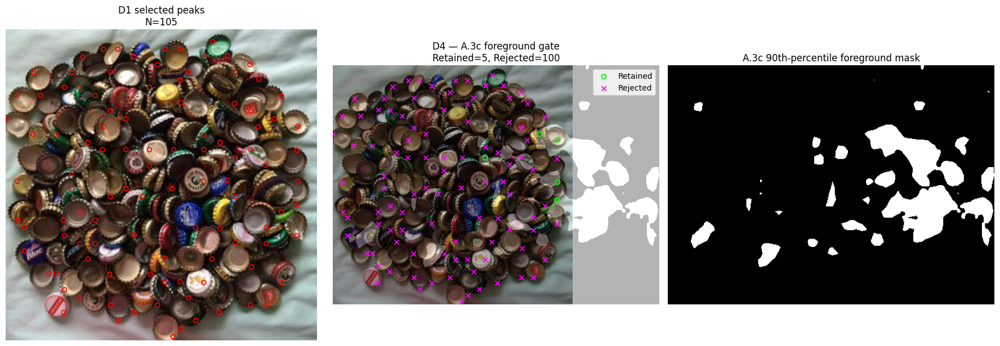

In [83]:
# ============================================================
# Step 11G.2 — Visualise D4 A.3c gating
# ============================================================

import matplotlib.pyplot as plt


fig, axes = plt.subplots(
    1,
    3,
    figsize=(18, 6),
)


# ------------------------------------------------------------
# 1. D1 reference points
# ------------------------------------------------------------

axes[0].imshow(
    d4_image
)

if len(d4_d1_points_xy) > 0:

    axes[0].scatter(
        d4_d1_points_xy[:, 0],
        d4_d1_points_xy[:, 1],
        s=32,
        facecolors="none",
        edgecolors="red",
        linewidths=1.2,
    )

axes[0].set_title(
    f"D1 selected peaks\n"
    f"N={d4_n_d1}"
)

axes[0].axis("off")


# ------------------------------------------------------------
# 2. A.3c mask + retained/rejected points
# ------------------------------------------------------------

axes[1].imshow(
    d4_image
)

axes[1].imshow(
    d4_a3c_mask,
    alpha=0.30,
    cmap="gray",
)

if len(d4_points_xy) > 0:

    axes[1].scatter(
        d4_points_xy[:, 0],
        d4_points_xy[:, 1],
        s=34,
        facecolors="none",
        edgecolors="lime",
        linewidths=1.4,
        label="Retained",
    )

if len(d4_rejected_points_xy) > 0:

    axes[1].scatter(
        d4_rejected_points_xy[:, 0],
        d4_rejected_points_xy[:, 1],
        s=34,
        marker="x",
        c="magenta",
        linewidths=1.3,
        label="Rejected",
    )

axes[1].set_title(
    f"D4 — A.3c foreground gate\n"
    f"Retained={d4_n_retained}, "
    f"Rejected={d4_n_rejected}"
)

axes[1].axis("off")

axes[1].legend(
    loc="upper right"
)


# ------------------------------------------------------------
# 3. A.3c binary foreground mask
# ------------------------------------------------------------

axes[2].imshow(
    d4_a3c_mask,
    cmap="gray",
)

axes[2].set_title(
    "A.3c 90th-percentile foreground mask"
)

axes[2].axis("off")


plt.tight_layout()
plt.show()

In [84]:
# ============================================================
# Step 11G.3 — D4 A.3c gate-effect check on dev100
#
# Fixed D1 configuration:
#   min_distance_frac = 0.020
#   score_threshold   = 0.30
#
# D4:
#   retain D1 peak only if it lies inside
#   the A.3c 90th-percentile foreground mask
# ============================================================

import time
import numpy as np
import pandas as pd

from tqdm.auto import tqdm


D4_MIN_DISTANCE_FRAC = 0.020
D4_SCORE_THRESHOLD = 0.30
D4_MASK_PERCENTILE = 90


d4_gate_rows = []

start_time = time.perf_counter()


for _, row in tqdm(
    fsc147_dev_100_df.iterrows(),
    total=len(fsc147_dev_100_df),
    desc="Checking D4 gate on dev100",
):

    # --------------------------------------------------------
    # Metadata
    # --------------------------------------------------------

    image_id = row["image_id"]
    category = row["category"]
    gt_count = int(row["gt_count"])
    density_stratum = row["density_stratum"]


    # --------------------------------------------------------
    # Load cached SAN scores
    # --------------------------------------------------------

    cached = load_san_cache(
        image_id
    )

    target_score = np.asarray(
        cached["target_score"],
        dtype=np.float32,
    )

    background_score = np.asarray(
        cached["background_score"],
        dtype=np.float32,
    )

    assert (
        target_score.shape
        == background_score.shape
    )


    # --------------------------------------------------------
    # Recreate selected D1 peaks
    # --------------------------------------------------------

    target_score_norm = (
        minmax_normalise_score_map(
            target_score
        )
    )

    (
        d1_points_xy,
        d1_points_yx,
        min_distance_px,
    ) = extract_reference_points(
        target_score_norm,
        min_distance_frac=
            D4_MIN_DISTANCE_FRAC,
        score_threshold=
            D4_SCORE_THRESHOLD,
        valid_mask=None,
    )

    n_d1 = len(
        d1_points_xy
    )


    # --------------------------------------------------------
    # Recreate A.3c foreground mask
    # --------------------------------------------------------

    (
        a3c_mask,
        a3c_info,
    ) = make_a3c_mask(
        target_score,
        percentile=90,
    )

    a3c_mask = np.asarray(
        a3c_mask,
        dtype=bool,
    )


    # --------------------------------------------------------
    # Apply D4 gate
    # --------------------------------------------------------

    if n_d1 > 0:

        peak_y = d1_points_yx[:, 0]
        peak_x = d1_points_yx[:, 1]

        keep_mask = (
            a3c_mask[
                peak_y,
                peak_x,
            ]
        )

        n_retained = int(
            keep_mask.sum()
        )

        n_rejected = int(
            (~keep_mask).sum()
        )

    else:

        n_retained = 0
        n_rejected = 0


    retention_rate = (
        n_retained / n_d1
        if n_d1 > 0
        else np.nan
    )


    # --------------------------------------------------------
    # Store result
    # --------------------------------------------------------

    d4_gate_rows.append(
        {
            "image_id":
                image_id,

            "category":
                category,

            "density_stratum":
                density_stratum,

            "gt_count":
                gt_count,

            "d1_points":
                n_d1,

            "d4_retained":
                n_retained,

            "d4_rejected":
                n_rejected,

            "retention_rate":
                retention_rate,

            "min_distance_px":
                min_distance_px,

            "a3c_threshold":
                float(
                    a3c_info["threshold"]
                ),

            "foreground_fraction":
                float(
                    a3c_mask.mean()
                ),
        }
    )


d4_gate_df = pd.DataFrame(
    d4_gate_rows
)


runtime = (
    time.perf_counter()
    - start_time
)


# ------------------------------------------------------------
# Overall summary
# ------------------------------------------------------------

total_d1_points = int(
    d4_gate_df[
        "d1_points"
    ].sum()
)

total_d4_points = int(
    d4_gate_df[
        "d4_retained"
    ].sum()
)

total_rejected = int(
    d4_gate_df[
        "d4_rejected"
    ].sum()
)

overall_retention = (
    total_d4_points
    / total_d1_points
    if total_d1_points > 0
    else np.nan
)

images_with_rejection = int(
    (
        d4_gate_df[
            "d4_rejected"
        ] > 0
    ).sum()
)


print(
    "D4 gate-effect check complete."
)

print(
    "Images:",
    len(d4_gate_df)
)

print(
    "Total D1 points:",
    total_d1_points
)

print(
    "Total D4 retained:",
    total_d4_points
)

print(
    "Total rejected:",
    total_rejected
)

print(
    "Overall retention rate:",
    round(
        overall_retention,
        4,
    )
)

print(
    "Images with >=1 rejected point:",
    images_with_rejection
)

print(
    f"Runtime: {runtime:.2f} s"
)


display(
    d4_gate_df[
        [
            "image_id",
            "density_stratum",
            "gt_count",
            "d1_points",
            "d4_retained",
            "d4_rejected",
            "retention_rate",
            "foreground_fraction",
        ]
    ]
    .head(20)
    .round(4)
)

Checking D4 gate on dev100:   0%|          | 0/100 [00:00<?, ?it/s]

D4 gate-effect check complete.
Images: 100
Total D1 points: 7652
Total D4 retained: 4194
Total rejected: 3458
Overall retention rate: 0.5481
Images with >=1 rejected point: 72
Runtime: 1.39 s


,image_id,density_stratum,gt_count,d1_points,d4_retained,d4_rejected,retention_rate,foreground_fraction
0,3873.jpg,S1_0_20,7,56,23,33,0.4107,0.1
1,1964.jpg,S1_0_20,8,35,25,10,0.7143,0.1
2,774.jpg,S1_0_20,8,57,22,35,0.3860,0.1
3,2304.jpg,S1_0_20,9,30,28,2,0.9333,0.1
4,3573.jpg,S1_0_20,9,52,20,32,0.3846,0.1
5,3661.jpg,S1_0_20,9,31,19,12,0.6129,0.1
6,5211.jpg,S1_0_20,9,96,29,67,0.3021,0.1
7,5220.jpg,S1_0_20,9,39,33,6,0.8462,0.1
8,623.jpg,S1_0_20,9,7,7,0,1.0000,0.1
9,737.jpg,S1_0_20,9,90,17,73,0.1889,0.1


In [85]:
# ============================================================
# Step 11G.3B — D4 gate effect by density stratum
# ============================================================

d4_gate_density_summary = (
    d4_gate_df
    .groupby(
        "density_stratum",
        as_index=False,
    )
    .agg(
        n_images=
            ("image_id", "count"),

        total_d1_points=
            ("d1_points", "sum"),

        total_retained=
            ("d4_retained", "sum"),

        total_rejected=
            ("d4_rejected", "sum"),

        mean_retention_rate=
            ("retention_rate", "mean"),

        images_with_rejection=
            (
                "d4_rejected",
                lambda x: int(
                    (x > 0).sum()
                ),
            ),

        mean_foreground_fraction=
            ("foreground_fraction", "mean"),
    )
)


display(
    d4_gate_density_summary.round(4)
)

,density_stratum,n_images,total_d1_points,total_retained,total_rejected,mean_retention_rate,images_with_rejection,mean_foreground_fraction
0,S1_0_20,20,1082,624,458,0.6680,16,0.1
1,S2_20_40,20,1233,698,535,0.7089,12,0.1
2,S3_40_60,20,1390,755,635,0.7138,12,0.1
3,S4_60_80,20,1663,949,714,0.6687,16,0.1
4,S5_80_95,10,1143,612,531,0.6125,8,0.1
5,S6_95_100,10,1141,556,585,0.5911,8,0.1


In [86]:
# ============================================================
# Step 11G.4 — Full D4 one-to-one evaluation on dev100
# ============================================================

d4_match_rows = []

start_time = time.perf_counter()


for _, row in tqdm(
    fsc147_dev_100_df.iterrows(),
    total=len(fsc147_dev_100_df),
    desc="Evaluating D4 on dev100",
):

    # --------------------------------------------------------
    # Metadata
    # --------------------------------------------------------

    image_id = row["image_id"]
    category = row["category"]

    dataset_index = int(
        row["dataset_index"]
    )

    gt_count = int(
        row["gt_count"]
    )

    density_stratum = row[
        "density_stratum"
    ]


    # --------------------------------------------------------
    # Load sample + GT
    # --------------------------------------------------------

    sample = fsc147_val_dataset[
        dataset_index
    ]

    gt_xy = np.asarray(
        get_gt_points(
            sample,
            category,
        ),
        dtype=np.float32,
    ).reshape(-1, 2)

    assert (
        len(gt_xy)
        == gt_count
    )


    width = int(
        sample["width"]
    )

    height = int(
        sample["height"]
    )

    short_side = min(
        width,
        height,
    )


    # --------------------------------------------------------
    # Load SAN scores
    # --------------------------------------------------------

    cached = load_san_cache(
        image_id
    )

    target_score = np.asarray(
        cached["target_score"],
        dtype=np.float32,
    )

    background_score = np.asarray(
        cached["background_score"],
        dtype=np.float32,
    )


    # --------------------------------------------------------
    # Generate selected D1 peaks
    # --------------------------------------------------------

    target_score_norm = (
        minmax_normalise_score_map(
            target_score
        )
    )

    (
        d1_points_xy,
        d1_points_yx,
        min_distance_px,
    ) = extract_reference_points(
        target_score_norm,
        min_distance_frac=
            D4_MIN_DISTANCE_FRAC,
        score_threshold=
            D4_SCORE_THRESHOLD,
        valid_mask=None,
    )


    # --------------------------------------------------------
    # Create A.3c mask
    # --------------------------------------------------------

    (
        a3c_mask,
        _,
    ) = make_a3c_mask(
        target_score,
        percentile=90,
    )

    a3c_mask = np.asarray(
        a3c_mask,
        dtype=bool,
    )


    # --------------------------------------------------------
    # Apply D4 gate
    # --------------------------------------------------------

    if len(d1_points_yx) > 0:

        peak_y = d1_points_yx[:, 0]
        peak_x = d1_points_yx[:, 1]

        keep_mask = (
            a3c_mask[
                peak_y,
                peak_x,
            ]
        )

        d4_points_xy = (
            d1_points_xy[
                keep_mask
            ]
        )

    else:

        d4_points_xy = np.empty(
            (0, 2),
            dtype=np.int64,
        )


    n_d1 = len(
        d1_points_xy
    )

    n_d4 = len(
        d4_points_xy
    )


    # --------------------------------------------------------
    # Evaluate at frozen Group-D radii
    # --------------------------------------------------------

    for radius_frac in (
        D1_MATCH_RADII_FRACS
    ):

        radius_px = max(
            1,
            int(
                round(
                    radius_frac
                    * short_side
                )
            ),
        )

        result = (
            match_points_one_to_one_efficient(
                pred_xy=d4_points_xy,
                gt_xy=gt_xy,
                radius_px=radius_px,
            )
        )


        tp = int(
            result["tp"]
        )

        fp = int(
            result["fp"]
        )

        fn = int(
            result["fn"]
        )


        precision = (
            tp / (tp + fp)
            if (tp + fp) > 0
            else 0.0
        )

        recall = (
            tp / (tp + fn)
            if (tp + fn) > 0
            else 0.0
        )

        f1 = (
            2.0
            * precision
            * recall
            / (
                precision
                + recall
            )
            if (
                precision
                + recall
            ) > 0
            else 0.0
        )


        distances = np.asarray(
            result["distances"],
            dtype=np.float32,
        )

        if len(distances) > 0:

            mean_dist_px = float(
                np.mean(
                    distances
                )
            )

            median_dist_px = float(
                np.median(
                    distances
                )
            )

        else:

            mean_dist_px = np.nan
            median_dist_px = np.nan


        d4_match_rows.append(
            {
                "image_id":
                    image_id,

                "category":
                    category,

                "density_stratum":
                    density_stratum,

                "gt_count":
                    gt_count,

                "d1_points":
                    n_d1,

                "d4_points":
                    n_d4,

                "points_rejected":
                    n_d1 - n_d4,

                "radius_frac":
                    radius_frac,

                "radius_px":
                    radius_px,

                "tp":
                    tp,

                "fp":
                    fp,

                "fn":
                    fn,

                "precision":
                    precision,

                "recall":
                    recall,

                "f1":
                    f1,

                "mean_match_dist_px":
                    mean_dist_px,

                "median_match_dist_px":
                    median_dist_px,
            }
        )


d4_match_results_df = pd.DataFrame(
    d4_match_rows
)


runtime = (
    time.perf_counter()
    - start_time
)


# ------------------------------------------------------------
# Validation
# ------------------------------------------------------------

expected_rows = (
    len(fsc147_dev_100_df)
    * len(D1_MATCH_RADII_FRACS)
)

assert (
    len(d4_match_results_df)
    == expected_rows
)


print(
    "D4 matching rows:",
    len(d4_match_results_df)
)

print(
    "Expected rows:",
    expected_rows
)

print(
    f"Runtime: {runtime:.2f} s"
)


display(
    d4_match_results_df[
        [
            "image_id",
            "density_stratum",
            "gt_count",

            "d1_points",
            "d4_points",
            "points_rejected",

            "radius_frac",
            "radius_px",

            "tp",
            "fp",
            "fn",

            "precision",
            "recall",
            "f1",
        ]
    ]
    .head(20)
    .round(4)
)

Evaluating D4 on dev100:   0%|          | 0/100 [00:00<?, ?it/s]

D4 matching rows: 400
Expected rows: 400
Runtime: 1.80 s


,image_id,density_stratum,gt_count,d1_points,d4_points,points_rejected,radius_frac,radius_px,tp,fp,fn,precision,recall,f1
0,3873.jpg,S1_0_20,7,56,23,33,0.01,4,0,23,7,0.0000,0.0000,0.0000
1,3873.jpg,S1_0_20,7,56,23,33,0.02,8,0,23,7,0.0000,0.0000,0.0000
2,3873.jpg,S1_0_20,7,56,23,33,0.03,12,2,21,5,0.0870,0.2857,0.1333
3,3873.jpg,S1_0_20,7,56,23,33,0.05,19,2,21,5,0.0870,0.2857,0.1333
4,1964.jpg,S1_0_20,8,35,25,10,0.01,4,0,25,8,0.0000,0.0000,0.0000
5,1964.jpg,S1_0_20,8,35,25,10,0.02,8,1,24,7,0.0400,0.1250,0.0606
6,1964.jpg,S1_0_20,8,35,25,10,0.03,12,1,24,7,0.0400,0.1250,0.0606
7,1964.jpg,S1_0_20,8,35,25,10,0.05,19,6,19,2,0.2400,0.7500,0.3636
8,774.jpg,S1_0_20,8,57,22,35,0.01,4,0,22,8,0.0000,0.0000,0.0000
9,774.jpg,S1_0_20,8,57,22,35,0.02,8,0,22,8,0.0000,0.0000,0.0000


In [87]:
# ============================================================
# Step 11G.5 — Controlled D1 vs D4 comparison
# ============================================================

comparison_rows = []


for radius_frac in D1_MATCH_RADII_FRACS:

    # --------------------------------------------------------
    # D1 selected configuration
    # --------------------------------------------------------

    d1_group = d1_match_results_df[
        np.isclose(
            d1_match_results_df["min_distance_frac"],
            D4_MIN_DISTANCE_FRAC,
        )
        &
        np.isclose(
            d1_match_results_df["score_threshold"],
            D4_SCORE_THRESHOLD,
        )
        &
        np.isclose(
            d1_match_results_df["radius_frac"],
            radius_frac,
        )
    ]


    # --------------------------------------------------------
    # D4
    # --------------------------------------------------------

    d4_group = d4_match_results_df[
        np.isclose(
            d4_match_results_df["radius_frac"],
            radius_frac,
        )
    ]


    def summarise_group(group):

        total_tp = int(group["tp"].sum())
        total_fp = int(group["fp"].sum())
        total_fn = int(group["fn"].sum())

        macro_p = float(
            group["precision"].mean()
        )

        macro_r = float(
            group["recall"].mean()
        )

        macro_f1 = float(
            group["f1"].mean()
        )

        micro_p = (
            total_tp
            / (total_tp + total_fp)
            if (total_tp + total_fp) > 0
            else 0.0
        )

        micro_r = (
            total_tp
            / (total_tp + total_fn)
            if (total_tp + total_fn) > 0
            else 0.0
        )

        micro_f1 = (
            2.0
            * micro_p
            * micro_r
            / (micro_p + micro_r)
            if (micro_p + micro_r) > 0
            else 0.0
        )

        return {
            "macro_p": macro_p,
            "macro_r": macro_r,
            "macro_f1": macro_f1,
            "micro_p": micro_p,
            "micro_r": micro_r,
            "micro_f1": micro_f1,
            "tp": total_tp,
            "fp": total_fp,
            "fn": total_fn,
        }


    d1_summary = summarise_group(
        d1_group
    )

    d4_summary = summarise_group(
        d4_group
    )


    comparison_rows.append(
        {
            "radius_frac":
                radius_frac,

            "D1_macro_P":
                d1_summary["macro_p"],

            "D4_macro_P":
                d4_summary["macro_p"],

            "delta_macro_P":
                d4_summary["macro_p"]
                - d1_summary["macro_p"],

            "D1_macro_R":
                d1_summary["macro_r"],

            "D4_macro_R":
                d4_summary["macro_r"],

            "delta_macro_R":
                d4_summary["macro_r"]
                - d1_summary["macro_r"],

            "D1_macro_F1":
                d1_summary["macro_f1"],

            "D4_macro_F1":
                d4_summary["macro_f1"],

            "delta_macro_F1":
                d4_summary["macro_f1"]
                - d1_summary["macro_f1"],

            "D1_micro_F1":
                d1_summary["micro_f1"],

            "D4_micro_F1":
                d4_summary["micro_f1"],

            "delta_micro_F1":
                d4_summary["micro_f1"]
                - d1_summary["micro_f1"],
        }
    )


d1_d4_comparison = pd.DataFrame(
    comparison_rows
)


display(
    d1_d4_comparison.round(4)
)

,radius_frac,D1_macro_P,D4_macro_P,delta_macro_P,D1_macro_R,D4_macro_R,delta_macro_R,D1_macro_F1,D4_macro_F1,delta_macro_F1,D1_micro_F1,D4_micro_F1,delta_micro_F1
0,0.01,0.1418,0.1438,0.0020,0.1197,0.1064,-0.0133,0.1079,0.1053,-0.0025,0.0856,0.0806,-0.0049
1,0.02,0.2909,0.2969,0.0060,0.3067,0.2532,-0.0535,0.2491,0.2363,-0.0128,0.1896,0.1653,-0.0243
2,0.03,0.3770,0.3880,0.0110,0.4603,0.3628,-0.0975,0.3452,0.3247,-0.0205,0.2729,0.2260,-0.0469
3,0.05,0.4813,0.5041,0.0228,0.6928,0.5233,-0.1696,0.4697,0.4437,-0.0259,0.3658,0.2957,-0.0702


In [88]:
# ============================================================
# Step 11G.6 — Density-stratified evaluation of D4
# ============================================================

d4_primary = (
    d4_match_results_df[
        np.isclose(
            d4_match_results_df[
                "radius_frac"
            ],
            0.03,
        )
    ]
    .copy()
)


assert len(d4_primary) == 100


density_rows = []


for density_stratum, group in (
    d4_primary.groupby(
        "density_stratum"
    )
):

    n_images = len(group)

    total_gt = int(
        group["gt_count"].sum()
    )

    total_pred = int(
        group["d4_points"].sum()
    )

    mean_gt = float(
        group["gt_count"].mean()
    )

    mean_pred = float(
        group["d4_points"].mean()
    )


    # --------------------------------------------------------
    # Proxy count behaviour
    # --------------------------------------------------------

    errors = (
        group["d4_points"].to_numpy()
        -
        group["gt_count"].to_numpy()
    )

    mean_signed_error = float(
        np.mean(errors)
    )

    proxy_mae = float(
        np.mean(
            np.abs(errors)
        )
    )

    proxy_rmse = float(
        np.sqrt(
            np.mean(
                errors ** 2
            )
        )
    )


    # --------------------------------------------------------
    # Macro metrics
    # --------------------------------------------------------

    macro_precision = float(
        group["precision"].mean()
    )

    macro_recall = float(
        group["recall"].mean()
    )

    macro_f1 = float(
        group["f1"].mean()
    )


    # --------------------------------------------------------
    # Micro metrics
    # --------------------------------------------------------

    total_tp = int(
        group["tp"].sum()
    )

    total_fp = int(
        group["fp"].sum()
    )

    total_fn = int(
        group["fn"].sum()
    )

    micro_precision = (
        total_tp
        / (total_tp + total_fp)
        if (total_tp + total_fp) > 0
        else 0.0
    )

    micro_recall = (
        total_tp
        / (total_tp + total_fn)
        if (total_tp + total_fn) > 0
        else 0.0
    )

    micro_f1 = (
        2.0
        * micro_precision
        * micro_recall
        / (micro_precision + micro_recall)
        if (micro_precision + micro_recall) > 0
        else 0.0
    )


    # --------------------------------------------------------
    # Localisation distance
    # --------------------------------------------------------

    valid_dist = (
        (group["tp"] > 0)
        &
        group[
            "mean_match_dist_px"
        ].notna()
    )

    if valid_dist.any():

        weighted_mean_dist_px = float(
            np.average(
                group.loc[
                    valid_dist,
                    "mean_match_dist_px",
                ],
                weights=group.loc[
                    valid_dist,
                    "tp",
                ],
            )
        )

    else:

        weighted_mean_dist_px = np.nan


    density_rows.append(
        {
            "density_stratum":
                density_stratum,

            "n_images":
                n_images,

            "mean_gt":
                mean_gt,

            "mean_pred":
                mean_pred,

            "mean_signed_error":
                mean_signed_error,

            "proxy_mae":
                proxy_mae,

            "proxy_rmse":
                proxy_rmse,

            "macro_precision":
                macro_precision,

            "macro_recall":
                macro_recall,

            "macro_f1":
                macro_f1,

            "micro_precision":
                micro_precision,

            "micro_recall":
                micro_recall,

            "micro_f1":
                micro_f1,

            "weighted_mean_dist_px":
                weighted_mean_dist_px,
        }
    )


d4_density_summary = pd.DataFrame(
    density_rows
)


# Sort S1 -> S6
d4_density_summary["_order"] = (
    d4_density_summary[
        "density_stratum"
    ]
    .str.extract(
        r"S(\d+)"
    )[0]
    .astype(int)
)

d4_density_summary = (
    d4_density_summary
    .sort_values("_order")
    .drop(
        columns="_order"
    )
    .reset_index(drop=True)
)


display(
    d4_density_summary.round(4)
)

,density_stratum,n_images,mean_gt,mean_pred,mean_signed_error,proxy_mae,proxy_rmse,macro_precision,macro_recall,macro_f1,micro_precision,micro_recall,micro_f1,weighted_mean_dist_px
0,S1_0_20,20,9.75,31.20,21.45,21.65,26.7385,0.1903,0.3832,0.2347,0.1234,0.3949,0.1880,6.7567
1,S2_20_40,20,16.00,34.90,18.90,19.10,25.4480,0.3208,0.4577,0.3623,0.2034,0.4438,0.2790,6.0858
2,S3_40_60,20,26.85,37.75,10.90,15.20,18.6091,0.3536,0.3970,0.3549,0.2742,0.3855,0.3204,5.8934
3,S4_60_80,20,54.80,47.45,-7.35,11.45,14.5448,0.4639,0.3809,0.4117,0.4510,0.3905,0.4186,6.2241
4,S5_80_95,10,121.10,61.20,-59.90,59.90,69.1469,0.5349,0.3076,0.3819,0.5686,0.2874,0.3818,6.1313
5,S6_95_100,10,668.60,55.60,-613.00,613.00,819.1332,0.6878,0.0832,0.1377,0.7320,0.0609,0.1124,4.3385


In [89]:
# ============================================================
# Step 11G.6B — Density-wise D1 vs D4 comparison
# ============================================================

d1_density_for_compare = (
    d1_density_summary[
        [
            "density_stratum",
            "macro_precision",
            "macro_recall",
            "macro_f1",
            "mean_pred",
        ]
    ]
    .rename(
        columns={
            "macro_precision":
                "D1_P",

            "macro_recall":
                "D1_R",

            "macro_f1":
                "D1_F1",

            "mean_pred":
                "D1_mean_pred",
        }
    )
)


d4_density_for_compare = (
    d4_density_summary[
        [
            "density_stratum",
            "macro_precision",
            "macro_recall",
            "macro_f1",
            "mean_pred",
        ]
    ]
    .rename(
        columns={
            "macro_precision":
                "D4_P",

            "macro_recall":
                "D4_R",

            "macro_f1":
                "D4_F1",

            "mean_pred":
                "D4_mean_pred",
        }
    )
)


d1_d4_density_comparison = (
    d1_density_for_compare
    .merge(
        d4_density_for_compare,
        on="density_stratum",
        how="inner",
    )
)


d1_d4_density_comparison[
    "delta_F1"
] = (
    d1_d4_density_comparison[
        "D4_F1"
    ]
    -
    d1_d4_density_comparison[
        "D1_F1"
    ]
)


display(
    d1_d4_density_comparison.round(4)
)

,density_stratum,D1_P,D1_R,D1_F1,D1_mean_pred,D4_P,D4_R,D4_F1,D4_mean_pred,delta_F1
0,S1_0_20,0.1611,0.4509,0.2043,54.10,0.1903,0.3832,0.2347,31.20,0.0304
1,S2_20_40,0.3147,0.5425,0.3647,61.65,0.3208,0.4577,0.3623,34.90,-0.0024
2,S3_40_60,0.3425,0.4821,0.3592,69.50,0.3536,0.3970,0.3549,37.75,-0.0042
3,S4_60_80,0.4172,0.4909,0.4241,83.15,0.4639,0.3809,0.4117,47.45,-0.0124
4,S5_80_95,0.5551,0.4820,0.4976,114.30,0.5349,0.3076,0.3819,61.20,-0.1157
5,S6_95_100,0.7438,0.1884,0.2497,114.10,0.6878,0.0832,0.1377,55.60,-0.1120


### D4 Summary — D1 peaks gated by A.3c foreground mask

D4 retained selected D1 peaks only when they fell inside the A.3c
90th-percentile SAN foreground mask.

Across dev100, the gate retained 4,194 of 7,652 D1 peaks (54.8%),
showing that it provides a much stronger filtering effect than D2 or D3.

At the primary 3% matching radius:

- D1 macro Precision = 0.3770
- D4 macro Precision = 0.3880
- D1 macro Recall = 0.4603
- D4 macro Recall = 0.3628
- D1 macro F1 = 0.3452
- D4 macro F1 = 0.3247

The foreground gate therefore produced a small precision gain but a much
larger recall loss, so D4 should not replace D1 as the global
reference-point method.

However, the density-stratified results reveal an important
regime-specific effect:

- S1: F1 improved from 0.2043 to 0.2347 (+0.0304).
- S2 and S3 were broadly similar to D1, with only small reductions.
- S4 showed a modest reduction (-0.0124).
- S5 and S6 degraded substantially (-0.1157 and -0.1120).

This pattern is consistent with the behaviour of D1 itself. In sparse
S1 scenes, D1 strongly over-generated reference points
(mean GT = 9.75; mean D1 points = 54.10). D4 reduced the mean number of
points to 31.20 and improved the precision-recall balance. In contrast,
D1 already under-generated reference points in dense scenes, especially
S6 (mean GT = 668.6; mean D1 points = 114.1). Applying the A.3c gate
reduced this further to 55.6 points and caused a severe recall loss.

D4 therefore provides evidence that stronger semantic filtering can be
useful when the initial reference-point set is sparse-scene
over-generating, but the same fixed filtering becomes harmful when the
scene is dense and reference points are already insufficient.

**D4** is not retained as a global replacement for D1. However, unlike D2
and D3, it is **retained as a potentially useful complementary cue** for a
later adaptive or fusion design. Any such adaptive mechanism must be
based on information available at inference time rather than GT density.

# D5 - CLIP Surgery semantic activation map

In [90]:
# ============================================================
# Step 11H.1 — D5 CLIP Surgery setup
#
# Reproduce the familiarised CLIP Surgery configuration:
#   repo  : xmed-lab/CLIP_Surgery
#   commit: d4696d47f49cfe70f49140afe5eb94f94c5f59bc
#   model : CS-ViT-B/16
#   input : standard 224 x 224 preprocessing
# ============================================================

from pathlib import Path
import subprocess
import sys
import importlib

import torch


CLIP_SURGERY_REPO = Path(
    "/content/CLIP_Surgery"
)

CLIP_SURGERY_COMMIT = (
    "d4696d47f49cfe70f49140afe5eb94f94c5f59bc"
)


# ------------------------------------------------------------
# Clone repository if needed
# ------------------------------------------------------------

if not CLIP_SURGERY_REPO.exists():

    subprocess.run(
        [
            "git",
            "clone",
            "https://github.com/xmed-lab/CLIP_Surgery.git",
            str(CLIP_SURGERY_REPO),
        ],
        check=True,
    )


# ------------------------------------------------------------
# Checkout the fixed familiarisation commit
# ------------------------------------------------------------

subprocess.run(
    [
        "git",
        "-C",
        str(CLIP_SURGERY_REPO),
        "checkout",
        CLIP_SURGERY_COMMIT,
    ],
    check=True,
)


# ------------------------------------------------------------
# Ensure repo version of `clip` is imported
# ------------------------------------------------------------

repo_path_str = str(
    CLIP_SURGERY_REPO
)

if repo_path_str not in sys.path:
    sys.path.insert(
        0,
        repo_path_str,
    )


# Remove a previously imported unrelated `clip` module if needed
if "clip" in sys.modules:
    del sys.modules["clip"]

import clip

print(
    "CLIP module:",
    clip.__file__,
)


# ------------------------------------------------------------
# Load CS-ViT-B/16
# ------------------------------------------------------------

D5_DEVICE = (
    torch.device("cuda")
    if torch.cuda.is_available()
    else torch.device("cpu")
)

d5_model, d5_preprocess = (
    clip.load(
        "CS-ViT-B/16",
        device=D5_DEVICE,
    )
)

d5_model.eval()


print(
    "Device:",
    D5_DEVICE,
)

print(
    "Model:",
    "CS-ViT-B/16",
)

print(
    "Pinned commit:",
    CLIP_SURGERY_COMMIT,
)

/content/CLIP_Surgery/clip/clip.py:6: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import packaging


CLIP module: /content/CLIP_Surgery/clip/__init__.py
Device: cuda
Model: CS-ViT-B/16
Pinned commit: d4696d47f49cfe70f49140afe5eb94f94c5f59bc


In [91]:
# ============================================================
# Step 11H.2 — D5 single-image CLIP Surgery sanity check
#
# D5 semantic cue:
#   CLIP Surgery target similarity map
#
# Image:
#   1935.jpg
#   target = bottle caps
# ============================================================

import numpy as np

from PIL import Image


D5_TEST_IMAGE_ID = "1935.jpg"


# ------------------------------------------------------------
# 1. Recover correct FSC-147 metadata explicitly
# ------------------------------------------------------------

d5_rows = fsc147_dev_100_df[
    fsc147_dev_100_df["image_id"]
    == D5_TEST_IMAGE_ID
]

assert len(d5_rows) == 1

d5_row = d5_rows.iloc[0]

d5_dataset_index = int(
    d5_row["dataset_index"]
)

d5_category = d5_row[
    "category"
]

d5_gt_count = int(
    d5_row["gt_count"]
)

d5_density_stratum = d5_row[
    "density_stratum"
]


# ------------------------------------------------------------
# 2. FSC-147 sample / GT
# ------------------------------------------------------------

d5_sample = fsc147_val_dataset[
    d5_dataset_index
]

d5_gt_points_xy = np.asarray(
    get_gt_points(
        d5_sample,
        d5_category,
    ),
    dtype=np.float32,
).reshape(-1, 2)

assert (
    len(d5_gt_points_xy)
    == d5_gt_count
)


# ------------------------------------------------------------
# 3. Load original image
# ------------------------------------------------------------

d5_image_path = (
    FSC147_IMAGE_DIR
    / D5_TEST_IMAGE_ID
)

d5_image = Image.open(
    d5_image_path
).convert("RGB")

d5_W, d5_H = (
    d5_image.size
)


# ------------------------------------------------------------
# 4. Standard CLIP Surgery preprocessing
# ------------------------------------------------------------

d5_image_tensor = (
    d5_preprocess(
        d5_image
    )
    .unsqueeze(0)
    .to(
        D5_DEVICE
    )
)


# ------------------------------------------------------------
# 5. Encode image + target / redundant text
# ------------------------------------------------------------

with torch.inference_mode():

    # Spatial image-token features
    d5_image_features = (
        d5_model.encode_image(
            d5_image_tensor
        )
    )

    d5_image_features = (
        d5_image_features
        /
        d5_image_features.norm(
            dim=-1,
            keepdim=True,
        )
    )


    # Target text
    d5_text_features = (
        clip.encode_text_with_prompt_ensemble(
            d5_model,
            [d5_category],
            D5_DEVICE,
        )
    )


    # Explicit CLIP Surgery redundant feature
    d5_redundant_features = (
        clip.encode_text_with_prompt_ensemble(
            d5_model,
            [""],
            D5_DEVICE,
        )
    )


    # --------------------------------------------------------
    # CLIP feature surgery
    # --------------------------------------------------------

    d5_similarity = (
        clip.clip_feature_surgery(
            d5_image_features,
            d5_text_features,
            d5_redundant_features,
        )
    )


    # Remove CLS token and remap spatial tokens
    # to original FSC-147 image resolution
    d5_similarity_map_t = (
        clip.get_similarity_map(
            d5_similarity[
                :,
                1:,
                :,
            ],
            (
                d5_H,
                d5_W,
            ),
        )
    )


# ------------------------------------------------------------
# 6. Convert to 2-D NumPy map
#
# Expected shape after get_similarity_map:
# [1, H, W, 1]
# ------------------------------------------------------------

print(
    "Image feature shape:",
    tuple(
        d5_image_features.shape
    ),
)

print(
    "CLIP Surgery raw similarity shape:",
    tuple(
        d5_similarity.shape
    ),
)

print(
    "Similarity-map tensor shape:",
    tuple(
        d5_similarity_map_t.shape
    ),
)


d5_similarity_map = (
    d5_similarity_map_t[
        0,
        :,
        :,
        0,
    ]
    .detach()
    .float()
    .cpu()
    .numpy()
)


assert (
    d5_similarity_map.shape
    ==
    (d5_H, d5_W)
)


print(
    "\nImage:",
    D5_TEST_IMAGE_ID,
)

print(
    "Category:",
    d5_category,
)

print(
    "Density stratum:",
    d5_density_stratum,
)

print(
    "GT count:",
    d5_gt_count,
)

print(
    "Original image size:",
    f"{d5_W} x {d5_H}",
)

print(
    "CLIP input tensor shape:",
    tuple(
        d5_image_tensor.shape
    ),
)

print(
    "\nD5 similarity map:"
)

print(
    "  shape =",
    d5_similarity_map.shape,
)

print(
    "  min   =",
    float(
        d5_similarity_map.min()
    ),
)

print(
    "  max   =",
    float(
        d5_similarity_map.max()
    ),
)

print(
    "  mean  =",
    float(
        d5_similarity_map.mean()
    ),
)

Image feature shape: (1, 197, 512)
CLIP Surgery raw similarity shape: (1, 197, 1)
Similarity-map tensor shape: (1, 384, 384, 1)

Image: 1935.jpg
Category: bottle caps
Density stratum: S5_80_95
GT count: 175
Original image size: 384 x 384
CLIP input tensor shape: (1, 3, 224, 224)

D5 similarity map:
  shape = (384, 384)
  min   = 0.0018722980748862028
  max   = 0.9963831305503845
  mean  = 0.6718392372131348


In [92]:
# ============================================================
# Step 11H.3 — Extract D5 reference points
# ============================================================

D5_SANITY_MIN_DISTANCE_FRAC = 0.020
D5_SANITY_SCORE_THRESHOLD = 0.30


# ------------------------------------------------------------
# IMPORTANT:
#
# CLIP Surgery get_similarity_map() already performs its
# min-max normalisation before interpolation.
#
# Therefore do NOT independently renormalise this map here.
# ------------------------------------------------------------

(
    d5_points_xy,
    d5_points_yx,
    d5_min_distance_px,
) = extract_reference_points(
    d5_similarity_map,
    min_distance_frac=
        D5_SANITY_MIN_DISTANCE_FRAC,
    score_threshold=
        D5_SANITY_SCORE_THRESHOLD,
    valid_mask=None,
)


print(
    "D5 sanity configuration:"
)

print(
    "  min_distance_frac =",
    D5_SANITY_MIN_DISTANCE_FRAC,
)

print(
    "  min_distance_px   =",
    d5_min_distance_px,
)

print(
    "  score_threshold   =",
    D5_SANITY_SCORE_THRESHOLD,
)


print(
    "\nD5 predicted reference points:",
    len(d5_points_xy),
)

print(
    "GT points:",
    d5_gt_count,
)

print(
    "Signed proxy-count error:",
    len(d5_points_xy)
    - d5_gt_count,
)

D5 sanity configuration:
  min_distance_frac = 0.02
  min_distance_px   = 8
  score_threshold   = 0.3

D5 predicted reference points: 59
GT points: 175
Signed proxy-count error: -116


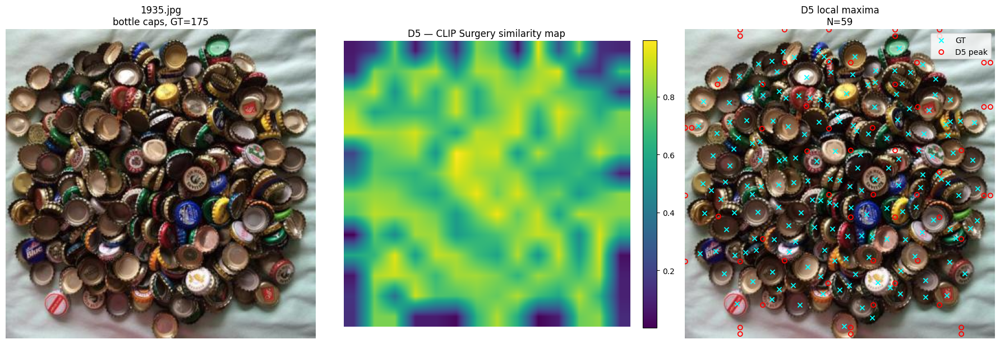

In [93]:
# ============================================================
# Step 11H.4 — Visualise CLIP Surgery D5 reference points
# ============================================================

import matplotlib.pyplot as plt


fig, axes = plt.subplots(
    1,
    3,
    figsize=(18, 6),
)


# ------------------------------------------------------------
# 1. Original image
# ------------------------------------------------------------

axes[0].imshow(
    d5_image
)

axes[0].set_title(
    f"{D5_TEST_IMAGE_ID}\n"
    f"{d5_category}, GT={d5_gt_count}"
)

axes[0].axis("off")


# ------------------------------------------------------------
# 2. CLIP Surgery map
# ------------------------------------------------------------

im = axes[1].imshow(
    d5_similarity_map,
    cmap="viridis",
)

axes[1].set_title(
    "D5 — CLIP Surgery similarity map"
)

axes[1].axis("off")

fig.colorbar(
    im,
    ax=axes[1],
    fraction=0.046,
    pad=0.04,
)


# ------------------------------------------------------------
# 3. D5 peaks + GT
# ------------------------------------------------------------

axes[2].imshow(
    d5_image
)


# GT points
if len(d5_gt_points_xy) > 0:

    axes[2].scatter(
        d5_gt_points_xy[:, 0],
        d5_gt_points_xy[:, 1],
        marker="x",
        s=34,
        c="cyan",
        linewidths=1.3,
        label="GT",
    )


# D5 points
if len(d5_points_xy) > 0:

    axes[2].scatter(
        d5_points_xy[:, 0],
        d5_points_xy[:, 1],
        s=34,
        facecolors="none",
        edgecolors="red",
        linewidths=1.3,
        label="D5 peak",
    )


axes[2].set_title(
    f"D5 local maxima\n"
    f"N={len(d5_points_xy)}"
)

axes[2].axis("off")

axes[2].legend(
    loc="upper right"
)


plt.tight_layout()
plt.show()

In [94]:
# ============================================================
# Step 11H.5 — D5 20-configuration dev100 sweep
#
# Semantic source:
#   CLIP Surgery CS-ViT-B/16, standard 224 x 224 input
#
# One CLIP-Surgery inference per image.
# Then apply the same 20 peak configurations used by D1/D3.
#
# Primary purpose:
#   generate D5 reference-point predictions for later
#   one-to-one spatial evaluation.
# ============================================================

import time
import gc

import numpy as np
import pandas as pd
import torch

from PIL import Image
from tqdm.auto import tqdm


# ------------------------------------------------------------
# D5 uses exactly the same peak parameter grid as D1
# ------------------------------------------------------------

D5_MIN_DISTANCE_FRACS = list(
    D1_MIN_DISTANCE_FRACS
)

D5_SCORE_THRESHOLDS = list(
    D1_SCORE_THRESHOLDS
)


print(
    "D5 min-distance fractions:",
    D5_MIN_DISTANCE_FRACS
)

print(
    "D5 score thresholds:",
    D5_SCORE_THRESHOLDS
)

print(
    "Number of D5 configurations:",
    len(D5_MIN_DISTANCE_FRACS)
    * len(D5_SCORE_THRESHOLDS)
)


# ------------------------------------------------------------
# Encode the redundant/empty-string text feature ONCE
# ------------------------------------------------------------

with torch.inference_mode():

    d5_redundant_features_global = (
        clip.encode_text_with_prompt_ensemble(
            d5_model,
            [""],
            D5_DEVICE,
        )
    )


# ------------------------------------------------------------
# Optional target-text feature cache
#
# Avoid recomputing the text embedding if a category occurs
# more than once in dev100.
# ------------------------------------------------------------

d5_text_feature_cache = {}


def get_d5_text_feature(category):
    """
    Return cached CLIP-Surgery text feature for one FSC-147
    category.
    """

    if category not in d5_text_feature_cache:

        with torch.inference_mode():

            text_feature = (
                clip.encode_text_with_prompt_ensemble(
                    d5_model,
                    [category],
                    D5_DEVICE,
                )
            )

        d5_text_feature_cache[
            category
        ] = text_feature

    return d5_text_feature_cache[
        category
    ]


# ------------------------------------------------------------
# Main sweep
# ------------------------------------------------------------

d5_prediction_rows = []

start_time = time.perf_counter()


for _, row in tqdm(
    fsc147_dev_100_df.iterrows(),
    total=len(fsc147_dev_100_df),
    desc="Generating D5 dev100 predictions",
):

    # --------------------------------------------------------
    # Metadata
    # --------------------------------------------------------

    image_id = row[
        "image_id"
    ]

    category = row[
        "category"
    ]

    dataset_index = int(
        row["dataset_index"]
    )

    gt_count = int(
        row["gt_count"]
    )

    density_stratum = row[
        "density_stratum"
    ]


    # --------------------------------------------------------
    # FSC-147 sample + GT
    # --------------------------------------------------------

    sample = fsc147_val_dataset[
        dataset_index
    ]

    gt_points_xy = np.asarray(
        get_gt_points(
            sample,
            category,
        ),
        dtype=np.float32,
    ).reshape(-1, 2)

    assert (
        len(gt_points_xy)
        == gt_count
    )


    width = int(
        sample["width"]
    )

    height = int(
        sample["height"]
    )

    short_side = min(
        width,
        height,
    )


    # --------------------------------------------------------
    # Load original image
    # --------------------------------------------------------

    image_path = (
        FSC147_IMAGE_DIR
        / image_id
    )

    pil_image = Image.open(
        image_path
    ).convert("RGB")


    # --------------------------------------------------------
    # Standard CLIP-Surgery preprocessing
    # --------------------------------------------------------

    image_tensor = (
        d5_preprocess(
            pil_image
        )
        .unsqueeze(0)
        .to(
            D5_DEVICE
        )
    )


    # --------------------------------------------------------
    # CLIP-Surgery inference
    #
    # IMPORTANT:
    # Run ONCE per image, not once per parameter setting.
    # --------------------------------------------------------

    target_text_feature = (
        get_d5_text_feature(
            category
        )
    )


    with torch.inference_mode():

        image_features = (
            d5_model.encode_image(
                image_tensor
            )
        )

        image_features = (
            image_features
            /
            image_features.norm(
                dim=-1,
                keepdim=True,
            )
        )


        similarity = (
            clip.clip_feature_surgery(
                image_features,
                target_text_feature,
                d5_redundant_features_global,
            )
        )


        # Remove CLS token, then map native spatial tokens
        # back to the original image resolution.
        similarity_map_t = (
            clip.get_similarity_map(
                similarity[
                    :,
                    1:,
                    :,
                ],
                (
                    height,
                    width,
                ),
            )
        )


    # --------------------------------------------------------
    # Convert to H x W NumPy array
    #
    # get_similarity_map already performs the CLIP-Surgery
    # spatial min-max normalisation before interpolation.
    # Do NOT min-max normalise again here.
    # --------------------------------------------------------

    similarity_map = (
        similarity_map_t[
            0,
            :,
            :,
            0,
        ]
        .detach()
        .float()
        .cpu()
        .numpy()
    )


    assert (
        similarity_map.shape
        ==
        (
            height,
            width,
        )
    )


    # --------------------------------------------------------
    # Apply all 20 peak configurations
    # --------------------------------------------------------

    for min_distance_frac in (
        D5_MIN_DISTANCE_FRACS
    ):

        for score_threshold in (
            D5_SCORE_THRESHOLDS
        ):

            (
                points_xy,
                _,
                min_distance_px,
            ) = extract_reference_points(
                similarity_map,
                min_distance_frac=
                    min_distance_frac,
                score_threshold=
                    score_threshold,
                valid_mask=None,
            )


            pred_count = len(
                points_xy
            )


            d5_prediction_rows.append(
                {
                    "image_id":
                        image_id,

                    "dataset_index":
                        dataset_index,

                    "category":
                        category,

                    "density_stratum":
                        density_stratum,

                    "width":
                        width,

                    "height":
                        height,

                    "short_side":
                        short_side,

                    "gt_count":
                        gt_count,

                    "min_distance_frac":
                        min_distance_frac,

                    "min_distance_px":
                        min_distance_px,

                    "score_threshold":
                        score_threshold,

                    "pred_count":
                        pred_count,

                    "count_error":
                        pred_count
                        - gt_count,

                    "pred_points_xy":
                        points_xy,

                    "gt_points_xy":
                        gt_points_xy,
                }
            )


    # --------------------------------------------------------
    # Explicit cleanup of image-specific GPU tensors
    # --------------------------------------------------------

    del image_tensor
    del image_features
    del similarity
    del similarity_map_t

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


# ------------------------------------------------------------
# Build DataFrame
# ------------------------------------------------------------

d5_predictions_df = pd.DataFrame(
    d5_prediction_rows
)


runtime = (
    time.perf_counter()
    - start_time
)


# ------------------------------------------------------------
# Validation
# ------------------------------------------------------------

expected_rows = (
    len(fsc147_dev_100_df)
    * len(D5_MIN_DISTANCE_FRACS)
    * len(D5_SCORE_THRESHOLDS)
)

assert (
    len(d5_predictions_df)
    == expected_rows
)

assert (
    d5_predictions_df[
        "image_id"
    ].nunique()
    == 100
)


print(
    "\nD5 prediction rows:",
    len(d5_predictions_df)
)

print(
    "Expected rows:",
    expected_rows
)

print(
    "Unique images:",
    d5_predictions_df[
        "image_id"
    ].nunique()
)

print(
    "Cached text categories:",
    len(
        d5_text_feature_cache
    )
)

print(
    f"Runtime: {runtime:.2f} s"
)


# ------------------------------------------------------------
# Display first image × all 20 configurations
# ------------------------------------------------------------

display(
    d5_predictions_df[
        [
            "image_id",
            "density_stratum",
            "gt_count",

            "min_distance_frac",
            "min_distance_px",
            "score_threshold",

            "pred_count",
            "count_error",
        ]
    ]
    .head(20)
)

D5 min-distance fractions: [0.005, 0.01, 0.02, 0.03]
D5 score thresholds: [0.3, 0.4, 0.5, 0.6, 0.7]
Number of D5 configurations: 20


Generating D5 dev100 predictions:   0%|          | 0/100 [00:00<?, ?it/s]


D5 prediction rows: 2000
Expected rows: 2000
Unique images: 100
Cached text categories: 21
Runtime: 84.67 s


,image_id,density_stratum,gt_count,min_distance_frac,min_distance_px,score_threshold,pred_count,count_error
0,3873.jpg,S1_0_20,7,0.005,2,0.3,83,76
1,3873.jpg,S1_0_20,7,0.005,2,0.4,77,70
2,3873.jpg,S1_0_20,7,0.005,2,0.5,77,70
3,3873.jpg,S1_0_20,7,0.005,2,0.6,77,70
4,3873.jpg,S1_0_20,7,0.005,2,0.7,55,48
5,3873.jpg,S1_0_20,7,0.010,4,0.3,56,49
6,3873.jpg,S1_0_20,7,0.010,4,0.4,53,46
7,3873.jpg,S1_0_20,7,0.010,4,0.5,53,46
8,3873.jpg,S1_0_20,7,0.010,4,0.6,53,46
9,3873.jpg,S1_0_20,7,0.010,4,0.7,40,33


In [95]:
# ============================================================
# Step 11H.6 — Full D5 one-to-one matching on dev100
#
# Input:
#   d5_predictions_df
#
# Evaluate all 20 D5 configurations at:
#   1%, 2%, 3%, 5% matching radii
#
# Expected rows:
#   2000 configurations/images x 4 radii = 8000
# ============================================================

import time
import numpy as np
import pandas as pd

from tqdm.auto import tqdm


d5_match_rows = []

start_time = time.perf_counter()


for _, row in tqdm(
    d5_predictions_df.iterrows(),
    total=len(d5_predictions_df),
    desc="D5 one-to-one matching",
):

    short_side = int(
        row["short_side"]
    )

    pred_xy = row[
        "pred_points_xy"
    ]

    gt_xy = row[
        "gt_points_xy"
    ]


    # --------------------------------------------------------
    # Evaluate all frozen Group-D matching radii
    # --------------------------------------------------------

    for radius_frac in (
        D1_MATCH_RADII_FRACS
    ):

        radius_px = max(
            1,
            int(
                round(
                    radius_frac
                    * short_side
                )
            ),
        )

        result = (
            match_points_one_to_one_efficient(
                pred_xy=pred_xy,
                gt_xy=gt_xy,
                radius_px=radius_px,
            )
        )


        tp = int(
            result["tp"]
        )

        fp = int(
            result["fp"]
        )

        fn = int(
            result["fn"]
        )


        # ----------------------------------------------------
        # Precision / Recall / F1
        # ----------------------------------------------------

        precision = (
            tp / (tp + fp)
            if (tp + fp) > 0
            else 0.0
        )

        recall = (
            tp / (tp + fn)
            if (tp + fn) > 0
            else 0.0
        )

        f1 = (
            2.0
            * precision
            * recall
            / (
                precision
                + recall
            )
            if (
                precision
                + recall
            ) > 0
            else 0.0
        )


        # ----------------------------------------------------
        # Matched localisation distances
        # ----------------------------------------------------

        distances = np.asarray(
            result["distances"],
            dtype=np.float32,
        )

        if len(distances) > 0:

            mean_dist_px = float(
                np.mean(
                    distances
                )
            )

            median_dist_px = float(
                np.median(
                    distances
                )
            )

            mean_dist_frac = (
                mean_dist_px
                / short_side
            )

            median_dist_frac = (
                median_dist_px
                / short_side
            )

        else:

            mean_dist_px = np.nan
            median_dist_px = np.nan
            mean_dist_frac = np.nan
            median_dist_frac = np.nan


        # ----------------------------------------------------
        # Store result
        # ----------------------------------------------------

        d5_match_rows.append(
            {
                "image_id":
                    row["image_id"],

                "category":
                    row["category"],

                "density_stratum":
                    row[
                        "density_stratum"
                    ],

                "gt_count":
                    int(
                        row["gt_count"]
                    ),

                "pred_count":
                    int(
                        row["pred_count"]
                    ),

                "count_error":
                    int(
                        row["count_error"]
                    ),

                "min_distance_frac":
                    row[
                        "min_distance_frac"
                    ],

                "min_distance_px":
                    row[
                        "min_distance_px"
                    ],

                "score_threshold":
                    row[
                        "score_threshold"
                    ],

                "radius_frac":
                    radius_frac,

                "radius_px":
                    radius_px,

                "tp":
                    tp,

                "fp":
                    fp,

                "fn":
                    fn,

                "precision":
                    precision,

                "recall":
                    recall,

                "f1":
                    f1,

                "mean_match_dist_px":
                    mean_dist_px,

                "median_match_dist_px":
                    median_dist_px,

                "mean_match_dist_frac":
                    mean_dist_frac,

                "median_match_dist_frac":
                    median_dist_frac,
            }
        )


d5_match_results_df = pd.DataFrame(
    d5_match_rows
)


runtime = (
    time.perf_counter()
    - start_time
)


# ------------------------------------------------------------
# Validation
# ------------------------------------------------------------

expected_rows = (
    len(d5_predictions_df)
    * len(D1_MATCH_RADII_FRACS)
)

assert (
    len(d5_match_results_df)
    == expected_rows
)


print(
    "D5 matching rows:",
    len(d5_match_results_df)
)

print(
    "Expected rows:",
    expected_rows
)

print(
    f"Runtime: {runtime:.2f} s"
)


display(
    d5_match_results_df[
        [
            "image_id",
            "density_stratum",

            "gt_count",
            "pred_count",

            "min_distance_frac",
            "score_threshold",

            "radius_frac",
            "radius_px",

            "tp",
            "fp",
            "fn",

            "precision",
            "recall",
            "f1",

            "median_match_dist_px",
        ]
    ]
    .head(20)
    .round(4)
)

D5 one-to-one matching:   0%|          | 0/2000 [00:00<?, ?it/s]

D5 matching rows: 8000
Expected rows: 8000
Runtime: 3.47 s


,image_id,density_stratum,gt_count,pred_count,min_distance_frac,score_threshold,radius_frac,radius_px,tp,fp,fn,precision,recall,f1,median_match_dist_px
0,3873.jpg,S1_0_20,7,83,0.005,0.3,0.01,4,0,83,7,0.0000,0.0000,0.0000,NaN
1,3873.jpg,S1_0_20,7,83,0.005,0.3,0.02,8,0,83,7,0.0000,0.0000,0.0000,NaN
2,3873.jpg,S1_0_20,7,83,0.005,0.3,0.03,12,0,83,7,0.0000,0.0000,0.0000,NaN
3,3873.jpg,S1_0_20,7,83,0.005,0.3,0.05,19,1,82,6,0.0120,0.1429,0.0222,18.6504
4,3873.jpg,S1_0_20,7,77,0.005,0.4,0.01,4,0,77,7,0.0000,0.0000,0.0000,NaN
5,3873.jpg,S1_0_20,7,77,0.005,0.4,0.02,8,0,77,7,0.0000,0.0000,0.0000,NaN
6,3873.jpg,S1_0_20,7,77,0.005,0.4,0.03,12,0,77,7,0.0000,0.0000,0.0000,NaN
7,3873.jpg,S1_0_20,7,77,0.005,0.4,0.05,19,1,76,6,0.0130,0.1429,0.0238,18.6504
8,3873.jpg,S1_0_20,7,77,0.005,0.5,0.01,4,0,77,7,0.0000,0.0000,0.0000,NaN
9,3873.jpg,S1_0_20,7,77,0.005,0.5,0.02,8,0,77,7,0.0000,0.0000,0.0000,NaN


In [96]:
# ============================================================
# Step 11H.7 — Aggregate and rank D5 configurations
# ============================================================

d5_summary_rows = []


for (
    min_distance_frac,
    score_threshold,
    radius_frac,
), group in d5_match_results_df.groupby(
    [
        "min_distance_frac",
        "score_threshold",
        "radius_frac",
    ]
):

    # --------------------------------------------------------
    # Macro metrics
    # --------------------------------------------------------

    macro_precision = float(
        group["precision"].mean()
    )

    macro_recall = float(
        group["recall"].mean()
    )

    macro_f1 = float(
        group["f1"].mean()
    )


    # --------------------------------------------------------
    # Micro metrics
    # --------------------------------------------------------

    total_tp = int(
        group["tp"].sum()
    )

    total_fp = int(
        group["fp"].sum()
    )

    total_fn = int(
        group["fn"].sum()
    )

    micro_precision = (
        total_tp
        / (total_tp + total_fp)
        if (total_tp + total_fp) > 0
        else 0.0
    )

    micro_recall = (
        total_tp
        / (total_tp + total_fn)
        if (total_tp + total_fn) > 0
        else 0.0
    )

    micro_f1 = (
        2.0
        * micro_precision
        * micro_recall
        / (
            micro_precision
            + micro_recall
        )
        if (
            micro_precision
            + micro_recall
        ) > 0
        else 0.0
    )


    # --------------------------------------------------------
    # Localisation distance
    # --------------------------------------------------------

    valid_dist = (
        (group["tp"] > 0)
        &
        group[
            "mean_match_dist_px"
        ].notna()
    )

    if valid_dist.any():

        weighted_mean_dist_px = float(
            np.average(
                group.loc[
                    valid_dist,
                    "mean_match_dist_px",
                ],
                weights=group.loc[
                    valid_dist,
                    "tp",
                ],
            )
        )

    else:

        weighted_mean_dist_px = np.nan


    d5_summary_rows.append(
        {
            "min_distance_frac":
                min_distance_frac,

            "score_threshold":
                score_threshold,

            "radius_frac":
                radius_frac,

            "macro_precision":
                macro_precision,

            "macro_recall":
                macro_recall,

            "macro_f1":
                macro_f1,

            "micro_precision":
                micro_precision,

            "micro_recall":
                micro_recall,

            "micro_f1":
                micro_f1,

            "weighted_mean_dist_px":
                weighted_mean_dist_px,

            "total_tp":
                total_tp,

            "total_fp":
                total_fp,

            "total_fn":
                total_fn,
        }
    )


d5_point_quality_long = pd.DataFrame(
    d5_summary_rows
)


# ------------------------------------------------------------
# Proxy-count metrics
# ------------------------------------------------------------

proxy_rows = []


for (
    min_distance_frac,
    score_threshold,
), group in d5_predictions_df.groupby(
    [
        "min_distance_frac",
        "score_threshold",
    ]
):

    errors = (
        group["pred_count"].to_numpy()
        -
        group["gt_count"].to_numpy()
    )

    proxy_rows.append(
        {
            "min_distance_frac":
                min_distance_frac,

            "score_threshold":
                score_threshold,

            "mean_signed_error":
                float(
                    np.mean(
                        errors
                    )
                ),

            "proxy_mae":
                float(
                    np.mean(
                        np.abs(
                            errors
                        )
                    )
                ),

            "proxy_rmse":
                float(
                    np.sqrt(
                        np.mean(
                            errors ** 2
                        )
                    )
                ),
        }
    )


d5_proxy_summary = pd.DataFrame(
    proxy_rows
)


# ------------------------------------------------------------
# Build 20-row comparison table
# ------------------------------------------------------------

d5_comparison = (
    d5_proxy_summary.copy()
)


for radius_frac in D1_MATCH_RADII_FRACS:

    radius_pct = int(
        round(
            radius_frac
            * 100
        )
    )

    radius_df = (
        d5_point_quality_long[
            np.isclose(
                d5_point_quality_long[
                    "radius_frac"
                ],
                radius_frac,
            )
        ][
            [
                "min_distance_frac",
                "score_threshold",
                "macro_precision",
                "macro_recall",
                "macro_f1",
                "micro_f1",
                "weighted_mean_dist_px",
            ]
        ]
        .copy()
    )


    radius_df = radius_df.rename(
        columns={
            "macro_precision":
                f"macro_P@{radius_pct}%",

            "macro_recall":
                f"macro_R@{radius_pct}%",

            "macro_f1":
                f"macro_F1@{radius_pct}%",

            "micro_f1":
                f"micro_F1@{radius_pct}%",

            "weighted_mean_dist_px":
                f"match_dist@{radius_pct}%_px",
        }
    )


    d5_comparison = (
        d5_comparison
        .merge(
            radius_df,
            on=[
                "min_distance_frac",
                "score_threshold",
            ],
            how="left",
        )
    )


# ------------------------------------------------------------
# Rank using same primary criterion
# ------------------------------------------------------------

d5_comparison = (
    d5_comparison
    .sort_values(
        [
            "macro_F1@3%",
            "macro_F1@2%",
            "macro_F1@5%",
        ],
        ascending=[
            False,
            False,
            False,
        ],
    )
    .reset_index(
        drop=True
    )
)


d5_comparison.insert(
    0,
    "rank",
    np.arange(
        1,
        len(d5_comparison) + 1,
    ),
)


print(
    "Number of D5 configurations:",
    len(d5_comparison)
)

print(
    "Primary ranking metric: macro F1 @ 3%"
)


display(
    d5_comparison.round(4)
)

Number of D5 configurations: 20
Primary ranking metric: macro F1 @ 3%


,rank,min_distance_frac,score_threshold,mean_signed_error,proxy_mae,proxy_rmse,macro_P@1%,macro_R@1%,macro_F1@1%,micro_F1@1%,...,macro_P@3%,macro_R@3%,macro_F1@3%,micro_F1@3%,match_dist@3%_px,macro_P@5%,macro_R@5%,macro_F1@5%,micro_F1@5%,match_dist@5%_px
0,1,0.030,0.6,-69.09,83.33,264.5937,0.0410,0.0139,0.0145,0.0141,...,0.2323,0.1049,0.1176,0.0868,7.3618,0.3817,0.2203,0.2301,0.1569,11.0446
1,2,0.030,0.7,-71.70,83.64,265.3242,0.0435,0.0137,0.0147,0.0138,...,0.2394,0.1016,0.1169,0.0841,7.3361,0.3927,0.2114,0.2277,0.1508,10.9894
2,3,0.030,0.5,-66.53,83.63,264.0781,0.0417,0.0149,0.0149,0.0149,...,0.2232,0.1077,0.1157,0.0877,7.3160,0.3632,0.2254,0.2253,0.1588,11.0363
3,4,0.020,0.6,-65.83,82.69,263.3692,0.0431,0.0169,0.0169,0.0167,...,0.2206,0.1069,0.1156,0.0885,7.3444,0.3599,0.2237,0.2256,0.1581,11.0026
4,5,0.020,0.7,-68.78,82.86,264.1325,0.0456,0.0167,0.0171,0.0163,...,0.2271,0.1032,0.1146,0.0854,7.3266,0.3703,0.2143,0.2229,0.1517,10.9571
5,6,0.020,0.5,-62.80,83.34,262.7580,0.0443,0.0185,0.0178,0.0180,...,0.2112,0.1101,0.1136,0.0894,7.2750,0.3406,0.2291,0.2199,0.1597,10.9700
6,7,0.030,0.4,-62.62,84.46,263.3468,0.0377,0.0149,0.0136,0.0148,...,0.1949,0.1079,0.1077,0.0861,7.3039,0.3211,0.2262,0.2116,0.1561,11.0352
7,8,0.020,0.4,-58.24,84.50,262.0712,0.0400,0.0185,0.0162,0.0177,...,0.1822,0.1104,0.1050,0.0873,7.2638,0.2995,0.2301,0.2055,0.1565,10.9735
8,9,0.010,0.6,-46.24,84.24,258.3023,0.0362,0.0193,0.0163,0.0175,...,0.1744,0.1110,0.1043,0.0844,7.1623,0.2818,0.2302,0.2007,0.1507,10.9412
9,10,0.010,0.7,-52.52,82.70,259.0742,0.0387,0.0186,0.0162,0.0168,...,0.1828,0.1065,0.1041,0.0821,7.1911,0.2958,0.2195,0.2005,0.1460,10.9404


In [97]:
# ============================================================
# Step 11H.8 — D5 resolution ablation: 512x512 preprocessing
#
# Same:
#   model      = CS-ViT-B/16
#   weights    = unchanged
#   text       = unchanged
#   evaluation = unchanged
#
# Only experimental change:
#   image input resolution: 224x224 -> 512x512
# ============================================================

from torchvision import transforms
from torchvision.transforms import InterpolationMode


D5_HIGH_RES = 512


# CLIP normalisation constants
D5_CLIP_MEAN = (
    0.48145466,
    0.4578275,
    0.40821073,
)

D5_CLIP_STD = (
    0.26862954,
    0.26130258,
    0.27577711,
)


d5_preprocess_512 = transforms.Compose(
    [
        transforms.Resize(
            (D5_HIGH_RES, D5_HIGH_RES),
            interpolation=InterpolationMode.BICUBIC,
        ),

        transforms.ToTensor(),

        transforms.Normalize(
            mean=D5_CLIP_MEAN,
            std=D5_CLIP_STD,
        ),
    ]
)


print(
    "D5 high-resolution input:",
    D5_HIGH_RES,
)

D5 high-resolution input: 512


In [98]:
# ============================================================
# Step 11H.9 — D5-512 single-image sanity check
# ============================================================

import numpy as np
import torch

from PIL import Image


D5_512_TEST_IMAGE_ID = "1935.jpg"


# ------------------------------------------------------------
# Metadata
# ------------------------------------------------------------

d5_512_rows = fsc147_dev_100_df[
    fsc147_dev_100_df["image_id"]
    == D5_512_TEST_IMAGE_ID
]

assert len(d5_512_rows) == 1

d5_512_row = d5_512_rows.iloc[0]

d5_512_dataset_index = int(
    d5_512_row["dataset_index"]
)

d5_512_category = (
    d5_512_row["category"]
)

d5_512_gt_count = int(
    d5_512_row["gt_count"]
)

d5_512_density_stratum = (
    d5_512_row["density_stratum"]
)


# ------------------------------------------------------------
# GT
# ------------------------------------------------------------

d5_512_sample = fsc147_val_dataset[
    d5_512_dataset_index
]

d5_512_gt_points_xy = np.asarray(
    get_gt_points(
        d5_512_sample,
        d5_512_category,
    ),
    dtype=np.float32,
).reshape(-1, 2)

assert (
    len(d5_512_gt_points_xy)
    == d5_512_gt_count
)


# ------------------------------------------------------------
# Original image
# ------------------------------------------------------------

d5_512_image_path = (
    FSC147_IMAGE_DIR
    / D5_512_TEST_IMAGE_ID
)

d5_512_image = Image.open(
    d5_512_image_path
).convert("RGB")

d5_512_W, d5_512_H = (
    d5_512_image.size
)


# ------------------------------------------------------------
# 512 preprocessing
# ------------------------------------------------------------

d5_512_tensor = (
    d5_preprocess_512(
        d5_512_image
    )
    .unsqueeze(0)
    .to(D5_DEVICE)
)


# ------------------------------------------------------------
# Text features
# ------------------------------------------------------------

with torch.inference_mode():

    d5_512_text_feature = (
        clip.encode_text_with_prompt_ensemble(
            d5_model,
            [d5_512_category],
            D5_DEVICE,
        )
    )

    # reuse the same redundant feature
    d5_512_redundant_feature = (
        d5_redundant_features_global
    )


    # --------------------------------------------------------
    # Image features
    # --------------------------------------------------------

    d5_512_image_features = (
        d5_model.encode_image(
            d5_512_tensor
        )
    )

    d5_512_image_features = (
        d5_512_image_features
        /
        d5_512_image_features.norm(
            dim=-1,
            keepdim=True,
        )
    )


    # --------------------------------------------------------
    # Feature surgery
    # --------------------------------------------------------

    d5_512_similarity = (
        clip.clip_feature_surgery(
            d5_512_image_features,
            d5_512_text_feature,
            d5_512_redundant_feature,
        )
    )


    # --------------------------------------------------------
    # Remove CLS and interpolate to original FSC-147 size
    # --------------------------------------------------------

    d5_512_similarity_map_t = (
        clip.get_similarity_map(
            d5_512_similarity[:, 1:, :],
            (
                d5_512_H,
                d5_512_W,
            ),
        )
    )


d5_512_similarity_map = (
    d5_512_similarity_map_t[
        0,
        :,
        :,
        0,
    ]
    .detach()
    .float()
    .cpu()
    .numpy()
)


# ------------------------------------------------------------
# Diagnostics
# ------------------------------------------------------------

print(
    "Image:",
    D5_512_TEST_IMAGE_ID
)

print(
    "Category:",
    d5_512_category
)

print(
    "GT count:",
    d5_512_gt_count
)

print(
    "Original image:",
    d5_512_W,
    "x",
    d5_512_H,
)

print(
    "\nCLIP input tensor:",
    tuple(
        d5_512_tensor.shape
    )
)

print(
    "Image feature shape:",
    tuple(
        d5_512_image_features.shape
    )
)

print(
    "Raw similarity shape:",
    tuple(
        d5_512_similarity.shape
    )
)

print(
    "Output map shape:",
    d5_512_similarity_map.shape
)

print(
    "\nMap range:",
    float(
        d5_512_similarity_map.min()
    ),
    "to",
    float(
        d5_512_similarity_map.max()
    ),
)

Image: 1935.jpg
Category: bottle caps
GT count: 175
Original image: 384 x 384

CLIP input tensor: (1, 3, 512, 512)
Image feature shape: (1, 1025, 512)
Raw similarity shape: (1, 1025, 1)
Output map shape: (384, 384)

Map range: 0.004813090898096561 to 0.9922575354576111


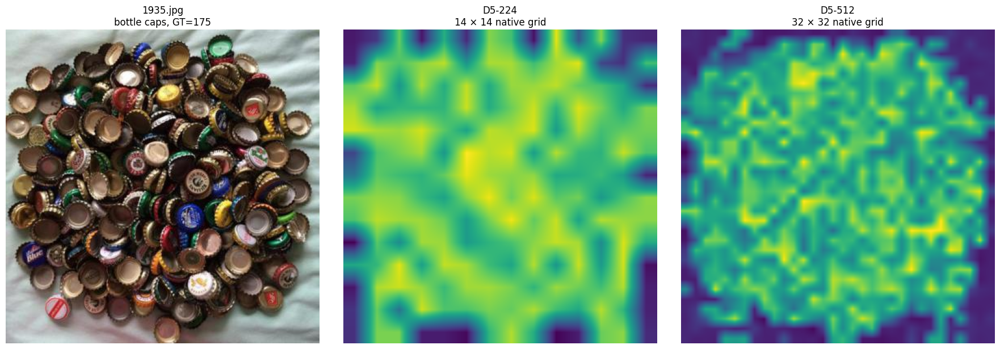

In [99]:
# ============================================================
# Step 11H.9B — Visual comparison: D5-224 vs D5-512
# ============================================================

import matplotlib.pyplot as plt


fig, axes = plt.subplots(
    1,
    3,
    figsize=(18, 6),
)


# Original
axes[0].imshow(
    d5_512_image
)

axes[0].set_title(
    f"{D5_512_TEST_IMAGE_ID}\n"
    f"{d5_512_category}, GT={d5_512_gt_count}"
)

axes[0].axis("off")


# 224
im1 = axes[1].imshow(
    d5_similarity_map,
    cmap="viridis",
)

axes[1].set_title(
    "D5-224\n14 × 14 native grid"
)

axes[1].axis("off")


# 512
im2 = axes[2].imshow(
    d5_512_similarity_map,
    cmap="viridis",
)

axes[2].set_title(
    "D5-512\n32 × 32 native grid"
)

axes[2].axis("off")


plt.tight_layout()
plt.show()

In [100]:
# ============================================================
# Step 11H.9C — D5-224 vs D5-512 peaks
# using the D5-224 selected parameters
# ============================================================

D5_224_SELECTED_MIN_DISTANCE_FRAC = 0.030
D5_224_SELECTED_SCORE_THRESHOLD = 0.60


(
    d5_512_points_xy,
    d5_512_points_yx,
    d5_512_min_distance_px,
) = extract_reference_points(
    d5_512_similarity_map,
    min_distance_frac=
        D5_224_SELECTED_MIN_DISTANCE_FRAC,
    score_threshold=
        D5_224_SELECTED_SCORE_THRESHOLD,
    valid_mask=None,
)


# Recreate 224 points using same settings
(
    d5_224_selected_points_xy,
    _,
    _,
) = extract_reference_points(
    d5_similarity_map,
    min_distance_frac=
        D5_224_SELECTED_MIN_DISTANCE_FRAC,
    score_threshold=
        D5_224_SELECTED_SCORE_THRESHOLD,
    valid_mask=None,
)


print(
    "GT:",
    d5_512_gt_count
)

print(
    "D5-224 points:",
    len(
        d5_224_selected_points_xy
    )
)

print(
    "D5-512 points:",
    len(
        d5_512_points_xy
    )
)

GT: 175
D5-224 points: 57
D5-512 points: 87


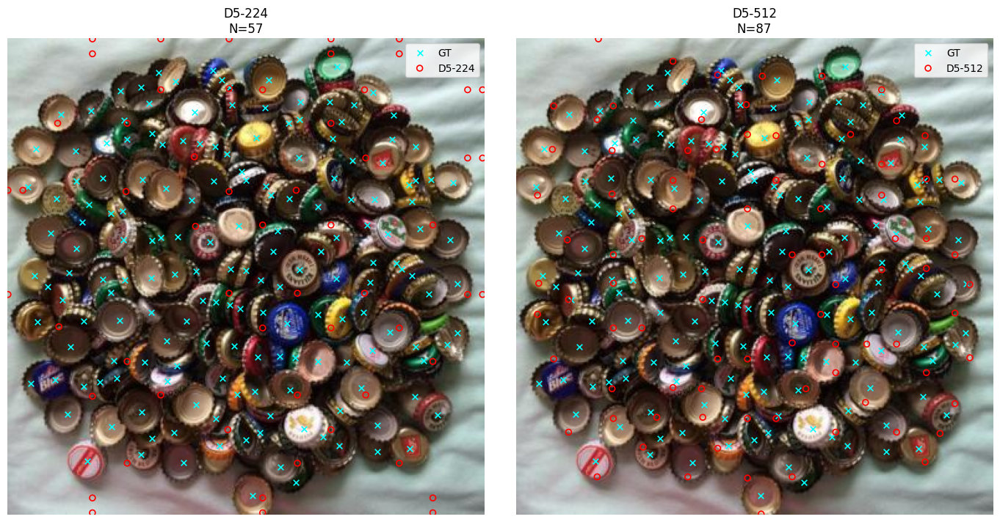

In [101]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 7),
)


# ------------------------------------------------------------
# D5-224
# ------------------------------------------------------------

axes[0].imshow(
    d5_512_image
)

axes[0].scatter(
    d5_512_gt_points_xy[:, 0],
    d5_512_gt_points_xy[:, 1],
    marker="x",
    s=30,
    c="cyan",
    linewidths=1.2,
    label="GT",
)

if len(
    d5_224_selected_points_xy
) > 0:

    axes[0].scatter(
        d5_224_selected_points_xy[:, 0],
        d5_224_selected_points_xy[:, 1],
        s=32,
        facecolors="none",
        edgecolors="red",
        linewidths=1.2,
        label="D5-224",
    )

axes[0].set_title(
    f"D5-224\n"
    f"N={len(d5_224_selected_points_xy)}"
)

axes[0].axis("off")
axes[0].legend()


# ------------------------------------------------------------
# D5-512
# ------------------------------------------------------------

axes[1].imshow(
    d5_512_image
)

axes[1].scatter(
    d5_512_gt_points_xy[:, 0],
    d5_512_gt_points_xy[:, 1],
    marker="x",
    s=30,
    c="cyan",
    linewidths=1.2,
    label="GT",
)

if len(
    d5_512_points_xy
) > 0:

    axes[1].scatter(
        d5_512_points_xy[:, 0],
        d5_512_points_xy[:, 1],
        s=32,
        facecolors="none",
        edgecolors="red",
        linewidths=1.2,
        label="D5-512",
    )

axes[1].set_title(
    f"D5-512\n"
    f"N={len(d5_512_points_xy)}"
)

axes[1].axis("off")
axes[1].legend()


plt.tight_layout()
plt.show()

In [102]:
# ============================================================
# Step 11H.10 — D5-512 full 20-configuration dev100 sweep
#
# Same:
#   model              = CS-ViT-B/16
#   text prompting     = unchanged
#   peak parameter grid= unchanged
#   dev100             = unchanged
#
# Only change vs D5-224:
#   input resolution = 512 x 512
# ============================================================

import time
import gc

import numpy as np
import pandas as pd
import torch

from PIL import Image
from tqdm.auto import tqdm


D5_512_MIN_DISTANCE_FRACS = list(
    D1_MIN_DISTANCE_FRACS
)

D5_512_SCORE_THRESHOLDS = list(
    D1_SCORE_THRESHOLDS
)


d5_512_prediction_rows = []

start_time = time.perf_counter()


# ------------------------------------------------------------
# Reuse text cache where possible
# ------------------------------------------------------------

d5_512_text_feature_cache = {}


def get_d5_512_text_feature(category):

    if category not in d5_512_text_feature_cache:

        with torch.inference_mode():

            text_feature = (
                clip.encode_text_with_prompt_ensemble(
                    d5_model,
                    [category],
                    D5_DEVICE,
                )
            )

        d5_512_text_feature_cache[
            category
        ] = text_feature

    return d5_512_text_feature_cache[
        category
    ]


# ------------------------------------------------------------
# Main dev100 sweep
# ------------------------------------------------------------

for _, row in tqdm(
    fsc147_dev_100_df.iterrows(),
    total=len(fsc147_dev_100_df),
    desc="Generating D5-512 dev100 predictions",
):

    # --------------------------------------------------------
    # Metadata
    # --------------------------------------------------------

    image_id = row["image_id"]
    category = row["category"]

    dataset_index = int(
        row["dataset_index"]
    )

    gt_count = int(
        row["gt_count"]
    )

    density_stratum = row[
        "density_stratum"
    ]


    # --------------------------------------------------------
    # FSC-147 sample + GT
    # --------------------------------------------------------

    sample = fsc147_val_dataset[
        dataset_index
    ]

    gt_points_xy = np.asarray(
        get_gt_points(
            sample,
            category,
        ),
        dtype=np.float32,
    ).reshape(-1, 2)

    assert len(gt_points_xy) == gt_count


    width = int(
        sample["width"]
    )

    height = int(
        sample["height"]
    )

    short_side = min(
        width,
        height,
    )


    # --------------------------------------------------------
    # Load original image
    # --------------------------------------------------------

    image_path = (
        FSC147_IMAGE_DIR
        / image_id
    )

    pil_image = Image.open(
        image_path
    ).convert("RGB")


    # --------------------------------------------------------
    # 512 preprocessing
    # --------------------------------------------------------

    image_tensor = (
        d5_preprocess_512(
            pil_image
        )
        .unsqueeze(0)
        .to(
            D5_DEVICE
        )
    )


    # --------------------------------------------------------
    # Text feature
    # --------------------------------------------------------

    target_text_feature = (
        get_d5_512_text_feature(
            category
        )
    )


    # --------------------------------------------------------
    # CLIP-Surgery inference
    # --------------------------------------------------------

    with torch.inference_mode():

        image_features = (
            d5_model.encode_image(
                image_tensor
            )
        )

        image_features = (
            image_features
            /
            image_features.norm(
                dim=-1,
                keepdim=True,
            )
        )


        similarity = (
            clip.clip_feature_surgery(
                image_features,
                target_text_feature,
                d5_redundant_features_global,
            )
        )


        similarity_map_t = (
            clip.get_similarity_map(
                similarity[:, 1:, :],
                (
                    height,
                    width,
                ),
            )
        )


    similarity_map = (
        similarity_map_t[
            0,
            :,
            :,
            0,
        ]
        .detach()
        .float()
        .cpu()
        .numpy()
    )


    assert (
        similarity_map.shape
        ==
        (
            height,
            width,
        )
    )


    # --------------------------------------------------------
    # 20 peak configurations
    # --------------------------------------------------------

    for min_distance_frac in (
        D5_512_MIN_DISTANCE_FRACS
    ):

        for score_threshold in (
            D5_512_SCORE_THRESHOLDS
        ):

            (
                points_xy,
                _,
                min_distance_px,
            ) = extract_reference_points(
                similarity_map,
                min_distance_frac=
                    min_distance_frac,
                score_threshold=
                    score_threshold,
                valid_mask=None,
            )


            pred_count = len(
                points_xy
            )


            d5_512_prediction_rows.append(
                {
                    "image_id":
                        image_id,

                    "dataset_index":
                        dataset_index,

                    "category":
                        category,

                    "density_stratum":
                        density_stratum,

                    "width":
                        width,

                    "height":
                        height,

                    "short_side":
                        short_side,

                    "gt_count":
                        gt_count,

                    "min_distance_frac":
                        min_distance_frac,

                    "min_distance_px":
                        min_distance_px,

                    "score_threshold":
                        score_threshold,

                    "pred_count":
                        pred_count,

                    "count_error":
                        pred_count
                        - gt_count,

                    "pred_points_xy":
                        points_xy,

                    "gt_points_xy":
                        gt_points_xy,
                }
            )


    # --------------------------------------------------------
    # Cleanup
    # --------------------------------------------------------

    del image_tensor
    del image_features
    del similarity
    del similarity_map_t

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


# ------------------------------------------------------------
# DataFrame
# ------------------------------------------------------------

d5_512_predictions_df = pd.DataFrame(
    d5_512_prediction_rows
)


runtime = (
    time.perf_counter()
    - start_time
)


expected_rows = (
    len(fsc147_dev_100_df)
    * len(D5_512_MIN_DISTANCE_FRACS)
    * len(D5_512_SCORE_THRESHOLDS)
)


assert (
    len(d5_512_predictions_df)
    == expected_rows
)

assert (
    d5_512_predictions_df[
        "image_id"
    ].nunique()
    == 100
)


print(
    "D5-512 prediction rows:",
    len(d5_512_predictions_df)
)

print(
    "Expected rows:",
    expected_rows
)

print(
    "Unique images:",
    d5_512_predictions_df[
        "image_id"
    ].nunique()
)

print(
    "Cached categories:",
    len(
        d5_512_text_feature_cache
    )
)

print(
    f"Runtime: {runtime:.2f} s"
)


display(
    d5_512_predictions_df[
        [
            "image_id",
            "density_stratum",
            "gt_count",

            "min_distance_frac",
            "min_distance_px",
            "score_threshold",

            "pred_count",
            "count_error",
        ]
    ]
    .head(20)
)

Generating D5-512 dev100 predictions:   0%|          | 0/100 [00:00<?, ?it/s]

D5-512 prediction rows: 2000
Expected rows: 2000
Unique images: 100
Cached categories: 21
Runtime: 92.68 s


,image_id,density_stratum,gt_count,min_distance_frac,min_distance_px,score_threshold,pred_count,count_error
0,3873.jpg,S1_0_20,7,0.005,2,0.3,165,158
1,3873.jpg,S1_0_20,7,0.005,2,0.4,163,156
2,3873.jpg,S1_0_20,7,0.005,2,0.5,144,137
3,3873.jpg,S1_0_20,7,0.005,2,0.6,107,100
4,3873.jpg,S1_0_20,7,0.005,2,0.7,87,80
5,3873.jpg,S1_0_20,7,0.010,4,0.3,147,140
6,3873.jpg,S1_0_20,7,0.010,4,0.4,146,139
7,3873.jpg,S1_0_20,7,0.010,4,0.5,130,123
8,3873.jpg,S1_0_20,7,0.010,4,0.6,98,91
9,3873.jpg,S1_0_20,7,0.010,4,0.7,81,74


In [103]:
# ============================================================
# Step 11H.11 — Full D5-512 one-to-one matching on dev100
# ============================================================

import time
import numpy as np
import pandas as pd

from tqdm.auto import tqdm


d5_512_match_rows = []

start_time = time.perf_counter()


for _, row in tqdm(
    d5_512_predictions_df.iterrows(),
    total=len(d5_512_predictions_df),
    desc="D5-512 one-to-one matching",
):

    short_side = int(
        row["short_side"]
    )

    pred_xy = row[
        "pred_points_xy"
    ]

    gt_xy = row[
        "gt_points_xy"
    ]


    for radius_frac in D1_MATCH_RADII_FRACS:

        radius_px = max(
            1,
            int(
                round(
                    radius_frac
                    * short_side
                )
            ),
        )

        result = (
            match_points_one_to_one_efficient(
                pred_xy=pred_xy,
                gt_xy=gt_xy,
                radius_px=radius_px,
            )
        )


        tp = int(
            result["tp"]
        )

        fp = int(
            result["fp"]
        )

        fn = int(
            result["fn"]
        )


        precision = (
            tp / (tp + fp)
            if (tp + fp) > 0
            else 0.0
        )

        recall = (
            tp / (tp + fn)
            if (tp + fn) > 0
            else 0.0
        )

        f1 = (
            2.0
            * precision
            * recall
            / (precision + recall)
            if (precision + recall) > 0
            else 0.0
        )


        distances = np.asarray(
            result["distances"],
            dtype=np.float32,
        )

        if len(distances) > 0:

            mean_dist_px = float(
                np.mean(distances)
            )

            median_dist_px = float(
                np.median(distances)
            )

        else:

            mean_dist_px = np.nan
            median_dist_px = np.nan


        d5_512_match_rows.append(
            {
                "image_id":
                    row["image_id"],

                "category":
                    row["category"],

                "density_stratum":
                    row["density_stratum"],

                "gt_count":
                    int(row["gt_count"]),

                "pred_count":
                    int(row["pred_count"]),

                "count_error":
                    int(row["count_error"]),

                "min_distance_frac":
                    row["min_distance_frac"],

                "min_distance_px":
                    row["min_distance_px"],

                "score_threshold":
                    row["score_threshold"],

                "radius_frac":
                    radius_frac,

                "radius_px":
                    radius_px,

                "tp":
                    tp,

                "fp":
                    fp,

                "fn":
                    fn,

                "precision":
                    precision,

                "recall":
                    recall,

                "f1":
                    f1,

                "mean_match_dist_px":
                    mean_dist_px,

                "median_match_dist_px":
                    median_dist_px,
            }
        )


d5_512_match_results_df = pd.DataFrame(
    d5_512_match_rows
)


runtime = (
    time.perf_counter()
    - start_time
)


expected_rows = (
    len(d5_512_predictions_df)
    * len(D1_MATCH_RADII_FRACS)
)


assert (
    len(d5_512_match_results_df)
    == expected_rows
)


print(
    "D5-512 matching rows:",
    len(d5_512_match_results_df)
)

print(
    "Expected rows:",
    expected_rows
)

print(
    f"Runtime: {runtime:.2f} s"
)


display(
    d5_512_match_results_df[
        [
            "image_id",
            "density_stratum",
            "gt_count",
            "pred_count",

            "min_distance_frac",
            "score_threshold",

            "radius_frac",
            "radius_px",

            "tp",
            "fp",
            "fn",

            "precision",
            "recall",
            "f1",

            "median_match_dist_px",
        ]
    ]
    .head(20)
    .round(4)
)

D5-512 one-to-one matching:   0%|          | 0/2000 [00:00<?, ?it/s]

D5-512 matching rows: 8000
Expected rows: 8000
Runtime: 3.95 s


,image_id,density_stratum,gt_count,pred_count,min_distance_frac,score_threshold,radius_frac,radius_px,tp,fp,fn,precision,recall,f1,median_match_dist_px
0,3873.jpg,S1_0_20,7,165,0.005,0.3,0.01,4,0,165,7,0.0000,0.0000,0.0000,NaN
1,3873.jpg,S1_0_20,7,165,0.005,0.3,0.02,8,2,163,5,0.0121,0.2857,0.0233,6.5080
2,3873.jpg,S1_0_20,7,165,0.005,0.3,0.03,12,4,161,3,0.0242,0.5714,0.0465,8.3535
3,3873.jpg,S1_0_20,7,165,0.005,0.3,0.05,19,6,159,1,0.0364,0.8571,0.0698,9.4425
4,3873.jpg,S1_0_20,7,163,0.005,0.4,0.01,4,0,163,7,0.0000,0.0000,0.0000,NaN
5,3873.jpg,S1_0_20,7,163,0.005,0.4,0.02,8,2,161,5,0.0123,0.2857,0.0235,6.5080
6,3873.jpg,S1_0_20,7,163,0.005,0.4,0.03,12,4,159,3,0.0245,0.5714,0.0471,8.3535
7,3873.jpg,S1_0_20,7,163,0.005,0.4,0.05,19,6,157,1,0.0368,0.8571,0.0706,9.4425
8,3873.jpg,S1_0_20,7,144,0.005,0.5,0.01,4,0,144,7,0.0000,0.0000,0.0000,NaN
9,3873.jpg,S1_0_20,7,144,0.005,0.5,0.02,8,2,142,5,0.0139,0.2857,0.0265,6.5080


In [104]:
# ============================================================
# Step 11H.12 — Aggregate and rank D5-512 configurations
# ============================================================

d5_512_summary_rows = []


for (
    min_distance_frac,
    score_threshold,
    radius_frac,
), group in d5_512_match_results_df.groupby(
    [
        "min_distance_frac",
        "score_threshold",
        "radius_frac",
    ]
):

    # --------------------------------------------------------
    # Macro metrics
    # --------------------------------------------------------

    macro_precision = float(
        group["precision"].mean()
    )

    macro_recall = float(
        group["recall"].mean()
    )

    macro_f1 = float(
        group["f1"].mean()
    )


    # --------------------------------------------------------
    # Micro metrics
    # --------------------------------------------------------

    total_tp = int(
        group["tp"].sum()
    )

    total_fp = int(
        group["fp"].sum()
    )

    total_fn = int(
        group["fn"].sum()
    )

    micro_precision = (
        total_tp
        / (total_tp + total_fp)
        if (total_tp + total_fp) > 0
        else 0.0
    )

    micro_recall = (
        total_tp
        / (total_tp + total_fn)
        if (total_tp + total_fn) > 0
        else 0.0
    )

    micro_f1 = (
        2.0
        * micro_precision
        * micro_recall
        / (
            micro_precision
            + micro_recall
        )
        if (
            micro_precision
            + micro_recall
        ) > 0
        else 0.0
    )


    # --------------------------------------------------------
    # Localisation distance
    # --------------------------------------------------------

    valid_dist = (
        (group["tp"] > 0)
        &
        group[
            "mean_match_dist_px"
        ].notna()
    )

    if valid_dist.any():

        weighted_mean_dist_px = float(
            np.average(
                group.loc[
                    valid_dist,
                    "mean_match_dist_px",
                ],
                weights=group.loc[
                    valid_dist,
                    "tp",
                ],
            )
        )

    else:

        weighted_mean_dist_px = np.nan


    d5_512_summary_rows.append(
        {
            "min_distance_frac":
                min_distance_frac,

            "score_threshold":
                score_threshold,

            "radius_frac":
                radius_frac,

            "macro_precision":
                macro_precision,

            "macro_recall":
                macro_recall,

            "macro_f1":
                macro_f1,

            "micro_precision":
                micro_precision,

            "micro_recall":
                micro_recall,

            "micro_f1":
                micro_f1,

            "weighted_mean_dist_px":
                weighted_mean_dist_px,

            "total_tp":
                total_tp,

            "total_fp":
                total_fp,

            "total_fn":
                total_fn,
        }
    )


d5_512_point_quality_long = pd.DataFrame(
    d5_512_summary_rows
)


# ------------------------------------------------------------
# Proxy-count metrics for each configuration
# ------------------------------------------------------------

proxy_rows = []


for (
    min_distance_frac,
    score_threshold,
), group in d5_512_predictions_df.groupby(
    [
        "min_distance_frac",
        "score_threshold",
    ]
):

    errors = (
        group["pred_count"].to_numpy()
        -
        group["gt_count"].to_numpy()
    )

    proxy_rows.append(
        {
            "min_distance_frac":
                min_distance_frac,

            "score_threshold":
                score_threshold,

            "mean_signed_error":
                float(
                    np.mean(errors)
                ),

            "proxy_mae":
                float(
                    np.mean(
                        np.abs(errors)
                    )
                ),

            "proxy_rmse":
                float(
                    np.sqrt(
                        np.mean(
                            errors ** 2
                        )
                    )
                ),
        }
    )


d5_512_proxy_summary = pd.DataFrame(
    proxy_rows
)


# ------------------------------------------------------------
# Build 20-row comparison table
# ------------------------------------------------------------

d5_512_comparison = (
    d5_512_proxy_summary.copy()
)


for radius_frac in D1_MATCH_RADII_FRACS:

    radius_pct = int(
        round(
            radius_frac
            * 100
        )
    )

    radius_df = (
        d5_512_point_quality_long[
            np.isclose(
                d5_512_point_quality_long[
                    "radius_frac"
                ],
                radius_frac,
            )
        ][
            [
                "min_distance_frac",
                "score_threshold",
                "macro_precision",
                "macro_recall",
                "macro_f1",
                "micro_f1",
                "weighted_mean_dist_px",
            ]
        ]
        .copy()
    )


    radius_df = radius_df.rename(
        columns={
            "macro_precision":
                f"macro_P@{radius_pct}%",

            "macro_recall":
                f"macro_R@{radius_pct}%",

            "macro_f1":
                f"macro_F1@{radius_pct}%",

            "micro_f1":
                f"micro_F1@{radius_pct}%",

            "weighted_mean_dist_px":
                f"match_dist@{radius_pct}%_px",
        }
    )


    d5_512_comparison = (
        d5_512_comparison
        .merge(
            radius_df,
            on=[
                "min_distance_frac",
                "score_threshold",
            ],
            how="left",
        )
    )


# ------------------------------------------------------------
# Rank using same pre-defined criterion
# ------------------------------------------------------------

d5_512_comparison = (
    d5_512_comparison
    .sort_values(
        [
            "macro_F1@3%",
            "macro_F1@2%",
            "macro_F1@5%",
        ],
        ascending=[
            False,
            False,
            False,
        ],
    )
    .reset_index(drop=True)
)


d5_512_comparison.insert(
    0,
    "rank",
    np.arange(
        1,
        len(d5_512_comparison) + 1,
    ),
)


print(
    "Number of D5-512 configurations:",
    len(d5_512_comparison)
)

print(
    "Primary ranking metric: macro F1 @ 3%"
)


display(
    d5_512_comparison.round(4)
)

Number of D5-512 configurations: 20
Primary ranking metric: macro F1 @ 3%


,rank,min_distance_frac,score_threshold,mean_signed_error,proxy_mae,proxy_rmse,macro_P@1%,macro_R@1%,macro_F1@1%,micro_F1@1%,...,macro_P@3%,macro_R@3%,macro_F1@3%,micro_F1@3%,match_dist@3%_px,macro_P@5%,macro_R@5%,macro_F1@5%,micro_F1@5%,match_dist@5%_px
0,1,0.020,0.7,-26.83,90.01,247.5932,0.0848,0.0694,0.0590,0.0656,...,0.3097,0.3631,0.2703,0.2437,6.2327,0.4295,0.5886,0.4047,0.3434,8.9488
1,2,0.020,0.6,-17.11,95.63,247.1343,0.0816,0.0709,0.0577,0.0647,...,0.2961,0.3828,0.2685,0.2446,6.2758,0.4085,0.6215,0.4013,0.3465,8.9934
2,3,0.010,0.7,-17.17,94.03,245.2258,0.0819,0.0726,0.0588,0.0673,...,0.2925,0.3804,0.2657,0.2444,6.1998,0.4046,0.6068,0.3942,0.3437,8.9205
3,4,0.020,0.5,-8.71,99.95,245.8875,0.0774,0.0719,0.0566,0.0629,...,0.2822,0.3933,0.2637,0.2417,6.3263,0.3893,0.6439,0.3952,0.3473,9.1144
4,5,0.030,0.7,-40.05,85.79,250.9361,0.0930,0.0612,0.0575,0.0620,...,0.3274,0.3175,0.2637,0.2262,6.2276,0.4570,0.5323,0.4026,0.3227,8.9964
5,6,0.010,0.6,-3.76,103.24,245.6609,0.0785,0.0746,0.0575,0.0662,...,0.2784,0.4038,0.2631,0.2437,6.2449,0.3811,0.6440,0.3881,0.3437,8.9534
6,7,0.030,0.6,-33.24,88.62,250.3412,0.0894,0.0624,0.0563,0.0612,...,0.3142,0.3307,0.2621,0.2268,6.2640,0.4383,0.5588,0.4015,0.3267,9.0748
7,8,0.030,0.5,-27.01,90.85,248.7258,0.0846,0.0632,0.0552,0.0599,...,0.2997,0.3398,0.2579,0.2257,6.3142,0.4177,0.5772,0.3955,0.3297,9.1962
8,9,0.010,0.5,7.96,109.50,244.7772,0.0740,0.0760,0.0566,0.0640,...,0.2635,0.4169,0.2578,0.2386,6.2893,0.3598,0.6689,0.3800,0.3411,9.0597
9,10,0.005,0.7,-6.60,99.86,243.7145,0.0766,0.0731,0.0565,0.0646,...,0.2719,0.3840,0.2546,0.2362,6.2082,0.3751,0.6108,0.3767,0.3326,8.9563


In [105]:
# ============================================================
# Step 11H.13 — D1 vs D5-224 vs D5-512
# ============================================================

d5_224_best = (
    d5_comparison.iloc[0]
)

d5_512_best = (
    d5_512_comparison.iloc[0]
)


comparison_3way = pd.DataFrame(
    [
        {
            "method":
                "D1_SAN",

            "resolution":
                "SAN",

            "min_distance_frac":
                0.020,

            "score_threshold":
                0.30,

            "macro_P@3%":
                0.3770,

            "macro_R@3%":
                0.4603,

            "macro_F1@3%":
                0.3452,
        },

        {
            "method":
                "D5_CLIP_Surgery",

            "resolution":
                224,

            "min_distance_frac":
                float(
                    d5_224_best[
                        "min_distance_frac"
                    ]
                ),

            "score_threshold":
                float(
                    d5_224_best[
                        "score_threshold"
                    ]
                ),

            "macro_P@3%":
                float(
                    d5_224_best[
                        "macro_P@3%"
                    ]
                ),

            "macro_R@3%":
                float(
                    d5_224_best[
                        "macro_R@3%"
                    ]
                ),

            "macro_F1@3%":
                float(
                    d5_224_best[
                        "macro_F1@3%"
                    ]
                ),
        },

        {
            "method":
                "D5_CLIP_Surgery",

            "resolution":
                512,

            "min_distance_frac":
                float(
                    d5_512_best[
                        "min_distance_frac"
                    ]
                ),

            "score_threshold":
                float(
                    d5_512_best[
                        "score_threshold"
                    ]
                ),

            "macro_P@3%":
                float(
                    d5_512_best[
                        "macro_P@3%"
                    ]
                ),

            "macro_R@3%":
                float(
                    d5_512_best[
                        "macro_R@3%"
                    ]
                ),

            "macro_F1@3%":
                float(
                    d5_512_best[
                        "macro_F1@3%"
                    ]
                ),
        },
    ]
)


comparison_3way[
    "delta_F1_vs_D1"
] = (
    comparison_3way[
        "macro_F1@3%"
    ]
    -
    0.3452
)


display(
    comparison_3way.round(4)
)

,method,resolution,min_distance_frac,score_threshold,macro_P@3%,macro_R@3%,macro_F1@3%,delta_F1_vs_D1
0,D1_SAN,SAN,0.02,0.3,0.3770,0.4603,0.3452,0.0000
1,D5_CLIP_Surgery,224,0.03,0.6,0.2323,0.1049,0.1176,-0.2276
2,D5_CLIP_Surgery,512,0.02,0.7,0.3097,0.3631,0.2703,-0.0749


In [106]:
# ============================================================
# Step 11H.14 — Density-stratified evaluation:
# D5-224 vs D5-512
#
# Primary matching radius = 3%
# ============================================================

import numpy as np
import pandas as pd


D5_PRIMARY_RADIUS_FRAC = 0.03

D5_224_SELECTED_MIN_DISTANCE_FRAC = 0.030
D5_224_SELECTED_SCORE_THRESHOLD = 0.60

D5_512_SELECTED_MIN_DISTANCE_FRAC = 0.020
D5_512_SELECTED_SCORE_THRESHOLD = 0.70


# ------------------------------------------------------------
# 1. Extract selected D5-224 rows
# ------------------------------------------------------------

d5_224_selected = (
    d5_match_results_df[
        np.isclose(
            d5_match_results_df["min_distance_frac"],
            D5_224_SELECTED_MIN_DISTANCE_FRAC,
        )
        &
        np.isclose(
            d5_match_results_df["score_threshold"],
            D5_224_SELECTED_SCORE_THRESHOLD,
        )
        &
        np.isclose(
            d5_match_results_df["radius_frac"],
            D5_PRIMARY_RADIUS_FRAC,
        )
    ]
    .copy()
)


# ------------------------------------------------------------
# 2. Extract selected D5-512 rows
# ------------------------------------------------------------

d5_512_selected = (
    d5_512_match_results_df[
        np.isclose(
            d5_512_match_results_df["min_distance_frac"],
            D5_512_SELECTED_MIN_DISTANCE_FRAC,
        )
        &
        np.isclose(
            d5_512_match_results_df["score_threshold"],
            D5_512_SELECTED_SCORE_THRESHOLD,
        )
        &
        np.isclose(
            d5_512_match_results_df["radius_frac"],
            D5_PRIMARY_RADIUS_FRAC,
        )
    ]
    .copy()
)


# ------------------------------------------------------------
# Sanity checks
# ------------------------------------------------------------

assert len(d5_224_selected) == 100
assert len(d5_512_selected) == 100

assert (
    d5_224_selected["image_id"].nunique()
    == 100
)

assert (
    d5_512_selected["image_id"].nunique()
    == 100
)


print(
    "D5-224 selected images:",
    len(d5_224_selected)
)

print(
    "D5-512 selected images:",
    len(d5_512_selected)
)

D5-224 selected images: 100
D5-512 selected images: 100


In [107]:
# ============================================================
# Step 11H.14B — Common density aggregation helper
# ============================================================

def summarise_density_point_results(
    selected_df,
    method_name,
):

    rows = []


    for density_stratum, group in (
        selected_df.groupby(
            "density_stratum"
        )
    ):

        # ----------------------------------------------------
        # Basic counts
        # ----------------------------------------------------

        n_images = len(group)

        total_gt = int(
            group["gt_count"].sum()
        )

        total_pred = int(
            group["pred_count"].sum()
        )

        mean_gt = float(
            group["gt_count"].mean()
        )

        mean_pred = float(
            group["pred_count"].mean()
        )


        # ----------------------------------------------------
        # Proxy-count behaviour
        # ----------------------------------------------------

        errors = (
            group["pred_count"].to_numpy()
            -
            group["gt_count"].to_numpy()
        )

        mean_signed_error = float(
            np.mean(errors)
        )

        proxy_mae = float(
            np.mean(
                np.abs(errors)
            )
        )

        proxy_rmse = float(
            np.sqrt(
                np.mean(
                    errors ** 2
                )
            )
        )


        # ----------------------------------------------------
        # Macro point-quality metrics
        # ----------------------------------------------------

        macro_precision = float(
            group["precision"].mean()
        )

        macro_recall = float(
            group["recall"].mean()
        )

        macro_f1 = float(
            group["f1"].mean()
        )


        # ----------------------------------------------------
        # Micro metrics
        # ----------------------------------------------------

        total_tp = int(
            group["tp"].sum()
        )

        total_fp = int(
            group["fp"].sum()
        )

        total_fn = int(
            group["fn"].sum()
        )

        micro_precision = (
            total_tp
            / (total_tp + total_fp)
            if (total_tp + total_fp) > 0
            else 0.0
        )

        micro_recall = (
            total_tp
            / (total_tp + total_fn)
            if (total_tp + total_fn) > 0
            else 0.0
        )

        micro_f1 = (
            2.0
            * micro_precision
            * micro_recall
            / (
                micro_precision
                + micro_recall
            )
            if (
                micro_precision
                + micro_recall
            ) > 0
            else 0.0
        )


        # ----------------------------------------------------
        # Matched localisation distance
        # ----------------------------------------------------

        valid_dist = (
            (group["tp"] > 0)
            &
            group[
                "mean_match_dist_px"
            ].notna()
        )

        if valid_dist.any():

            weighted_mean_dist_px = float(
                np.average(
                    group.loc[
                        valid_dist,
                        "mean_match_dist_px",
                    ],
                    weights=group.loc[
                        valid_dist,
                        "tp",
                    ],
                )
            )

        else:

            weighted_mean_dist_px = np.nan


        rows.append(
            {
                "method":
                    method_name,

                "density_stratum":
                    density_stratum,

                "n_images":
                    n_images,

                "total_gt":
                    total_gt,

                "total_pred":
                    total_pred,

                "mean_gt":
                    mean_gt,

                "mean_pred":
                    mean_pred,

                "mean_signed_error":
                    mean_signed_error,

                "proxy_mae":
                    proxy_mae,

                "proxy_rmse":
                    proxy_rmse,

                "macro_precision":
                    macro_precision,

                "macro_recall":
                    macro_recall,

                "macro_f1":
                    macro_f1,

                "micro_precision":
                    micro_precision,

                "micro_recall":
                    micro_recall,

                "micro_f1":
                    micro_f1,

                "weighted_mean_dist_px":
                    weighted_mean_dist_px,
            }
        )


    result = pd.DataFrame(
        rows
    )


    # Sort S1 -> S6
    result["_order"] = (
        result[
            "density_stratum"
        ]
        .str.extract(
            r"S(\d+)"
        )[0]
        .astype(int)
    )

    result = (
        result
        .sort_values("_order")
        .drop(columns="_order")
        .reset_index(drop=True)
    )

    return result

In [108]:
# ============================================================
# Step 11H.14C — Produce D5 density summaries
# ============================================================

d5_224_density_summary = (
    summarise_density_point_results(
        d5_224_selected,
        "D5_224",
    )
)

d5_512_density_summary = (
    summarise_density_point_results(
        d5_512_selected,
        "D5_512",
    )
)


print(
    "D5-224 density results:"
)

display(
    d5_224_density_summary.round(4)
)


print(
    "\nD5-512 density results:"
)

display(
    d5_512_density_summary.round(4)
)

D5-224 density results:


,method,density_stratum,n_images,total_gt,total_pred,mean_gt,mean_pred,mean_signed_error,proxy_mae,proxy_rmse,macro_precision,macro_recall,macro_f1,micro_precision,micro_recall,micro_f1,weighted_mean_dist_px
0,D5_224,S1_0_20,20,195,484,9.75,24.20,14.45,15.25,20.3015,0.0664,0.0791,0.0667,0.0331,0.0821,0.0471,7.7104
1,D5_224,S2_20_40,20,320,552,16.00,27.60,11.60,14.30,19.4962,0.1345,0.1381,0.1276,0.0761,0.1312,0.0963,7.7152
2,D5_224,S3_40_60,20,537,503,26.85,25.15,-1.70,12.90,15.7987,0.2178,0.1281,0.1455,0.1352,0.1266,0.1308,8.5230
3,D5_224,S4_60_80,20,1096,675,54.80,33.75,-21.05,25.45,29.8856,0.2981,0.1139,0.1495,0.1852,0.1141,0.1412,7.9780
4,D5_224,S5_80_95,10,1211,505,121.10,50.50,-70.60,70.60,74.2832,0.2895,0.0862,0.1199,0.2198,0.0917,0.1294,7.8242
5,D5_224,S6_95_100,10,6686,417,668.60,41.70,-626.90,626.90,831.0899,0.5999,0.0448,0.0775,0.5036,0.0314,0.0591,6.2774



D5-512 density results:


,method,density_stratum,n_images,total_gt,total_pred,mean_gt,mean_pred,mean_signed_error,proxy_mae,proxy_rmse,macro_precision,macro_recall,macro_f1,micro_precision,micro_recall,micro_f1,weighted_mean_dist_px
0,D5_512,S1_0_20,20,195,1151,9.75,57.55,47.80,47.80,55.2359,0.0871,0.3440,0.1293,0.0565,0.3333,0.0966,7.1313
1,D5_512,S2_20_40,20,320,1158,16.00,57.90,41.90,41.90,57.1673,0.1825,0.4091,0.2376,0.1105,0.4000,0.1732,7.2416
2,D5_512,S3_40_60,20,537,1112,26.85,55.60,28.75,34.25,45.7116,0.2451,0.3718,0.2702,0.1763,0.3650,0.2377,6.9974
3,D5_512,S4_60_80,20,1096,1473,54.80,73.65,18.85,32.35,52.7887,0.4560,0.4475,0.4296,0.3394,0.4562,0.3893,6.4957
4,D5_512,S5_80_95,10,1211,1264,121.10,126.40,5.30,39.30,48.0364,0.4021,0.3165,0.3247,0.3054,0.3187,0.3119,6.9067
5,D5_512,S6_95_100,10,6686,1204,668.60,120.40,-548.20,548.20,767.0241,0.7532,0.1693,0.2452,0.7027,0.1265,0.2144,5.3708


In [109]:
# ============================================================
# Step 11H.15 — Density-wise comparison:
# D1 vs D5-224 vs D5-512
# ============================================================

d1_density_compare = (
    d1_density_summary[
        [
            "density_stratum",
            "mean_gt",
            "mean_pred",
            "macro_precision",
            "macro_recall",
            "macro_f1",
        ]
    ]
    .rename(
        columns={
            "mean_pred":
                "D1_mean_pred",

            "macro_precision":
                "D1_P",

            "macro_recall":
                "D1_R",

            "macro_f1":
                "D1_F1",
        }
    )
)


d5_224_density_compare = (
    d5_224_density_summary[
        [
            "density_stratum",
            "mean_pred",
            "macro_precision",
            "macro_recall",
            "macro_f1",
        ]
    ]
    .rename(
        columns={
            "mean_pred":
                "D5_224_mean_pred",

            "macro_precision":
                "D5_224_P",

            "macro_recall":
                "D5_224_R",

            "macro_f1":
                "D5_224_F1",
        }
    )
)


d5_512_density_compare = (
    d5_512_density_summary[
        [
            "density_stratum",
            "mean_pred",
            "macro_precision",
            "macro_recall",
            "macro_f1",
        ]
    ]
    .rename(
        columns={
            "mean_pred":
                "D5_512_mean_pred",

            "macro_precision":
                "D5_512_P",

            "macro_recall":
                "D5_512_R",

            "macro_f1":
                "D5_512_F1",
        }
    )
)


d1_d5_density_comparison = (
    d1_density_compare
    .merge(
        d5_224_density_compare,
        on="density_stratum",
        how="inner",
    )
    .merge(
        d5_512_density_compare,
        on="density_stratum",
        how="inner",
    )
)


# ------------------------------------------------------------
# Improvements from higher CLIP resolution
# ------------------------------------------------------------

d1_d5_density_comparison[
    "delta_512_vs_224"
] = (
    d1_d5_density_comparison[
        "D5_512_F1"
    ]
    -
    d1_d5_density_comparison[
        "D5_224_F1"
    ]
)


# ------------------------------------------------------------
# Remaining gap from D1
# ------------------------------------------------------------

d1_d5_density_comparison[
    "delta_512_vs_D1"
] = (
    d1_d5_density_comparison[
        "D5_512_F1"
    ]
    -
    d1_d5_density_comparison[
        "D1_F1"
    ]
)


display(
    d1_d5_density_comparison.round(4)
)

,density_stratum,mean_gt,D1_mean_pred,D1_P,D1_R,D1_F1,D5_224_mean_pred,D5_224_P,D5_224_R,D5_224_F1,D5_512_mean_pred,D5_512_P,D5_512_R,D5_512_F1,delta_512_vs_224,delta_512_vs_D1
0,S1_0_20,9.75,54.10,0.1611,0.4509,0.2043,24.20,0.0664,0.0791,0.0667,57.55,0.0871,0.3440,0.1293,0.0626,-0.0750
1,S2_20_40,16.00,61.65,0.3147,0.5425,0.3647,27.60,0.1345,0.1381,0.1276,57.90,0.1825,0.4091,0.2376,0.1100,-0.1272
2,S3_40_60,26.85,69.50,0.3425,0.4821,0.3592,25.15,0.2178,0.1281,0.1455,55.60,0.2451,0.3718,0.2702,0.1247,-0.0890
3,S4_60_80,54.80,83.15,0.4172,0.4909,0.4241,33.75,0.2981,0.1139,0.1495,73.65,0.4560,0.4475,0.4296,0.2801,0.0054
4,S5_80_95,121.10,114.30,0.5551,0.4820,0.4976,50.50,0.2895,0.0862,0.1199,126.40,0.4021,0.3165,0.3247,0.2048,-0.1729
5,S6_95_100,668.60,114.10,0.7438,0.1884,0.2497,41.70,0.5999,0.0448,0.0775,120.40,0.7532,0.1693,0.2452,0.1677,-0.0045


In [110]:
# ============================================================
# Step 11H.16 — D5 resolution ablation: 768x768 preprocessing
# ============================================================

from torchvision import transforms
from torchvision.transforms import InterpolationMode


D5_768_RES = 768


d5_preprocess_768 = transforms.Compose(
    [
        transforms.Resize(
            (D5_768_RES, D5_768_RES),
            interpolation=InterpolationMode.BICUBIC,
        ),

        transforms.ToTensor(),

        transforms.Normalize(
            mean=D5_CLIP_MEAN,
            std=D5_CLIP_STD,
        ),
    ]
)


print(
    "D5-768 input resolution:",
    D5_768_RES,
)

D5-768 input resolution: 768


In [111]:
# ============================================================
# Step 11H.17 — D5-768 single-image sanity check
# ============================================================

import numpy as np
import torch

from PIL import Image


D5_768_TEST_IMAGE_ID = "1935.jpg"


# ------------------------------------------------------------
# Metadata
# ------------------------------------------------------------

d5_768_rows = fsc147_dev_100_df[
    fsc147_dev_100_df["image_id"]
    == D5_768_TEST_IMAGE_ID
]

assert len(d5_768_rows) == 1

d5_768_row = d5_768_rows.iloc[0]

d5_768_dataset_index = int(
    d5_768_row["dataset_index"]
)

d5_768_category = (
    d5_768_row["category"]
)

d5_768_gt_count = int(
    d5_768_row["gt_count"]
)

d5_768_density_stratum = (
    d5_768_row["density_stratum"]
)


# ------------------------------------------------------------
# GT
# ------------------------------------------------------------

d5_768_sample = fsc147_val_dataset[
    d5_768_dataset_index
]

d5_768_gt_points_xy = np.asarray(
    get_gt_points(
        d5_768_sample,
        d5_768_category,
    ),
    dtype=np.float32,
).reshape(-1, 2)

assert (
    len(d5_768_gt_points_xy)
    == d5_768_gt_count
)


# ------------------------------------------------------------
# Image
# ------------------------------------------------------------

d5_768_image_path = (
    FSC147_IMAGE_DIR
    / D5_768_TEST_IMAGE_ID
)

d5_768_image = Image.open(
    d5_768_image_path
).convert("RGB")

d5_768_W, d5_768_H = (
    d5_768_image.size
)


# ------------------------------------------------------------
# 768 preprocessing
# ------------------------------------------------------------

d5_768_tensor = (
    d5_preprocess_768(
        d5_768_image
    )
    .unsqueeze(0)
    .to(D5_DEVICE)
)


# ------------------------------------------------------------
# CLIP-Surgery inference
# ------------------------------------------------------------

with torch.inference_mode():

    d5_768_text_feature = (
        clip.encode_text_with_prompt_ensemble(
            d5_model,
            [d5_768_category],
            D5_DEVICE,
        )
    )

    d5_768_image_features = (
        d5_model.encode_image(
            d5_768_tensor
        )
    )

    d5_768_image_features = (
        d5_768_image_features
        /
        d5_768_image_features.norm(
            dim=-1,
            keepdim=True,
        )
    )

    d5_768_similarity = (
        clip.clip_feature_surgery(
            d5_768_image_features,
            d5_768_text_feature,
            d5_redundant_features_global,
        )
    )

    d5_768_similarity_map_t = (
        clip.get_similarity_map(
            d5_768_similarity[:, 1:, :],
            (
                d5_768_H,
                d5_768_W,
            ),
        )
    )


d5_768_similarity_map = (
    d5_768_similarity_map_t[
        0,
        :,
        :,
        0,
    ]
    .detach()
    .float()
    .cpu()
    .numpy()
)


# ------------------------------------------------------------
# Diagnostics
# ------------------------------------------------------------

print(
    "Image:",
    D5_768_TEST_IMAGE_ID
)

print(
    "Category:",
    d5_768_category
)

print(
    "GT count:",
    d5_768_gt_count
)

print(
    "Original image:",
    d5_768_W,
    "x",
    d5_768_H,
)

print(
    "\nCLIP input tensor:",
    tuple(
        d5_768_tensor.shape
    )
)

print(
    "Image feature shape:",
    tuple(
        d5_768_image_features.shape
    )
)

print(
    "Raw similarity shape:",
    tuple(
        d5_768_similarity.shape
    )
)

print(
    "Output map shape:",
    d5_768_similarity_map.shape
)

print(
    "\nMap range:",
    float(
        d5_768_similarity_map.min()
    ),
    "to",
    float(
        d5_768_similarity_map.max()
    ),
)

Image: 1935.jpg
Category: bottle caps
GT count: 175
Original image: 384 x 384

CLIP input tensor: (1, 3, 768, 768)
Image feature shape: (1, 2305, 512)
Raw similarity shape: (1, 2305, 1)
Output map shape: (384, 384)

Map range: 0.0035495173651725054 to 0.9383470416069031


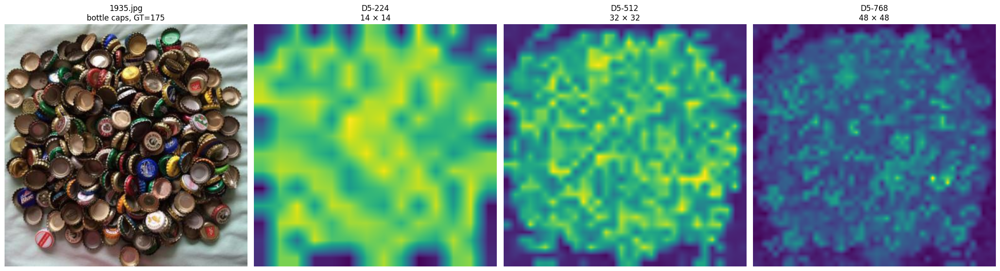

In [112]:
# ============================================================
# Step 11H.17B — Visual comparison:
# D5-224 vs D5-512 vs D5-768
# ============================================================

import matplotlib.pyplot as plt


fig, axes = plt.subplots(
    1,
    4,
    figsize=(22, 6),
)


axes[0].imshow(
    d5_768_image
)

axes[0].set_title(
    f"{D5_768_TEST_IMAGE_ID}\n"
    f"{d5_768_category}, GT={d5_768_gt_count}"
)

axes[0].axis("off")


axes[1].imshow(
    d5_similarity_map,
    cmap="viridis",
)

axes[1].set_title(
    "D5-224\n14 × 14"
)

axes[1].axis("off")


axes[2].imshow(
    d5_512_similarity_map,
    cmap="viridis",
)

axes[2].set_title(
    "D5-512\n32 × 32"
)

axes[2].axis("off")


axes[3].imshow(
    d5_768_similarity_map,
    cmap="viridis",
)

axes[3].set_title(
    "D5-768\n48 × 48"
)

axes[3].axis("off")


plt.tight_layout()
plt.show()

In [113]:
# ============================================================
# Step 11H.17C — D5-512 vs D5-768 peak comparison
# using current D5-512 selected parameters
# ============================================================

D5_512_SELECTED_MIN_DISTANCE_FRAC = 0.020
D5_512_SELECTED_SCORE_THRESHOLD = 0.70


(
    d5_768_points_xy,
    _,
    d5_768_min_distance_px,
) = extract_reference_points(
    d5_768_similarity_map,
    min_distance_frac=
        D5_512_SELECTED_MIN_DISTANCE_FRAC,
    score_threshold=
        D5_512_SELECTED_SCORE_THRESHOLD,
    valid_mask=None,
)


(
    d5_512_selected_points_xy,
    _,
    _,
) = extract_reference_points(
    d5_512_similarity_map,
    min_distance_frac=
        D5_512_SELECTED_MIN_DISTANCE_FRAC,
    score_threshold=
        D5_512_SELECTED_SCORE_THRESHOLD,
    valid_mask=None,
)


print(
    "GT:",
    d5_768_gt_count
)

print(
    "D5-512 points:",
    len(
        d5_512_selected_points_xy
    )
)

print(
    "D5-768 points:",
    len(
        d5_768_points_xy
    )
)

GT: 175
D5-512 points: 118
D5-768 points: 4


In [114]:
# ============================================================
# Step 11H.18 — D5-768 full 20-configuration dev100 sweep
# ============================================================

import time
import gc

import numpy as np
import pandas as pd
import torch

from PIL import Image
from tqdm.auto import tqdm


D5_768_MIN_DISTANCE_FRACS = list(
    D1_MIN_DISTANCE_FRACS
)

D5_768_SCORE_THRESHOLDS = list(
    D1_SCORE_THRESHOLDS
)


d5_768_prediction_rows = []

start_time = time.perf_counter()


d5_768_text_feature_cache = {}


def get_d5_768_text_feature(category):

    if category not in d5_768_text_feature_cache:

        with torch.inference_mode():

            feature = (
                clip.encode_text_with_prompt_ensemble(
                    d5_model,
                    [category],
                    D5_DEVICE,
                )
            )

        d5_768_text_feature_cache[
            category
        ] = feature

    return d5_768_text_feature_cache[
        category
    ]


for _, row in tqdm(
    fsc147_dev_100_df.iterrows(),
    total=len(fsc147_dev_100_df),
    desc="Generating D5-768 dev100 predictions",
):

    image_id = row["image_id"]
    category = row["category"]

    dataset_index = int(
        row["dataset_index"]
    )

    gt_count = int(
        row["gt_count"]
    )

    density_stratum = row[
        "density_stratum"
    ]


    sample = fsc147_val_dataset[
        dataset_index
    ]

    gt_points_xy = np.asarray(
        get_gt_points(
            sample,
            category,
        ),
        dtype=np.float32,
    ).reshape(-1, 2)

    assert len(gt_points_xy) == gt_count


    width = int(sample["width"])
    height = int(sample["height"])

    short_side = min(
        width,
        height,
    )


    image_path = (
        FSC147_IMAGE_DIR
        / image_id
    )

    pil_image = Image.open(
        image_path
    ).convert("RGB")


    image_tensor = (
        d5_preprocess_768(
            pil_image
        )
        .unsqueeze(0)
        .to(D5_DEVICE)
    )


    target_text_feature = (
        get_d5_768_text_feature(
            category
        )
    )


    with torch.inference_mode():

        image_features = (
            d5_model.encode_image(
                image_tensor
            )
        )

        image_features = (
            image_features
            /
            image_features.norm(
                dim=-1,
                keepdim=True,
            )
        )

        similarity = (
            clip.clip_feature_surgery(
                image_features,
                target_text_feature,
                d5_redundant_features_global,
            )
        )

        similarity_map_t = (
            clip.get_similarity_map(
                similarity[:, 1:, :],
                (
                    height,
                    width,
                ),
            )
        )


    similarity_map = (
        similarity_map_t[
            0,
            :,
            :,
            0,
        ]
        .detach()
        .float()
        .cpu()
        .numpy()
    )


    for min_distance_frac in (
        D5_768_MIN_DISTANCE_FRACS
    ):

        for score_threshold in (
            D5_768_SCORE_THRESHOLDS
        ):

            (
                points_xy,
                _,
                min_distance_px,
            ) = extract_reference_points(
                similarity_map,
                min_distance_frac=
                    min_distance_frac,
                score_threshold=
                    score_threshold,
                valid_mask=None,
            )


            pred_count = len(
                points_xy
            )


            d5_768_prediction_rows.append(
                {
                    "image_id":
                        image_id,

                    "dataset_index":
                        dataset_index,

                    "category":
                        category,

                    "density_stratum":
                        density_stratum,

                    "width":
                        width,

                    "height":
                        height,

                    "short_side":
                        short_side,

                    "gt_count":
                        gt_count,

                    "min_distance_frac":
                        min_distance_frac,

                    "min_distance_px":
                        min_distance_px,

                    "score_threshold":
                        score_threshold,

                    "pred_count":
                        pred_count,

                    "count_error":
                        pred_count - gt_count,

                    "pred_points_xy":
                        points_xy,

                    "gt_points_xy":
                        gt_points_xy,
                }
            )


    del image_tensor
    del image_features
    del similarity
    del similarity_map_t

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


d5_768_predictions_df = pd.DataFrame(
    d5_768_prediction_rows
)


runtime = (
    time.perf_counter()
    - start_time
)


expected_rows = (
    len(fsc147_dev_100_df)
    * len(D5_768_MIN_DISTANCE_FRACS)
    * len(D5_768_SCORE_THRESHOLDS)
)


assert (
    len(d5_768_predictions_df)
    == expected_rows
)


print(
    "D5-768 prediction rows:",
    len(d5_768_predictions_df)
)

print(
    "Expected rows:",
    expected_rows
)

print(
    "Unique images:",
    d5_768_predictions_df[
        "image_id"
    ].nunique()
)

print(
    f"Runtime: {runtime:.2f} s"
)


display(
    d5_768_predictions_df[
        [
            "image_id",
            "density_stratum",
            "gt_count",
            "min_distance_frac",
            "min_distance_px",
            "score_threshold",
            "pred_count",
            "count_error",
        ]
    ]
    .head(20)
)

Generating D5-768 dev100 predictions:   0%|          | 0/100 [00:00<?, ?it/s]

D5-768 prediction rows: 2000
Expected rows: 2000
Unique images: 100
Runtime: 120.17 s


,image_id,density_stratum,gt_count,min_distance_frac,min_distance_px,score_threshold,pred_count,count_error
0,3873.jpg,S1_0_20,7,0.005,2,0.3,318,311
1,3873.jpg,S1_0_20,7,0.005,2,0.4,303,296
2,3873.jpg,S1_0_20,7,0.005,2,0.5,227,220
3,3873.jpg,S1_0_20,7,0.005,2,0.6,199,192
4,3873.jpg,S1_0_20,7,0.005,2,0.7,168,161
5,3873.jpg,S1_0_20,7,0.010,4,0.3,269,262
6,3873.jpg,S1_0_20,7,0.010,4,0.4,257,250
7,3873.jpg,S1_0_20,7,0.010,4,0.5,197,190
8,3873.jpg,S1_0_20,7,0.010,4,0.6,174,167
9,3873.jpg,S1_0_20,7,0.010,4,0.7,147,140


In [115]:
# ============================================================
# Step 11H.19 — Expanded D5-specific parameter grid
#
# Motivation:
# Previous D5 optima reached search boundaries:
#   D5-224 -> min_distance_frac = 0.030 (upper boundary)
#   D5-512 -> score_threshold   = 0.70  (upper boundary)
#
# Therefore extend the search space before finalising D5.
# ============================================================

D5_EXPANDED_MIN_DISTANCE_FRACS = [
    0.005,
    0.010,
    0.020,
    0.030,
    0.040,
    0.050,
]

D5_EXPANDED_SCORE_THRESHOLDS = [
    0.30,
    0.40,
    0.50,
    0.60,
    0.70,
    0.80,
    0.90,
]


print(
    "Expanded D5 min-distance fractions:",
    D5_EXPANDED_MIN_DISTANCE_FRACS
)

print(
    "Expanded D5 score thresholds:",
    D5_EXPANDED_SCORE_THRESHOLDS
)

print(
    "Number of configurations:",
    len(D5_EXPANDED_MIN_DISTANCE_FRACS)
    * len(D5_EXPANDED_SCORE_THRESHOLDS)
)

Expanded D5 min-distance fractions: [0.005, 0.01, 0.02, 0.03, 0.04, 0.05]
Expanded D5 score thresholds: [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
Number of configurations: 42


In [116]:
# ============================================================
# Step 11H.20 — D5-768 expanded-grid dev100 sweep
#
# 100 images x 42 configurations = 4200 rows
# ============================================================

import time
import gc

import numpy as np
import pandas as pd
import torch

from PIL import Image
from tqdm.auto import tqdm


d5_768_expanded_rows = []

start_time = time.perf_counter()


# ------------------------------------------------------------
# Text feature cache
# ------------------------------------------------------------

d5_768_expanded_text_cache = {}


def get_d5_768_expanded_text_feature(category):

    if category not in d5_768_expanded_text_cache:

        with torch.inference_mode():

            feature = (
                clip.encode_text_with_prompt_ensemble(
                    d5_model,
                    [category],
                    D5_DEVICE,
                )
            )

        d5_768_expanded_text_cache[
            category
        ] = feature

    return d5_768_expanded_text_cache[
        category
    ]


# ------------------------------------------------------------
# Main dev100 loop
# ------------------------------------------------------------

for _, row in tqdm(
    fsc147_dev_100_df.iterrows(),
    total=len(fsc147_dev_100_df),
    desc="D5-768 expanded-grid sweep",
):

    image_id = row["image_id"]
    category = row["category"]

    dataset_index = int(
        row["dataset_index"]
    )

    gt_count = int(
        row["gt_count"]
    )

    density_stratum = row[
        "density_stratum"
    ]


    # --------------------------------------------------------
    # Sample / GT
    # --------------------------------------------------------

    sample = fsc147_val_dataset[
        dataset_index
    ]

    gt_points_xy = np.asarray(
        get_gt_points(
            sample,
            category,
        ),
        dtype=np.float32,
    ).reshape(-1, 2)

    assert (
        len(gt_points_xy)
        == gt_count
    )


    width = int(
        sample["width"]
    )

    height = int(
        sample["height"]
    )

    short_side = min(
        width,
        height,
    )


    # --------------------------------------------------------
    # Image
    # --------------------------------------------------------

    image_path = (
        FSC147_IMAGE_DIR
        / image_id
    )

    pil_image = Image.open(
        image_path
    ).convert("RGB")


    image_tensor = (
        d5_preprocess_768(
            pil_image
        )
        .unsqueeze(0)
        .to(D5_DEVICE)
    )


    target_text_feature = (
        get_d5_768_expanded_text_feature(
            category
        )
    )


    # --------------------------------------------------------
    # CLIP Surgery — ONE inference per image
    # --------------------------------------------------------

    with torch.inference_mode():

        image_features = (
            d5_model.encode_image(
                image_tensor
            )
        )

        image_features = (
            image_features
            /
            image_features.norm(
                dim=-1,
                keepdim=True,
            )
        )

        similarity = (
            clip.clip_feature_surgery(
                image_features,
                target_text_feature,
                d5_redundant_features_global,
            )
        )

        similarity_map_t = (
            clip.get_similarity_map(
                similarity[:, 1:, :],
                (
                    height,
                    width,
                ),
            )
        )


    similarity_map = (
        similarity_map_t[
            0,
            :,
            :,
            0,
        ]
        .detach()
        .float()
        .cpu()
        .numpy()
    )


    assert (
        similarity_map.shape
        ==
        (height, width)
    )


    # --------------------------------------------------------
    # Expanded 42-setting peak sweep
    # --------------------------------------------------------

    for min_distance_frac in (
        D5_EXPANDED_MIN_DISTANCE_FRACS
    ):

        for score_threshold in (
            D5_EXPANDED_SCORE_THRESHOLDS
        ):

            (
                points_xy,
                _,
                min_distance_px,
            ) = extract_reference_points(
                similarity_map,
                min_distance_frac=
                    min_distance_frac,
                score_threshold=
                    score_threshold,
                valid_mask=None,
            )


            pred_count = len(
                points_xy
            )


            d5_768_expanded_rows.append(
                {
                    "image_id":
                        image_id,

                    "dataset_index":
                        dataset_index,

                    "category":
                        category,

                    "density_stratum":
                        density_stratum,

                    "width":
                        width,

                    "height":
                        height,

                    "short_side":
                        short_side,

                    "gt_count":
                        gt_count,

                    "min_distance_frac":
                        min_distance_frac,

                    "min_distance_px":
                        min_distance_px,

                    "score_threshold":
                        score_threshold,

                    "pred_count":
                        pred_count,

                    "count_error":
                        pred_count
                        - gt_count,

                    "pred_points_xy":
                        points_xy,

                    "gt_points_xy":
                        gt_points_xy,
                }
            )


    # --------------------------------------------------------
    # Cleanup
    # --------------------------------------------------------

    del image_tensor
    del image_features
    del similarity
    del similarity_map_t

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


# ------------------------------------------------------------
# DataFrame
# ------------------------------------------------------------

d5_768_expanded_predictions_df = (
    pd.DataFrame(
        d5_768_expanded_rows
    )
)


runtime = (
    time.perf_counter()
    - start_time
)


expected_rows = (
    len(fsc147_dev_100_df)
    * len(D5_EXPANDED_MIN_DISTANCE_FRACS)
    * len(D5_EXPANDED_SCORE_THRESHOLDS)
)


assert (
    len(
        d5_768_expanded_predictions_df
    )
    == expected_rows
)

assert (
    d5_768_expanded_predictions_df[
        "image_id"
    ].nunique()
    == 100
)


print(
    "D5-768 expanded prediction rows:",
    len(
        d5_768_expanded_predictions_df
    )
)

print(
    "Expected rows:",
    expected_rows
)

print(
    "Unique images:",
    d5_768_expanded_predictions_df[
        "image_id"
    ].nunique()
)

print(
    "Number of configurations:",
    len(D5_EXPANDED_MIN_DISTANCE_FRACS)
    * len(D5_EXPANDED_SCORE_THRESHOLDS)
)

print(
    f"Runtime: {runtime:.2f} s"
)


display(
    d5_768_expanded_predictions_df[
        [
            "image_id",
            "density_stratum",
            "gt_count",

            "min_distance_frac",
            "min_distance_px",
            "score_threshold",

            "pred_count",
            "count_error",
        ]
    ]
    .head(42)
)

D5-768 expanded-grid sweep:   0%|          | 0/100 [00:00<?, ?it/s]

D5-768 expanded prediction rows: 4200
Expected rows: 4200
Unique images: 100
Number of configurations: 42
Runtime: 134.17 s


,image_id,density_stratum,gt_count,min_distance_frac,min_distance_px,score_threshold,pred_count,count_error
0,3873.jpg,S1_0_20,7,0.005,2,0.3,318,311
1,3873.jpg,S1_0_20,7,0.005,2,0.4,303,296
2,3873.jpg,S1_0_20,7,0.005,2,0.5,227,220
3,3873.jpg,S1_0_20,7,0.005,2,0.6,199,192
4,3873.jpg,S1_0_20,7,0.005,2,0.7,168,161
5,3873.jpg,S1_0_20,7,0.005,2,0.8,38,31
6,3873.jpg,S1_0_20,7,0.005,2,0.9,2,-5
7,3873.jpg,S1_0_20,7,0.010,4,0.3,269,262
8,3873.jpg,S1_0_20,7,0.010,4,0.4,257,250
9,3873.jpg,S1_0_20,7,0.010,4,0.5,197,190


In [117]:
# ============================================================
# Step 11H.21 — D5-768 expanded-grid one-to-one matching
#
# Input:
#   d5_768_expanded_predictions_df
#
# 4200 prediction rows x 4 radii = 16800 matching rows
# ============================================================

import time
import numpy as np
import pandas as pd

from tqdm.auto import tqdm


d5_768_expanded_match_rows = []

start_time = time.perf_counter()


for _, row in tqdm(
    d5_768_expanded_predictions_df.iterrows(),
    total=len(d5_768_expanded_predictions_df),
    desc="D5-768 expanded one-to-one matching",
):

    short_side = int(
        row["short_side"]
    )

    pred_xy = row[
        "pred_points_xy"
    ]

    gt_xy = row[
        "gt_points_xy"
    ]


    for radius_frac in D1_MATCH_RADII_FRACS:

        radius_px = max(
            1,
            int(
                round(
                    radius_frac
                    * short_side
                )
            ),
        )


        result = (
            match_points_one_to_one_efficient(
                pred_xy=pred_xy,
                gt_xy=gt_xy,
                radius_px=radius_px,
            )
        )


        tp = int(
            result["tp"]
        )

        fp = int(
            result["fp"]
        )

        fn = int(
            result["fn"]
        )


        # ----------------------------------------------------
        # Precision / Recall / F1
        # ----------------------------------------------------

        precision = (
            tp / (tp + fp)
            if (tp + fp) > 0
            else 0.0
        )

        recall = (
            tp / (tp + fn)
            if (tp + fn) > 0
            else 0.0
        )

        f1 = (
            2.0
            * precision
            * recall
            / (
                precision
                + recall
            )
            if (
                precision
                + recall
            ) > 0
            else 0.0
        )


        # ----------------------------------------------------
        # Localisation distance
        # ----------------------------------------------------

        distances = np.asarray(
            result["distances"],
            dtype=np.float32,
        )

        if len(distances) > 0:

            mean_dist_px = float(
                np.mean(
                    distances
                )
            )

            median_dist_px = float(
                np.median(
                    distances
                )
            )

        else:

            mean_dist_px = np.nan
            median_dist_px = np.nan


        # ----------------------------------------------------
        # Store
        # ----------------------------------------------------

        d5_768_expanded_match_rows.append(
            {
                "image_id":
                    row["image_id"],

                "category":
                    row["category"],

                "density_stratum":
                    row["density_stratum"],

                "gt_count":
                    int(
                        row["gt_count"]
                    ),

                "pred_count":
                    int(
                        row["pred_count"]
                    ),

                "count_error":
                    int(
                        row["count_error"]
                    ),

                "min_distance_frac":
                    row["min_distance_frac"],

                "min_distance_px":
                    row["min_distance_px"],

                "score_threshold":
                    row["score_threshold"],

                "radius_frac":
                    radius_frac,

                "radius_px":
                    radius_px,

                "tp":
                    tp,

                "fp":
                    fp,

                "fn":
                    fn,

                "precision":
                    precision,

                "recall":
                    recall,

                "f1":
                    f1,

                "mean_match_dist_px":
                    mean_dist_px,

                "median_match_dist_px":
                    median_dist_px,
            }
        )


d5_768_expanded_match_results_df = pd.DataFrame(
    d5_768_expanded_match_rows
)


runtime = (
    time.perf_counter()
    - start_time
)


expected_rows = (
    len(
        d5_768_expanded_predictions_df
    )
    * len(
        D1_MATCH_RADII_FRACS
    )
)


assert (
    len(
        d5_768_expanded_match_results_df
    )
    == expected_rows
)


print(
    "D5-768 expanded matching rows:",
    len(
        d5_768_expanded_match_results_df
    )
)

print(
    "Expected rows:",
    expected_rows
)

print(
    f"Runtime: {runtime:.2f} s"
)


display(
    d5_768_expanded_match_results_df[
        [
            "image_id",
            "density_stratum",

            "gt_count",
            "pred_count",

            "min_distance_frac",
            "score_threshold",

            "radius_frac",
            "radius_px",

            "tp",
            "fp",
            "fn",

            "precision",
            "recall",
            "f1",

            "median_match_dist_px",
        ]
    ]
    .head(20)
    .round(4)
)

D5-768 expanded one-to-one matching:   0%|          | 0/4200 [00:00<?, ?it/s]

D5-768 expanded matching rows: 16800
Expected rows: 16800
Runtime: 10.52 s


,image_id,density_stratum,gt_count,pred_count,min_distance_frac,score_threshold,radius_frac,radius_px,tp,fp,fn,precision,recall,f1,median_match_dist_px
0,3873.jpg,S1_0_20,7,318,0.005,0.3,0.01,4,2,316,5,0.0063,0.2857,0.0123,2.4284
1,3873.jpg,S1_0_20,7,318,0.005,0.3,0.02,8,4,314,3,0.0126,0.5714,0.0246,4.2839
2,3873.jpg,S1_0_20,7,318,0.005,0.3,0.03,12,6,312,1,0.0189,0.8571,0.0369,5.8846
3,3873.jpg,S1_0_20,7,318,0.005,0.3,0.05,19,7,311,0,0.0220,1.0000,0.0431,6.2101
4,3873.jpg,S1_0_20,7,303,0.005,0.4,0.01,4,2,301,5,0.0066,0.2857,0.0129,2.4284
5,3873.jpg,S1_0_20,7,303,0.005,0.4,0.02,8,4,299,3,0.0132,0.5714,0.0258,4.2839
6,3873.jpg,S1_0_20,7,303,0.005,0.4,0.03,12,6,297,1,0.0198,0.8571,0.0387,5.8846
7,3873.jpg,S1_0_20,7,303,0.005,0.4,0.05,19,7,296,0,0.0231,1.0000,0.0452,6.2101
8,3873.jpg,S1_0_20,7,227,0.005,0.5,0.01,4,2,225,5,0.0088,0.2857,0.0171,2.4284
9,3873.jpg,S1_0_20,7,227,0.005,0.5,0.02,8,4,223,3,0.0176,0.5714,0.0342,4.2839


In [118]:
# ============================================================
# Step 11H.22 — Aggregate and rank expanded D5-768 grid
#
# Primary ranking:
#   macro F1 @ 3%
# ============================================================

d5_768_expanded_summary_rows = []


for (
    min_distance_frac,
    score_threshold,
    radius_frac,
), group in (
    d5_768_expanded_match_results_df
    .groupby(
        [
            "min_distance_frac",
            "score_threshold",
            "radius_frac",
        ]
    )
):

    # --------------------------------------------------------
    # Macro metrics
    # --------------------------------------------------------

    macro_precision = float(
        group["precision"].mean()
    )

    macro_recall = float(
        group["recall"].mean()
    )

    macro_f1 = float(
        group["f1"].mean()
    )


    # --------------------------------------------------------
    # Micro metrics
    # --------------------------------------------------------

    total_tp = int(
        group["tp"].sum()
    )

    total_fp = int(
        group["fp"].sum()
    )

    total_fn = int(
        group["fn"].sum()
    )


    micro_precision = (
        total_tp
        / (total_tp + total_fp)
        if (total_tp + total_fp) > 0
        else 0.0
    )

    micro_recall = (
        total_tp
        / (total_tp + total_fn)
        if (total_tp + total_fn) > 0
        else 0.0
    )

    micro_f1 = (
        2.0
        * micro_precision
        * micro_recall
        / (
            micro_precision
            + micro_recall
        )
        if (
            micro_precision
            + micro_recall
        ) > 0
        else 0.0
    )


    # --------------------------------------------------------
    # Weighted matched distance
    # --------------------------------------------------------

    valid_dist = (
        (group["tp"] > 0)
        &
        group[
            "mean_match_dist_px"
        ].notna()
    )

    if valid_dist.any():

        weighted_mean_dist_px = float(
            np.average(
                group.loc[
                    valid_dist,
                    "mean_match_dist_px",
                ],
                weights=group.loc[
                    valid_dist,
                    "tp",
                ],
            )
        )

    else:

        weighted_mean_dist_px = np.nan


    d5_768_expanded_summary_rows.append(
        {
            "min_distance_frac":
                min_distance_frac,

            "score_threshold":
                score_threshold,

            "radius_frac":
                radius_frac,

            "macro_precision":
                macro_precision,

            "macro_recall":
                macro_recall,

            "macro_f1":
                macro_f1,

            "micro_precision":
                micro_precision,

            "micro_recall":
                micro_recall,

            "micro_f1":
                micro_f1,

            "weighted_mean_dist_px":
                weighted_mean_dist_px,

            "total_tp":
                total_tp,

            "total_fp":
                total_fp,

            "total_fn":
                total_fn,
        }
    )


d5_768_expanded_point_quality_long = pd.DataFrame(
    d5_768_expanded_summary_rows
)

In [119]:
# ============================================================
# Step 11H.22B — Proxy-count diagnostics
# ============================================================

proxy_rows = []


for (
    min_distance_frac,
    score_threshold,
), group in (
    d5_768_expanded_predictions_df
    .groupby(
        [
            "min_distance_frac",
            "score_threshold",
        ]
    )
):

    errors = (
        group["pred_count"].to_numpy()
        -
        group["gt_count"].to_numpy()
    )


    proxy_rows.append(
        {
            "min_distance_frac":
                min_distance_frac,

            "score_threshold":
                score_threshold,

            "mean_signed_error":
                float(
                    np.mean(
                        errors
                    )
                ),

            "proxy_mae":
                float(
                    np.mean(
                        np.abs(
                            errors
                        )
                    )
                ),

            "proxy_rmse":
                float(
                    np.sqrt(
                        np.mean(
                            errors ** 2
                        )
                    )
                ),
        }
    )


d5_768_expanded_proxy_summary = pd.DataFrame(
    proxy_rows
)

In [120]:
# ============================================================
# Step 11H.22C — Build and rank 42 D5-768 configurations
# ============================================================

d5_768_expanded_comparison = (
    d5_768_expanded_proxy_summary.copy()
)


for radius_frac in D1_MATCH_RADII_FRACS:

    radius_pct = int(
        round(
            radius_frac * 100
        )
    )


    radius_df = (
        d5_768_expanded_point_quality_long[
            np.isclose(
                d5_768_expanded_point_quality_long[
                    "radius_frac"
                ],
                radius_frac,
            )
        ][
            [
                "min_distance_frac",
                "score_threshold",

                "macro_precision",
                "macro_recall",
                "macro_f1",

                "micro_f1",

                "weighted_mean_dist_px",
            ]
        ]
        .copy()
    )


    radius_df = radius_df.rename(
        columns={
            "macro_precision":
                f"macro_P@{radius_pct}%",

            "macro_recall":
                f"macro_R@{radius_pct}%",

            "macro_f1":
                f"macro_F1@{radius_pct}%",

            "micro_f1":
                f"micro_F1@{radius_pct}%",

            "weighted_mean_dist_px":
                f"match_dist@{radius_pct}%_px",
        }
    )


    d5_768_expanded_comparison = (
        d5_768_expanded_comparison
        .merge(
            radius_df,
            on=[
                "min_distance_frac",
                "score_threshold",
            ],
            how="left",
        )
    )


# ------------------------------------------------------------
# Rank
# ------------------------------------------------------------

d5_768_expanded_comparison = (
    d5_768_expanded_comparison
    .sort_values(
        [
            "macro_F1@3%",
            "macro_F1@2%",
            "macro_F1@5%",
        ],
        ascending=[
            False,
            False,
            False,
        ],
    )
    .reset_index(
        drop=True
    )
)


d5_768_expanded_comparison.insert(
    0,
    "rank",
    np.arange(
        1,
        len(
            d5_768_expanded_comparison
        ) + 1,
    ),
)


print(
    "Number of D5-768 expanded configurations:",
    len(
        d5_768_expanded_comparison
    )
)

print(
    "Primary ranking metric: macro F1 @ 3%"
)


display(
    d5_768_expanded_comparison.round(4)
)

Number of D5-768 expanded configurations: 42
Primary ranking metric: macro F1 @ 3%


,rank,min_distance_frac,score_threshold,mean_signed_error,proxy_mae,proxy_rmse,macro_P@1%,macro_R@1%,macro_F1@1%,micro_F1@1%,...,macro_P@3%,macro_R@3%,macro_F1@3%,micro_F1@3%,match_dist@3%_px,macro_P@5%,macro_R@5%,macro_F1@5%,micro_F1@5%,match_dist@5%_px
0,1,0.020,0.5,40.80,138.20,249.4203,0.0930,0.1047,0.0752,0.0925,...,0.2774,0.5484,0.2852,0.2757,5.9541,0.3423,0.7603,0.3695,0.3560,8.0652
1,2,0.020,0.6,18.97,121.79,243.7711,0.0982,0.0977,0.0764,0.0965,...,0.2927,0.4916,0.2851,0.2782,5.8447,0.3648,0.6914,0.3739,0.3593,7.9873
2,3,0.010,0.6,52.51,146.53,250.6613,0.0953,0.1228,0.0825,0.1041,...,0.2720,0.5662,0.2845,0.2851,5.6891,0.3278,0.7460,0.3551,0.3546,7.6560
3,4,0.010,0.5,85.67,173.23,265.6572,0.0904,0.1325,0.0812,0.0981,...,0.2563,0.6385,0.2836,0.2778,5.7931,0.3046,0.8214,0.3471,0.3430,7.6633
4,5,0.030,0.6,-11.31,101.89,245.4036,0.1045,0.0841,0.0739,0.0879,...,0.3138,0.4089,0.2796,0.2561,5.9176,0.4046,0.6145,0.3863,0.3460,8.3424
5,6,0.030,0.5,2.48,111.16,246.7250,0.0989,0.0877,0.0726,0.0853,...,0.2974,0.4452,0.2791,0.2563,6.0101,0.3833,0.6699,0.3852,0.3491,8.4715
6,7,0.005,0.6,66.13,156.63,255.4072,0.0923,0.1303,0.0828,0.1033,...,0.2585,0.5756,0.2766,0.2792,5.6551,0.3113,0.7573,0.3452,0.3467,7.6262
7,8,0.010,0.7,12.63,117.37,252.2206,0.1093,0.1089,0.0825,0.1024,...,0.2948,0.4775,0.2756,0.2766,5.6601,0.3673,0.6252,0.3492,0.3456,7.6625
8,9,0.020,0.7,-8.72,103.90,249.4716,0.1115,0.0886,0.0760,0.0939,...,0.3140,0.4212,0.2754,0.2660,5.8122,0.4004,0.5854,0.3640,0.3439,7.9788
9,10,0.005,0.5,107.23,190.25,278.0035,0.0871,0.1416,0.0808,0.0957,...,0.2420,0.6514,0.2737,0.2678,5.7579,0.2871,0.8359,0.3341,0.3296,7.6312


In [121]:
# ============================================================
# Step 11H.23 — Density-stratified evaluation of selected D5-768
#
# Selected configuration:
#   min_distance_frac = 0.020
#   score_threshold   = 0.50
#
# Primary matching radius:
#   3%
# ============================================================

import numpy as np
import pandas as pd


D5_768_SELECTED_MIN_DISTANCE_FRAC = 0.020
D5_768_SELECTED_SCORE_THRESHOLD = 0.50
D5_PRIMARY_RADIUS_FRAC = 0.03


# ------------------------------------------------------------
# Extract selected D5-768 rows
# ------------------------------------------------------------

d5_768_selected = (
    d5_768_expanded_match_results_df[
        np.isclose(
            d5_768_expanded_match_results_df[
                "min_distance_frac"
            ],
            D5_768_SELECTED_MIN_DISTANCE_FRAC,
        )
        &
        np.isclose(
            d5_768_expanded_match_results_df[
                "score_threshold"
            ],
            D5_768_SELECTED_SCORE_THRESHOLD,
        )
        &
        np.isclose(
            d5_768_expanded_match_results_df[
                "radius_frac"
            ],
            D5_PRIMARY_RADIUS_FRAC,
        )
    ]
    .copy()
)


assert len(d5_768_selected) == 100

assert (
    d5_768_selected[
        "image_id"
    ].nunique()
    == 100
)


print(
    "D5-768 selected images:",
    len(d5_768_selected)
)

D5-768 selected images: 100


In [122]:
# ============================================================
# Step 11H.23B — D5-768 density summary
# ============================================================

d5_768_density_summary = (
    summarise_density_point_results(
        d5_768_selected,
        "D5_768",
    )
)


display(
    d5_768_density_summary.round(4)
)

,method,density_stratum,n_images,total_gt,total_pred,mean_gt,mean_pred,mean_signed_error,proxy_mae,proxy_rmse,macro_precision,macro_recall,macro_f1,micro_precision,micro_recall,micro_f1,weighted_mean_dist_px
0,D5_768,S1_0_20,20,195,2000,9.75,100.00,90.25,90.25,105.2271,0.0841,0.5292,0.1279,0.0505,0.5179,0.0920,7.8828
1,D5_768,S2_20_40,20,320,2545,16.00,127.25,111.25,111.25,134.4085,0.1364,0.6523,0.2140,0.0821,0.6531,0.1459,7.4269
2,D5_768,S3_40_60,20,537,2441,26.85,122.05,95.20,95.60,119.6177,0.2031,0.5704,0.2726,0.1254,0.5698,0.2055,7.1215
3,D5_768,S4_60_80,20,1096,2962,54.80,148.10,93.30,97.40,129.0267,0.3943,0.6061,0.4355,0.2269,0.6131,0.3312,6.6164
4,D5_768,S5_80_95,10,1211,2112,121.10,211.20,90.10,125.10,141.8066,0.4004,0.4778,0.3759,0.2670,0.4657,0.3395,6.9902
5,D5_768,S6_95_100,10,6686,2065,668.60,206.50,-462.10,467.90,694.1228,0.7377,0.2904,0.3761,0.7167,0.2214,0.3382,4.6774


In [123]:
# ============================================================
# Step 11H.24 — Density-wise comparison:
# D1 vs D5-224 vs D5-512 vs D5-768
# ============================================================

d5_768_density_compare = (
    d5_768_density_summary[
        [
            "density_stratum",
            "mean_pred",
            "macro_precision",
            "macro_recall",
            "macro_f1",
        ]
    ]
    .rename(
        columns={
            "mean_pred":
                "D5_768_mean_pred",

            "macro_precision":
                "D5_768_P",

            "macro_recall":
                "D5_768_R",

            "macro_f1":
                "D5_768_F1",
        }
    )
)


d1_d5_density_comparison_4way = (
    d1_d5_density_comparison
    .merge(
        d5_768_density_compare,
        on="density_stratum",
        how="inner",
    )
)


# ------------------------------------------------------------
# Resolution gains
# ------------------------------------------------------------

d1_d5_density_comparison_4way[
    "delta_768_vs_512"
] = (
    d1_d5_density_comparison_4way[
        "D5_768_F1"
    ]
    -
    d1_d5_density_comparison_4way[
        "D5_512_F1"
    ]
)


d1_d5_density_comparison_4way[
    "delta_768_vs_224"
] = (
    d1_d5_density_comparison_4way[
        "D5_768_F1"
    ]
    -
    d1_d5_density_comparison_4way[
        "D5_224_F1"
    ]
)


# ------------------------------------------------------------
# Gap to D1
# ------------------------------------------------------------

d1_d5_density_comparison_4way[
    "delta_768_vs_D1"
] = (
    d1_d5_density_comparison_4way[
        "D5_768_F1"
    ]
    -
    d1_d5_density_comparison_4way[
        "D1_F1"
    ]
)


display(
    d1_d5_density_comparison_4way.round(4)
)

,density_stratum,mean_gt,D1_mean_pred,D1_P,D1_R,D1_F1,D5_224_mean_pred,D5_224_P,D5_224_R,D5_224_F1,...,D5_512_F1,delta_512_vs_224,delta_512_vs_D1,D5_768_mean_pred,D5_768_P,D5_768_R,D5_768_F1,delta_768_vs_512,delta_768_vs_224,delta_768_vs_D1
0,S1_0_20,9.75,54.10,0.1611,0.4509,0.2043,24.20,0.0664,0.0791,0.0667,...,0.1293,0.0626,-0.0750,100.00,0.0841,0.5292,0.1279,-0.0014,0.0611,-0.0764
1,S2_20_40,16.00,61.65,0.3147,0.5425,0.3647,27.60,0.1345,0.1381,0.1276,...,0.2376,0.1100,-0.1272,127.25,0.1364,0.6523,0.2140,-0.0236,0.0864,-0.1508
2,S3_40_60,26.85,69.50,0.3425,0.4821,0.3592,25.15,0.2178,0.1281,0.1455,...,0.2702,0.1247,-0.0890,122.05,0.2031,0.5704,0.2726,0.0024,0.1271,-0.0866
3,S4_60_80,54.80,83.15,0.4172,0.4909,0.4241,33.75,0.2981,0.1139,0.1495,...,0.4296,0.2801,0.0054,148.10,0.3943,0.6061,0.4355,0.0059,0.2860,0.0114
4,S5_80_95,121.10,114.30,0.5551,0.4820,0.4976,50.50,0.2895,0.0862,0.1199,...,0.3247,0.2048,-0.1729,211.20,0.4004,0.4778,0.3759,0.0512,0.2560,-0.1217
5,S6_95_100,668.60,114.10,0.7438,0.1884,0.2497,41.70,0.5999,0.0448,0.0775,...,0.2452,0.1677,-0.0045,206.50,0.7377,0.2904,0.3761,0.1309,0.2986,0.1264


In [124]:
# ============================================================
# Step 11H.24B — Compact four-way density comparison
# ============================================================

d5_resolution_density_compact = (
    d1_d5_density_comparison_4way[
        [
            "density_stratum",
            "mean_gt",

            "D1_mean_pred",
            "D1_F1",

            "D5_224_mean_pred",
            "D5_224_F1",

            "D5_512_mean_pred",
            "D5_512_F1",

            "D5_768_mean_pred",
            "D5_768_F1",

            "delta_768_vs_512",
            "delta_768_vs_D1",
        ]
    ]
    .copy()
)


display(
    d5_resolution_density_compact.round(4)
)

,density_stratum,mean_gt,D1_mean_pred,D1_F1,D5_224_mean_pred,D5_224_F1,D5_512_mean_pred,D5_512_F1,D5_768_mean_pred,D5_768_F1,delta_768_vs_512,delta_768_vs_D1
0,S1_0_20,9.75,54.10,0.2043,24.20,0.0667,57.55,0.1293,100.00,0.1279,-0.0014,-0.0764
1,S2_20_40,16.00,61.65,0.3647,27.60,0.1276,57.90,0.2376,127.25,0.2140,-0.0236,-0.1508
2,S3_40_60,26.85,69.50,0.3592,25.15,0.1455,55.60,0.2702,122.05,0.2726,0.0024,-0.0866
3,S4_60_80,54.80,83.15,0.4241,33.75,0.1495,73.65,0.4296,148.10,0.4355,0.0059,0.0114
4,S5_80_95,121.10,114.30,0.4976,50.50,0.1199,126.40,0.3247,211.20,0.3759,0.0512,-0.1217
5,S6_95_100,668.60,114.10,0.2497,41.70,0.0775,120.40,0.2452,206.50,0.3761,0.1309,0.1264


D5_EXPANDED_MIN_DISTANCE_FRACS

D5_EXPANDED_SCORE_THRESHOLDS

In [125]:
# ============================================================
# Step 11H.25 — Reusable expanded D5 resolution sweep
#
# Used for:
#   D5-224
#   D5-512
#
# Same expanded 42-configuration grid as D5-768.
# ============================================================

import time
import gc
import numpy as np
import pandas as pd
import torch

from PIL import Image
from tqdm.auto import tqdm


def run_d5_expanded_sweep(
    preprocess_fn,
    resolution_name,
):

    prediction_rows = []
    text_feature_cache = {}

    start_time = time.perf_counter()


    def get_text_feature(category):

        if category not in text_feature_cache:

            with torch.inference_mode():

                feature = (
                    clip.encode_text_with_prompt_ensemble(
                        d5_model,
                        [category],
                        D5_DEVICE,
                    )
                )

            text_feature_cache[
                category
            ] = feature

        return text_feature_cache[
            category
        ]


    for _, row in tqdm(
        fsc147_dev_100_df.iterrows(),
        total=len(fsc147_dev_100_df),
        desc=f"D5-{resolution_name} expanded-grid sweep",
    ):

        image_id = row["image_id"]
        category = row["category"]

        dataset_index = int(
            row["dataset_index"]
        )

        gt_count = int(
            row["gt_count"]
        )

        density_stratum = row[
            "density_stratum"
        ]


        # ----------------------------------------------------
        # FSC-147 sample / GT
        # ----------------------------------------------------

        sample = fsc147_val_dataset[
            dataset_index
        ]

        gt_points_xy = np.asarray(
            get_gt_points(
                sample,
                category,
            ),
            dtype=np.float32,
        ).reshape(-1, 2)

        assert len(gt_points_xy) == gt_count


        width = int(
            sample["width"]
        )

        height = int(
            sample["height"]
        )

        short_side = min(
            width,
            height,
        )


        # ----------------------------------------------------
        # Image + preprocessing
        # ----------------------------------------------------

        image_path = (
            FSC147_IMAGE_DIR
            / image_id
        )

        pil_image = Image.open(
            image_path
        ).convert("RGB")

        image_tensor = (
            preprocess_fn(
                pil_image
            )
            .unsqueeze(0)
            .to(D5_DEVICE)
        )


        target_text_feature = (
            get_text_feature(
                category
            )
        )


        # ----------------------------------------------------
        # CLIP Surgery
        # ----------------------------------------------------

        with torch.inference_mode():

            image_features = (
                d5_model.encode_image(
                    image_tensor
                )
            )

            image_features = (
                image_features
                /
                image_features.norm(
                    dim=-1,
                    keepdim=True,
                )
            )

            similarity = (
                clip.clip_feature_surgery(
                    image_features,
                    target_text_feature,
                    d5_redundant_features_global,
                )
            )

            similarity_map_t = (
                clip.get_similarity_map(
                    similarity[:, 1:, :],
                    (
                        height,
                        width,
                    ),
                )
            )


        similarity_map = (
            similarity_map_t[
                0,
                :,
                :,
                0,
            ]
            .detach()
            .float()
            .cpu()
            .numpy()
        )


        assert (
            similarity_map.shape
            ==
            (height, width)
        )


        # ----------------------------------------------------
        # Expanded 42-setting peak sweep
        # ----------------------------------------------------

        for min_distance_frac in (
            D5_EXPANDED_MIN_DISTANCE_FRACS
        ):

            for score_threshold in (
                D5_EXPANDED_SCORE_THRESHOLDS
            ):

                (
                    points_xy,
                    _,
                    min_distance_px,
                ) = extract_reference_points(
                    similarity_map,
                    min_distance_frac=
                        min_distance_frac,
                    score_threshold=
                        score_threshold,
                    valid_mask=None,
                )


                pred_count = len(
                    points_xy
                )


                prediction_rows.append(
                    {
                        "image_id":
                            image_id,

                        "dataset_index":
                            dataset_index,

                        "category":
                            category,

                        "density_stratum":
                            density_stratum,

                        "width":
                            width,

                        "height":
                            height,

                        "short_side":
                            short_side,

                        "gt_count":
                            gt_count,

                        "min_distance_frac":
                            min_distance_frac,

                        "min_distance_px":
                            min_distance_px,

                        "score_threshold":
                            score_threshold,

                        "pred_count":
                            pred_count,

                        "count_error":
                            pred_count - gt_count,

                        "pred_points_xy":
                            points_xy,

                        "gt_points_xy":
                            gt_points_xy,
                    }
                )


        # ----------------------------------------------------
        # Cleanup
        # ----------------------------------------------------

        del image_tensor
        del image_features
        del similarity
        del similarity_map_t

        gc.collect()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()


    predictions_df = pd.DataFrame(
        prediction_rows
    )


    runtime = (
        time.perf_counter()
        - start_time
    )


    expected_rows = (
        len(fsc147_dev_100_df)
        * len(D5_EXPANDED_MIN_DISTANCE_FRACS)
        * len(D5_EXPANDED_SCORE_THRESHOLDS)
    )


    assert len(predictions_df) == expected_rows
    assert predictions_df["image_id"].nunique() == 100


    print(
        f"\nD5-{resolution_name} expanded prediction rows:",
        len(predictions_df)
    )

    print(
        "Expected rows:",
        expected_rows
    )

    print(
        "Unique images:",
        predictions_df["image_id"].nunique()
    )

    print(
        "Configurations:",
        len(D5_EXPANDED_MIN_DISTANCE_FRACS)
        * len(D5_EXPANDED_SCORE_THRESHOLDS)
    )

    print(
        f"Runtime: {runtime:.2f} s"
    )


    return predictions_df

In [126]:
# ============================================================
# Step 11H.26 — D5-512 expanded 42-config sweep
# ============================================================

d5_512_expanded_predictions_df = (
    run_d5_expanded_sweep(
        preprocess_fn=d5_preprocess_512,
        resolution_name="512",
    )
)


display(
    d5_512_expanded_predictions_df[
        [
            "image_id",
            "density_stratum",
            "gt_count",
            "min_distance_frac",
            "min_distance_px",
            "score_threshold",
            "pred_count",
            "count_error",
        ]
    ]
    .head(42)
)

D5-512 expanded-grid sweep:   0%|          | 0/100 [00:00<?, ?it/s]


D5-512 expanded prediction rows: 4200
Expected rows: 4200
Unique images: 100
Configurations: 42
Runtime: 106.50 s


,image_id,density_stratum,gt_count,min_distance_frac,min_distance_px,score_threshold,pred_count,count_error
0,3873.jpg,S1_0_20,7,0.005,2,0.3,160,153
1,3873.jpg,S1_0_20,7,0.005,2,0.4,158,151
2,3873.jpg,S1_0_20,7,0.005,2,0.5,141,134
3,3873.jpg,S1_0_20,7,0.005,2,0.6,103,96
4,3873.jpg,S1_0_20,7,0.005,2,0.7,86,79
5,3873.jpg,S1_0_20,7,0.005,2,0.8,74,67
6,3873.jpg,S1_0_20,7,0.005,2,0.9,10,3
7,3873.jpg,S1_0_20,7,0.010,4,0.3,142,135
8,3873.jpg,S1_0_20,7,0.010,4,0.4,140,133
9,3873.jpg,S1_0_20,7,0.010,4,0.5,126,119


In [127]:
# ============================================================
# Step 11H.27 — D5-224 expanded 42-config sweep
# ============================================================

d5_224_expanded_predictions_df = (
    run_d5_expanded_sweep(
        preprocess_fn=d5_preprocess,
        resolution_name="224",
    )
)


display(
    d5_224_expanded_predictions_df[
        [
            "image_id",
            "density_stratum",
            "gt_count",
            "min_distance_frac",
            "min_distance_px",
            "score_threshold",
            "pred_count",
            "count_error",
        ]
    ]
    .head(42)
)

D5-224 expanded-grid sweep:   0%|          | 0/100 [00:00<?, ?it/s]


D5-224 expanded prediction rows: 4200
Expected rows: 4200
Unique images: 100
Configurations: 42
Runtime: 100.22 s


,image_id,density_stratum,gt_count,min_distance_frac,min_distance_px,score_threshold,pred_count,count_error
0,3873.jpg,S1_0_20,7,0.005,2,0.3,82,75
1,3873.jpg,S1_0_20,7,0.005,2,0.4,82,75
2,3873.jpg,S1_0_20,7,0.005,2,0.5,82,75
3,3873.jpg,S1_0_20,7,0.005,2,0.6,81,74
4,3873.jpg,S1_0_20,7,0.005,2,0.7,55,48
5,3873.jpg,S1_0_20,7,0.005,2,0.8,40,33
6,3873.jpg,S1_0_20,7,0.005,2,0.9,18,11
7,3873.jpg,S1_0_20,7,0.010,4,0.3,55,48
8,3873.jpg,S1_0_20,7,0.010,4,0.4,55,48
9,3873.jpg,S1_0_20,7,0.010,4,0.5,55,48


In [128]:
# ============================================================
# Step 11H.28 — Reusable D5 expanded-grid matching
# ============================================================

def evaluate_d5_expanded_matching(
    predictions_df,
    resolution_name,
):

    match_rows = []

    start_time = time.perf_counter()


    for _, row in tqdm(
        predictions_df.iterrows(),
        total=len(predictions_df),
        desc=f"D5-{resolution_name} expanded matching",
    ):

        short_side = int(
            row["short_side"]
        )

        pred_xy = row[
            "pred_points_xy"
        ]

        gt_xy = row[
            "gt_points_xy"
        ]


        for radius_frac in D1_MATCH_RADII_FRACS:

            radius_px = max(
                1,
                int(
                    round(
                        radius_frac
                        * short_side
                    )
                ),
            )


            result = (
                match_points_one_to_one_efficient(
                    pred_xy=pred_xy,
                    gt_xy=gt_xy,
                    radius_px=radius_px,
                )
            )


            tp = int(result["tp"])
            fp = int(result["fp"])
            fn = int(result["fn"])


            precision = (
                tp / (tp + fp)
                if (tp + fp) > 0
                else 0.0
            )

            recall = (
                tp / (tp + fn)
                if (tp + fn) > 0
                else 0.0
            )

            f1 = (
                2.0
                * precision
                * recall
                / (precision + recall)
                if (precision + recall) > 0
                else 0.0
            )


            distances = np.asarray(
                result["distances"],
                dtype=np.float32,
            )


            if len(distances) > 0:

                mean_dist_px = float(
                    np.mean(distances)
                )

                median_dist_px = float(
                    np.median(distances)
                )

            else:

                mean_dist_px = np.nan
                median_dist_px = np.nan


            match_rows.append(
                {
                    "image_id":
                        row["image_id"],

                    "category":
                        row["category"],

                    "density_stratum":
                        row["density_stratum"],

                    "gt_count":
                        int(row["gt_count"]),

                    "pred_count":
                        int(row["pred_count"]),

                    "count_error":
                        int(row["count_error"]),

                    "min_distance_frac":
                        row["min_distance_frac"],

                    "min_distance_px":
                        row["min_distance_px"],

                    "score_threshold":
                        row["score_threshold"],

                    "radius_frac":
                        radius_frac,

                    "radius_px":
                        radius_px,

                    "tp":
                        tp,

                    "fp":
                        fp,

                    "fn":
                        fn,

                    "precision":
                        precision,

                    "recall":
                        recall,

                    "f1":
                        f1,

                    "mean_match_dist_px":
                        mean_dist_px,

                    "median_match_dist_px":
                        median_dist_px,
                }
            )


    result_df = pd.DataFrame(
        match_rows
    )


    expected_rows = (
        len(predictions_df)
        * len(D1_MATCH_RADII_FRACS)
    )


    assert len(result_df) == expected_rows


    runtime = (
        time.perf_counter()
        - start_time
    )


    print(
        f"D5-{resolution_name} matching rows:",
        len(result_df)
    )

    print(
        "Expected rows:",
        expected_rows
    )

    print(
        f"Runtime: {runtime:.2f} s"
    )


    return result_df

In [129]:
# ============================================================
# Step 11H.29A — D5-512 expanded matching
# ============================================================

d5_512_expanded_match_results_df = (
    evaluate_d5_expanded_matching(
        d5_512_expanded_predictions_df,
        "512",
    )
)

D5-512 expanded matching:   0%|          | 0/4200 [00:00<?, ?it/s]

D5-512 matching rows: 16800
Expected rows: 16800
Runtime: 7.15 s


In [130]:
# ============================================================
# Step 11H.29B — D5-224 expanded matching
# ============================================================

d5_224_expanded_match_results_df = (
    evaluate_d5_expanded_matching(
        d5_224_expanded_predictions_df,
        "224",
    )
)

D5-224 expanded matching:   0%|          | 0/4200 [00:00<?, ?it/s]

D5-224 matching rows: 16800
Expected rows: 16800
Runtime: 4.42 s


In [131]:
# ============================================================
# Step 11H.30 — Reusable expanded D5 configuration ranking
#
# Primary ranking:
#   macro F1 @ 3%
# ============================================================

def rank_d5_expanded_configurations(
    predictions_df,
    match_results_df,
    resolution_name,
):

    # --------------------------------------------------------
    # Point-quality metrics
    # --------------------------------------------------------

    quality_rows = []


    for (
        min_distance_frac,
        score_threshold,
        radius_frac,
    ), group in match_results_df.groupby(
        [
            "min_distance_frac",
            "score_threshold",
            "radius_frac",
        ]
    ):

        macro_precision = float(
            group["precision"].mean()
        )

        macro_recall = float(
            group["recall"].mean()
        )

        macro_f1 = float(
            group["f1"].mean()
        )


        total_tp = int(group["tp"].sum())
        total_fp = int(group["fp"].sum())
        total_fn = int(group["fn"].sum())


        micro_precision = (
            total_tp / (total_tp + total_fp)
            if (total_tp + total_fp) > 0
            else 0.0
        )

        micro_recall = (
            total_tp / (total_tp + total_fn)
            if (total_tp + total_fn) > 0
            else 0.0
        )

        micro_f1 = (
            2.0 * micro_precision * micro_recall
            / (micro_precision + micro_recall)
            if (micro_precision + micro_recall) > 0
            else 0.0
        )


        valid_dist = (
            (group["tp"] > 0)
            &
            group["mean_match_dist_px"].notna()
        )

        if valid_dist.any():

            weighted_mean_dist_px = float(
                np.average(
                    group.loc[
                        valid_dist,
                        "mean_match_dist_px",
                    ],
                    weights=group.loc[
                        valid_dist,
                        "tp",
                    ],
                )
            )

        else:

            weighted_mean_dist_px = np.nan


        quality_rows.append(
            {
                "min_distance_frac":
                    min_distance_frac,

                "score_threshold":
                    score_threshold,

                "radius_frac":
                    radius_frac,

                "macro_precision":
                    macro_precision,

                "macro_recall":
                    macro_recall,

                "macro_f1":
                    macro_f1,

                "micro_f1":
                    micro_f1,

                "weighted_mean_dist_px":
                    weighted_mean_dist_px,
            }
        )


    quality_long = pd.DataFrame(
        quality_rows
    )


    # --------------------------------------------------------
    # Proxy-count diagnostics
    # --------------------------------------------------------

    proxy_rows = []


    for (
        min_distance_frac,
        score_threshold,
    ), group in predictions_df.groupby(
        [
            "min_distance_frac",
            "score_threshold",
        ]
    ):

        errors = (
            group["pred_count"].to_numpy()
            -
            group["gt_count"].to_numpy()
        )


        proxy_rows.append(
            {
                "min_distance_frac":
                    min_distance_frac,

                "score_threshold":
                    score_threshold,

                "mean_signed_error":
                    float(np.mean(errors)),

                "proxy_mae":
                    float(
                        np.mean(
                            np.abs(errors)
                        )
                    ),

                "proxy_rmse":
                    float(
                        np.sqrt(
                            np.mean(
                                errors ** 2
                            )
                        )
                    ),
            }
        )


    comparison = pd.DataFrame(
        proxy_rows
    )


    # --------------------------------------------------------
    # Add matching metrics for 1%, 2%, 3%, 5%
    # --------------------------------------------------------

    for radius_frac in D1_MATCH_RADII_FRACS:

        radius_pct = int(
            round(
                radius_frac * 100
            )
        )

        radius_df = (
            quality_long[
                np.isclose(
                    quality_long["radius_frac"],
                    radius_frac,
                )
            ][
                [
                    "min_distance_frac",
                    "score_threshold",

                    "macro_precision",
                    "macro_recall",
                    "macro_f1",

                    "micro_f1",

                    "weighted_mean_dist_px",
                ]
            ]
            .copy()
        )


        radius_df = radius_df.rename(
            columns={
                "macro_precision":
                    f"macro_P@{radius_pct}%",

                "macro_recall":
                    f"macro_R@{radius_pct}%",

                "macro_f1":
                    f"macro_F1@{radius_pct}%",

                "micro_f1":
                    f"micro_F1@{radius_pct}%",

                "weighted_mean_dist_px":
                    f"match_dist@{radius_pct}%_px",
            }
        )


        comparison = comparison.merge(
            radius_df,
            on=[
                "min_distance_frac",
                "score_threshold",
            ],
            how="left",
        )


    # --------------------------------------------------------
    # Rank
    # --------------------------------------------------------

    comparison = (
        comparison
        .sort_values(
            [
                "macro_F1@3%",
                "macro_F1@2%",
                "macro_F1@5%",
            ],
            ascending=[
                False,
                False,
                False,
            ],
        )
        .reset_index(drop=True)
    )


    comparison.insert(
        0,
        "rank",
        np.arange(
            1,
            len(comparison) + 1,
        ),
    )


    print(
        f"D5-{resolution_name}: "
        f"{len(comparison)} configurations"
    )

    print(
        "Primary ranking metric: macro F1 @ 3%"
    )


    return comparison

In [132]:
# ============================================================
# Step 11H.31A — Rank expanded D5-224
# ============================================================

d5_224_expanded_comparison = (
    rank_d5_expanded_configurations(
        predictions_df=
            d5_224_expanded_predictions_df,

        match_results_df=
            d5_224_expanded_match_results_df,

        resolution_name="224",
    )
)

display(
    d5_224_expanded_comparison.round(4)
)

D5-224: 42 configurations
Primary ranking metric: macro F1 @ 3%


,rank,min_distance_frac,score_threshold,mean_signed_error,proxy_mae,proxy_rmse,macro_P@1%,macro_R@1%,macro_F1@1%,micro_F1@1%,...,macro_P@3%,macro_R@3%,macro_F1@3%,micro_F1@3%,match_dist@3%_px,macro_P@5%,macro_R@5%,macro_F1@5%,micro_F1@5%,match_dist@5%_px
0,1,0.030,0.7,-71.36,83.42,265.1816,0.0424,0.0140,0.0148,0.0140,...,0.2446,0.1070,0.1229,0.0880,7.3571,0.3917,0.2127,0.2300,0.1536,10.8972
1,2,0.030,0.6,-68.92,83.36,264.5851,0.0415,0.0143,0.0146,0.0145,...,0.2364,0.1102,0.1227,0.0899,7.3318,0.3803,0.2203,0.2306,0.1578,10.9070
2,3,0.020,0.7,-68.33,82.81,263.9197,0.0450,0.0168,0.0171,0.0167,...,0.2317,0.1088,0.1207,0.0890,7.3238,0.3707,0.2161,0.2262,0.1548,10.8584
3,4,0.020,0.6,-65.55,82.89,263.2973,0.0442,0.0171,0.0169,0.0174,...,0.2241,0.1123,0.1207,0.0913,7.2938,0.3597,0.2241,0.2268,0.1591,10.8559
4,5,0.040,0.7,-75.20,84.00,266.6879,0.0436,0.0132,0.0146,0.0129,...,0.2560,0.1007,0.1203,0.0843,7.4698,0.4135,0.2041,0.2289,0.1477,10.9453
5,6,0.040,0.6,-73.69,83.87,266.3075,0.0431,0.0134,0.0144,0.0134,...,0.2494,0.1034,0.1202,0.0860,7.4580,0.4057,0.2104,0.2304,0.1517,10.9851
6,7,0.030,0.5,-66.48,83.60,264.2053,0.0412,0.0148,0.0146,0.0149,...,0.2260,0.1121,0.1197,0.0906,7.3255,0.3602,0.2236,0.2242,0.1591,10.9084
7,8,0.030,0.8,-75.37,84.47,266.9034,0.0427,0.0120,0.0132,0.0131,...,0.2563,0.1000,0.1196,0.0830,7.4151,0.4050,0.1967,0.2222,0.1429,10.8867
8,9,0.040,0.5,-72.17,83.83,265.9747,0.0427,0.0139,0.0144,0.0137,...,0.2415,0.1052,0.1189,0.0873,7.4663,0.3878,0.2132,0.2265,0.1533,10.9737
9,10,0.050,0.6,-75.04,83.94,266.9472,0.0441,0.0140,0.0153,0.0129,...,0.2483,0.1003,0.1180,0.0826,7.4593,0.4116,0.2052,0.2293,0.1484,11.0176


In [133]:
# ============================================================
# Step 11H.31B — Rank expanded D5-512
# ============================================================

d5_512_expanded_comparison = (
    rank_d5_expanded_configurations(
        predictions_df=
            d5_512_expanded_predictions_df,

        match_results_df=
            d5_512_expanded_match_results_df,

        resolution_name="512",
    )
)

display(
    d5_512_expanded_comparison.round(4)
)

D5-512: 42 configurations
Primary ranking metric: macro F1 @ 3%


,rank,min_distance_frac,score_threshold,mean_signed_error,proxy_mae,proxy_rmse,macro_P@1%,macro_R@1%,macro_F1@1%,micro_F1@1%,...,macro_P@3%,macro_R@3%,macro_F1@3%,micro_F1@3%,match_dist@3%_px,macro_P@5%,macro_R@5%,macro_F1@5%,micro_F1@5%,match_dist@5%_px
0,1,0.020,0.7,-27.42,89.98,247.8684,0.0838,0.0662,0.0568,0.0648,...,0.3097,0.3588,0.2678,0.2427,6.2484,0.4294,0.5764,0.4003,0.3401,8.9156
1,2,0.020,0.6,-17.79,95.59,247.1054,0.0809,0.0686,0.0560,0.0647,...,0.2953,0.3772,0.2652,0.2436,6.2770,0.4068,0.6075,0.3956,0.3431,8.9576
2,3,0.020,0.8,-39.86,87.64,254.8234,0.0875,0.0613,0.0556,0.0597,...,0.3283,0.3301,0.2632,0.2273,6.2672,0.4534,0.5238,0.3899,0.3147,8.8533
3,4,0.010,0.7,-17.83,93.87,245.5210,0.0812,0.0705,0.0575,0.0663,...,0.2917,0.3732,0.2628,0.2437,6.2121,0.4026,0.5929,0.3890,0.3415,8.8954
4,5,0.020,0.5,-9.13,100.29,245.9930,0.0774,0.0695,0.0553,0.0628,...,0.2834,0.3893,0.2620,0.2410,6.3231,0.3898,0.6331,0.3914,0.3442,9.0706
5,6,0.010,0.6,-4.58,102.68,245.1080,0.0778,0.0734,0.0566,0.0663,...,0.2767,0.3964,0.2596,0.2436,6.2407,0.3782,0.6284,0.3820,0.3420,8.9187
6,7,0.010,0.8,-33.30,88.94,253.1592,0.0852,0.0650,0.0566,0.0619,...,0.3099,0.3414,0.2591,0.2294,6.2350,0.4286,0.5370,0.3819,0.3178,8.8588
7,8,0.030,0.7,-40.53,85.81,251.1177,0.0891,0.0573,0.0542,0.0604,...,0.3235,0.3122,0.2589,0.2241,6.2417,0.4537,0.5206,0.3966,0.3183,8.9638
8,9,0.030,0.6,-33.75,88.43,250.1916,0.0860,0.0591,0.0533,0.0601,...,0.3094,0.3258,0.2567,0.2252,6.2725,0.4324,0.5455,0.3936,0.3221,9.0282
9,10,0.010,0.5,7.36,109.52,244.5982,0.0743,0.0748,0.0560,0.0642,...,0.2644,0.4116,0.2562,0.2393,6.2806,0.3595,0.6573,0.3761,0.3399,9.0086


In [134]:
# ============================================================
# Step 11H.32 — Final expanded-grid D5 resolution comparison
# ============================================================

d5_224_final = (
    d5_224_expanded_comparison.iloc[0]
)

d5_512_final = (
    d5_512_expanded_comparison.iloc[0]
)

d5_768_final = (
    d5_768_expanded_comparison.iloc[0]
)


d5_resolution_final = pd.DataFrame(
    [
        {
            "resolution":
                224,

            "min_distance_frac":
                d5_224_final[
                    "min_distance_frac"
                ],

            "score_threshold":
                d5_224_final[
                    "score_threshold"
                ],

            "macro_P@3%":
                d5_224_final[
                    "macro_P@3%"
                ],

            "macro_R@3%":
                d5_224_final[
                    "macro_R@3%"
                ],

            "macro_F1@3%":
                d5_224_final[
                    "macro_F1@3%"
                ],

            "proxy_mae":
                d5_224_final[
                    "proxy_mae"
                ],

            "proxy_rmse":
                d5_224_final[
                    "proxy_rmse"
                ],
        },

        {
            "resolution":
                512,

            "min_distance_frac":
                d5_512_final[
                    "min_distance_frac"
                ],

            "score_threshold":
                d5_512_final[
                    "score_threshold"
                ],

            "macro_P@3%":
                d5_512_final[
                    "macro_P@3%"
                ],

            "macro_R@3%":
                d5_512_final[
                    "macro_R@3%"
                ],

            "macro_F1@3%":
                d5_512_final[
                    "macro_F1@3%"
                ],

            "proxy_mae":
                d5_512_final[
                    "proxy_mae"
                ],

            "proxy_rmse":
                d5_512_final[
                    "proxy_rmse"
                ],
        },

        {
            "resolution":
                768,

            "min_distance_frac":
                d5_768_final[
                    "min_distance_frac"
                ],

            "score_threshold":
                d5_768_final[
                    "score_threshold"
                ],

            "macro_P@3%":
                d5_768_final[
                    "macro_P@3%"
                ],

            "macro_R@3%":
                d5_768_final[
                    "macro_R@3%"
                ],

            "macro_F1@3%":
                d5_768_final[
                    "macro_F1@3%"
                ],

            "proxy_mae":
                d5_768_final[
                    "proxy_mae"
                ],

            "proxy_rmse":
                d5_768_final[
                    "proxy_rmse"
                ],
        },
    ]
)


d5_resolution_final[
    "delta_F1_vs_D1"
] = (
    d5_resolution_final[
        "macro_F1@3%"
    ]
    - 0.3452
)


display(
    d5_resolution_final.round(4)
)

,resolution,min_distance_frac,score_threshold,macro_P@3%,macro_R@3%,macro_F1@3%,proxy_mae,proxy_rmse,delta_F1_vs_D1
0,224,0.03,0.7,0.2446,0.1070,0.1229,83.42,265.1816,-0.2223
1,512,0.02,0.7,0.3097,0.3588,0.2678,89.98,247.8684,-0.0774
2,768,0.02,0.5,0.2774,0.5484,0.2852,138.20,249.4203,-0.0600


In [135]:
# ============================================================
# Step 11H.33 — Final D5 density-stratified evaluation
#
# Uses final expanded-grid winners:
#   D5-224 -> min_distance_frac=0.03, threshold=0.70
#   D5-512 -> min_distance_frac=0.02, threshold=0.70
#   D5-768 -> min_distance_frac=0.02, threshold=0.50
#
# Primary matching radius = 3%
# ============================================================

import numpy as np
import pandas as pd


PRIMARY_RADIUS = 0.03


FINAL_D5_CONFIGS = {
    "D5_224": {
        "min_distance_frac": 0.03,
        "score_threshold": 0.70,
    },

    "D5_512": {
        "min_distance_frac": 0.02,
        "score_threshold": 0.70,
    },

    "D5_768": {
        "min_distance_frac": 0.02,
        "score_threshold": 0.50,
    },
}


# ------------------------------------------------------------
# Helper: extract selected rows
# ------------------------------------------------------------

def select_final_d5_rows(
    match_df,
    min_distance_frac,
    score_threshold,
):

    selected = (
        match_df[
            np.isclose(
                match_df["min_distance_frac"],
                min_distance_frac,
            )
            &
            np.isclose(
                match_df["score_threshold"],
                score_threshold,
            )
            &
            np.isclose(
                match_df["radius_frac"],
                PRIMARY_RADIUS,
            )
        ]
        .copy()
    )

    assert len(selected) == 100
    assert selected["image_id"].nunique() == 100

    return selected


# ------------------------------------------------------------
# Selected rows
# ------------------------------------------------------------

d5_224_final_selected = (
    select_final_d5_rows(
        d5_224_expanded_match_results_df,
        FINAL_D5_CONFIGS["D5_224"]["min_distance_frac"],
        FINAL_D5_CONFIGS["D5_224"]["score_threshold"],
    )
)


d5_512_final_selected = (
    select_final_d5_rows(
        d5_512_expanded_match_results_df,
        FINAL_D5_CONFIGS["D5_512"]["min_distance_frac"],
        FINAL_D5_CONFIGS["D5_512"]["score_threshold"],
    )
)


d5_768_final_selected = (
    select_final_d5_rows(
        d5_768_expanded_match_results_df,
        FINAL_D5_CONFIGS["D5_768"]["min_distance_frac"],
        FINAL_D5_CONFIGS["D5_768"]["score_threshold"],
    )
)


print(
    "Selected images:",
    len(d5_224_final_selected),
    len(d5_512_final_selected),
    len(d5_768_final_selected),
)

Selected images: 100 100 100


In [136]:
# ============================================================
# Step 11H.33B — Final D5 density summaries
# ============================================================

d5_224_final_density = (
    summarise_density_point_results(
        d5_224_final_selected,
        "D5_224",
    )
)

d5_512_final_density = (
    summarise_density_point_results(
        d5_512_final_selected,
        "D5_512",
    )
)

d5_768_final_density = (
    summarise_density_point_results(
        d5_768_final_selected,
        "D5_768",
    )
)


print("D5-224 final density summary")
display(
    d5_224_final_density.round(4)
)

print("\nD5-512 final density summary")
display(
    d5_512_final_density.round(4)
)

print("\nD5-768 final density summary")
display(
    d5_768_final_density.round(4)
)

D5-224 final density summary


,method,density_stratum,n_images,total_gt,total_pred,mean_gt,mean_pred,mean_signed_error,proxy_mae,proxy_rmse,macro_precision,macro_recall,macro_f1,micro_precision,micro_recall,micro_f1,weighted_mean_dist_px
0,D5_224,S1_0_20,20,195,440,9.75,22.00,12.25,13.55,18.2770,0.0705,0.0699,0.0651,0.0318,0.0718,0.0441,7.3272
1,D5_224,S2_20_40,20,320,507,16.00,25.35,9.35,12.15,16.7973,0.1393,0.1399,0.1314,0.0848,0.1344,0.1040,7.6431
2,D5_224,S3_40_60,20,537,474,26.85,23.70,-3.15,12.25,14.9482,0.2497,0.1455,0.1669,0.1603,0.1415,0.1503,8.2818
3,D5_224,S4_60_80,20,1096,637,54.80,31.85,-22.95,26.85,30.3834,0.3081,0.1189,0.1575,0.2041,0.1186,0.1500,8.0143
4,D5_224,S5_80_95,10,1211,461,121.10,46.10,-75.00,75.00,79.3373,0.2837,0.0773,0.1098,0.2126,0.0809,0.1172,8.0182
5,D5_224,S6_95_100,10,6686,390,668.60,39.00,-629.60,629.60,832.7022,0.6266,0.0443,0.0771,0.5359,0.0313,0.0591,6.2452



D5-512 final density summary


,method,density_stratum,n_images,total_gt,total_pred,mean_gt,mean_pred,mean_signed_error,proxy_mae,proxy_rmse,macro_precision,macro_recall,macro_f1,micro_precision,micro_recall,micro_f1,weighted_mean_dist_px
0,D5_512,S1_0_20,20,195,1130,9.75,56.50,46.75,46.75,54.3686,0.0879,0.3246,0.1232,0.0540,0.3128,0.0921,7.3977
1,D5_512,S2_20_40,20,320,1170,16.00,58.50,42.50,42.50,57.8688,0.1808,0.4184,0.2376,0.1128,0.4125,0.1772,7.2561
2,D5_512,S3_40_60,20,537,1102,26.85,55.10,28.25,34.25,45.8939,0.2452,0.3697,0.2681,0.1770,0.3631,0.2379,7.0577
3,D5_512,S4_60_80,20,1096,1465,54.80,73.25,18.45,32.35,51.8657,0.4529,0.4381,0.4236,0.3345,0.4471,0.3827,6.4685
4,D5_512,S5_80_95,10,1211,1254,121.10,125.40,4.30,37.70,47.3086,0.4088,0.3194,0.3293,0.3110,0.3220,0.3164,6.9266
5,D5_512,S6_95_100,10,6686,1182,668.60,118.20,-550.40,550.40,768.0802,0.7546,0.1671,0.2439,0.7081,0.1252,0.2128,5.3723



D5-768 final density summary


,method,density_stratum,n_images,total_gt,total_pred,mean_gt,mean_pred,mean_signed_error,proxy_mae,proxy_rmse,macro_precision,macro_recall,macro_f1,micro_precision,micro_recall,micro_f1,weighted_mean_dist_px
0,D5_768,S1_0_20,20,195,2000,9.75,100.00,90.25,90.25,105.2271,0.0841,0.5292,0.1279,0.0505,0.5179,0.0920,7.8828
1,D5_768,S2_20_40,20,320,2545,16.00,127.25,111.25,111.25,134.4085,0.1364,0.6523,0.2140,0.0821,0.6531,0.1459,7.4269
2,D5_768,S3_40_60,20,537,2441,26.85,122.05,95.20,95.60,119.6177,0.2031,0.5704,0.2726,0.1254,0.5698,0.2055,7.1215
3,D5_768,S4_60_80,20,1096,2962,54.80,148.10,93.30,97.40,129.0267,0.3943,0.6061,0.4355,0.2269,0.6131,0.3312,6.6164
4,D5_768,S5_80_95,10,1211,2112,121.10,211.20,90.10,125.10,141.8066,0.4004,0.4778,0.3759,0.2670,0.4657,0.3395,6.9902
5,D5_768,S6_95_100,10,6686,2065,668.60,206.50,-462.10,467.90,694.1228,0.7377,0.2904,0.3761,0.7167,0.2214,0.3382,4.6774


In [137]:
# ============================================================
# Step 11H.34 — Final density-wise comparison:
# D1 vs D5-224 vs D5-512 vs D5-768
# ============================================================

d1_final_density = (
    d1_density_summary[
        [
            "density_stratum",
            "mean_gt",
            "mean_pred",
            "macro_precision",
            "macro_recall",
            "macro_f1",
        ]
    ]
    .rename(
        columns={
            "mean_pred": "D1_mean_pred",
            "macro_precision": "D1_P",
            "macro_recall": "D1_R",
            "macro_f1": "D1_F1",
        }
    )
)


def compact_density_for_merge(
    density_df,
    prefix,
):

    return (
        density_df[
            [
                "density_stratum",
                "mean_pred",
                "macro_precision",
                "macro_recall",
                "macro_f1",
            ]
        ]
        .rename(
            columns={
                "mean_pred":
                    f"{prefix}_mean_pred",

                "macro_precision":
                    f"{prefix}_P",

                "macro_recall":
                    f"{prefix}_R",

                "macro_f1":
                    f"{prefix}_F1",
            }
        )
    )


d5_224_merge = compact_density_for_merge(
    d5_224_final_density,
    "D5_224",
)

d5_512_merge = compact_density_for_merge(
    d5_512_final_density,
    "D5_512",
)

d5_768_merge = compact_density_for_merge(
    d5_768_final_density,
    "D5_768",
)


d5_final_density_comparison = (
    d1_final_density
    .merge(
        d5_224_merge,
        on="density_stratum",
        how="inner",
    )
    .merge(
        d5_512_merge,
        on="density_stratum",
        how="inner",
    )
    .merge(
        d5_768_merge,
        on="density_stratum",
        how="inner",
    )
)


# ------------------------------------------------------------
# Useful deltas
# ------------------------------------------------------------

d5_final_density_comparison[
    "delta_512_vs_224"
] = (
    d5_final_density_comparison["D5_512_F1"]
    -
    d5_final_density_comparison["D5_224_F1"]
)


d5_final_density_comparison[
    "delta_768_vs_512"
] = (
    d5_final_density_comparison["D5_768_F1"]
    -
    d5_final_density_comparison["D5_512_F1"]
)


d5_final_density_comparison[
    "delta_768_vs_D1"
] = (
    d5_final_density_comparison["D5_768_F1"]
    -
    d5_final_density_comparison["D1_F1"]
)


display(
    d5_final_density_comparison.round(4)
)

,density_stratum,mean_gt,D1_mean_pred,D1_P,D1_R,D1_F1,D5_224_mean_pred,D5_224_P,D5_224_R,D5_224_F1,...,D5_512_P,D5_512_R,D5_512_F1,D5_768_mean_pred,D5_768_P,D5_768_R,D5_768_F1,delta_512_vs_224,delta_768_vs_512,delta_768_vs_D1
0,S1_0_20,9.75,54.10,0.1611,0.4509,0.2043,22.00,0.0705,0.0699,0.0651,...,0.0879,0.3246,0.1232,100.00,0.0841,0.5292,0.1279,0.0580,0.0047,-0.0764
1,S2_20_40,16.00,61.65,0.3147,0.5425,0.3647,25.35,0.1393,0.1399,0.1314,...,0.1808,0.4184,0.2376,127.25,0.1364,0.6523,0.2140,0.1062,-0.0236,-0.1508
2,S3_40_60,26.85,69.50,0.3425,0.4821,0.3592,23.70,0.2497,0.1455,0.1669,...,0.2452,0.3697,0.2681,122.05,0.2031,0.5704,0.2726,0.1012,0.0045,-0.0866
3,S4_60_80,54.80,83.15,0.4172,0.4909,0.4241,31.85,0.3081,0.1189,0.1575,...,0.4529,0.4381,0.4236,148.10,0.3943,0.6061,0.4355,0.2661,0.0119,0.0114
4,S5_80_95,121.10,114.30,0.5551,0.4820,0.4976,46.10,0.2837,0.0773,0.1098,...,0.4088,0.3194,0.3293,211.20,0.4004,0.4778,0.3759,0.2195,0.0466,-0.1217
5,S6_95_100,668.60,114.10,0.7438,0.1884,0.2497,39.00,0.6266,0.0443,0.0771,...,0.7546,0.1671,0.2439,206.50,0.7377,0.2904,0.3761,0.1668,0.1322,0.1264


In [138]:
# ============================================================
# Step 11H.34B — Compact final density comparison
# ============================================================

d5_final_density_compact = (
    d5_final_density_comparison[
        [
            "density_stratum",
            "mean_gt",

            "D1_mean_pred",
            "D1_F1",

            "D5_224_mean_pred",
            "D5_224_F1",

            "D5_512_mean_pred",
            "D5_512_F1",

            "D5_768_mean_pred",
            "D5_768_F1",

            "delta_512_vs_224",
            "delta_768_vs_512",
            "delta_768_vs_D1",
        ]
    ]
    .copy()
)


display(
    d5_final_density_compact.round(4)
)

,density_stratum,mean_gt,D1_mean_pred,D1_F1,D5_224_mean_pred,D5_224_F1,D5_512_mean_pred,D5_512_F1,D5_768_mean_pred,D5_768_F1,delta_512_vs_224,delta_768_vs_512,delta_768_vs_D1
0,S1_0_20,9.75,54.10,0.2043,22.00,0.0651,56.50,0.1232,100.00,0.1279,0.0580,0.0047,-0.0764
1,S2_20_40,16.00,61.65,0.3647,25.35,0.1314,58.50,0.2376,127.25,0.2140,0.1062,-0.0236,-0.1508
2,S3_40_60,26.85,69.50,0.3592,23.70,0.1669,55.10,0.2681,122.05,0.2726,0.1012,0.0045,-0.0866
3,S4_60_80,54.80,83.15,0.4241,31.85,0.1575,73.25,0.4236,148.10,0.4355,0.2661,0.0119,0.0114
4,S5_80_95,121.10,114.30,0.4976,46.10,0.1098,125.40,0.3293,211.20,0.3759,0.2195,0.0466,-0.1217
5,S6_95_100,668.60,114.10,0.2497,39.00,0.0771,118.20,0.2439,206.50,0.3761,0.1668,0.1322,0.1264


In [139]:
# ============================================================
# Step 11I — Save complete Group-D results
# ============================================================

GROUP_D_RESULTS_DIR = (
    B1_RESULTS_ROOT /
    "Group_D"
)

GROUP_D_RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


# ------------------------------------------------------------
# D1 — SAN target-score peaks
# ------------------------------------------------------------

d1_predictions_df.to_csv(
    GROUP_D_RESULTS_DIR /
    "B1_D1_dev100_predictions.csv",
    index=False,
)

d1_match_results_df.to_csv(
    GROUP_D_RESULTS_DIR /
    "B1_D1_dev100_point_matching.csv",
    index=False,
)

d1_comparison.to_csv(
    GROUP_D_RESULTS_DIR /
    "B1_D1_dev100_summary.csv",
    index=False,
)

d1_density_summary.to_csv(
    GROUP_D_RESULTS_DIR /
    "B1_D1_dev100_density_summary.csv",
    index=False,
)


# ------------------------------------------------------------
# D2 — D1 peaks + target > background gate
# ------------------------------------------------------------

d2_gate_df.to_csv(
    GROUP_D_RESULTS_DIR /
    "B1_D2_dev100_gate_results.csv",
    index=False,
)

d2_match_results_df.to_csv(
    GROUP_D_RESULTS_DIR /
    "B1_D2_dev100_point_matching.csv",
    index=False,
)

d1_d2_comparison.to_csv(
    GROUP_D_RESULTS_DIR /
    "B1_D2_dev100_comparison.csv",
    index=False,
)

d2_density_gate_summary.to_csv(
    GROUP_D_RESULTS_DIR /
    "B1_D2_dev100_density_summary.csv",
    index=False,
)


# ------------------------------------------------------------
# D3 — SAN target-background margin peaks
# ------------------------------------------------------------

d3_predictions_df.to_csv(
    GROUP_D_RESULTS_DIR /
    "B1_D3_dev100_predictions.csv",
    index=False,
)

d3_match_results_df.to_csv(
    GROUP_D_RESULTS_DIR /
    "B1_D3_dev100_point_matching.csv",
    index=False,
)

d1_vs_d3.to_csv(
    GROUP_D_RESULTS_DIR /
    "B1_D3_dev100_comparison.csv",
    index=False,
)

d3_density_summary.to_csv(
    GROUP_D_RESULTS_DIR /
    "B1_D3_dev100_density_summary.csv",
    index=False,
)


# ------------------------------------------------------------
# D4 — D1 peaks + A.3c foreground gate
# ------------------------------------------------------------

d4_gate_df.to_csv(
    GROUP_D_RESULTS_DIR /
    "B1_D4_dev100_gate_results.csv",
    index=False,
)

d4_match_results_df.to_csv(
    GROUP_D_RESULTS_DIR /
    "B1_D4_dev100_point_matching.csv",
    index=False,
)

d1_d4_comparison.to_csv(
    GROUP_D_RESULTS_DIR /
    "B1_D4_dev100_comparison.csv",
    index=False,
)

d4_density_summary.to_csv(
    GROUP_D_RESULTS_DIR /
    "B1_D4_dev100_density_summary.csv",
    index=False,
)


# ------------------------------------------------------------
# D5 — CLIP Surgery
#
# Save FINAL expanded-grid results for all three resolutions.
# These are the authoritative D5 sweeps used for final
# configuration selection.
# ------------------------------------------------------------

d5_224_expanded_predictions_df.to_csv(
    GROUP_D_RESULTS_DIR /
    "B1_D5_224_dev100_predictions.csv",
    index=False,
)

d5_224_expanded_match_results_df.to_csv(
    GROUP_D_RESULTS_DIR /
    "B1_D5_224_dev100_point_matching.csv",
    index=False,
)


d5_512_expanded_predictions_df.to_csv(
    GROUP_D_RESULTS_DIR /
    "B1_D5_512_dev100_predictions.csv",
    index=False,
)

d5_512_expanded_match_results_df.to_csv(
    GROUP_D_RESULTS_DIR /
    "B1_D5_512_dev100_point_matching.csv",
    index=False,
)


d5_768_expanded_predictions_df.to_csv(
    GROUP_D_RESULTS_DIR /
    "B1_D5_768_dev100_predictions.csv",
    index=False,
)

d5_768_expanded_match_results_df.to_csv(
    GROUP_D_RESULTS_DIR /
    "B1_D5_768_dev100_point_matching.csv",
    index=False,
)


# ------------------------------------------------------------
# D5 — Final selected configurations and density summaries
# ------------------------------------------------------------

d5_resolution_final.to_csv(
    GROUP_D_RESULTS_DIR /
    "B1_D5_final_resolution_summary.csv",
    index=False,
)

d5_224_final_selected.to_csv(
    GROUP_D_RESULTS_DIR /
    "B1_D5_224_final_selected_per_image.csv",
    index=False,
)

d5_512_final_selected.to_csv(
    GROUP_D_RESULTS_DIR /
    "B1_D5_512_final_selected_per_image.csv",
    index=False,
)

d5_768_final_selected.to_csv(
    GROUP_D_RESULTS_DIR /
    "B1_D5_768_final_selected_per_image.csv",
    index=False,
)

d5_224_final_density.to_csv(
    GROUP_D_RESULTS_DIR /
    "B1_D5_224_final_density_summary.csv",
    index=False,
)

d5_512_final_density.to_csv(
    GROUP_D_RESULTS_DIR /
    "B1_D5_512_final_density_summary.csv",
    index=False,
)

d5_768_final_density.to_csv(
    GROUP_D_RESULTS_DIR /
    "B1_D5_768_final_density_summary.csv",
    index=False,
)

d5_final_density_comparison.to_csv(
    GROUP_D_RESULTS_DIR /
    "B1_D1_D5_final_density_comparison.csv",
    index=False,
)


# ------------------------------------------------------------
# Confirmation
# ------------------------------------------------------------

saved_files = sorted(
    GROUP_D_RESULTS_DIR.glob("*.csv")
)

print(
    f"Saved {len(saved_files)} Group-D CSV files to:"
)

print(
    GROUP_D_RESULTS_DIR
)

print()

for file_path in saved_files:
    print(" -", file_path.name)

Saved 32 Group-D CSV files to:
/content/drive/MyDrive/MSc_Project_ZeroShot_Counting/results/B1_experiments/Group_D

 - B1_D1_D5_final_density_comparison.csv
 - B1_D1_dev100_density_summary.csv
 - B1_D1_dev100_point_matching.csv
 - B1_D1_dev100_predictions.csv
 - B1_D1_dev100_summary.csv
 - B1_D2_dev100_comparison.csv
 - B1_D2_dev100_density_summary.csv
 - B1_D2_dev100_gate_results.csv
 - B1_D2_dev100_point_matching.csv
 - B1_D3_dev100_comparison.csv
 - B1_D3_dev100_density_summary.csv
 - B1_D3_dev100_point_matching.csv
 - B1_D3_dev100_predictions.csv
 - B1_D4_dev100_comparison.csv
 - B1_D4_dev100_density_summary.csv
 - B1_D4_dev100_gate_results.csv
 - B1_D4_dev100_point_matching.csv
 - B1_D5_224_dev100_point_matching.csv
 - B1_D5_224_dev100_predictions.csv
 - B1_D5_224_final_density_summary.csv
 - B1_D5_224_final_selected_per_image.csv
 - B1_D5_512_dev100_point_matching.csv
 - B1_D5_512_dev100_predictions.csv
 - B1_D5_512_final_density_summary.csv
 - B1_D5_512_final_selected_per_image.

### D5 Summary — CLIP Surgery Reference-Point Localisation

D5 evaluated CLIP Surgery similarity maps as an alternative semantic source for reference-point generation.

A resolution ablation was performed at 224, 512 and 768 input resolution using the same expanded 42-configuration peak-extraction grid. The best configurations were:

- **D5-224:** `min_distance_frac = 0.03`, `score_threshold = 0.70`
- **D5-512:** `min_distance_frac = 0.02`, `score_threshold = 0.70`
- **D5-768:** `min_distance_frac = 0.02`, `score_threshold = 0.50`

At the primary 3% one-to-one matching radius, increasing CLIP Surgery resolution produced a large improvement from 224 to 512 and a smaller further improvement from 512 to 768. However, the best D5 variant remained below D1 overall.

The density-stratified analysis revealed a strong regime-dependent effect. D5 remained weak in sparse scenes because higher-resolution maps produced many redundant or false local maxima. In contrast, D5-768 became competitive in medium-to-dense scenes and showed its strongest advantage in the extreme-density S6 stratum, where it generated substantially more useful matched reference points than D1.

Therefore, D5 is not retained as a global replacement for D1. Instead, high-resolution CLIP Surgery is retained as a potentially complementary dense-scene semantic cue for later fusion or adaptive reference-point recovery.

No 1024-resolution experiment is performed at this stage because the overall gain from 512 to 768 is already much smaller than the gain from 224 to 512, indicating diminishing returns.

## **Step 12 — D6: SAN Intermediate-Feature Reference-Point Investigation**

### Motivation

Experiments D1–D4 generated reference points from SAN's final semantic output. In particular, D1 detected local maxima directly from the continuous target-class score map and provided the strongest general activation-based SAN baseline.

D5 investigated an alternative semantic representation using CLIP Surgery. Although the high-resolution CLIP-Surgery configuration showed complementary behaviour in the highest-density stratum, it did not outperform D1 overall.

D6 therefore returns to SAN and asks whether an **intermediate spatial representation**, before the final semantic score map used by D1, preserves useful instance-level localisation information that may be reduced or lost in the final semantic output.

This investigation is conceptually motivated by OmniCount's description of an intermediate low-resolution feature activation, \(F_P\), for reference-point generation. However, the released OmniCount implementation does not provide a clearly identifiable SAN intermediate tensor corresponding to the paper-described \(F_P\). Therefore, D6 does **not** assume or claim to reproduce OmniCount's \(F_P\). Instead, it independently investigates intermediate representations that are explicitly identifiable and reproducibly extractable from the SAN implementation used in this project.

### Research questions

D6 is divided into three questions:

1. **Which SAN intermediate spatial representation is a technically valid and scientifically justifiable candidate for reference-point localisation?**

2. **Can the selected intermediate representation be converted into a principled target-specific activation map?**

   \[
   F(x,y,:) \rightarrow A_t(x,y)
   \]

   where \(F\) is the selected intermediate SAN representation and \(A_t\) is a scalar spatial activation for target class \(t\).

3. **Do local maxima derived from this intermediate activation provide better or complementary reference-point localisation compared with the D1 final-score baseline?**

### Experimental principle

SAN remains **frozen** throughout D6. No model weights are retrained or modified.

The investigation will proceed incrementally:

1. Trace SAN's inference path backwards from the final `sem_seg` output used by D1.
2. Identify plausible intermediate spatial representations and document their architectural role, tensor shape/resolution, and relationship to class conditioning.
3. Determine whether a principled SAN-native method exists for deriving a target-specific scalar activation map from a selected representation.
4. Only if such a representation and target-conditioning mechanism can be justified, extract local maxima and evaluate D6 on the fixed FSC-147 `dev100` subset using the same reference-point evaluation protocol as D1–D5.
5. Compare D6 with the existing semantic-prior baselines, particularly D1.

This feasibility-first design avoids selecting an intermediate tensor or channel-reduction operation arbitrarily. If no sufficiently justified and reproducible target-specific intermediate activation can be identified, D6 will be closed as an investigated but unsupported alternative rather than constructing an ad hoc reference-point method.

Step 12A — Trace SAN inference path

Step 12B — Identify candidate intermediate representations

Step 12C — Inspect candidate tensor(s)

Step 12D — Derive target-specific activation (only if justified)

Step 12E — Local-max/reference-point generation

Step 12F — dev100 evaluation

Step 12G — D6 vs D1/D5 comparison

Step 12H — D6 conclusions (if we get that far)

### Step 12A — Trace SAN Inference Path

In [140]:
# ============================================================
# Step 12A.1 — Identify SAN model structure and source modules
# ============================================================

import inspect

print("=" * 80)
print("STEP 12A.1 — SAN MODEL IDENTIFICATION")
print("=" * 80)

# ------------------------------------------------------------
# 1. Top-level SAN model
# ------------------------------------------------------------

print("\n[1] Top-level model")

print(
    "Class :",
    san_model.__class__.__name__,
)

print(
    "Module:",
    san_model.__class__.__module__,
)

try:
    print(
        "Source:",
        inspect.getfile(
            san_model.__class__
        ),
    )
except Exception as e:
    print(
        "Source: could not determine:",
        e,
    )


# ------------------------------------------------------------
# 2. Inspect immediate child modules
# ------------------------------------------------------------

print("\n[2] Immediate child modules")
print("-" * 80)

for name, module in san_model.named_children():

    try:
        source = inspect.getfile(
            module.__class__
        )
    except Exception:
        source = "N/A"

    print(
        f"{name:25s} | "
        f"{module.__class__.__name__:35s} | "
        f"{source}"
    )


# ------------------------------------------------------------
# 3. Look for likely inference-related methods
# ------------------------------------------------------------

print("\n[3] Candidate inference-related methods")
print("-" * 80)

candidate_names = [
    "forward",
    "inference",
    "semantic_inference",
    "sem_seg_postprocess",
]

for name in candidate_names:

    if hasattr(san_model, name):

        method = getattr(
            san_model,
            name,
        )

        print(f"\nFOUND: {name}")
        print(f"Object: {method}")

        try:
            print(
                "Defined in:",
                inspect.getfile(method),
            )
        except Exception:
            pass


# ------------------------------------------------------------
# 4. Compact top-level architecture
# ------------------------------------------------------------

print("\n[4] Top-level architecture")
print("-" * 80)

for name, module in san_model.named_children():

    n_params = sum(
        p.numel()
        for p in module.parameters()
    )

    print(
        f"{name:25s} "
        f"{module.__class__.__name__:35s} "
        f"params={n_params:,}"
    )


print("\nStep 12A.1 complete.")

STEP 12A.1 — SAN MODEL IDENTIFICATION

[1] Top-level model
Class : SAN
Module: san.model.san
Source: /content/SAN/san/model/san.py

[2] Immediate child modules
--------------------------------------------------------------------------------
criterion                 | SetCriterion                        | /content/SAN/san/model/criterion.py
side_adapter_network      | RegionwiseSideAdapterNetwork        | /content/SAN/san/model/side_adapter/side_adapter.py
clip_visual_extractor     | FeatureExtractor                    | /content/SAN/san/model/clip_utils/visual.py
clip_rec_head             | RecWithAttnbiasHead                 | /content/SAN/san/model/clip_utils/visual.py
ov_classifier             | LearnableBgOvClassifier             | /content/SAN/san/model/clip_utils/classifier.py

[3] Candidate inference-related methods
--------------------------------------------------------------------------------

FOUND: forward
Object: <bound method SAN.forward of SAN(
  (criterion): Criterion 

In [141]:
# ============================================================
# Step 12A.2 — Inspect SAN inference source code
# ============================================================

import inspect

print("=" * 80)
print("STEP 12A.2 — TRACE SAN INFERENCE SOURCE")
print("=" * 80)


def show_source(title, obj):
    print("\n")
    print("=" * 80)
    print(title)
    print("=" * 80)

    try:
        print(inspect.getsource(obj))
    except Exception as e:
        print(f"Could not retrieve source: {e}")


# ------------------------------------------------------------
# 1. Top-level SAN forward path
# ------------------------------------------------------------

show_source(
    "[1] SAN.forward",
    san_model.forward,
)


# ------------------------------------------------------------
# 2. Construction of final semantic prediction
# ------------------------------------------------------------

show_source(
    "[2] SAN.semantic_inference",
    san_model.semantic_inference,
)


# ------------------------------------------------------------
# 3. Side-adapter forward path
# ------------------------------------------------------------

show_source(
    "[3] RegionwiseSideAdapterNetwork.forward",
    san_model.side_adapter_network.forward,
)


print("\nStep 12A.2 complete.")

STEP 12A.2 — TRACE SAN INFERENCE SOURCE


[1] SAN.forward
    def forward(self, batched_inputs):
        # get classifier weight for each dataset
        # !! Could be computed once and saved. It will run only once per dataset.
        if "vocabulary" in batched_inputs[0]:
            ov_classifier_weight = (
                self.ov_classifier.logit_scale.exp()
                * self.ov_classifier.get_classifier_by_vocabulary(
                    batched_inputs[0]["vocabulary"]
                )
            )
        else:
            dataset_names = [x["meta"]["dataset_name"] for x in batched_inputs]
            assert (
                len(list(set(dataset_names))) == 1
            ), "All images in a batch must be from the same dataset."
            ov_classifier_weight = (
                self.ov_classifier.logit_scale.exp()
                * self.ov_classifier.get_classifier_by_dataset_name(dataset_names[0])
            )  # C+1,ndim
        images = [x["image"].to(self.device) fo

In [142]:
# ============================================================
# Step 12A.3 — Trace SAN side-adapter feature construction
# ============================================================

import inspect

print("=" * 80)
print("STEP 12A.3 — TRACE SIDE-ADAPTER FEATURES")
print("=" * 80)


def show_source(title, obj):
    print("\n")
    print("=" * 80)
    print(title)
    print("=" * 80)

    try:
        print(inspect.getsource(obj))
    except Exception as e:
        print(f"Could not retrieve source: {e}")


# ------------------------------------------------------------
# 1. How intermediate side-adapter features are constructed
# ------------------------------------------------------------

show_source(
    "[1] RegionwiseSideAdapterNetwork.forward_features",
    san_model.side_adapter_network.forward_features,
)


# ------------------------------------------------------------
# 2. How those features become masks / attention biases
# ------------------------------------------------------------

show_source(
    "[2] RegionwiseSideAdapterNetwork.decode_masks",
    san_model.side_adapter_network.decode_masks,
)


print("\nStep 12A.3 complete.")

STEP 12A.3 — TRACE SIDE-ADAPTER FEATURES


[1] RegionwiseSideAdapterNetwork.forward_features
    def forward_features(
        self, image: torch.Tensor, clip_features: List[torch.Tensor]
    ) -> List[Dict[str, torch.Tensor]]:
        x, (h, w) = self.vit_model.patch_embed(image)
        L = x.shape[1]  # token length
        pos_embed = self.vit_model.pos_embed
        ori_h, ori_w = self.vit_model.patch_embed.grid_size
        if pos_embed.shape[1] != L:
            pos_embed = (
                F.interpolate(
                    pos_embed.reshape(1, ori_h, ori_w, -1).permute(0, 3, 1, 2),
                    size=[h, w],
                    mode="bicubic",
                    align_corners=False,
                )
                .flatten(2)
                .permute(0, 2, 1)
            )
        pos_embed = torch.cat(
            [self.query_pos_embed.expand(pos_embed.shape[0], -1, -1), pos_embed], dim=1
        )
        x = torch.cat(
            [self.query_embed.expand(x.shape[

In [143]:
# ============================================================
# Step 12A.4 — Trace SAN mask decoder
# ============================================================

import inspect

print("=" * 80)
print("STEP 12A.4 — TRACE SAN MASK DECODER")
print("=" * 80)


def show_source(title, obj):
    print("\n")
    print("=" * 80)
    print(title)
    print("=" * 80)

    try:
        print(inspect.getsource(obj))
    except Exception as e:
        print(f"Could not retrieve source: {e}")


mask_decoder = san_model.side_adapter_network.mask_decoder


# ------------------------------------------------------------
# 1. Identify mask decoder
# ------------------------------------------------------------

print("\n[1] Mask decoder identification")
print("-" * 80)

print("Class :", mask_decoder.__class__.__name__)
print("Module:", mask_decoder.__class__.__module__)

try:
    print(
        "Source:",
        inspect.getfile(mask_decoder.__class__),
    )
except Exception as e:
    print(
        "Source: could not determine:",
        e,
    )


# ------------------------------------------------------------
# 2. Inspect mask decoder forward()
# ------------------------------------------------------------

show_source(
    "[2] MLPMaskDecoder.forward",
    mask_decoder.forward,
)


print("\nStep 12A.4 complete.")

STEP 12A.4 — TRACE SAN MASK DECODER

[1] Mask decoder identification
--------------------------------------------------------------------------------
Class : MLPMaskDecoder
Module: san.model.side_adapter.side_adapter
Source: /content/SAN/san/model/side_adapter/side_adapter.py


[2] MLPMaskDecoder.forward
    def forward(
        self, query: torch.Tensor, x: torch.Tensor
    ) -> Tuple[torch.Tensor, List[torch.Tensor]]:
        # query: [B,N,C]
        # x: [B,C,H,W]
        query = self.query_mlp(query)
        pix = self.pix_mlp(x)
        b, c, h, w = pix.shape
        # preidict mask
        mask_preds = torch.einsum("bqc,bchw->bqhw", query, pix)
        # generate attn bias
        attn = self.attn_mlp(x)
        attn = attn.reshape(b, self.total_layers, self.total_heads, c, h, w)
        attn_bias = torch.einsum("bqc,blnchw->blnqhw", query, attn)
        attn_bias = self.bias_scaling(attn_bias[..., None]).squeeze(-1)
        attn_bias = attn_bias.chunk(self.total_layers, dim=1)
 

### Step 12B — Identify Candidate SAN Intermediate Representations

In [144]:
# ============================================================
# Step 12B.1 — Extract SAN candidate intermediate representations
# ============================================================

import torch
import torch.nn.functional as F
from detectron2.structures import ImageList

print("=" * 80)
print("STEP 12B.1 — EXTRACT SAN INTERMEDIATE REPRESENTATIONS")
print("=" * 80)


# ------------------------------------------------------------
# 1. Select the same first dev100 sample used in Step 7D
# ------------------------------------------------------------

test_row = fsc147_dev_100_df.iloc[0]

test_index = int(
    test_row["dataset_index"]
)

test_sample = fsc147_val_dataset[
    test_index
]

target_categories = list(
    test_sample["categories"].keys()
)

if len(target_categories) != 1:
    raise ValueError(
        "Expected exactly one FSC-147 target category."
    )

target_category = target_categories[0]

san_vocabulary = [
    target_category,
    "background",
]

print("\n[1] Test sample")
print("Image ID       :", test_sample["image_id"])
print("Target category:", target_category)
print("Vocabulary     :", san_vocabulary)


# ------------------------------------------------------------
# 2. Reuse the notebook's existing SAN preprocessing
# ------------------------------------------------------------

(
    image_tensor,
    original_height,
    original_width,
) = prepare_san_input(
    test_sample["image"],
    short_side=SAN_SHORT_SIDE,
)

batched_inputs = [
    {
        "image": image_tensor.to(device),
        "height": original_height,
        "width": original_width,
        "vocabulary": san_vocabulary,
    }
]


# ------------------------------------------------------------
# 3. Reproduce SAN.forward() preprocessing exactly
# ------------------------------------------------------------

with torch.no_grad():

    # --------------------------------------------------------
    # Vocabulary classifier weights
    # Same logic as SAN.forward()
    # --------------------------------------------------------

    ov_classifier_weight = (
        san_model.ov_classifier.logit_scale.exp()
        * san_model.ov_classifier.get_classifier_by_vocabulary(
            san_vocabulary
        )
    )

    # --------------------------------------------------------
    # Image normalization / batching
    # Same logic as SAN.forward()
    # --------------------------------------------------------

    images = [
        x["image"].to(san_model.device)
        for x in batched_inputs
    ]

    images = [
        (x - san_model.pixel_mean)
        / san_model.pixel_std
        for x in images
    ]

    images = ImageList.from_tensors(
        images,
        san_model.size_divisibility,
    )

    # --------------------------------------------------------
    # CLIP input
    # --------------------------------------------------------

    clip_input = images.tensor

    if san_model.asymetric_input:
        clip_input = F.interpolate(
            clip_input,
            scale_factor=san_model.clip_resolution,
            mode="bilinear",
        )

    clip_image_features = (
        san_model.clip_visual_extractor(
            clip_input
        )
    )


    # ========================================================
    # Candidate 1
    # Side-adapter intermediate spatial feature x
    # ========================================================

    side_features = (
        san_model.side_adapter_network.forward_features(
            images.tensor,
            clip_image_features,
        )
    )

    # At inference SAN uses only the final
    # deep-supervision representation.
    final_feature = side_features[-1]

    query_intermediate = final_feature[
        "query"
    ]

    x_intermediate = final_feature[
        "x"
    ]


    # ========================================================
    # Candidate 2
    # Query-conditioned spatial mask logits
    # ========================================================

    mask_preds_list, attn_biases_list = (
        san_model.side_adapter_network.decode_masks(
            side_features
        )
    )

    # decode_masks() already retains only the final feature
    # because san_model is in evaluation mode.
    mask_pred = mask_preds_list[-1]

    attn_bias = attn_biases_list[-1]


    # ========================================================
    # Obtain query-level semantic evidence P(c | q)
    # ========================================================

    mask_emb = san_model.clip_rec_head(
        clip_image_features,
        attn_bias,
        normalize=True,
    )

    mask_logits = torch.einsum(
        "bqc,nc->bqn",
        mask_emb,
        ov_classifier_weight,
    )

    # Same operation as SAN.semantic_inference()
    mask_cls = F.softmax(
        mask_logits,
        dim=-1,
    )[..., :-1]

    # Vocabulary order:
    #   class 0 = target category
    #   class 1 = "background"
    #
    # The final extra classifier entry removed above
    # is SAN's no-object class.
    target_query_prob = mask_cls[
        :, :, 0
    ]


    # ========================================================
    # Candidate 3
    # Target-weighted query masks
    #
    # T_q,c(h,w) =
    #     P(c | q) * sigmoid(M_q(h,w))
    # ========================================================

    mask_prob = mask_pred.sigmoid()

    target_weighted_query_masks = (
        target_query_prob[
            :, :, None, None
        ]
        * mask_prob
    )


# ------------------------------------------------------------
# 4. Print basic extraction information
# ------------------------------------------------------------

print("\n[2] Candidate representations")
print("-" * 80)

print(
    "Candidate 1 — x:",
    tuple(x_intermediate.shape),
)

print(
    "Associated query representation:",
    tuple(query_intermediate.shape),
)

print(
    "Candidate 2 — mask_preds:",
    tuple(mask_pred.shape),
)

print(
    "Target semantic weights P(c|q):",
    tuple(target_query_prob.shape),
)

print(
    "Candidate 3 — target-weighted query masks:",
    tuple(target_weighted_query_masks.shape),
)


# ------------------------------------------------------------
# 5. Store CPU copies for subsequent D6 inspection
# ------------------------------------------------------------

d6_single_image = {
    "image_id": test_sample["image_id"],
    "target_category": target_category,
    "vocabulary": san_vocabulary,
    "original_height": original_height,
    "original_width": original_width,

    # Candidate 1
    "x": (
        x_intermediate
        .detach()
        .cpu()
        .float()
    ),

    "query": (
        query_intermediate
        .detach()
        .cpu()
        .float()
    ),

    # Candidate 2
    "mask_preds": (
        mask_pred
        .detach()
        .cpu()
        .float()
    ),

    # Semantic weight used for Candidate 3
    "target_query_prob": (
        target_query_prob
        .detach()
        .cpu()
        .float()
    ),

    # Candidate 3
    "target_weighted_query_masks": (
        target_weighted_query_masks
        .detach()
        .cpu()
        .float()
    ),
}


print("\nStep 12B.1 complete.")

STEP 12B.1 — EXTRACT SAN INTERMEDIATE REPRESENTATIONS

[1] Test sample
Image ID       : 3873.jpg
Target category: shallots
Vocabulary     : ['shallots', 'background']

[2] Candidate representations
--------------------------------------------------------------------------------
Candidate 1 — x: (1, 240, 40, 40)
Associated query representation: (1, 100, 240)
Candidate 2 — mask_preds: (1, 100, 40, 40)
Target semantic weights P(c|q): (1, 100)
Candidate 3 — target-weighted query masks: (1, 100, 40, 40)

Step 12B.1 complete.


In [145]:
# ============================================================
# Step 12B.2 — Inspect SAN candidate tensor properties
# ============================================================

import torch

print("=" * 80)
print("STEP 12B.2 — INSPECT CANDIDATE TENSOR PROPERTIES")
print("=" * 80)


# ------------------------------------------------------------
# Retrieve stored single-image tensors
# ------------------------------------------------------------

x = d6_single_image["x"]                              # Candidate 1
mask_preds = d6_single_image["mask_preds"]            # Candidate 2
target_query_prob = d6_single_image["target_query_prob"]
target_weighted = d6_single_image["target_weighted_query_masks"]  # Candidate 3


def tensor_stats(name, tensor):

    t = tensor.float()

    print(f"\n{name}")
    print("-" * 80)
    print("Shape :", tuple(t.shape))
    print("Min   :", float(t.min()))
    print("Max   :", float(t.max()))
    print("Mean  :", float(t.mean()))
    print("Std   :", float(t.std()))
    print("Finite:", bool(torch.isfinite(t).all()))


# ============================================================
# 1. Candidate 1 — intermediate spatial feature x
# ============================================================

tensor_stats(
    "[1] Candidate 1 — x",
    x,
)


# ============================================================
# 2. Candidate 2 — query-conditioned mask logits
# ============================================================

tensor_stats(
    "[2] Candidate 2 — mask_preds (pre-sigmoid)",
    mask_preds,
)

mask_probs = mask_preds.sigmoid()

tensor_stats(
    "[2b] Candidate 2 — sigmoid(mask_preds)",
    mask_probs,
)


# ============================================================
# 3. Query semantic evidence P(target | q)
# ============================================================

tensor_stats(
    "[3a] Target query probability P(target|q)",
    target_query_prob,
)

sorted_prob, sorted_idx = torch.sort(
    target_query_prob[0],
    descending=True,
)

print("\nTop 10 queries by P(target|q)")
print("-" * 80)

for rank in range(min(10, len(sorted_prob))):

    q = int(sorted_idx[rank])
    p = float(sorted_prob[rank])

    print(
        f"Rank {rank + 1:2d}: "
        f"query={q:3d}, "
        f"P(target|q)={p:.6f}"
    )


# ============================================================
# 4. Candidate 3 — target-weighted query masks
# ============================================================

tensor_stats(
    "[4] Candidate 3 — target-weighted query masks",
    target_weighted,
)


# ------------------------------------------------------------
# Per-query contribution strength
#
# Sum each target-weighted query map spatially.
# This is only a diagnostic measure at this stage.
# ------------------------------------------------------------

query_contribution = (
    target_weighted[0]
    .sum(dim=(1, 2))
)

sorted_contribution, contribution_idx = torch.sort(
    query_contribution,
    descending=True,
)

print("\nTop 10 queries by total target-weighted spatial contribution")
print("-" * 80)

for rank in range(min(10, len(sorted_contribution))):

    q = int(contribution_idx[rank])
    contribution = float(
        sorted_contribution[rank]
    )
    p = float(
        target_query_prob[0, q]
    )

    print(
        f"Rank {rank + 1:2d}: "
        f"query={q:3d}, "
        f"contribution={contribution:.6f}, "
        f"P(target|q)={p:.6f}"
    )


print("\nStep 12B.2 complete.")

STEP 12B.2 — INSPECT CANDIDATE TENSOR PROPERTIES

[1] Candidate 1 — x
--------------------------------------------------------------------------------
Shape : (1, 240, 40, 40)
Min   : -10.308429718017578
Max   : 9.532848358154297
Mean  : -0.17058832943439484
Std   : 2.524759292602539
Finite: True

[2] Candidate 2 — mask_preds (pre-sigmoid)
--------------------------------------------------------------------------------
Shape : (1, 100, 40, 40)
Min   : -99.08281707763672
Max   : 21.22005271911621
Mean  : -13.301177024841309
Std   : 15.398211479187012
Finite: True

[2b] Candidate 2 — sigmoid(mask_preds)
--------------------------------------------------------------------------------
Shape : (1, 100, 40, 40)
Min   : 0.0
Max   : 1.0
Mean  : 0.19515736401081085
Std   : 0.36352553963661194
Finite: True

[3a] Target query probability P(target|q)
--------------------------------------------------------------------------------
Shape : (1, 100)
Min   : 9.774250429472886e-06
Max   : 0.99979466199

In [146]:
# ============================================================
# Step 12B.3 — Validate Candidate 3 against SAN semantic inference
# ============================================================

import torch
import torch.nn.functional as F

print("=" * 80)
print("STEP 12B.3 — VALIDATE TARGET-WEIGHTED QUERY RECONSTRUCTION")
print("=" * 80)


with torch.no_grad():

    # --------------------------------------------------------
    # 1. Reconstruct target semantic map explicitly
    #
    # Candidate 3:
    # T_q,c(h,w) = P(c|q) * sigmoid(M_q(h,w))
    #
    # Sum over queries q.
    # --------------------------------------------------------

    reconstructed_target = (
        target_weighted_query_masks
        .sum(dim=1)
    )  # [B, H, W]


    # --------------------------------------------------------
    # 2. Ask SAN's own semantic_inference() to perform
    #    the same operation.
    #
    # semantic_inference expects per-image tensors:
    #   mask_cls  [Q, C+1]
    #   mask_pred [Q, H, W]
    # --------------------------------------------------------

    san_semseg_lowres = (
        san_model.semantic_inference(
            mask_logits[0],
            mask_pred[0],
        )
    )  # [C, H, W]

    san_target_lowres = (
        san_semseg_lowres[0]
        .unsqueeze(0)
    )  # [1, H, W]


# ------------------------------------------------------------
# 3. Numerical comparison
# ------------------------------------------------------------

difference = (
    reconstructed_target
    - san_target_lowres
).abs()

print("\n[1] Shapes")
print("-" * 80)

print(
    "Reconstructed target:",
    tuple(reconstructed_target.shape),
)

print(
    "SAN target sem_seg:",
    tuple(san_target_lowres.shape),
)


print("\n[2] Numerical agreement")
print("-" * 80)

print(
    "Maximum absolute difference:",
    float(difference.max()),
)

print(
    "Mean absolute difference   :",
    float(difference.mean()),
)

print(
    "Allclose (atol=1e-6)       :",
    torch.allclose(
        reconstructed_target,
        san_target_lowres,
        atol=1e-6,
        rtol=1e-5,
    ),
)


# ------------------------------------------------------------
# 4. Basic reconstructed-map statistics
# ------------------------------------------------------------

print("\n[3] Reconstructed target-map statistics")
print("-" * 80)

print(
    "Min :",
    float(reconstructed_target.min()),
)

print(
    "Max :",
    float(reconstructed_target.max()),
)

print(
    "Mean:",
    float(reconstructed_target.mean()),
)

print(
    "Std :",
    float(reconstructed_target.std()),
)


print("\nStep 12B.3 complete.")

STEP 12B.3 — VALIDATE TARGET-WEIGHTED QUERY RECONSTRUCTION

[1] Shapes
--------------------------------------------------------------------------------
Reconstructed target: (1, 40, 40)
SAN target sem_seg: (1, 40, 40)

[2] Numerical agreement
--------------------------------------------------------------------------------
Maximum absolute difference: 3.814697265625e-06
Mean absolute difference   : 2.8857670031356975e-07
Allclose (atol=1e-6)       : True

[3] Reconstructed target-map statistics
--------------------------------------------------------------------------------
Min : 0.010381588712334633
Max : 6.709754943847656
Mean: 2.7294535636901855
Std : 2.5753490924835205

Step 12B.3 complete.


STEP 12B.4 — VISUALISE SAN CANDIDATE REPRESENTATIONS

[1] Sample
--------------------------------------------------------------------------------
Image ID       : 3873.jpg
Target category: shallots
Image shape    : (384, 384, 3)
GT count       : 7

[2] Queries selected for visual inspection
--------------------------------------------------------------------------------
Rank 1: query=7, P(target|q)=0.999795, contribution=800.591
Rank 2: query=37, P(target|q)=0.602422, contribution=484.823
Rank 3: query=38, P(target|q)=0.694841, contribution=482.983
Rank 4: query=69, P(target|q)=0.538050, contribution=422.141
Rank 5: query=65, P(target|q)=0.556285, contribution=375.674
Rank 6: query=0, P(target|q)=0.533931, contribution=293.158


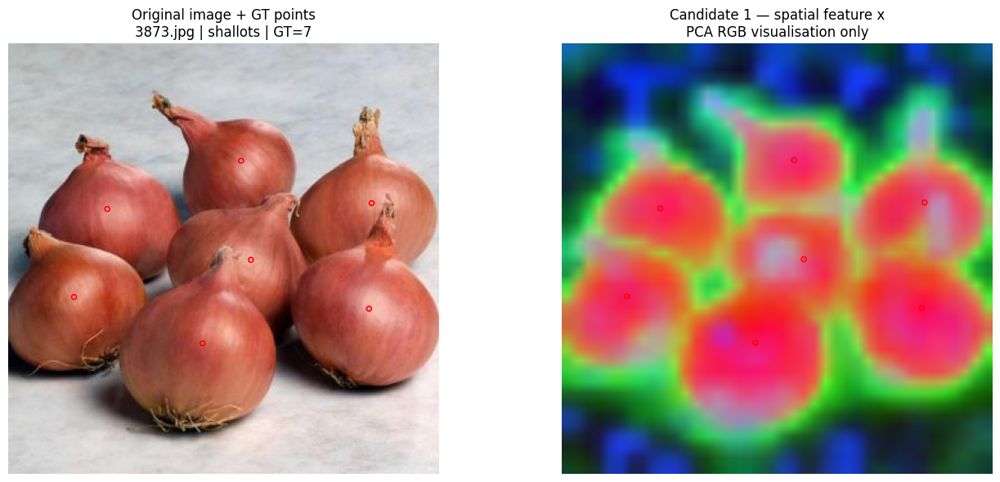


Candidate 1 PCA explained variance ratio: [0.4885 0.115  0.0502]
Candidate 1 PCA cumulative variance: 0.6537


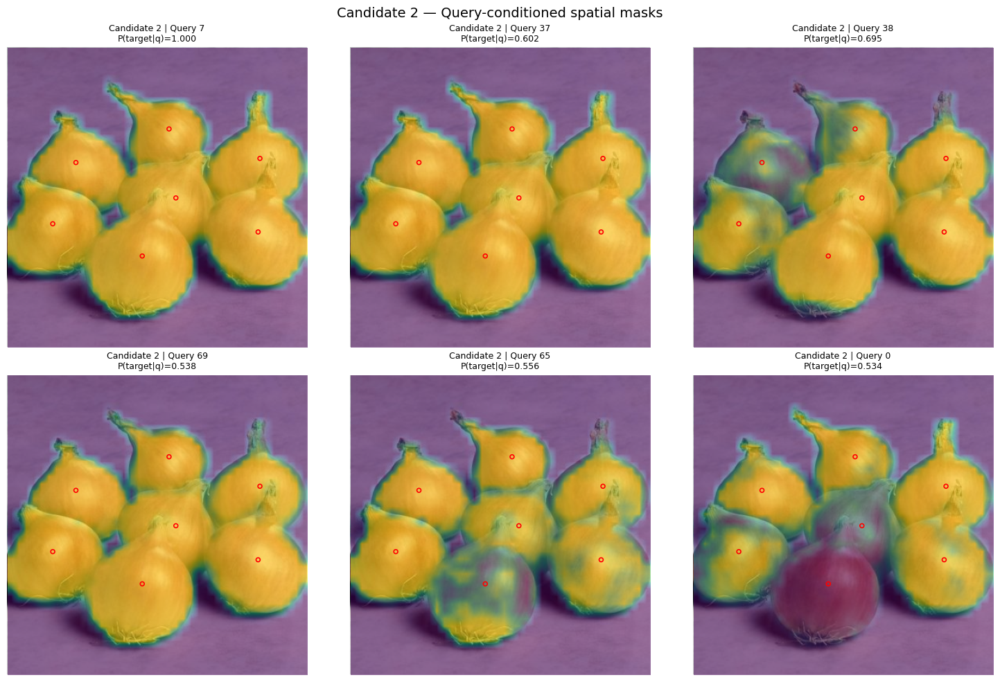

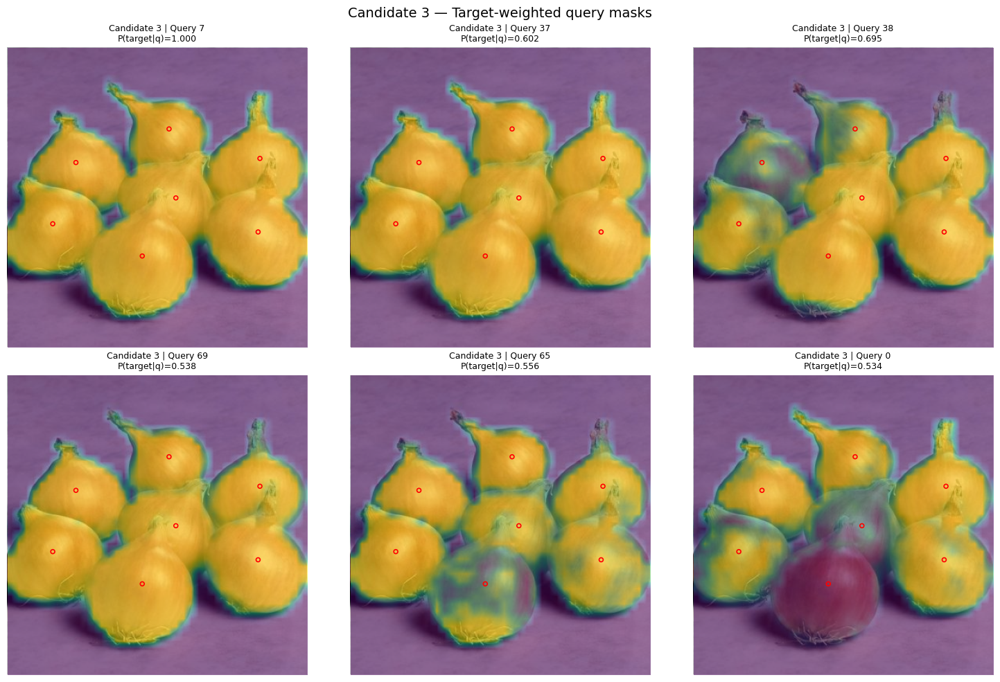


Step 12B.4 complete.


In [147]:
# ============================================================
# Step 12B.4 — Visualise SAN candidate representations
# ============================================================

import numpy as np
import torch
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA
from PIL import Image


print("=" * 80)
print("STEP 12B.4 — VISUALISE SAN CANDIDATE REPRESENTATIONS")
print("=" * 80)


# ------------------------------------------------------------
# 1. Recover image and GT points
# ------------------------------------------------------------

image_np = np.array(test_sample["image"])

category_data = test_sample["categories"][target_category]

gt_points = np.asarray(
    category_data["points"],
    dtype=np.float32,
)

print("\n[1] Sample")
print("-" * 80)
print("Image ID       :", test_sample["image_id"])
print("Target category:", target_category)
print("Image shape    :", image_np.shape)
print("GT count       :", len(gt_points))


# ------------------------------------------------------------
# 2. Retrieve Candidate 1
#    x: [1, C, H, W]
# ------------------------------------------------------------

x = d6_single_image["x"][0]       # [240, 40, 40]

C, Hf, Wf = x.shape


# ------------------------------------------------------------
# Candidate 1 visualisation:
# PCA of 240-D spatial features.
#
# IMPORTANT:
# PCA is used only to visualise the spatial feature structure.
# It is NOT a D6 reference-point-generation method.
# ------------------------------------------------------------

x_flat = (
    x.permute(1, 2, 0)
    .reshape(-1, C)
    .numpy()
)

pca = PCA(n_components=3)

x_pca = pca.fit_transform(
    x_flat
)

x_pca = x_pca.reshape(
    Hf,
    Wf,
    3,
)

# Normalise each PCA component independently
# for RGB visualisation only.

x_pca_rgb = np.zeros_like(
    x_pca,
    dtype=np.float32,
)

for k in range(3):

    channel = x_pca[:, :, k]

    cmin = channel.min()
    cmax = channel.max()

    if cmax > cmin:
        channel = (
            (channel - cmin)
            / (cmax - cmin)
        )

    x_pca_rgb[:, :, k] = channel


# ------------------------------------------------------------
# 3. Retrieve Candidates 2 and 3
# ------------------------------------------------------------

mask_preds = (
    d6_single_image["mask_preds"][0]
)  # [Q,40,40]

mask_probs = mask_preds.sigmoid()

target_query_prob = (
    d6_single_image[
        "target_query_prob"
    ][0]
)

target_weighted = (
    d6_single_image[
        "target_weighted_query_masks"
    ][0]
)


# ------------------------------------------------------------
# 4. Rank queries by Candidate-3 total contribution
# ------------------------------------------------------------

query_contribution = (
    target_weighted
    .sum(dim=(1, 2))
)

sorted_contribution, sorted_query_idx = (
    torch.sort(
        query_contribution,
        descending=True,
    )
)

top_k = 6

top_queries = (
    sorted_query_idx[:top_k]
    .cpu()
    .numpy()
)


print("\n[2] Queries selected for visual inspection")
print("-" * 80)

for rank, q in enumerate(
    top_queries,
    start=1,
):

    print(
        f"Rank {rank}: "
        f"query={q}, "
        f"P(target|q)="
        f"{float(target_query_prob[q]):.6f}, "
        f"contribution="
        f"{float(query_contribution[q]):.3f}"
    )


# ------------------------------------------------------------
# Helper — draw GT points
# ------------------------------------------------------------

def draw_gt_points(ax, points):

    if len(points) == 0:
        return

    ax.scatter(
        points[:, 0],
        points[:, 1],
        s=18,
        facecolors="none",
        edgecolors="red",
        linewidths=1.2,
    )


# ------------------------------------------------------------
# Helper — display a low-resolution SAN map over original image
# ------------------------------------------------------------

def show_map_overlay(
    ax,
    image,
    activation,
    points,
    title,
    alpha=0.55,
):

    ax.imshow(image)

    ax.imshow(
        activation,
        alpha=alpha,
        extent=[
            0,
            image.shape[1],
            image.shape[0],
            0,
        ],
        interpolation="bilinear",
    )

    draw_gt_points(
        ax,
        points,
    )

    ax.set_title(
        title,
        fontsize=9,
    )

    ax.axis("off")


# ============================================================
# FIGURE 1
#
# Original image + Candidate 1 PCA
# ============================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 6),
)

axes[0].imshow(
    image_np
)

draw_gt_points(
    axes[0],
    gt_points,
)

axes[0].set_title(
    f"Original image + GT points\n"
    f"{test_sample['image_id']} | "
    f"{target_category} | "
    f"GT={len(gt_points)}"
)

axes[0].axis("off")


axes[1].imshow(
    x_pca_rgb,
    extent=[
        0,
        image_np.shape[1],
        image_np.shape[0],
        0,
    ],
    interpolation="bilinear",
)

draw_gt_points(
    axes[1],
    gt_points,
)

axes[1].set_title(
    "Candidate 1 — spatial feature x\n"
    "PCA RGB visualisation only"
)

axes[1].axis("off")

plt.tight_layout()
plt.show()


print(
    "\nCandidate 1 PCA explained variance ratio:",
    np.round(
        pca.explained_variance_ratio_,
        4,
    ),
)

print(
    "Candidate 1 PCA cumulative variance:",
    round(
        float(
            pca.explained_variance_ratio_.sum()
        ),
        4,
    ),
)


# ============================================================
# FIGURE 2
#
# Candidate 2 — top query-conditioned spatial masks
# ============================================================

fig, axes = plt.subplots(
    2,
    3,
    figsize=(15, 10),
)

axes = axes.ravel()

for ax, q in zip(
    axes,
    top_queries,
):

    activation = (
        mask_probs[q]
        .cpu()
        .numpy()
    )

    show_map_overlay(
        ax,
        image_np,
        activation,
        gt_points,
        (
            f"Candidate 2 | Query {q}\n"
            f"P(target|q)="
            f"{float(target_query_prob[q]):.3f}"
        ),
    )

plt.suptitle(
    "Candidate 2 — Query-conditioned spatial masks",
    fontsize=14,
)

plt.tight_layout()
plt.show()


# ============================================================
# FIGURE 3
#
# Candidate 3 — target-weighted query masks
# ============================================================

fig, axes = plt.subplots(
    2,
    3,
    figsize=(15, 10),
)

axes = axes.ravel()

for ax, q in zip(
    axes,
    top_queries,
):

    activation = (
        target_weighted[q]
        .cpu()
        .numpy()
    )

    show_map_overlay(
        ax,
        image_np,
        activation,
        gt_points,
        (
            f"Candidate 3 | Query {q}\n"
            f"P(target|q)="
            f"{float(target_query_prob[q]):.3f}"
        ),
    )

plt.suptitle(
    "Candidate 3 — Target-weighted query masks",
    fontsize=14,
)

plt.tight_layout()
plt.show()


print("\nStep 12B.4 complete.")

In [148]:
# ============================================================
# Runtime sanity check before continuing D6
# ============================================================

required_objects = [
    "san_model",
    "fsc147_dev_100_df",
    "fsc147_val_dataset",
    "prepare_san_input",
    "SAN_SHORT_SIDE",
    "device",
    "d6_single_image",
]

print("=" * 80)
print("D6 RUNTIME SANITY CHECK")
print("=" * 80)

all_ok = True

for name in required_objects:
    exists = name in globals()
    print(f"{name:30s}: {'OK' if exists else 'MISSING'}")
    all_ok &= exists

if all_ok:
    print("\nRuntime state is intact — no rerun required.")
else:
    print("\nSome required state is missing — rerun the relevant earlier cells.")

D6 RUNTIME SANITY CHECK
san_model                     : OK
fsc147_dev_100_df             : OK
fsc147_val_dataset            : OK
prepare_san_input             : OK
SAN_SHORT_SIDE                : OK
device                        : OK
d6_single_image               : OK

Runtime state is intact — no rerun required.


In [149]:
# ============================================================
# Step 12B.5a — Select representative cross-density samples
# ============================================================

import pandas as pd

print("=" * 80)
print("STEP 12B.5a — SELECT CROSS-DENSITY DIAGNOSTIC SAMPLES")
print("=" * 80)


# ------------------------------------------------------------
# 1. Density strata to inspect
#
# S1 already has the existing 3873.jpg diagnostic.
# Select one representative image from S3, S4 and S6.
# ------------------------------------------------------------

diagnostic_strata = [
    "S3_40_60",
    "S4_60_80",
    "S6_95_100",
]


# ------------------------------------------------------------
# 2. Deterministic representative selection
#
# Rule:
#   choose the image whose GT count is closest to the median
#   GT count of that stratum within the frozen dev100.
#
# Tie-breaking:
#   1. smaller absolute distance from median
#   2. lower GT count
#   3. lexicographically smaller image_id
#
# No visual inspection is used for selection.
# ------------------------------------------------------------

selected_rows = []

for stratum in diagnostic_strata:

    stratum_df = (
        fsc147_dev_100_df[
            fsc147_dev_100_df["density_stratum"].astype(str)
            == stratum
        ]
        .copy()
    )

    if len(stratum_df) == 0:
        raise ValueError(
            f"No dev100 samples found for {stratum}."
        )

    median_gt = float(
        stratum_df["gt_count"].median()
    )

    stratum_df["distance_from_median"] = (
        stratum_df["gt_count"]
        .astype(float)
        .sub(median_gt)
        .abs()
    )

    representative = (
        stratum_df
        .sort_values(
            [
                "distance_from_median",
                "gt_count",
                "image_id",
            ]
        )
        .iloc[0]
        .copy()
    )

    representative["stratum_median_gt"] = median_gt

    selected_rows.append(
        representative
    )


# ------------------------------------------------------------
# 3. Build diagnostic table
# ------------------------------------------------------------

d6_cross_density_df = pd.DataFrame(
    selected_rows
)

d6_cross_density_df = (
    d6_cross_density_df[
        [
            "density_stratum",
            "dataset_index",
            "image_id",
            "category",
            "gt_count",
            "stratum_median_gt",
            "distance_from_median",
        ]
    ]
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 4. Add existing S1 diagnostic for reference
# ------------------------------------------------------------

s1_existing = (
    fsc147_dev_100_df[
        fsc147_dev_100_df["image_id"]
        == "3873.jpg"
    ]
)

if len(s1_existing) != 1:
    raise ValueError(
        "Expected exactly one dev100 row for 3873.jpg."
    )

s1_row = s1_existing.iloc[0]

s1_reference = pd.DataFrame(
    [
        {
            "density_stratum":
                str(s1_row["density_stratum"]),

            "dataset_index":
                int(s1_row["dataset_index"]),

            "image_id":
                s1_row["image_id"],

            "category":
                s1_row["category"],

            "gt_count":
                int(s1_row["gt_count"]),

            "stratum_median_gt":
                float(
                    fsc147_dev_100_df[
                        fsc147_dev_100_df[
                            "density_stratum"
                        ].astype(str)
                        == str(
                            s1_row["density_stratum"]
                        )
                    ]["gt_count"].median()
                ),

            "distance_from_median":
                abs(
                    float(s1_row["gt_count"])
                    - float(
                        fsc147_dev_100_df[
                            fsc147_dev_100_df[
                                "density_stratum"
                            ].astype(str)
                            == str(
                                s1_row[
                                    "density_stratum"
                                ]
                            )
                        ]["gt_count"].median()
                    )
                ),
        }
    ]
)


# ------------------------------------------------------------
# 5. Combined S1 / S3 / S4 / S6 diagnostic set
# ------------------------------------------------------------

d6_cross_density_with_s1_df = pd.concat(
    [
        s1_reference,
        d6_cross_density_df,
    ],
    ignore_index=True,
)


print("\nSelection rule:")
print(
    "Closest GT count to within-stratum median "
    "(deterministic; no visual selection)."
)

print("\nSelected diagnostic samples:")
print("-" * 80)

display(
    d6_cross_density_with_s1_df
)


# ------------------------------------------------------------
# 6. Basic validation
# ------------------------------------------------------------

assert len(
    d6_cross_density_with_s1_df
) == 4

assert (
    d6_cross_density_with_s1_df[
        "image_id"
    ].nunique()
    == 4
)

assert set(
    d6_cross_density_with_s1_df[
        "density_stratum"
    ].astype(str)
) == {
    "S1_0_20",
    "S3_40_60",
    "S4_60_80",
    "S6_95_100",
}


print("\nStep 12B.5a complete.")

STEP 12B.5a — SELECT CROSS-DENSITY DIAGNOSTIC SAMPLES

Selection rule:
Closest GT count to within-stratum median (deterministic; no visual selection).

Selected diagnostic samples:
--------------------------------------------------------------------------------


,density_stratum,dataset_index,image_id,category,gt_count,stratum_median_gt,distance_from_median
0,S1_0_20,576,3873.jpg,shallots,7,9.0,2.0
1,S3_40_60,650,4578.jpg,flamingos,24,25.5,1.5
2,S4_60_80,968,5896.jpg,grapes,55,56.0,1.0
3,S6_95_100,1187,6931.jpg,birds,355,496.0,141.0



Step 12B.5a complete.


In [150]:
# ============================================================
# Step 12B.5a-check — Verify current frozen S6 composition
# ============================================================

s6_check = (
    fsc147_dev_100_df[
        fsc147_dev_100_df["density_stratum"].astype(str)
        == "S6_95_100"
    ][
        ["dataset_index", "image_id", "category", "gt_count"]
    ]
    .sort_values(["gt_count", "image_id"])
    .reset_index(drop=True)
)

print("Current S6 n      :", len(s6_check))
print("Current S6 median :", s6_check["gt_count"].median())
print()
display(s6_check)

Current S6 n      : 10
Current S6 median : 496.0



,dataset_index,image_id,category,gt_count
0,438,3426.jpg,polka dots,219
1,9,215.jpg,grapes,259
2,938,5866.jpg,grapes,267
3,1257,7436.jpg,pills,283
4,1187,6931.jpg,birds,355
5,184,840.jpg,books,637
6,253,975.jpg,birds,718
7,535,3665.jpg,toilet paper rolls,907
8,1192,6969.jpg,birds,949
9,229,935.jpg,birds,2092


STEP 12B.5b — CROSS-DENSITY SAN CANDIDATE DIAGNOSTIC

Extracting S3_40_60: 4578.jpg
Category             : flamingos
GT count             : 24
Candidate 1 x        : (1, 240, 40, 56)
Candidate 2 masks    : (1, 100, 40, 56)
Candidate 3 weighted : (1, 100, 40, 56)
Reconstruction max Δ : 1.073e-06
Reconstruction mean Δ: 3.132e-08

Extracting S4_60_80: 5896.jpg
Category             : grapes
GT count             : 55
Candidate 1 x        : (1, 240, 40, 60)
Candidate 2 masks    : (1, 100, 40, 60)
Candidate 3 weighted : (1, 100, 40, 60)
Reconstruction max Δ : 2.861e-06
Reconstruction mean Δ: 2.704e-07

Extracting S6_95_100: 6931.jpg
Category             : birds
GT count             : 355
Candidate 1 x        : (1, 240, 40, 62)
Candidate 2 masks    : (1, 100, 40, 62)
Candidate 3 weighted : (1, 100, 40, 62)
Reconstruction max Δ : 7.153e-07
Reconstruction mean Δ: 3.001e-08

S3_40_60 | 4578.jpg | flamingos | GT=24
PCA explained variance: [0.2977 0.1349 0.1198]
PCA cumulative variance: 0.5524

Top

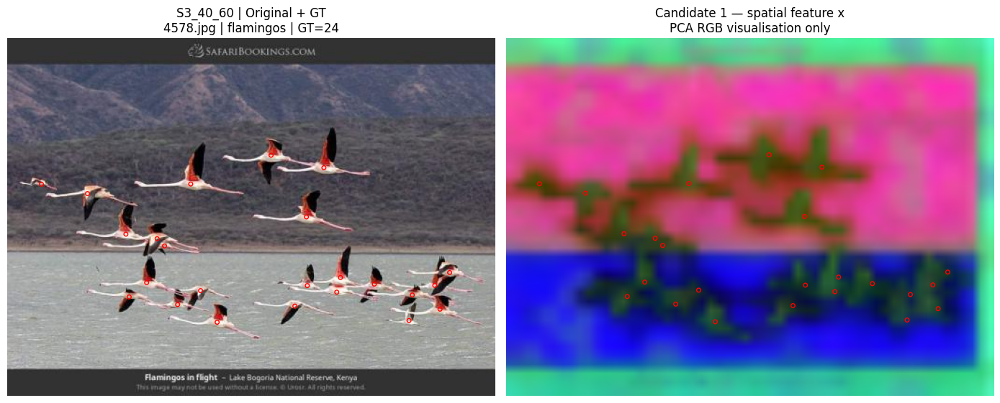

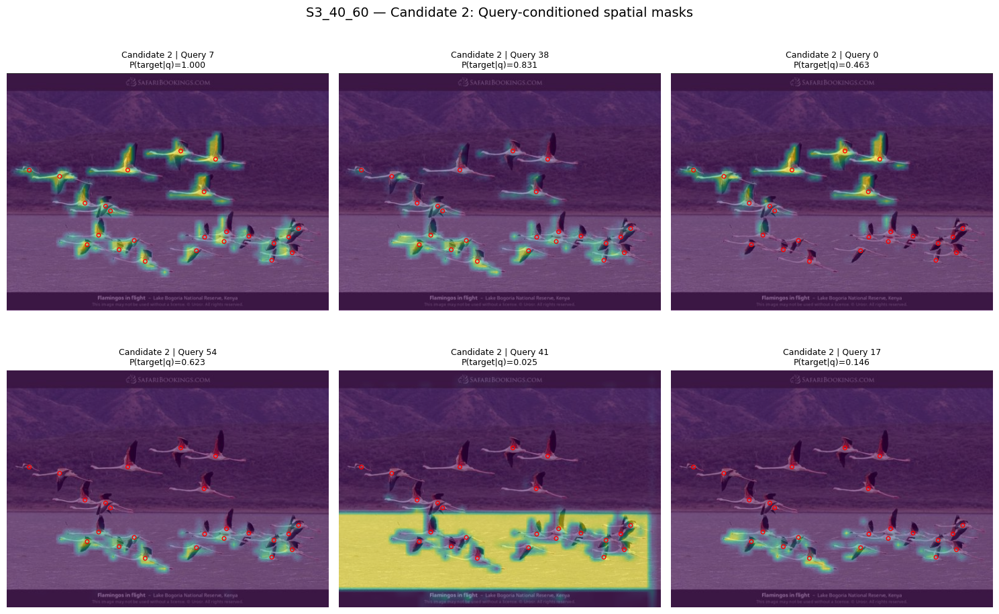

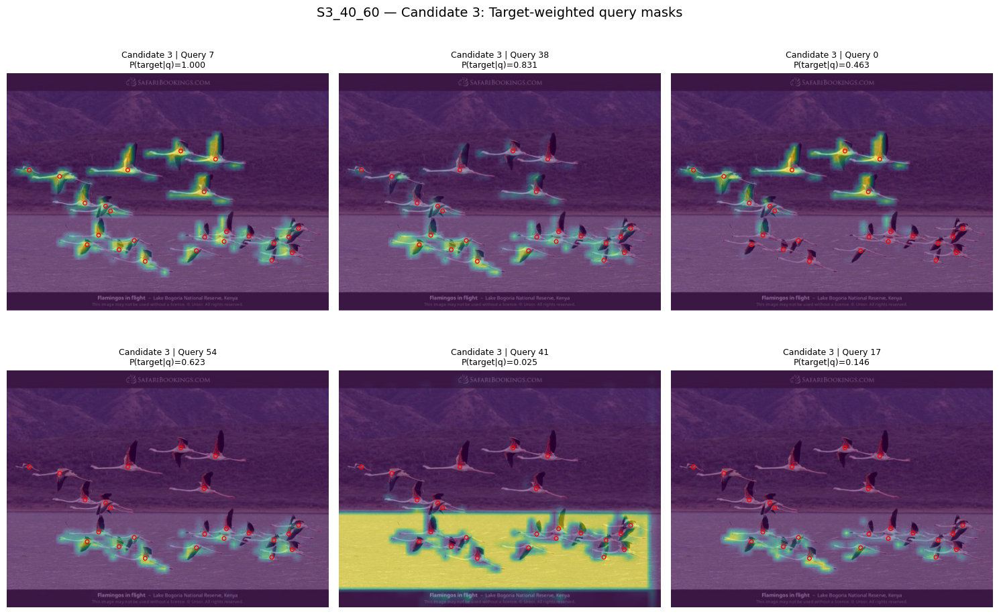


S4_60_80 | 5896.jpg | grapes | GT=55
PCA explained variance: [0.4707 0.1253 0.0611]
PCA cumulative variance: 0.6571

Top 6 target-weighted queries:
  Rank 1: query=  7, P(target|q)=0.996346, contribution=727.771
  Rank 2: query= 37, P(target|q)=0.543230, contribution=538.021
  Rank 3: query=  3, P(target|q)=0.518553, contribution=497.286
  Rank 4: query= 32, P(target|q)=0.740795, contribution=470.785
  Rank 5: query= 46, P(target|q)=0.473727, contribution=450.460
  Rank 6: query= 69, P(target|q)=0.451417, contribution=447.873


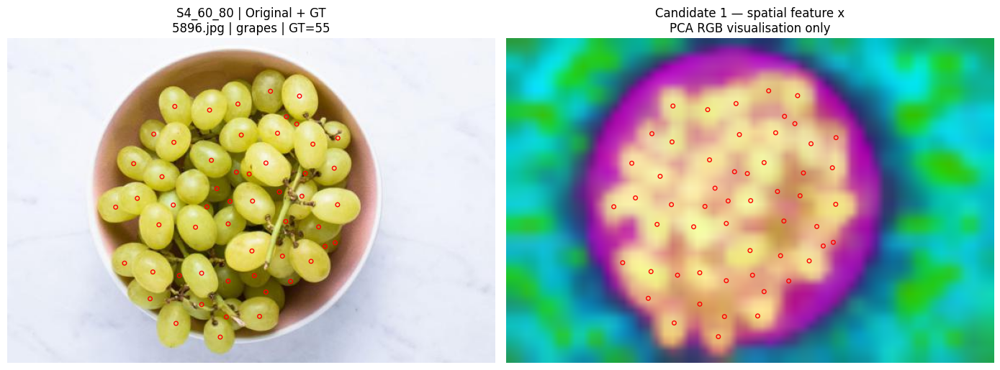

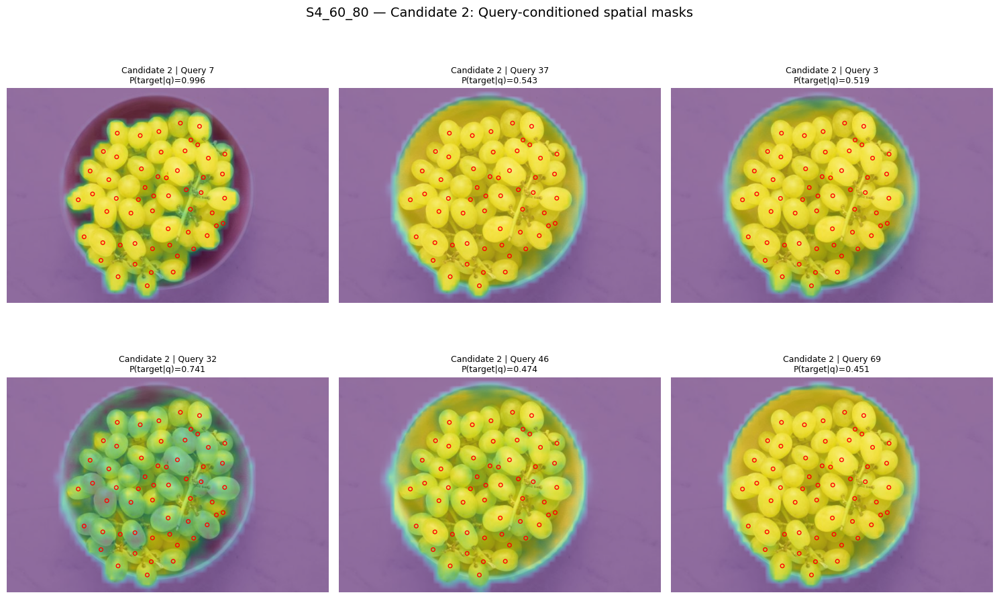

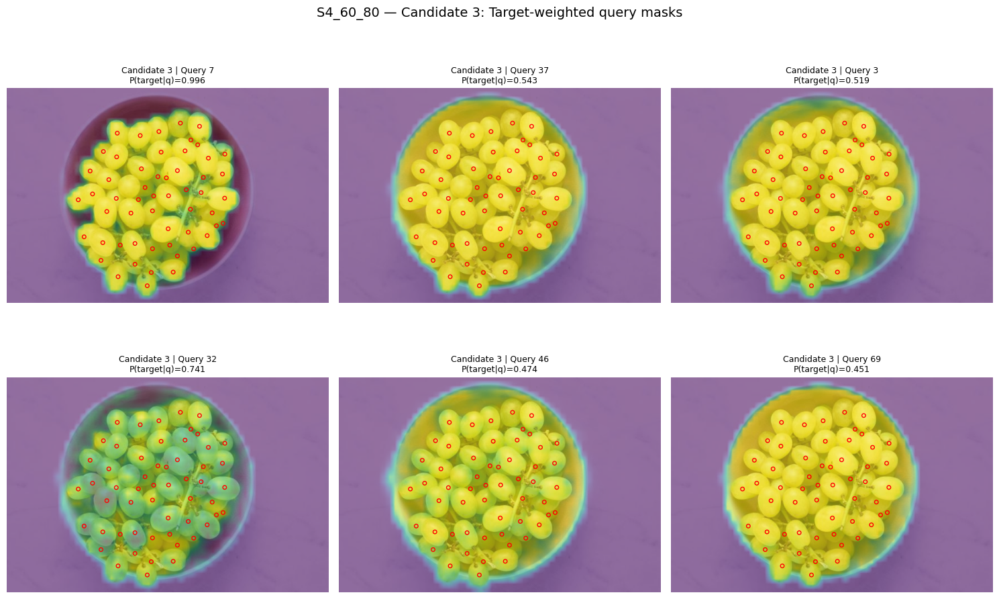


S6_95_100 | 6931.jpg | birds | GT=355
PCA explained variance: [0.2477 0.1412 0.11  ]
PCA cumulative variance: 0.4988

Top 6 target-weighted queries:
  Rank 1: query= 37, P(target|q)=0.167146, contribution=119.895
  Rank 2: query= 64, P(target|q)=0.046066, contribution=70.814
  Rank 3: query=  0, P(target|q)=0.949708, contribution=58.182
  Rank 4: query=  7, P(target|q)=0.995053, contribution=52.320
  Rank 5: query=  3, P(target|q)=0.203543, contribution=49.163
  Rank 6: query= 89, P(target|q)=0.190799, contribution=32.002


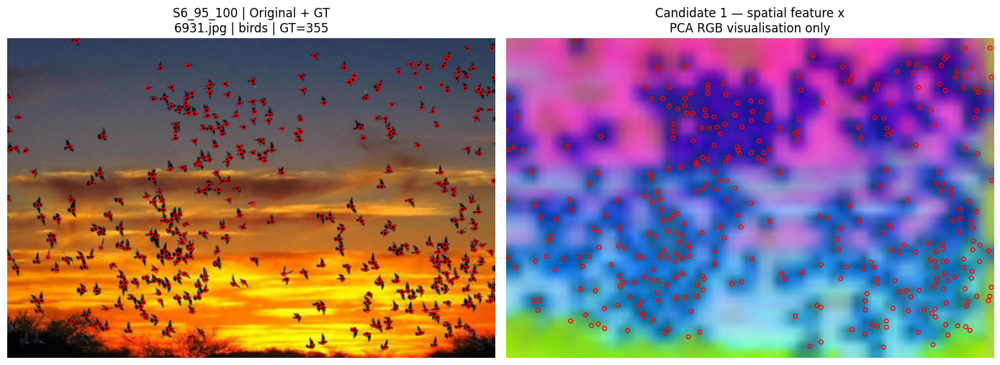

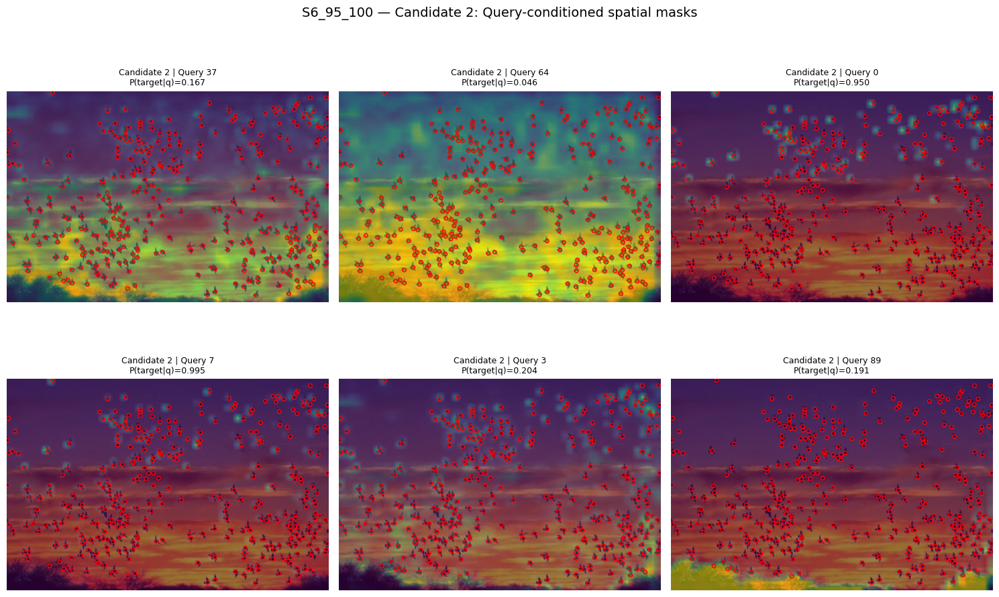

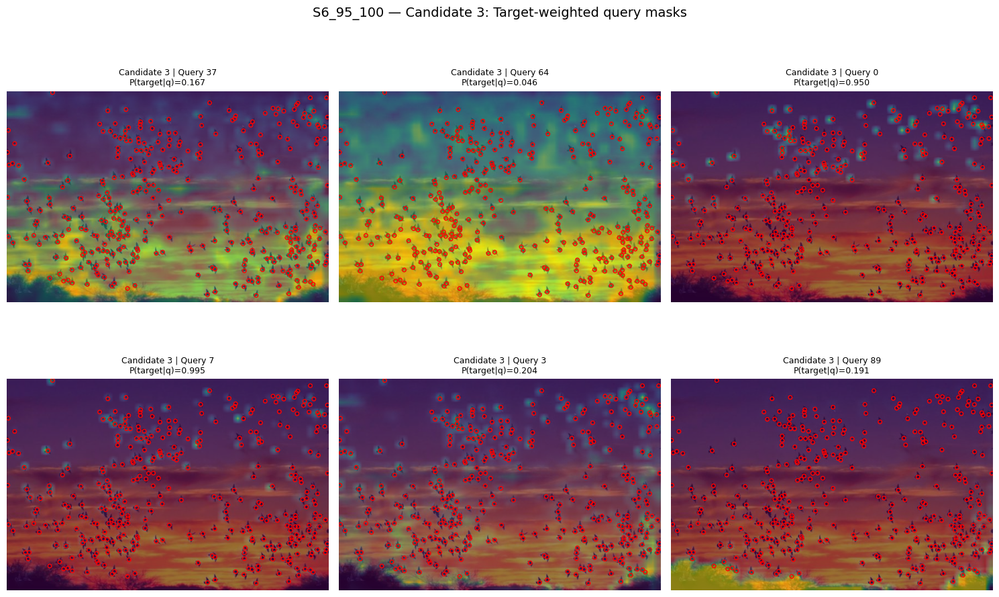


Step 12B.5b complete.


In [151]:
# ============================================================
# Step 12B.5b — Extract and visualise SAN candidates
#                across density regimes
# ============================================================

import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA
from detectron2.structures import ImageList


print("=" * 80)
print("STEP 12B.5b — CROSS-DENSITY SAN CANDIDATE DIAGNOSTIC")
print("=" * 80)


# ============================================================
# Helper 1 — Extract Candidates 1–3 for one FSC sample
# ============================================================

def extract_d6_candidates(sample):

    target_categories = list(
        sample["categories"].keys()
    )

    if len(target_categories) != 1:
        raise ValueError(
            "Expected exactly one FSC-147 target category."
        )

    target_category = target_categories[0]

    san_vocabulary = [
        target_category,
        "background",
    ]

    # --------------------------------------------------------
    # Same preprocessing as Step 12B.1 / existing SAN pipeline
    # --------------------------------------------------------

    (
        image_tensor,
        original_height,
        original_width,
    ) = prepare_san_input(
        sample["image"],
        short_side=SAN_SHORT_SIDE,
    )

    batched_inputs = [
        {
            "image": image_tensor.to(device),
            "height": original_height,
            "width": original_width,
            "vocabulary": san_vocabulary,
        }
    ]

    with torch.no_grad():

        # ----------------------------------------------------
        # Vocabulary classifier
        # ----------------------------------------------------

        ov_classifier_weight = (
            san_model.ov_classifier.logit_scale.exp()
            * san_model.ov_classifier
            .get_classifier_by_vocabulary(
                san_vocabulary
            )
        )

        # ----------------------------------------------------
        # SAN image preprocessing
        # ----------------------------------------------------

        images = [
            x["image"].to(san_model.device)
            for x in batched_inputs
        ]

        images = [
            (x - san_model.pixel_mean)
            / san_model.pixel_std
            for x in images
        ]

        images = ImageList.from_tensors(
            images,
            san_model.size_divisibility,
        )

        clip_input = images.tensor

        if san_model.asymetric_input:
            clip_input = F.interpolate(
                clip_input,
                scale_factor=san_model.clip_resolution,
                mode="bilinear",
            )

        clip_image_features = (
            san_model.clip_visual_extractor(
                clip_input
            )
        )

        # ====================================================
        # Candidate 1 — intermediate spatial feature x
        # ====================================================

        side_features = (
            san_model.side_adapter_network
            .forward_features(
                images.tensor,
                clip_image_features,
            )
        )

        final_feature = side_features[-1]

        x_intermediate = final_feature["x"]

        query_intermediate = final_feature[
            "query"
        ]

        # ====================================================
        # Candidate 2 — query-conditioned spatial masks
        # ====================================================

        mask_preds_list, attn_biases_list = (
            san_model.side_adapter_network
            .decode_masks(
                side_features
            )
        )

        mask_pred = mask_preds_list[-1]

        attn_bias = attn_biases_list[-1]

        # ====================================================
        # Semantic evidence P(target | q)
        # ====================================================

        mask_emb = san_model.clip_rec_head(
            clip_image_features,
            attn_bias,
            normalize=True,
        )

        mask_logits = torch.einsum(
            "bqc,nc->bqn",
            mask_emb,
            ov_classifier_weight,
        )

        mask_cls = F.softmax(
            mask_logits,
            dim=-1,
        )[..., :-1]

        # target is vocabulary index 0
        target_query_prob = mask_cls[
            :, :, 0
        ]

        # ====================================================
        # Candidate 3 — target-weighted query masks
        # ====================================================

        mask_prob = mask_pred.sigmoid()

        target_weighted = (
            target_query_prob[
                :, :, None, None
            ]
            * mask_prob
        )

        # ----------------------------------------------------
        # Reconstruction validation
        # ----------------------------------------------------

        reconstructed_target = (
            target_weighted.sum(dim=1)
        )

        san_semseg_lowres = (
            san_model.semantic_inference(
                mask_logits[0],
                mask_pred[0],
            )
        )

        san_target_lowres = (
            san_semseg_lowres[0]
            .unsqueeze(0)
        )

        reconstruction_error = (
            reconstructed_target
            - san_target_lowres
        ).abs()

    # --------------------------------------------------------
    # GT
    # --------------------------------------------------------

    category_data = (
        sample["categories"][
            target_category
        ]
    )

    gt_points = np.asarray(
        category_data["points"],
        dtype=np.float32,
    )

    return {
        "image_id":
            sample["image_id"],

        "target_category":
            target_category,

        "gt_count":
            len(gt_points),

        "gt_points":
            gt_points,

        "image_np":
            np.array(sample["image"]),

        "x":
            x_intermediate.detach()
            .cpu().float(),

        "query":
            query_intermediate.detach()
            .cpu().float(),

        "mask_preds":
            mask_pred.detach()
            .cpu().float(),

        "target_query_prob":
            target_query_prob.detach()
            .cpu().float(),

        "target_weighted_query_masks":
            target_weighted.detach()
            .cpu().float(),

        "reconstruction_max_error":
            float(
                reconstruction_error.max()
            ),

        "reconstruction_mean_error":
            float(
                reconstruction_error.mean()
            ),
    }


# ============================================================
# Helper 2 — Draw GT points
# ============================================================

def draw_d6_gt_points(
    ax,
    points,
    size=16,
):

    if len(points) == 0:
        return

    ax.scatter(
        points[:, 0],
        points[:, 1],
        s=size,
        facecolors="none",
        edgecolors="red",
        linewidths=1.0,
    )


# ============================================================
# Helper 3 — Overlay low-resolution activation map
# ============================================================

def show_d6_map_overlay(
    ax,
    image,
    activation,
    points,
    title,
    alpha=0.55,
):

    ax.imshow(image)

    ax.imshow(
        activation,
        alpha=alpha,
        extent=[
            0,
            image.shape[1],
            image.shape[0],
            0,
        ],
        interpolation="bilinear",
    )

    draw_d6_gt_points(
        ax,
        points,
    )

    ax.set_title(
        title,
        fontsize=9,
    )

    ax.axis("off")


# ============================================================
# 1. Extract S3 / S4 / S6
# ============================================================

d6_cross_density_results = {}

for _, row in d6_cross_density_df.iterrows():

    stratum = str(
        row["density_stratum"]
    )

    dataset_index = int(
        row["dataset_index"]
    )

    sample = fsc147_val_dataset[
        dataset_index
    ]

    print("\n" + "=" * 80)
    print(
        f"Extracting {stratum}: "
        f"{sample['image_id']}"
    )
    print("=" * 80)

    result = extract_d6_candidates(
        sample
    )

    result["density_stratum"] = (
        stratum
    )

    d6_cross_density_results[
        stratum
    ] = result

    print(
        "Category             :",
        result["target_category"],
    )

    print(
        "GT count             :",
        result["gt_count"],
    )

    print(
        "Candidate 1 x        :",
        tuple(result["x"].shape),
    )

    print(
        "Candidate 2 masks    :",
        tuple(
            result["mask_preds"].shape
        ),
    )

    print(
        "Candidate 3 weighted :",
        tuple(
            result[
                "target_weighted_query_masks"
            ].shape
        ),
    )

    print(
        "Reconstruction max Δ :",
        f"{result['reconstruction_max_error']:.3e}",
    )

    print(
        "Reconstruction mean Δ:",
        f"{result['reconstruction_mean_error']:.3e}",
    )


# ============================================================
# 2. Visualise each density representative
# ============================================================

for stratum, result in (
    d6_cross_density_results.items()
):

    image_np = result["image_np"]
    gt_points = result["gt_points"]

    # --------------------------------------------------------
    # Candidate 1 — PCA visualisation
    # --------------------------------------------------------

    x = result["x"][0]

    C, Hf, Wf = x.shape

    x_flat = (
        x.permute(1, 2, 0)
        .reshape(-1, C)
        .numpy()
    )

    pca = PCA(
        n_components=3
    )

    x_pca = (
        pca.fit_transform(x_flat)
        .reshape(Hf, Wf, 3)
    )

    x_pca_rgb = np.zeros_like(
        x_pca,
        dtype=np.float32,
    )

    for k in range(3):

        channel = x_pca[:, :, k]

        cmin = channel.min()
        cmax = channel.max()

        if cmax > cmin:
            channel = (
                (channel - cmin)
                / (cmax - cmin)
            )

        x_pca_rgb[:, :, k] = channel

    # --------------------------------------------------------
    # Candidate 2 / 3 query ranking
    # --------------------------------------------------------

    mask_probs = (
        result["mask_preds"][0]
        .sigmoid()
    )

    target_query_prob = (
        result[
            "target_query_prob"
        ][0]
    )

    target_weighted = (
        result[
            "target_weighted_query_masks"
        ][0]
    )

    query_contribution = (
        target_weighted
        .sum(dim=(1, 2))
    )

    (
        sorted_contribution,
        sorted_query_idx,
    ) = torch.sort(
        query_contribution,
        descending=True,
    )

    top_k = 6

    top_queries = (
        sorted_query_idx[:top_k]
        .cpu()
        .numpy()
    )

    # --------------------------------------------------------
    # Print selected query information
    # --------------------------------------------------------

    print("\n" + "=" * 80)

    print(
        f"{stratum} | "
        f"{result['image_id']} | "
        f"{result['target_category']} | "
        f"GT={result['gt_count']}"
    )

    print("=" * 80)

    print(
        "PCA explained variance:",
        np.round(
            pca.explained_variance_ratio_,
            4,
        ),
    )

    print(
        "PCA cumulative variance:",
        round(
            float(
                pca.explained_variance_ratio_
                .sum()
            ),
            4,
        ),
    )

    print("\nTop 6 target-weighted queries:")

    for rank, q in enumerate(
        top_queries,
        start=1,
    ):

        print(
            f"  Rank {rank}: "
            f"query={q:3d}, "
            f"P(target|q)="
            f"{float(target_query_prob[q]):.6f}, "
            f"contribution="
            f"{float(query_contribution[q]):.3f}"
        )

    # ========================================================
    # FIGURE A — Original + Candidate 1
    # ========================================================

    fig, axes = plt.subplots(
        1,
        2,
        figsize=(14, 6),
    )

    axes[0].imshow(
        image_np
    )

    draw_d6_gt_points(
        axes[0],
        gt_points,
    )

    axes[0].set_title(
        f"{stratum} | Original + GT\n"
        f"{result['image_id']} | "
        f"{result['target_category']} | "
        f"GT={result['gt_count']}"
    )

    axes[0].axis("off")

    axes[1].imshow(
        x_pca_rgb,
        extent=[
            0,
            image_np.shape[1],
            image_np.shape[0],
            0,
        ],
        interpolation="bilinear",
    )

    draw_d6_gt_points(
        axes[1],
        gt_points,
    )

    axes[1].set_title(
        "Candidate 1 — spatial feature x\n"
        "PCA RGB visualisation only"
    )

    axes[1].axis("off")

    plt.tight_layout()
    plt.show()

    # ========================================================
    # FIGURE B — Candidate 2
    # ========================================================

    fig, axes = plt.subplots(
        2,
        3,
        figsize=(15, 10),
    )

    axes = axes.ravel()

    for ax, q in zip(
        axes,
        top_queries,
    ):

        activation = (
            mask_probs[q]
            .cpu()
            .numpy()
        )

        show_d6_map_overlay(
            ax,
            image_np,
            activation,
            gt_points,
            (
                f"Candidate 2 | Query {q}\n"
                f"P(target|q)="
                f"{float(target_query_prob[q]):.3f}"
            ),
        )

    plt.suptitle(
        f"{stratum} — Candidate 2: "
        "Query-conditioned spatial masks",
        fontsize=14,
    )

    plt.tight_layout()
    plt.show()

    # ========================================================
    # FIGURE C — Candidate 3
    # ========================================================

    fig, axes = plt.subplots(
        2,
        3,
        figsize=(15, 10),
    )

    axes = axes.ravel()

    for ax, q in zip(
        axes,
        top_queries,
    ):

        activation = (
            target_weighted[q]
            .cpu()
            .numpy()
        )

        show_d6_map_overlay(
            ax,
            image_np,
            activation,
            gt_points,
            (
                f"Candidate 3 | Query {q}\n"
                f"P(target|q)="
                f"{float(target_query_prob[q]):.3f}"
            ),
        )

    plt.suptitle(
        f"{stratum} — Candidate 3: "
        "Target-weighted query masks",
        fontsize=14,
    )

    plt.tight_layout()
    plt.show()


print("\nStep 12B.5b complete.")

### Step 12B Conclusion — Consolidation of D6 Candidate Representations

The SAN intermediate-representation analysis initially considered three representations:

1. the intermediate spatial feature `x`;
2. the query-conditioned spatial masks (`mask_preds`);
3. the target-weighted query masks.

The analysis in Steps 12B.1–12B.5 showed that Candidate 2 is an intermediate computational stage used to construct Candidate 3. For each query, Candidate 3 retains the same spatial structure as Candidate 2 but weights it by the query's semantic relevance to the target class, \(P(t|q)\). Candidate 2 is therefore not retained as a separate D6 candidate.

The remainder of D6 will consider **two candidate representations**:

#### Candidate A — Intermediate spatial feature \(x\)

\[
x \in \mathbb{R}^{C \times H \times W}
\]

This is the spatial feature produced by the SAN side adapter before mask decoding. It preserves substantial spatial structure, but is not directly target-specific.

**Research question:** Can \(x\) be converted into a target-specific spatial activation in a principled, SAN-native way?

#### Candidate B — Target-weighted query decomposition

For each SAN query \(q\),

\[
T_q(x,y)
=
P(t|q)\,\sigma(M_q(x,y)),
\]

where \(M_q(x,y)\) is the query-conditioned mask logit and \(P(t|q)\) is the semantic probability of the target class for that query.

Candidate B is the representation previously called **Candidate 3**. The term *target-weighted query decomposition* describes the same representation more explicitly.

SAN normally sums these query contributions:

\[
S_t(x,y)
=
\sum_q T_q(x,y),
\]

producing the final target semantic activation used by D1. Step 12B.3 verified this reconstruction numerically.

Candidate B instead preserves the individual target-weighted query maps **before this summation**.

**Research question:** Can information retained across the individual target-weighted query maps provide useful reference-point localisation evidence that is lost when they are summed into the final D1 activation?

Therefore, from this point onward, D6 contains **two candidate directions only: Candidate A and Candidate B**.

In [152]:
# ============================================================
# Step 12C.1 — Inspect SAN learned transformations of
#               Candidate A (intermediate spatial feature x)
# ============================================================

import inspect
import torch

print("=" * 80)
print("STEP 12C.1 — INSPECT CANDIDATE-A LEARNED TRANSFORMATIONS")
print("=" * 80)


# ------------------------------------------------------------
# 1. Locate the SAN mask decoder
# ------------------------------------------------------------

mask_decoder = (
    san_model
    .side_adapter_network
    .mask_decoder
)

print("\n[1] Mask decoder")
print("-" * 80)

print("Class :", mask_decoder.__class__.__name__)
print("Module:", mask_decoder.__class__.__module__)


# ------------------------------------------------------------
# 2. Inspect the learned transformations used by the decoder
# ------------------------------------------------------------

print("\n[2] Decoder transformations")
print("-" * 80)

for name in [
    "pix_mlp",
    "query_mlp",
    "attn_mlp",
]:
    module = getattr(
        mask_decoder,
        name,
        None,
    )

    print(f"\n{name}:")

    if module is None:
        print("  NOT FOUND")
        continue

    print(module)


# ------------------------------------------------------------
# 3. Parameter counts
# ------------------------------------------------------------

print("\n[3] Parameter counts")
print("-" * 80)

for name in [
    "pix_mlp",
    "query_mlp",
    "attn_mlp",
]:
    module = getattr(
        mask_decoder,
        name,
        None,
    )

    if module is None:
        continue

    n_params = sum(
        p.numel()
        for p in module.parameters()
    )

    print(
        f"{name:12s}: "
        f"{n_params:,} parameters"
    )

# ------------------------------------------------------------
# 4. Retrieve an already-extracted Candidate A example
# ------------------------------------------------------------

print("\n[4] Retrieve Candidate A from Step 12B.5b")
print("-" * 80)

if "d6_cross_density_results" not in globals():
    raise RuntimeError(
        "d6_cross_density_results is not present. "
        "Run Step 12B.5b first."
    )

# Use the S3 diagnostic sample.
# Any stored sample would be sufficient for this dimensional check.
example_key = "S3_40_60"

if example_key not in d6_cross_density_results:
    raise RuntimeError(
        f"{example_key} not found in d6_cross_density_results."
    )

example = d6_cross_density_results[example_key]

x = example["x"].to(device)
query = example["query"].to(device)

print("Sample              :", example["image_id"])
print("Category            :", example["target_category"])
print("Candidate A x shape :", tuple(x.shape))
print("Query shape         :", tuple(query.shape))


# ------------------------------------------------------------
# 5. Apply SAN's learned transformations
# ------------------------------------------------------------

with torch.no_grad():
    pix = mask_decoder.pix_mlp(x)
    query_proj = mask_decoder.query_mlp(query)

print("\n[5] Learned feature-space transformations")
print("-" * 80)

print(
    "Input x shape       :",
    tuple(x.shape),
)

print(
    "pix_mlp(x) shape    :",
    tuple(pix.shape),
)

print(
    "Input query shape   :",
    tuple(query.shape),
)

print(
    "query_mlp(query)    :",
    tuple(query_proj.shape),
)

print(
    "Spatial feature dim :",
    pix.shape[1],
)

print(
    "Query feature dim   :",
    query_proj.shape[-1],
)

print(
    "Compatible for dot product:",
    pix.shape[1] == query_proj.shape[-1],
)


# ------------------------------------------------------------
# 6. Basic numerical properties
# ------------------------------------------------------------

print("\n[6] Numerical properties")
print("-" * 80)

print(
    "pix_mlp(x):"
)

print(
    "  min :",
    float(pix.min()),
)

print(
    "  max :",
    float(pix.max()),
)

print(
    "  mean:",
    float(pix.mean()),
)

print(
    "  std :",
    float(pix.std()),
)

print(
    "\nquery_mlp(query):"
)

print(
    "  min :",
    float(query_proj.min()),
)

print(
    "  max :",
    float(query_proj.max()),
)

print(
    "  mean:",
    float(query_proj.mean()),
)

print(
    "  std :",
    float(query_proj.std()),
)


print("\nStep 12C.1 complete.")

STEP 12C.1 — INSPECT CANDIDATE-A LEARNED TRANSFORMATIONS

[1] Mask decoder
--------------------------------------------------------------------------------
Class : MLPMaskDecoder
Module: san.model.side_adapter.side_adapter

[2] Decoder transformations
--------------------------------------------------------------------------------

pix_mlp:
MLP(
  (layers): ModuleList(
    (0): Conv2d(240, 256, kernel_size=(1, 1), stride=(1, 1))
    (1-2): 2 x Conv2d(256, 256, kernel_size=(1, 1), stride=(1, 1))
  )
)

query_mlp:
MLP(
  (layers): ModuleList(
    (0): Linear(in_features=240, out_features=256, bias=True)
    (1-2): 2 x Linear(in_features=256, out_features=256, bias=True)
  )
)

attn_mlp:
MLP(
  (layers): ModuleList(
    (0): Conv2d(240, 256, kernel_size=(1, 1), stride=(1, 1))
    (1): Conv2d(256, 256, kernel_size=(1, 1), stride=(1, 1))
    (2): Conv2d(256, 3072, kernel_size=(1, 1), stride=(1, 1))
  )
)

[3] Parameter counts
-----------------------------------------------------------------

In [153]:
# ============================================================
# Step 12C.2 — Test target-weighted query projection
#               for Candidate A
# ============================================================

import torch
import torch.nn.functional as F


print("=" * 80)
print("STEP 12C.2 — TARGET-WEIGHTED QUERY PROJECTION")
print("=" * 80)


# ------------------------------------------------------------
# 1. Retrieve the same diagnostic example
# ------------------------------------------------------------

example_key = "S3_40_60"

if "d6_cross_density_results" not in globals():
    raise RuntimeError(
        "d6_cross_density_results is missing. "
        "Run Step 12B.5b first."
    )

example = d6_cross_density_results[
    example_key
]

x = example["x"].to(device)
query = example["query"].to(device)

target_query_prob = (
    example["target_query_prob"]
    .to(device)
)

mask_preds_saved = (
    example["mask_preds"]
    .to(device)
)


print("\n[1] Diagnostic sample")
print("-" * 80)

print(
    "Image ID :",
    example["image_id"],
)

print(
    "Category :",
    example["target_category"],
)

print(
    "GT count :",
    example["gt_count"],
)

print(
    "x shape  :",
    tuple(x.shape),
)

print(
    "query    :",
    tuple(query.shape),
)

print(
    "P(t|q)   :",
    tuple(target_query_prob.shape),
)


# ------------------------------------------------------------
# 2. Apply SAN's learned projections
# ------------------------------------------------------------

mask_decoder = (
    san_model
    .side_adapter_network
    .mask_decoder
)

with torch.no_grad():

    pix = mask_decoder.pix_mlp(
        x
    )

    query_proj = (
        mask_decoder.query_mlp(
            query
        )
    )


print("\n[2] SAN learned projection space")
print("-" * 80)

print(
    "pix_mlp(x)       :",
    tuple(pix.shape),
)

print(
    "query_mlp(query) :",
    tuple(query_proj.shape),
)


# ------------------------------------------------------------
# 3. Reconstruct mask_preds from projected x and queries
# ------------------------------------------------------------

with torch.no_grad():

    mask_preds_reconstructed = (
        torch.einsum(
            "bqc,bchw->bqhw",
            query_proj,
            pix,
        )
    )

mask_reconstruction_error = (
    mask_preds_reconstructed
    - mask_preds_saved
).abs()


print("\n[3] Reconstruct Candidate-2 mask logits")
print("-" * 80)

print(
    "Saved mask_preds shape :",
    tuple(mask_preds_saved.shape),
)

print(
    "Reconstructed shape     :",
    tuple(
        mask_preds_reconstructed.shape
    ),
)

print(
    "Maximum absolute Δ      :",
    float(
        mask_reconstruction_error.max()
    ),
)

print(
    "Mean absolute Δ         :",
    float(
        mask_reconstruction_error.mean()
    ),
)


# ------------------------------------------------------------
# 4. Construct target-weighted query vector
#
#    v_t = Σ_q P(t|q) * q_tilde_q
# ------------------------------------------------------------

with torch.no_grad():

    target_query_vector = (
        torch.einsum(
            "bq,bqc->bc",
            target_query_prob,
            query_proj,
        )
    )


print("\n[4] Target-weighted query vector")
print("-" * 80)

print(
    "v_t shape :",
    tuple(
        target_query_vector.shape
    ),
)

print(
    "v_t min   :",
    float(
        target_query_vector.min()
    ),
)

print(
    "v_t max   :",
    float(
        target_query_vector.max()
    ),
)

print(
    "v_t mean  :",
    float(
        target_query_vector.mean()
    ),
)

print(
    "v_t std   :",
    float(
        target_query_vector.std()
    ),
)


# ------------------------------------------------------------
# 5. Project v_t onto the learned spatial representation
#
#    A_t(h,w) = v_t^T * pix(x)(h,w)
# ------------------------------------------------------------

with torch.no_grad():

    candidate_a_target_projection = (
        torch.einsum(
            "bc,bchw->bhw",
            target_query_vector,
            pix,
        )
    )


print("\n[5] Candidate-A target projection")
print("-" * 80)

print(
    "Activation shape :",
    tuple(
        candidate_a_target_projection.shape
    ),
)

print(
    "Min              :",
    float(
        candidate_a_target_projection.min()
    ),
)

print(
    "Max              :",
    float(
        candidate_a_target_projection.max()
    ),
)

print(
    "Mean             :",
    float(
        candidate_a_target_projection.mean()
    ),
)

print(
    "Std              :",
    float(
        candidate_a_target_projection.std()
    ),
)


# ------------------------------------------------------------
# 6. Mathematical equivalence check
#
#    Σ_q P(t|q) * M_q(h,w)
#
#    should equal
#
#    [Σ_q P(t|q) * q_tilde_q]^T pix(x)(h,w)
# ------------------------------------------------------------

with torch.no_grad():

    weighted_mask_logits = (
        target_query_prob[
            :, :, None, None
        ]
        * mask_preds_reconstructed
    ).sum(dim=1)


equivalence_error = (
    candidate_a_target_projection
    - weighted_mask_logits
).abs()


print("\n[6] Algebraic equivalence check")
print("-" * 80)

print(
    "Weighted-logit map shape:",
    tuple(
        weighted_mask_logits.shape
    ),
)

print(
    "Maximum absolute Δ      :",
    float(
        equivalence_error.max()
    ),
)

print(
    "Mean absolute Δ         :",
    float(
        equivalence_error.mean()
    ),
)

print(
    "allclose                :",
    torch.allclose(
        candidate_a_target_projection,
        weighted_mask_logits,
        atol=1e-5,
        rtol=1e-5,
    ),
)


# ------------------------------------------------------------
# 7. Compare with Candidate B / D1 mathematically
# ------------------------------------------------------------

with torch.no_grad():

    # Candidate B summed across queries:
    #
    # Σ_q P(t|q) * sigmoid(M_q)

    candidate_b_sum = (
        target_query_prob[
            :, :, None, None
        ]
        * torch.sigmoid(
            mask_preds_reconstructed
        )
    ).sum(dim=1)


print("\n[7] Important distinction")
print("-" * 80)

print(
    "Candidate-A projection:"
)
print(
    "  Σ_q P(t|q) * M_q"
)

print(
    "\nCandidate-B sum / D1:"
)
print(
    "  Σ_q P(t|q) * sigmoid(M_q)"
)

print(
    "\nShapes:"
)

print(
    "Candidate-A projection :",
    tuple(
        candidate_a_target_projection.shape
    ),
)

print(
    "Candidate-B sum        :",
    tuple(
        candidate_b_sum.shape
    ),
)


print("\nStep 12C.2 complete.")

STEP 12C.2 — TARGET-WEIGHTED QUERY PROJECTION

[1] Diagnostic sample
--------------------------------------------------------------------------------
Image ID : 4578.jpg
Category : flamingos
GT count : 24
x shape  : (1, 240, 40, 56)
query    : (1, 100, 240)
P(t|q)   : (1, 100)

[2] SAN learned projection space
--------------------------------------------------------------------------------
pix_mlp(x)       : (1, 256, 40, 56)
query_mlp(query) : (1, 100, 256)

[3] Reconstruct Candidate-2 mask logits
--------------------------------------------------------------------------------
Saved mask_preds shape : (1, 100, 40, 56)
Reconstructed shape     : (1, 100, 40, 56)
Maximum absolute Δ      : 0.0
Mean absolute Δ         : 0.0

[4] Target-weighted query vector
--------------------------------------------------------------------------------
v_t shape : (1, 256)
v_t min   : -1.9395532608032227
v_t max   : 3.0508174896240234
v_t mean  : -0.015493692830204964
v_t std   : 0.8223335146903992

[5] Ca

STEP 12C.3 — CANDIDATE-A PROJECTION VS D1

[1] Diagnostic sample
--------------------------------------------------------------------------------
Image ID : 4578.jpg
Category : flamingos
GT count : 24

[2] Activation shapes
--------------------------------------------------------------------------------
Candidate A: (40, 56)
D1         : (40, 56)

[3] Activation statistics
--------------------------------------------------------------------------------
Candidate A:
  min=-85.1706, max=11.1415, mean=-38.5103, std=19.3264

D1:
  min=0.0000, max=2.5611, mean=0.1552, std=0.4403


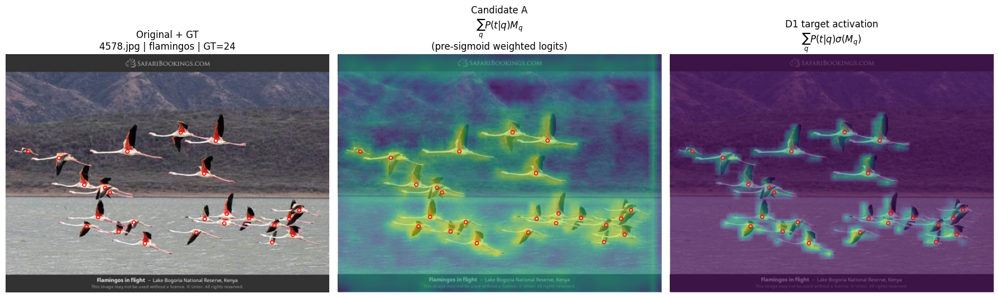

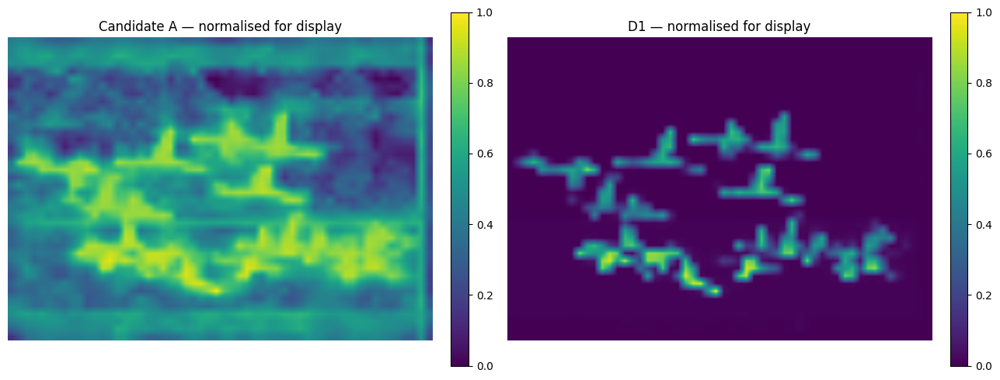


Step 12C.3 complete.


In [154]:
# ============================================================
# Step 12C.3 — Visual comparison:
# Candidate-A target projection vs D1 activation
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import torch


print("=" * 80)
print("STEP 12C.3 — CANDIDATE-A PROJECTION VS D1")
print("=" * 80)


# ------------------------------------------------------------
# 1. Use the same S3 example as Steps 12C.1–12C.2
# ------------------------------------------------------------

example_key = "S3_40_60"

example = d6_cross_density_results[
    example_key
]

image_np = example["image_np"]
gt_points = example["gt_points"]

print("\n[1] Diagnostic sample")
print("-" * 80)

print("Image ID :", example["image_id"])
print("Category :", example["target_category"])
print("GT count :", example["gt_count"])


# ------------------------------------------------------------
# 2. Retrieve the two activation maps
#
# Candidate A:
#   Σ_q P(t|q) * M_q
#
# D1:
#   Σ_q P(t|q) * sigmoid(M_q)
#
# These variables were produced in Step 12C.2.
# ------------------------------------------------------------

candidate_a_map = (
    candidate_a_target_projection[0]
    .detach()
    .cpu()
    .float()
    .numpy()
)

d1_lowres_map = (
    candidate_b_sum[0]
    .detach()
    .cpu()
    .float()
    .numpy()
)


print("\n[2] Activation shapes")
print("-" * 80)

print(
    "Candidate A:",
    candidate_a_map.shape,
)

print(
    "D1         :",
    d1_lowres_map.shape,
)


# ------------------------------------------------------------
# 3. Basic activation statistics
# ------------------------------------------------------------

print("\n[3] Activation statistics")
print("-" * 80)

print(
    "Candidate A:"
)
print(
    f"  min={candidate_a_map.min():.4f}, "
    f"max={candidate_a_map.max():.4f}, "
    f"mean={candidate_a_map.mean():.4f}, "
    f"std={candidate_a_map.std():.4f}"
)

print(
    "\nD1:"
)
print(
    f"  min={d1_lowres_map.min():.4f}, "
    f"max={d1_lowres_map.max():.4f}, "
    f"mean={d1_lowres_map.mean():.4f}, "
    f"std={d1_lowres_map.std():.4f}"
)


# ------------------------------------------------------------
# 4. Min-max normalisation
#
# IMPORTANT:
# Only for visual comparison.
# We retain the raw maps above.
# ------------------------------------------------------------

def minmax_for_display(x):

    x = np.asarray(
        x,
        dtype=np.float32,
    )

    xmin = x.min()
    xmax = x.max()

    if xmax <= xmin:
        return np.zeros_like(x)

    return (
        (x - xmin)
        / (xmax - xmin)
    )


candidate_a_display = minmax_for_display(
    candidate_a_map
)

d1_display = minmax_for_display(
    d1_lowres_map
)


# ------------------------------------------------------------
# 5. Helper — GT overlay
# ------------------------------------------------------------

def draw_gt(
    ax,
    points,
    size=20,
):

    if len(points) == 0:
        return

    ax.scatter(
        points[:, 0],
        points[:, 1],
        s=size,
        facecolors="none",
        edgecolors="red",
        linewidths=1.1,
    )


# ------------------------------------------------------------
# 6. Visual comparison
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    3,
    figsize=(18, 6),
)


# Original
axes[0].imshow(
    image_np
)

draw_gt(
    axes[0],
    gt_points,
)

axes[0].set_title(
    f"Original + GT\n"
    f"{example['image_id']} | "
    f"{example['target_category']} | "
    f"GT={example['gt_count']}"
)

axes[0].axis("off")


# Candidate A
axes[1].imshow(
    image_np
)

axes[1].imshow(
    candidate_a_display,
    alpha=0.60,
    extent=[
        0,
        image_np.shape[1],
        image_np.shape[0],
        0,
    ],
    interpolation="bilinear",
)

draw_gt(
    axes[1],
    gt_points,
)

axes[1].set_title(
    "Candidate A\n"
    r"$\sum_q P(t|q)M_q$"
    "\n(pre-sigmoid weighted logits)"
)

axes[1].axis("off")


# D1
axes[2].imshow(
    image_np
)

axes[2].imshow(
    d1_display,
    alpha=0.60,
    extent=[
        0,
        image_np.shape[1],
        image_np.shape[0],
        0,
    ],
    interpolation="bilinear",
)

draw_gt(
    axes[2],
    gt_points,
)

axes[2].set_title(
    "D1 target activation\n"
    r"$\sum_q P(t|q)\sigma(M_q)$"
)

axes[2].axis("off")


plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 7. Activation maps without the underlying RGB image
#
# This can make local spatial structure easier to compare.
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    2,
    figsize=(13, 5),
)


im_a = axes[0].imshow(
    candidate_a_display,
    interpolation="bilinear",
)

axes[0].set_title(
    "Candidate A — normalised for display"
)

axes[0].axis("off")

plt.colorbar(
    im_a,
    ax=axes[0],
    fraction=0.046,
    pad=0.04,
)


im_d1 = axes[1].imshow(
    d1_display,
    interpolation="bilinear",
)

axes[1].set_title(
    "D1 — normalised for display"
)

axes[1].axis("off")

plt.colorbar(
    im_d1,
    ax=axes[1],
    fraction=0.046,
    pad=0.04,
)


plt.tight_layout()
plt.show()


print("\nStep 12C.3 complete.")

STEP 12C.4 — CANDIDATE-A LOCAL-MAXIMA SANITY CHECK

[1] Diagnostic sample
--------------------------------------------------------------------------------
Image ID : 4578.jpg
Category : flamingos
GT count : 24

[2] Candidate-A activation
--------------------------------------------------------------------------------
Raw range       : -85.1706 to 11.1415
Normalised range: 0.0000 to 1.0000
Activation shape: (40, 56)

[3] Candidate-A local-max results
--------------------------------------------------------------------------------
  min_dist  threshold  dist_px   points     GT
     0.010       0.50        1       99     24
     0.010       0.60        1       70     24
     0.010       0.70        1       51     24
     0.020       0.50        1       99     24
     0.020       0.60        1       70     24
     0.020       0.70        1       51     24
     0.030       0.50        1       99     24
     0.030       0.60        1       70     24
     0.030       0.70        1       51   

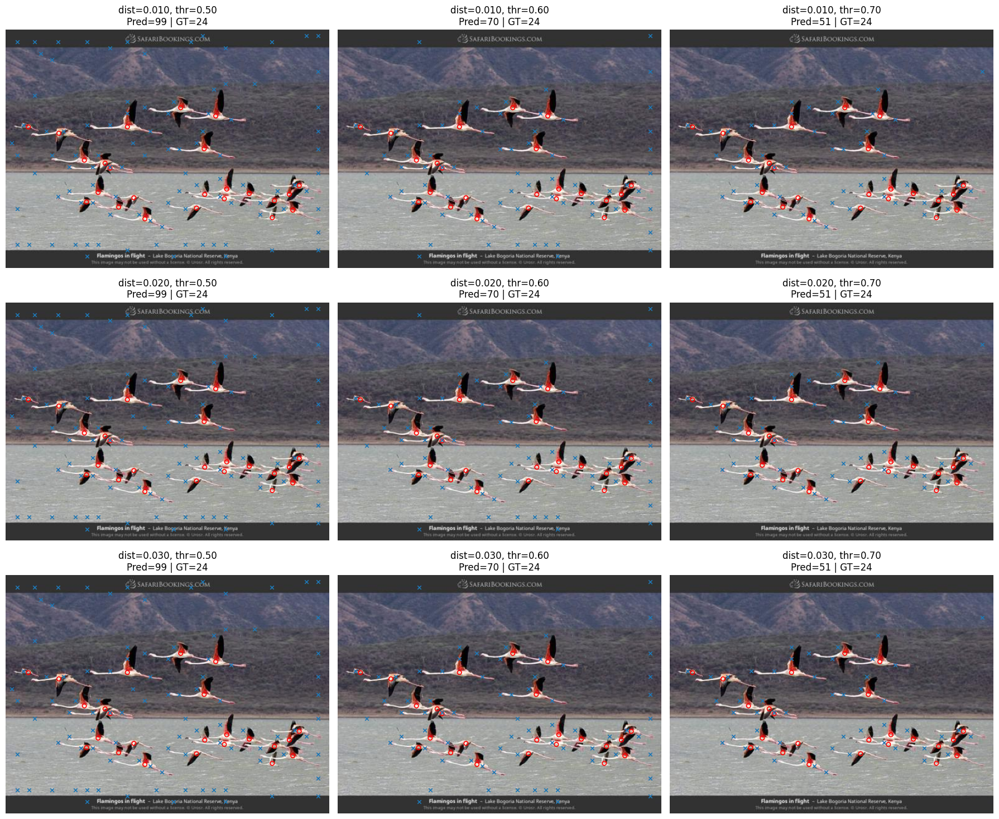


Step 12C.4 complete.


In [155]:
# ============================================================
# Step 12C.4 — Candidate-A local-maxima sanity check
# ============================================================

import numpy as np
import matplotlib.pyplot as plt


print("=" * 80)
print("STEP 12C.4 — CANDIDATE-A LOCAL-MAXIMA SANITY CHECK")
print("=" * 80)


# ------------------------------------------------------------
# 1. Use same S3 diagnostic example as 12C.1–12C.3
# ------------------------------------------------------------

example_key = "S3_40_60"
example = d6_cross_density_results[example_key]

image_np = example["image_np"]
gt_points = np.asarray(example["gt_points"])
gt_count = int(example["gt_count"])

print("\n[1] Diagnostic sample")
print("-" * 80)
print("Image ID :", example["image_id"])
print("Category :", example["target_category"])
print("GT count :", gt_count)


# ------------------------------------------------------------
# 2. Candidate-A activation from Step 12C.2
#
# Raw:
#   A_t = Σ_q P(t|q) M_q
#
# extract_reference_points() expects [0,1], so use min-max
# normalisation before local-max extraction.
# ------------------------------------------------------------

candidate_a_raw = (
    candidate_a_target_projection[0]
    .detach()
    .cpu()
    .float()
    .numpy()
)


def minmax_normalise(x):
    x = np.asarray(x, dtype=np.float32)

    xmin = float(x.min())
    xmax = float(x.max())

    if xmax <= xmin:
        return np.zeros_like(x)

    return (x - xmin) / (xmax - xmin)


candidate_a_norm = minmax_normalise(
    candidate_a_raw
)


print("\n[2] Candidate-A activation")
print("-" * 80)

print(
    "Raw range       :",
    f"{candidate_a_raw.min():.4f}",
    "to",
    f"{candidate_a_raw.max():.4f}",
)

print(
    "Normalised range:",
    f"{candidate_a_norm.min():.4f}",
    "to",
    f"{candidate_a_norm.max():.4f}",
)

print(
    "Activation shape:",
    candidate_a_norm.shape,
)


# ------------------------------------------------------------
# 3. Small DIAGNOSTIC parameter grid
#
# Not a formal parameter sweep.
#
# Include D1 sanity setting:
#   min_distance_frac = 0.01
#   threshold = 0.50
#
# Plus nearby values to see whether Candidate A contains
# stable/useful peak structure.
# ------------------------------------------------------------

D6A_SANITY_MIN_DISTANCE_FRACS = [
    0.01,
    0.02,
    0.03,
]

D6A_SANITY_SCORE_THRESHOLDS = [
    0.50,
    0.60,
    0.70,
]


# ------------------------------------------------------------
# 4. Extract Candidate-A reference points
#
# IMPORTANT:
# Reuse EXACTLY the existing Group-D extractor used by D1.
# ------------------------------------------------------------

d6a_sanity_results = []

for min_distance_frac in D6A_SANITY_MIN_DISTANCE_FRACS:

    for score_threshold in D6A_SANITY_SCORE_THRESHOLDS:

        points_xy, points_yx, min_distance_px = (
            extract_reference_points(
                candidate_a_norm,
                min_distance_frac=min_distance_frac,
                score_threshold=score_threshold,
            )
        )

        d6a_sanity_results.append({
            "min_distance_frac": min_distance_frac,
            "score_threshold": score_threshold,
            "min_distance_px": min_distance_px,
            "points_xy": points_xy,
            "points_yx": points_yx,
            "n_points": len(points_xy),
        })


# ------------------------------------------------------------
# 5. Print diagnostic counts
# ------------------------------------------------------------

print("\n[3] Candidate-A local-max results")
print("-" * 80)

print(
    f"{'min_dist':>10} "
    f"{'threshold':>10} "
    f"{'dist_px':>8} "
    f"{'points':>8} "
    f"{'GT':>6}"
)

for result in d6a_sanity_results:

    print(
        f"{result['min_distance_frac']:>10.3f} "
        f"{result['score_threshold']:>10.2f} "
        f"{result['min_distance_px']:>8d} "
        f"{result['n_points']:>8d} "
        f"{gt_count:>6d}"
    )


# ------------------------------------------------------------
# 6. Visualise all 9 configurations
#
# Candidate-A activation is low-resolution, but points returned
# by extract_reference_points() are in the coordinate system of
# the activation map. Convert them to original-image coordinates
# for overlay.
# ------------------------------------------------------------

H_img, W_img = image_np.shape[:2]
H_map, W_map = candidate_a_norm.shape

scale_x = W_img / W_map
scale_y = H_img / H_map


fig, axes = plt.subplots(
    3,
    3,
    figsize=(18, 15),
)

axes = axes.ravel()


for ax, result in zip(
    axes,
    d6a_sanity_results,
):

    ax.imshow(image_np)

    # GT points
    if len(gt_points) > 0:
        ax.scatter(
            gt_points[:, 0],
            gt_points[:, 1],
            s=28,
            facecolors="none",
            edgecolors="red",
            linewidths=1.2,
            label="GT",
        )

    # Candidate-A predicted points
    points_xy = result["points_xy"]

    if len(points_xy) > 0:

        points_xy_img = (
            points_xy.astype(np.float32).copy()
        )

        points_xy_img[:, 0] *= scale_x
        points_xy_img[:, 1] *= scale_y

        ax.scatter(
            points_xy_img[:, 0],
            points_xy_img[:, 1],
            s=22,
            marker="x",
            linewidths=1.2,
            label="Candidate A",
        )

    ax.set_title(
        f"dist={result['min_distance_frac']:.3f}, "
        f"thr={result['score_threshold']:.2f}\n"
        f"Pred={result['n_points']} | GT={gt_count}"
    )

    ax.axis("off")


plt.tight_layout()
plt.show()


print("\nStep 12C.4 complete.")

### Step 12C.4 observation — Candidate-A local-maxima sanity check

Candidate A was tested using the same local-maxima extraction function used for D1.

For the S3 diagnostic image (`4578.jpg`, flamingos, GT = 24), Candidate A produced
99, 70 and 51 reference points at normalised score thresholds of 0.50, 0.60 and
0.70 respectively. Visual inspection showed that some predicted peaks were located
on or near target objects, confirming that the Candidate-A activation contains
target-related spatial information. However, substantial non-target/background
activation remained, resulting in considerable over-generation.

The tested `min_distance_frac` values (0.01, 0.02 and 0.03) all resulted in a
minimum separation of one feature-grid cell because Candidate A has a low spatial
resolution of only 40 × 56 for this image. Therefore, these settings did not
constitute meaningfully different spatial-separation conditions.

This step is consequently treated only as a local-maxima feasibility check, not as
parameter optimisation or a formal comparison with D1. Before Candidate A can be
evaluated fairly against D1, its low-resolution reference-point localisation must
be handled explicitly.

STEP 12C.5 — CANDIDATE-A SPATIAL-RESOLUTION INVESTIGATION

[1] Diagnostic sample
--------------------------------------------------------------------------------
Image ID       : 4578.jpg
Category       : flamingos
GT count       : 24
Image size     : (384, 522)

[2] Spatial-resolution relationship
--------------------------------------------------------------------------------
Feature-map size : (40, 56)
Image size       : (384, 522)
Scale X          : 9.321428571428571
Scale Y          : 9.6
Image short side : 384
Feature short side: 40

[3] Bilinear upsampling
--------------------------------------------------------------------------------
Low-resolution shape : (40, 56)
Upsampled shape      : (384, 522)
Upsampled range      : 0.0000 to 1.0000

[4] Peak-count comparison
--------------------------------------------------------------------------------
 dist_frac   img_px  feat_px   lowres   upsample     GT
     0.010        4        1       51         62     24
     0.020        8    

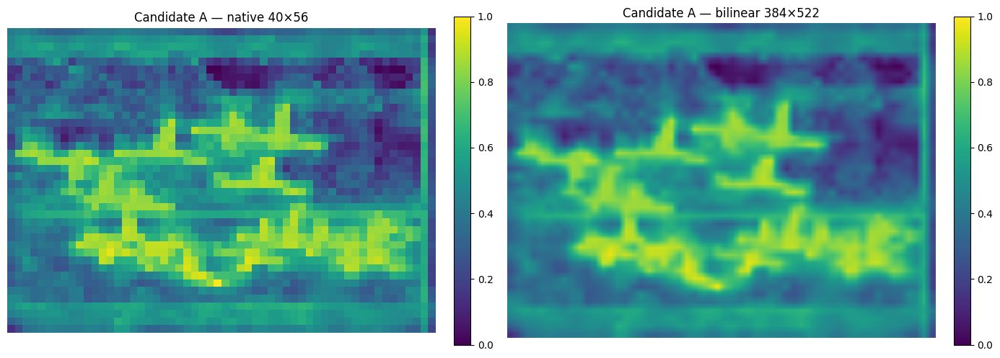

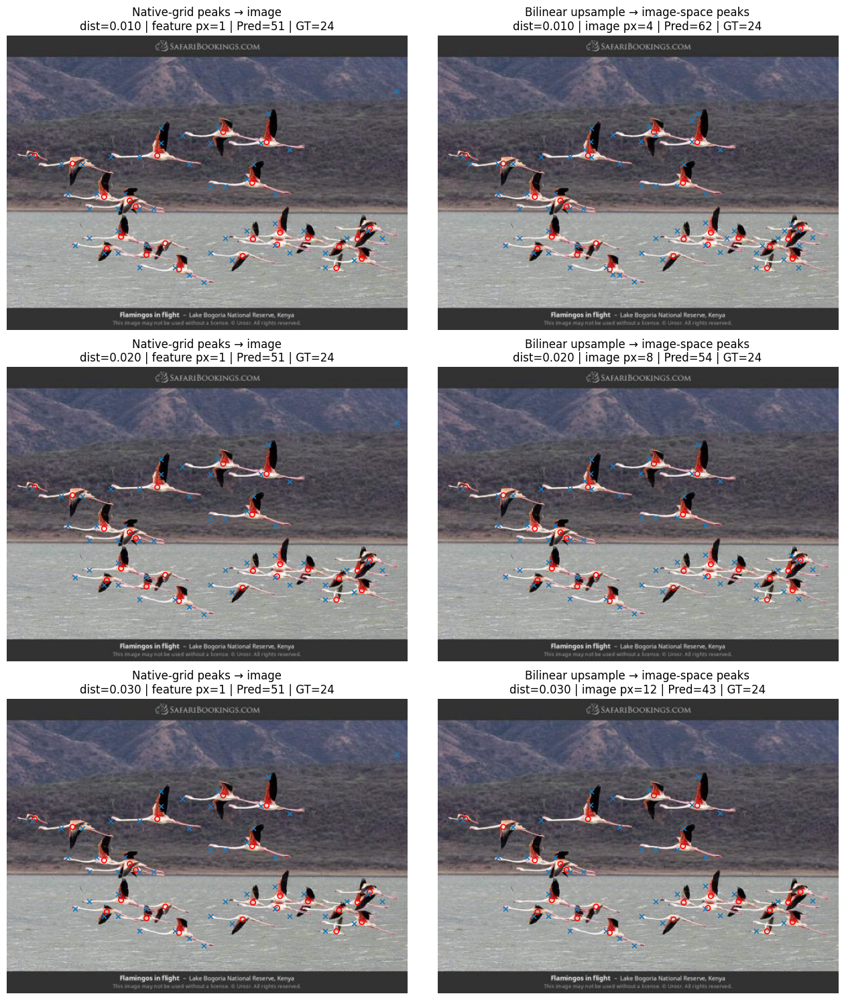


Step 12C.5 complete.


In [156]:
# ============================================================
# Step 12C.5 — Candidate-A spatial-resolution investigation
#
# Compare:
#
#   Route 1:
#     low-resolution activation
#       -> local maxima on feature grid
#       -> map peak coordinates to image
#
#   Route 2:
#     low-resolution activation
#       -> bilinear upsampling to image resolution
#       -> local maxima in image coordinates
#
# No Gaussian refinement yet.
# ============================================================

import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from skimage.feature import peak_local_max


print("=" * 80)
print("STEP 12C.5 — CANDIDATE-A SPATIAL-RESOLUTION INVESTIGATION")
print("=" * 80)


# ------------------------------------------------------------
# 1. Same controlled S3 diagnostic example
# ------------------------------------------------------------

example_key = "S3_40_60"
example = d6_cross_density_results[example_key]

image_np = np.asarray(example["image_np"])
gt_points = np.asarray(
    example["gt_points"],
    dtype=np.float32,
)

gt_count = int(example["gt_count"])

H_img, W_img = image_np.shape[:2]


print("\n[1] Diagnostic sample")
print("-" * 80)

print("Image ID       :", example["image_id"])
print("Category       :", example["target_category"])
print("GT count       :", gt_count)
print("Image size     :", (H_img, W_img))


# ------------------------------------------------------------
# 2. Retrieve Candidate-A activation from Step 12C.2
# ------------------------------------------------------------

candidate_a_raw = (
    candidate_a_target_projection[0]
    .detach()
    .cpu()
    .float()
    .numpy()
)

H_feat, W_feat = candidate_a_raw.shape


def minmax_normalise(x):

    x = np.asarray(
        x,
        dtype=np.float32,
    )

    xmin = float(x.min())
    xmax = float(x.max())

    if xmax <= xmin:
        return np.zeros_like(x)

    return (
        (x - xmin)
        / (xmax - xmin)
    )


candidate_a_lowres = minmax_normalise(
    candidate_a_raw
)


print("\n[2] Spatial-resolution relationship")
print("-" * 80)

print(
    "Feature-map size :",
    (H_feat, W_feat),
)

print(
    "Image size       :",
    (H_img, W_img),
)

print(
    "Scale X          :",
    W_img / W_feat,
)

print(
    "Scale Y          :",
    H_img / H_feat,
)

print(
    "Image short side :",
    min(H_img, W_img),
)

print(
    "Feature short side:",
    min(H_feat, W_feat),
)


# ------------------------------------------------------------
# 3. Bilinearly upsample Candidate A to image resolution
#
# IMPORTANT:
# This is interpolation only.
# It is NOT Gaussian refinement.
# ------------------------------------------------------------

candidate_a_tensor = torch.from_numpy(
    candidate_a_lowres
)[None, None].float()


with torch.no_grad():

    candidate_a_upsampled = (
        F.interpolate(
            candidate_a_tensor,
            size=(H_img, W_img),
            mode="bilinear",
            align_corners=False,
        )[0, 0]
        .cpu()
        .numpy()
    )


# Re-normalise after interpolation for numerical consistency.
candidate_a_upsampled = minmax_normalise(
    candidate_a_upsampled
)


print("\n[3] Bilinear upsampling")
print("-" * 80)

print(
    "Low-resolution shape :",
    candidate_a_lowres.shape,
)

print(
    "Upsampled shape      :",
    candidate_a_upsampled.shape,
)

print(
    "Upsampled range      :",
    f"{candidate_a_upsampled.min():.4f}",
    "to",
    f"{candidate_a_upsampled.max():.4f}",
)


# ------------------------------------------------------------
# 4. Controlled diagnostic parameters
#
# Use one threshold initially.
#
# min_distance_frac is now explicitly defined relative
# to ORIGINAL IMAGE short side.
# ------------------------------------------------------------

SANITY_THRESHOLD = 0.70

SANITY_DISTANCE_FRACS = [
    0.01,
    0.02,
    0.03,
]


# ------------------------------------------------------------
# 5. Route 1:
#    Detect peaks on low-resolution feature map.
#
# Convert desired IMAGE-space minimum distance into
# feature-grid distance.
# ------------------------------------------------------------

route1_results = []


for distance_frac in SANITY_DISTANCE_FRACS:

    image_distance_px = max(
        1,
        int(round(
            distance_frac
            * min(H_img, W_img)
        ))
    )

    # Approximate image pixels represented by one feature cell.
    feature_scale = (
        min(H_img, W_img)
        / min(H_feat, W_feat)
    )

    feature_distance_px = max(
        1,
        int(round(
            image_distance_px
            / feature_scale
        ))
    )

    points_yx_low = peak_local_max(
        candidate_a_lowres,
        min_distance=feature_distance_px,
        threshold_abs=SANITY_THRESHOLD,
        exclude_border=False,
    )

    # Convert feature-grid coordinates to image coordinates.
    #
    # Use cell-centre mapping rather than simply multiplying
    # the integer coordinate.
    if len(points_yx_low) > 0:

        points_xy_image = np.empty(
            (len(points_yx_low), 2),
            dtype=np.float32,
        )

        points_xy_image[:, 0] = (
            (points_yx_low[:, 1] + 0.5)
            * W_img
            / W_feat
        )

        points_xy_image[:, 1] = (
            (points_yx_low[:, 0] + 0.5)
            * H_img
            / H_feat
        )

    else:

        points_xy_image = np.empty(
            (0, 2),
            dtype=np.float32,
        )

    route1_results.append({
        "distance_frac": distance_frac,
        "image_distance_px": image_distance_px,
        "feature_distance_px": feature_distance_px,
        "points_xy": points_xy_image,
        "n_points": len(points_xy_image),
    })


# ------------------------------------------------------------
# 6. Route 2:
#    Upsample first, then detect peaks directly in image space.
# ------------------------------------------------------------

route2_results = []


for distance_frac in SANITY_DISTANCE_FRACS:

    image_distance_px = max(
        1,
        int(round(
            distance_frac
            * min(H_img, W_img)
        ))
    )

    points_yx_image = peak_local_max(
        candidate_a_upsampled,
        min_distance=image_distance_px,
        threshold_abs=SANITY_THRESHOLD,
        exclude_border=False,
    )

    if len(points_yx_image) > 0:

        points_xy_image = (
            points_yx_image[:, [1, 0]]
            .astype(np.float32)
        )

    else:

        points_xy_image = np.empty(
            (0, 2),
            dtype=np.float32,
        )

    route2_results.append({
        "distance_frac": distance_frac,
        "image_distance_px": image_distance_px,
        "points_xy": points_xy_image,
        "n_points": len(points_xy_image),
    })


# ------------------------------------------------------------
# 7. Print comparison
# ------------------------------------------------------------

print("\n[4] Peak-count comparison")
print("-" * 80)

print(
    f"{'dist_frac':>10} "
    f"{'img_px':>8} "
    f"{'feat_px':>8} "
    f"{'lowres':>8} "
    f"{'upsample':>10} "
    f"{'GT':>6}"
)

for r1, r2 in zip(
    route1_results,
    route2_results,
):

    print(
        f"{r1['distance_frac']:>10.3f} "
        f"{r1['image_distance_px']:>8d} "
        f"{r1['feature_distance_px']:>8d} "
        f"{r1['n_points']:>8d} "
        f"{r2['n_points']:>10d} "
        f"{gt_count:>6d}"
    )


# ------------------------------------------------------------
# 8. Visualise activation maps
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5),
)


im0 = axes[0].imshow(
    candidate_a_lowres,
    interpolation="nearest",
)

axes[0].set_title(
    f"Candidate A — native {H_feat}×{W_feat}"
)

axes[0].axis("off")

plt.colorbar(
    im0,
    ax=axes[0],
    fraction=0.046,
    pad=0.04,
)


im1 = axes[1].imshow(
    candidate_a_upsampled,
    interpolation="nearest",
)

axes[1].set_title(
    f"Candidate A — bilinear {H_img}×{W_img}"
)

axes[1].axis("off")

plt.colorbar(
    im1,
    ax=axes[1],
    fraction=0.046,
    pad=0.04,
)


plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 9. Visualise reference points for both routes
# ------------------------------------------------------------

fig, axes = plt.subplots(
    len(SANITY_DISTANCE_FRACS),
    2,
    figsize=(13, 15),
)


for row, (r1, r2) in enumerate(
    zip(
        route1_results,
        route2_results,
    )
):

    # --------------------------------------------------------
    # Route 1
    # --------------------------------------------------------

    ax = axes[row, 0]

    ax.imshow(image_np)

    if len(gt_points) > 0:

        ax.scatter(
            gt_points[:, 0],
            gt_points[:, 1],
            s=28,
            facecolors="none",
            edgecolors="red",
            linewidths=1.2,
            label="GT",
        )

    if len(r1["points_xy"]) > 0:

        ax.scatter(
            r1["points_xy"][:, 0],
            r1["points_xy"][:, 1],
            s=24,
            marker="x",
            linewidths=1.2,
            label="Candidate A",
        )

    ax.set_title(
        "Native-grid peaks → image\n"
        f"dist={r1['distance_frac']:.3f} | "
        f"feature px={r1['feature_distance_px']} | "
        f"Pred={r1['n_points']} | GT={gt_count}"
    )

    ax.axis("off")


    # --------------------------------------------------------
    # Route 2
    # --------------------------------------------------------

    ax = axes[row, 1]

    ax.imshow(image_np)

    if len(gt_points) > 0:

        ax.scatter(
            gt_points[:, 0],
            gt_points[:, 1],
            s=28,
            facecolors="none",
            edgecolors="red",
            linewidths=1.2,
            label="GT",
        )

    if len(r2["points_xy"]) > 0:

        ax.scatter(
            r2["points_xy"][:, 0],
            r2["points_xy"][:, 1],
            s=24,
            marker="x",
            linewidths=1.2,
            label="Candidate A",
        )

    ax.set_title(
        "Bilinear upsample → image-space peaks\n"
        f"dist={r2['distance_frac']:.3f} | "
        f"image px={r2['image_distance_px']} | "
        f"Pred={r2['n_points']} | GT={gt_count}"
    )

    ax.axis("off")


plt.tight_layout()
plt.show()


print("\nStep 12C.5 complete.")

### Step 12C.6 — Gaussian reference-point refinement investigation

Candidate A produces a low-resolution target-specific activation map. Step 12C.5
showed that direct peak detection on this feature grid suffers from spatial
quantisation: different image-space minimum-distance settings can collapse to the
same feature-grid separation.

OmniCount reports a related problem for its intermediate feature activation
\(F_P\). It first identifies local maxima \(P\) in the low-resolution activation,
then applies Gaussian refinement to obtain corrected reference points \(P'\),
motivated by quantisation errors that can make direct upsampling misalign the
points.

However, the OmniCount paper does not provide sufficient implementation detail in
this passage to reproduce the Gaussian refinement directly. It attributes the
procedure to Zhang et al. (2020).

Therefore, before implementing Gaussian refinement for Candidate A, the next
sub-step is to identify the cited Zhang et al. (2020) method and determine:

1. what quantity the Gaussian is applied to;
2. whether the operation smooths an activation map or refines already detected
   reference-point coordinates;
3. how corrected coordinates are computed;
4. what Gaussian parameters are required; and
5. whether the method is applicable to Candidate A without assuming that
   Candidate A is equivalent to OmniCount's \(F_P\).

No Gaussian operation is implemented until this procedure is technically
established.

### D6 checkpoint — end of session

Completed:
- Step 12C.1 — inspected SAN learned transformations.
- Step 12C.2 — derived SAN-native target-specific Candidate-A activation.
- Step 12C.3 — compared Candidate A visually with D1.
- Step 12C.4 — Candidate-A local-maxima feasibility check.
- Step 12C.5 — investigated low-resolution vs bilinear-upsampled peak localisation.

Current Candidate-A status:
- Candidate A contains target-related spatial information.
- It also contains substantial background/non-target activation.
- Its low spatial resolution introduces a reference-point quantisation/localisation issue.
- Candidate A has NOT been accepted or rejected yet.
- No formal dev100 D6 evaluation or parameter selection has been performed.

Next:
- Step 12C.6 — study Zhang et al. (2020) / DARK Gaussian and sub-pixel
  coordinate refinement in detail.
- Decide which parts, if any, are scientifically justified for Candidate A.
- Do not implement Gaussian refinement until this decision is made.

Candidate B remains pending and will be investigated separately after
Candidate A. Any Gaussian/sub-pixel refinement for Candidate B should only
be considered after a principled Candidate-B reference-point generation
method has been established.

### Step 12C.6 — DARK-inspired Candidate-A coordinate refinement

Candidate A is a low-resolution, multi-object semantic activation rather than a
Gaussian keypoint heatmap. Therefore, DARK coordinate decoding is **adapted as an
experimental refinement method**, rather than reproduced directly.

#### Experimental design

Four Candidate-A variants are compared:

- **D6A0:** activation → native local peaks
- **D6A1:** activation → Gaussian modulation → local peaks
- **D6A2:** activation → Gaussian modulation → local peaks → Taylor refinement
- **D6A3:** activation → native local peaks → Taylor refinement

This ablation separates the effects of Gaussian modulation and Taylor sub-pixel
localisation.

#### Parameter policy

Initial diagnostic ranges:

- `score_threshold`: {0.50, 0.60, 0.70}
- `min_distance_frac`: {0.01, 0.02, 0.03}
- Gaussian `sigma`: {0.5, 1.0, 1.5} feature-grid cells

Taylor refinement uses the local activation neighbourhood with predefined validity
checks; invalid or unstable refinements retain the original discrete peak.

These ranges are for diagnostic screening only. Final parameter selection will use
the frozen dev100 subset with one-to-one **F1@3%** as the primary metric. Search
boundaries will be expanded only if the best formal result occurs at a tested
boundary.

In [157]:
# ============================================================
# Step 12C.6.1 — Implement DARK-inspired refinement components
#
# Purpose:
#   1. Implement magnitude-preserving Gaussian modulation.
#   2. Implement local Taylor sub-pixel peak refinement.
#   3. Verify numerical behaviour on the existing S3 example.
#
# This is an implementation sanity check only.
# No parameter selection is performed here.
# ============================================================

import numpy as np
from scipy.ndimage import gaussian_filter
from skimage.feature import peak_local_max


print("=" * 80)
print("STEP 12C.6.1 — DARK-INSPIRED REFINEMENT COMPONENTS")
print("=" * 80)


# ------------------------------------------------------------
# 1. Retrieve the same controlled S3 diagnostic example
# ------------------------------------------------------------

example_key = "S3_40_60"
example = d6_cross_density_results[example_key]

image_id = example["image_id"]
category = example["target_category"]
gt_count = int(example["gt_count"])

image_np = np.asarray(example["image_np"])
H_img, W_img = image_np.shape[:2]


# Candidate-A activation produced in Step 12C.2
candidate_a_raw = (
    candidate_a_target_projection[0]
    .detach()
    .cpu()
    .float()
    .numpy()
)


def minmax_normalise(x):
    x = np.asarray(x, dtype=np.float64)

    xmin = float(np.min(x))
    xmax = float(np.max(x))

    if xmax <= xmin:
        return np.zeros_like(x)

    return (x - xmin) / (xmax - xmin)


candidate_a = minmax_normalise(candidate_a_raw)

H_feat, W_feat = candidate_a.shape


print("\n[1] Diagnostic sample")
print("-" * 80)
print("Image ID          :", image_id)
print("Category          :", category)
print("GT count          :", gt_count)
print("Image size        :", (H_img, W_img))
print("Candidate-A shape :", candidate_a.shape)
print(
    "Candidate-A range :",
    f"{candidate_a.min():.4f} to {candidate_a.max():.4f}"
)


# ------------------------------------------------------------
# 2. Magnitude-preserving Gaussian modulation
#
# Gaussian smoothing normally reduces the maximum activation.
# We restore the original maximum after smoothing.
#
# Since Candidate A is min-max normalised here, original max=1.
# ------------------------------------------------------------

def gaussian_modulate(
    activation,
    sigma,
):
    activation = np.asarray(
        activation,
        dtype=np.float64,
    )

    original_max = float(
        np.max(activation)
    )

    smoothed = gaussian_filter(
        activation,
        sigma=float(sigma),
        mode="nearest",
    )

    smoothed_max = float(
        np.max(smoothed)
    )

    if (
        original_max > 0
        and smoothed_max > 0
    ):
        smoothed = (
            smoothed
            * original_max
            / smoothed_max
        )

    return smoothed


SIGMAS = [
    0.5,
    1.0,
    1.5,
]


gaussian_maps = {
    sigma: gaussian_modulate(
        candidate_a,
        sigma,
    )
    for sigma in SIGMAS
}


print("\n[2] Gaussian modulation")
print("-" * 80)

print(
    f"{'sigma':>8}"
    f"{'min':>12}"
    f"{'max':>12}"
    f"{'mean':>12}"
    f"{'std':>12}"
)

for sigma in SIGMAS:

    x = gaussian_maps[sigma]

    print(
        f"{sigma:>8.2f}"
        f"{x.min():>12.4f}"
        f"{x.max():>12.4f}"
        f"{x.mean():>12.4f}"
        f"{x.std():>12.4f}"
    )


# ------------------------------------------------------------
# 3. DARK-inspired Taylor sub-pixel refinement
#
# For each discrete local maximum:
#
#     delta = - H^{-1} g
#
# calculated from log activation using central finite
# differences.
#
# Safeguards:
#   - peak must have a full 3x3 neighbourhood
#   - activation is protected before log()
#   - Hessian must be finite and well-conditioned
#   - refined displacement must stay within +/- 1 feature cell
#
# Invalid refinements retain the original discrete peak.
#
# Input/output convention:
#     peak = [row(y), column(x)]
# ------------------------------------------------------------

def taylor_refine_peak(
    activation,
    peak_yx,
    eps=1e-10,
    max_offset=1.0,
    condition_limit=1e6,
):

    activation = np.asarray(
        activation,
        dtype=np.float64,
    )

    y = int(peak_yx[0])
    x = int(peak_yx[1])

    H, W = activation.shape

    result = {
        "original_y": float(y),
        "original_x": float(x),
        "refined_y": float(y),
        "refined_x": float(x),
        "offset_y": 0.0,
        "offset_x": 0.0,
        "valid": False,
        "reason": "",
    }


    # --------------------------------------------------------
    # Boundary check
    # --------------------------------------------------------

    if (
        y <= 0
        or y >= H - 1
        or x <= 0
        or x >= W - 1
    ):
        result["reason"] = "boundary"
        return result


    # --------------------------------------------------------
    # Log activation
    # --------------------------------------------------------

    local = activation[
        y - 1:y + 2,
        x - 1:x + 2,
    ]

    local = np.maximum(
        local,
        eps,
    )

    log_local = np.log(local)


    # --------------------------------------------------------
    # Gradient at centre
    #
    # x = columns
    # y = rows
    # --------------------------------------------------------

    dx = 0.5 * (
        log_local[1, 2]
        - log_local[1, 0]
    )

    dy = 0.5 * (
        log_local[2, 1]
        - log_local[0, 1]
    )

    gradient = np.array(
        [dx, dy],
        dtype=np.float64,
    )


    # --------------------------------------------------------
    # Hessian
    # --------------------------------------------------------

    dxx = (
        log_local[1, 2]
        - 2.0 * log_local[1, 1]
        + log_local[1, 0]
    )

    dyy = (
        log_local[2, 1]
        - 2.0 * log_local[1, 1]
        + log_local[0, 1]
    )

    dxy = 0.25 * (
        log_local[2, 2]
        - log_local[2, 0]
        - log_local[0, 2]
        + log_local[0, 0]
    )

    hessian = np.array(
        [
            [dxx, dxy],
            [dxy, dyy],
        ],
        dtype=np.float64,
    )


    # --------------------------------------------------------
    # Numerical validity
    # --------------------------------------------------------

    if not (
        np.all(np.isfinite(gradient))
        and np.all(np.isfinite(hessian))
    ):
        result["reason"] = "non_finite"
        return result


    try:
        condition_number = np.linalg.cond(
            hessian
        )
    except np.linalg.LinAlgError:
        result["reason"] = "condition_error"
        return result


    if (
        not np.isfinite(condition_number)
        or condition_number > condition_limit
    ):
        result["reason"] = "ill_conditioned"
        return result


    # --------------------------------------------------------
    # Taylor offset
    # --------------------------------------------------------

    try:
        delta = -np.linalg.solve(
            hessian,
            gradient,
        )
    except np.linalg.LinAlgError:
        result["reason"] = "solve_error"
        return result


    delta_x = float(delta[0])
    delta_y = float(delta[1])


    if not (
        np.isfinite(delta_x)
        and np.isfinite(delta_y)
    ):
        result["reason"] = "non_finite_offset"
        return result


    # --------------------------------------------------------
    # Local-validity safeguard
    #
    # Do NOT clip large offsets.
    # Reject them and retain the discrete peak.
    # --------------------------------------------------------

    if (
        abs(delta_x) > max_offset
        or abs(delta_y) > max_offset
    ):
        result["reason"] = "offset_too_large"
        return result


    # --------------------------------------------------------
    # Valid refinement
    # --------------------------------------------------------

    result["refined_x"] = (
        float(x) + delta_x
    )

    result["refined_y"] = (
        float(y) + delta_y
    )

    result["offset_x"] = delta_x
    result["offset_y"] = delta_y

    result["valid"] = True
    result["reason"] = "valid"

    return result


# ------------------------------------------------------------
# 4. Sanity-test Taylor refinement
#
# Use ONE fixed diagnostic setting only:
#
# threshold = 0.70
# min_distance_frac = 0.03
#
# Detect peaks on:
#   A. native Candidate A
#   B. sigma=1.0 Gaussian-modulated Candidate A
#
# This is NOT parameter selection.
# ------------------------------------------------------------

SANITY_THRESHOLD = 0.70
SANITY_DISTANCE_FRAC = 0.03
SANITY_SIGMA = 1.0


# As established in Step 12C.5:
# convert image-space separation to feature-grid separation.

image_distance_px = max(
    1,
    int(round(
        SANITY_DISTANCE_FRAC
        * min(H_img, W_img)
    ))
)

feature_scale = (
    min(H_img, W_img)
    / min(H_feat, W_feat)
)

feature_distance_px = max(
    1,
    int(round(
        image_distance_px
        / feature_scale
    ))
)


native_peaks = peak_local_max(
    candidate_a,
    min_distance=feature_distance_px,
    threshold_abs=SANITY_THRESHOLD,
    exclude_border=False,
)


gaussian_test_map = gaussian_maps[
    SANITY_SIGMA
]

gaussian_peaks = peak_local_max(
    gaussian_test_map,
    min_distance=feature_distance_px,
    threshold_abs=SANITY_THRESHOLD,
    exclude_border=False,
)


native_refined = [
    taylor_refine_peak(
        candidate_a,
        peak,
    )
    for peak in native_peaks
]


gaussian_refined = [
    taylor_refine_peak(
        gaussian_test_map,
        peak,
    )
    for peak in gaussian_peaks
]


# ------------------------------------------------------------
# 5. Summarise Taylor behaviour
# ------------------------------------------------------------

def summarise_refinement(results):

    n_total = len(results)

    valid = [
        r for r in results
        if r["valid"]
    ]

    invalid = [
        r for r in results
        if not r["valid"]
    ]

    if len(valid) > 0:

        offsets = np.array(
            [
                [
                    r["offset_x"],
                    r["offset_y"],
                ]
                for r in valid
            ],
            dtype=np.float64,
        )

        magnitudes = np.sqrt(
            np.sum(
                offsets ** 2,
                axis=1,
            )
        )

        mean_offset = float(
            np.mean(magnitudes)
        )

        max_offset = float(
            np.max(magnitudes)
        )

    else:

        mean_offset = np.nan
        max_offset = np.nan


    reason_counts = {}

    for r in invalid:
        reason = r["reason"]

        reason_counts[reason] = (
            reason_counts.get(
                reason,
                0,
            )
            + 1
        )


    return {
        "n_total": n_total,
        "n_valid": len(valid),
        "n_invalid": len(invalid),
        "mean_offset": mean_offset,
        "max_offset": max_offset,
        "invalid_reasons": reason_counts,
    }


native_summary = summarise_refinement(
    native_refined
)

gaussian_summary = summarise_refinement(
    gaussian_refined
)


print("\n[3] Taylor refinement sanity check")
print("-" * 80)

print(
    "Diagnostic threshold     :",
    SANITY_THRESHOLD,
)

print(
    "min_distance_frac        :",
    SANITY_DISTANCE_FRAC,
)

print(
    "Image separation (px)    :",
    image_distance_px,
)

print(
    "Feature separation (cell):",
    feature_distance_px,
)

print(
    "Gaussian sigma           :",
    SANITY_SIGMA,
)


print("\nNative Candidate A")
print(
    "  Peaks                  :",
    native_summary["n_total"],
)
print(
    "  Valid refinements      :",
    native_summary["n_valid"],
)
print(
    "  Invalid refinements    :",
    native_summary["n_invalid"],
)
print(
    "  Mean valid offset      :",
    native_summary["mean_offset"],
)
print(
    "  Max valid offset       :",
    native_summary["max_offset"],
)
print(
    "  Invalid reasons        :",
    native_summary["invalid_reasons"],
)


print("\nGaussian-modulated Candidate A")
print(
    "  Peaks                  :",
    gaussian_summary["n_total"],
)
print(
    "  Valid refinements      :",
    gaussian_summary["n_valid"],
)
print(
    "  Invalid refinements    :",
    gaussian_summary["n_invalid"],
)
print(
    "  Mean valid offset      :",
    gaussian_summary["mean_offset"],
)
print(
    "  Max valid offset       :",
    gaussian_summary["max_offset"],
)
print(
    "  Invalid reasons        :",
    gaussian_summary["invalid_reasons"],
)


# ------------------------------------------------------------
# 6. Show first few valid refinements
# ------------------------------------------------------------

def print_examples(
    results,
    title,
    n=8,
):

    print(f"\n{title}")
    print("-" * 80)

    valid = [
        r for r in results
        if r["valid"]
    ]

    print(
        f"{'original(x,y)':>20}"
        f"{'refined(x,y)':>24}"
        f"{'offset(dx,dy)':>24}"
    )

    for r in valid[:n]:

        original = (
            f"({r['original_x']:.2f},"
            f"{r['original_y']:.2f})"
        )

        refined = (
            f"({r['refined_x']:.3f},"
            f"{r['refined_y']:.3f})"
        )

        offset = (
            f"({r['offset_x']:+.3f},"
            f"{r['offset_y']:+.3f})"
        )

        print(
            f"{original:>20}"
            f"{refined:>24}"
            f"{offset:>24}"
        )


print_examples(
    native_refined,
    "[4] Example native-map Taylor refinements",
)

print_examples(
    gaussian_refined,
    "[5] Example Gaussian-map Taylor refinements",
)


print("\nStep 12C.6.1 complete.")

STEP 12C.6.1 — DARK-INSPIRED REFINEMENT COMPONENTS

[1] Diagnostic sample
--------------------------------------------------------------------------------
Image ID          : 4578.jpg
Category          : flamingos
GT count          : 24
Image size        : (384, 522)
Candidate-A shape : (40, 56)
Candidate-A range : 0.0000 to 1.0000

[2] Gaussian modulation
--------------------------------------------------------------------------------
   sigma         min         max        mean         std
    0.50      0.0250      1.0000      0.5193      0.2007
    1.00      0.1066      1.0000      0.5673      0.1935
    1.50      0.1859      1.0000      0.5929      0.1855

[3] Taylor refinement sanity check
--------------------------------------------------------------------------------
Diagnostic threshold     : 0.7
min_distance_frac        : 0.03
Image separation (px)    : 12
Feature separation (cell): 1
Gaussian sigma           : 1.0

Native Candidate A
  Peaks                  : 51
  Valid refi

In [158]:
# ============================================================
# Step 12C.6.2 — Single-image localisation-effect sanity check
#
# Compare:
#   D6A0: native activation -> peaks
#   D6A1: Gaussian modulation -> peaks
#   D6A2: Gaussian modulation -> peaks -> Taylor refinement
#   D6A3: native activation -> peaks -> Taylor refinement
#
# Fixed diagnostic setting only:
#   threshold         = 0.70
#   min_distance_frac = 0.03
#   sigma             = 1.0
#
# Primary diagnostic:
#   one-to-one point matching at 3% of image short side
#
# No parameter selection is performed here.
# ============================================================

import numpy as np
from scipy.optimize import linear_sum_assignment


print("=" * 80)
print("STEP 12C.6.2 — SINGLE-IMAGE LOCALISATION EFFECT")
print("=" * 80)


# ------------------------------------------------------------
# 1. Recover GT points for the diagnostic sample
# ------------------------------------------------------------

dataset_index = int(
    fsc147_dev_100_df.loc[
        fsc147_dev_100_df["image_id"] == image_id,
        "dataset_index"
    ].iloc[0]
)

sample = fsc147_val_dataset[dataset_index]

gt_points_xy = np.asarray(
    sample["categories"][category]["points"],
    dtype=np.float64
)

assert len(gt_points_xy) == gt_count


print("\n[1] Diagnostic sample")
print("-" * 80)
print("Image ID          :", image_id)
print("Category          :", category)
print("GT count          :", gt_count)
print("Image size        :", (H_img, W_img))
print("Feature-map size  :", (H_feat, W_feat))
print("GT points shape   :", gt_points_xy.shape)


# ------------------------------------------------------------
# 2. Coordinate conversion
#
# Feature coordinates are continuous:
#   x in [0, W_feat-1]
#   y in [0, H_feat-1]
#
# Map them consistently into original-image coordinates.
# ------------------------------------------------------------

def feature_to_image_xy(points_xy):

    points_xy = np.asarray(
        points_xy,
        dtype=np.float64
    )

    if len(points_xy) == 0:
        return np.empty((0, 2), dtype=np.float64)

    out = points_xy.copy()

    if W_feat > 1:
        out[:, 0] *= (W_img - 1) / (W_feat - 1)

    if H_feat > 1:
        out[:, 1] *= (H_img - 1) / (H_feat - 1)

    return out


# ------------------------------------------------------------
# 3. Convert discrete/refined peaks to [x,y]
# ------------------------------------------------------------

def discrete_peaks_to_xy(peaks_yx):

    peaks_yx = np.asarray(peaks_yx)

    if len(peaks_yx) == 0:
        return np.empty((0, 2), dtype=np.float64)

    return np.column_stack([
        peaks_yx[:, 1],
        peaks_yx[:, 0]
    ]).astype(np.float64)


def refined_results_to_xy(results):

    if len(results) == 0:
        return np.empty((0, 2), dtype=np.float64)

    # Invalid Taylor refinements already retain the
    # original discrete coordinate.
    return np.asarray(
        [
            [
                r["refined_x"],
                r["refined_y"]
            ]
            for r in results
        ],
        dtype=np.float64
    )


# D6A0
d6a0_feature_xy = discrete_peaks_to_xy(
    native_peaks
)

# D6A1
d6a1_feature_xy = discrete_peaks_to_xy(
    gaussian_peaks
)

# D6A2
d6a2_feature_xy = refined_results_to_xy(
    gaussian_refined
)

# D6A3
d6a3_feature_xy = refined_results_to_xy(
    native_refined
)


d6_variants_feature = {
    "D6A0_native": d6a0_feature_xy,
    "D6A1_gaussian": d6a1_feature_xy,
    "D6A2_gaussian_taylor": d6a2_feature_xy,
    "D6A3_native_taylor": d6a3_feature_xy,
}


d6_variants_image = {
    name: feature_to_image_xy(points)
    for name, points in d6_variants_feature.items()
}


# ------------------------------------------------------------
# 4. One-to-one matching at F1@3%
#
# Hungarian assignment minimises total point distance.
# Assigned pairs beyond tolerance are rejected.
# ------------------------------------------------------------

MATCH_FRAC = 0.03
match_tolerance_px = (
    MATCH_FRAC * min(H_img, W_img)
)


def one_to_one_point_metrics(
    pred_xy,
    gt_xy,
    tolerance_px
):

    pred_xy = np.asarray(
        pred_xy,
        dtype=np.float64
    )

    gt_xy = np.asarray(
        gt_xy,
        dtype=np.float64
    )

    n_pred = len(pred_xy)
    n_gt = len(gt_xy)

    if n_pred == 0 or n_gt == 0:

        tp = 0
        fp = n_pred
        fn = n_gt

        precision = (
            tp / (tp + fp)
            if (tp + fp) > 0
            else 0.0
        )

        recall = (
            tp / (tp + fn)
            if (tp + fn) > 0
            else 0.0
        )

        f1 = (
            2 * precision * recall
            / (precision + recall)
            if (precision + recall) > 0
            else 0.0
        )

        return {
            "tp": tp,
            "fp": fp,
            "fn": fn,
            "precision": precision,
            "recall": recall,
            "f1": f1,
            "matched_distances": np.array([]),
        }


    distances = np.linalg.norm(
        pred_xy[:, None, :]
        - gt_xy[None, :, :],
        axis=2
    )

    pred_idx, gt_idx = linear_sum_assignment(
        distances
    )

    assigned_distances = distances[
        pred_idx,
        gt_idx
    ]

    valid = (
        assigned_distances
        <= tolerance_px
    )

    matched_distances = (
        assigned_distances[valid]
    )

    tp = int(np.sum(valid))
    fp = int(n_pred - tp)
    fn = int(n_gt - tp)

    precision = (
        tp / n_pred
        if n_pred > 0
        else 0.0
    )

    recall = (
        tp / n_gt
        if n_gt > 0
        else 0.0
    )

    f1 = (
        2 * precision * recall
        / (precision + recall)
        if (precision + recall) > 0
        else 0.0
    )

    return {
        "tp": tp,
        "fp": fp,
        "fn": fn,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "matched_distances": matched_distances,
    }


# ------------------------------------------------------------
# 5. Evaluate D6A0-D6A3
# ------------------------------------------------------------

variant_metrics = {}

for name, pred_xy in d6_variants_image.items():

    metrics = one_to_one_point_metrics(
        pred_xy,
        gt_points_xy,
        match_tolerance_px
    )

    variant_metrics[name] = metrics


print("\n[2] Fixed diagnostic configuration")
print("-" * 80)
print("Threshold            :", SANITY_THRESHOLD)
print("min_distance_frac    :", SANITY_DISTANCE_FRAC)
print("Gaussian sigma       :", SANITY_SIGMA)
print("F1 matching fraction :", MATCH_FRAC)
print(
    "Matching tolerance   :",
    f"{match_tolerance_px:.2f} image px"
)


print("\n[3] D6A0-D6A3 point-matching results")
print("-" * 100)

print(
    f"{'variant':<26}"
    f"{'pred':>7}"
    f"{'TP':>6}"
    f"{'FP':>6}"
    f"{'FN':>6}"
    f"{'precision':>12}"
    f"{'recall':>10}"
    f"{'F1':>10}"
    f"{'mean d':>11}"
)

for name, pred_xy in d6_variants_image.items():

    m = variant_metrics[name]

    distances = m["matched_distances"]

    mean_d = (
        float(np.mean(distances))
        if len(distances) > 0
        else np.nan
    )

    print(
        f"{name:<26}"
        f"{len(pred_xy):>7}"
        f"{m['tp']:>6}"
        f"{m['fp']:>6}"
        f"{m['fn']:>6}"
        f"{m['precision']:>12.4f}"
        f"{m['recall']:>10.4f}"
        f"{m['f1']:>10.4f}"
        f"{mean_d:>11.3f}"
    )


# ------------------------------------------------------------
# 6. Direct Taylor-only comparisons
#
# A0 vs A3:
#   same native peaks -> isolates Taylor effect
#
# A1 vs A2:
#   same Gaussian peaks -> isolates Taylor effect
# ------------------------------------------------------------

print("\n[4] Taylor-only ablation")
print("-" * 80)


def print_pair_comparison(
    before_name,
    after_name,
    label
):

    before = variant_metrics[before_name]
    after = variant_metrics[after_name]

    before_d = before["matched_distances"]
    after_d = after["matched_distances"]

    print(f"\n{label}")

    print(
        f"  F1      : "
        f"{before['f1']:.4f} -> "
        f"{after['f1']:.4f} "
        f"(Δ {after['f1'] - before['f1']:+.4f})"
    )

    print(
        f"  TP      : "
        f"{before['tp']} -> "
        f"{after['tp']}"
    )

    if (
        len(before_d) > 0
        and len(after_d) > 0
    ):
        print(
            f"  Mean matched distance: "
            f"{np.mean(before_d):.3f} -> "
            f"{np.mean(after_d):.3f} px"
        )


print_pair_comparison(
    "D6A0_native",
    "D6A3_native_taylor",
    "Native peaks: D6A0 -> D6A3"
)

print_pair_comparison(
    "D6A1_gaussian",
    "D6A2_gaussian_taylor",
    "Gaussian peaks: D6A1 -> D6A2"
)


print("\nStep 12C.6.2 complete.")

STEP 12C.6.2 — SINGLE-IMAGE LOCALISATION EFFECT

[1] Diagnostic sample
--------------------------------------------------------------------------------
Image ID          : 4578.jpg
Category          : flamingos
GT count          : 24
Image size        : (384, 522)
Feature-map size  : (40, 56)
GT points shape   : (24, 2)

[2] Fixed diagnostic configuration
--------------------------------------------------------------------------------
Threshold            : 0.7
min_distance_frac    : 0.03
Gaussian sigma       : 1.0
F1 matching fraction : 0.03
Matching tolerance   : 11.52 image px

[3] D6A0-D6A3 point-matching results
----------------------------------------------------------------------------------------------------
variant                      pred    TP    FP    FN   precision    recall        F1     mean d
D6A0_native                    51    13    38    11      0.2549    0.5417    0.3467      7.590
D6A1_gaussian                  18    14     4    10      0.7778    0.5833    0.6667 

In [159]:
# ============================================================
# Step 12C.6.3 — Paired Taylor-localisation diagnostic
#
# Purpose:
#   Measure whether Taylor refinement moves each EXISTING
#   candidate closer to or farther from the SAME GT point.
#
# Comparisons:
#   D6A0 -> D6A3 : native peaks, before vs Taylor
#   D6A1 -> D6A2 : Gaussian peaks, before vs Taylor
#
# Important:
#   - Candidate identities are fixed.
#   - No Hungarian reassignment is performed.
#   - Each candidate is paired with its nearest GT BEFORE
#     Taylor refinement.
#   - The same GT is used to measure distance AFTER refinement.
#   - This is a localisation diagnostic, NOT formal matching.
# ============================================================

import numpy as np


print("=" * 80)
print("STEP 12C.6.3 — PAIRED TAYLOR-LOCALISATION DIAGNOSTIC")
print("=" * 80)


# ------------------------------------------------------------
# 1. Paired localisation analysis
# ------------------------------------------------------------

def paired_taylor_localisation(
    before_feature_xy,
    after_feature_xy,
    gt_xy,
    valid_flags=None,
):

    before_feature_xy = np.asarray(
        before_feature_xy,
        dtype=np.float64
    )

    after_feature_xy = np.asarray(
        after_feature_xy,
        dtype=np.float64
    )

    gt_xy = np.asarray(
        gt_xy,
        dtype=np.float64
    )

    assert before_feature_xy.shape == after_feature_xy.shape

    before_image_xy = feature_to_image_xy(
        before_feature_xy
    )

    after_image_xy = feature_to_image_xy(
        after_feature_xy
    )

    n = len(before_image_xy)

    if valid_flags is None:
        valid_flags = np.ones(
            n,
            dtype=bool
        )
    else:
        valid_flags = np.asarray(
            valid_flags,
            dtype=bool
        )

    rows = []

    for i in range(n):

        before_pt = before_image_xy[i]
        after_pt = after_image_xy[i]

        # ----------------------------------------------
        # Find nearest GT using BEFORE-Taylor position.
        # This GT identity is then frozen.
        # ----------------------------------------------

        gt_distances_before = np.linalg.norm(
            gt_xy - before_pt[None, :],
            axis=1
        )

        nearest_gt_idx = int(
            np.argmin(gt_distances_before)
        )

        gt_pt = gt_xy[nearest_gt_idx]

        d_before = float(
            np.linalg.norm(
                before_pt - gt_pt
            )
        )

        d_after = float(
            np.linalg.norm(
                after_pt - gt_pt
            )
        )

        delta_d = d_after - d_before

        rows.append({
            "candidate_index": i,
            "valid_taylor": bool(valid_flags[i]),
            "nearest_gt_index": nearest_gt_idx,

            "before_x": float(before_pt[0]),
            "before_y": float(before_pt[1]),

            "after_x": float(after_pt[0]),
            "after_y": float(after_pt[1]),

            "gt_x": float(gt_pt[0]),
            "gt_y": float(gt_pt[1]),

            "distance_before": d_before,
            "distance_after": d_after,

            # Negative = improvement
            # Positive = deterioration
            "delta_distance": delta_d,

            "improved": bool(delta_d < -1e-9),
            "worsened": bool(delta_d > 1e-9),
        })

    return rows


# ------------------------------------------------------------
# 2. Build valid-Taylor flags
#
# Invalid Taylor refinements retain the original peak.
# We keep them in the full summary but also report the
# genuinely refined subset separately.
# ------------------------------------------------------------

native_valid_flags = np.asarray(
    [r["valid"] for r in native_refined],
    dtype=bool
)

gaussian_valid_flags = np.asarray(
    [r["valid"] for r in gaussian_refined],
    dtype=bool
)


# ------------------------------------------------------------
# 3. Native: D6A0 -> D6A3
# ------------------------------------------------------------

native_paired = paired_taylor_localisation(
    d6a0_feature_xy,
    d6a3_feature_xy,
    gt_points_xy,
    valid_flags=native_valid_flags
)


# ------------------------------------------------------------
# 4. Gaussian: D6A1 -> D6A2
# ------------------------------------------------------------

gaussian_paired = paired_taylor_localisation(
    d6a1_feature_xy,
    d6a2_feature_xy,
    gt_points_xy,
    valid_flags=gaussian_valid_flags
)


# ------------------------------------------------------------
# 5. Summary helper
# ------------------------------------------------------------

def summarise_paired_localisation(
    rows,
    only_valid=True,
):

    if only_valid:
        rows_eval = [
            r for r in rows
            if r["valid_taylor"]
        ]
    else:
        rows_eval = rows

    if len(rows_eval) == 0:
        return None

    before = np.asarray(
        [r["distance_before"] for r in rows_eval],
        dtype=np.float64
    )

    after = np.asarray(
        [r["distance_after"] for r in rows_eval],
        dtype=np.float64
    )

    delta = after - before

    improved = int(
        np.sum(delta < -1e-9)
    )

    worsened = int(
        np.sum(delta > 1e-9)
    )

    unchanged = int(
        len(delta) - improved - worsened
    )

    return {
        "n": len(rows_eval),

        "mean_before": float(np.mean(before)),
        "mean_after": float(np.mean(after)),
        "mean_delta": float(np.mean(delta)),

        "median_before": float(np.median(before)),
        "median_after": float(np.median(after)),
        "median_delta": float(np.median(delta)),

        "improved": improved,
        "worsened": worsened,
        "unchanged": unchanged,

        "mean_improvement_when_improved": (
            float(-np.mean(delta[delta < -1e-9]))
            if improved > 0
            else np.nan
        ),

        "mean_worsening_when_worsened": (
            float(np.mean(delta[delta > 1e-9]))
            if worsened > 0
            else np.nan
        ),
    }


native_summary_paired = summarise_paired_localisation(
    native_paired,
    only_valid=True
)

gaussian_summary_paired = summarise_paired_localisation(
    gaussian_paired,
    only_valid=True
)


# ------------------------------------------------------------
# 6. Print summaries
# ------------------------------------------------------------

def print_paired_summary(
    title,
    summary,
):

    print(f"\n{title}")
    print("-" * 80)

    print(
        "Valid Taylor refinements :",
        summary["n"]
    )

    print(
        "Mean distance            :",
        f"{summary['mean_before']:.3f}"
        " -> "
        f"{summary['mean_after']:.3f} px"
    )

    print(
        "Mean Δ distance          :",
        f"{summary['mean_delta']:+.3f} px"
    )

    print(
        "Median distance          :",
        f"{summary['median_before']:.3f}"
        " -> "
        f"{summary['median_after']:.3f} px"
    )

    print(
        "Median Δ distance        :",
        f"{summary['median_delta']:+.3f} px"
    )

    print(
        "Improved / worsened / unchanged:",
        summary["improved"],
        "/",
        summary["worsened"],
        "/",
        summary["unchanged"]
    )

    print(
        "Mean gain when improved  :",
        f"{summary['mean_improvement_when_improved']:.3f} px"
    )

    print(
        "Mean loss when worsened  :",
        f"{summary['mean_worsening_when_worsened']:.3f} px"
    )


print("\n[1] Fixed diagnostic configuration")
print("-" * 80)
print("Image ID              :", image_id)
print("Category              :", category)
print("GT count              :", gt_count)
print("Threshold             :", SANITY_THRESHOLD)
print("min_distance_frac     :", SANITY_DISTANCE_FRAC)
print("Gaussian sigma        :", SANITY_SIGMA)


print_paired_summary(
    "[2] Native peaks: D6A0 -> D6A3",
    native_summary_paired
)

print_paired_summary(
    "[3] Gaussian peaks: D6A1 -> D6A2",
    gaussian_summary_paired
)


# ------------------------------------------------------------
# 7. Show individual valid Taylor movements
#    sorted by delta distance
#
# Negative delta = moved closer to fixed GT.
# Positive delta = moved farther away.
# ------------------------------------------------------------

def print_extreme_movements(
    rows,
    title,
    n=6
):

    valid_rows = [
        r for r in rows
        if r["valid_taylor"]
    ]

    valid_rows = sorted(
        valid_rows,
        key=lambda r: r["delta_distance"]
    )

    print(f"\n{title}")
    print("-" * 100)

    print(
        f"{'idx':>5}"
        f"{'GT':>6}"
        f"{'before':>12}"
        f"{'after':>12}"
        f"{'Δ distance':>14}"
    )

    # Most improved
    print("\nMost improved:")

    for r in valid_rows[:n]:
        print(
            f"{r['candidate_index']:>5}"
            f"{r['nearest_gt_index']:>6}"
            f"{r['distance_before']:>12.3f}"
            f"{r['distance_after']:>12.3f}"
            f"{r['delta_distance']:>+14.3f}"
        )

    # Most worsened
    print("\nMost worsened:")

    for r in valid_rows[-n:][::-1]:
        print(
            f"{r['candidate_index']:>5}"
            f"{r['nearest_gt_index']:>6}"
            f"{r['distance_before']:>12.3f}"
            f"{r['distance_after']:>12.3f}"
            f"{r['delta_distance']:>+14.3f}"
        )


print_extreme_movements(
    native_paired,
    "[4] Native-map Taylor movements"
)

print_extreme_movements(
    gaussian_paired,
    "[5] Gaussian-map Taylor movements"
)


print("\nInterpretation:")
print("  Δ distance < 0 : Taylor moved candidate closer to its fixed GT.")
print("  Δ distance > 0 : Taylor moved candidate farther from its fixed GT.")
print("  This diagnostic does NOT perform one-to-one reassignment.")

print("\nStep 12C.6.3 complete.")

STEP 12C.6.3 — PAIRED TAYLOR-LOCALISATION DIAGNOSTIC

[1] Fixed diagnostic configuration
--------------------------------------------------------------------------------
Image ID              : 4578.jpg
Category              : flamingos
GT count              : 24
Threshold             : 0.7
min_distance_frac     : 0.03
Gaussian sigma        : 1.0

[2] Native peaks: D6A0 -> D6A3
--------------------------------------------------------------------------------
Valid Taylor refinements : 44
Mean distance            : 27.341 -> 25.671 px
Mean Δ distance          : -1.670 px
Median distance          : 21.535 -> 19.246 px
Median Δ distance        : -2.008 px
Improved / worsened / unchanged: 35 / 9 / 0
Mean gain when improved  : 2.672 px
Mean loss when worsened  : 2.226 px

[3] Gaussian peaks: D6A1 -> D6A2
--------------------------------------------------------------------------------
Valid Taylor refinements : 17
Mean distance            : 9.333 -> 10.447 px
Mean Δ distance          : +1.114

In [160]:
# ============================================================
# Step 12C.6.4 — Single-image Gaussian parameter diagnostic
#
# Purpose:
#   Explore how Gaussian sigma, score threshold and minimum
#   peak distance interact for Candidate A.
#
# Compare:
#   D6A1: Gaussian modulation -> peaks
#   D6A2: Gaussian modulation -> peaks -> Taylor refinement
#
# Grid:
#   sigma             = {0.50, 0.75, 1.00, 1.25, 1.50}
#   score_threshold   = {0.50, 0.60, 0.70}
#   min_distance_frac = {0.01, 0.02, 0.03}
#
# Total:
#   5 x 3 x 3 = 45 configurations
#
# This is a diagnostic landscape on ONE image.
# It is NOT formal parameter selection.
# ============================================================

import numpy as np
import pandas as pd
from skimage.feature import peak_local_max


print("=" * 90)
print("STEP 12C.6.4 — SINGLE-IMAGE GAUSSIAN PARAMETER DIAGNOSTIC")
print("=" * 90)


# ------------------------------------------------------------
# 1. Diagnostic grid
# ------------------------------------------------------------

D6_SIGMAS = [
    0.50,
    0.75,
    1.00,
    1.25,
    1.50,
]

D6_THRESHOLDS = [
    0.50,
    0.60,
    0.70,
]

D6_DISTANCE_FRACS = [
    0.01,
    0.02,
    0.03,
]


print("\n[1] Diagnostic sample and grid")
print("-" * 90)

print("Image ID              :", image_id)
print("Category              :", category)
print("GT count              :", gt_count)
print("Image size            :", (H_img, W_img))
print("Feature-map size      :", (H_feat, W_feat))

print("Sigma                 :", D6_SIGMAS)
print("Threshold             :", D6_THRESHOLDS)
print("min_distance_frac     :", D6_DISTANCE_FRACS)

print(
    "Total configurations  :",
    len(D6_SIGMAS)
    * len(D6_THRESHOLDS)
    * len(D6_DISTANCE_FRACS)
)


# ------------------------------------------------------------
# 2. Run diagnostic grid
# ------------------------------------------------------------

rows = []


for sigma in D6_SIGMAS:

    # --------------------------------------------------------
    # Gaussian modulation
    # --------------------------------------------------------

    modulated_map = gaussian_modulate(
        candidate_a,
        sigma=sigma,
    )


    for threshold in D6_THRESHOLDS:

        for distance_frac in D6_DISTANCE_FRACS:

            # ------------------------------------------------
            # Convert image-space minimum distance into
            # Candidate-A feature-grid distance.
            #
            # Same policy established in Step 12C.5.
            # ------------------------------------------------

            image_distance_px = max(
                1,
                int(round(
                    distance_frac
                    * min(H_img, W_img)
                ))
            )

            feature_scale = (
                min(H_img, W_img)
                / min(H_feat, W_feat)
            )

            feature_distance_px = max(
                1,
                int(round(
                    image_distance_px
                    / feature_scale
                ))
            )


            # ------------------------------------------------
            # D6A1:
            # Gaussian modulation -> local peaks
            # ------------------------------------------------

            peaks_yx = peak_local_max(
                modulated_map,
                min_distance=feature_distance_px,
                threshold_abs=threshold,
                exclude_border=False,
            )


            d6a1_feature_xy = (
                discrete_peaks_to_xy(
                    peaks_yx
                )
            )

            d6a1_image_xy = (
                feature_to_image_xy(
                    d6a1_feature_xy
                )
            )


            d6a1_metrics = (
                one_to_one_point_metrics(
                    d6a1_image_xy,
                    gt_points_xy,
                    match_tolerance_px,
                )
            )


            # ------------------------------------------------
            # D6A2:
            # Gaussian modulation
            # -> peaks
            # -> Taylor refinement
            # ------------------------------------------------

            refined_results = [
                taylor_refine_peak(
                    modulated_map,
                    peak,
                )
                for peak in peaks_yx
            ]


            d6a2_feature_xy = (
                refined_results_to_xy(
                    refined_results
                )
            )

            d6a2_image_xy = (
                feature_to_image_xy(
                    d6a2_feature_xy
                )
            )


            d6a2_metrics = (
                one_to_one_point_metrics(
                    d6a2_image_xy,
                    gt_points_xy,
                    match_tolerance_px,
                )
            )


            # ------------------------------------------------
            # Taylor validity diagnostics
            # ------------------------------------------------

            n_valid_taylor = sum(
                r["valid"]
                for r in refined_results
            )

            n_invalid_taylor = (
                len(refined_results)
                - n_valid_taylor
            )


            # ------------------------------------------------
            # Save row
            # ------------------------------------------------

            rows.append({

                "sigma":
                    sigma,

                "score_threshold":
                    threshold,

                "min_distance_frac":
                    distance_frac,

                "image_distance_px":
                    image_distance_px,

                "feature_distance_px":
                    feature_distance_px,

                # D6A1
                "A1_pred":
                    len(d6a1_image_xy),

                "A1_tp":
                    d6a1_metrics["tp"],

                "A1_fp":
                    d6a1_metrics["fp"],

                "A1_fn":
                    d6a1_metrics["fn"],

                "A1_precision":
                    d6a1_metrics["precision"],

                "A1_recall":
                    d6a1_metrics["recall"],

                "A1_f1":
                    d6a1_metrics["f1"],

                # D6A2
                "A2_pred":
                    len(d6a2_image_xy),

                "A2_tp":
                    d6a2_metrics["tp"],

                "A2_fp":
                    d6a2_metrics["fp"],

                "A2_fn":
                    d6a2_metrics["fn"],

                "A2_precision":
                    d6a2_metrics["precision"],

                "A2_recall":
                    d6a2_metrics["recall"],

                "A2_f1":
                    d6a2_metrics["f1"],

                # Taylor diagnostics
                "taylor_valid":
                    n_valid_taylor,

                "taylor_invalid":
                    n_invalid_taylor,

                # Direct A2-A1 effect
                "delta_f1_A2_minus_A1":
                    (
                        d6a2_metrics["f1"]
                        - d6a1_metrics["f1"]
                    ),

                "delta_tp_A2_minus_A1":
                    (
                        d6a2_metrics["tp"]
                        - d6a1_metrics["tp"]
                    ),
            })


d6a_gaussian_grid_df = pd.DataFrame(
    rows
)


print(
    "\nCompleted configurations:",
    len(d6a_gaussian_grid_df)
)


# ------------------------------------------------------------
# 3. Important resolution check
#
# We already know some requested image-space distances may
# collapse to the same feature-grid distance.
# ------------------------------------------------------------

print("\n[2] Distance conversion")
print("-" * 90)

distance_table = (
    d6a_gaussian_grid_df[
        [
            "min_distance_frac",
            "image_distance_px",
            "feature_distance_px",
        ]
    ]
    .drop_duplicates()
    .sort_values(
        "min_distance_frac"
    )
)

print(
    distance_table.to_string(
        index=False
    )
)


# ------------------------------------------------------------
# 4. Full compact diagnostic table
# ------------------------------------------------------------

print("\n[3] D6A1 vs D6A2 diagnostic landscape")
print("-" * 120)

display_columns = [
    "sigma",
    "score_threshold",
    "min_distance_frac",

    "A1_pred",
    "A1_tp",
    "A1_precision",
    "A1_recall",
    "A1_f1",

    "A2_tp",
    "A2_precision",
    "A2_recall",
    "A2_f1",

    "delta_f1_A2_minus_A1",
]


print(
    d6a_gaussian_grid_df[
        display_columns
    ]
    .round(4)
    .to_string(
        index=False
    )
)


# ------------------------------------------------------------
# 5. Best diagnostic configurations by D6A1 F1
#
# DIAGNOSTIC ONLY.
# Do NOT treat this as parameter selection.
# ------------------------------------------------------------

print("\n[4] Highest D6A1 F1 configurations — diagnostic only")
print("-" * 100)

top_a1 = (
    d6a_gaussian_grid_df
    .sort_values(
        [
            "A1_f1",
            "A1_recall",
            "A1_precision",
        ],
        ascending=[
            False,
            False,
            False,
        ]
    )
    .head(10)
)


print(
    top_a1[
        [
            "sigma",
            "score_threshold",
            "min_distance_frac",
            "A1_pred",
            "A1_tp",
            "A1_precision",
            "A1_recall",
            "A1_f1",
        ]
    ]
    .round(4)
    .to_string(
        index=False
    )
)


# ------------------------------------------------------------
# 6. Best diagnostic configurations by D6A2 F1
# ------------------------------------------------------------

print("\n[5] Highest D6A2 F1 configurations — diagnostic only")
print("-" * 100)

top_a2 = (
    d6a_gaussian_grid_df
    .sort_values(
        [
            "A2_f1",
            "A2_recall",
            "A2_precision",
        ],
        ascending=[
            False,
            False,
            False,
        ]
    )
    .head(10)
)


print(
    top_a2[
        [
            "sigma",
            "score_threshold",
            "min_distance_frac",
            "A2_pred",
            "A2_tp",
            "A2_precision",
            "A2_recall",
            "A2_f1",
        ]
    ]
    .round(4)
    .to_string(
        index=False
    )
)


# ------------------------------------------------------------
# 7. Aggregate effect of sigma
#
# Average across thresholds/distances.
# Again: descriptive only.
# ------------------------------------------------------------

sigma_summary = (
    d6a_gaussian_grid_df
    .groupby(
        "sigma",
        as_index=False
    )
    .agg(
        mean_A1_pred=(
            "A1_pred",
            "mean"
        ),

        mean_A1_precision=(
            "A1_precision",
            "mean"
        ),

        mean_A1_recall=(
            "A1_recall",
            "mean"
        ),

        mean_A1_f1=(
            "A1_f1",
            "mean"
        ),

        mean_A2_precision=(
            "A2_precision",
            "mean"
        ),

        mean_A2_recall=(
            "A2_recall",
            "mean"
        ),

        mean_A2_f1=(
            "A2_f1",
            "mean"
        ),

        mean_delta_f1=(
            "delta_f1_A2_minus_A1",
            "mean"
        ),
    )
)


print("\n[6] Aggregate diagnostic effect of sigma")
print("-" * 110)

print(
    sigma_summary
    .round(4)
    .to_string(
        index=False
    )
)


# ------------------------------------------------------------
# 8. How often Taylor helps after Gaussian modulation
# ------------------------------------------------------------

n_total = len(
    d6a_gaussian_grid_df
)

n_taylor_better = int(
    (
        d6a_gaussian_grid_df[
            "delta_f1_A2_minus_A1"
        ] > 1e-9
    ).sum()
)

n_taylor_worse = int(
    (
        d6a_gaussian_grid_df[
            "delta_f1_A2_minus_A1"
        ] < -1e-9
    ).sum()
)

n_taylor_equal = (
    n_total
    - n_taylor_better
    - n_taylor_worse
)


print("\n[7] Taylor effect after Gaussian modulation")
print("-" * 90)

print(
    "Configurations where Taylor improves F1 :",
    n_taylor_better,
)

print(
    "Configurations where Taylor reduces F1  :",
    n_taylor_worse,
)

print(
    "Configurations where F1 is unchanged     :",
    n_taylor_equal,
)

print(
    "Total configurations                     :",
    n_total,
)


print("\nStep 12C.6.4 complete.")

STEP 12C.6.4 — SINGLE-IMAGE GAUSSIAN PARAMETER DIAGNOSTIC

[1] Diagnostic sample and grid
------------------------------------------------------------------------------------------
Image ID              : 4578.jpg
Category              : flamingos
GT count              : 24
Image size            : (384, 522)
Feature-map size      : (40, 56)
Sigma                 : [0.5, 0.75, 1.0, 1.25, 1.5]
Threshold             : [0.5, 0.6, 0.7]
min_distance_frac     : [0.01, 0.02, 0.03]
Total configurations  : 45

Completed configurations: 45

[2] Distance conversion
------------------------------------------------------------------------------------------
 min_distance_frac  image_distance_px  feature_distance_px
              0.01                  4                    1
              0.02                  8                    1
              0.03                 12                    1

[3] D6A1 vs D6A2 diagnostic landscape
--------------------------------------------------------------------------

### Step 12C.6 — Candidate-A DARK-inspired refinement: interim findings

- Candidate A provides a principled SAN-native target activation, but its low spatial resolution limits native peak localisation.
- **Gaussian modulation (D6A1)** substantially changes candidate generation by suppressing local maxima; stronger smoothing generally produces fewer peaks, but excessive smoothing can reduce recall.
- **Taylor refinement (D6A3)** can improve localisation of native peaks, but its effect after Gaussian modulation (D6A2) depends on the activation surface and Gaussian sigma.
- On the diagnostic image, `sigma=1.0, threshold=0.70` gave the strongest D6A1 result (F1@3% = 0.667), but this is **diagnostic only and not a selected configuration**.
- The tested `min_distance_frac` values (0.01–0.03) all collapse to 1 feature-grid cell, confirming a resolution limitation of native-grid peak extraction.
- D6A0–D6A3 are therefore retained for cross-density evaluation before formal dev100 testing.

### Reference-point selection principle

At the candidate-generation stage, parameter selection will **not be based on maximum F1 alone**.

The pipeline will favour **recall-preserving candidate generation with controlled redundancy**. A moderate number of extra candidate points may be acceptable because later semantic, region-based, and geometric refinement may suppress false candidates. In contrast, objects missing from the candidate set may be difficult to recover unless a later stage explicitly generates new candidates.

Therefore, formal parameter selection will consider:
- recall,
- precision and F1,
- predicted/GT candidate ratio,
- and consistency across density strata S1–S6.

This is a design hypothesis to be tested experimentally, not an assumption that later refinement will necessarily remove false positives.

In [161]:
# ============================================================
# Step 12C.6.5a — Select representative S1–S6 samples
#
# Selection rule:
#   Within each frozen dev100 density stratum, select the image
#   whose GT count is closest to that stratum's median GT count.
#
# Tie-breaking:
#   dataset_index -> image_id
#
# No D6 performance information is used for selection.
# ============================================================

import numpy as np
import pandas as pd


print("=" * 90)
print("STEP 12C.6.5a — CROSS-DENSITY REPRESENTATIVE SAMPLE SELECTION")
print("=" * 90)


# ------------------------------------------------------------
# 1. Use the existing frozen dev100 dataframe
# ------------------------------------------------------------

dev100_work = fsc147_dev_100_df.copy()

STRATA = [
    "S1_0_20",
    "S2_20_40",
    "S3_40_60",
    "S4_60_80",
    "S5_80_95",
    "S6_95_100",
]


print("\n[1] Frozen dev100 source")
print("-" * 90)

print("Dataframe variable     : fsc147_dev_100_df")
print("Number of samples      :", len(dev100_work))
print(
    "Unique images          :",
    dev100_work["image_id"].nunique()
)

print(
    "Density strata         :",
    dev100_work["density_stratum"].unique().tolist()
)


# ------------------------------------------------------------
# 2. Select nearest-to-median image from each stratum
# ------------------------------------------------------------

representative_rows = []


for stratum in STRATA:

    subset = (
        dev100_work[
            dev100_work["density_stratum"] == stratum
        ]
        .copy()
    )

    if len(subset) == 0:
        raise RuntimeError(
            f"No samples found for {stratum}."
        )

    median_gt = float(
        subset["gt_count"].median()
    )

    subset["distance_from_median"] = (
        subset["gt_count"] - median_gt
    ).abs()


    # Deterministic tie-breaking
    sort_cols = ["distance_from_median"]

    if "dataset_index" in subset.columns:
        sort_cols.append("dataset_index")

    sort_cols.append("image_id")


    selected = (
        subset
        .sort_values(sort_cols)
        .iloc[0]
    )


    representative_rows.append({

        "density_stratum":
            stratum,

        "stratum_n":
            len(subset),

        "stratum_median_gt":
            median_gt,

        "dataset_index":
            selected.get(
                "dataset_index",
                np.nan
            ),

        "image_id":
            selected["image_id"],

        "category":
            selected["category"],

        "gt_count":
            int(selected["gt_count"]),

        "distance_from_median":
            float(
                selected["distance_from_median"]
            ),
    })


d6a_cross_density_samples = pd.DataFrame(
    representative_rows
)


# ------------------------------------------------------------
# 3. Print selected samples
# ------------------------------------------------------------

print("\n[2] Deterministically selected cross-density samples")
print("-" * 105)

print(
    d6a_cross_density_samples.to_string(
        index=False
    )
)


# ------------------------------------------------------------
# 4. Sanity checks
# ------------------------------------------------------------

assert len(d6a_cross_density_samples) == 6

assert (
    d6a_cross_density_samples[
        "density_stratum"
    ].tolist()
    == STRATA
)

assert (
    d6a_cross_density_samples[
        "image_id"
    ].nunique()
    == 6
)


print("\n[3] Sanity checks")
print("-" * 90)

print("One sample per stratum : PASS")
print("Six unique images      : PASS")

print(
    "GT counts             :",
    d6a_cross_density_samples[
        "gt_count"
    ].tolist()
)


print("\nSelection rule:")
print(
    "  Nearest GT count to the median of each frozen "
    "dev100 density stratum."
)

print(
    "  No D6 prediction/performance information was "
    "used for selection."
)

print("\nStep 12C.6.5a complete.")

STEP 12C.6.5a — CROSS-DENSITY REPRESENTATIVE SAMPLE SELECTION

[1] Frozen dev100 source
------------------------------------------------------------------------------------------
Dataframe variable     : fsc147_dev_100_df
Number of samples      : 100
Unique images          : 100
Density strata         : ['S1_0_20', 'S2_20_40', 'S3_40_60', 'S4_60_80', 'S5_80_95', 'S6_95_100']

[2] Deterministically selected cross-density samples
---------------------------------------------------------------------------------------------------------
density_stratum  stratum_n  stratum_median_gt  dataset_index image_id           category  gt_count  distance_from_median
        S1_0_20         20                9.0            112  623.jpg           seagulls         9                   0.0
       S2_20_40         20               15.0            372 2412.jpg             horses        15                   0.0
       S3_40_60         20               25.5            236  948.jpg              birds        24 

In [162]:
# ============================================================
# Step 12C.6.5b — Cross-density D6A sanity experiment
#
# Uses the six deterministic S1–S6 representatives selected
# in Step 12C.6.5a.
#
# Variants:
#   D6A0 = native Candidate-A peaks
#   D6A1 = Gaussian modulation -> peaks
#   D6A2 = Gaussian modulation -> peaks -> Taylor
#   D6A3 = native peaks -> Taylor
#
# Diagnostic settings:
#   threshold = 0.70
#   min_distance_frac = 0.03
#   Gaussian sigma = {0.75, 1.00, 1.25}
#
# IMPORTANT:
#   Cross-density sanity check only.
#   NOT formal dev100 parameter selection.
# ============================================================

import numpy as np
import pandas as pd
import torch
from skimage.feature import peak_local_max


print("=" * 100)
print("STEP 12C.6.5b — CROSS-DENSITY D6A SANITY EXPERIMENT")
print("=" * 100)


# ------------------------------------------------------------
# 1. Fixed diagnostic settings
# ------------------------------------------------------------

CROSS_THRESHOLD = 0.70
CROSS_DISTANCE_FRAC = 0.03

CROSS_SIGMAS = [
    0.75,
    1.00,
    1.25,
]


print("\n[1] Fixed diagnostic configuration")
print("-" * 100)

print("Threshold             :", CROSS_THRESHOLD)
print("min_distance_frac     :", CROSS_DISTANCE_FRAC)
print("Gaussian sigmas       :", CROSS_SIGMAS)

print("\nSelected images:")

print(
    d6a_cross_density_samples[
        [
            "density_stratum",
            "image_id",
            "category",
            "gt_count",
        ]
    ].to_string(index=False)
)


# ------------------------------------------------------------
# 2. Helper: feature coordinates -> image coordinates
# ------------------------------------------------------------

def feature_to_image_local(
    feature_xy,
    feature_h,
    feature_w,
    image_h,
    image_w,
):

    feature_xy = np.asarray(
        feature_xy,
        dtype=np.float64,
    ).reshape(-1, 2)

    if len(feature_xy) == 0:
        return np.empty(
            (0, 2),
            dtype=np.float64,
        )

    output = feature_xy.copy()

    output[:, 0] *= (
        (image_w - 1)
        / max(feature_w - 1, 1)
    )

    output[:, 1] *= (
        (image_h - 1)
        / max(feature_h - 1, 1)
    )

    return output


# ------------------------------------------------------------
# 3. Helper: add one result row
# ------------------------------------------------------------

def add_cross_density_result(
    rows,
    stratum,
    image_id,
    category,
    gt_count,
    variant,
    sigma,
    pred_xy,
    gt_xy,
    tolerance_px,
    feature_h,
    feature_w,
    feature_distance_px,
):

    metrics = one_to_one_point_metrics(
        pred_xy,
        gt_xy,
        tolerance_px,
    )

    pred_count = len(pred_xy)

    rows.append(
        {
            "density_stratum":
                stratum,

            "image_id":
                image_id,

            "category":
                category,

            "gt":
                gt_count,

            "variant":
                variant,

            "sigma":
                sigma,

            "pred":
                pred_count,

            "pred_gt_ratio":
                (
                    pred_count / gt_count
                    if gt_count > 0
                    else np.nan
                ),

            "tp":
                metrics["tp"],

            "fp":
                metrics["fp"],

            "fn":
                metrics["fn"],

            "precision":
                metrics["precision"],

            "recall":
                metrics["recall"],

            "f1":
                metrics["f1"],

            "feature_h":
                feature_h,

            "feature_w":
                feature_w,

            "feature_distance_px":
                feature_distance_px,
        }
    )


# ------------------------------------------------------------
# 4. Run six-image cross-density diagnostic
# ------------------------------------------------------------

cross_rows = []


for _, rep in d6a_cross_density_samples.iterrows():

    stratum = str(
        rep["density_stratum"]
    )

    dataset_index = int(
        rep["dataset_index"]
    )

    expected_image_id = str(
        rep["image_id"]
    )

    expected_category = str(
        rep["category"]
    )


    # --------------------------------------------------------
    # Use the correct existing FSC-147 validation dataset
    # --------------------------------------------------------

    sample = fsc147_val_dataset[
        dataset_index
    ]


    # --------------------------------------------------------
    # Sanity check selected sample identity
    # --------------------------------------------------------

    if str(sample["image_id"]) != expected_image_id:
        raise RuntimeError(
            f"Dataset-index mismatch for {stratum}: "
            f"expected {expected_image_id}, "
            f"got {sample['image_id']}."
        )


    # --------------------------------------------------------
    # Reuse the established Step 12B.5b extraction function
    # --------------------------------------------------------

    extracted = extract_d6_candidates(
        sample
    )


    image_id = extracted[
        "image_id"
    ]

    category = extracted[
        "target_category"
    ]

    gt_count = int(
        extracted["gt_count"]
    )

    gt_points_xy_local = np.asarray(
        extracted["gt_points"],
        dtype=np.float64,
    ).reshape(-1, 2)


    if category != expected_category:
        raise RuntimeError(
            f"Category mismatch for {image_id}: "
            f"expected {expected_category}, "
            f"got {category}."
        )


    # --------------------------------------------------------
    # Candidate A
    #
    # Established in Step 12C.2:
    #
    #   A_t(h,w)
    #     = Σ_q P(t|q) * M_q(h,w)
    #
    # mask_preds are PRE-SIGMOID query mask logits.
    # --------------------------------------------------------

    mask_preds_local = (
        extracted["mask_preds"]
        .float()
    )

    target_query_prob_local = (
        extracted["target_query_prob"]
        .float()
    )


    with torch.no_grad():

        candidate_a_tensor = (
            target_query_prob_local[
                :, :, None, None
            ]
            * mask_preds_local
        ).sum(dim=1)


    candidate_a_local = (
        candidate_a_tensor[0]
        .cpu()
        .numpy()
        .astype(np.float64)
    )


    # --------------------------------------------------------
    # Normalize Candidate A to [0,1]
    # Same diagnostic convention as Step 12C.6.
    # --------------------------------------------------------

    a_min = float(
        candidate_a_local.min()
    )

    a_max = float(
        candidate_a_local.max()
    )

    candidate_a_local = (
        candidate_a_local - a_min
    ) / (
        a_max - a_min + 1e-12
    )


    # --------------------------------------------------------
    # Image / feature dimensions
    # --------------------------------------------------------

    image_np = extracted[
        "image_np"
    ]

    H_img_local = int(
        image_np.shape[0]
    )

    W_img_local = int(
        image_np.shape[1]
    )

    H_feat_local = int(
        candidate_a_local.shape[0]
    )

    W_feat_local = int(
        candidate_a_local.shape[1]
    )


    # --------------------------------------------------------
    # 3% matching tolerance
    # --------------------------------------------------------

    tolerance_px = (
        0.03
        * min(
            H_img_local,
            W_img_local,
        )
    )


    # --------------------------------------------------------
    # Convert min_distance_frac to feature-grid distance
    # --------------------------------------------------------

    image_distance_px = max(
        1,
        int(
            round(
                CROSS_DISTANCE_FRAC
                * min(
                    H_img_local,
                    W_img_local,
                )
            )
        ),
    )

    feature_scale = (
        min(
            H_img_local,
            W_img_local,
        )
        / min(
            H_feat_local,
            W_feat_local,
        )
    )

    feature_distance_px = max(
        1,
        int(
            round(
                image_distance_px
                / feature_scale
            )
        ),
    )


    print(
        f"\nProcessing {stratum}: "
        f"{image_id} | "
        f"{category} | "
        f"GT={gt_count} | "
        f"Candidate-A={H_feat_local}x{W_feat_local} | "
        f"feature min-dist={feature_distance_px}"
    )


    # ========================================================
    # D6A0 — native Candidate-A peaks
    # ========================================================

    native_peaks_yx = peak_local_max(
        candidate_a_local,
        min_distance=feature_distance_px,
        threshold_abs=CROSS_THRESHOLD,
        exclude_border=False,
    )


    native_feature_xy = (
        discrete_peaks_to_xy(
            native_peaks_yx
        )
    )


    native_image_xy = (
        feature_to_image_local(
            native_feature_xy,
            H_feat_local,
            W_feat_local,
            H_img_local,
            W_img_local,
        )
    )


    add_cross_density_result(
        cross_rows,
        stratum,
        image_id,
        category,
        gt_count,
        "D6A0",
        np.nan,
        native_image_xy,
        gt_points_xy_local,
        tolerance_px,
        H_feat_local,
        W_feat_local,
        feature_distance_px,
    )


    # ========================================================
    # D6A3 — native peaks -> Taylor
    # ========================================================

    native_refined = [
        taylor_refine_peak(
            candidate_a_local,
            peak,
        )
        for peak in native_peaks_yx
    ]


    a3_feature_xy = (
        refined_results_to_xy(
            native_refined
        )
    )


    a3_image_xy = (
        feature_to_image_local(
            a3_feature_xy,
            H_feat_local,
            W_feat_local,
            H_img_local,
            W_img_local,
        )
    )


    add_cross_density_result(
        cross_rows,
        stratum,
        image_id,
        category,
        gt_count,
        "D6A3",
        np.nan,
        a3_image_xy,
        gt_points_xy_local,
        tolerance_px,
        H_feat_local,
        W_feat_local,
        feature_distance_px,
    )


    # ========================================================
    # D6A1 / D6A2 — Gaussian variants
    # ========================================================

    for sigma in CROSS_SIGMAS:

        gaussian_map = gaussian_modulate(
            candidate_a_local,
            sigma=sigma,
        )


        gaussian_peaks_yx = peak_local_max(
            gaussian_map,
            min_distance=feature_distance_px,
            threshold_abs=CROSS_THRESHOLD,
            exclude_border=False,
        )


        # ----------------------------------------------------
        # D6A1 — Gaussian -> peaks
        # ----------------------------------------------------

        a1_feature_xy = (
            discrete_peaks_to_xy(
                gaussian_peaks_yx
            )
        )


        a1_image_xy = (
            feature_to_image_local(
                a1_feature_xy,
                H_feat_local,
                W_feat_local,
                H_img_local,
                W_img_local,
            )
        )


        add_cross_density_result(
            cross_rows,
            stratum,
            image_id,
            category,
            gt_count,
            "D6A1",
            sigma,
            a1_image_xy,
            gt_points_xy_local,
            tolerance_px,
            H_feat_local,
            W_feat_local,
            feature_distance_px,
        )


        # ----------------------------------------------------
        # D6A2 — Gaussian -> peaks -> Taylor
        # ----------------------------------------------------

        gaussian_refined = [
            taylor_refine_peak(
                gaussian_map,
                peak,
            )
            for peak in gaussian_peaks_yx
        ]


        a2_feature_xy = (
            refined_results_to_xy(
                gaussian_refined
            )
        )


        a2_image_xy = (
            feature_to_image_local(
                a2_feature_xy,
                H_feat_local,
                W_feat_local,
                H_img_local,
                W_img_local,
            )
        )


        add_cross_density_result(
            cross_rows,
            stratum,
            image_id,
            category,
            gt_count,
            "D6A2",
            sigma,
            a2_image_xy,
            gt_points_xy_local,
            tolerance_px,
            H_feat_local,
            W_feat_local,
            feature_distance_px,
        )


# ------------------------------------------------------------
# 5. Results dataframe
# ------------------------------------------------------------

d6a_cross_density_results = pd.DataFrame(
    cross_rows
)


print("\n" + "=" * 100)
print("[2] CROSS-DENSITY RESULTS")
print("=" * 100)


display_cols = [
    "density_stratum",
    "image_id",
    "category",
    "gt",
    "variant",
    "sigma",
    "pred",
    "pred_gt_ratio",
    "tp",
    "precision",
    "recall",
    "f1",
]


print(
    d6a_cross_density_results[
        display_cols
    ]
    .round(4)
    .to_string(index=False)
)


# ------------------------------------------------------------
# 6. Configuration labels
# ------------------------------------------------------------

compact = (
    d6a_cross_density_results
    .copy()
)

compact["configuration"] = (
    compact["variant"]
)

has_sigma = (
    compact["sigma"].notna()
)

compact.loc[
    has_sigma,
    "configuration"
] = (
    compact.loc[
        has_sigma,
        "variant"
    ]
    + "_s"
    + compact.loc[
        has_sigma,
        "sigma"
    ].map(
        lambda x: f"{x:.2f}"
    )
)


# ------------------------------------------------------------
# 7. Compact per-stratum comparison
# ------------------------------------------------------------

print("\n[3] Per-stratum comparison")
print("-" * 100)


for stratum in d6a_cross_density_samples[
    "density_stratum"
]:

    temp = compact[
        compact["density_stratum"]
        == stratum
    ]

    print(f"\n{stratum}")

    print(
        temp[
            [
                "configuration",
                "gt",
                "pred",
                "pred_gt_ratio",
                "tp",
                "precision",
                "recall",
                "f1",
            ]
        ]
        .round(4)
        .to_string(index=False)
    )


# ------------------------------------------------------------
# 8. Six-image descriptive summary
#
# IMPORTANT:
#   This is descriptive only.
#   Six images are NOT sufficient for parameter selection.
# ------------------------------------------------------------

summary = (
    compact
    .groupby(
        "configuration",
        as_index=False,
    )
    .agg(
        mean_pred_gt_ratio=(
            "pred_gt_ratio",
            "mean",
        ),

        mean_precision=(
            "precision",
            "mean",
        ),

        mean_recall=(
            "recall",
            "mean",
        ),

        mean_f1=(
            "f1",
            "mean",
        ),

        min_recall=(
            "recall",
            "min",
        ),

        max_recall=(
            "recall",
            "max",
        ),
    )
    .sort_values(
        "mean_f1",
        ascending=False,
    )
)


print("\n[4] Six-image descriptive summary")
print("-" * 110)

print(
    summary
    .round(4)
    .to_string(index=False)
)


# ------------------------------------------------------------
# 9. Candidate-A resolution diagnostic
# ------------------------------------------------------------

print("\n[5] Candidate-A resolution diagnostic")
print("-" * 100)


resolution_summary = (
    d6a_cross_density_results[
        [
            "density_stratum",
            "image_id",
            "feature_h",
            "feature_w",
            "feature_distance_px",
        ]
    ]
    .drop_duplicates()
)


print(
    resolution_summary.to_string(
        index=False
    )
)


print("\nInterpretation reminder:")

print(
    "  - Cross-density sanity check only."
)

print(
    "  - Do NOT select final parameters from these six images."
)

print(
    "  - Examine recall and Pred/GT alongside precision and F1."
)

print(
    "  - Formal parameter selection remains on the frozen dev100."
)

print("\nStep 12C.6.5b complete.")

STEP 12C.6.5b — CROSS-DENSITY D6A SANITY EXPERIMENT

[1] Fixed diagnostic configuration
----------------------------------------------------------------------------------------------------
Threshold             : 0.7
min_distance_frac     : 0.03
Gaussian sigmas       : [0.75, 1.0, 1.25]

Selected images:
density_stratum image_id           category  gt_count
        S1_0_20  623.jpg           seagulls         9
       S2_20_40 2412.jpg             horses        15
       S3_40_60  948.jpg              birds        24
       S4_60_80 5150.jpg toilet paper rolls        57
       S5_80_95  832.jpg        bottle caps       116
      S6_95_100  840.jpg              books       637

Processing S1_0_20: 623.jpg | seagulls | GT=9 | Candidate-A=40x60 | feature min-dist=1

Processing S2_20_40: 2412.jpg | horses | GT=15 | Candidate-A=40x60 | feature min-dist=1

Processing S3_40_60: 948.jpg | birds | GT=24 | Candidate-A=40x72 | feature min-dist=1

Processing S4_60_80: 5150.jpg | toilet paper rolls 

### Step 12C.6.6 — Formal Candidate-A dev100 evaluation design

The Candidate-A DARK-inspired variants will now be evaluated formally on the frozen FSC-147 dev100 subset.

#### Variants

- **D6A0:** Candidate A → native local peaks
- **D6A1:** Candidate A → Gaussian modulation → local peaks
- **D6A2:** Candidate A → Gaussian modulation → local peaks → Taylor refinement
- **D6A3:** Candidate A → native local peaks → Taylor refinement

This provides a controlled ablation of Gaussian modulation and Taylor coordinate refinement.

#### Parameter grid

- Score threshold: `{0.50, 0.60, 0.70}`
- Gaussian sigma for D6A1/D6A2: `{0.75, 1.00, 1.25}`
- Native feature-grid minimum peak distance: `1 cell`

The minimum-distance parameter is fixed because the previously tested
`min_distance_frac = {0.01, 0.02, 0.03}` values collapse to the same
1-cell separation at Candidate A's low spatial resolution. It is therefore
treated as a resolution constraint rather than a parameter to optimise.

This produces **24 configurations**:

- D6A0: 3
- D6A3: 3
- D6A1: 9
- D6A2: 9

#### Evaluation

Reference points are evaluated using one-to-one matching with a tolerance
of **3% of the image short side**.

For each configuration, report:

- macro precision@3%
- macro recall@3%
- macro F1@3%
- predicted/GT candidate ratio
- Overall and S1–S6 results

Parameter/configuration selection will **not be based on maximum F1 alone**.
The objective is recall-preserving candidate generation with controlled
redundancy, since later semantic, region-based and geometric refinement may
remove false candidates, whereas missing candidates may be difficult to recover.

Boundary values will only be expanded if the formal dev100 results provide
evidence that the tested parameter range is constraining performance.

D6A0↔D6A3 and D6A1↔D6A2 preserve candidate count, so their differences
primarily measure the effect of Taylor coordinate refinement. Differences
introduced by Gaussian modulation additionally measure changes in candidate
generation.

Candidate B will be investigated separately after the Candidate-A evaluation
is completed.

In [163]:
# ============================================================
# Step 12C.6.7a — Build formal D6A dev100 configuration grid
#
# Frozen design from Step 12C.6.6:
#
#   D6A0: native peaks
#   D6A1: Gaussian -> peaks
#   D6A2: Gaussian -> peaks -> Taylor
#   D6A3: native peaks -> Taylor
#
# Thresholds:
#   {0.50, 0.60, 0.70}
#
# Gaussian sigma:
#   {0.75, 1.00, 1.25}
#
# Native feature-grid min distance:
#   1 cell
#
# Expected total:
#   D6A0 = 3
#   D6A3 = 3
#   D6A1 = 9
#   D6A2 = 9
#   TOTAL = 24
# ============================================================

import pandas as pd


# ------------------------------------------------------------
# 1. Frozen formal parameter values
# ------------------------------------------------------------

D6A_THRESHOLDS = [
    0.50,
    0.60,
    0.70,
]

D6A_GAUSSIAN_SIGMAS = [
    0.75,
    1.00,
    1.25,
]

D6A_FEATURE_MIN_DISTANCE = 1


# ------------------------------------------------------------
# 2. Construct configuration records
# ------------------------------------------------------------

d6a_configs = []


# D6A0 — native peaks
for threshold in D6A_THRESHOLDS:

    d6a_configs.append(
        {
            "variant": "D6A0",
            "threshold": threshold,
            "sigma": None,
            "use_gaussian": False,
            "use_taylor": False,
            "feature_min_distance":
                D6A_FEATURE_MIN_DISTANCE,
        }
    )


# D6A3 — native peaks -> Taylor
for threshold in D6A_THRESHOLDS:

    d6a_configs.append(
        {
            "variant": "D6A3",
            "threshold": threshold,
            "sigma": None,
            "use_gaussian": False,
            "use_taylor": True,
            "feature_min_distance":
                D6A_FEATURE_MIN_DISTANCE,
        }
    )


# D6A1 — Gaussian -> peaks
for sigma in D6A_GAUSSIAN_SIGMAS:

    for threshold in D6A_THRESHOLDS:

        d6a_configs.append(
            {
                "variant": "D6A1",
                "threshold": threshold,
                "sigma": sigma,
                "use_gaussian": True,
                "use_taylor": False,
                "feature_min_distance":
                    D6A_FEATURE_MIN_DISTANCE,
            }
        )


# D6A2 — Gaussian -> peaks -> Taylor
for sigma in D6A_GAUSSIAN_SIGMAS:

    for threshold in D6A_THRESHOLDS:

        d6a_configs.append(
            {
                "variant": "D6A2",
                "threshold": threshold,
                "sigma": sigma,
                "use_gaussian": True,
                "use_taylor": True,
                "feature_min_distance":
                    D6A_FEATURE_MIN_DISTANCE,
            }
        )


d6a_config_df = pd.DataFrame(
    d6a_configs
)


# ------------------------------------------------------------
# 3. Create unique experiment IDs
# ------------------------------------------------------------

def make_d6a_experiment_id(row):

    threshold_str = (
        f"t{row['threshold']:.2f}"
    )

    if pd.isna(row["sigma"]):

        return (
            f"{row['variant']}_"
            f"{threshold_str}"
        )

    sigma_str = (
        f"s{row['sigma']:.2f}"
    )

    return (
        f"{row['variant']}_"
        f"{sigma_str}_"
        f"{threshold_str}"
    )


d6a_config_df["experiment_id"] = (
    d6a_config_df.apply(
        make_d6a_experiment_id,
        axis=1,
    )
)


# Put experiment ID first
d6a_config_df = d6a_config_df[
    [
        "experiment_id",
        "variant",
        "threshold",
        "sigma",
        "use_gaussian",
        "use_taylor",
        "feature_min_distance",
    ]
]


# ------------------------------------------------------------
# 4. Validation checks
# ------------------------------------------------------------

assert len(d6a_config_df) == 24, (
    "Expected exactly 24 D6A configurations."
)

assert (
    d6a_config_df["experiment_id"]
    .is_unique
), (
    "Experiment IDs must be unique."
)


expected_variant_counts = {
    "D6A0": 3,
    "D6A1": 9,
    "D6A2": 9,
    "D6A3": 3,
}

actual_variant_counts = (
    d6a_config_df[
        "variant"
    ]
    .value_counts()
    .to_dict()
)

assert (
    actual_variant_counts
    == expected_variant_counts
), (
    "Unexpected number of configurations "
    f"per variant: {actual_variant_counts}"
)


assert (
    d6a_config_df[
        "feature_min_distance"
    ]
    == 1
).all(), (
    "Feature-grid minimum distance must "
    "remain frozen at 1 cell."
)


# ------------------------------------------------------------
# 5. Display formal grid
# ------------------------------------------------------------

print("=" * 90)
print("STEP 12C.6.7a — FORMAL D6A DEV100 CONFIGURATION GRID")
print("=" * 90)

print(
    d6a_config_df.to_string(
        index=False
    )
)


print("\nConfiguration counts:")

print(
    d6a_config_df[
        "variant"
    ]
    .value_counts()
    .sort_index()
    .to_string()
)


print(
    "\nTotal configurations:",
    len(d6a_config_df),
)


print(
    "\nThresholds:",
    sorted(
        d6a_config_df[
            "threshold"
        ]
        .unique()
        .tolist()
    ),
)


print(
    "Gaussian sigmas:",
    sorted(
        d6a_config_df[
            "sigma"
        ]
        .dropna()
        .unique()
        .tolist()
    ),
)


print(
    "Feature-grid min distance:",
    D6A_FEATURE_MIN_DISTANCE,
)


print("\nStep 12C.6.7a complete.")

STEP 12C.6.7a — FORMAL D6A DEV100 CONFIGURATION GRID
   experiment_id variant  threshold  sigma  use_gaussian  use_taylor  feature_min_distance
      D6A0_t0.50    D6A0        0.5    NaN         False       False                     1
      D6A0_t0.60    D6A0        0.6    NaN         False       False                     1
      D6A0_t0.70    D6A0        0.7    NaN         False       False                     1
      D6A3_t0.50    D6A3        0.5    NaN         False        True                     1
      D6A3_t0.60    D6A3        0.6    NaN         False        True                     1
      D6A3_t0.70    D6A3        0.7    NaN         False        True                     1
D6A1_s0.75_t0.50    D6A1        0.5   0.75          True       False                     1
D6A1_s0.75_t0.60    D6A1        0.6   0.75          True       False                     1
D6A1_s0.75_t0.70    D6A1        0.7   0.75          True       False                     1
D6A1_s1.00_t0.50    D6A1        0.5  

In [164]:
# ============================================================
# Step 12C.6.7b — Build D6 intermediate cache for dev100
#
# Purpose:
#   Run SAN ONCE per frozen dev100 image and cache the
#   intermediate quantities required by both:
#
#       Candidate A:
#           A_t = Σ_q P(t|q) M_q
#
#       Candidate B:
#           T_q = P(t|q) sigmoid(M_q)
#
# Cached tensors:
#   - mask_preds         : pre-sigmoid query mask logits M_q
#   - target_query_prob  : target probability P(t|q)
#
# The existing Step-7 SAN cache is NOT modified.
#
# Expected:
#   100 cache files
#   1 SAN forward per image
# ============================================================

from pathlib import Path
import time
import json

import numpy as np
import pandas as pd
import torch


print("=" * 100)
print("STEP 12C.6.7b — BUILD D6 INTERMEDIATE DEV100 CACHE")
print("=" * 100)


# ------------------------------------------------------------
# 1. Dedicated D6 cache directory
# ------------------------------------------------------------

D6_CACHE_ROOT = (
    B1_CACHE_ROOT
    / "D6_intermediate"
    / "FSC147_val_dev_100"
)

D6_CACHE_ROOT.mkdir(
    parents=True,
    exist_ok=True,
)


print("\nD6 cache root:")
print(D6_CACHE_ROOT)


# ------------------------------------------------------------
# 2. Frozen-subset sanity checks
# ------------------------------------------------------------

assert len(fsc147_dev_100_df) == 100, (
    "Frozen FSC-147 dev subset should contain exactly 100 images."
)

required_columns = {
    "dataset_index",
    "image_id",
    "category",
    "gt_count",
    "density_stratum",
}

missing_columns = (
    required_columns
    - set(fsc147_dev_100_df.columns)
)

assert not missing_columns, (
    f"Missing required dev100 columns: {missing_columns}"
)


# ------------------------------------------------------------
# 3. Build cache
# ------------------------------------------------------------

cache_records = []

cache_start_time = time.time()


for image_number, (_, dev_row) in enumerate(
    fsc147_dev_100_df.iterrows(),
    start=1,
):

    image_start_time = time.time()


    # --------------------------------------------------------
    # Frozen metadata
    # --------------------------------------------------------

    dataset_index = int(
        dev_row["dataset_index"]
    )

    expected_image_id = str(
        dev_row["image_id"]
    )

    expected_category = str(
        dev_row["category"]
    )

    expected_gt_count = int(
        dev_row["gt_count"]
    )

    density_stratum = str(
        dev_row["density_stratum"]
    )


    # --------------------------------------------------------
    # Cache filename
    #
    # image_id may include ".jpg", so use Path.stem.
    # --------------------------------------------------------

    cache_filename = (
        f"{Path(expected_image_id).stem}.pt"
    )

    cache_path = (
        D6_CACHE_ROOT
        / cache_filename
    )


    # --------------------------------------------------------
    # Load original FSC sample
    # --------------------------------------------------------

    sample = (
        fsc147_val_dataset[
            dataset_index
        ]
    )


    if str(sample["image_id"]) != expected_image_id:

        raise RuntimeError(
            f"Image mismatch at dataset_index={dataset_index}: "
            f"expected {expected_image_id}, "
            f"got {sample['image_id']}."
        )


    # --------------------------------------------------------
    # Run the already-established D6 SAN extraction
    #
    # ONE SAN forward for this image.
    # --------------------------------------------------------

    extracted = (
        extract_d6_candidates(
            sample
        )
    )


    image_id = str(
        extracted["image_id"]
    )

    category = str(
        extracted["target_category"]
    )

    gt_count = int(
        extracted["gt_count"]
    )


    # --------------------------------------------------------
    # Verify extraction against frozen dev100 metadata
    # --------------------------------------------------------

    if image_id != expected_image_id:

        raise RuntimeError(
            f"Extracted image mismatch: "
            f"expected {expected_image_id}, "
            f"got {image_id}."
        )


    if category != expected_category:

        raise RuntimeError(
            f"Category mismatch for {image_id}: "
            f"expected {expected_category}, "
            f"got {category}."
        )


    if gt_count != expected_gt_count:

        raise RuntimeError(
            f"GT-count mismatch for {image_id}: "
            f"expected {expected_gt_count}, "
            f"got {gt_count}."
        )


    # --------------------------------------------------------
    # Extract only the D6 quantities we need
    # --------------------------------------------------------

    mask_preds = (
        extracted["mask_preds"]
        .detach()
        .cpu()
        .float()
    )

    target_query_prob = (
        extracted["target_query_prob"]
        .detach()
        .cpu()
        .float()
    )

    gt_points = np.asarray(
        extracted["gt_points"],
        dtype=np.float32,
    ).reshape(-1, 2)

    image_np = extracted[
        "image_np"
    ]

    image_h = int(
        image_np.shape[0]
    )

    image_w = int(
        image_np.shape[1]
    )


    # --------------------------------------------------------
    # Tensor sanity checks
    # --------------------------------------------------------

    assert mask_preds.ndim == 4, (
        f"{image_id}: expected mask_preds to be 4D, "
        f"got shape {tuple(mask_preds.shape)}."
    )

    assert target_query_prob.ndim == 2, (
        f"{image_id}: expected target_query_prob to be 2D, "
        f"got shape {tuple(target_query_prob.shape)}."
    )

    assert (
        mask_preds.shape[0]
        == target_query_prob.shape[0]
    ), (
        f"{image_id}: batch dimension mismatch."
    )

    assert (
        mask_preds.shape[1]
        == target_query_prob.shape[1]
    ), (
        f"{image_id}: query dimension mismatch."
    )


    # --------------------------------------------------------
    # Candidate-A reconstruction sanity check
    #
    # We do NOT need to save Candidate A because it can be
    # reconstructed exactly from the cached quantities.
    # --------------------------------------------------------

    candidate_a_check = (
        target_query_prob[
            :, :, None, None
        ]
        * mask_preds
    ).sum(dim=1)


    assert torch.isfinite(
        candidate_a_check
    ).all(), (
        f"{image_id}: Candidate-A reconstruction "
        "contains non-finite values."
    )


    # --------------------------------------------------------
    # Save compact D6 cache record
    # --------------------------------------------------------

    cache_item = {
        # provenance
        "dataset":
            "FSC147",

        "split":
            "val",

        "subset":
            "dev100",

        "dataset_index":
            dataset_index,

        "image_id":
            image_id,

        "target_category":
            category,

        "gt_count":
            gt_count,

        "density_stratum":
            density_stratum,

        # original geometry / GT
        "image_height":
            image_h,

        "image_width":
            image_w,

        "gt_points":
            torch.from_numpy(
                gt_points
            ),

        # D6 SAN intermediates
        "mask_preds":
            mask_preds,

        "target_query_prob":
            target_query_prob,

        # semantic meaning of tensors
        "mask_preds_description":
            "SAN pre-sigmoid query mask logits M_q",

        "target_query_prob_description":
            "SAN target-class query probabilities P(t|q)",
    }


    torch.save(
        cache_item,
        cache_path,
    )


    # --------------------------------------------------------
    # Verify saved file can be read immediately
    # --------------------------------------------------------

    check_item = torch.load(
        cache_path,
        map_location="cpu",
        weights_only=False,
    )


    assert (
        check_item["image_id"]
        == image_id
    )

    assert torch.equal(
        check_item["mask_preds"],
        mask_preds,
    )

    assert torch.equal(
        check_item["target_query_prob"],
        target_query_prob,
    )


    # --------------------------------------------------------
    # Record cache index
    # --------------------------------------------------------

    image_elapsed = (
        time.time()
        - image_start_time
    )


    cache_records.append(
        {
            "dataset_index":
                dataset_index,

            "image_id":
                image_id,

            "category":
                category,

            "gt_count":
                gt_count,

            "density_stratum":
                density_stratum,

            "image_height":
                image_h,

            "image_width":
                image_w,

            "n_queries":
                int(
                    mask_preds.shape[1]
                ),

            "feature_height":
                int(
                    mask_preds.shape[-2]
                ),

            "feature_width":
                int(
                    mask_preds.shape[-1]
                ),

            "cache_filename":
                cache_filename,

            "cache_path":
                str(cache_path),

            "cache_size_mb":
                (
                    cache_path.stat().st_size
                    / (1024 ** 2)
                ),

            "runtime_sec":
                image_elapsed,
        }
    )


    # --------------------------------------------------------
    # Progress / ETA
    # --------------------------------------------------------

    total_elapsed = (
        time.time()
        - cache_start_time
    )

    mean_time = (
        total_elapsed
        / image_number
    )

    remaining = (
        len(fsc147_dev_100_df)
        - image_number
    )

    eta_minutes = (
        remaining
        * mean_time
        / 60.0
    )


    print(
        f"[{image_number:03d}/100] "
        f"{image_id:<10} | "
        f"{category:<24} | "
        f"{density_stratum:<11} | "
        f"GT={gt_count:<4d} | "
        f"queries={mask_preds.shape[1]:<3d} | "
        f"feature={mask_preds.shape[-2]}x{mask_preds.shape[-1]} | "
        f"{image_elapsed:5.2f}s | "
        f"ETA≈{eta_minutes:5.1f} min"
    )


# ------------------------------------------------------------
# 4. Build cache index
# ------------------------------------------------------------

d6_cache_index_df = pd.DataFrame(
    cache_records
)


# ------------------------------------------------------------
# 5. Structural validation
# ------------------------------------------------------------

assert len(d6_cache_index_df) == 100, (
    f"Expected 100 cache records, "
    f"got {len(d6_cache_index_df)}."
)


assert (
    d6_cache_index_df[
        "image_id"
    ].nunique()
    == 100
), (
    "Expected 100 unique cached images."
)


assert (
    d6_cache_index_df[
        "cache_filename"
    ].nunique()
    == 100
), (
    "Cache filenames must be unique."
)


missing_cache_files = [
    path
    for path in d6_cache_index_df[
        "cache_path"
    ]
    if not Path(path).exists()
]


assert not missing_cache_files, (
    f"Missing cache files: {missing_cache_files[:5]}"
)


# ------------------------------------------------------------
# 6. Save cache index
# ------------------------------------------------------------

D6_CACHE_INDEX_PATH = (
    D6_CACHE_ROOT
    / "cache_index.csv"
)


d6_cache_index_df.to_csv(
    D6_CACHE_INDEX_PATH,
    index=False,
)


# ------------------------------------------------------------
# 7. Save lightweight cache manifest
# ------------------------------------------------------------

D6_CACHE_MANIFEST_PATH = (
    D6_CACHE_ROOT
    / "cache_manifest.json"
)


cache_manifest = {
    "experiment_stage":
        "D6",

    "dataset":
        "FSC147",

    "split":
        "val",

    "subset":
        "dev100",

    "n_images":
        int(
            len(d6_cache_index_df)
        ),

    "cached_quantities": [
        "mask_preds",
        "target_query_prob",
    ],

    "mask_preds_semantics":
        "SAN pre-sigmoid query mask logits M_q",

    "target_query_prob_semantics":
        "SAN target-class query probabilities P(t|q)",

    "candidate_a_reconstruction":
        "sum_q P(t|q) * M_q",

    "candidate_b_reconstruction":
        "P(t|q) * sigmoid(M_q)",

    "san_short_side":
        int(SAN_SHORT_SIDE),
}


with open(
    D6_CACHE_MANIFEST_PATH,
    "w",
) as f:

    json.dump(
        cache_manifest,
        f,
        indent=2,
    )


# ------------------------------------------------------------
# 8. Final summary
# ------------------------------------------------------------

total_runtime = (
    time.time()
    - cache_start_time
)


print("\n" + "=" * 100)
print("D6 INTERMEDIATE CACHE COMPLETE")
print("=" * 100)


print(
    "Images cached        :",
    len(d6_cache_index_df),
)

print(
    "Unique images        :",
    d6_cache_index_df[
        "image_id"
    ].nunique(),
)

print(
    "Total cache size     :",
    f"{d6_cache_index_df['cache_size_mb'].sum():.2f} MB",
)

print(
    "Mean cache / image   :",
    f"{d6_cache_index_df['cache_size_mb'].mean():.3f} MB",
)

print(
    "Total runtime        :",
    f"{total_runtime / 60.0:.2f} min",
)

print(
    "Mean runtime / image :",
    f"{total_runtime / 100.0:.2f} sec",
)


print("\nFeature-map shapes:")

print(
    d6_cache_index_df[
        [
            "feature_height",
            "feature_width",
        ]
    ]
    .value_counts()
    .sort_index()
    .to_string()
)


print("\nCache index:")
print(D6_CACHE_INDEX_PATH)

print("\nCache manifest:")
print(D6_CACHE_MANIFEST_PATH)


print(
    "\nCandidate A and Candidate B can now "
    "be evaluated without rerunning SAN."
)


print("\nStep 12C.6.7b complete.")

STEP 12C.6.7b — BUILD D6 INTERMEDIATE DEV100 CACHE

D6 cache root:
/content/drive/MyDrive/MSc_Project_ZeroShot_Counting/cache/B1_SAN/D6_intermediate/FSC147_val_dev_100
[001/100] 3873.jpg   | shallots                 | S1_0_20     | GT=7    | queries=100 | feature=40x40 |  1.64s | ETA≈  2.7 min
[002/100] 1964.jpg   | bottle caps              | S1_0_20     | GT=8    | queries=100 | feature=40x58 |  0.62s | ETA≈  1.8 min
[003/100] 774.jpg    | books                    | S1_0_20     | GT=8    | queries=100 | feature=40x60 |  0.61s | ETA≈  1.6 min
[004/100] 2304.jpg   | camels                   | S1_0_20     | GT=9    | queries=100 | feature=40x64 |  0.72s | ETA≈  1.4 min
[005/100] 3573.jpg   | chicken wings            | S1_0_20     | GT=9    | queries=100 | feature=40x44 |  0.53s | ETA≈  1.3 min
[006/100] 3661.jpg   | toilet paper rolls       | S1_0_20     | GT=9    | queries=100 | feature=40x44 |  0.49s | ETA≈  1.2 min
[007/100] 5211.jpg   | donuts tray              | S1_0_20     | GT=9  

In [165]:
# ============================================================
# Step 12C.6.7c — Formal D6 Candidate-A dev100 sweep
#
# Uses:
#   - frozen dev100
#   - frozen 24-config grid from Step 12C.6.7a
#   - D6 intermediate cache from Step 12C.6.7b
#
# NO SAN inference is performed.
#
# Candidate A:
#     A_t(h,w) = Σ_q P(t|q) M_q(h,w)
#
# Evaluation:
#   - one-to-one matching
#   - tolerance = 3% image short side
#
# Output:
#   d6a_dev100_results
#
# Expected:
#   100 images × 24 configs = 2400 rows
# ============================================================

from pathlib import Path
import time

import numpy as np
import pandas as pd
import torch
from skimage.feature import peak_local_max


print("=" * 100)
print("STEP 12C.6.7c — FORMAL D6 CANDIDATE-A DEV100 SWEEP")
print("=" * 100)


# ------------------------------------------------------------
# 1. Structural checks
# ------------------------------------------------------------

assert len(fsc147_dev_100_df) == 100, (
    "Frozen dev100 should contain exactly 100 images."
)

assert len(d6a_config_df) == 24, (
    "Expected exactly 24 formal D6A configurations."
)

assert D6A_FEATURE_MIN_DISTANCE == 1, (
    "Feature-grid minimum distance must remain frozen at 1."
)

assert D6_CACHE_ROOT.exists(), (
    f"D6 cache root does not exist: {D6_CACHE_ROOT}"
)


print("\nImages         :", len(fsc147_dev_100_df))
print("Configurations :", len(d6a_config_df))
print(
    "Expected rows  :",
    len(fsc147_dev_100_df)
    * len(d6a_config_df),
)


# ------------------------------------------------------------
# 2. Helper:
#    feature-grid (x,y) -> original-image (x,y)
# ------------------------------------------------------------

def d6a_feature_to_image(
    feature_xy,
    feature_h,
    feature_w,
    image_h,
    image_w,
):

    feature_xy = np.asarray(
        feature_xy,
        dtype=np.float64,
    ).reshape(-1, 2)

    if len(feature_xy) == 0:
        return np.empty(
            (0, 2),
            dtype=np.float64,
        )

    output = feature_xy.copy()

    output[:, 0] *= (
        (image_w - 1)
        / max(feature_w - 1, 1)
    )

    output[:, 1] *= (
        (image_h - 1)
        / max(feature_h - 1, 1)
    )

    return output


# ------------------------------------------------------------
# 3. Formal sweep
# ------------------------------------------------------------

d6a_dev100_rows = []

sweep_start_time = time.time()


for image_number, (_, dev_row) in enumerate(
    fsc147_dev_100_df.iterrows(),
    start=1,
):

    image_start_time = time.time()


    # --------------------------------------------------------
    # Frozen metadata
    # --------------------------------------------------------

    dataset_index = int(
        dev_row["dataset_index"]
    )

    expected_image_id = str(
        dev_row["image_id"]
    )

    expected_category = str(
        dev_row["category"]
    )

    expected_gt_count = int(
        dev_row["gt_count"]
    )

    density_stratum = str(
        dev_row["density_stratum"]
    )


    # --------------------------------------------------------
    # Load D6 intermediate cache
    # --------------------------------------------------------

    cache_filename = (
        f"{Path(expected_image_id).stem}.pt"
    )

    cache_path = (
        D6_CACHE_ROOT
        / cache_filename
    )


    if not cache_path.exists():

        raise FileNotFoundError(
            f"Missing D6 cache file: {cache_path}"
        )


    cache_item = torch.load(
        cache_path,
        map_location="cpu",
        weights_only=False,
    )


    # --------------------------------------------------------
    # Verify provenance
    # --------------------------------------------------------

    image_id = str(
        cache_item["image_id"]
    )

    category = str(
        cache_item["target_category"]
    )

    gt_count = int(
        cache_item["gt_count"]
    )


    if image_id != expected_image_id:

        raise RuntimeError(
            f"Cache image mismatch: "
            f"expected {expected_image_id}, "
            f"got {image_id}."
        )


    if category != expected_category:

        raise RuntimeError(
            f"Cache category mismatch for {image_id}: "
            f"expected {expected_category}, "
            f"got {category}."
        )


    if gt_count != expected_gt_count:

        raise RuntimeError(
            f"Cache GT mismatch for {image_id}: "
            f"expected {expected_gt_count}, "
            f"got {gt_count}."
        )


    # --------------------------------------------------------
    # Cached D6 intermediates
    # --------------------------------------------------------

    mask_preds = (
        cache_item["mask_preds"]
        .float()
    )

    target_query_prob = (
        cache_item["target_query_prob"]
        .float()
    )

    gt_points_xy = (
        cache_item["gt_points"]
        .cpu()
        .numpy()
        .astype(np.float64)
        .reshape(-1, 2)
    )


    image_h = int(
        cache_item["image_height"]
    )

    image_w = int(
        cache_item["image_width"]
    )


    # --------------------------------------------------------
    # Reconstruct Candidate A
    #
    # A_t(h,w) = Σ_q P(t|q) M_q(h,w)
    # --------------------------------------------------------

    candidate_a_tensor = (
        target_query_prob[
            :, :, None, None
        ]
        * mask_preds
    ).sum(dim=1)


    candidate_a = (
        candidate_a_tensor[0]
        .numpy()
        .astype(np.float64)
    )


    assert np.isfinite(
        candidate_a
    ).all(), (
        f"{image_id}: Candidate A contains "
        "non-finite values."
    )


    # --------------------------------------------------------
    # Normalize Candidate A to [0,1]
    # --------------------------------------------------------

    activation_min = float(
        candidate_a.min()
    )

    activation_max = float(
        candidate_a.max()
    )

    activation_range = (
        activation_max
        - activation_min
    )


    if activation_range <= 1e-12:

        candidate_a_norm = np.zeros_like(
            candidate_a,
            dtype=np.float64,
        )

    else:

        candidate_a_norm = (
            candidate_a
            - activation_min
        ) / activation_range


    feature_h = int(
        candidate_a_norm.shape[0]
    )

    feature_w = int(
        candidate_a_norm.shape[1]
    )


    # --------------------------------------------------------
    # Frozen one-to-one matching tolerance
    # --------------------------------------------------------

    tolerance_px = (
        0.03
        * min(
            image_h,
            image_w,
        )
    )


    # --------------------------------------------------------
    # Gaussian maps:
    # compute ONCE per sigma per image
    # --------------------------------------------------------

    gaussian_maps = {
        float(sigma):
            gaussian_modulate(
                candidate_a_norm,
                sigma=float(sigma),
            )

        for sigma
        in D6A_GAUSSIAN_SIGMAS
    }


    # --------------------------------------------------------
    # Evaluate all 24 configurations
    # --------------------------------------------------------

    for _, config in d6a_config_df.iterrows():

        experiment_id = str(
            config["experiment_id"]
        )

        variant = str(
            config["variant"]
        )

        threshold = float(
            config["threshold"]
        )

        use_gaussian = bool(
            config["use_gaussian"]
        )

        use_taylor = bool(
            config["use_taylor"]
        )

        feature_min_distance = int(
            config["feature_min_distance"]
        )


        # ----------------------------------------------------
        # Select activation surface
        # ----------------------------------------------------

        if use_gaussian:

            sigma = float(
                config["sigma"]
            )

            working_map = (
                gaussian_maps[sigma]
            )

        else:

            sigma = np.nan

            working_map = (
                candidate_a_norm
            )


        # ----------------------------------------------------
        # Local peak extraction
        # ----------------------------------------------------

        peaks_yx = peak_local_max(
            working_map,
            min_distance=feature_min_distance,
            threshold_abs=threshold,
            exclude_border=False,
        )


        # ----------------------------------------------------
        # Optional Taylor refinement
        # ----------------------------------------------------

        if use_taylor:

            refined_results = [
                taylor_refine_peak(
                    working_map,
                    peak,
                )
                for peak in peaks_yx
            ]


            feature_xy = (
                refined_results_to_xy(
                    refined_results
                )
            )


            taylor_valid = int(
                sum(
                    bool(result["valid"])
                    for result
                    in refined_results
                )
            )

            taylor_invalid = int(
                len(refined_results)
                - taylor_valid
            )

        else:

            feature_xy = (
                discrete_peaks_to_xy(
                    peaks_yx
                )
            )

            taylor_valid = np.nan
            taylor_invalid = np.nan


        # ----------------------------------------------------
        # Feature coordinates -> image coordinates
        # ----------------------------------------------------

        pred_xy = (
            d6a_feature_to_image(
                feature_xy,
                feature_h,
                feature_w,
                image_h,
                image_w,
            )
        )


        # ----------------------------------------------------
        # One-to-one point matching
        # ----------------------------------------------------

        metrics = (
            one_to_one_point_metrics(
                pred_xy,
                gt_points_xy,
                tolerance_px,
            )
        )


        pred_count = int(
            len(pred_xy)
        )


        # ----------------------------------------------------
        # Detailed per-image record
        # ----------------------------------------------------

        d6a_dev100_rows.append(
            {
                "experiment_id":
                    experiment_id,

                "variant":
                    variant,

                "threshold":
                    threshold,

                "sigma":
                    sigma,

                "feature_min_distance":
                    feature_min_distance,

                "dataset_index":
                    dataset_index,

                "image_id":
                    image_id,

                "category":
                    category,

                "density_stratum":
                    density_stratum,

                "gt_count":
                    gt_count,

                "pred_count":
                    pred_count,

                "pred_gt_ratio":
                    (
                        pred_count / gt_count
                        if gt_count > 0
                        else np.nan
                    ),

                "tp":
                    int(metrics["tp"]),

                "fp":
                    int(metrics["fp"]),

                "fn":
                    int(metrics["fn"]),

                "precision":
                    float(
                        metrics["precision"]
                    ),

                "recall":
                    float(
                        metrics["recall"]
                    ),

                "f1":
                    float(
                        metrics["f1"]
                    ),

                "tolerance_px":
                    float(
                        tolerance_px
                    ),

                "image_h":
                    image_h,

                "image_w":
                    image_w,

                "feature_h":
                    feature_h,

                "feature_w":
                    feature_w,

                "activation_min":
                    activation_min,

                "activation_max":
                    activation_max,

                "taylor_valid":
                    taylor_valid,

                "taylor_invalid":
                    taylor_invalid,
            }
        )


    # --------------------------------------------------------
    # Progress
    # --------------------------------------------------------

    image_elapsed = (
        time.time()
        - image_start_time
    )

    total_elapsed = (
        time.time()
        - sweep_start_time
    )

    mean_time = (
        total_elapsed
        / image_number
    )

    remaining = (
        len(fsc147_dev_100_df)
        - image_number
    )

    eta_seconds = (
        remaining
        * mean_time
    )


    print(
        f"[{image_number:03d}/100] "
        f"{image_id:<10} | "
        f"{category:<24} | "
        f"{density_stratum:<11} | "
        f"GT={gt_count:<4d} | "
        f"feature={feature_h}x{feature_w} | "
        f"{image_elapsed:5.2f}s | "
        f"ETA≈{eta_seconds:5.1f}s"
    )


# ------------------------------------------------------------
# 4. Build detailed dataframe
# ------------------------------------------------------------

d6a_dev100_results = pd.DataFrame(
    d6a_dev100_rows
)


# ------------------------------------------------------------
# 5. Structural validation
# ------------------------------------------------------------

expected_rows = (
    len(fsc147_dev_100_df)
    * len(d6a_config_df)
)


assert len(d6a_dev100_results) == expected_rows, (
    f"Expected {expected_rows} rows, "
    f"got {len(d6a_dev100_results)}."
)


assert (
    d6a_dev100_results[
        "image_id"
    ].nunique()
    == 100
), (
    "Expected 100 unique images."
)


assert (
    d6a_dev100_results[
        "experiment_id"
    ].nunique()
    == 24
), (
    "Expected 24 unique configurations."
)


rows_per_config = (
    d6a_dev100_results
    .groupby("experiment_id")
    .size()
)


assert (
    rows_per_config == 100
).all(), (
    "Every configuration should have "
    "exactly 100 image-level results."
)


configs_per_image = (
    d6a_dev100_results
    .groupby("image_id")
    ["experiment_id"]
    .nunique()
)


assert (
    configs_per_image == 24
).all(), (
    "Every image should have "
    "exactly 24 configurations."
)


# ------------------------------------------------------------
# 6. Verify Taylor pairs preserve candidate count
#
# A0 ↔ A3
# A1 ↔ A2
# ------------------------------------------------------------

count_check = (
    d6a_dev100_results[
        [
            "image_id",
            "variant",
            "threshold",
            "sigma",
            "pred_count",
        ]
    ]
)


# Native pair: A0 vs A3
a0 = (
    count_check[
        count_check["variant"] == "D6A0"
    ]
    .set_index(
        [
            "image_id",
            "threshold",
        ]
    )["pred_count"]
)


a3 = (
    count_check[
        count_check["variant"] == "D6A3"
    ]
    .set_index(
        [
            "image_id",
            "threshold",
        ]
    )["pred_count"]
)


assert a0.equals(a3), (
    "D6A0 and D6A3 should preserve "
    "identical candidate counts."
)


# Gaussian pair: A1 vs A2
a1 = (
    count_check[
        count_check["variant"] == "D6A1"
    ]
    .set_index(
        [
            "image_id",
            "threshold",
            "sigma",
        ]
    )["pred_count"]
)


a2 = (
    count_check[
        count_check["variant"] == "D6A2"
    ]
    .set_index(
        [
            "image_id",
            "threshold",
            "sigma",
        ]
    )["pred_count"]
)


assert a1.equals(a2), (
    "D6A1 and D6A2 should preserve "
    "identical candidate counts."
)


# ------------------------------------------------------------
# 7. Runtime summary
# ------------------------------------------------------------

sweep_elapsed = (
    time.time()
    - sweep_start_time
)


print("\n" + "=" * 100)
print("FORMAL D6 CANDIDATE-A DEV100 SWEEP COMPLETE")
print("=" * 100)


print(
    "Images evaluated       :",
    d6a_dev100_results[
        "image_id"
    ].nunique(),
)

print(
    "Configurations         :",
    d6a_dev100_results[
        "experiment_id"
    ].nunique(),
)

print(
    "Detailed result rows   :",
    len(d6a_dev100_results),
)

print(
    "Total runtime          :",
    f"{sweep_elapsed:.2f} sec",
)

print(
    "Mean runtime / image   :",
    f"{sweep_elapsed / 100.0:.3f} sec",
)


print("\nRows per variant:")

print(
    d6a_dev100_results[
        "variant"
    ]
    .value_counts()
    .sort_index()
    .to_string()
)


print(
    "\nTaylor-pair candidate-count checks: PASSED"
)


print("\nStep 12C.6.7c complete.")

STEP 12C.6.7c — FORMAL D6 CANDIDATE-A DEV100 SWEEP

Images         : 100
Configurations : 24
Expected rows  : 2400
[001/100] 3873.jpg   | shallots                 | S1_0_20     | GT=7    | feature=40x40 |  0.03s | ETA≈  3.6s
[002/100] 1964.jpg   | bottle caps              | S1_0_20     | GT=8    | feature=40x58 |  0.03s | ETA≈  3.5s
[003/100] 774.jpg    | books                    | S1_0_20     | GT=8    | feature=40x60 |  0.04s | ETA≈  3.7s
[004/100] 2304.jpg   | camels                   | S1_0_20     | GT=9    | feature=40x64 |  0.03s | ETA≈  3.4s
[005/100] 3573.jpg   | chicken wings            | S1_0_20     | GT=9    | feature=40x44 |  0.03s | ETA≈  3.3s
[006/100] 3661.jpg   | toilet paper rolls       | S1_0_20     | GT=9    | feature=40x44 |  0.03s | ETA≈  3.2s
[007/100] 5211.jpg   | donuts tray              | S1_0_20     | GT=9    | feature=40x44 |  0.04s | ETA≈  3.2s
[008/100] 5220.jpg   | donuts tray              | S1_0_20     | GT=9    | feature=40x44 |  0.04s | ETA≈  3.2s
[009/

In [166]:
# ============================================================
# Step 12C.6.7d — Summarise formal D6 Candidate-A results
#
# Input:
#   d6a_dev100_results
#
# Output:
#   d6a_dev100_summary
#
# One row = one experiment configuration × one scope
#
# Scopes:
#   Overall
#   S1_0_20
#   S2_20_40
#   S3_40_60
#   S4_60_80
#   S5_80_95
#   S6_95_100
#
# Primary metrics:
#   - macro precision
#   - macro recall
#   - macro F1
#
# Candidate-generation diagnostics:
#   - mean Pred/GT ratio
#   - median Pred/GT ratio
#   - mean predicted count
#   - mean GT count
#
# IMPORTANT:
#   Selection is NOT based on maximum F1 alone.
# ============================================================

import numpy as np
import pandas as pd


print("=" * 100)
print("STEP 12C.6.7d — FORMAL D6 CANDIDATE-A SUMMARY")
print("=" * 100)


# ------------------------------------------------------------
# 1. Structural checks
# ------------------------------------------------------------

assert len(d6a_dev100_results) == 2400, (
    f"Expected 2400 detailed rows, "
    f"got {len(d6a_dev100_results)}."
)

assert (
    d6a_dev100_results["image_id"].nunique()
    == 100
), "Expected 100 unique images."

assert (
    d6a_dev100_results["experiment_id"].nunique()
    == 24
), "Expected 24 configurations."


# ------------------------------------------------------------
# 2. Frozen evaluation scopes
# ------------------------------------------------------------

D6A_SCOPES = [
    "Overall",
    "S1_0_20",
    "S2_20_40",
    "S3_40_60",
    "S4_60_80",
    "S5_80_95",
    "S6_95_100",
]


# ------------------------------------------------------------
# 3. Summary helper
#
# NOTE:
# precision / recall / F1 are MACRO averages:
# first computed per image in 12C.6.7c,
# then averaged across images here.
# ------------------------------------------------------------

def summarise_d6a_scope(
    config_rows,
    scope,
):

    if scope == "Overall":

        scope_rows = (
            config_rows
        )

    else:

        scope_rows = (
            config_rows[
                config_rows[
                    "density_stratum"
                ] == scope
            ]
        )


    if len(scope_rows) == 0:
        raise RuntimeError(
            f"No rows found for scope {scope}."
        )


    # --------------------------------------------------------
    # Configuration metadata
    # --------------------------------------------------------

    experiment_id = str(
        scope_rows[
            "experiment_id"
        ].iloc[0]
    )

    variant = str(
        scope_rows[
            "variant"
        ].iloc[0]
    )

    threshold = float(
        scope_rows[
            "threshold"
        ].iloc[0]
    )

    sigma_values = (
        scope_rows[
            "sigma"
        ]
        .dropna()
        .unique()
    )

    if len(sigma_values) == 0:
        sigma = np.nan

    elif len(sigma_values) == 1:
        sigma = float(
            sigma_values[0]
        )

    else:
        raise RuntimeError(
            f"{experiment_id}: multiple sigma values "
            f"found within one configuration."
        )


    # --------------------------------------------------------
    # Macro localisation metrics
    # --------------------------------------------------------

    macro_precision = float(
        scope_rows[
            "precision"
        ].mean()
    )

    macro_recall = float(
        scope_rows[
            "recall"
        ].mean()
    )

    macro_f1 = float(
        scope_rows[
            "f1"
        ].mean()
    )


    # --------------------------------------------------------
    # Candidate-load diagnostics
    # --------------------------------------------------------

    mean_pred_gt_ratio = float(
        scope_rows[
            "pred_gt_ratio"
        ].mean()
    )

    median_pred_gt_ratio = float(
        scope_rows[
            "pred_gt_ratio"
        ].median()
    )

    mean_pred_count = float(
        scope_rows[
            "pred_count"
        ].mean()
    )

    mean_gt_count = float(
        scope_rows[
            "gt_count"
        ].mean()
    )


    # --------------------------------------------------------
    # Additional aggregate matching diagnostics
    #
    # These are NOT the primary macro metrics.
    # They are useful to understand total candidate behaviour.
    # --------------------------------------------------------

    total_tp = int(
        scope_rows[
            "tp"
        ].sum()
    )

    total_fp = int(
        scope_rows[
            "fp"
        ].sum()
    )

    total_fn = int(
        scope_rows[
            "fn"
        ].sum()
    )

    total_pred = int(
        scope_rows[
            "pred_count"
        ].sum()
    )

    total_gt = int(
        scope_rows[
            "gt_count"
        ].sum()
    )


    pooled_precision = (
        total_tp
        / (total_tp + total_fp)
        if (total_tp + total_fp) > 0
        else 0.0
    )

    pooled_recall = (
        total_tp
        / (total_tp + total_fn)
        if (total_tp + total_fn) > 0
        else 0.0
    )

    pooled_f1 = (
        2
        * pooled_precision
        * pooled_recall
        / (
            pooled_precision
            + pooled_recall
        )
        if (
            pooled_precision
            + pooled_recall
        ) > 0
        else 0.0
    )


    return {
        "experiment_id":
            experiment_id,

        "variant":
            variant,

        "threshold":
            threshold,

        "sigma":
            sigma,

        "scope":
            scope,

        "n_images":
            int(
                len(scope_rows)
            ),

        # Primary localisation metrics
        "macro_precision":
            macro_precision,

        "macro_recall":
            macro_recall,

        "macro_f1":
            macro_f1,

        # Candidate-load diagnostics
        "mean_pred_gt_ratio":
            mean_pred_gt_ratio,

        "median_pred_gt_ratio":
            median_pred_gt_ratio,

        "mean_pred_count":
            mean_pred_count,

        "mean_gt_count":
            mean_gt_count,

        # Pooled diagnostics
        "pooled_precision":
            float(
                pooled_precision
            ),

        "pooled_recall":
            float(
                pooled_recall
            ),

        "pooled_f1":
            float(
                pooled_f1
            ),

        "total_tp":
            total_tp,

        "total_fp":
            total_fp,

        "total_fn":
            total_fn,

        "total_pred":
            total_pred,

        "total_gt":
            total_gt,
    }


# ------------------------------------------------------------
# 4. Generate 24 × 7 summary rows
# ------------------------------------------------------------

d6a_summary_rows = []


for experiment_id, config_rows in (
    d6a_dev100_results
    .groupby(
        "experiment_id",
        sort=True,
    )
):

    for scope in D6A_SCOPES:

        d6a_summary_rows.append(
            summarise_d6a_scope(
                config_rows,
                scope,
            )
        )


d6a_dev100_summary = pd.DataFrame(
    d6a_summary_rows
)


# ------------------------------------------------------------
# 5. Structural validation
# ------------------------------------------------------------

expected_summary_rows = (
    24
    * len(D6A_SCOPES)
)


assert len(d6a_dev100_summary) == expected_summary_rows, (
    f"Expected {expected_summary_rows} summary rows, "
    f"got {len(d6a_dev100_summary)}."
)


assert (
    d6a_dev100_summary[
        "experiment_id"
    ].nunique()
    == 24
)


assert (
    d6a_dev100_summary[
        "scope"
    ].nunique()
    == 7
)


summary_rows_per_config = (
    d6a_dev100_summary
    .groupby(
        "experiment_id"
    )
    .size()
)


assert (
    summary_rows_per_config == 7
).all(), (
    "Every configuration should have "
    "exactly 7 summary scopes."
)


# ------------------------------------------------------------
# 6. Verify expected stratum sizes
# ------------------------------------------------------------

expected_scope_sizes = {
    "Overall": 100,
    "S1_0_20": 20,
    "S2_20_40": 20,
    "S3_40_60": 20,
    "S4_60_80": 20,
    "S5_80_95": 10,
    "S6_95_100": 10,
}


for scope, expected_n in (
    expected_scope_sizes.items()
):

    observed_n = (
        d6a_dev100_summary[
            d6a_dev100_summary[
                "scope"
            ] == scope
        ][
            "n_images"
        ]
        .unique()
    )

    assert (
        len(observed_n) == 1
        and observed_n[0] == expected_n
    ), (
        f"{scope}: expected {expected_n} images, "
        f"got {observed_n}."
    )


# ------------------------------------------------------------
# 7. Overall table
#
# Sort ONLY for convenient inspection.
# This is NOT yet our formal selection rule.
# ------------------------------------------------------------

d6a_overall_summary = (
    d6a_dev100_summary[
        d6a_dev100_summary[
            "scope"
        ] == "Overall"
    ]
    .copy()
    .sort_values(
        [
            "macro_f1",
            "macro_recall",
        ],
        ascending=False,
    )
    .reset_index(
        drop=True
    )
)


display_columns = [
    "experiment_id",
    "variant",
    "threshold",
    "sigma",
    "macro_precision",
    "macro_recall",
    "macro_f1",
    "mean_pred_gt_ratio",
    "median_pred_gt_ratio",
    "mean_pred_count",
]


print("\n" + "-" * 100)
print("OVERALL DEV100 RESULTS")
print(
    "(sorted by macro F1 for inspection only — "
    "NOT final selection)"
)
print("-" * 100)


print(
    d6a_overall_summary[
        display_columns
    ]
    .round(4)
    .to_string(
        index=False
    )
)


# ------------------------------------------------------------
# 8. Best-by-scope diagnostic
#
# Again: highest F1 is shown diagnostically only.
# It is NOT automatically selected.
# ------------------------------------------------------------

best_f1_by_scope = (
    d6a_dev100_summary
    .sort_values(
        [
            "scope",
            "macro_f1",
            "macro_recall",
        ],
        ascending=[
            True,
            False,
            False,
        ],
    )
    .groupby(
        "scope",
        sort=False,
    )
    .head(1)
    .copy()
)


scope_order = {
    scope: i
    for i, scope
    in enumerate(D6A_SCOPES)
}


best_f1_by_scope[
    "_scope_order"
] = (
    best_f1_by_scope[
        "scope"
    ].map(
        scope_order
    )
)


best_f1_by_scope = (
    best_f1_by_scope
    .sort_values(
        "_scope_order"
    )
    .drop(
        columns="_scope_order"
    )
)


print("\n" + "-" * 100)
print("HIGHEST MACRO-F1 CONFIGURATION WITHIN EACH SCOPE")
print("(diagnostic only)")
print("-" * 100)


print(
    best_f1_by_scope[
        [
            "scope",
            "experiment_id",
            "macro_precision",
            "macro_recall",
            "macro_f1",
            "mean_pred_gt_ratio",
        ]
    ]
    .round(4)
    .to_string(
        index=False
    )
)


# ------------------------------------------------------------
# 9. Variant-level diagnostic
#
# Shows the strongest overall macro-F1 row within
# each A0/A1/A2/A3 family.
# ------------------------------------------------------------

best_f1_by_variant = (
    d6a_overall_summary
    .sort_values(
        [
            "variant",
            "macro_f1",
            "macro_recall",
        ],
        ascending=[
            True,
            False,
            False,
        ],
    )
    .groupby(
        "variant",
        sort=True,
    )
    .head(1)
)


print("\n" + "-" * 100)
print("HIGHEST OVERALL MACRO-F1 WITHIN EACH VARIANT")
print("(diagnostic only)")
print("-" * 100)


print(
    best_f1_by_variant[
        display_columns
    ]
    .round(4)
    .to_string(
        index=False
    )
)


# ------------------------------------------------------------
# 10. Final structural report
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("D6 CANDIDATE-A SUMMARY COMPLETE")
print("=" * 100)

print(
    "Detailed rows       :",
    len(d6a_dev100_results),
)

print(
    "Summary rows        :",
    len(d6a_dev100_summary),
)

print(
    "Configurations      :",
    d6a_dev100_summary[
        "experiment_id"
    ].nunique(),
)

print(
    "Scopes              :",
    d6a_dev100_summary[
        "scope"
    ].nunique(),
)

print(
    "\nNo configuration has been formally "
    "selected in this step."
)

print(
    "Step 12C.6.7d complete."
)

STEP 12C.6.7d — FORMAL D6 CANDIDATE-A SUMMARY

----------------------------------------------------------------------------------------------------
OVERALL DEV100 RESULTS
(sorted by macro F1 for inspection only — NOT final selection)
----------------------------------------------------------------------------------------------------
   experiment_id variant  threshold  sigma  macro_precision  macro_recall  macro_f1  mean_pred_gt_ratio  median_pred_gt_ratio  mean_pred_count
      D6A3_t0.70    D6A3        0.7    NaN           0.3013        0.3911    0.2836              2.9347                1.8898            81.75
D6A2_s0.75_t0.70    D6A2        0.7   0.75           0.3593        0.2911    0.2805              1.3175                1.0000            38.68
D6A1_s0.75_t0.70    D6A1        0.7   0.75           0.3423        0.2736    0.2649              1.3175                1.0000            38.68
      D6A0_t0.70    D6A0        0.7    NaN           0.2829        0.3615    0.2633          

In [167]:
# ============================================================
# Step 12C.6.7e — Focused Candidate-A operating-point analysis
#
# Compare:
#
#   A3 = D6A3_t0.70
#        Native Candidate-A activation
#        + local peaks
#        + Taylor refinement
#
#   A2 = D6A2_s0.75_t0.70
#        Gaussian sigma=0.75
#        + local peaks
#        + Taylor refinement
#
# Purpose:
#   Quantify the recall / precision / candidate-load trade-off
#   Overall and across S1-S6.
#
# NO new parameter search.
# NO new SAN inference.
# NO new peak extraction.
#
# Uses existing:
#   d6a_dev100_summary
#   d6a_dev100_results
# ============================================================

import numpy as np
import pandas as pd


print("=" * 100)
print("STEP 12C.6.7e — FOCUSED D6 CANDIDATE-A OPERATING-POINT ANALYSIS")
print("=" * 100)


# ------------------------------------------------------------
# 1. Freeze the two operating points
# ------------------------------------------------------------

D6A_RECALL_CONFIG = "D6A3_t0.70"
D6A_SELECTIVE_CONFIG = "D6A2_s0.75_t0.70"

D6A_COMPARE_CONFIGS = [
    D6A_RECALL_CONFIG,
    D6A_SELECTIVE_CONFIG,
]


for experiment_id in D6A_COMPARE_CONFIGS:

    assert experiment_id in set(
        d6a_dev100_summary["experiment_id"]
    ), (
        f"Missing configuration: {experiment_id}"
    )


print("\nOperating points:")

print(
    f"  Recall-preserving : {D6A_RECALL_CONFIG}"
)

print(
    f"  More selective    : {D6A_SELECTIVE_CONFIG}"
)


# ------------------------------------------------------------
# 2. Extract Overall + S1-S6 summaries
# ------------------------------------------------------------

comparison_long = (
    d6a_dev100_summary[
        d6a_dev100_summary[
            "experiment_id"
        ].isin(D6A_COMPARE_CONFIGS)
    ]
    .copy()
)


scope_order = {
    "Overall": 0,
    "S1_0_20": 1,
    "S2_20_40": 2,
    "S3_40_60": 3,
    "S4_60_80": 4,
    "S5_80_95": 5,
    "S6_95_100": 6,
}


comparison_long["_scope_order"] = (
    comparison_long["scope"].map(scope_order)
)


comparison_long["_config_order"] = (
    comparison_long["experiment_id"].map(
        {
            D6A_RECALL_CONFIG: 0,
            D6A_SELECTIVE_CONFIG: 1,
        }
    )
)


comparison_long = (
    comparison_long
    .sort_values(
        [
            "_scope_order",
            "_config_order",
        ]
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 3. Direct scope-by-scope delta table
#
# Delta convention:
#
#   A2 - A3
#
# Positive precision delta:
#     Gaussian A2 is more precise.
#
# Negative recall delta:
#     Gaussian A2 loses recall.
#
# Negative candidate-ratio delta:
#     Gaussian A2 reduces candidate load.
# ------------------------------------------------------------

a3_scope = (
    comparison_long[
        comparison_long["experiment_id"]
        == D6A_RECALL_CONFIG
    ]
    .set_index("scope")
)


a2_scope = (
    comparison_long[
        comparison_long["experiment_id"]
        == D6A_SELECTIVE_CONFIG
    ]
    .set_index("scope")
)


delta_rows = []


for scope in D6A_SCOPES:

    row_a3 = a3_scope.loc[scope]
    row_a2 = a2_scope.loc[scope]

    ratio_a3 = float(
        row_a3["mean_pred_gt_ratio"]
    )

    ratio_a2 = float(
        row_a2["mean_pred_gt_ratio"]
    )


    candidate_reduction_fraction = (
        1.0 - (ratio_a2 / ratio_a3)
        if ratio_a3 > 0
        else np.nan
    )


    delta_rows.append(
        {
            "scope": scope,

            # A3
            "A3_precision":
                float(row_a3["macro_precision"]),

            "A3_recall":
                float(row_a3["macro_recall"]),

            "A3_f1":
                float(row_a3["macro_f1"]),

            "A3_pred_gt":
                ratio_a3,

            "A3_mean_pred":
                float(row_a3["mean_pred_count"]),

            # A2
            "A2_precision":
                float(row_a2["macro_precision"]),

            "A2_recall":
                float(row_a2["macro_recall"]),

            "A2_f1":
                float(row_a2["macro_f1"]),

            "A2_pred_gt":
                ratio_a2,

            "A2_mean_pred":
                float(row_a2["mean_pred_count"]),

            # A2 - A3
            "delta_precision":
                float(
                    row_a2["macro_precision"]
                    - row_a3["macro_precision"]
                ),

            "delta_recall":
                float(
                    row_a2["macro_recall"]
                    - row_a3["macro_recall"]
                ),

            "delta_f1":
                float(
                    row_a2["macro_f1"]
                    - row_a3["macro_f1"]
                ),

            "delta_pred_gt":
                float(
                    ratio_a2
                    - ratio_a3
                ),

            "candidate_reduction_pct":
                float(
                    100.0
                    * candidate_reduction_fraction
                ),
        }
    )


d6a_a3_vs_a2 = pd.DataFrame(
    delta_rows
)


d6a_a3_vs_a2["_scope_order"] = (
    d6a_a3_vs_a2["scope"].map(
        scope_order
    )
)


d6a_a3_vs_a2 = (
    d6a_a3_vs_a2
    .sort_values("_scope_order")
    .drop(columns="_scope_order")
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 4. Display direct comparison
# ------------------------------------------------------------

print("\n" + "-" * 100)
print("A3 vs A2 — OVERALL AND BY DENSITY STRATUM")
print()
print("Delta = A2 - A3")
print("-" * 100)


display_cols = [
    "scope",

    "A3_precision",
    "A3_recall",
    "A3_f1",
    "A3_pred_gt",

    "A2_precision",
    "A2_recall",
    "A2_f1",
    "A2_pred_gt",

    "delta_precision",
    "delta_recall",
    "delta_f1",
    "candidate_reduction_pct",
]


print(
    d6a_a3_vs_a2[
        display_cols
    ]
    .round(4)
    .to_string(index=False)
)


# ------------------------------------------------------------
# 5. Per-image comparison
#
# This tells us whether the aggregate differences are broadly
# distributed or driven by a small number of images.
# ------------------------------------------------------------

per_image_metrics = [
    "precision",
    "recall",
    "f1",
    "pred_gt_ratio",
    "pred_count",
]


per_image_compare = (
    d6a_dev100_results[
        d6a_dev100_results[
            "experiment_id"
        ].isin(D6A_COMPARE_CONFIGS)
    ][
        [
            "image_id",
            "category",
            "density_stratum",
            "gt_count",
            "experiment_id",
        ]
        + per_image_metrics
    ]
    .copy()
)


a3_images = (
    per_image_compare[
        per_image_compare["experiment_id"]
        == D6A_RECALL_CONFIG
    ]
    .drop(columns="experiment_id")
    .rename(
        columns={
            "precision": "A3_precision",
            "recall": "A3_recall",
            "f1": "A3_f1",
            "pred_gt_ratio": "A3_pred_gt_ratio",
            "pred_count": "A3_pred_count",
        }
    )
)


a2_images = (
    per_image_compare[
        per_image_compare["experiment_id"]
        == D6A_SELECTIVE_CONFIG
    ]
    .drop(columns="experiment_id")
    .rename(
        columns={
            "precision": "A2_precision",
            "recall": "A2_recall",
            "f1": "A2_f1",
            "pred_gt_ratio": "A2_pred_gt_ratio",
            "pred_count": "A2_pred_count",
        }
    )
)


d6a_a3_vs_a2_per_image = (
    a3_images.merge(
        a2_images,
        on=[
            "image_id",
            "category",
            "density_stratum",
            "gt_count",
        ],
        how="inner",
        validate="one_to_one",
    )
)


assert len(d6a_a3_vs_a2_per_image) == 100, (
    "Expected exactly 100 paired images."
)


# ------------------------------------------------------------
# 6. Per-image deltas
# ------------------------------------------------------------

d6a_a3_vs_a2_per_image[
    "delta_precision"
] = (
    d6a_a3_vs_a2_per_image[
        "A2_precision"
    ]
    - d6a_a3_vs_a2_per_image[
        "A3_precision"
    ]
)


d6a_a3_vs_a2_per_image[
    "delta_recall"
] = (
    d6a_a3_vs_a2_per_image[
        "A2_recall"
    ]
    - d6a_a3_vs_a2_per_image[
        "A3_recall"
    ]
)


d6a_a3_vs_a2_per_image[
    "delta_f1"
] = (
    d6a_a3_vs_a2_per_image[
        "A2_f1"
    ]
    - d6a_a3_vs_a2_per_image[
        "A3_f1"
    ]
)


d6a_a3_vs_a2_per_image[
    "delta_pred_count"
] = (
    d6a_a3_vs_a2_per_image[
        "A2_pred_count"
    ]
    - d6a_a3_vs_a2_per_image[
        "A3_pred_count"
    ]
)


# ------------------------------------------------------------
# 7. Win / tie / loss counts
#
# From A2's perspective relative to A3.
# ------------------------------------------------------------

EPS = 1e-12


def win_tie_loss(series):

    values = np.asarray(
        series,
        dtype=np.float64,
    )

    return {
        "A2_better": int(
            np.sum(values > EPS)
        ),

        "tie": int(
            np.sum(
                np.abs(values) <= EPS
            )
        ),

        "A3_better": int(
            np.sum(values < -EPS)
        ),
    }


precision_wtl = win_tie_loss(
    d6a_a3_vs_a2_per_image[
        "delta_precision"
    ]
)

recall_wtl = win_tie_loss(
    d6a_a3_vs_a2_per_image[
        "delta_recall"
    ]
)

f1_wtl = win_tie_loss(
    d6a_a3_vs_a2_per_image[
        "delta_f1"
    ]
)


print("\n" + "-" * 100)
print("PER-IMAGE WIN / TIE / LOSS")
print("(A2 compared with A3)")
print("-" * 100)


print(
    f"Precision : "
    f"A2 better={precision_wtl['A2_better']:3d} | "
    f"tie={precision_wtl['tie']:3d} | "
    f"A3 better={precision_wtl['A3_better']:3d}"
)

print(
    f"Recall    : "
    f"A2 better={recall_wtl['A2_better']:3d} | "
    f"tie={recall_wtl['tie']:3d} | "
    f"A3 better={recall_wtl['A3_better']:3d}"
)

print(
    f"F1        : "
    f"A2 better={f1_wtl['A2_better']:3d} | "
    f"tie={f1_wtl['tie']:3d} | "
    f"A3 better={f1_wtl['A3_better']:3d}"
)


# ------------------------------------------------------------
# 8. Candidate suppression diagnostic
#
# Since Gaussian modulation is expected to suppress peaks,
# quantify how often A2 produces fewer / equal / more points.
# ------------------------------------------------------------

candidate_delta = (
    d6a_a3_vs_a2_per_image[
        "delta_pred_count"
    ].to_numpy()
)


n_fewer = int(
    np.sum(candidate_delta < 0)
)

n_equal = int(
    np.sum(candidate_delta == 0)
)

n_more = int(
    np.sum(candidate_delta > 0)
)


print("\n" + "-" * 100)
print("CANDIDATE-COUNT EFFECT OF GAUSSIAN MODULATION")
print("-" * 100)


print(
    f"A2 produces fewer candidates : {n_fewer:3d} / 100"
)

print(
    f"Same number of candidates    : {n_equal:3d} / 100"
)

print(
    f"A2 produces more candidates  : {n_more:3d} / 100"
)


# ------------------------------------------------------------
# 9. Recall-preservation diagnostic by scope
#
# Count images where A2:
#   - improves recall
#   - leaves recall unchanged
#   - reduces recall
# ------------------------------------------------------------

recall_scope_rows = []


for scope in D6A_SCOPES:

    if scope == "Overall":

        subset = (
            d6a_a3_vs_a2_per_image
        )

    else:

        subset = (
            d6a_a3_vs_a2_per_image[
                d6a_a3_vs_a2_per_image[
                    "density_stratum"
                ] == scope
            ]
        )


    delta = (
        subset[
            "delta_recall"
        ].to_numpy()
    )


    recall_scope_rows.append(
        {
            "scope":
                scope,

            "n_images":
                len(subset),

            "A2_recall_higher":
                int(
                    np.sum(delta > EPS)
                ),

            "recall_equal":
                int(
                    np.sum(
                        np.abs(delta) <= EPS
                    )
                ),

            "A3_recall_higher":
                int(
                    np.sum(delta < -EPS)
                ),
        }
    )


d6a_recall_preservation = pd.DataFrame(
    recall_scope_rows
)


d6a_recall_preservation[
    "_scope_order"
] = (
    d6a_recall_preservation[
        "scope"
    ].map(scope_order)
)


d6a_recall_preservation = (
    d6a_recall_preservation
    .sort_values("_scope_order")
    .drop(columns="_scope_order")
)


print("\n" + "-" * 100)
print("RECALL PRESERVATION BY DENSITY STRATUM")
print("-" * 100)


print(
    d6a_recall_preservation
    .to_string(index=False)
)


# ------------------------------------------------------------
# 10. Compact final report
# ------------------------------------------------------------

overall = (
    d6a_a3_vs_a2[
        d6a_a3_vs_a2[
            "scope"
        ] == "Overall"
    ]
    .iloc[0]
)


print("\n" + "=" * 100)
print("D6 CANDIDATE-A OPERATING-POINT COMPARISON COMPLETE")
print("=" * 100)


print("\nOverall A3:")
print(
    f"  Precision   = {overall['A3_precision']:.4f}"
)
print(
    f"  Recall      = {overall['A3_recall']:.4f}"
)
print(
    f"  F1          = {overall['A3_f1']:.4f}"
)
print(
    f"  Mean Pred/GT= {overall['A3_pred_gt']:.4f}"
)


print("\nOverall A2:")
print(
    f"  Precision   = {overall['A2_precision']:.4f}"
)
print(
    f"  Recall      = {overall['A2_recall']:.4f}"
)
print(
    f"  F1          = {overall['A2_f1']:.4f}"
)
print(
    f"  Mean Pred/GT= {overall['A2_pred_gt']:.4f}"
)


print("\nA2 - A3:")
print(
    f"  ΔPrecision  = {overall['delta_precision']:+.4f}"
)
print(
    f"  ΔRecall     = {overall['delta_recall']:+.4f}"
)
print(
    f"  ΔF1         = {overall['delta_f1']:+.4f}"
)
print(
    f"  Candidate reduction = "
    f"{overall['candidate_reduction_pct']:.2f}%"
)


print(
    "\nNo additional parameter tuning "
    "has been performed."
)

print(
    "Step 12C.6.7e complete."
)

STEP 12C.6.7e — FOCUSED D6 CANDIDATE-A OPERATING-POINT ANALYSIS

Operating points:
  Recall-preserving : D6A3_t0.70
  More selective    : D6A2_s0.75_t0.70

----------------------------------------------------------------------------------------------------
A3 vs A2 — OVERALL AND BY DENSITY STRATUM

Delta = A2 - A3
----------------------------------------------------------------------------------------------------
    scope  A3_precision  A3_recall  A3_f1  A3_pred_gt  A2_precision  A2_recall  A2_f1  A2_pred_gt  delta_precision  delta_recall  delta_f1  candidate_reduction_pct
  Overall        0.3013     0.3911 0.2836      2.9347        0.3593     0.2911 0.2805      1.3175           0.0580       -0.0999   -0.0031                  55.1072
  S1_0_20        0.1558     0.4429 0.2003      5.6379        0.1878     0.3071 0.2256      2.1946           0.0320       -0.1359    0.0253                  61.0737
 S2_20_40        0.2907     0.5062 0.3378      3.7606        0.3398     0.4298 0.3647      

### Step 12C.6.8 — Candidate A findings and retained configurations

Candidate A constructs a target-conditioned intermediate SAN activation by aggregating the pre-sigmoid query mask logits using the target-query probabilities:

\[
A_t(x,y)=\sum_q P(t\mid q)M_q(x,y).
\]

The formal dev100 experiments produced the following main findings:

- **Taylor refinement was beneficial**: it improved point localisation without changing the number of generated candidates.
- **Gaussian modulation effectively controlled candidate redundancy**, but introduced a precision–recall trade-off. At the strongest tested setting, it reduced mean candidate load by approximately **55%**, while overall macro F1 remained similar.
- The two retained operating points were:
  - **D6A3 (`t=0.70`)** — Taylor only: Precision **0.3013**, Recall **0.3911**, F1 **0.2836**, mean Pred/GT **2.9347**.
  - **D6A2 (`σ=0.75, t=0.70`)** — Gaussian + Taylor: Precision **0.3593**, Recall **0.2911**, F1 **0.2805**, mean Pred/GT **1.3175**.
- Neither configuration is considered universally preferable: D6A3 preserves more candidate recall, whereas D6A2 provides substantially stronger candidate suppression.
- Performance remains limited as a standalone reference-point generator, particularly in extreme-density scenes. Candidate A is therefore retained as an **intermediate semantic component**, not as a standalone counting solution.

**Decision:** Freeze Candidate A with both D6A3 and D6A2 retained for later complementarity/fusion analysis. No further Candidate-A parameter tuning is performed at this stage.

### **Step 12D.1 — Candidate B: inspect target-weighted query structure**

Candidate B retains SAN's query dimension:

\[
T_q(x,y)=P(t\mid q)\sigma(M_q(x,y)),
\]

where \(q\) indexes the 100 SAN queries.

Unlike D1, which sums the query contributions into a single target-score map, Candidate B investigates whether individual query contributions preserve complementary spatial information useful for instance localisation.

Before defining a reference-point generation rule, this step examines:

1. how target probability \(P(t\mid q)\) is distributed across the 100 queries;
2. how many queries contribute materially to the target;
3. whether the strongest target-weighted query maps are spatially concentrated or diffuse; and
4. whether strong queries appear to represent distinct or overlapping target regions.

The same six fixed cross-density representative images used in the Candidate-A diagnostic are reused. No Candidate-B parameters are selected at this stage.

In [168]:
# ============================================================
# Step 12D.1 — Candidate B query-structure diagnostics
# ============================================================

import numpy as np
import pandas as pd
import torch

d6b_query_diagnostics = []

for _, rep_row in d6a_cross_density_samples.iterrows():

    dataset_index = int(rep_row["dataset_index"])
    sample = fsc147_val_dataset[dataset_index]

    image_id = sample["image_id"]
    category = rep_row["category"]
    stratum = rep_row["density_stratum"]
    gt_count = int(rep_row["gt_count"])

    # --------------------------------------------------------
    # Load frozen D6 intermediate cache
    # --------------------------------------------------------
    cache_file = (
        D6_CACHE_ROOT
        / f"{Path(image_id).stem}.pt"
    )

    cached = torch.load(
        cache_file,
        map_location="cpu",
        weights_only=False,
    )

    mask_preds = cached["mask_preds"].float()
    target_query_prob = cached["target_query_prob"].float()

    # Remove batch dimension if present
    if mask_preds.ndim == 4:
        mask_preds = mask_preds[0]

    if target_query_prob.ndim == 2:
        target_query_prob = target_query_prob[0]

    # --------------------------------------------------------
    # Candidate-B target-weighted query maps
    #
    # T_q(x,y) = P(t|q) * sigmoid(M_q(x,y))
    # --------------------------------------------------------
    query_maps = (
        target_query_prob[:, None, None]
        * torch.sigmoid(mask_preds)
    )

    # --------------------------------------------------------
    # Per-query diagnostics
    # --------------------------------------------------------
    for q in range(query_maps.shape[0]):

        qmap = query_maps[q]

        prob = float(target_query_prob[q])
        qmax = float(qmap.max())
        qmean = float(qmap.mean())

        # Fraction of spatial cells reaching at least
        # half of this query map's own maximum.
        halfmax = 0.5 * qmax

        if qmax > 0:
            active_fraction = float(
                (qmap >= halfmax).float().mean()
            )
        else:
            active_fraction = 0.0

        d6b_query_diagnostics.append({
            "dataset_index": dataset_index,
            "image_id": image_id,
            "category": category,
            "density_stratum": stratum,
            "gt_count": gt_count,
            "query_index": q,
            "target_query_prob": prob,
            "weighted_map_max": qmax,
            "weighted_map_mean": qmean,
            "halfmax_active_fraction": active_fraction,
        })


d6b_query_diagnostics_df = pd.DataFrame(
    d6b_query_diagnostics
)

print(
    "Rows:",
    len(d6b_query_diagnostics_df)
)

print(
    "Images:",
    d6b_query_diagnostics_df["image_id"].nunique()
)

print(
    "Queries per image:",
    d6b_query_diagnostics_df
        .groupby("image_id")
        .size()
        .unique()
)

display(
    d6b_query_diagnostics_df.head()
)

Rows: 600
Images: 6
Queries per image: [100]


,dataset_index,image_id,category,density_stratum,gt_count,query_index,target_query_prob,weighted_map_max,weighted_map_mean,halfmax_active_fraction
0,112,623.jpg,seagulls,S1_0_20,9,0,0.993470,0.993454,4.898688e-03,0.004583
1,112,623.jpg,seagulls,S1_0_20,9,1,0.000018,0.000018,1.598219e-06,0.082917
2,112,623.jpg,seagulls,S1_0_20,9,2,0.000451,0.000027,7.320147e-08,0.001250
3,112,623.jpg,seagulls,S1_0_20,9,3,0.001150,0.000994,1.118308e-05,0.011667
4,112,623.jpg,seagulls,S1_0_20,9,4,0.000222,0.000222,3.082266e-06,0.013333


In [169]:
# ============================================================
# Step 12D.1a — Target-query probability concentration
# ============================================================

d6b_concentration_rows = []

for image_id, group in d6b_query_diagnostics_df.groupby(
    "image_id",
    sort=False,
):
    group = group.sort_values(
        "target_query_prob",
        ascending=False,
    ).reset_index(drop=True)

    probs = group["target_query_prob"].to_numpy()

    # Cumulative target probability carried by strongest queries
    cumulative = np.cumsum(probs)

    row = {
        "image_id": image_id,
        "category": group.iloc[0]["category"],
        "density_stratum": group.iloc[0]["density_stratum"],
        "gt_count": int(group.iloc[0]["gt_count"]),

        "top1_prob": probs[0],
        "top3_prob_sum": probs[:3].sum(),
        "top5_prob_sum": probs[:5].sum(),
        "top10_prob_sum": probs[:10].sum(),

        "queries_gt_0.50": int((probs > 0.50).sum()),
        "queries_gt_0.10": int((probs > 0.10).sum()),
        "queries_gt_0.05": int((probs > 0.05).sum()),
        "queries_gt_0.01": int((probs > 0.01).sum()),

        "queries_for_90pct": int(
            np.searchsorted(
                cumulative,
                0.90 * cumulative[-1],
            ) + 1
        ),
    }

    d6b_concentration_rows.append(row)


d6b_concentration_df = pd.DataFrame(
    d6b_concentration_rows
)

display(d6b_concentration_df)

,image_id,category,density_stratum,gt_count,top1_prob,top3_prob_sum,top5_prob_sum,top10_prob_sum,queries_gt_0.50,queries_gt_0.10,queries_gt_0.05,queries_gt_0.01,queries_for_90pct
0,623.jpg,seagulls,S1_0_20,9,0.993470,2.004525,2.679522,2.793508,2,5,6,8,5
1,2412.jpg,horses,S2_20_40,15,0.999881,2.431421,3.029808,3.482021,3,7,8,11,6
2,948.jpg,birds,S3_40_60,24,0.995345,2.774434,3.142964,3.400308,3,5,8,9,5
3,5150.jpg,toilet paper rolls,S4_60_80,57,0.998597,2.419510,3.633999,4.853398,5,13,14,20,11
4,832.jpg,bottle caps,S5_80_95,116,0.997469,2.175612,3.011143,4.519928,3,20,25,34,20
5,840.jpg,books,S6_95_100,637,0.966505,1.406801,1.650947,1.900440,1,5,7,16,11


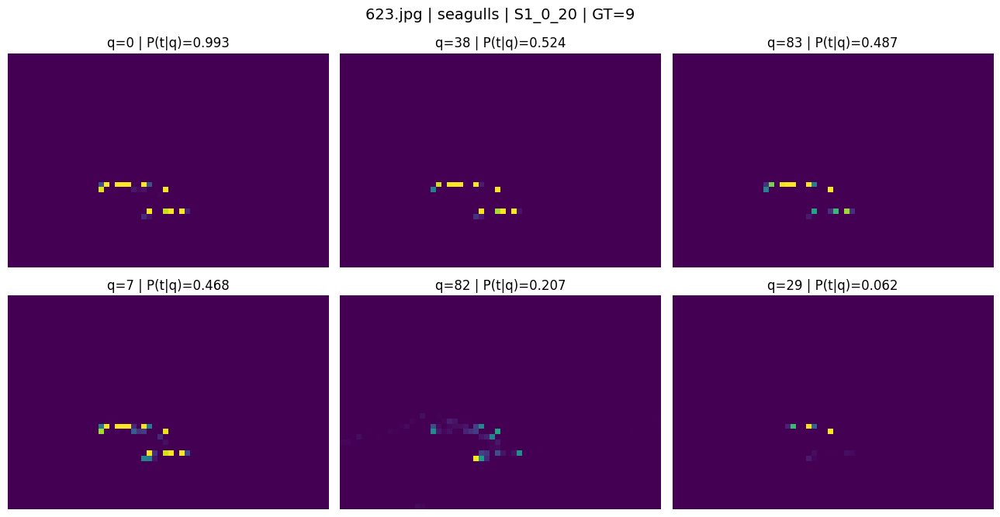

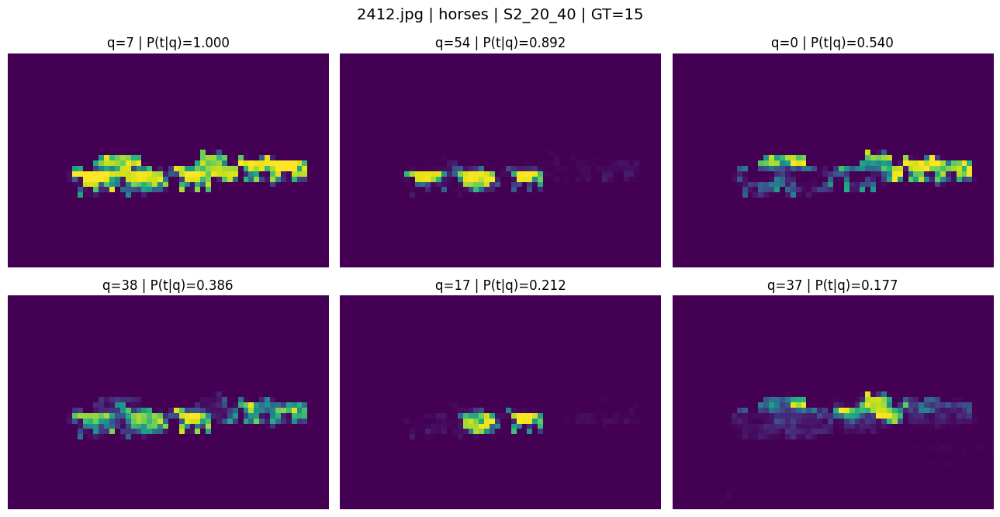

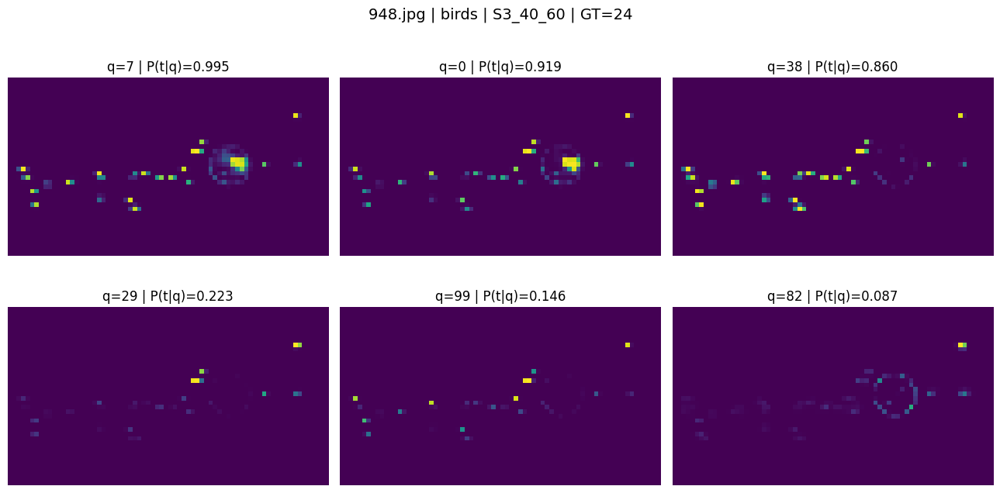

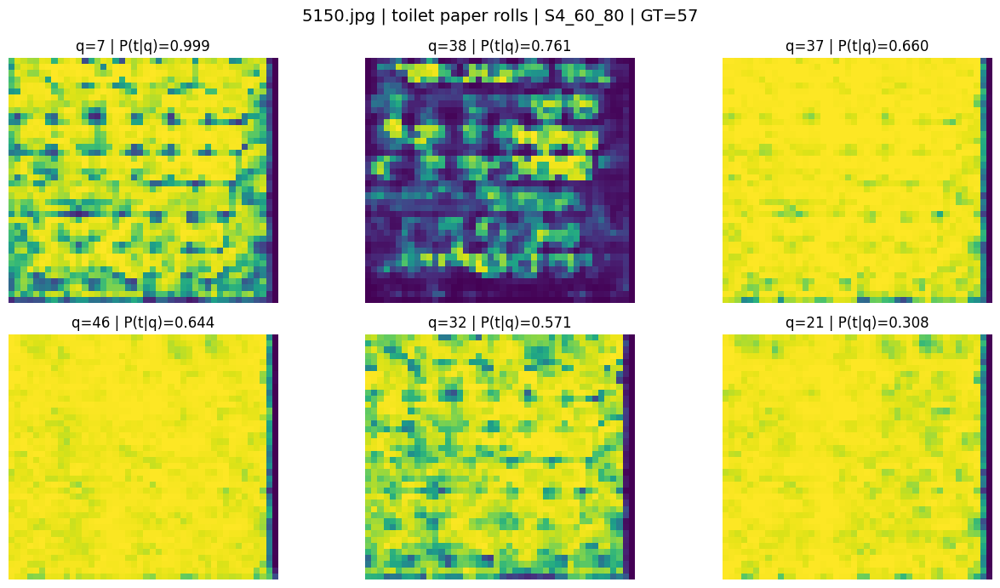

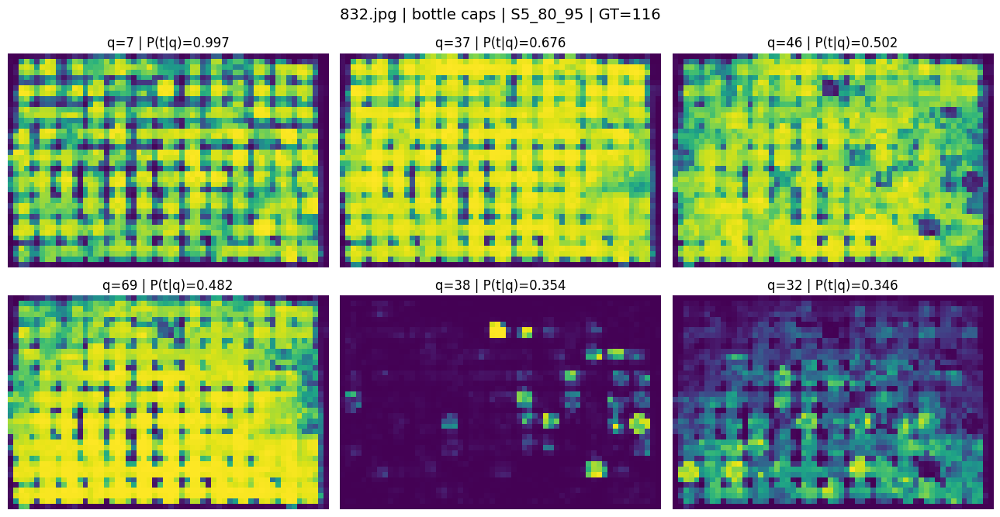

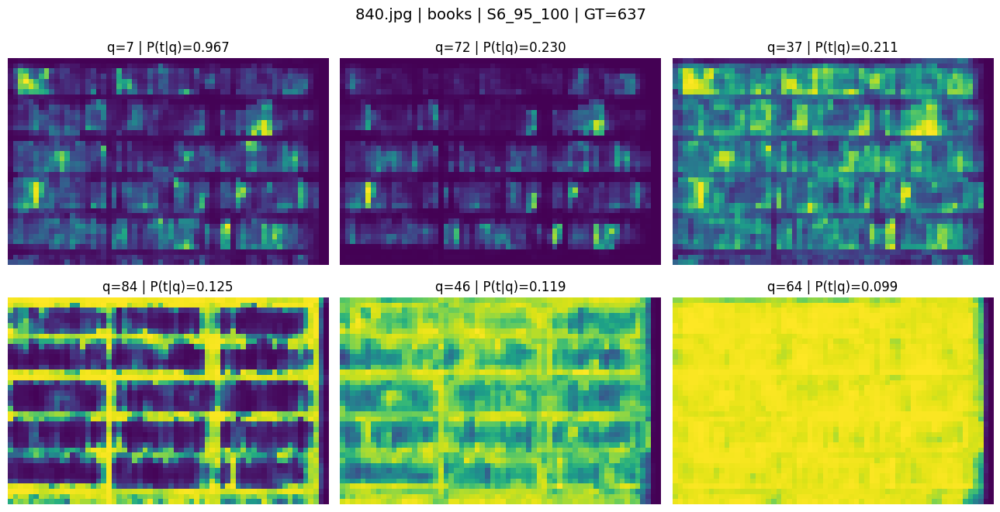

In [170]:
# ============================================================
# Step 12D.1b — Visualise strongest Candidate-B query maps
# ============================================================

import matplotlib.pyplot as plt

TOP_K_DIAGNOSTIC = 6

for _, rep_row in d6a_cross_density_samples.iterrows():

    dataset_index = int(rep_row["dataset_index"])
    sample = fsc147_val_dataset[dataset_index]

    image_id = sample["image_id"]
    category = rep_row["category"]
    stratum = rep_row["density_stratum"]
    gt_count = int(rep_row["gt_count"])

    cache_file = (
        D6_CACHE_ROOT
        / f"{Path(image_id).stem}.pt"
    )

    cached = torch.load(
        cache_file,
        map_location="cpu",
        weights_only=False,
    )

    mask_preds = cached["mask_preds"].float()
    target_query_prob = cached["target_query_prob"].float()

    if mask_preds.ndim == 4:
        mask_preds = mask_preds[0]

    if target_query_prob.ndim == 2:
        target_query_prob = target_query_prob[0]

    query_maps = (
        target_query_prob[:, None, None]
        * torch.sigmoid(mask_preds)
    )

    # Strongest target-relevant queries
    top_indices = torch.argsort(
        target_query_prob,
        descending=True,
    )[:TOP_K_DIAGNOSTIC]

    fig, axes = plt.subplots(
        2,
        3,
        figsize=(13, 7),
    )

    axes = axes.ravel()

    for ax, q_idx in zip(axes, top_indices):

        q = int(q_idx)
        qmap = query_maps[q].cpu().numpy()

        ax.imshow(qmap)
        ax.set_title(
            f"q={q} | P(t|q)="
            f"{float(target_query_prob[q]):.3f}"
        )
        ax.axis("off")

    fig.suptitle(
        f"{image_id} | {category} | {stratum} | "
        f"GT={gt_count}",
        fontsize=14,
    )

    plt.tight_layout()
    plt.show()

### Step 12D.2 — Quantify query spatial structure and redundancy

The qualitative inspection in Step 12D.1 showed that target-relevant SAN queries may be spatially specialised, multi-modal, redundant, or diffuse.

This step quantifies two properties:

1. **Spatial concentration** — measured using normalized spatial entropy and the previously defined half-maximum active fraction. Lower values indicate more spatially concentrated responses.
2. **Inter-query redundancy** — measured using pairwise cosine similarity between target-weighted query maps. Higher similarity indicates stronger spatial redundancy.

The analysis remains diagnostic. No Candidate-B query-selection or point-generation rule is defined at this stage.

In [171]:
# ============================================================
# Step 12D.2 — Query spatial structure and redundancy
# ============================================================

import numpy as np
import pandas as pd
import torch

TOP_K_REDUNDANCY = 10   # diagnostic only

structure_rows = []
redundancy_rows = []

for _, rep_row in d6a_cross_density_samples.iterrows():

    dataset_index = int(rep_row["dataset_index"])
    sample = fsc147_val_dataset[dataset_index]

    image_id = sample["image_id"]
    category = rep_row["category"]
    stratum = rep_row["density_stratum"]
    gt_count = int(rep_row["gt_count"])

    # --------------------------------------------------------
    # Load frozen D6 cache
    # --------------------------------------------------------
    cache_file = (
        D6_CACHE_ROOT
        / f"{Path(image_id).stem}.pt"
    )

    cached = torch.load(
        cache_file,
        map_location="cpu",
        weights_only=False,
    )

    mask_preds = cached["mask_preds"].float()
    target_query_prob = cached["target_query_prob"].float()

    if mask_preds.ndim == 4:
        mask_preds = mask_preds[0]

    if target_query_prob.ndim == 2:
        target_query_prob = target_query_prob[0]

    query_maps = (
        target_query_prob[:, None, None]
        * torch.sigmoid(mask_preds)
    )

    # ========================================================
    # A. Per-query spatial concentration
    # ========================================================

    for q in range(query_maps.shape[0]):

        qmap = query_maps[q].cpu().numpy().astype(np.float64)

        qmax = float(qmap.max())
        qsum = float(qmap.sum())

        # Half-maximum active fraction
        if qmax > 0:
            halfmax_active_fraction = float(
                np.mean(qmap >= (0.5 * qmax))
            )
        else:
            halfmax_active_fraction = 0.0

        # Normalized spatial entropy
        #
        # Treat non-negative spatial activation as a
        # distribution over feature-map cells.
        if qsum > 0:
            p = qmap.ravel() / qsum
            p = p[p > 0]

            entropy = float(
                -np.sum(p * np.log(p))
            )

            max_entropy = np.log(qmap.size)

            normalized_entropy = float(
                entropy / max_entropy
            )
        else:
            normalized_entropy = 0.0

        structure_rows.append({
            "image_id": image_id,
            "category": category,
            "density_stratum": stratum,
            "gt_count": gt_count,
            "query_index": q,
            "target_query_prob":
                float(target_query_prob[q]),
            "weighted_map_max": qmax,
            "halfmax_active_fraction":
                halfmax_active_fraction,
            "normalized_spatial_entropy":
                normalized_entropy,
        })

    # ========================================================
    # B. Redundancy among strongest target-relevant queries
    # ========================================================

    top_indices = torch.argsort(
        target_query_prob,
        descending=True,
    )[:TOP_K_REDUNDANCY]

    top_maps = query_maps[top_indices]

    # Flatten each spatial query map
    X = top_maps.reshape(
        TOP_K_REDUNDANCY,
        -1,
    ).double()

    # L2 normalize
    norms = torch.linalg.vector_norm(
        X,
        dim=1,
        keepdim=True,
    ).clamp_min(1e-12)

    X_norm = X / norms

    # Pairwise cosine similarity
    similarity = X_norm @ X_norm.T

    # Keep unique query pairs only
    for i in range(TOP_K_REDUNDANCY):
        for j in range(i + 1, TOP_K_REDUNDANCY):

            qi = int(top_indices[i])
            qj = int(top_indices[j])

            redundancy_rows.append({
                "image_id": image_id,
                "category": category,
                "density_stratum": stratum,
                "gt_count": gt_count,
                "query_i": qi,
                "query_j": qj,
                "prob_i":
                    float(target_query_prob[qi]),
                "prob_j":
                    float(target_query_prob[qj]),
                "cosine_similarity":
                    float(similarity[i, j]),
            })


d6b_structure_df = pd.DataFrame(
    structure_rows
)

d6b_redundancy_df = pd.DataFrame(
    redundancy_rows
)

print(
    "Structure rows:",
    len(d6b_structure_df),
)

print(
    "Redundancy rows:",
    len(d6b_redundancy_df),
)

print("\nPer-image structure summary:")

structure_summary = (
    d6b_structure_df
    .groupby(
        [
            "image_id",
            "category",
            "density_stratum",
            "gt_count",
        ],
        as_index=False,
    )
    .agg(
        median_entropy=(
            "normalized_spatial_entropy",
            "median",
        ),
        median_halfmax_fraction=(
            "halfmax_active_fraction",
            "median",
        ),
    )
)

display(structure_summary)


print("\nTop-10-query redundancy summary:")

redundancy_summary = (
    d6b_redundancy_df
    .groupby(
        [
            "image_id",
            "category",
            "density_stratum",
            "gt_count",
        ],
        as_index=False,
    )
    .agg(
        mean_cosine_similarity=(
            "cosine_similarity",
            "mean",
        ),
        median_cosine_similarity=(
            "cosine_similarity",
            "median",
        ),
        max_cosine_similarity=(
            "cosine_similarity",
            "max",
        ),
    )
)

display(redundancy_summary)

Structure rows: 600
Redundancy rows: 270

Per-image structure summary:


,image_id,category,density_stratum,gt_count,median_entropy,median_halfmax_fraction
0,2412.jpg,horses,S2_20_40,15,0.662342,0.021667
1,5150.jpg,toilet paper rolls,S4_60_80,57,0.760575,0.025000
2,623.jpg,seagulls,S1_0_20,9,0.526907,0.018958
3,832.jpg,bottle caps,S5_80_95,116,0.704084,0.017917
4,840.jpg,books,S6_95_100,637,0.701184,0.008266
5,948.jpg,birds,S3_40_60,24,0.526493,0.009201



Top-10-query redundancy summary:


,image_id,category,density_stratum,gt_count,mean_cosine_similarity,median_cosine_similarity,max_cosine_similarity
0,2412.jpg,horses,S2_20_40,15,0.358518,0.347403,0.881665
1,5150.jpg,toilet paper rolls,S4_60_80,57,0.899936,0.949181,0.999349
2,623.jpg,seagulls,S1_0_20,9,0.382093,0.375905,0.982693
3,832.jpg,bottle caps,S5_80_95,116,0.644227,0.726083,0.991014
4,840.jpg,books,S6_95_100,637,0.626939,0.651840,0.977101
5,948.jpg,birds,S3_40_60,24,0.532179,0.643097,0.955133


### Step 12D.3 — Target relevance, spatial structure and GT correspondence

Steps 12D.1–12D.2 showed that Candidate-B query maps contain both
complementary and redundant spatial evidence, while some highly
target-relevant queries are spatially diffuse.

This diagnostic restricts attention to target-relevant queries and examines
whether query confidence and spatial concentration are associated with
actual target localisation.

For each query, the maximum-response feature-map cell is mapped to image
coordinates and its nearest-GT distance is measured. This is used only as a
diagnostic of query usefulness; it is not yet the Candidate-B point-generation
rule.

Target-query probability, spatial entropy, and GT correspondence are therefore
analysed jointly before defining a query-selection strategy.

In [172]:
# ============================================================
# Step 12D.3 — Query relevance, structure and GT correspondence
# ============================================================

import numpy as np
import pandas as pd
import torch
from scipy.spatial import cKDTree

d6b_gt_diagnostic_rows = []

for _, rep_row in d6a_cross_density_samples.iterrows():

    dataset_index = int(rep_row["dataset_index"])
    sample = fsc147_val_dataset[dataset_index]

    image_id = sample["image_id"]
    category = rep_row["category"]
    stratum = rep_row["density_stratum"]
    gt_count = int(rep_row["gt_count"])

    image_h = int(sample["height"])
    image_w = int(sample["width"])

    gt_points = get_gt_points(
        sample,
        category,
    )

    gt_tree = (
        cKDTree(gt_points)
        if len(gt_points) > 0
        else None
    )

    # --------------------------------------------------------
    # Load frozen D6 cache
    # --------------------------------------------------------
    cache_file = (
        D6_CACHE_ROOT
        / f"{Path(image_id).stem}.pt"
    )

    cached = torch.load(
        cache_file,
        map_location="cpu",
        weights_only=False,
    )

    mask_preds = cached["mask_preds"].float()
    target_query_prob = cached["target_query_prob"].float()

    if mask_preds.ndim == 4:
        mask_preds = mask_preds[0]

    if target_query_prob.ndim == 2:
        target_query_prob = target_query_prob[0]

    query_maps = (
        target_query_prob[:, None, None]
        * torch.sigmoid(mask_preds)
    )

    feature_h = int(query_maps.shape[-2])
    feature_w = int(query_maps.shape[-1])

    short_side = min(image_h, image_w)
    tolerance_px = 0.03 * short_side

    # --------------------------------------------------------
    # Analyse every query
    # --------------------------------------------------------
    for q in range(query_maps.shape[0]):

        qmap = (
            query_maps[q]
            .cpu()
            .numpy()
            .astype(np.float64)
        )

        prob = float(target_query_prob[q])

        # ----------------------------
        # Spatial entropy
        # ----------------------------
        qsum = float(qmap.sum())

        if qsum > 0:
            p = qmap.ravel() / qsum
            p = p[p > 0]

            entropy = float(
                -np.sum(p * np.log(p))
            )

            normalized_entropy = float(
                entropy / np.log(qmap.size)
            )
        else:
            normalized_entropy = 0.0

        # ----------------------------
        # Strongest spatial response
        # ----------------------------
        flat_index = int(np.argmax(qmap))

        fy, fx = np.unravel_index(
            flat_index,
            qmap.shape,
        )

        # Feature-cell centre -> image coordinates
        x_img = (
            (fx + 0.5)
            * image_w
            / feature_w
        )

        y_img = (
            (fy + 0.5)
            * image_h
            / feature_h
        )

        # ----------------------------
        # Nearest GT distance
        # ----------------------------
        if gt_tree is not None:
            nearest_distance, _ = gt_tree.query(
                [x_img, y_img],
                k=1,
            )

            nearest_distance = float(
                nearest_distance
            )
        else:
            nearest_distance = np.nan

        within_tolerance = bool(
            nearest_distance <= tolerance_px
        )

        d6b_gt_diagnostic_rows.append({
            "image_id": image_id,
            "category": category,
            "density_stratum": stratum,
            "gt_count": gt_count,

            "query_index": q,
            "target_query_prob": prob,
            "normalized_spatial_entropy":
                normalized_entropy,

            "peak_x": x_img,
            "peak_y": y_img,

            "nearest_gt_distance_px":
                nearest_distance,

            "nearest_gt_distance_norm":
                nearest_distance / short_side,

            "within_3pct_gt":
                within_tolerance,
        })


d6b_gt_diagnostic_df = pd.DataFrame(
    d6b_gt_diagnostic_rows
)

print(
    "Rows:",
    len(d6b_gt_diagnostic_df)
)

# ============================================================
# Summarise queries at several target-relevance levels
# These are diagnostic cuts, NOT selected parameters.
# ============================================================

diagnostic_prob_thresholds = [
    0.01,
    0.05,
    0.10,
    0.50,
]

summary_rows = []

for threshold in diagnostic_prob_thresholds:

    selected = d6b_gt_diagnostic_df[
        d6b_gt_diagnostic_df[
            "target_query_prob"
        ] >= threshold
    ]

    for (
        image_id,
        category,
        stratum,
        gt_count,
    ), group in selected.groupby(
        [
            "image_id",
            "category",
            "density_stratum",
            "gt_count",
        ]
    ):

        summary_rows.append({
            "prob_threshold": threshold,
            "image_id": image_id,
            "category": category,
            "density_stratum": stratum,
            "gt_count": gt_count,

            "n_queries": len(group),

            "median_target_prob":
                group[
                    "target_query_prob"
                ].median(),

            "median_entropy":
                group[
                    "normalized_spatial_entropy"
                ].median(),

            "median_nearest_gt_norm":
                group[
                    "nearest_gt_distance_norm"
                ].median(),

            "fraction_peaks_within_3pct":
                group[
                    "within_3pct_gt"
                ].mean(),
        })


d6b_gt_summary_df = pd.DataFrame(
    summary_rows
)

display(
    d6b_gt_summary_df.sort_values(
        [
            "prob_threshold",
            "density_stratum",
        ]
    )
)

Rows: 600


,prob_threshold,image_id,category,density_stratum,gt_count,n_queries,median_target_prob,median_entropy,median_nearest_gt_norm,fraction_peaks_within_3pct
2,0.01,623.jpg,seagulls,S1_0_20,9,8,0.337499,0.333989,0.008108,0.750000
0,0.01,2412.jpg,horses,S2_20_40,15,11,0.176711,0.580465,0.045506,0.272727
5,0.01,948.jpg,birds,S3_40_60,24,9,0.145737,0.499845,0.012409,1.000000
1,0.01,5150.jpg,toilet paper rolls,S4_60_80,57,20,0.213399,0.991508,0.048021,0.250000
3,0.01,832.jpg,bottle caps,S5_80_95,116,34,0.127315,0.911675,0.029276,0.500000
4,0.01,840.jpg,books,S6_95_100,637,16,0.033467,0.957977,0.042106,0.250000
8,0.05,623.jpg,seagulls,S1_0_20,9,6,0.477522,0.333989,0.007992,0.833333
6,0.05,2412.jpg,horses,S2_20_40,15,8,0.299194,0.603928,0.038211,0.375000
11,0.05,948.jpg,birds,S3_40_60,24,8,0.184265,0.481639,0.012409,1.000000
7,0.05,5150.jpg,toilet paper rolls,S4_60_80,57,14,0.240689,0.991508,0.051575,0.142857


### Step 12D.4 — D6B0: query-wise local peak extraction

Candidate-B preserves SAN's target-weighted query decomposition:

\[
T_q(x,y)=P(t\mid q)\sigma(M_q(x,y)).
\]

Steps 12D.1–12D.3 showed that individual queries may contain multiple local
modes, while different queries may also provide redundant spatial evidence.

D6B0 therefore tests the simplest query-preserving point-generation strategy:

1. retain target-relevant queries;
2. normalize each retained query map independently;
3. extract local maxima within each query;
4. pool peaks from all retained queries; and
5. consolidate spatially overlapping peaks across queries.

No Gaussian modulation or Taylor refinement is applied. This isolates whether
preserving the SAN query dimension exposes useful localisation information
that is lost by query aggregation.

The initial experiment uses the same six fixed cross-density representative
images and is diagnostic only; no parameters are selected at this stage.

In [173]:
# ============================================================
# Step 12D.4a — D6B0 query-wise peaks + duplicate consolidation
# ============================================================

import numpy as np
import pandas as pd
import torch

from skimage.feature import peak_local_max
from scipy.spatial import cKDTree


# ------------------------------------------------------------
# Diagnostic settings only — NOT selected parameters
# ------------------------------------------------------------

D6B0_QUERY_PROB_THRESHOLD = 0.05
D6B0_PEAK_THRESHOLD = 0.70
D6B0_FEATURE_MIN_DISTANCE = 1


def consolidate_points_greedy(
    points_xy,
    scores,
    merge_radius_px,
):
    """
    Greedy spatial duplicate consolidation.

    Highest-score point is retained first.
    Any later point within merge_radius_px of an already
    retained point is treated as a duplicate.

    Returns retained points and their scores.
    """

    points_xy = np.asarray(
        points_xy,
        dtype=np.float64,
    ).reshape(-1, 2)

    scores = np.asarray(
        scores,
        dtype=np.float64,
    )

    if len(points_xy) == 0:
        return (
            np.empty((0, 2), dtype=np.float64),
            np.empty((0,), dtype=np.float64),
        )

    order = np.argsort(scores)[::-1]

    kept_points = []
    kept_scores = []

    for idx in order:

        point = points_xy[idx]
        score = scores[idx]

        if len(kept_points) == 0:
            keep = True

        else:
            distances = np.linalg.norm(
                np.asarray(kept_points) - point,
                axis=1,
            )

            keep = bool(
                np.all(
                    distances > merge_radius_px
                )
            )

        if keep:
            kept_points.append(point)
            kept_scores.append(score)

    return (
        np.asarray(kept_points, dtype=np.float64),
        np.asarray(kept_scores, dtype=np.float64),
    )


d6b0_diagnostic_rows = []

for _, rep_row in d6a_cross_density_samples.iterrows():

    dataset_index = int(rep_row["dataset_index"])
    sample = fsc147_val_dataset[dataset_index]

    image_id = sample["image_id"]
    category = rep_row["category"]
    stratum = rep_row["density_stratum"]
    gt_count = int(rep_row["gt_count"])

    image_h = int(sample["height"])
    image_w = int(sample["width"])

    gt_points = get_gt_points(
        sample,
        category,
    )

    # --------------------------------------------------------
    # Load frozen D6 cache
    # --------------------------------------------------------

    cache_file = (
        D6_CACHE_ROOT
        / f"{Path(image_id).stem}.pt"
    )

    cached = torch.load(
        cache_file,
        map_location="cpu",
        weights_only=False,
    )

    mask_preds = cached["mask_preds"].float()
    target_query_prob = cached["target_query_prob"].float()

    if mask_preds.ndim == 4:
        mask_preds = mask_preds[0]

    if target_query_prob.ndim == 2:
        target_query_prob = target_query_prob[0]

    query_maps = (
        target_query_prob[:, None, None]
        * torch.sigmoid(mask_preds)
    )

    feature_h = int(query_maps.shape[-2])
    feature_w = int(query_maps.shape[-1])

    # --------------------------------------------------------
    # Approximate one-feature-cell diagonal in image space
    # --------------------------------------------------------

    cell_w = image_w / feature_w
    cell_h = image_h / feature_h

    merge_radius_px = float(
        np.sqrt(
            cell_w ** 2 +
            cell_h ** 2
        )
    )

    pooled_points = []
    pooled_scores = []

    n_selected_queries = 0
    n_raw_peaks = 0

    # ========================================================
    # Query-wise local peak extraction
    # ========================================================

    for q in range(query_maps.shape[0]):

        query_prob = float(
            target_query_prob[q]
        )

        if query_prob < D6B0_QUERY_PROB_THRESHOLD:
            continue

        n_selected_queries += 1

        qmap = (
            query_maps[q]
            .cpu()
            .numpy()
            .astype(np.float64)
        )

        qmax = float(qmap.max())

        if qmax <= 0:
            continue

        # Normalize within query
        qmap_norm = qmap / qmax

        peaks_rc = peak_local_max(
            qmap_norm,
            min_distance=D6B0_FEATURE_MIN_DISTANCE,
            threshold_abs=D6B0_PEAK_THRESHOLD,
            exclude_border=False,
        )

        n_raw_peaks += len(peaks_rc)

        for fy, fx in peaks_rc:

            # Feature-cell centre -> image coordinates
            x_img = (
                (fx + 0.5)
                * image_w
                / feature_w
            )

            y_img = (
                (fy + 0.5)
                * image_h
                / feature_h
            )

            # Consolidation score retains BOTH:
            # query relevance and within-query peak strength
            local_strength = float(
                qmap_norm[fy, fx]
            )

            combined_score = (
                query_prob
                * local_strength
            )

            pooled_points.append(
                [x_img, y_img]
            )

            pooled_scores.append(
                combined_score
            )

    # ========================================================
    # Cross-query duplicate consolidation
    # ========================================================

    consolidated_points, consolidated_scores = (
        consolidate_points_greedy(
            pooled_points,
            pooled_scores,
            merge_radius_px,
        )
    )

    # ========================================================
    # One-to-one GT evaluation
    # ========================================================

    tolerance_px = (
        0.03
        * min(image_h, image_w)
    )

    metrics = one_to_one_point_metrics(
        consolidated_points,
        gt_points,
        tolerance_px,
    )

    d6b0_diagnostic_rows.append({
        "dataset_index": dataset_index,
        "image_id": image_id,
        "category": category,
        "density_stratum": stratum,

        "gt_count": gt_count,

        "selected_queries":
            n_selected_queries,

        "raw_query_peaks":
            n_raw_peaks,

        "consolidated_points":
            len(consolidated_points),

        "pred_gt_ratio":
            len(consolidated_points)
            / max(gt_count, 1),

        "merge_radius_px":
            merge_radius_px,

        "tp": metrics["tp"],
        "fp": metrics["fp"],
        "fn": metrics["fn"],

        "precision": metrics["precision"],
        "recall": metrics["recall"],
        "f1": metrics["f1"],
    })


d6b0_diagnostic_df = pd.DataFrame(
    d6b0_diagnostic_rows
)

display(
    d6b0_diagnostic_df[
        [
            "image_id",
            "category",
            "density_stratum",
            "gt_count",
            "selected_queries",
            "raw_query_peaks",
            "consolidated_points",
            "pred_gt_ratio",
            "precision",
            "recall",
            "f1",
        ]
    ]
)

,image_id,category,density_stratum,gt_count,selected_queries,raw_query_peaks,consolidated_points,pred_gt_ratio,precision,recall,f1
0,623.jpg,seagulls,S1_0_20,9,6,29,8,0.888889,0.875000,0.777778,0.823529
1,2412.jpg,horses,S2_20_40,15,8,82,35,2.333333,0.257143,0.600000,0.360000
2,948.jpg,birds,S3_40_60,24,8,65,20,0.833333,0.950000,0.791667,0.863636
3,5150.jpg,toilet paper rolls,S4_60_80,57,14,1438,273,4.789474,0.128205,0.614035,0.212121
4,832.jpg,bottle caps,S5_80_95,116,25,1768,358,3.086207,0.293296,0.905172,0.443038
5,840.jpg,books,S6_95_100,637,7,572,259,0.406593,0.297297,0.120879,0.171875


### Step 12D.5 — Candidate-B query-control diagnostic

D6B0 showed that query-wise peak extraction can recover strong localisation
evidence, but diffuse target-relevant queries may generate very large numbers
of local maxima.

This step tests whether simple observable query properties can control
candidate generation before introducing Gaussian modulation or Taylor
refinement.

The following diagnostic strategies are compared:

- **B0:** original query-probability threshold \(P(t|q)\geq0.05\);
- **B1:** stronger semantic relevance threshold \(P(t|q)\geq0.10\);
- **B2:** \(P(t|q)\geq0.05\) with an additional spatial-entropy limit.

All other D6B0 settings are held fixed. Entropy limits 0.90, 0.95 and 0.98
are exploratory diagnostic values only. No Candidate-B configuration is
selected at this stage.

In [174]:
# ============================================================
# Step 12D.5 — Candidate-B query-control diagnostic
# ============================================================

import numpy as np
import pandas as pd
import torch
from skimage.feature import peak_local_max


# ------------------------------------------------------------
# Keep D6B0 peak-generation settings fixed
# ------------------------------------------------------------

D6B_PEAK_THRESHOLD = 0.70
D6B_FEATURE_MIN_DISTANCE = 1


# ------------------------------------------------------------
# Diagnostic query-control configurations
# ------------------------------------------------------------

d6b_query_control_configs = [
    {
        "experiment_id": "D6B0_p0.05",
        "query_prob_threshold": 0.05,
        "max_entropy": None,
    },
    {
        "experiment_id": "D6B1_p0.10",
        "query_prob_threshold": 0.10,
        "max_entropy": None,
    },
    {
        "experiment_id": "D6B2_p0.05_e0.90",
        "query_prob_threshold": 0.05,
        "max_entropy": 0.90,
    },
    {
        "experiment_id": "D6B2_p0.05_e0.95",
        "query_prob_threshold": 0.05,
        "max_entropy": 0.95,
    },
    {
        "experiment_id": "D6B2_p0.05_e0.98",
        "query_prob_threshold": 0.05,
        "max_entropy": 0.98,
    },
]


d6b_query_control_rows = []


for _, rep_row in d6a_cross_density_samples.iterrows():

    dataset_index = int(rep_row["dataset_index"])
    sample = fsc147_val_dataset[dataset_index]

    image_id = sample["image_id"]
    category = rep_row["category"]
    stratum = rep_row["density_stratum"]
    gt_count = int(rep_row["gt_count"])

    image_h = int(sample["height"])
    image_w = int(sample["width"])

    gt_points = get_gt_points(
        sample,
        category,
    )

    # --------------------------------------------------------
    # Load frozen D6 cache
    # --------------------------------------------------------

    cache_file = (
        D6_CACHE_ROOT
        / f"{Path(image_id).stem}.pt"
    )

    cached = torch.load(
        cache_file,
        map_location="cpu",
        weights_only=False,
    )

    mask_preds = cached["mask_preds"].float()
    target_query_prob = cached["target_query_prob"].float()

    if mask_preds.ndim == 4:
        mask_preds = mask_preds[0]

    if target_query_prob.ndim == 2:
        target_query_prob = target_query_prob[0]

    query_maps = (
        target_query_prob[:, None, None]
        * torch.sigmoid(mask_preds)
    )

    feature_h = int(query_maps.shape[-2])
    feature_w = int(query_maps.shape[-1])

    cell_w = image_w / feature_w
    cell_h = image_h / feature_h

    merge_radius_px = float(
        np.sqrt(
            cell_w ** 2
            + cell_h ** 2
        )
    )

    tolerance_px = (
        0.03
        * min(image_h, image_w)
    )

    # ========================================================
    # Evaluate each query-control configuration
    # ========================================================

    for config in d6b_query_control_configs:

        pooled_points = []
        pooled_scores = []

        selected_queries = 0
        rejected_by_prob = 0
        rejected_by_entropy = 0
        raw_query_peaks = 0

        for q in range(query_maps.shape[0]):

            query_prob = float(
                target_query_prob[q]
            )

            # --------------------------------------------
            # Query semantic relevance
            # --------------------------------------------

            if (
                query_prob
                < config["query_prob_threshold"]
            ):
                rejected_by_prob += 1
                continue

            qmap = (
                query_maps[q]
                .cpu()
                .numpy()
                .astype(np.float64)
            )

            qmax = float(qmap.max())

            if qmax <= 0:
                continue

            # --------------------------------------------
            # Normalized spatial entropy
            # --------------------------------------------

            qsum = float(qmap.sum())

            if qsum > 0:

                p = qmap.ravel() / qsum
                p = p[p > 0]

                entropy = float(
                    -np.sum(
                        p * np.log(p)
                    )
                )

                normalized_entropy = float(
                    entropy
                    / np.log(qmap.size)
                )

            else:
                normalized_entropy = 0.0

            max_entropy = config["max_entropy"]

            if (
                max_entropy is not None
                and normalized_entropy > max_entropy
            ):
                rejected_by_entropy += 1
                continue

            selected_queries += 1

            # --------------------------------------------
            # Query-wise local peaks
            # --------------------------------------------

            qmap_norm = qmap / qmax

            peaks_rc = peak_local_max(
                qmap_norm,
                min_distance=D6B_FEATURE_MIN_DISTANCE,
                threshold_abs=D6B_PEAK_THRESHOLD,
                exclude_border=False,
            )

            raw_query_peaks += len(peaks_rc)

            for fy, fx in peaks_rc:

                x_img = (
                    (fx + 0.5)
                    * image_w
                    / feature_w
                )

                y_img = (
                    (fy + 0.5)
                    * image_h
                    / feature_h
                )

                local_strength = float(
                    qmap_norm[fy, fx]
                )

                combined_score = (
                    query_prob
                    * local_strength
                )

                pooled_points.append(
                    [x_img, y_img]
                )

                pooled_scores.append(
                    combined_score
                )

        # ----------------------------------------------------
        # Cross-query duplicate consolidation
        # ----------------------------------------------------

        consolidated_points, consolidated_scores = (
            consolidate_points_greedy(
                pooled_points,
                pooled_scores,
                merge_radius_px,
            )
        )

        # ----------------------------------------------------
        # GT evaluation
        # ----------------------------------------------------

        metrics = one_to_one_point_metrics(
            consolidated_points,
            gt_points,
            tolerance_px,
        )

        d6b_query_control_rows.append({
            "experiment_id":
                config["experiment_id"],

            "image_id": image_id,
            "category": category,
            "density_stratum": stratum,

            "gt_count": gt_count,

            "query_prob_threshold":
                config["query_prob_threshold"],

            "max_entropy":
                config["max_entropy"],

            "selected_queries":
                selected_queries,

            "rejected_by_prob":
                rejected_by_prob,

            "rejected_by_entropy":
                rejected_by_entropy,

            "raw_query_peaks":
                raw_query_peaks,

            "consolidated_points":
                len(consolidated_points),

            "pred_gt_ratio":
                len(consolidated_points)
                / max(gt_count, 1),

            "precision":
                metrics["precision"],

            "recall":
                metrics["recall"],

            "f1":
                metrics["f1"],
        })


d6b_query_control_df = pd.DataFrame(
    d6b_query_control_rows
)


# ============================================================
# Compact comparison
# ============================================================

display(
    d6b_query_control_df[
        [
            "experiment_id",
            "density_stratum",
            "gt_count",
            "selected_queries",
            "raw_query_peaks",
            "consolidated_points",
            "pred_gt_ratio",
            "precision",
            "recall",
            "f1",
        ]
    ].sort_values(
        [
            "density_stratum",
            "experiment_id",
        ]
    )
)

,experiment_id,density_stratum,gt_count,selected_queries,raw_query_peaks,consolidated_points,pred_gt_ratio,precision,recall,f1
0,D6B0_p0.05,S1_0_20,9,6,29,8,0.888889,0.875000,0.777778,0.823529
1,D6B1_p0.10,S1_0_20,9,5,27,8,0.888889,0.875000,0.777778,0.823529
2,D6B2_p0.05_e0.90,S1_0_20,9,6,29,8,0.888889,0.875000,0.777778,0.823529
3,D6B2_p0.05_e0.95,S1_0_20,9,6,29,8,0.888889,0.875000,0.777778,0.823529
4,D6B2_p0.05_e0.98,S1_0_20,9,6,29,8,0.888889,0.875000,0.777778,0.823529
5,D6B0_p0.05,S2_20_40,15,8,82,35,2.333333,0.257143,0.600000,0.360000
6,D6B1_p0.10,S2_20_40,15,7,78,35,2.333333,0.257143,0.600000,0.360000
7,D6B2_p0.05_e0.90,S2_20_40,15,8,82,35,2.333333,0.257143,0.600000,0.360000
8,D6B2_p0.05_e0.95,S2_20_40,15,8,82,35,2.333333,0.257143,0.600000,0.360000
9,D6B2_p0.05_e0.98,S2_20_40,15,8,82,35,2.333333,0.257143,0.600000,0.360000


### Step 12D.6 — Redundancy-aware query selection

D6B0 showed that preserving SAN's query dimension can expose useful local
modes, but multiple target-relevant queries may contain strongly overlapping
spatial evidence and generate excessive candidate points.

This experiment introduces redundancy-aware query selection before peak
extraction.

Queries are ranked by target probability \(P(t\mid q)\). Starting from the
highest-ranked query, a query is retained only if its spatial activation map
is not excessively similar to any previously retained query. Spatial
redundancy is measured using cosine similarity between query maps.

The retained original SAN queries are then processed using the unchanged
D6B0 peak extraction and cross-query point-consolidation procedure.

Diagnostic cosine-similarity thresholds of 0.80, 0.90 and 0.95 are tested
on the same six fixed cross-density images. These values are exploratory
only; no parameter is selected at this stage.

In [175]:
# ============================================================
# Step 12D.6 — Redundancy-aware query selection
# ============================================================

import numpy as np
import pandas as pd
import torch

from skimage.feature import peak_local_max


# ------------------------------------------------------------
# Keep D6B0 settings fixed
# ------------------------------------------------------------

D6B_QUERY_PROB_THRESHOLD = 0.05
D6B_PEAK_THRESHOLD = 0.70
D6B_FEATURE_MIN_DISTANCE = 1

# Diagnostic only — NOT selected parameters
D6B_SIMILARITY_THRESHOLDS = [
    0.80,
    0.90,
    0.95,
]


def select_diverse_queries(
    query_maps,
    target_query_prob,
    prob_threshold,
    similarity_threshold,
):
    """
    Greedy redundancy-aware query selection.

    1. Keep queries satisfying the target-probability threshold.
    2. Rank them by target probability.
    3. Keep the strongest query.
    4. Keep each subsequent query only if its cosine similarity
       to every already-retained query is below the specified
       similarity threshold.

    Original SAN queries are retained; no new query representation
    is constructed.
    """

    candidate_indices = torch.where(
        target_query_prob >= prob_threshold
    )[0]

    if len(candidate_indices) == 0:
        return [], 0

    # Rank by semantic target relevance
    candidate_indices = candidate_indices[
        torch.argsort(
            target_query_prob[candidate_indices],
            descending=True,
        )
    ]

    # Flatten and normalize maps for cosine similarity
    candidate_maps = query_maps[
        candidate_indices
    ].reshape(
        len(candidate_indices),
        -1,
    ).double()

    norms = torch.linalg.vector_norm(
        candidate_maps,
        dim=1,
        keepdim=True,
    ).clamp_min(1e-12)

    candidate_maps_norm = (
        candidate_maps / norms
    )

    kept_positions = []

    for pos in range(
        len(candidate_indices)
    ):

        if len(kept_positions) == 0:
            kept_positions.append(pos)
            continue

        current = (
            candidate_maps_norm[pos]
        )

        previous = (
            candidate_maps_norm[
                kept_positions
            ]
        )

        similarities = (
            previous @ current
        )

        # Retain only if not too similar to
        # ANY previously retained query
        if torch.all(
            similarities
            < similarity_threshold
        ):
            kept_positions.append(pos)

    selected_indices = [
        int(candidate_indices[pos])
        for pos in kept_positions
    ]

    n_rejected_redundant = (
        len(candidate_indices)
        - len(selected_indices)
    )

    return (
        selected_indices,
        n_rejected_redundant,
    )


# ============================================================
# Run six-image diagnostic
# ============================================================

d6b_redundancy_control_rows = []


for _, rep_row in (
    d6a_cross_density_samples.iterrows()
):

    dataset_index = int(
        rep_row["dataset_index"]
    )

    sample = fsc147_val_dataset[
        dataset_index
    ]

    image_id = sample["image_id"]
    category = rep_row["category"]
    stratum = rep_row[
        "density_stratum"
    ]
    gt_count = int(
        rep_row["gt_count"]
    )

    image_h = int(sample["height"])
    image_w = int(sample["width"])

    gt_points = get_gt_points(
        sample,
        category,
    )

    # --------------------------------------------------------
    # Load frozen D6 cache
    # --------------------------------------------------------

    cache_file = (
        D6_CACHE_ROOT
        / f"{Path(image_id).stem}.pt"
    )

    cached = torch.load(
        cache_file,
        map_location="cpu",
        weights_only=False,
    )

    mask_preds = cached[
        "mask_preds"
    ].float()

    target_query_prob = cached[
        "target_query_prob"
    ].float()

    if mask_preds.ndim == 4:
        mask_preds = mask_preds[0]

    if target_query_prob.ndim == 2:
        target_query_prob = (
            target_query_prob[0]
        )

    query_maps = (
        target_query_prob[
            :, None, None
        ]
        * torch.sigmoid(mask_preds)
    )

    feature_h = int(
        query_maps.shape[-2]
    )

    feature_w = int(
        query_maps.shape[-1]
    )

    # --------------------------------------------------------
    # Keep same D6B0 point-consolidation radius
    # --------------------------------------------------------

    cell_w = (
        image_w / feature_w
    )

    cell_h = (
        image_h / feature_h
    )

    merge_radius_px = float(
        np.sqrt(
            cell_w ** 2
            + cell_h ** 2
        )
    )

    tolerance_px = (
        0.03
        * min(image_h, image_w)
    )

    # Number satisfying probability threshold
    n_prob_eligible = int(
        (
            target_query_prob
            >= D6B_QUERY_PROB_THRESHOLD
        ).sum()
    )

    # ========================================================
    # Similarity-threshold variants
    # ========================================================

    for similarity_threshold in (
        D6B_SIMILARITY_THRESHOLDS
    ):

        (
            selected_queries,
            n_rejected_redundant,
        ) = select_diverse_queries(
            query_maps=query_maps,
            target_query_prob=target_query_prob,
            prob_threshold=(
                D6B_QUERY_PROB_THRESHOLD
            ),
            similarity_threshold=(
                similarity_threshold
            ),
        )

        pooled_points = []
        pooled_scores = []

        raw_query_peaks = 0

        # ====================================================
        # SAME D6B0 query-wise peak extraction
        # ====================================================

        for q in selected_queries:

            query_prob = float(
                target_query_prob[q]
            )

            qmap = (
                query_maps[q]
                .cpu()
                .numpy()
                .astype(np.float64)
            )

            qmax = float(
                qmap.max()
            )

            if qmax <= 0:
                continue

            qmap_norm = (
                qmap / qmax
            )

            peaks_rc = peak_local_max(
                qmap_norm,
                min_distance=(
                    D6B_FEATURE_MIN_DISTANCE
                ),
                threshold_abs=(
                    D6B_PEAK_THRESHOLD
                ),
                exclude_border=False,
            )

            raw_query_peaks += len(
                peaks_rc
            )

            for fy, fx in peaks_rc:

                x_img = (
                    (fx + 0.5)
                    * image_w
                    / feature_w
                )

                y_img = (
                    (fy + 0.5)
                    * image_h
                    / feature_h
                )

                local_strength = float(
                    qmap_norm[fy, fx]
                )

                combined_score = (
                    query_prob
                    * local_strength
                )

                pooled_points.append(
                    [x_img, y_img]
                )

                pooled_scores.append(
                    combined_score
                )

        # ====================================================
        # SAME D6B0 cross-query point consolidation
        # ====================================================

        (
            consolidated_points,
            consolidated_scores,
        ) = consolidate_points_greedy(
            pooled_points,
            pooled_scores,
            merge_radius_px,
        )

        # ====================================================
        # SAME point evaluation
        # ====================================================

        metrics = (
            one_to_one_point_metrics(
                consolidated_points,
                gt_points,
                tolerance_px,
            )
        )

        d6b_redundancy_control_rows.append({
            "similarity_threshold":
                similarity_threshold,

            "image_id":
                image_id,

            "category":
                category,

            "density_stratum":
                stratum,

            "gt_count":
                gt_count,

            "prob_eligible_queries":
                n_prob_eligible,

            "selected_queries":
                len(selected_queries),

            "rejected_redundant":
                n_rejected_redundant,

            "raw_query_peaks":
                raw_query_peaks,

            "consolidated_points":
                len(consolidated_points),

            "pred_gt_ratio":
                len(consolidated_points)
                / max(gt_count, 1),

            "precision":
                metrics["precision"],

            "recall":
                metrics["recall"],

            "f1":
                metrics["f1"],
        })


d6b_redundancy_control_df = (
    pd.DataFrame(
        d6b_redundancy_control_rows
    )
)


# ============================================================
# Compact comparison
# ============================================================

display(
    d6b_redundancy_control_df[
        [
            "similarity_threshold",
            "density_stratum",
            "gt_count",
            "prob_eligible_queries",
            "selected_queries",
            "rejected_redundant",
            "raw_query_peaks",
            "consolidated_points",
            "pred_gt_ratio",
            "precision",
            "recall",
            "f1",
        ]
    ].sort_values(
        [
            "density_stratum",
            "similarity_threshold",
        ]
    )
)

,similarity_threshold,density_stratum,gt_count,prob_eligible_queries,selected_queries,rejected_redundant,raw_query_peaks,consolidated_points,pred_gt_ratio,precision,recall,f1
0,0.80,S1_0_20,9,6,3,3,10,8,0.888889,0.875000,0.777778,0.823529
1,0.90,S1_0_20,9,6,3,3,10,8,0.888889,0.875000,0.777778,0.823529
2,0.95,S1_0_20,9,6,4,2,15,8,0.888889,0.875000,0.777778,0.823529
3,0.80,S2_20_40,15,8,6,2,61,34,2.266667,0.294118,0.666667,0.408163
4,0.90,S2_20_40,15,8,8,0,82,35,2.333333,0.257143,0.600000,0.360000
5,0.95,S2_20_40,15,8,8,0,82,35,2.333333,0.257143,0.600000,0.360000
6,0.80,S3_40_60,24,8,4,4,26,17,0.708333,0.941176,0.666667,0.780488
7,0.90,S3_40_60,24,8,6,2,49,19,0.791667,0.947368,0.750000,0.837209
8,0.95,S3_40_60,24,8,7,1,55,19,0.791667,0.947368,0.750000,0.837209
9,0.80,S4_60_80,57,14,1,13,124,124,2.175439,0.137097,0.298246,0.187845


### Step 12D.7 — Within-query peak-strength control

D6B0 normalizes each retained query map independently before local-maximum
extraction. This preserves within-query spatial structure, but also means that
weak or diffuse queries can generate many candidates because their strongest
response is always normalized to 1.

This diagnostic therefore separates two peak criteria:

1. **relative peak strength** within the query; and
2. **absolute target-weighted activation**
   \(T_q(x,y)=P(t\mid q)\sigma(M_q(x,y))\).

The D6B0 query-probability threshold, feature-grid minimum distance and
cross-query point consolidation are held fixed. Candidate peaks must first
satisfy the unchanged relative threshold of 0.70, after which exploratory
absolute activation thresholds are applied.

This tests whether excessive within-query modes can be suppressed without
changing query selection or introducing Gaussian/Taylor refinement.

In [176]:
# ============================================================
# Step 12D.7a — Within-query peak-strength control
# ============================================================

import numpy as np
import pandas as pd
import torch

from skimage.feature import peak_local_max


# ------------------------------------------------------------
# Keep D6B0 settings fixed
# ------------------------------------------------------------

D6B_QUERY_PROB_THRESHOLD = 0.05
D6B_RELATIVE_PEAK_THRESHOLD = 0.70
D6B_FEATURE_MIN_DISTANCE = 1

# None = original D6B0
# Diagnostic values only — NOT selected parameters
D6B_ABSOLUTE_PEAK_THRESHOLDS = [
    None,
    0.10,
    0.20,
    0.30,
    0.40,
]


d6b_peak_control_rows = []


for _, rep_row in d6a_cross_density_samples.iterrows():

    dataset_index = int(rep_row["dataset_index"])
    sample = fsc147_val_dataset[dataset_index]

    image_id = sample["image_id"]
    category = rep_row["category"]
    stratum = rep_row["density_stratum"]
    gt_count = int(rep_row["gt_count"])

    image_h = int(sample["height"])
    image_w = int(sample["width"])

    gt_points = get_gt_points(
        sample,
        category,
    )

    # --------------------------------------------------------
    # Load frozen D6 cache
    # --------------------------------------------------------

    cache_file = (
        D6_CACHE_ROOT
        / f"{Path(image_id).stem}.pt"
    )

    cached = torch.load(
        cache_file,
        map_location="cpu",
        weights_only=False,
    )

    mask_preds = cached["mask_preds"].float()
    target_query_prob = cached["target_query_prob"].float()

    if mask_preds.ndim == 4:
        mask_preds = mask_preds[0]

    if target_query_prob.ndim == 2:
        target_query_prob = target_query_prob[0]

    # Candidate-B target-weighted query maps
    query_maps = (
        target_query_prob[:, None, None]
        * torch.sigmoid(mask_preds)
    )

    feature_h = int(query_maps.shape[-2])
    feature_w = int(query_maps.shape[-1])

    # Same D6B0 consolidation radius
    cell_w = image_w / feature_w
    cell_h = image_h / feature_h

    merge_radius_px = float(
        np.sqrt(
            cell_w ** 2
            + cell_h ** 2
        )
    )

    tolerance_px = (
        0.03
        * min(image_h, image_w)
    )

    # ========================================================
    # Absolute peak-threshold variants
    # ========================================================

    for absolute_threshold in D6B_ABSOLUTE_PEAK_THRESHOLDS:

        pooled_points = []
        pooled_scores = []

        selected_queries = 0
        raw_relative_peaks = 0
        accepted_peaks = 0

        for q in range(query_maps.shape[0]):

            query_prob = float(
                target_query_prob[q]
            )

            # Same D6B0 query-selection rule
            if query_prob < D6B_QUERY_PROB_THRESHOLD:
                continue

            selected_queries += 1

            qmap = (
                query_maps[q]
                .cpu()
                .numpy()
                .astype(np.float64)
            )

            qmax = float(qmap.max())

            if qmax <= 0:
                continue

            # ------------------------------------------------
            # Stage 1: SAME D6B0 relative peak extraction
            # ------------------------------------------------

            qmap_norm = qmap / qmax

            peaks_rc = peak_local_max(
                qmap_norm,
                min_distance=D6B_FEATURE_MIN_DISTANCE,
                threshold_abs=D6B_RELATIVE_PEAK_THRESHOLD,
                exclude_border=False,
            )

            raw_relative_peaks += len(peaks_rc)

            # ------------------------------------------------
            # Stage 2: optional absolute T_q peak criterion
            # ------------------------------------------------

            for fy, fx in peaks_rc:

                absolute_strength = float(
                    qmap[fy, fx]
                )

                if (
                    absolute_threshold is not None
                    and absolute_strength < absolute_threshold
                ):
                    continue

                accepted_peaks += 1

                x_img = (
                    (fx + 0.5)
                    * image_w
                    / feature_w
                )

                y_img = (
                    (fy + 0.5)
                    * image_h
                    / feature_h
                )

                local_strength = float(
                    qmap_norm[fy, fx]
                )

                # Same D6B0 ordering score
                combined_score = (
                    query_prob
                    * local_strength
                )

                pooled_points.append(
                    [x_img, y_img]
                )

                pooled_scores.append(
                    combined_score
                )

        # ----------------------------------------------------
        # SAME D6B0 cross-query consolidation
        # ----------------------------------------------------

        (
            consolidated_points,
            consolidated_scores,
        ) = consolidate_points_greedy(
            pooled_points,
            pooled_scores,
            merge_radius_px,
        )

        # ----------------------------------------------------
        # SAME point evaluation
        # ----------------------------------------------------

        metrics = one_to_one_point_metrics(
            consolidated_points,
            gt_points,
            tolerance_px,
        )

        experiment_id = (
            "D6B0_relative_only"
            if absolute_threshold is None
            else f"D6B3_abs{absolute_threshold:.2f}"
        )

        d6b_peak_control_rows.append({
            "experiment_id":
                experiment_id,

            "absolute_threshold":
                absolute_threshold,

            "image_id":
                image_id,

            "category":
                category,

            "density_stratum":
                stratum,

            "gt_count":
                gt_count,

            "selected_queries":
                selected_queries,

            "raw_relative_peaks":
                raw_relative_peaks,

            "accepted_peaks":
                accepted_peaks,

            "peak_acceptance_fraction":
                (
                    accepted_peaks
                    / raw_relative_peaks
                    if raw_relative_peaks > 0
                    else 0.0
                ),

            "consolidated_points":
                len(consolidated_points),

            "pred_gt_ratio":
                len(consolidated_points)
                / max(gt_count, 1),

            "precision":
                metrics["precision"],

            "recall":
                metrics["recall"],

            "f1":
                metrics["f1"],
        })


d6b_peak_control_df = pd.DataFrame(
    d6b_peak_control_rows
)

# ============================================================
# Compact comparison — corrected
# ============================================================

display_columns = [
    "experiment_id",
    "absolute_threshold",
    "density_stratum",
    "gt_count",
    "selected_queries",
    "raw_relative_peaks",
    "accepted_peaks",
    "peak_acceptance_fraction",
    "consolidated_points",
    "pred_gt_ratio",
    "precision",
    "recall",
    "f1",
]

display(
    d6b_peak_control_df[
        display_columns
    ].sort_values(
        [
            "density_stratum",
            "absolute_threshold",
        ],
        na_position="first",
    )
)


,experiment_id,absolute_threshold,density_stratum,gt_count,selected_queries,raw_relative_peaks,accepted_peaks,peak_acceptance_fraction,consolidated_points,pred_gt_ratio,precision,recall,f1
0,D6B0_relative_only,NaN,S1_0_20,9,6,29,29,1.000000,8,0.888889,0.875000,0.777778,0.823529
1,D6B3_abs0.10,0.1,S1_0_20,9,6,29,26,0.896552,7,0.777778,1.000000,0.777778,0.875000
2,D6B3_abs0.20,0.2,S1_0_20,9,6,29,26,0.896552,7,0.777778,1.000000,0.777778,0.875000
3,D6B3_abs0.30,0.3,S1_0_20,9,6,29,26,0.896552,7,0.777778,1.000000,0.777778,0.875000
4,D6B3_abs0.40,0.4,S1_0_20,9,6,29,25,0.862069,7,0.777778,1.000000,0.777778,0.875000
5,D6B0_relative_only,NaN,S2_20_40,15,8,82,82,1.000000,35,2.333333,0.257143,0.600000,0.360000
6,D6B3_abs0.10,0.1,S2_20_40,15,8,82,76,0.926829,34,2.266667,0.264706,0.600000,0.367347
7,D6B3_abs0.20,0.2,S2_20_40,15,8,82,64,0.780488,31,2.066667,0.225806,0.466667,0.304348
8,D6B3_abs0.30,0.3,S2_20_40,15,8,82,58,0.707317,30,2.000000,0.266667,0.533333,0.355556
9,D6B3_abs0.40,0.4,S2_20_40,15,8,82,43,0.524390,30,2.000000,0.266667,0.533333,0.355556


### Step 12D.8 — Candidate-B Gaussian and Taylor refinement

D6B0 showed that preserving SAN's query dimension can expose useful
instance-localisation evidence, but individual query maps may also contain
many local modes.

This experiment tests two previously motivated refinements while keeping the
original D6B0 query-selection and peak-extraction settings fixed:

- **D6B0:** native query map → local peaks;
- **D6B-G:** Gaussian modulation → local peaks;
- **D6B-T:** native query map → local peaks → Taylor refinement;
- **D6B-GT:** Gaussian modulation → local peaks → Taylor refinement.

The purpose of Gaussian modulation is to test whether smoothing suppresses
unstable within-query local modes. Taylor refinement changes peak coordinates
but does not intentionally suppress candidates.

The original D6B0 settings are retained:

\[
P(t|q)\geq0.05,\qquad
\tau_{\mathrm{relative}}=0.70,\qquad
d_{\min}=1.
\]

Gaussian \(\sigma\in\{0.75,1.00,1.25\}\) is evaluated diagnostically on the
same six fixed cross-density images. No parameter is selected at this stage.

In [177]:
# ============================================================
# Step 12D.8a — Candidate-B Gaussian / Taylor diagnostic
# ============================================================

import numpy as np
import pandas as pd
import torch

from skimage.feature import peak_local_max


# ------------------------------------------------------------
# Frozen D6B0 settings
# ------------------------------------------------------------

D6B_QUERY_PROB_THRESHOLD = 0.05
D6B_PEAK_THRESHOLD = 0.70
D6B_FEATURE_MIN_DISTANCE = 1

# Diagnostic only
D6B_GAUSSIAN_SIGMAS = [
    0.75,
    1.00,
    1.25,
]


# ------------------------------------------------------------
# Experimental configurations
#
# Native variants do not depend on sigma, so evaluate once.
# ------------------------------------------------------------

d6b8_configs = [
    {
        "experiment_id": "D6B0_native",
        "use_gaussian": False,
        "use_taylor": False,
        "sigma": None,
    },
    {
        "experiment_id": "D6B_T_native",
        "use_gaussian": False,
        "use_taylor": True,
        "sigma": None,
    },
]

for sigma in D6B_GAUSSIAN_SIGMAS:

    d6b8_configs.append({
        "experiment_id":
            f"D6B_G_s{sigma:.2f}",
        "use_gaussian": True,
        "use_taylor": False,
        "sigma": sigma,
    })

    d6b8_configs.append({
        "experiment_id":
            f"D6B_GT_s{sigma:.2f}",
        "use_gaussian": True,
        "use_taylor": True,
        "sigma": sigma,
    })


d6b8_rows = []


# ============================================================
# Six fixed cross-density images
# ============================================================

for _, rep_row in d6a_cross_density_samples.iterrows():

    dataset_index = int(rep_row["dataset_index"])
    sample = fsc147_val_dataset[dataset_index]

    image_id = sample["image_id"]
    category = rep_row["category"]
    stratum = rep_row["density_stratum"]
    gt_count = int(rep_row["gt_count"])

    image_h = int(sample["height"])
    image_w = int(sample["width"])

    gt_points = get_gt_points(
        sample,
        category,
    )

    # --------------------------------------------------------
    # Load frozen D6 cache
    # --------------------------------------------------------

    cache_file = (
        D6_CACHE_ROOT
        / f"{Path(image_id).stem}.pt"
    )

    cached = torch.load(
        cache_file,
        map_location="cpu",
        weights_only=False,
    )

    mask_preds = cached[
        "mask_preds"
    ].float()

    target_query_prob = cached[
        "target_query_prob"
    ].float()

    if mask_preds.ndim == 4:
        mask_preds = mask_preds[0]

    if target_query_prob.ndim == 2:
        target_query_prob = (
            target_query_prob[0]
        )

    query_maps = (
        target_query_prob[:, None, None]
        * torch.sigmoid(mask_preds)
    )

    feature_h = int(
        query_maps.shape[-2]
    )

    feature_w = int(
        query_maps.shape[-1]
    )

    # --------------------------------------------------------
    # SAME D6B0 consolidation radius
    # --------------------------------------------------------

    cell_w = image_w / feature_w
    cell_h = image_h / feature_h

    merge_radius_px = float(
        np.sqrt(
            cell_w ** 2
            + cell_h ** 2
        )
    )

    tolerance_px = (
        0.03
        * min(image_h, image_w)
    )

    # ========================================================
    # Evaluate each configuration
    # ========================================================

    for config in d6b8_configs:

        pooled_points = []
        pooled_scores = []

        selected_queries = 0
        raw_peaks = 0

        taylor_valid = 0
        taylor_invalid = 0

        for q in range(
            query_maps.shape[0]
        ):

            query_prob = float(
                target_query_prob[q]
            )

            # --------------------------------------------
            # SAME D6B0 query selection
            # --------------------------------------------

            if (
                query_prob
                < D6B_QUERY_PROB_THRESHOLD
            ):
                continue

            selected_queries += 1

            qmap = (
                query_maps[q]
                .cpu()
                .numpy()
                .astype(np.float64)
            )

            qmax = float(qmap.max())

            if qmax <= 0:
                continue

            # --------------------------------------------
            # Normalize query exactly as D6B0
            # --------------------------------------------

            qmap_norm = qmap / qmax

            # --------------------------------------------
            # Optional Gaussian modulation
            # --------------------------------------------

            if config["use_gaussian"]:

                working_map = gaussian_modulate(
                    qmap_norm,
                    sigma=config["sigma"],
                )

                # Keep numerical range consistent for
                # relative peak thresholding.
                working_max = float(
                    working_map.max()
                )

                if working_max > 0:
                    working_map = (
                        working_map
                        / working_max
                    )

            else:

                working_map = qmap_norm.copy()

            # --------------------------------------------
            # Local maxima
            # --------------------------------------------

            peaks_rc = peak_local_max(
                working_map,
                min_distance=(
                    D6B_FEATURE_MIN_DISTANCE
                ),
                threshold_abs=(
                    D6B_PEAK_THRESHOLD
                ),
                exclude_border=False,
            )

            raw_peaks += len(peaks_rc)

            # ============================================
            # Process each peak
            # ============================================

            for fy, fx in peaks_rc:

                refined_fx = float(fx)
                refined_fy = float(fy)

                # ----------------------------------------
                # Optional DARK-inspired Taylor refinement
                # ----------------------------------------

                if config["use_taylor"]:

                # Existing helper expects one [row, column] peak pair
                    result = taylor_refine_peak(
                        working_map,
                        [int(fy), int(fx)],
                    )

                    if result["valid"]:

                        refined_fx = float(
                            result["refined_x"]
                        )

                        refined_fy = float(
                            result["refined_y"]
                        )

                        taylor_valid += 1

                    else:

                        # Invalid refinement retains the original discrete peak
                        taylor_invalid += 1


                # ----------------------------------------
                # Feature coordinate -> image coordinate
                #
                # Integer peak fx corresponds to feature
                # cell centre (fx + 0.5).
                # Taylor delta is relative to that centre.
                # ----------------------------------------

                x_img = (
                    (refined_fx + 0.5)
                    * image_w
                    / feature_w
                )

                y_img = (
                    (refined_fy + 0.5)
                    * image_h
                    / feature_h
                )

                local_strength = float(
                    working_map[
                        int(fy),
                        int(fx),
                    ]
                )

                combined_score = (
                    query_prob
                    * local_strength
                )

                pooled_points.append(
                    [x_img, y_img]
                )

                pooled_scores.append(
                    combined_score
                )

        # ----------------------------------------------------
        # SAME D6B0 cross-query duplicate consolidation
        # ----------------------------------------------------

        (
            consolidated_points,
            consolidated_scores,
        ) = consolidate_points_greedy(
            pooled_points,
            pooled_scores,
            merge_radius_px,
        )

        # ----------------------------------------------------
        # SAME point evaluation
        # ----------------------------------------------------

        metrics = one_to_one_point_metrics(
            consolidated_points,
            gt_points,
            tolerance_px,
        )

        d6b8_rows.append({
            "experiment_id":
                config["experiment_id"],

            "sigma":
                config["sigma"],

            "use_gaussian":
                config["use_gaussian"],

            "use_taylor":
                config["use_taylor"],

            "image_id":
                image_id,

            "category":
                category,

            "density_stratum":
                stratum,

            "gt_count":
                gt_count,

            "selected_queries":
                selected_queries,

            "raw_peaks":
                raw_peaks,

            "consolidated_points":
                len(consolidated_points),

            "pred_gt_ratio":
                len(consolidated_points)
                / max(gt_count, 1),

            "taylor_valid":
                taylor_valid,

            "taylor_invalid":
                taylor_invalid,

            "precision":
                metrics["precision"],

            "recall":
                metrics["recall"],

            "f1":
                metrics["f1"],
        })


d6b8_df = pd.DataFrame(
    d6b8_rows
)


# ============================================================
# Compact comparison
# ============================================================

display_columns = [
    "experiment_id",
    "density_stratum",
    "gt_count",
    "selected_queries",
    "raw_peaks",
    "consolidated_points",
    "pred_gt_ratio",
    "taylor_valid",
    "taylor_invalid",
    "precision",
    "recall",
    "f1",
]

display(
    d6b8_df[
        display_columns
    ].sort_values(
        [
            "density_stratum",
            "experiment_id",
        ]
    )
)

,experiment_id,density_stratum,gt_count,selected_queries,raw_peaks,consolidated_points,pred_gt_ratio,taylor_valid,taylor_invalid,precision,recall,f1
0,D6B0_native,S1_0_20,9,6,29,8,0.888889,0,0,0.875000,0.777778,0.823529
3,D6B_GT_s0.75,S1_0_20,9,6,13,6,0.666667,13,0,1.000000,0.666667,0.800000
5,D6B_GT_s1.00,S1_0_20,9,6,12,6,0.666667,12,0,1.000000,0.666667,0.800000
7,D6B_GT_s1.25,S1_0_20,9,6,11,6,0.666667,11,0,1.000000,0.666667,0.800000
2,D6B_G_s0.75,S1_0_20,9,6,13,7,0.777778,0,0,0.571429,0.444444,0.500000
4,D6B_G_s1.00,S1_0_20,9,6,12,6,0.666667,0,0,0.833333,0.555556,0.666667
6,D6B_G_s1.25,S1_0_20,9,6,11,6,0.666667,0,0,1.000000,0.666667,0.800000
1,D6B_T_native,S1_0_20,9,6,29,7,0.777778,26,3,1.000000,0.777778,0.875000
8,D6B0_native,S2_20_40,15,8,82,35,2.333333,0,0,0.257143,0.600000,0.360000
11,D6B_GT_s0.75,S2_20_40,15,8,35,15,1.000000,35,0,0.333333,0.333333,0.333333


In [178]:
# ============================================================
# Step 12D.8b — Formal Candidate-B dev100 configuration
# ============================================================

import pandas as pd

# ------------------------------------------------------------
# Purpose
# ------------------------------------------------------------
# Formal dev100 evaluation of Candidate-B peak processing.
#
# Query selection and cross-query consolidation remain frozen
# exactly as in D6B0. Only Gaussian modulation and/or
# DARK-inspired Taylor coordinate refinement are varied.
#
# This isolates the effect of peak processing.
# ------------------------------------------------------------

D6B_FORMAL_CONFIGS = [

    # --------------------------------------------------------
    # Native Candidate-B baseline
    # --------------------------------------------------------
    {
        "experiment_id": "D6B0_native",
        "gaussian_sigma": None,
        "use_taylor": False,
    },

    # --------------------------------------------------------
    # Native + Taylor
    # --------------------------------------------------------
    {
        "experiment_id": "D6B_T_native",
        "gaussian_sigma": None,
        "use_taylor": True,
    },

    # --------------------------------------------------------
    # Gaussian only
    # --------------------------------------------------------
    {
        "experiment_id": "D6B_G_s0.75",
        "gaussian_sigma": 0.75,
        "use_taylor": False,
    },
    {
        "experiment_id": "D6B_G_s1.00",
        "gaussian_sigma": 1.00,
        "use_taylor": False,
    },
    {
        "experiment_id": "D6B_G_s1.25",
        "gaussian_sigma": 1.25,
        "use_taylor": False,
    },

    # --------------------------------------------------------
    # Gaussian -> Taylor
    # --------------------------------------------------------
    {
        "experiment_id": "D6B_GT_s0.75",
        "gaussian_sigma": 0.75,
        "use_taylor": True,
    },
    {
        "experiment_id": "D6B_GT_s1.00",
        "gaussian_sigma": 1.00,
        "use_taylor": True,
    },
    {
        "experiment_id": "D6B_GT_s1.25",
        "gaussian_sigma": 1.25,
        "use_taylor": True,
    },
]

d6b_formal_config_df = pd.DataFrame(D6B_FORMAL_CONFIGS)

print("Candidate-B formal dev100 configurations")
print("-----------------------------------------")
print("Number of configurations:", len(d6b_formal_config_df))

display(d6b_formal_config_df)

# Basic sanity checks
assert len(d6b_formal_config_df) == 8
assert d6b_formal_config_df["experiment_id"].is_unique

print("\nConfiguration sanity checks: PASSED")

Candidate-B formal dev100 configurations
-----------------------------------------
Number of configurations: 8


,experiment_id,gaussian_sigma,use_taylor
0,D6B0_native,NaN,False
1,D6B_T_native,NaN,True
2,D6B_G_s0.75,0.75,False
3,D6B_G_s1.00,1.00,False
4,D6B_G_s1.25,1.25,False
5,D6B_GT_s0.75,0.75,True
6,D6B_GT_s1.00,1.00,True
7,D6B_GT_s1.25,1.25,True



Configuration sanity checks: PASSED


In [179]:
# ============================================================
# Step 12D.8c — Formal Candidate-B dev100 sweep
# ============================================================

import time
import numpy as np
import pandas as pd
import torch

from pathlib import Path
from skimage.feature import peak_local_max
from tqdm.auto import tqdm


# ------------------------------------------------------------
# Frozen D6B0 settings
# ------------------------------------------------------------

D6B_QUERY_PROB_THRESHOLD = 0.05
D6B_PEAK_THRESHOLD = 0.70
D6B_FEATURE_MIN_DISTANCE = 1


# ------------------------------------------------------------
# Formal sweep
# ------------------------------------------------------------

d6b_dev100_rows = []

start_time = time.time()


for _, dev_row in tqdm(
    fsc147_dev_100_df.iterrows(),
    total=len(fsc147_dev_100_df),
    desc="D6B dev100",
):

    dataset_index = int(dev_row["dataset_index"])

    sample = fsc147_val_dataset[dataset_index]

    image_id = sample["image_id"]
    category = dev_row["category"]
    stratum = dev_row["density_stratum"]
    gt_count = int(dev_row["gt_count"])

    image_h = int(sample["height"])
    image_w = int(sample["width"])

    gt_points = get_gt_points(
        sample,
        category,
    )


    # ========================================================
    # Load frozen D6 intermediate cache
    # ========================================================

    cache_file = (
        D6_CACHE_ROOT
        / f"{Path(image_id).stem}.pt"
    )

    cached = torch.load(
        cache_file,
        map_location="cpu",
        weights_only=False,
    )

    mask_preds = cached[
        "mask_preds"
    ].float()

    target_query_prob = cached[
        "target_query_prob"
    ].float()


    if mask_preds.ndim == 4:
        mask_preds = mask_preds[0]

    if target_query_prob.ndim == 2:
        target_query_prob = (
            target_query_prob[0]
        )


    # Candidate-B query maps:
    #
    # T_q(x,y) = P(t|q) * sigmoid(M_q(x,y))
    #
    query_maps = (
        target_query_prob[:, None, None]
        * torch.sigmoid(mask_preds)
    )


    feature_h = int(
        query_maps.shape[-2]
    )

    feature_w = int(
        query_maps.shape[-1]
    )


    # ========================================================
    # Frozen D6B0 cross-query consolidation radius
    # ========================================================

    cell_w = image_w / feature_w
    cell_h = image_h / feature_h

    merge_radius_px = float(
        np.sqrt(
            cell_w ** 2
            + cell_h ** 2
        )
    )


    # Evaluation tolerance:
    # 3% of image short side
    tolerance_px = (
        0.03
        * min(image_h, image_w)
    )


    # ========================================================
    # Evaluate all 8 formal configurations
    # ========================================================

    for config in D6B_FORMAL_CONFIGS:

        sigma = config[
            "gaussian_sigma"
        ]

        use_gaussian = (
            sigma is not None
        )

        use_taylor = config[
            "use_taylor"
        ]


        pooled_points = []
        pooled_scores = []

        selected_queries = 0
        raw_peaks = 0

        taylor_valid = 0
        taylor_invalid = 0


        # ====================================================
        # Query-wise peak extraction
        # ====================================================

        for q in range(
            query_maps.shape[0]
        ):

            query_prob = float(
                target_query_prob[q]
            )


            # ------------------------------------------------
            # Frozen D6B0 query selection
            # ------------------------------------------------

            if (
                query_prob
                < D6B_QUERY_PROB_THRESHOLD
            ):
                continue

            selected_queries += 1


            qmap = (
                query_maps[q]
                .cpu()
                .numpy()
                .astype(np.float64)
            )

            qmax = float(qmap.max())

            if qmax <= 0:
                continue


            # ------------------------------------------------
            # Per-query relative normalization
            # ------------------------------------------------

            qmap_norm = (
                qmap / qmax
            )


            # ------------------------------------------------
            # Optional Gaussian modulation
            # ------------------------------------------------

            if use_gaussian:

                working_map = gaussian_modulate(
                    qmap_norm,
                    sigma=sigma,
                )

                working_max = float(
                    working_map.max()
                )

                if working_max > 0:
                    working_map = (
                        working_map
                        / working_max
                    )

            else:

                working_map = (
                    qmap_norm.copy()
                )


            # ------------------------------------------------
            # Native feature-grid local maxima
            # ------------------------------------------------

            peaks_rc = peak_local_max(
                working_map,
                min_distance=(
                    D6B_FEATURE_MIN_DISTANCE
                ),
                threshold_abs=(
                    D6B_PEAK_THRESHOLD
                ),
                exclude_border=False,
            )

            raw_peaks += len(
                peaks_rc
            )


            # =================================================
            # Peak coordinates
            # =================================================

            for fy, fx in peaks_rc:

                refined_fx = float(fx)
                refined_fy = float(fy)


                # --------------------------------------------
                # Optional DARK-inspired Taylor refinement
                # --------------------------------------------

                if use_taylor:

                    result = taylor_refine_peak(
                        working_map,
                        [int(fy), int(fx)],
                    )

                    if result["valid"]:

                        refined_fx = float(
                            result["refined_x"]
                        )

                        refined_fy = float(
                            result["refined_y"]
                        )

                        taylor_valid += 1

                    else:

                        # Invalid Taylor refinement:
                        # retain original discrete peak
                        taylor_invalid += 1


                # --------------------------------------------
                # Feature coordinate -> image coordinate
                # --------------------------------------------

                x_img = (
                    (refined_fx + 0.5)
                    * image_w
                    / feature_w
                )

                y_img = (
                    (refined_fy + 0.5)
                    * image_h
                    / feature_h
                )


                # --------------------------------------------
                # Candidate confidence
                # --------------------------------------------

                local_strength = float(
                    working_map[
                        int(fy),
                        int(fx),
                    ]
                )

                combined_score = (
                    query_prob
                    * local_strength
                )


                pooled_points.append(
                    [x_img, y_img]
                )

                pooled_scores.append(
                    combined_score
                )


        # ====================================================
        # Frozen D6B0 cross-query consolidation
        # ====================================================

        (
            consolidated_points,
            consolidated_scores,
        ) = consolidate_points_greedy(
            pooled_points,
            pooled_scores,
            merge_radius_px,
        )


        # ====================================================
        # One-to-one point matching
        # ====================================================

        metrics = one_to_one_point_metrics(
            consolidated_points,
            gt_points,
            tolerance_px,
        )


        # ====================================================
        # Record result
        # ====================================================

        d6b_dev100_rows.append({

            "experiment_id":
                config["experiment_id"],

            "gaussian_sigma":
                sigma,

            "use_taylor":
                use_taylor,

            "dataset_index":
                dataset_index,

            "image_id":
                image_id,

            "category":
                category,

            "density_stratum":
                stratum,

            "gt_count":
                gt_count,

            "selected_queries":
                selected_queries,

            "raw_peaks":
                raw_peaks,

            "consolidated_points":
                len(consolidated_points),

            "pred_gt_ratio":
                (
                    len(consolidated_points)
                    / max(gt_count, 1)
                ),

            "tp":
                metrics["tp"],

            "fp":
                metrics["fp"],

            "fn":
                metrics["fn"],

            "precision":
                metrics["precision"],

            "recall":
                metrics["recall"],

            "f1":
                metrics["f1"],

            "tolerance_px":
                tolerance_px,

            "image_h":
                image_h,

            "image_w":
                image_w,

            "feature_h":
                feature_h,

            "feature_w":
                feature_w,

            "taylor_valid":
                taylor_valid,

            "taylor_invalid":
                taylor_invalid,
        })


# ============================================================
# Results dataframe
# ============================================================

d6b_dev100_results = pd.DataFrame(
    d6b_dev100_rows
)

elapsed = time.time() - start_time


# ============================================================
# Sanity checks
# ============================================================

expected_rows = (
    len(fsc147_dev_100_df)
    * len(D6B_FORMAL_CONFIGS)
)

assert (
    len(d6b_dev100_results)
    == expected_rows
)

assert (
    d6b_dev100_results[
        "image_id"
    ].nunique()
    == 100
)


print("\nFormal Candidate-B dev100 sweep complete")
print("----------------------------------------")

print(
    "Rows:",
    len(d6b_dev100_results),
)

print(
    "Images:",
    d6b_dev100_results[
        "image_id"
    ].nunique(),
)

print(
    "Configurations:",
    d6b_dev100_results[
        "experiment_id"
    ].nunique(),
)

print(
    f"Runtime: {elapsed:.2f} sec"
)

print(
    f"Mean per image: "
    f"{elapsed / 100:.3f} sec"
)


print("\nRows per configuration:")

print(
    d6b_dev100_results[
        "experiment_id"
    ]
    .value_counts()
    .sort_index()
)


# ============================================================
# Important paired-count checks
# ============================================================

pivot_counts = (
    d6b_dev100_results
    .pivot(
        index="image_id",
        columns="experiment_id",
        values="consolidated_points",
    )
)

# Native Taylor should not alter raw peak generation,
# although consolidation can change after coordinates move.

native_raw = (
    d6b_dev100_results[
        d6b_dev100_results[
            "experiment_id"
        ].isin([
            "D6B0_native",
            "D6B_T_native",
        ])
    ]
    .pivot(
        index="image_id",
        columns="experiment_id",
        values="raw_peaks",
    )
)

assert (
    native_raw[
        "D6B0_native"
    ]
    ==
    native_raw[
        "D6B_T_native"
    ]
).all()


print(
    "\nNative B0 ↔ Taylor raw-peak check: PASSED"
)


# ============================================================
# Preview
# ============================================================

display(
    d6b_dev100_results[
        [
            "experiment_id",
            "image_id",
            "category",
            "density_stratum",
            "gt_count",
            "selected_queries",
            "raw_peaks",
            "consolidated_points",
            "pred_gt_ratio",
            "precision",
            "recall",
            "f1",
        ]
    ].head(16)
)

D6B dev100:   0%|          | 0/100 [00:00<?, ?it/s]


Formal Candidate-B dev100 sweep complete
----------------------------------------
Rows: 800
Images: 100
Configurations: 8
Runtime: 28.91 sec
Mean per image: 0.289 sec

Rows per configuration:
experiment_id
D6B0_native     100
D6B_GT_s0.75    100
D6B_GT_s1.00    100
D6B_GT_s1.25    100
D6B_G_s0.75     100
D6B_G_s1.00     100
D6B_G_s1.25     100
D6B_T_native    100
Name: count, dtype: int64

Native B0 ↔ Taylor raw-peak check: PASSED


,experiment_id,image_id,category,density_stratum,gt_count,selected_queries,raw_peaks,consolidated_points,pred_gt_ratio,precision,recall,f1
0,D6B0_native,3873.jpg,shallots,S1_0_20,7,32,479,134,19.142857,0.029851,0.571429,0.056738
1,D6B_T_native,3873.jpg,shallots,S1_0_20,7,32,479,139,19.857143,0.043165,0.857143,0.082192
2,D6B_G_s0.75,3873.jpg,shallots,S1_0_20,7,32,198,76,10.857143,0.052632,0.571429,0.096386
3,D6B_G_s1.00,3873.jpg,shallots,S1_0_20,7,32,152,56,8.000000,0.071429,0.571429,0.126984
4,D6B_G_s1.25,3873.jpg,shallots,S1_0_20,7,32,128,48,6.857143,0.125000,0.857143,0.218182
5,D6B_GT_s0.75,3873.jpg,shallots,S1_0_20,7,32,198,77,11.000000,0.051948,0.571429,0.095238
6,D6B_GT_s1.00,3873.jpg,shallots,S1_0_20,7,32,152,60,8.571429,0.066667,0.571429,0.119403
7,D6B_GT_s1.25,3873.jpg,shallots,S1_0_20,7,32,128,48,6.857143,0.125000,0.857143,0.218182
8,D6B0_native,1964.jpg,bottle caps,S1_0_20,8,20,507,165,20.625000,0.042424,0.875000,0.080925
9,D6B_T_native,1964.jpg,bottle caps,S1_0_20,8,20,507,163,20.375000,0.036810,0.750000,0.070175


In [180]:
# ============================================================
# Step 12D.8d — Formal Candidate-B dev100 summary
# ============================================================

import numpy as np
import pandas as pd


# ------------------------------------------------------------
# Summary helper
# ------------------------------------------------------------

def summarise_d6b_scope(df, experiment_id, scope):

    # Candidate burden categories
    ratio = df["pred_gt_ratio"]

    return {
        "experiment_id": experiment_id,
        "scope": scope,
        "n_images": len(df),

        # Primary localisation metrics: macro over images
        "macro_precision": df["precision"].mean(),
        "macro_recall": df["recall"].mean(),
        "macro_f1": df["f1"].mean(),

        # Candidate burden
        "mean_pred_gt_ratio": ratio.mean(),
        "median_pred_gt_ratio": ratio.median(),
        "mean_pred_count": df["consolidated_points"].mean(),

        # Candidate-burden distribution
        "pct_ratio_le_1.25":
            100.0 * (ratio <= 1.25).mean(),

        "pct_ratio_1.25_to_2":
            100.0 * (
                (ratio > 1.25)
                & (ratio <= 2.0)
            ).mean(),

        "pct_ratio_gt_2":
            100.0 * (ratio > 2.0).mean(),

        # Useful secondary diagnostics
        "mean_selected_queries":
            df["selected_queries"].mean(),

        "mean_raw_peaks":
            df["raw_peaks"].mean(),

        "mean_taylor_valid":
            df["taylor_valid"].mean(),

        "mean_taylor_invalid":
            df["taylor_invalid"].mean(),

        # Pooled metrics — secondary only
        "pooled_tp": df["tp"].sum(),
        "pooled_fp": df["fp"].sum(),
        "pooled_fn": df["fn"].sum(),
    }


# ------------------------------------------------------------
# Build Overall + S1...S6 summaries
# ------------------------------------------------------------

summary_rows = []

density_order = [
    "S1_0_20",
    "S2_20_40",
    "S3_40_60",
    "S4_60_80",
    "S5_80_95",
    "S6_95_100",
]


for experiment_id in (
    d6b_dev100_results["experiment_id"].unique()
):

    exp_df = d6b_dev100_results[
        d6b_dev100_results["experiment_id"]
        == experiment_id
    ].copy()


    # Overall
    summary_rows.append(
        summarise_d6b_scope(
            exp_df,
            experiment_id,
            "Overall",
        )
    )


    # Density strata
    for stratum in density_order:

        stratum_df = exp_df[
            exp_df["density_stratum"]
            == stratum
        ].copy()

        summary_rows.append(
            summarise_d6b_scope(
                stratum_df,
                experiment_id,
                stratum,
            )
        )


d6b_dev100_summary = pd.DataFrame(
    summary_rows
)


# ------------------------------------------------------------
# Add pooled P/R/F1 as secondary diagnostics
# ------------------------------------------------------------

denom_p = (
    d6b_dev100_summary["pooled_tp"]
    + d6b_dev100_summary["pooled_fp"]
)

denom_r = (
    d6b_dev100_summary["pooled_tp"]
    + d6b_dev100_summary["pooled_fn"]
)

d6b_dev100_summary["pooled_precision"] = np.where(
    denom_p > 0,
    d6b_dev100_summary["pooled_tp"] / denom_p,
    0.0,
)

d6b_dev100_summary["pooled_recall"] = np.where(
    denom_r > 0,
    d6b_dev100_summary["pooled_tp"] / denom_r,
    0.0,
)

p = d6b_dev100_summary["pooled_precision"]
r = d6b_dev100_summary["pooled_recall"]

d6b_dev100_summary["pooled_f1"] = np.where(
    (p + r) > 0,
    2 * p * r / (p + r),
    0.0,
)


# ============================================================
# Sanity checks
# ============================================================

expected_summary_rows = (
    len(D6B_FORMAL_CONFIGS) * 7
)

assert len(d6b_dev100_summary) == expected_summary_rows

assert (
    d6b_dev100_summary[
        d6b_dev100_summary["scope"] == "Overall"
    ]["n_images"]
    == 100
).all()

print("Candidate-B summary complete")
print("----------------------------")
print("Summary rows:", len(d6b_dev100_summary))
print("Expected:", expected_summary_rows)
print("Sanity checks: PASSED")


# ============================================================
# 1. Overall comparison
# ============================================================

overall_cols = [
    "experiment_id",
    "macro_precision",
    "macro_recall",
    "macro_f1",
    "mean_pred_gt_ratio",
    "median_pred_gt_ratio",
    "mean_pred_count",
    "pct_ratio_le_1.25",
    "pct_ratio_1.25_to_2",
    "pct_ratio_gt_2",
]

print("\nOverall — sorted by macro F1")

display(
    d6b_dev100_summary[
        d6b_dev100_summary["scope"] == "Overall"
    ][overall_cols]
    .sort_values(
        "macro_f1",
        ascending=False,
    )
    .reset_index(drop=True)
)


# ============================================================
# 2. Best macro-F1 configuration within each density stratum
#    Diagnostic only — NOT automatic configuration selection
# ============================================================

density_only = d6b_dev100_summary[
    d6b_dev100_summary["scope"].isin(
        density_order
    )
].copy()

best_by_density = (
    density_only
    .sort_values(
        ["scope", "macro_f1"],
        ascending=[True, False],
    )
    .groupby(
        "scope",
        as_index=False,
        sort=False,
    )
    .first()
)

# Restore S1 -> S6 order
best_by_density["scope"] = pd.Categorical(
    best_by_density["scope"],
    categories=density_order,
    ordered=True,
)

best_by_density = (
    best_by_density
    .sort_values("scope")
    .reset_index(drop=True)
)

print(
    "\nHighest macro F1 within each density stratum "
    "(diagnostic only)"
)

display(
    best_by_density[
        [
            "scope",
            "experiment_id",
            "macro_precision",
            "macro_recall",
            "macro_f1",
            "mean_pred_gt_ratio",
            "median_pred_gt_ratio",
        ]
    ]
)


# ============================================================
# 3. Full S1-S6 F1 table
# ============================================================

f1_table = (
    density_only
    .pivot(
        index="experiment_id",
        columns="scope",
        values="macro_f1",
    )
    .reindex(columns=density_order)
)

print("\nMacro F1 by density stratum")

display(
    f1_table
)


# ============================================================
# 4. Full S1-S6 recall table
#    Important for recall-preservation policy
# ============================================================

recall_table = (
    density_only
    .pivot(
        index="experiment_id",
        columns="scope",
        values="macro_recall",
    )
    .reindex(columns=density_order)
)

print("\nMacro recall by density stratum")

display(
    recall_table
)


# ============================================================
# 5. Full S1-S6 mean Pred/GT table
#    Shows over-/under-generation behaviour
# ============================================================

ratio_table = (
    density_only
    .pivot(
        index="experiment_id",
        columns="scope",
        values="mean_pred_gt_ratio",
    )
    .reindex(columns=density_order)
)

print("\nMean Pred/GT ratio by density stratum")

display(
    ratio_table
)

Candidate-B summary complete
----------------------------
Summary rows: 56
Expected: 56
Sanity checks: PASSED

Overall — sorted by macro F1


,experiment_id,macro_precision,macro_recall,macro_f1,mean_pred_gt_ratio,median_pred_gt_ratio,mean_pred_count,pct_ratio_le_1.25,pct_ratio_1.25_to_2,pct_ratio_gt_2
0,D6B_GT_s0.75,0.340339,0.469657,0.288653,3.038541,1.780000,86.82,40.0,14.0,46.0
1,D6B_G_s0.75,0.333081,0.462810,0.282560,3.053464,1.836364,87.01,41.0,12.0,47.0
2,D6B_T_native,0.274327,0.596765,0.282431,5.878553,3.386667,159.13,27.0,8.0,65.0
3,D6B_GT_s1.00,0.345673,0.408140,0.276403,2.354816,1.480000,69.70,46.0,14.0,40.0
4,D6B0_native,0.264023,0.571707,0.272454,5.738895,3.272727,154.52,26.0,6.0,68.0
5,D6B_G_s1.00,0.338359,0.405179,0.272221,2.381537,1.510000,69.88,44.0,14.0,42.0
6,D6B_GT_s1.25,0.355366,0.366342,0.266585,1.967435,1.245455,58.30,50.0,13.0,37.0
7,D6B_G_s1.25,0.348764,0.369897,0.265446,1.981692,1.249242,58.44,50.0,14.0,36.0



Highest macro F1 within each density stratum (diagnostic only)


,scope,experiment_id,macro_precision,macro_recall,macro_f1,mean_pred_gt_ratio,median_pred_gt_ratio
0,S1_0_20,D6B_G_s1.25,0.270937,0.506115,0.302586,2.976266,2.583333
1,S2_20_40,D6B_GT_s0.75,0.332650,0.655866,0.363197,4.572377,4.463889
2,S3_40_60,D6B_T_native,0.251876,0.614520,0.287176,5.623180,4.848861
3,S4_60_80,D6B_T_native,0.289778,0.595204,0.325135,3.452118,3.328333
4,S5_80_95,D6B0_native,0.400425,0.506981,0.364881,1.842826,1.903730
5,S6_95_100,D6B_T_native,0.490867,0.244544,0.242029,0.602649,0.232124



Macro F1 by density stratum


scope,S1_0_20,S2_20_40,S3_40_60,S4_60_80,S5_80_95,S6_95_100
experiment_id,,,,,,
D6B0_native,0.195104,0.279393,0.268665,0.317099,0.364881,0.239135
D6B_GT_s0.75,0.273786,0.363197,0.259399,0.297407,0.333308,0.165648
D6B_GT_s1.00,0.290993,0.346879,0.245140,0.282908,0.304310,0.127880
D6B_GT_s1.25,0.293538,0.353339,0.238371,0.255137,0.280822,0.104259
D6B_G_s0.75,0.255442,0.361292,0.255906,0.291638,0.328530,0.168513
D6B_G_s1.00,0.285120,0.345605,0.239824,0.267900,0.315733,0.129573
D6B_G_s1.25,0.302586,0.343537,0.224820,0.256928,0.293646,0.105074
D6B_T_native,0.209075,0.287443,0.287176,0.325135,0.364623,0.242029



Macro recall by density stratum


scope,S1_0_20,S2_20_40,S3_40_60,S4_60_80,S5_80_95,S6_95_100
experiment_id,,,,,,
D6B0_native,0.627473,0.713832,0.584174,0.561271,0.506981,0.236594
D6B_GT_s0.75,0.562397,0.655866,0.441271,0.421655,0.392221,0.141970
D6B_GT_s1.00,0.502877,0.566344,0.388794,0.363376,0.338281,0.100335
D6B_GT_s1.25,0.478312,0.515892,0.342677,0.310204,0.294413,0.074833
D6B_G_s0.75,0.556981,0.646818,0.438819,0.407274,0.383551,0.144764
D6B_G_s1.00,0.512347,0.559404,0.381598,0.345687,0.351452,0.102265
D6B_G_s1.25,0.506115,0.498952,0.333858,0.319719,0.305740,0.075939
D6B_T_native,0.657655,0.736600,0.614520,0.595204,0.515152,0.244544



Mean Pred/GT ratio by density stratum


scope,S1_0_20,S2_20_40,S3_40_60,S4_60_80,S5_80_95,S6_95_100
experiment_id,,,,,,
D6B0_native,10.336650,8.335782,5.472668,3.336954,1.842826,0.582015
D6B_GT_s0.75,4.909912,4.572377,3.059123,1.907801,1.119400,0.367587
D6B_GT_s1.00,3.511021,3.584902,2.533108,1.520898,0.948635,0.299666
D6B_GT_s1.25,2.919473,2.989545,2.134324,1.267207,0.810009,0.243243
D6B_G_s0.75,4.966999,4.571048,3.082767,1.904190,1.121120,0.363515
D6B_G_s1.00,3.601742,3.596345,2.567401,1.520396,0.950268,0.293329
D6B_G_s1.25,2.976266,2.997638,2.130733,1.278581,0.809188,0.241291
D6B_T_native,10.454499,8.597487,5.623180,3.452118,1.928316,0.602649


In [181]:
# ============================================================
# Step 12D.9 — Candidate-B query-admission re-sweep
#
# Purpose: isolate whether stricter/redundancy-aware query
# admission (not tested in the Step 12D.8 formal sweep) can
# fix the S1-S3 over-generation seen in D6B_GT_s0.75, without
# destroying S5-S6 recall.
#
# Peak processing is held fixed at the Step 12D.8d-selected
# best setting: Gaussian sigma=0.75 + Taylor refinement.
# Only query admission is varied.
# ============================================================

import time
import numpy as np
import pandas as pd
import torch

from pathlib import Path
from skimage.feature import peak_local_max
from tqdm.auto import tqdm


# ------------------------------------------------------------
# Fixed peak-processing setting (from Step 12D.8d selection)
# ------------------------------------------------------------

D6B9_GAUSSIAN_SIGMA = 0.75
D6B9_USE_TAYLOR = True
D6B9_RELATIVE_PEAK_THRESHOLD = 0.70
D6B9_FEATURE_MIN_DISTANCE = 1


# ------------------------------------------------------------
# Query-admission configurations
#
# Loose     = original D6B0 admission (prob >= 0.05 only)
# Moderate  = stricter prob threshold + redundancy-aware selection
# Strict    = Moderate + absolute activation floor on top of the
#             existing relative-peak criterion
#
# absolute_threshold=0.20 is one exploratory value from the
# Step 12D.7 diagnostic range {0.10, 0.20, 0.30, 0.40}; treat it
# as a first check, not a final choice — expand the grid only if
# this shows the mechanism is worth pursuing further.
# ------------------------------------------------------------

D6B9_ADMISSION_CONFIGS = [
    {
        "experiment_id": "D6B9_loose",
        "query_prob_threshold": 0.05,
        "similarity_threshold": None,   # no redundancy filtering
        "absolute_threshold": None,     # no absolute floor
    },
    {
        "experiment_id": "D6B9_moderate",
        "query_prob_threshold": 0.10,
        "similarity_threshold": 0.90,
        "absolute_threshold": None,
    },
    {
        "experiment_id": "D6B9_strict",
        "query_prob_threshold": 0.10,
        "similarity_threshold": 0.90,
        "absolute_threshold": 0.20,
    },
]


d6b9_dev100_rows = []

start_time = time.time()


for _, dev_row in tqdm(
    fsc147_dev_100_df.iterrows(),
    total=len(fsc147_dev_100_df),
    desc="D6B9 dev100",
):

    dataset_index = int(dev_row["dataset_index"])
    sample = fsc147_val_dataset[dataset_index]

    image_id = sample["image_id"]
    category = dev_row["category"]
    stratum = dev_row["density_stratum"]
    gt_count = int(dev_row["gt_count"])

    image_h = int(sample["height"])
    image_w = int(sample["width"])

    gt_points = get_gt_points(sample, category)

    # --------------------------------------------------------
    # Load frozen D6 intermediate cache
    # --------------------------------------------------------

    cache_file = D6_CACHE_ROOT / f"{Path(image_id).stem}.pt"

    cached = torch.load(
        cache_file,
        map_location="cpu",
        weights_only=False,
    )

    mask_preds = cached["mask_preds"].float()
    target_query_prob = cached["target_query_prob"].float()

    if mask_preds.ndim == 4:
        mask_preds = mask_preds[0]

    if target_query_prob.ndim == 2:
        target_query_prob = target_query_prob[0]

    # Candidate-B target-weighted query maps: T_q(x,y)
    query_maps = (
        target_query_prob[:, None, None]
        * torch.sigmoid(mask_preds)
    )

    feature_h = int(query_maps.shape[-2])
    feature_w = int(query_maps.shape[-1])

    # Same consolidation radius as D6B0/Step 12D.8
    cell_w = image_w / feature_w
    cell_h = image_h / feature_h

    merge_radius_px = float(
        np.sqrt(cell_w ** 2 + cell_h ** 2)
    )

    tolerance_px = 0.03 * min(image_h, image_w)

    # ========================================================
    # Evaluate each admission configuration
    # ========================================================

    for config in D6B9_ADMISSION_CONFIGS:

        # ----------------------------------------------------
        # Query admission: prob threshold (+ optional
        # redundancy-aware selection, reusing your Step 12D.6
        # function unchanged)
        # ----------------------------------------------------

        if config["similarity_threshold"] is None:

            candidate_indices = torch.where(
                target_query_prob >= config["query_prob_threshold"]
            )[0].tolist()

        else:

            candidate_indices, _n_rejected_redundant = (
                select_diverse_queries(
                    query_maps,
                    target_query_prob,
                    prob_threshold=config["query_prob_threshold"],
                    similarity_threshold=config["similarity_threshold"],
                )
            )

        pooled_points = []
        pooled_scores = []

        selected_queries = len(candidate_indices)
        raw_peaks = 0
        taylor_valid = 0
        taylor_invalid = 0

        # ----------------------------------------------------
        # Query-wise peak extraction (fixed Gaussian+Taylor)
        # ----------------------------------------------------

        for q in candidate_indices:

            query_prob = float(target_query_prob[q])

            qmap = (
                query_maps[q]
                .cpu()
                .numpy()
                .astype(np.float64)
            )

            qmax = float(qmap.max())

            if qmax <= 0:
                continue

            qmap_norm = qmap / qmax

            working_map = gaussian_modulate(
                qmap_norm,
                sigma=D6B9_GAUSSIAN_SIGMA,
            )

            working_max = float(working_map.max())

            if working_max > 0:
                working_map = working_map / working_max

            peaks_rc = peak_local_max(
                working_map,
                min_distance=D6B9_FEATURE_MIN_DISTANCE,
                threshold_abs=D6B9_RELATIVE_PEAK_THRESHOLD,
                exclude_border=False,
            )

            raw_peaks += len(peaks_rc)

            for fy, fx in peaks_rc:

                # ------------------------------------------------
                # Strict-only: absolute floor on the RAW
                # (un-normalized) query-weighted activation,
                # same convention as Step 12D.7
                # ------------------------------------------------

                if config["absolute_threshold"] is not None:

                    absolute_strength = float(qmap[fy, fx])

                    if absolute_strength < config["absolute_threshold"]:
                        continue

                refined_fx = float(fx)
                refined_fy = float(fy)

                if D6B9_USE_TAYLOR:

                    result = taylor_refine_peak(
                        working_map,
                        [int(fy), int(fx)],
                    )

                    if result["valid"]:
                        refined_fx = float(result["refined_x"])
                        refined_fy = float(result["refined_y"])
                        taylor_valid += 1
                    else:
                        taylor_invalid += 1

                x_img = (refined_fx + 0.5) * image_w / feature_w
                y_img = (refined_fy + 0.5) * image_h / feature_h

                local_strength = float(working_map[int(fy), int(fx)])
                combined_score = query_prob * local_strength

                pooled_points.append([x_img, y_img])
                pooled_scores.append(combined_score)

        # ----------------------------------------------------
        # Cross-query consolidation (unchanged radius/logic)
        # ----------------------------------------------------

        consolidated_points, _consolidated_scores = (
            consolidate_points_greedy(
                pooled_points,
                pooled_scores,
                merge_radius_px,
            )
        )

        metrics = one_to_one_point_metrics(
            consolidated_points,
            gt_points,
            tolerance_px,
        )

        d6b9_dev100_rows.append({
            "experiment_id": config["experiment_id"],
            "image_id": image_id,
            "category": category,
            "density_stratum": stratum,
            "gt_count": gt_count,
            "selected_queries": selected_queries,
            "raw_peaks": raw_peaks,
            "consolidated_points": len(consolidated_points),
            "pred_gt_ratio": len(consolidated_points) / max(gt_count, 1),
            "tp": metrics["tp"],
            "fp": metrics["fp"],
            "fn": metrics["fn"],
            "precision": metrics["precision"],
            "recall": metrics["recall"],
            "f1": metrics["f1"],
            "taylor_valid": taylor_valid,
            "taylor_invalid": taylor_invalid,
        })


d6b9_dev100_results = pd.DataFrame(d6b9_dev100_rows)

elapsed = time.time() - start_time

expected_rows = len(fsc147_dev_100_df) * len(D6B9_ADMISSION_CONFIGS)
assert len(d6b9_dev100_results) == expected_rows
assert d6b9_dev100_results["image_id"].nunique() == 100

print("\nStep 12D.9 — Candidate-B admission re-sweep complete")
print("-----------------------------------------------------")
print("Rows:", len(d6b9_dev100_results))
print(f"Runtime: {elapsed:.2f} sec ({elapsed/100:.3f} sec/image)")


# ============================================================
# Summary: Overall + S1-S6, same style as Step 12D.8d
# ============================================================

density_order = [
    "S1_0_20", "S2_20_40", "S3_40_60",
    "S4_60_80", "S5_80_95", "S6_95_100",
]

def summarise_d6b9_scope(df, experiment_id, scope):
    ratio = df["pred_gt_ratio"]
    return {
        "experiment_id": experiment_id,
        "scope": scope,
        "n_images": len(df),
        "macro_precision": df["precision"].mean(),
        "macro_recall": df["recall"].mean(),
        "macro_f1": df["f1"].mean(),
        "mean_pred_gt_ratio": ratio.mean(),
        "median_pred_gt_ratio": ratio.median(),
        "mean_pred_count": df["consolidated_points"].mean(),
        "mean_selected_queries": df["selected_queries"].mean(),
    }

summary_rows = []

for experiment_id in d6b9_dev100_results["experiment_id"].unique():

    exp_df = d6b9_dev100_results[
        d6b9_dev100_results["experiment_id"] == experiment_id
    ]

    summary_rows.append(
        summarise_d6b9_scope(exp_df, experiment_id, "Overall")
    )

    for stratum in density_order:
        stratum_df = exp_df[exp_df["density_stratum"] == stratum]
        summary_rows.append(
            summarise_d6b9_scope(stratum_df, experiment_id, stratum)
        )

d6b9_dev100_summary = pd.DataFrame(summary_rows)

print("\nOverall — sorted by macro F1")
display(
    d6b9_dev100_summary[d6b9_dev100_summary["scope"] == "Overall"]
    .sort_values("macro_f1", ascending=False)
    .reset_index(drop=True)
)

print("\nMacro F1 by density stratum")
display(
    d6b9_dev100_summary[d6b9_dev100_summary["scope"].isin(density_order)]
    .pivot(index="experiment_id", columns="scope", values="macro_f1")
    .reindex(columns=density_order)
)

print("\nMean Pred/GT ratio by density stratum")
display(
    d6b9_dev100_summary[d6b9_dev100_summary["scope"].isin(density_order)]
    .pivot(index="experiment_id", columns="scope", values="mean_pred_gt_ratio")
    .reindex(columns=density_order)
)

D6B9 dev100:   0%|          | 0/100 [00:00<?, ?it/s]


Step 12D.9 — Candidate-B admission re-sweep complete
-----------------------------------------------------
Rows: 300
Runtime: 8.61 sec (0.086 sec/image)

Overall — sorted by macro F1


,experiment_id,scope,n_images,macro_precision,macro_recall,macro_f1,mean_pred_gt_ratio,median_pred_gt_ratio,mean_pred_count,mean_selected_queries
0,D6B9_strict,Overall,100,0.408101,0.359969,0.297505,1.677722,0.950000,45.51,8.6
1,D6B9_loose,Overall,100,0.340339,0.469657,0.288653,3.038541,1.780000,86.82,16.1
2,D6B9_moderate,Overall,100,0.370701,0.378503,0.288199,2.078877,1.162637,56.87,8.6



Macro F1 by density stratum


scope,S1_0_20,S2_20_40,S3_40_60,S4_60_80,S5_80_95,S6_95_100
experiment_id,,,,,,
D6B9_loose,0.273786,0.363197,0.259399,0.297407,0.333308,0.165648
D6B9_moderate,0.281889,0.373797,0.274396,0.279170,0.325810,0.137680
D6B9_strict,0.297969,0.413254,0.284220,0.268267,0.335299,0.112325



Mean Pred/GT ratio by density stratum


scope,S1_0_20,S2_20_40,S3_40_60,S4_60_80,S5_80_95,S6_95_100
experiment_id,,,,,,
D6B9_loose,4.909912,4.572377,3.059123,1.907801,1.119400,0.367587
D6B9_moderate,3.456221,3.200454,2.211396,1.058439,0.722566,0.213189
D6B9_strict,2.696299,2.551722,1.901713,0.861148,0.621641,0.133821


In [182]:
print("\nMacro recall by density stratum")
display(
    d6b9_dev100_summary[d6b9_dev100_summary["scope"].isin(density_order)]
    .pivot(index="experiment_id", columns="scope", values="macro_recall")
    .reindex(columns=density_order)
)


Macro recall by density stratum


scope,S1_0_20,S2_20_40,S3_40_60,S4_60_80,S5_80_95,S6_95_100
experiment_id,,,,,,
D6B9_loose,0.562397,0.655866,0.441271,0.421655,0.392221,0.141970
D6B9_moderate,0.463398,0.539525,0.376520,0.305844,0.317779,0.096678
D6B9_strict,0.442186,0.539808,0.363318,0.263218,0.305458,0.077170


In [183]:
print("D1 vs Candidate-B — S5/S6 comparison")

d1_s5s6 = d1_density_summary[
    d1_density_summary["density_stratum"].isin(["S5_80_95", "S6_95_100"])
][["density_stratum", "macro_recall", "macro_f1"]]

display(d1_s5s6)

D1 vs Candidate-B — S5/S6 comparison


,density_stratum,macro_recall,macro_f1
4,S5_80_95,0.482014,0.497556
5,S6_95_100,0.188432,0.249690


## D6 - Candidate B "no go bar"

1. S1–S3 pred/GT ratio drops from Loose's ~3–10× into a "controlled" range (rough guide: ≤2–3×) under Moderate or Strict.

2. S1–S3 macro F1 improves over Loose in the same configs — confirming the ratio drop is precision gain, not just recall collapsing along with it (a ratio near 1 achieved by destroying recall is not a win).

3.  S5–S6 macro recall and F1 don't fall so far below D1's own S5–S6 recall/F1 (not D1's overall number) that Candidate B stops being a viable complementary dense-scene cue — since that was its second job.


### Step 12D.9 — Candidate-B query-admission decision

**Motivation:** the Step 12D.8 formal sweep left Candidate B's known
S1–S3 over-generation unaddressed, since it only varied Gaussian
modulation and Taylor refinement — neither of which controls how many
queries are admitted. Step 12D.9 tested three query-admission settings
(Loose = original D6B0; Moderate = stricter probability threshold +
redundancy-aware selection; Strict = Moderate + an absolute activation
floor), holding peak processing fixed at the Step 12D.8d-selected
best setting (Gaussian σ=0.75 + Taylor).

**S1–S3 (sparse/mid):** `D6B9_strict` reduces mean Pred/GT ratio from
Loose's 4.9/4.6/3.1× to 2.7/2.6/1.9×, while macro F1 *improves*
(S1: 0.274→0.298, S2: 0.363→0.413, S3: 0.259→0.284). The simultaneous
ratio drop and F1 gain confirms this is a genuine precision
improvement, not recall collapsing alongside a lower ratio.

**S4–S6 (dense):** Strict's admission control is not density-selective
— it suppresses candidate generation uniformly, which is harmful
exactly where Loose was already under-generating. S6 ratio falls from
an already-poor 0.37× to 0.13×, and macro recall drops from 0.142
(Loose) to 0.077 (Strict). Critically, comparison against **D1's own**
S5/S6 numbers (not D1's overall F1) shows Candidate B trails D1 in
this regime *even at its loosest admission setting*:

| | S5 recall | S6 recall | S5 F1 | S6 F1 |
|---|---|---|---|---|
| D1 | 0.498 | 0.188 | 0.424 | 0.204 |
| D6B9_loose | 0.392 | 0.142 | 0.333 | 0.166 |
| D6B9_strict | 0.305 | 0.077 | 0.335 | 0.112 |

This indicates Candidate B's per-query decomposition was never
competitive with D1 in the dense regime — the admission-control fix
does not close a tuning gap, it exposes that no configuration tested
closes it.

**Decision:** Candidate B is **retired as a dense-scene or global
candidate-generation method**. `D6B9_strict` is **retained as an
S1–S3 (sparse/mid) alternative candidate source** for the
density-adaptive design, pending a direct head-to-head against
Region-based C.1 in the same strata. D1 remains the primary
activation-based method for S4–S6, consistent with the Group-D
motivation that no single fixed rule performs well across the full
density range.

**Next step:** compare `D6B9_strict` against C.1 on S1–S3 to decide
which becomes the sparse-end component of the Integrated Semantic
Prior.

In [184]:
# ============================================================
# Step 12D.10 — C.1 vs D6B9_strict: S1-S3 head-to-head
# (common metric: MAE/RMSE on final count, since C.1 and
#  Group D used different native metrics)
# ============================================================

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# Load C.1's saved per-image results from the ABC notebook run
# ------------------------------------------------------------

GROUP_C_RESULTS_DIR = (
    B1_RESULTS_ROOT / "Group_C"
)

c1_per_image = pd.read_csv(
    GROUP_C_RESULTS_DIR / "B1_C_1_dev100_per_image.csv"
)

sparse_strata = ["S1_0_20", "S2_20_40", "S3_40_60"]

c1_sparse = c1_per_image[
    c1_per_image["density_stratum"].isin(sparse_strata)
].copy()

# ------------------------------------------------------------
# D6B9_strict's per-image results (already in memory)
# ------------------------------------------------------------

d6b9_strict_sparse = d6b9_dev100_results[
    (d6b9_dev100_results["experiment_id"] == "D6B9_strict")
    & (d6b9_dev100_results["density_stratum"].isin(sparse_strata))
].copy()

# ------------------------------------------------------------
# Common count-accuracy metric
# ------------------------------------------------------------

def count_metrics(gt, pred):
    error = pred - gt
    return {
        "n_images": len(gt),
        "mae": float(np.abs(error).mean()),
        "rmse": float(np.sqrt((error ** 2).mean())),
        "mean_signed_error": float(error.mean()),
    }

comparison_rows = []

for stratum in sparse_strata:

    c1_stratum = c1_sparse[c1_sparse["density_stratum"] == stratum]
    d6b9_stratum = d6b9_strict_sparse[
        d6b9_strict_sparse["density_stratum"] == stratum
    ]

    c1_m = count_metrics(
        c1_stratum["gt_count"], c1_stratum["pred_count"]
    )
    d6b9_m = count_metrics(
        d6b9_stratum["gt_count"], d6b9_stratum["consolidated_points"]
    )

    comparison_rows.append({"experiment_id": "C.1", "density_stratum": stratum, **c1_m})
    comparison_rows.append({"experiment_id": "D6B9_strict", "density_stratum": stratum, **d6b9_m})

comparison_df = pd.DataFrame(comparison_rows)

print("C.1 vs D6B9_strict — S1-S3 count-accuracy comparison")
display(
    comparison_df.pivot(
        index="experiment_id",
        columns="density_stratum",
        values=["mae", "rmse"],
    ).reindex(columns=sparse_strata, level=1)
)

C.1 vs D6B9_strict — S1-S3 count-accuracy comparison


mae                         rmse                      
density_stratum S1_0_20 S2_20_40 S3_40_60    S1_0_20   S2_20_40   S3_40_60
experiment_id                                                             
C.1                5.25      8.3     11.2   7.010706  10.894953  13.989282
D6B9_strict       18.30     29.7     37.6  27.788487  39.061490  53.410673

## **Update — C.1 vs D6B9_strict head-to-head (S1–S3)**

A direct comparison on the same dev100 images and density strata,
using the common metric both methods support (MAE/RMSE on final
predicted count vs GT), shows C.1 decisively outperforms
D6B9_strict in every sparse/mid stratum:

| Stratum | C.1 MAE | D6B9_strict MAE |
|---|---|---|
| S1_0_20  | 5.25  | 18.30 |
| S2_20_40 | 8.30  | 29.70 |
| S3_40_60 | 11.20 | 37.60 |

D6B9_strict's admission-control fix reduced but did not eliminate
query-driven over-generation (~2-3x Pred/GT ratio vs C.1's
near-1:1 correspondence in well-separated sparse scenes).



### **Qualification — Candidate B retained for complementarity analysis**

The results above do **not** support Candidate B as the primary standalone
reference-point generator. In particular, C1 achieves substantially better
S1–S3 count-proxy accuracy, while Candidate B retains a high candidate burden.

However, Candidate B should not yet be discarded entirely. Its relatively
high localisation recall indicates that the query decomposition may contain
valid target evidence missed by other semantic branches.

Therefore:

- **C1:** retained as the strongest region-based candidate;
- **D1:** retained as the strongest general activation-based candidate;
- **Candidate B:** not retained as a primary generator, but carried forward
  to Group E for complementarity analysis.

Group E will test whether Candidate B uniquely recovers GT instances missed
by C1 and D1. If adding Candidate B provides negligible additional GT
coverage, it can then be retired with direct experimental justification.

Density strata (S1–S6) remain **evaluation strata**, not inference-time
routing rules; any later adaptive strategy must rely only on observable
image/model evidence rather than GT density.

In [185]:
# ============================================================
# Step 12D.11 — FINAL Group-D evidence export for Group E
#
# Retained representations:
#
#   D1             SAN final target-score local maxima
#
#   D4             D1 peaks hard-gated by A3c foreground mask
#                  (existing hard region–activation integration
#                   baseline)
#
#   D5-768         CLIP-Surgery similarity-map local maxima
#
#   D6B-T-native   Candidate-B:
#                  P(t|q) >= 0.05
#                  no redundancy filtering
#                  no Gaussian
#                  relative peak threshold = 0.70
#                  Taylor refinement
#
#   D6B9-strict    Candidate-B:
#                  P(t|q) >= 0.10
#                  redundancy filtering, similarity = 0.90
#                  Gaussian sigma = 0.75
#                  relative peak threshold = 0.70
#                  absolute raw activation floor = 0.20
#                  Taylor refinement
#
# IMPORTANT:
#
#   All five representations are evaluated here using the SAME
#   canonical Group-D localisation definition:
#
#       radius_px =
#           max(1, round(0.03 * image_short_side))
#
#   and:
#
#       match_points_one_to_one_efficient(...)
#
#   This is the matching definition originally used for
#   D1 / D4 / D5.
#
#   D1 and D5 reuse existing point coordinates.
#   D4 is reconstructed exactly from D1 + A3c.
#   D6B variants are reconstructed from the frozen D6 cache.
#
#   No SAN / CLIP-Surgery model inference is performed here.
#
# Output:
#
#   B1_Group_D_E_candidates_per_image.csv
#       500 rows = 5 candidates x 100 images
#
#   B1_Group_D_E_candidates_summary.csv
# ============================================================


import json
import numpy as np
import pandas as pd
import torch

from pathlib import Path
from tqdm.auto import tqdm
from skimage.feature import peak_local_max


# ============================================================
# 12D.11.1 — Frozen common evaluation settings
# ============================================================

POINT_TOLERANCE_FRAC = 0.03


DENSITY_ORDER = [
    "S1_0_20",
    "S2_20_40",
    "S3_40_60",
    "S4_60_80",
    "S5_80_95",
    "S6_95_100",
]


RETAINED_D_CANDIDATES = [
    "D1",
    "D4",
    "D5-768",
    "D6B-T-native",
    "D6B9-strict",
]


e_rows = []


# ============================================================
# 12D.11.2 — Common helpers
# ============================================================

def points_to_json(points):

    arr = np.asarray(
        points,
        dtype=np.float64,
    ).reshape(-1, 2)

    return json.dumps(
        arr.tolist()
    )


def canonical_point_metrics(
    pred_points,
    gt_points,
    short_side,
):
    """
    Canonical Group-D localisation evaluation.

    Uses exactly the established Group-D definition:

        radius_px =
            max(
                1,
                round(
                    POINT_TOLERANCE_FRAC
                    * short_side
                )
            )

    followed by:

        match_points_one_to_one_efficient(...)

    This is deliberately NOT the later
    one_to_one_point_metrics() helper.
    """

    pred_points = np.asarray(
        pred_points,
        dtype=np.float32,
    ).reshape(-1, 2)

    gt_points = np.asarray(
        gt_points,
        dtype=np.float32,
    ).reshape(-1, 2)


    radius_px = max(
        1,
        int(
            round(
                POINT_TOLERANCE_FRAC
                * short_side
            )
        ),
    )


    result = (
        match_points_one_to_one_efficient(
            pred_xy=pred_points,
            gt_xy=gt_points,
            radius_px=radius_px,
        )
    )


    tp = int(
        result["tp"]
    )

    fp = int(
        result["fp"]
    )

    fn = int(
        result["fn"]
    )


    precision = (
        tp / (tp + fp)
        if (tp + fp) > 0
        else 0.0
    )


    recall = (
        tp / (tp + fn)
        if (tp + fn) > 0
        else 0.0
    )


    f1 = (
        2.0
        * precision
        * recall
        / (
            precision
            + recall
        )
        if (
            precision
            + recall
        ) > 0
        else 0.0
    )


    distances = np.asarray(
        result["distances"],
        dtype=np.float32,
    )


    return {

        "radius_px":
            int(radius_px),

        "tp":
            tp,

        "fp":
            fp,

        "fn":
            fn,

        "precision":
            float(precision),

        "recall":
            float(recall),

        "f1":
            float(f1),

        "mean_match_dist_px":
            (
                float(
                    np.mean(distances)
                )
                if len(distances) > 0
                else np.nan
            ),

        "median_match_dist_px":
            (
                float(
                    np.median(distances)
                )
                if len(distances) > 0
                else np.nan
            ),
    }


def append_e_row(
    *,
    candidate_id,
    candidate_family,
    experiment_id,
    dataset_index,
    image_id,
    category,
    density_stratum,
    image_width,
    image_height,
    gt_points,
    pred_points,
    extra=None,
):

    gt_points = np.asarray(
        gt_points,
        dtype=np.float64,
    ).reshape(-1, 2)

    pred_points = np.asarray(
        pred_points,
        dtype=np.float64,
    ).reshape(-1, 2)


    gt_count = len(
        gt_points
    )

    pred_count = len(
        pred_points
    )


    short_side = min(
        int(image_width),
        int(image_height),
    )


    metrics = (
        canonical_point_metrics(
            pred_points,
            gt_points,
            short_side,
        )
    )


    count_error = (
        pred_count
        - gt_count
    )


    row = {

        # ----------------------------------------------------
        # Candidate identity
        # ----------------------------------------------------

        "candidate_id":
            candidate_id,

        "candidate_family":
            candidate_family,

        "experiment_id":
            experiment_id,


        # ----------------------------------------------------
        # Image identity
        # ----------------------------------------------------

        "image_id":
            image_id,

        "dataset_index":
            int(dataset_index),

        "category":
            category,

        "density_stratum":
            density_stratum,


        # ----------------------------------------------------
        # Image geometry
        # ----------------------------------------------------

        "image_width":
            int(image_width),

        "image_height":
            int(image_height),

        "short_side":
            int(short_side),

        "tolerance_frac":
            POINT_TOLERANCE_FRAC,

        "radius_px":
            metrics[
                "radius_px"
            ],


        # ----------------------------------------------------
        # Count-proxy information
        # ----------------------------------------------------

        "gt_count":
            int(gt_count),

        "pred_count":
            int(pred_count),

        "count_error":
            int(count_error),

        "abs_count_error":
            int(
                abs(count_error)
            ),

        "pred_gt_ratio":
            (
                pred_count / gt_count
                if gt_count > 0
                else np.nan
            ),


        # ----------------------------------------------------
        # Spatial evidence required by Group E
        # ----------------------------------------------------

        "gt_points_xy":
            points_to_json(
                gt_points
            ),

        "pred_points_xy":
            points_to_json(
                pred_points
            ),


        # ----------------------------------------------------
        # Canonical localisation metrics
        # ----------------------------------------------------

        "tp":
            metrics["tp"],

        "fp":
            metrics["fp"],

        "fn":
            metrics["fn"],

        "precision":
            metrics["precision"],

        "recall":
            metrics["recall"],

        "f1":
            metrics["f1"],

        "mean_match_dist_px":
            metrics[
                "mean_match_dist_px"
            ],

        "median_match_dist_px":
            metrics[
                "median_match_dist_px"
            ],
    }


    if extra is not None:

        row.update(
            extra
        )


    e_rows.append(
        row
    )


# ============================================================
# 12D.11.3 — Prepare frozen D1 representation
#
# D1:
#   min_distance_frac = 0.020
#   score_threshold   = 0.30
#
# D1 coordinates are reused directly from the original
# D1 experiment.
# ============================================================

print(
    "=" * 78
)

print(
    "Preparing D1 for Group E"
)

print(
    "=" * 78
)


D1_E_MIN_DISTANCE_FRAC = 0.020
D1_E_SCORE_THRESHOLD = 0.30


d1_e_predictions = (
    d1_predictions_df[
        np.isclose(
            d1_predictions_df[
                "min_distance_frac"
            ],
            D1_E_MIN_DISTANCE_FRAC,
        )
        &
        np.isclose(
            d1_predictions_df[
                "score_threshold"
            ],
            D1_E_SCORE_THRESHOLD,
        )
    ]
    .copy()
)


assert (
    len(
        d1_e_predictions
    )
    == 100
)

assert (
    d1_e_predictions[
        "image_id"
    ].nunique()
    == 100
)


for _, row in tqdm(
    d1_e_predictions.iterrows(),
    total=len(
        d1_e_predictions
    ),
    desc="D1 -> Group E",
):

    gt_points = np.asarray(
        row["gt_points_xy"],
        dtype=np.float64,
    ).reshape(-1, 2)


    pred_points = np.asarray(
        row["pred_points_xy"],
        dtype=np.float64,
    ).reshape(-1, 2)


    append_e_row(

        candidate_id="D1",

        candidate_family=
            "activation_san_final",

        experiment_id="D1",

        dataset_index=int(
            row[
                "dataset_index"
            ]
        ),

        image_id=
            row["image_id"],

        category=
            row["category"],

        density_stratum=
            row[
                "density_stratum"
            ],

        image_width=int(
            row["width"]
        ),

        image_height=int(
            row["height"]
        ),

        gt_points=
            gt_points,

        pred_points=
            pred_points,

        extra={

            "min_distance_frac":
                D1_E_MIN_DISTANCE_FRAC,

            "score_threshold":
                D1_E_SCORE_THRESHOLD,
        },
    )


# ============================================================
# 12D.11.4 — Prepare D4 hard-gating baseline
#
# D4 is reconstructed exactly as Step 11G.4:
#
#   1. start from selected D1 points
#   2. construct A3c mask from SAN target score
#      using percentile = 90
#   3. retain only D1 points lying inside A3c
#
# This avoids rerunning SAN.
# ============================================================

print(
    "\n" + "=" * 78
)

print(
    "Preparing D4 hard-gating baseline for Group E"
)

print(
    "=" * 78
)


for _, row in tqdm(
    d1_e_predictions.iterrows(),
    total=len(
        d1_e_predictions
    ),
    desc="D4 -> Group E",
):

    image_id = (
        row["image_id"]
    )


    gt_points = np.asarray(
        row["gt_points_xy"],
        dtype=np.float64,
    ).reshape(-1, 2)


    d1_points_xy = np.asarray(
        row["pred_points_xy"],
        dtype=np.float64,
    ).reshape(-1, 2)


    # --------------------------------------------------------
    # Load existing SAN cache
    # --------------------------------------------------------

    cached = (
        load_san_cache(
            image_id
        )
    )


    target_score = np.asarray(
        cached[
            "target_score"
        ],
        dtype=np.float32,
    )


    # --------------------------------------------------------
    # Recreate frozen A3c mask
    # --------------------------------------------------------

    (
        a3c_mask,
        _,
    ) = make_a3c_mask(
        target_score,
        percentile=90,
    )


    a3c_mask = np.asarray(
        a3c_mask,
        dtype=bool,
    )


    # --------------------------------------------------------
    # D4 gate
    #
    # D1 points are integer pixel peak coordinates.
    # --------------------------------------------------------

    if len(
        d1_points_xy
    ) > 0:

        peak_x = (
            d1_points_xy[
                :, 0
            ]
            .astype(
                np.int64
            )
        )

        peak_y = (
            d1_points_xy[
                :, 1
            ]
            .astype(
                np.int64
            )
        )


        # Defensive bounds check
        peak_x = np.clip(
            peak_x,
            0,
            a3c_mask.shape[1] - 1,
        )

        peak_y = np.clip(
            peak_y,
            0,
            a3c_mask.shape[0] - 1,
        )


        keep_mask = (
            a3c_mask[
                peak_y,
                peak_x,
            ]
        )


        d4_points_xy = (
            d1_points_xy[
                keep_mask
            ]
        )


    else:

        d4_points_xy = (
            np.empty(
                (0, 2),
                dtype=np.float64,
            )
        )


    append_e_row(

        candidate_id="D4",

        candidate_family=
            "integration_hard_mask_gate",

        experiment_id="D4",

        dataset_index=int(
            row[
                "dataset_index"
            ]
        ),

        image_id=
            image_id,

        category=
            row["category"],

        density_stratum=
            row[
                "density_stratum"
            ],

        image_width=int(
            row["width"]
        ),

        image_height=int(
            row["height"]
        ),

        gt_points=
            gt_points,

        pred_points=
            d4_points_xy,

        extra={

            "min_distance_frac":
                D1_E_MIN_DISTANCE_FRAC,

            "score_threshold":
                D1_E_SCORE_THRESHOLD,

            "a3c_percentile":
                90,

            "d1_points_before_gate":
                int(
                    len(
                        d1_points_xy
                    )
                ),

            "points_rejected_by_gate":
                int(
                    len(
                        d1_points_xy
                    )
                    -
                    len(
                        d4_points_xy
                    )
                ),
        },
    )


# ============================================================
# 12D.11.5 — Prepare frozen D5-768 representation
#
# D5-768:
#   min_distance_frac = 0.020
#   score_threshold   = 0.50
#
# Coordinates reused from original D5 experiment.
# ============================================================

print(
    "\n" + "=" * 78
)

print(
    "Preparing D5-768 for Group E"
)

print(
    "=" * 78
)


D5_E_MIN_DISTANCE_FRAC = 0.020
D5_E_SCORE_THRESHOLD = 0.50


d5_e_predictions = (
    d5_768_expanded_predictions_df[
        np.isclose(
            d5_768_expanded_predictions_df[
                "min_distance_frac"
            ],
            D5_E_MIN_DISTANCE_FRAC,
        )
        &
        np.isclose(
            d5_768_expanded_predictions_df[
                "score_threshold"
            ],
            D5_E_SCORE_THRESHOLD,
        )
    ]
    .copy()
)


assert (
    len(
        d5_e_predictions
    )
    == 100
)

assert (
    d5_e_predictions[
        "image_id"
    ].nunique()
    == 100
)


d5_dataset_index_map = (
    fsc147_dev_100_df[
        [
            "image_id",
            "dataset_index",
        ]
    ]
    .drop_duplicates()
    .set_index(
        "image_id"
    )[
        "dataset_index"
    ]
    .to_dict()
)


for _, row in tqdm(
    d5_e_predictions.iterrows(),
    total=len(
        d5_e_predictions
    ),
    desc="D5-768 -> Group E",
):

    gt_points = np.asarray(
        row["gt_points_xy"],
        dtype=np.float64,
    ).reshape(-1, 2)


    pred_points = np.asarray(
        row["pred_points_xy"],
        dtype=np.float64,
    ).reshape(-1, 2)


    append_e_row(

        candidate_id="D5-768",

        candidate_family=
            "activation_clip_surgery",

        experiment_id="D5_768",

        dataset_index=int(
            d5_dataset_index_map[
                row["image_id"]
            ]
        ),

        image_id=
            row["image_id"],

        category=
            row["category"],

        density_stratum=
            row[
                "density_stratum"
            ],

        image_width=int(
            row["width"]
        ),

        image_height=int(
            row["height"]
        ),

        gt_points=
            gt_points,

        pred_points=
            pred_points,

        extra={

            "clip_resolution":
                768,

            "min_distance_frac":
                D5_E_MIN_DISTANCE_FRAC,

            "score_threshold":
                D5_E_SCORE_THRESHOLD,
        },
    )


# ============================================================
# 12D.11.6 — Frozen Candidate-B configurations
# ============================================================

D6B_E_CONFIGS = [

    # --------------------------------------------------------
    # Evidence-preserving Candidate B
    # --------------------------------------------------------

    {
        "candidate_id":
            "D6B-T-native",

        "experiment_id":
            "D6B_T_native",

        "query_prob_threshold":
            0.05,

        "similarity_threshold":
            None,

        "gaussian_sigma":
            None,

        "relative_peak_threshold":
            0.70,

        "absolute_threshold":
            None,

        "use_taylor":
            True,
    },


    # --------------------------------------------------------
    # Practical stricter Candidate B
    # --------------------------------------------------------

    {
        "candidate_id":
            "D6B9-strict",

        "experiment_id":
            "D6B9_strict",

        "query_prob_threshold":
            0.10,

        "similarity_threshold":
            0.90,

        "gaussian_sigma":
            0.75,

        "relative_peak_threshold":
            0.70,

        "absolute_threshold":
            0.20,

        "use_taylor":
            True,
    },
]


print(
    "\n" + "=" * 78
)

print(
    "Regenerating Candidate-B coordinates from frozen D6 cache"
)

print(
    "=" * 78
)


# ============================================================
# 12D.11.7 — Reconstruct Candidate-B coordinates
# ============================================================

for _, dev_row in tqdm(
    fsc147_dev_100_df.iterrows(),
    total=len(
        fsc147_dev_100_df
    ),
    desc="Candidate B -> Group E",
):

    dataset_index = int(
        dev_row[
            "dataset_index"
        ]
    )


    sample = (
        fsc147_val_dataset[
            dataset_index
        ]
    )


    image_id = (
        sample["image_id"]
    )

    category = (
        dev_row["category"]
    )

    density_stratum = (
        dev_row[
            "density_stratum"
        ]
    )


    image_h = int(
        sample["height"]
    )

    image_w = int(
        sample["width"]
    )


    gt_points = np.asarray(
        get_gt_points(
            sample,
            category,
        ),
        dtype=np.float64,
    ).reshape(-1, 2)


    # --------------------------------------------------------
    # Load frozen D6 intermediate cache
    # --------------------------------------------------------

    cache_file = (
        D6_CACHE_ROOT
        / f"{Path(image_id).stem}.pt"
    )


    cached = torch.load(
        cache_file,
        map_location="cpu",
        weights_only=False,
    )


    mask_preds = (
        cached[
            "mask_preds"
        ]
        .float()
    )


    target_query_prob = (
        cached[
            "target_query_prob"
        ]
        .float()
    )


    if mask_preds.ndim == 4:

        mask_preds = (
            mask_preds[0]
        )


    if (
        target_query_prob.ndim
        == 2
    ):

        target_query_prob = (
            target_query_prob[0]
        )


    # --------------------------------------------------------
    # Candidate-B query maps
    #
    # T_q(x,y) =
    #     P(t|q) * sigmoid(M_q(x,y))
    # --------------------------------------------------------

    query_maps = (
        target_query_prob[
            :, None, None
        ]
        *
        torch.sigmoid(
            mask_preds
        )
    )


    feature_h = int(
        query_maps.shape[-2]
    )

    feature_w = int(
        query_maps.shape[-1]
    )


    # --------------------------------------------------------
    # Frozen cross-query consolidation radius
    # --------------------------------------------------------

    cell_w = (
        image_w
        / feature_w
    )

    cell_h = (
        image_h
        / feature_h
    )


    merge_radius_px = float(
        np.sqrt(
            cell_w ** 2
            +
            cell_h ** 2
        )
    )


    # ========================================================
    # Two retained Candidate-B representations
    # ========================================================

    for config in (
        D6B_E_CONFIGS
    ):

        # ----------------------------------------------------
        # Query admission + optional redundancy suppression
        # ----------------------------------------------------

        if (
            config[
                "similarity_threshold"
            ]
            is None
        ):

            candidate_indices = (
                torch.where(
                    target_query_prob
                    >=
                    config[
                        "query_prob_threshold"
                    ]
                )[0]
                .tolist()
            )

            n_rejected_redundant = 0


        else:

            (
                candidate_indices,
                n_rejected_redundant,
            ) = select_diverse_queries(

                query_maps,

                target_query_prob,

                prob_threshold=
                    config[
                        "query_prob_threshold"
                    ],

                similarity_threshold=
                    config[
                        "similarity_threshold"
                    ],
            )


        pooled_points = []
        pooled_scores = []

        raw_peaks = 0
        admitted_peaks = 0

        taylor_valid = 0
        taylor_invalid = 0


        # ====================================================
        # Query-wise peak extraction
        # ====================================================

        for q in (
            candidate_indices
        ):

            query_prob = float(
                target_query_prob[q]
            )


            qmap = (
                query_maps[q]
                .cpu()
                .numpy()
                .astype(
                    np.float64
                )
            )


            qmax = float(
                qmap.max()
            )


            if qmax <= 0:

                continue


            # ------------------------------------------------
            # Per-query normalisation
            # ------------------------------------------------

            qmap_norm = (
                qmap
                / qmax
            )


            # ------------------------------------------------
            # Optional Gaussian modulation
            # ------------------------------------------------

            if (
                config[
                    "gaussian_sigma"
                ]
                is not None
            ):

                working_map = (
                    gaussian_modulate(
                        qmap_norm,
                        sigma=
                            config[
                                "gaussian_sigma"
                            ],
                    )
                )


                working_max = float(
                    working_map.max()
                )


                if (
                    working_max
                    > 0
                ):

                    working_map = (
                        working_map
                        / working_max
                    )


            else:

                working_map = (
                    qmap_norm.copy()
                )


            # ------------------------------------------------
            # Relative local maxima
            # ------------------------------------------------

            peaks_rc = (
                peak_local_max(

                    working_map,

                    min_distance=1,

                    threshold_abs=
                        config[
                            "relative_peak_threshold"
                        ],

                    exclude_border=False,
                )
            )


            raw_peaks += len(
                peaks_rc
            )


            # =================================================
            # Individual peaks
            # =================================================

            for fy, fx in (
                peaks_rc
            ):

                # --------------------------------------------
                # Strict-only raw activation floor
                # --------------------------------------------

                if (
                    config[
                        "absolute_threshold"
                    ]
                    is not None
                ):

                    absolute_strength = (
                        float(
                            qmap[
                                fy,
                                fx,
                            ]
                        )
                    )


                    if (
                        absolute_strength
                        <
                        config[
                            "absolute_threshold"
                        ]
                    ):

                        continue


                admitted_peaks += 1


                refined_fx = float(
                    fx
                )

                refined_fy = float(
                    fy
                )


                # --------------------------------------------
                # DARK-inspired Taylor refinement
                # --------------------------------------------

                if (
                    config[
                        "use_taylor"
                    ]
                ):

                    result = (
                        taylor_refine_peak(
                            working_map,
                            [
                                int(fy),
                                int(fx),
                            ],
                        )
                    )


                    if (
                        result[
                            "valid"
                        ]
                    ):

                        refined_fx = (
                            float(
                                result[
                                    "refined_x"
                                ]
                            )
                        )

                        refined_fy = (
                            float(
                                result[
                                    "refined_y"
                                ]
                            )
                        )

                        taylor_valid += 1


                    else:

                        taylor_invalid += 1


                # --------------------------------------------
                # Feature -> original-image coordinates
                # --------------------------------------------

                x_img = (
                    (refined_fx + 0.5)
                    * image_w
                    / feature_w
                )


                y_img = (
                    (refined_fy + 0.5)
                    * image_h
                    / feature_h
                )


                # --------------------------------------------
                # Candidate confidence
                # --------------------------------------------

                local_strength = float(
                    working_map[
                        int(fy),
                        int(fx),
                    ]
                )


                combined_score = (
                    query_prob
                    * local_strength
                )


                pooled_points.append(
                    [
                        x_img,
                        y_img,
                    ]
                )


                pooled_scores.append(
                    combined_score
                )


        # ----------------------------------------------------
        # Cross-query consolidation
        # ----------------------------------------------------

        (
            consolidated_points,
            _consolidated_scores,
        ) = consolidate_points_greedy(

            pooled_points,

            pooled_scores,

            merge_radius_px,
        )


        pred_points = np.asarray(
            consolidated_points,
            dtype=np.float64,
        ).reshape(-1, 2)


        # ----------------------------------------------------
        # Append using SAME canonical matcher as D1/D4/D5
        # ----------------------------------------------------

        append_e_row(

            candidate_id=
                config[
                    "candidate_id"
                ],

            candidate_family=
                "activation_san_query",

            experiment_id=
                config[
                    "experiment_id"
                ],

            dataset_index=
                dataset_index,

            image_id=
                image_id,

            category=
                category,

            density_stratum=
                density_stratum,

            image_width=
                image_w,

            image_height=
                image_h,

            gt_points=
                gt_points,

            pred_points=
                pred_points,

            extra={

                "query_prob_threshold":
                    config[
                        "query_prob_threshold"
                    ],

                "similarity_threshold":
                    config[
                        "similarity_threshold"
                    ],

                "gaussian_sigma":
                    config[
                        "gaussian_sigma"
                    ],

                "relative_peak_threshold":
                    config[
                        "relative_peak_threshold"
                    ],

                "absolute_threshold":
                    config[
                        "absolute_threshold"
                    ],

                "use_taylor":
                    config[
                        "use_taylor"
                    ],

                "selected_queries":
                    int(
                        len(
                            candidate_indices
                        )
                    ),

                "rejected_redundant_queries":
                    int(
                        n_rejected_redundant
                    ),

                "raw_peaks":
                    int(
                        raw_peaks
                    ),

                "admitted_peaks":
                    int(
                        admitted_peaks
                    ),

                "merge_radius_px":
                    float(
                        merge_radius_px
                    ),

                "feature_h":
                    int(
                        feature_h
                    ),

                "feature_w":
                    int(
                        feature_w
                    ),

                "taylor_valid":
                    int(
                        taylor_valid
                    ),

                "taylor_invalid":
                    int(
                        taylor_invalid
                    ),
            },
        )


# ============================================================
# 12D.11.8 — Build final 500-row Group-D handoff
# ============================================================

group_d_e_per_image_df = (
    pd.DataFrame(
        e_rows
    )
)


assert (
    len(
        group_d_e_per_image_df
    )
    == 500
)


assert (
    group_d_e_per_image_df[
        "candidate_id"
    ].nunique()
    == 5
)


assert (
    group_d_e_per_image_df
    .groupby(
        "candidate_id"
    )
    .size()
    .eq(100)
    .all()
)


assert (
    set(
        group_d_e_per_image_df[
            "candidate_id"
        ].unique()
    )
    ==
    set(
        RETAINED_D_CANDIDATES
    )
)


print(
    "\n" + "=" * 78
)

print(
    "FINAL Group-D -> Group-E row sanity"
)

print(
    "=" * 78
)


print(
    group_d_e_per_image_df[
        "candidate_id"
    ]
    .value_counts()
    .reindex(
        RETAINED_D_CANDIDATES
    )
)


# ============================================================
# 12D.11.9 — D4 structural sanity
#
# D4 MUST be a subset of D1 for every image.
# ============================================================

d1_counts_check = (
    group_d_e_per_image_df[
        group_d_e_per_image_df[
            "candidate_id"
        ]
        == "D1"
    ][
        [
            "image_id",
            "pred_count",
        ]
    ]
    .rename(
        columns={
            "pred_count":
                "d1_pred_count"
        }
    )
)


d4_counts_check = (
    group_d_e_per_image_df[
        group_d_e_per_image_df[
            "candidate_id"
        ]
        == "D4"
    ][
        [
            "image_id",
            "pred_count",
        ]
    ]
    .rename(
        columns={
            "pred_count":
                "d4_pred_count"
        }
    )
)


d4_subset_check = (
    d1_counts_check.merge(
        d4_counts_check,
        on="image_id",
        how="inner",
    )
)


assert (
    d4_subset_check[
        "d4_pred_count"
    ]
    <=
    d4_subset_check[
        "d1_pred_count"
    ]
).all()


print(
    "\nD4 subset sanity:"
)

print(
    "100 / 100 images satisfy "
    "D4_count <= D1_count"
)


# ============================================================
# 12D.11.10 — Candidate-B count sanity against original
# experiments
# ============================================================

print(
    "\n" + "=" * 78
)

print(
    "Candidate-B reconstruction sanity"
)

print(
    "=" * 78
)


# ------------------------------------------------------------
# D6B-T-native
# ------------------------------------------------------------

original_t_native = (
    d6b_dev100_results[
        d6b_dev100_results[
            "experiment_id"
        ]
        == "D6B_T_native"
    ][
        [
            "image_id",
            "consolidated_points",
        ]
    ]
    .rename(
        columns={
            "consolidated_points":
                "pred_count_original"
        }
    )
)


reconstructed_t_native = (
    group_d_e_per_image_df[
        group_d_e_per_image_df[
            "candidate_id"
        ]
        == "D6B-T-native"
    ][
        [
            "image_id",
            "pred_count",
        ]
    ]
)


t_native_check = (
    reconstructed_t_native.merge(
        original_t_native,
        on="image_id",
        how="inner",
    )
)


t_native_mismatch = (
    t_native_check[
        t_native_check[
            "pred_count"
        ]
        !=
        t_native_check[
            "pred_count_original"
        ]
    ]
)


print(
    "D6B-T-native:",
    len(t_native_check)
    - len(t_native_mismatch),
    "/",
    len(t_native_check),
    "counts match",
)


# ------------------------------------------------------------
# D6B9-strict
# ------------------------------------------------------------

original_strict = (
    d6b9_dev100_results[
        d6b9_dev100_results[
            "experiment_id"
        ]
        == "D6B9_strict"
    ][
        [
            "image_id",
            "consolidated_points",
        ]
    ]
    .rename(
        columns={
            "consolidated_points":
                "pred_count_original"
        }
    )
)


reconstructed_strict = (
    group_d_e_per_image_df[
        group_d_e_per_image_df[
            "candidate_id"
        ]
        == "D6B9-strict"
    ][
        [
            "image_id",
            "pred_count",
        ]
    ]
)


strict_check = (
    reconstructed_strict.merge(
        original_strict,
        on="image_id",
        how="inner",
    )
)


strict_mismatch = (
    strict_check[
        strict_check[
            "pred_count"
        ]
        !=
        strict_check[
            "pred_count_original"
        ]
    ]
)


print(
    "D6B9-strict:",
    len(strict_check)
    - len(strict_mismatch),
    "/",
    len(strict_check),
    "counts match",
)


if (
    len(
        t_native_mismatch
    )
    > 0
):

    print(
        "\nWARNING — "
        "D6B-T-native mismatches:"
    )

    display(
        t_native_mismatch.head()
    )


if (
    len(
        strict_mismatch
    )
    > 0
):

    print(
        "\nWARNING — "
        "D6B9-strict mismatches:"
    )

    display(
        strict_mismatch.head()
    )


# ============================================================
# 12D.11.11 — Build harmonised Overall + S1...S6 summary
# ============================================================

summary_rows = []


for candidate_id in (
    RETAINED_D_CANDIDATES
):

    candidate_df = (
        group_d_e_per_image_df[
            group_d_e_per_image_df[
                "candidate_id"
            ]
            == candidate_id
        ]
    )


    scopes = [
        (
            "Overall",
            candidate_df,
        )
    ]


    scopes += [

        (
            stratum,

            candidate_df[
                candidate_df[
                    "density_stratum"
                ]
                == stratum
            ],
        )

        for stratum
        in DENSITY_ORDER
    ]


    for (
        scope_name,
        scope_df,
    ) in scopes:

        errors = (
            scope_df[
                "pred_count"
            ]
            -
            scope_df[
                "gt_count"
            ]
        )


        mae = float(
            np.abs(
                errors
            ).mean()
        )


        rmse = float(
            np.sqrt(
                np.mean(
                    errors ** 2
                )
            )
        )


        mean_signed_error = (
            float(
                errors.mean()
            )
        )


        mean_pred_gt_ratio = (
            float(
                scope_df[
                    "pred_gt_ratio"
                ].mean()
            )
        )


        aggregate_pred_gt_ratio = (
            float(
                scope_df[
                    "pred_count"
                ].sum()
                /
                scope_df[
                    "gt_count"
                ].sum()
            )
        )


        summary_rows.append(
            {

                "candidate_id":
                    candidate_id,

                "scope":
                    scope_name,

                "n_images":
                    int(
                        len(
                            scope_df
                        )
                    ),


                # --------------------------------------------
                # Count-proxy metrics
                # --------------------------------------------

                "mae":
                    mae,

                "rmse":
                    rmse,

                "mean_signed_error":
                    mean_signed_error,

                "mean_pred_gt_ratio":
                    mean_pred_gt_ratio,

                "aggregate_pred_gt_ratio":
                    aggregate_pred_gt_ratio,

                "sum_gt":
                    int(
                        scope_df[
                            "gt_count"
                        ].sum()
                    ),

                "sum_pred":
                    int(
                        scope_df[
                            "pred_count"
                        ].sum()
                    ),


                # --------------------------------------------
                # Canonical macro localisation metrics
                # --------------------------------------------

                "macro_precision":
                    float(
                        scope_df[
                            "precision"
                        ].mean()
                    ),

                "macro_recall":
                    float(
                        scope_df[
                            "recall"
                        ].mean()
                    ),

                "macro_f1":
                    float(
                        scope_df[
                            "f1"
                        ].mean()
                    ),
            }
        )


group_d_e_summary_df = (
    pd.DataFrame(
        summary_rows
    )
)


# ============================================================
# 12D.11.12 — Historical-result sanity checks
#
# These checks verify that the common handoff reproduces
# established D1 / D4 / D5 results under the original
# canonical Group-D matcher.
# ============================================================

overall_check = (
    group_d_e_summary_df[
        group_d_e_summary_df[
            "scope"
        ]
        == "Overall"
    ]
    .set_index(
        "candidate_id"
    )
)


EXPECTED_HISTORICAL = {

    "D1": {
        "precision": 0.3770,
        "recall":    0.4603,
        "f1":        0.3452,
    },

    "D4": {
        "precision": 0.3880,
        "recall":    0.3628,
        "f1":        0.3247,
    },
}


print(
    "\n" + "=" * 78
)

print(
    "Historical metric sanity"
)

print(
    "=" * 78
)


for candidate_id, expected in (
    EXPECTED_HISTORICAL.items()
):

    actual_p = float(
        overall_check.loc[
            candidate_id,
            "macro_precision",
        ]
    )

    actual_r = float(
        overall_check.loc[
            candidate_id,
            "macro_recall",
        ]
    )

    actual_f1 = float(
        overall_check.loc[
            candidate_id,
            "macro_f1",
        ]
    )


    print(
        f"{candidate_id}: "
        f"P={actual_p:.4f}, "
        f"R={actual_r:.4f}, "
        f"F1={actual_f1:.4f}"
    )


    assert np.isclose(
        actual_p,
        expected["precision"],
        atol=5e-4,
    )

    assert np.isclose(
        actual_r,
        expected["recall"],
        atol=5e-4,
    )

    assert np.isclose(
        actual_f1,
        expected["f1"],
        atol=5e-4,
    )


print(
    "\nD1 / D4 historical metrics reproduced."
)


# ============================================================
# 12D.11.13 — Save FINAL Group-D -> Group-E handoff
# ============================================================

GROUP_D_E_PER_IMAGE_FILE = (
    GROUP_D_RESULTS_DIR
    /
    "B1_Group_D_E_candidates_per_image.csv"
)


GROUP_D_E_SUMMARY_FILE = (
    GROUP_D_RESULTS_DIR
    /
    "B1_Group_D_E_candidates_summary.csv"
)


group_d_e_per_image_df.to_csv(
    GROUP_D_E_PER_IMAGE_FILE,
    index=False,
)


group_d_e_summary_df.to_csv(
    GROUP_D_E_SUMMARY_FILE,
    index=False,
)


# ============================================================
# 12D.11.14 — Final diagnostics
# ============================================================

print(
    "\n" + "=" * 78
)

print(
    "FINAL Group-D -> Group-E handoff complete"
)

print(
    "=" * 78
)


print(
    "\nPer-image rows:",
    len(
        group_d_e_per_image_df
    ),
)

print(
    "Expected rows: 500"
)


print(
    "\nSaved per-image file:"
)

print(
    GROUP_D_E_PER_IMAGE_FILE
)


print(
    "\nSaved summary file:"
)

print(
    GROUP_D_E_SUMMARY_FILE
)


# ------------------------------------------------------------
# Overall
# ------------------------------------------------------------

print(
    "\nOverall harmonised comparison:"
)


display(

    group_d_e_summary_df[
        group_d_e_summary_df[
            "scope"
        ]
        == "Overall"
    ][
        [
            "candidate_id",
            "mae",
            "rmse",
            "mean_signed_error",
            "mean_pred_gt_ratio",
            "aggregate_pred_gt_ratio",
            "macro_precision",
            "macro_recall",
            "macro_f1",
        ]
    ]
    .set_index(
        "candidate_id"
    )
    .reindex(
        RETAINED_D_CANDIDATES
    )
    .reset_index()
    .round(4)
)


# ------------------------------------------------------------
# F1 by density
# ------------------------------------------------------------

print(
    "\nMacro F1@3% by density stratum:"
)


display(

    group_d_e_summary_df[
        group_d_e_summary_df[
            "scope"
        ]
        != "Overall"
    ]
    .pivot(
        index="candidate_id",
        columns="scope",
        values="macro_f1",
    )
    .reindex(
        index=
            RETAINED_D_CANDIDATES,
        columns=
            DENSITY_ORDER,
    )
    .round(4)
)


# ------------------------------------------------------------
# Recall by density
# ------------------------------------------------------------

print(
    "\nMacro Recall@3% by density stratum:"
)


display(

    group_d_e_summary_df[
        group_d_e_summary_df[
            "scope"
        ]
        != "Overall"
    ]
    .pivot(
        index="candidate_id",
        columns="scope",
        values="macro_recall",
    )
    .reindex(
        index=
            RETAINED_D_CANDIDATES,
        columns=
            DENSITY_ORDER,
    )
    .round(4)
)


# ------------------------------------------------------------
# Precision by density
# ------------------------------------------------------------

print(
    "\nMacro Precision@3% by density stratum:"
)


display(

    group_d_e_summary_df[
        group_d_e_summary_df[
            "scope"
        ]
        != "Overall"
    ]
    .pivot(
        index="candidate_id",
        columns="scope",
        values="macro_precision",
    )
    .reindex(
        index=
            RETAINED_D_CANDIDATES,
        columns=
            DENSITY_ORDER,
    )
    .round(4)
)


# ------------------------------------------------------------
# Aggregate candidate burden by density
# ------------------------------------------------------------

print(
    "\nAggregate Pred/GT ratio by density stratum:"
)


display(

    group_d_e_summary_df[
        group_d_e_summary_df[
            "scope"
        ]
        != "Overall"
    ]
    .pivot(
        index="candidate_id",
        columns="scope",
        values="aggregate_pred_gt_ratio",
    )
    .reindex(
        index=
            RETAINED_D_CANDIDATES,
        columns=
            DENSITY_ORDER,
    )
    .round(4)
)


print(
    "\n" + "=" * 78
)

print(
    "Step 12D.11 complete."
)

print(
    "Expected final state:"
)

print(
    "  5 retained D representations"
)

print(
    "  x 100 dev images"
)

print(
    "  = 500 Group-E handoff rows"
)

print(
    "=" * 78
)

Preparing D1 for Group E


D1 -> Group E:   0%|          | 0/100 [00:00<?, ?it/s]


Preparing D4 hard-gating baseline for Group E


D4 -> Group E:   0%|          | 0/100 [00:00<?, ?it/s]


Preparing D5-768 for Group E


...


Macro Precision@3% by density stratum:


scope,S1_0_20,S2_20_40,S3_40_60,S4_60_80,S5_80_95,S6_95_100
candidate_id,,,,,,
D1,0.1611,0.3147,0.3425,0.4172,0.5551,0.7438
D4,0.1903,0.3208,0.3536,0.4639,0.5349,0.6878
D5-768,0.0841,0.1364,0.2031,0.3943,0.4004,0.7377
D6B-T-native,0.1680,0.2265,0.2832,0.3405,0.4698,0.5318
D6B9-strict,0.3062,0.4527,0.3814,0.4460,0.6403,0.6167



Aggregate Pred/GT ratio by density stratum:


scope,S1_0_20,S2_20_40,S3_40_60,S4_60_80,S5_80_95,S6_95_100
candidate_id,,,,,,
D1,5.5487,3.8531,2.5885,1.5173,0.9438,0.1707
D4,3.2000,2.1812,1.4060,0.8659,0.5054,0.0832
D5-768,10.2564,7.9531,4.5456,2.7026,1.7440,0.3089
D6B-T-native,10.3795,8.9062,5.5345,3.2901,1.9794,0.3087
D6B9-strict,2.7128,2.6625,1.8939,0.8294,0.6515,0.0681



Step 12D.11 complete.
Expected final state:
  5 retained D representations
  x 100 dev images
  = 500 Group-E handoff rows
